# Who Gets Labelled Diabetic? Labels, Features and Preparation Choices in NHANES 2021–2023

**CA6003 Best Practices in Data Governance, Preparation and Analytics** · NTU MSc AI · group project

A data-centric study of adult diabetes identification with the public NHANES August 2021 – August 2023 files. Machine learning is used as *evidence about the data*, not as the goal: only basic interpretable models (L2 logistic regression with splines, a shallow decision tree) are used, and the question is what data-preparation decisions change. **There is no LLM or complex model anywhere in the analysis pipeline.**

## Group and video

| Item | Entry |
|---|---|
| Group number | **[TODO: group no.]** |
| Members | **[TODO: names and student IDs]** |
| Video (public YouTube, group number in title) | **[TODO: video link]** |
| Notebook file | `CA6003_NHANES_Diabetes.ipynb` (this file is the only code deliverable; it recreates everything it needs) |

## Contribution table

*Template: the team fills in one row per member (sections owned, role, video segment). The section list below is the structure of this notebook.*

| Member | Role | Sections | Video segment |
|---|---|---|---|
| [TODO] | [TODO: e.g. data profiling lead] | [TODO: §2] | [TODO: 0:00–1:30] |
| [TODO] | [TODO] | [TODO] | [TODO] |
| [TODO] | [TODO] | [TODO] | [TODO] |
| [TODO] | [TODO] | [TODO] | [TODO] |

## Generative-AI declaration

**No LLM or complex model is part of the analysis pipeline.** Generative AI was used as a *development aid* (planning, drafting code and documentation, cross-auditing). The log below lists every use: tool and version, purpose, what data was shared, where the output was used and how it was verified. **All numbers reported in this notebook are recomputed in this notebook** from the raw public-use NHANES files and checked by `assert` statements against the verified reference values; nothing is copied from a model's output. The log is maintained in `governance/genai_log.csv` (rendered here verbatim).

| Date | Tool (version) | Purpose | Data shared | Output used in | Human verification |
|---|---|---|---|---|---|
| 2026-10-10 | Claude (Anthropic), chat/CLI; exact build not recorded | Topic scoping and first-pass profiling scripts (profiling/*.py) for NHANES 2021-23 | No participant-level records pasted into prompts; public-use NHANES files stay on the local machine; scripts were run locally and only aggregate outputs (counts, rates) were read back | profiling/, data/nhanes_2021_2023/README.md (first-pass table, later corrected) | Several first-pass numbers did not reproduce (e.g. Asian 18.0 vs 13.6) and were withdrawn after cross-audit; all numbers are recomputed in the section notebooks |
| 2026-10-11 | Claude Opus (lead agent), Anthropic | Design phase: process framework, high-level guidance, two rulings rounds, consolidation and acceptance of docs/development_process.md | No participant-level data; aggregate verified facts only | docs/development_process.md sections 1-8 and appendices | Developer read each section; key numbers are re-derived in S3-S5 and checked by assert; ruling history in appendix A |
| 2026-10-11 | Claude Sonnet (4 author agents), Anthropic | Design phase: parallel drafting of stage plans S0-S12; read-only recomputation of key figures on the raw files | No participant-level records pasted into prompts; public-use NHANES files stay on the local machine; agents ran read-only aggregate scripts locally | docs/development_process.md stage plans S0-S12 | Cross-audited by three independent auditor agents; developer re-executes and recomputes the numbers in the notebooks |
| 2026-10-11 | Claude Sonnet (3 auditor agents), Anthropic | Design phase: literature check, statistical correctness and cross-stage consistency audit (about 60 findings) | No participant-level data; independent aggregate recomputation only | docs/development_process.md appendix A (23 principal findings and their dispositions) | Findings adjudicated by the Opus lead; developer spot-checked; four P0 items fixed before implementation |
| 2026-10-11 | Claude Opus 5.5 (lead agent), Anthropic - implementation phase | Implementation phase: team brief, code architecture, module contracts, shared config/plot/results helpers, task allocation and review | No participant-level data; aggregate results only | docs/architecture.md, src/config.py, src/plots.py, src/results_io.py, tools/ | Developer directs the work and reviews commits; every section is re-run with tools/run_section.py and tools/check_repo.py before each commit |
| 2026-10-11 | Claude Sonnet 5.5 (multi-agent team: scope-gov, core-data, labels, survey-eda, evalkit, ...), Anthropic - implementation phase | Implementation phase: writing section notebooks, shared modules, governance documents and tests under the developer's direction | No participant-level records pasted into prompts; public-use NHANES files stay on the local machine; agents load the files locally and print only aggregates | notebooks/sections/*.py, src/*.py, governance/*, results/* (all commits carry a Co-Authored-By trailer) | Asserts against verified facts (process doc section 8), run-all execution, decision-register check_verdict entries, git history as audit trail; developer must be able to explain every line |

## Reading guide

- **Structure.** §0 prepares the workspace and checks the environment; §1 states the question and the governance rules; §2 checks provenance, specification and minimisation and §3 audits data quality; §4–§10 follow the data lifecycle (EDA and fallacies, labels and bias, preparation design, experiments, fairness, robustness, synthesis). The appendix holds the merged decision register, the pre-registration text and the references.
- **Every analysis step has three parts:** a *Why* paragraph (the question and the method), the code, and a *So what* paragraph (the concrete numbers that code printed and what they mean). Each number in the text is produced by a code cell and asserted.
- **Numbering.** Headings are `§N` (section) and `N.M` (item). Cross-references such as “§6.5” point to these headings.
- **Independent sections.** Each section starts from a clean namespace (`new_section()`), re-loads the cohort and reads upstream results from `results/`, so it can be re-run on its own after §0.
- **Collapsed cells.** The cells in §0.0 that write the helper modules and inputs are collapsed; they are verbatim copies of the project files.
- **Decision register.** Decisions are labelled `DR-<stage>-<nn>` in the text and listed in full in Appendix A.1 with evidence and self-check verdicts.
- **Verdict vocabulary.** Hypotheses end as *supported*, *refuted*, *equivalent*, *inconclusive* or *mixed*; the margins (SESOI) were fixed in advance.

## Run mode and runtime

**Stored outputs: FINAL mode** (`NB_MODE=FINAL`: 5×5 repeated cross-validation, 1,000 bootstrap replicates, 500 coefficient bootstrap replicates, 100 permutations). Re-running with the default `NB_MODE=FAST` (5×2 CV, B = 100, 20 permutations) takes a few minutes and reproduces every figure and table with wider Monte-Carlo error; the asserted reference values hold in both modes.

The notebook needs Python 3.12 with the packages pinned in the requirements shown in §0.1, and internet access only if the raw files are not already in a `data/nhanes_2021_2023/raw/` folder above the notebook (then about 13 MB are downloaded from the CDC site and verified by SHA-256). It creates a `ca6003_workspace/` folder next to the notebook and writes nothing outside it.

| Section | Run time, stored outputs (FINAL) |
|---|---|
| §0 | 2 s |
| §1 | 1 s |
| §2 | 1 s |
| §3 | 3 s |
| §4 | 4 s |
| §5 | 20 s |
| §6 | 15 s |
| §7 | 9 min 30 s |
| §8 | 55 s |
| §9 | 12 min 07 s |
| §10 | 1 s |
| Appendix | 0 s |
| **Total (kernel wall time)** | **23 min 23 s** |

*Measured on the machine that produced the stored outputs; cell timings include model fitting and bootstrap loops.*

## Contents

- **[§0 Setup (Stage S0)](#%C2%A70-Setup-%28Stage-S0%29)**
    - [0.0 Self-contained workspace](#0.0-Self-contained-workspace)
    - [0.1 Software environment](#0.1-Software-environment)
    - [0.2 Run mode and derived sizes](#0.2-Run-mode-and-derived-sizes)
    - [0.3 Seed derivation](#0.3-Seed-derivation)
    - [0.4 Data integrity](#0.4-Data-integrity)
    - [0.5 Repository layout and governance files](#0.5-Repository-layout-and-governance-files)
    - [0.6 Freeze order](#0.6-Freeze-order)
- **[§1 Problem and governance (Stages S1–S2)](#%C2%A71-Problem-and-governance-%28Stages-S1%E2%80%93S2%29)**
    - [1.1 Analysis cohort](#1.1-Analysis-cohort)
    - [1.2 Research question and use case](#1.2-Research-question-and-use-case)
    - [1.3 Feature-availability rule](#1.3-Feature-availability-rule)
    - [1.4 Evaluation populations](#1.4-Evaluation-populations)
    - [1.5 Research questions and hypotheses](#1.5-Research-questions-and-hypotheses)
    - [1.6 ADA-lite baseline](#1.6-ADA-lite-baseline)
    - [1.7 Novelty statement](#1.7-Novelty-statement)
    - [1.8 Data user agreement and disclosure controls](#1.8-Data-user-agreement-and-disclosure-controls)
    - [1.9 Data minimisation](#1.9-Data-minimisation)
    - [1.10 Response rates and representativeness](#1.10-Response-rates-and-representativeness)
    - [1.11 Scope decisions](#1.11-Scope-decisions)
- **[§2 Data provenance, specification and minimisation (Stage S2)](#%C2%A72-Data-provenance%2C-specification-and-minimisation-%28Stage-S2%29)**
    - [2.1 Provenance, specification and minimisation](#2.1-Provenance%2C-specification-and-minimisation)
- **[§3 Data profiling and quality audit (Stage S3)](#%C2%A73-Data-profiling-and-quality-audit-%28Stage-S3%29)**
    - [3.1 XPT read artefact and zero-weight semantics](#3.1-XPT-read-artefact-and-zero-weight-semantics)
    - [3.2 Completeness, uniqueness and the sample funnel](#3.2-Completeness%2C-uniqueness-and-the-sample-funnel)
    - [3.3 Per-variable sentinel map](#3.3-Per-variable-sentinel-map)
    - [3.4 Cost of a blanket recode](#3.4-Cost-of-a-blanket-recode)
    - [3.5 Consistency checks](#3.5-Consistency-checks)
    - [3.6 Top-coding](#3.6-Top-coding)
    - [3.7 Missing-data mechanism for HbA1c](#3.7-Missing-data-mechanism-for-HbA1c)
    - [3.8 Outliers: a three-layer rule](#3.8-Outliers%3A-a-three-layer-rule)
    - [3.9 Data-quality dimension matrix](#3.9-Data-quality-dimension-matrix)
    - [3.10 Decisions and stored results](#3.10-Decisions-and-stored-results)
- **[§4 Exploratory Analysis and Analytical Fallacies (Stage S4)](#%C2%A74-Exploratory-Analysis-and-Analytical-Fallacies-%28Stage-S4%29)**
    - [4.1 Survey design and weights map](#4.1-Survey-design-and-weights-map)
    - [4.2 Variance engine check](#4.2-Variance-engine-check)
    - [4.3 External anchor: NCHS Data Brief 516](#4.3-External-anchor%3A-NCHS-Data-Brief-516)
    - [4.4 Weighted vs unweighted prevalence](#4.4-Weighted-vs-unweighted-prevalence)
    - [4.5 Age standardisation](#4.5-Age-standardisation)
    - [4.6 Insurance: attenuation, not reversal](#4.6-Insurance%3A-attenuation%2C-not-reversal)
    - [4.7 Simpson scan](#4.7-Simpson-scan)
    - [4.8 Causal structure (DAG)](#4.8-Causal-structure-%28DAG%29)
    - [4.9 Redundancy and collinearity](#4.9-Redundancy-and-collinearity)
    - [4.10 Skewness](#4.10-Skewness)
    - [4.11 Linearity](#4.11-Linearity)
    - [4.12 Interactions and power](#4.12-Interactions-and-power)
    - [4.13 Data → algorithm (DAJ) table](#4.13-Data-%E2%86%92-algorithm-%28DAJ%29-table)
    - [4.14 Self-check and decision register](#4.14-Self-check-and-decision-register)
    - [4.15 Save results and register](#4.15-Save-results-and-register)
- **[§5 Labels and Bias Audit (Stage S5)](#%C2%A75-Labels-and-Bias-Audit-%28Stage-S5%29)**
    - [5.1 Three labels and their agreement](#5.1-Three-labels-and-their-agreement)
    - [5.2 Treatment masking](#5.2-Treatment-masking)
    - [5.3 What "undiagnosed" means](#5.3-What-%22undiagnosed%22-means)
    - [5.4 Who is undiagnosed](#5.4-Who-is-undiagnosed)
    - [5.5 BMI as a biased measurement of adiposity in Asian adults](#5.5-BMI-as-a-biased-measurement-of-adiposity-in-Asian-adults)
    - [5.6 Representation and response](#5.6-Representation-and-response)
    - [5.7 HbA1c missingness bias](#5.7-HbA1c-missingness-bias)
    - [5.8 Decision gate L2 and target freeze](#5.8-Decision-gate-L2-and-target-freeze)
- **[§6 Preparation Design (Stage S6)](#%C2%A76-Preparation-Design-%28Stage-S6%29)**
    - [6.1 Inputs](#6.1-Inputs)
    - [6.2 Step catalogue](#6.2-Step-catalogue)
    - [6.3 B1 integrity: XPT zeros and sentinel codes](#6.3-B1-integrity%3A-XPT-zeros-and-sentinel-codes)
    - [6.4 B2 admissibility (availability rule)](#6.4-B2-admissibility-%28availability-rule%29)
    - [6.5 B3 redundancy: aggregation and pruning](#6.5-B3-redundancy%3A-aggregation-and-pruning)
    - [6.6 B4 missingness: indicators and top-codes](#6.6-B4-missingness%3A-indicators-and-top-codes)
    - [6.7 B5 representation: skewness, splines, scaling, rare levels](#6.7-B5-representation%3A-skewness%2C-splines%2C-scaling%2C-rare-levels)
    - [6.8 B6 class and survey weights](#6.8-B6-class-and-survey-weights)
    - [6.9 Arms](#6.9-Arms)
    - [6.10 Pipeline assertions](#6.10-Pipeline-assertions)
    - [6.11 Hypotheses and pre-registration lock](#6.11-Hypotheses-and-pre-registration-lock)
    - [6.12 Decisions and storage](#6.12-Decisions-and-storage)
- **[§7 Experiments and Block Ablation (Stage S7)](#%C2%A77-Experiments-and-Block-Ablation-%28Stage-S7%29)**
    - [7.1 Splits](#7.1-Splits)
    - [7.2 Data-justified model choice](#7.2-Data-justified-model-choice)
    - [7.3 Regularisation strength C0](#7.3-Regularisation-strength-C0)
    - [7.4 Running the arms](#7.4-Running-the-arms)
    - [7.5 Leak gate: M0 → M1](#7.5-Leak-gate%3A-M0-%E2%86%92-M1)
    - [7.6 Baselines on E-SCREEN](#7.6-Baselines-on-E-SCREEN)
    - [7.7 Cumulative path M0 → S](#7.7-Cumulative-path-M0-%E2%86%92-S)
    - [7.8 Leave-one-block-out](#7.8-Leave-one-block-out)
    - [7.9 E-ALL vs E-SCREEN](#7.9-E-ALL-vs-E-SCREEN)
    - [7.10 Precision–recall and calibration](#7.10-Precision%E2%80%93recall-and-calibration)
    - [7.11 Coefficient stability](#7.11-Coefficient-stability)
    - [7.12 Verdicts](#7.12-Verdicts)
    - [7.13 Storage](#7.13-Storage)
- **[§8 Fairness and the 3 × 3 Label Matrix (Stage S8)](#%C2%A78-Fairness-and-the-3-%C3%97-3-Label-Matrix-%28Stage-S8%29)**
    - [8.0 Setup](#8.0-Setup)
    - [8.1 Audit groups](#8.1-Audit-groups)
    - [8.2 Group metrics at the fixed threshold](#8.2-Group-metrics-at-the-fixed-threshold)
    - [8.3 Gaps and permutation baseline](#8.3-Gaps-and-permutation-baseline)
    - [8.4 E-SCREEN](#8.4-E-SCREEN)
    - [8.5 Tier 2 summary](#8.5-Tier-2-summary)
    - [8.6 3 × 3 label matrix](#8.6-3-%C3%97-3-label-matrix)
    - [8.7 Access-proxy audit arm](#8.7-Access-proxy-audit-arm)
    - [8.8 Reweighing](#8.8-Reweighing)
    - [8.9 WHtR measurement fix (P14-b)](#8.9-WHtR-measurement-fix-%28P14-b%29)
    - [8.10 Group-specific thresholds](#8.10-Group-specific-thresholds)
    - [8.12 Within-group calibration](#8.12-Within-group-calibration)
    - [8.13 Verdicts](#8.13-Verdicts)
    - [8.14 Register and storage](#8.14-Register-and-storage)
- **[§9 Robustness and Credibility (Stage S9)](#%C2%A79-Robustness-and-Credibility-%28Stage-S9%29)**
    - [9.1 Reference comparison](#9.1-Reference-comparison)
    - [9.2 Negative and positive controls](#9.2-Negative-and-positive-controls)
    - [9.3 Seed stability](#9.3-Seed-stability)
    - [9.4 Sensitivity table](#9.4-Sensitivity-table)
    - [9.5 Specification curve](#9.5-Specification-curve)
    - [9.6 Survey-cluster cross-validation](#9.6-Survey-cluster-cross-validation)
    - [9.7 Missing HbA1c: inverse-probability weights and delta adjustment](#9.7-Missing-HbA1c%3A-inverse-probability-weights-and-delta-adjustment)
    - [9.8 External validity](#9.8-External-validity)
    - [9.9 Leak hunt (loop L3)](#9.9-Leak-hunt-%28loop-L3%29)
    - [9.10 Pre-hold-out summary](#9.10-Pre-hold-out-summary)
    - [9.11 One-shot hold-out evaluation](#9.11-One-shot-hold-out-evaluation)
    - [9.12 Storage](#9.12-Storage)
- **[§10 Synthesis and Interpretation (Stage S10)](#%C2%A710-Synthesis-and-Interpretation-%28Stage-S10%29)**
    - [10.1 Inputs and provenance](#10.1-Inputs-and-provenance)
    - [10.2 Hypothesis scoreboard](#10.2-Hypothesis-scoreboard)
    - [10.3 Post-lock notes](#10.3-Post-lock-notes)
    - [10.4 Improvements and deteriorations](#10.4-Improvements-and-deteriorations)
    - [10.5 What the ML evidence says about the data](#10.5-What-the-ML-evidence-says-about-the-data)
    - [10.6 Headline findings](#10.6-Headline-findings)
    - [10.7 Claims ledger](#10.7-Claims-ledger)
    - [10.8 Hold-out against cross-validation](#10.8-Hold-out-against-cross-validation)
    - [10.9 Limitations register](#10.9-Limitations-register)
    - [10.10 Ethics, governance closure and recommendations](#10.10-Ethics%2C-governance-closure-and-recommendations)
    - [10.11 Numbers on slides](#10.11-Numbers-on-slides)
    - [10.12 Register and storage](#10.12-Register-and-storage)
- **[Appendix A: Registers, pre-registration and references](#Appendix-A%3A-Registers%2C-pre-registration-and-references)**
    - [A.1 Decision register](#A.1-Decision-register)
    - [A.2 Pre-registration text](#A.2-Pre-registration-text)
    - [A.3 Hypothesis scoreboard](#A.3-Hypothesis-scoreboard)
    - [A.4 References](#A.4-References)
    - [A.5 Reference check (FINAL_REF)](#A.5-Reference-check-%28FINAL_REF%29)
    - [A.6 Build record](#A.6-Build-record)

# §0 Setup (Stage S0)

This section fixes the foundations every later result depends on: the software environment, the run mode, the random-number streams, the integrity of the raw data, and the repository layout. A reader (or marker) who re-runs the notebook should obtain the same numbers; the checks below make a failure visible at the start rather than as a silent difference at the end.

| Check | Why it exists |
|---|---|
| Environment table | Library versions change results (solver defaults, spline code). Recording them makes a deviation explainable. |
| Run mode | FAST lets a grader re-run in minutes; FINAL is the protocol whose outputs are stored in the submitted notebook. |
| Seed derivation | One master seed, one named stream per random consumer: re-running a block never shifts the random numbers of another block. |
| Data integrity | The raw files are the provenance anchor. A hash check proves that no file was edited, truncated or re-encoded. |
| Repository layout | Shows where every artefact lives and which governance files exist. |

## 0.0 Self-contained workspace
**Why.** This file is the only deliverable, so it has to carry everything the analysis needs: the helper modules, the single variable specification, the governance texts that the sections read and hash-check, and the manifest of the raw data. A reader should be able to run it from an empty folder.

**What.** The next cells (1) create a workspace folder `ca6003_workspace/` next to the notebook (override with the environment variable `CA6003_WORKSPACE`) and make it the working directory, so nothing outside it is touched; (2) write the repository files into it (the file cells are collapsed: they are verbatim copies of `src/*.py`, `config/variable_spec.csv` and the governance inputs); (3) import the project modules; (4) make the 16 NHANES files available: a local copy of `data/nhanes_2021_2023/raw` is used if one exists above the notebook, otherwise the files are downloaded from the CDC site, and every file is verified against the SHA-256 manifest. A hash mismatch is reported as a warning, not hidden.

In [1]:
import os, sys, time, pathlib
from pathlib import Path

NB_MODE = os.environ.get("NB_MODE", "FAST").upper()
assert NB_MODE in {"FAST", "FINAL"}, "NB_MODE must be FAST or FINAL"
NB_START = time.time()
START_DIR = Path.cwd()                                   # where the notebook was opened
WORKSPACE = Path(os.environ.get("CA6003_WORKSPACE", "ca6003_workspace"))
if not WORKSPACE.is_absolute():
    WORKSPACE = START_DIR / WORKSPACE
for sub in ("src", "config", "governance/register", "data/nhanes_2021_2023/raw", "data/nhanes_2021_2023/codebooks",
            "results", "figures"):
    (WORKSPACE / sub).mkdir(parents=True, exist_ok=True)
os.chdir(WORKSPACE)                                      # all relative paths below are inside the workspace
os.environ["CA6003_ROOT"] = str(WORKSPACE)               # read by src/config.py
os.environ["NB_MODE"] = NB_MODE

def write_text(rel, text):
    """Write a text file with LF line endings and UTF-8 (hash-checked files must be byte-exact)."""
    p = Path(rel)
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_bytes(text.encode("utf-8"))
    return p

print(f"NB_MODE = {NB_MODE}  ({'full protocol: 5x5 CV, B=1000' if NB_MODE == 'FINAL' else 'fast mode for re-running: 5x2 CV, B=100'})")
print("workspace:", WORKSPACE.name + "/", "- Python", sys.version.split()[0])

NB_MODE = FINAL  (full protocol: 5x5 CV, B=1000)
workspace: ca6003_workspace/ - Python 3.12.5


**Files written into the workspace** (collapsed; each cell is a verbatim copy of the repository file named in its first line).

In [2]:
%%writefile src/__init__.py
"""CA6003 NHANES diabetes data-governance project – shared helpers.

Modules (owner stage): config, plots, results_io (shared), nhanes_io (S2/S3),
survey (S4), labels (S5), prep (S6), evalkit (S7), fairness (S8), robustness (S9).
"""

Writing src/__init__.py


In [3]:
%%writefile src/config.py
"""Project-wide constants and paths (single source of truth for parameters).

Every section and module imports from here; never hard-code paths, seeds or
thresholds elsewhere. Values follow docs/development_process.md §7.1.
"""
from __future__ import annotations

import os
from pathlib import Path


def _find_root() -> Path:
    """Repository root = first parent containing `src/config.py` (works from notebooks/ too)."""
    env = os.environ.get("CA6003_ROOT")
    if env:
        return Path(env).resolve()
    here = Path(__file__).resolve().parent
    for cand in [here.parent, *here.parents]:
        if (cand / "src" / "config.py").exists():
            return cand
    return Path.cwd()


ROOT = _find_root()
DATA_DIR = ROOT / "data" / "nhanes_2021_2023"
RAW_DIR = DATA_DIR / "raw"
CODEBOOK_DIR = DATA_DIR / "codebooks"
MANIFEST = DATA_DIR / "MANIFEST.sha256"
INTERIM_DIR = ROOT / "data" / "interim"
CONFIG_DIR = ROOT / "config"
VARIABLE_SPEC = CONFIG_DIR / "variable_spec.csv"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = ROOT / "figures"
GOVERNANCE_DIR = ROOT / "governance"

CDC_BASE_URL = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles"
NHANES_FILES = [
    "DEMO_L", "GHB_L", "GLU_L", "BMX_L", "BPXO_L", "TCHOL_L", "HDL_L", "TRIGLY_L",
    "DIQ_L", "BPQ_L", "MCQ_L", "INQ_L", "HIQ_L", "HUQ_L", "SMQ_L", "PAQ_L",
]

# ---- run mode -------------------------------------------------------------
# FAST: quick run for graders (<= ~5 min). FINAL: full protocol, outputs saved in notebook.
NB_MODE = os.environ.get("NB_MODE", "FAST").upper()
assert NB_MODE in {"FAST", "FINAL"}, NB_MODE
IS_FINAL = NB_MODE == "FINAL"

# ---- randomness -------------------------------------------------------------
SEED_MASTER = 20261011
N_ROBUSTNESS_SEEDS = 10

# ---- splitting / CV -----------------------------------------------------------
HOLDOUT_FRAC = 0.20
CV_SPLITS = 5
CV_REPEATS = 5 if IS_FINAL else 2
N_BOOT = 1000 if IS_FINAL else 100
N_BOOT_COEF = 500 if IS_FINAL else 100
N_PERM = 100 if IS_FINAL else 20

# ---- decision thresholds (SESOI) --------------------------------------------
SESOI = {
    "roc_auc": 0.01,
    "pr_auc": 0.02,
    "brier": 0.005,
    "coef_sd_ratio": 2.0,
    "group_tpr_gap": 0.05,
    "group_tpr_gap_substantive": 0.10,
}
VERDICTS = ("supported", "refuted", "equivalent", "inconclusive", "mixed")
SPEC_FIXED = 0.80  # specificity at which recall / TPR are reported

# ---- survey design -------------------------------------------------------------
WEIGHT_INTERVIEW = "WTINT2YR"
WEIGHT_MEC = "WTMEC2YR"
WEIGHT_PHLEB = "WTPH2YR"      # cohort analyses (HbA1c / lipids)
WEIGHT_FASTING = "WTSAF2YR"   # fasting subsample, DB516 replication
STRATA = "SDMVSTRA"
PSU = "SDMVPSU"
NCHS_CI_WIDTH_MAX = 0.30
NCHS_MIN_DF = 8
NCHS_MIN_N = 30

# ---- cohort definition ------------------------------------------------------------
ADULT_MIN_AGE = 20
HBA1C_DIABETES = 6.5
XPT_ZERO_EPS = 1e-10

# ---- models ------------------------------------------------------------------------
LR_MAX_ITER = 5000
TREE_MAX_DEPTH = 3
TREE_MIN_LEAF = 50
SPLINE_KW = dict(n_knots=4, degree=3, knots="quantile", extrapolation="linear", include_bias=False)

# ---- figures -----------------------------------------------------------------------
FIG_DPI = 110
OKABE_ITO = {
    "orange": "#E69F00", "sky": "#56B4E9", "green": "#009E73", "yellow": "#F0E442",
    "blue": "#0072B2", "vermillion": "#D55E00", "purple": "#CC79A7", "grey": "#7F7F7F",
}

for _d in (INTERIM_DIR, RESULTS_DIR, FIGURES_DIR):
    _d.mkdir(parents=True, exist_ok=True)

Writing src/config.py


In [4]:
%%writefile src/evalkit.py
"""Evaluation toolkit (stage S7): splits, metrics, paired comparisons, resampling.

Design rules (docs/development_process.md sections 1.7, 7.1, S7, S9):

* The 20 % hold-out is created ONCE (stratified on label x race), persisted with its
  SEQN lists and a SHA-256 of the sorted test SEQNs, and only verified afterwards.
* CV folds are generated ONCE per run mode (``FAST`` 5x2 / ``FINAL`` 5x5) with an
  integer seed, persisted with a hash, and shared by every arm.
* Paired comparisons are reported with two intervals: the Nadeau-Bengio corrected
  resampled t (fold level) and a paired, label-stratified bootstrap on pooled
  out-of-fold (OOF) predictions; the more conservative one is used for verdicts.
* Verdict vocabulary: supported / refuted / equivalent / inconclusive (+ ``mixed``
  decided at hypothesis level by :func:`combine_verdicts`).

Conventions
-----------
``y`` is a 0/1 array, ``p`` a predicted probability of class 1, a "positive" call
means ``p >= threshold``.  All row indices are *positional* (0..n-1 in the order of
the cohort / design matrix handed to the function).  Differences are always
``A - B`` (for Brier a negative difference therefore favours A).

References
----------
Hanley & McNeil (1982) Radiology 143:29-36 (AUC);  Saito & Rehmsmeier (2015) PLoS ONE
10:e0118432 (PR-AUC);  Brier (1950) Mon. Weather Rev. 78:1-3;  Cox (1958) Biometrika
45:562-565 (calibration slope / intercept);  Youden (1950) Cancer 3:32-35;
Nadeau & Bengio (2003) Mach. Learn. 52:239-281, doi:10.1023/A:1024068626366;
Efron & Tibshirani (1993) An Introduction to the Bootstrap;  Lakens (2017) Soc. Psychol.
Pers. Sci. 8:355-362 (equivalence testing);  Ojala & Garriga (2010) JMLR 11:1833-1863
(permutation tests);  Phipson & Smyth (2010) Stat. Appl. Genet. Mol. Biol. 9:39
(permutation p-values are never zero).
"""
from __future__ import annotations

import hashlib
import json
import warnings
import zlib
from collections import namedtuple
from datetime import datetime, timezone
from pathlib import Path
from typing import Callable, Sequence

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split

from . import config as C

SPLITS_DIR = C.RESULTS_DIR / "splits"

__all__ = [
    "derive_seed", "make_holdout", "make_folds", "Folds", "cv_predict", "mean_oof",
    "metric_suite", "recall_at_specificity", "fold_metrics", "repeat_metrics",
    "paired_fold_diffs", "corrected_t", "paired_bootstrap", "verdict",
    "combine_verdicts", "coef_bootstrap", "CoefBootstrap", "permutation_auc",
]


# =============================================================================
# 1. Seeds and splits
# =============================================================================
def derive_seed(seed: int = C.SEED_MASTER, *tags) -> int:
    """Derive a reproducible 32-bit integer seed from ``seed`` and string/int tags.

    Uses ``np.random.SeedSequence([seed, crc32(tag)...])`` so that every consumer
    (folds, bootstraps, permutations, robustness seeds) gets an independent stream
    while the whole project stays reproducible from ``SEED_MASTER``.
    """
    keys = [int(seed)] + [t if isinstance(t, int) else zlib.crc32(str(t).encode()) for t in tags]
    return int(np.random.SeedSequence(keys).generate_state(1)[0])


def _sha256_ints(values) -> str:
    return hashlib.sha256("\n".join(str(int(v)) for v in sorted(values)).encode()).hexdigest()


def _collapse_rare(strat: pd.Series, min_count: int) -> pd.Series:
    """Merge strata with fewer than ``min_count`` members into one 'rare' stratum."""
    counts = strat.map(strat.value_counts())
    out = strat.where(counts >= min_count, "rare")
    if (out == "rare").sum() and (out == "rare").sum() < min_count:  # still too small -> merge into largest
        out = out.where(out != "rare", strat.value_counts().index[0])
    return out


def make_holdout(cohort: pd.DataFrame, seed: int = C.SEED_MASTER, *, label_col: str = "L_comb",
                 race_col: str = "race", id_col: str = "SEQN", frac: float = C.HOLDOUT_FRAC,
                 path: str | Path | None = None) -> tuple[np.ndarray, np.ndarray]:
    """Create (once) or verify the stratified 20 % hold-out; return positional ``(train_idx, test_idx)``.

    Definition: ``sklearn.model_selection.train_test_split(test_size=frac,
    stratify=label x race, random_state=seed)`` on the cohort rows.  Strata with fewer
    than two members are merged into a 'rare' stratum (``train_test_split`` needs >= 2).

    Persistence (``results/splits/holdout.json`` unless ``path`` is given): seed, fraction,
    stratifier columns, the ``id_col`` (SEQN) lists of both parts and the SHA-256 of the
    sorted test SEQNs.  If the file already exists nothing is re-split: the stored hash
    and the cohort membership are verified (``ValueError`` on any mismatch, ``UserWarning``
    if ``seed``/``frac`` differ from the stored values) and the stored split is returned.
    The hold-out must be touched only once (S9, after exp-freeze).

    ``id_col`` falls back to the DataFrame index if the column is absent.
    """
    path = Path(path) if path is not None else SPLITS_DIR / "holdout.json"
    ids = (cohort[id_col] if id_col in cohort.columns else pd.Series(cohort.index, index=cohort.index)).to_numpy()
    if len(set(ids.tolist())) != len(ids):
        raise ValueError(f"{id_col} is not unique in the cohort")
    pos_of = {int(s): i for i, s in enumerate(ids)}

    if path.exists():
        meta = json.loads(path.read_text(encoding="utf-8"))
        test_ids, train_ids = meta["test_seqn"], meta["train_seqn"]
        if _sha256_ints(test_ids) != meta["sha256_test_seqn"]:
            raise ValueError(f"{path}: stored test SEQNs do not match their SHA-256 (file was edited)")
        if set(test_ids) & set(train_ids) or set(test_ids) | set(train_ids) != set(pos_of):
            raise ValueError(f"{path}: stored split does not partition the current cohort "
                             f"({len(test_ids) + len(train_ids)} stored vs {len(ids)} rows); "
                             "the cohort changed after the hold-out was created")
        if meta.get("seed") != int(seed) or abs(meta.get("frac", frac) - frac) > 1e-12:
            warnings.warn(f"hold-out exists with seed={meta.get('seed')}, frac={meta.get('frac')}; "
                          "arguments ignored, stored split returned")
        return (np.array(sorted(pos_of[s] for s in train_ids)), np.array(sorted(pos_of[s] for s in test_ids)))

    strat = cohort[label_col].astype(str) + "|" + cohort[race_col].astype(str)
    strat = _collapse_rare(strat.reset_index(drop=True), 2)
    idx = np.arange(len(cohort))
    tr, te = train_test_split(idx, test_size=frac, stratify=strat.to_numpy(), random_state=int(seed))
    tr, te = np.sort(tr), np.sort(te)
    meta = {
        "seed": int(seed), "frac": float(frac), "stratify": [label_col, race_col], "id_col": id_col,
        "n": int(len(ids)), "n_train": int(len(tr)), "n_test": int(len(te)),
        "sha256_test_seqn": _sha256_ints(ids[te]),
        "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "train_seqn": sorted(int(s) for s in ids[tr]), "test_seqn": sorted(int(s) for s in ids[te]),
    }
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(meta), encoding="utf-8")
    return tr, te


class Folds(list):
    """List of ``(train_idx, test_idx)`` tuples (repeat-major order) with metadata.

    Attributes: ``n_splits``, ``n_repeats``, ``n``, ``seed``, ``hash`` (SHA-256 of the
    fold-assignment matrix and parameters), ``path`` (npz file or None).
    """
    n_splits: int
    n_repeats: int
    n: int
    seed: int
    hash: str
    path: Path | None

    def repeat_of(self, i: int) -> int:
        return i // self.n_splits

    def fold_of(self, i: int) -> int:
        return i % self.n_splits


def _folds_hash(fold_id: np.ndarray, n_splits: int, n_repeats: int, seed: int) -> str:
    h = hashlib.sha256()
    h.update(np.ascontiguousarray(fold_id, dtype=np.int16).tobytes())
    h.update(f"|{n_splits}|{n_repeats}|{seed}|{fold_id.shape}".encode())
    return h.hexdigest()


def _array_sha(a) -> str:
    return hashlib.sha256(pd.util.hash_array(pd.Series(a).astype(str).to_numpy()).tobytes()).hexdigest()


def _folds_from_ids(fold_id: np.ndarray, n_splits: int) -> list[tuple[np.ndarray, np.ndarray]]:
    out = []
    for r in range(fold_id.shape[0]):
        for f in range(n_splits):
            test = np.flatnonzero(fold_id[r] == f)
            train = np.flatnonzero(fold_id[r] != f)
            out.append((train, test))
    return out


def make_folds(y, strat=None, *, n_splits: int = C.CV_SPLITS, n_repeats: int = C.CV_REPEATS,
               seed: int = C.SEED_MASTER, mode: str | None = None,
               path: str | Path | None = None) -> Folds:
    """Repeated stratified K-fold indices, generated once and persisted.

    Definition: ``RepeatedStratifiedKFold(n_splits, n_repeats, random_state=seed)`` (integer
    seed, so the folds are identical on every call) stratified on ``strat`` (default: ``y``;
    pass e.g. label x race codes).  Returns a :class:`Folds` list ordered repeat-major, i.e.
    entry ``r * n_splits + f`` is fold ``f`` of repeat ``r``; every row is in exactly one
    test fold per repeat.

    Persistence: ``results/splits/folds_<FAST|FINAL>.npz`` (``mode`` defaults to
    ``config.NB_MODE``) holding the fold-assignment matrix (n_repeats x n), parameters,
    SHA-256 of ``y`` and ``strat``, and the folds hash.  If the file exists it is reused after
    verifying parameters, ``y``/``strat`` hashes and the folds hash (``ValueError`` otherwise;
    delete the file deliberately to regenerate).  Identical hashes across arms prove that all
    arms were compared on the same folds.
    """
    y = np.asarray(y)
    strat = y if strat is None else np.asarray(strat)
    n = len(y)
    mode = (mode or C.NB_MODE).upper()
    path = Path(path) if path is not None else SPLITS_DIR / f"folds_{mode}.npz"
    y_sha, s_sha = _array_sha(y), _array_sha(strat)

    if path.exists():
        z = np.load(path, allow_pickle=False)
        fold_id = z["fold_id"]
        stored = dict(n_splits=int(z["n_splits"]), n_repeats=int(z["n_repeats"]), seed=int(z["seed"]))
        want = dict(n_splits=n_splits, n_repeats=n_repeats, seed=int(seed))
        if stored != want:
            raise ValueError(f"{path}: stored folds {stored} differ from requested {want}")
        if fold_id.shape != (n_repeats, n) or str(z["y_sha"]) != y_sha or str(z["strat_sha"]) != s_sha:
            raise ValueError(f"{path}: stored folds were built for a different y/strat vector")
        if _folds_hash(fold_id, n_splits, n_repeats, int(seed)) != str(z["hash"]):
            raise ValueError(f"{path}: fold assignment does not match its stored hash")
    else:
        codes = _collapse_rare(pd.Series(strat).astype(str), n_splits).to_numpy()
        rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=int(seed))
        fold_id = np.full((n_repeats, n), -1, dtype=np.int16)
        for i, (_, test) in enumerate(rskf.split(np.zeros(n), codes)):
            fold_id[i // n_splits, test] = i % n_splits
        assert (fold_id >= 0).all()
        path.parent.mkdir(parents=True, exist_ok=True)
        np.savez(path, fold_id=fold_id, n_splits=n_splits, n_repeats=n_repeats, seed=int(seed),
                 y_sha=y_sha, strat_sha=s_sha, hash=_folds_hash(fold_id, n_splits, n_repeats, int(seed)))

    folds = Folds(_folds_from_ids(fold_id, n_splits))
    folds.n_splits, folds.n_repeats, folds.n, folds.seed = n_splits, n_repeats, n, int(seed)
    folds.hash, folds.path = _folds_hash(fold_id, n_splits, n_repeats, int(seed)), path
    return folds


# =============================================================================
# 2. Cross-validated predictions
# =============================================================================
def _take(a, idx):
    return a.iloc[idx] if hasattr(a, "iloc") else np.asarray(a)[idx]


def _slice_fit_params(fit_params: dict | None, idx: np.ndarray, n: int) -> dict:
    """Slice every length-n array-like in ``fit_params`` to ``idx``; pass other values through."""
    out = {}
    for k, v in (fit_params or {}).items():
        if hasattr(v, "__len__") and not isinstance(v, str) and len(v) == n:
            out[k] = np.asarray(v)[idx]
        else:
            out[k] = v
    return out


def _fold_repeats(folds: Sequence, n: int) -> list[tuple[int, int]]:
    """(repeat, fold) label per entry; infers repeats from test-row coverage if no metadata."""
    if hasattr(folds, "n_splits"):
        return [(i // folds.n_splits, i % folds.n_splits) for i in range(len(folds))]
    labels, r, f, seen = [], 0, 0, 0
    for _, te in folds:
        labels.append((r, f))
        f, seen = f + 1, seen + len(te)
        if seen >= n:
            r, f, seen = r + 1, 0, 0
    return labels


def _positive_proba(model, X) -> np.ndarray:
    proba = model.predict_proba(X)
    classes = list(getattr(model, "classes_", [0, 1]))
    return proba[:, classes.index(1)]


def cv_predict(make_pipe: Callable, X, y, folds: Sequence, *, fit_params: dict | None = None) -> pd.DataFrame:
    """Out-of-fold predicted probabilities for every (repeat, fold).

    ``make_pipe`` is a zero-argument factory; a fresh, unfitted estimator is built (and
    ``sklearn.base.clone``d) for each fold, so nothing leaks between folds (preprocessing
    is fitted on the training part only).  ``fit_params`` such as
    ``{"logisticregression__sample_weight": w}`` are passed to ``fit``; every array-like of
    length ``len(y)`` is sliced to the fold's training rows.

    Returns a long DataFrame with columns ``repeat, fold, row, prob`` (``row`` = positional
    row of ``X``); each row appears once per repeat.
    """
    n = len(y)
    y = np.asarray(y)
    parts = []
    for (r, f), (tr, te) in zip(_fold_repeats(folds, n), folds):
        model = clone(make_pipe())
        model.fit(_take(X, tr), y[tr], **_slice_fit_params(fit_params, tr, n))
        parts.append(pd.DataFrame({"repeat": r, "fold": f, "row": te, "prob": _positive_proba(model, _take(X, te))}))
    return pd.concat(parts, ignore_index=True).astype({"repeat": "int16", "fold": "int16", "row": "int64"})


def mean_oof(oof: pd.DataFrame, n: int | None = None) -> np.ndarray:
    """Row-wise mean of the OOF probability over repeats (vector indexed by row position)."""
    s = oof.groupby("row")["prob"].mean()
    if n is not None:
        s = s.reindex(range(n))
    return s.to_numpy()


# =============================================================================
# 3. Metrics
# =============================================================================
def _clean_inputs(y, p, w=None):
    y = np.asarray(y).astype(int).ravel()
    p = np.asarray(p, dtype=float).ravel()
    w = None if w is None else np.asarray(w, dtype=float).ravel()
    if len(y) != len(p) or (w is not None and len(w) != len(y)):
        raise ValueError("y, p, w must have equal length")
    return y, p, w


def recall_at_specificity(y, p, spec: float = C.SPEC_FIXED, neg_mask=None, w=None) -> tuple[float, float]:
    """Recall (sensitivity) at a threshold giving specificity >= ``spec``; returns ``(recall, threshold)``.

    Definition: let N be the negatives (``y == 0``, optionally restricted to ``neg_mask``, e.g.
    the E-SCREEN negatives) and k = ceil(spec * |N|).  With v_k the k-th smallest negative
    score, the threshold is the smallest observed score strictly greater than v_k, and a
    case is called positive when ``p >= threshold``.  Then at least ``spec`` of N has
    ``p < threshold`` (ties are resolved conservatively, so specificity >= spec holds).
    Recall is TP / P over *all* positives.  With weights ``w`` the k-th smallest is the weighted
    quantile (smallest v whose weighted cumulative share of N is at least ``spec``).
    If no score exceeds v_k the threshold is +inf and recall 0.

    Returns ``(nan, nan)`` if there are no negatives or no positives.
    """
    y, p, w = _clean_inputs(y, p, w)
    negsel = y == 0
    if neg_mask is not None:
        negsel &= np.asarray(neg_mask, dtype=bool)
    pos = y == 1
    if negsel.sum() == 0 or pos.sum() == 0:
        return float("nan"), float("nan")
    neg_p = p[negsel]
    if w is None:
        v = np.sort(neg_p)[int(np.ceil(spec * len(neg_p) - 1e-12)) - 1]
    else:
        order = np.argsort(neg_p, kind="mergesort")
        cw = np.cumsum(w[negsel][order]) / w[negsel].sum()
        v = neg_p[order][min(np.searchsorted(cw, spec - 1e-12), len(cw) - 1)]
    above = p[p > v]
    thr = float(above.min()) if len(above) else float("inf")
    hit = p[pos] >= thr
    recall = float(np.average(hit, weights=None if w is None else w[pos]))
    return recall, thr


def _logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def _calibration(y, p, w=None):
    """Logistic recalibration ``logit P(y=1) = a + b * logit(p)``; returns (slope b, intercept a, CITL).

    CITL (calibration-in-the-large) is the intercept of the model with the slope fixed at 1
    (offset ``logit(p)``).  NaN if p is (nearly) constant or the fit does not converge /
    separates perfectly.
    """
    import statsmodels.api as sm
    lp = _logit(p)
    if np.ptp(lp) < 1e-9 or len(np.unique(y)) < 2:
        return float("nan"), float("nan"), float("nan")
    kw = {} if w is None else {"freq_weights": w}
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fit = sm.GLM(y, sm.add_constant(lp), family=sm.families.Binomial(), **kw).fit()
            citl = sm.GLM(y, np.ones((len(y), 1)), family=sm.families.Binomial(), offset=lp, **kw).fit()
        a, b = float(fit.params[0]), float(fit.params[1])
        if not (np.isfinite(a) and np.isfinite(b)) or abs(b) > 1e3:
            return float("nan"), float("nan"), float("nan")
        return b, a, float(citl.params[0])
    except Exception:  # noqa: BLE001 - perfect separation etc.
        return float("nan"), float("nan"), float("nan")


def _youden_threshold(y, p, w=None) -> float:
    fpr, tpr, thr = roc_curve(y, p, sample_weight=w)
    return float(thr[np.argmax(tpr - fpr)])


def metric_suite(y, p, w=None, threshold: float | None = None) -> dict:
    """Standard metric set for one prediction vector.

    * ``roc_auc``: area under the ROC curve = P(score_pos > score_neg) + 0.5 P(tie)
      (Hanley & McNeil 1982), ``sklearn.metrics.roc_auc_score``.
    * ``pr_auc``: average precision, sum_n (R_n - R_{n-1}) P_n (Saito & Rehmsmeier 2015);
      the no-skill level equals the prevalence.
    * ``brier``: mean (p - y)^2 (Brier 1950); lower is better.
    * ``recall_at_spec``: sensitivity at specificity >= ``config.SPEC_FIXED`` (0.80) and the
      corresponding ``thr_at_spec`` (see :func:`recall_at_specificity`).
    * ``balanced_accuracy``: (sensitivity + specificity) / 2 at ``threshold``.
      **WARNING**: if ``threshold`` is None the Youden-J maximiser (Youden 1950) is computed on
      the SAME data that is being scored, which is optimistically biased.  For honest numbers
      pass a threshold derived from training data / other folds (see :func:`fold_metrics`).
    * ``cal_slope`` / ``cal_intercept``: coefficients (b, a) of the logistic recalibration
      ``logit P(y=1) = a + b * logit(p)`` fitted with statsmodels (Cox 1958); ideal b=1, a=0.
      ``cal_citl`` is the intercept with the slope fixed at 1 (calibration-in-the-large).
    * ``prevalence``: (weighted) share of positives; ``n``, ``n_pos``.

    ``w`` are optional sample weights (design weights); this gives point estimates only, no
    design-based variance.  Metrics that are undefined (one class only, constant scores)
    are returned as NaN rather than raising.
    """
    y, p, w = _clean_inputs(y, p, w)
    nan = float("nan")
    out = dict(n=int(len(y)), n_pos=int(y.sum()), prevalence=float(np.average(y, weights=w)))
    two = len(np.unique(y)) == 2
    out["roc_auc"] = float(roc_auc_score(y, p, sample_weight=w)) if two else nan
    out["pr_auc"] = float(average_precision_score(y, p, sample_weight=w)) if two else nan
    out["brier"] = float(np.average((p - y) ** 2, weights=w))
    out["recall_at_spec"], out["thr_at_spec"] = recall_at_specificity(y, p, C.SPEC_FIXED, w=w)
    if two:
        thr = _youden_threshold(y, p, w) if threshold is None else float(threshold)
        pred = p >= thr
        sens = np.average(pred[y == 1], weights=None if w is None else w[y == 1])
        spec = np.average(~pred[y == 0], weights=None if w is None else w[y == 0])
        out["balanced_accuracy"], out["threshold"] = float(0.5 * (sens + spec)), thr
    else:
        out["balanced_accuracy"], out["threshold"] = nan, nan
    out["cal_slope"], out["cal_intercept"], out["cal_citl"] = _calibration(y, p, w)
    return out


def _mask(eval_mask, n) -> np.ndarray:
    return np.ones(n, bool) if eval_mask is None else np.asarray(eval_mask, dtype=bool)


def fold_metrics(oof: pd.DataFrame, y, eval_mask=None, w=None, threshold="other_folds") -> pd.DataFrame:
    """Metric table with one row per ``(repeat, fold)`` of an OOF prediction frame.

    ``oof`` has columns ``repeat, fold, row, prob`` (:func:`cv_predict`); ``y`` is indexed by
    ``row``.  ``eval_mask`` (bool, length ``len(y)``) restricts evaluation to a sub-population
    such as E-SCREEN (rows outside the mask are dropped before every metric).

    ``threshold`` controls the balanced-accuracy cut-off:

    * ``"other_folds"`` (default): Youden threshold computed from the OOF predictions of the
      *other* folds of the same repeat (inside ``eval_mask``).  Those predictions never see
      this fold's labels, so the cut-off is not fitted on the labels being scored.
    * ``"same"``: Youden on the fold itself (optimistic; diagnostics only).
    * a float: fixed threshold.

    Output columns: repeat, fold, then the keys of :func:`metric_suite`.
    """
    y = np.asarray(y).astype(int)
    keep = _mask(eval_mask, len(y))
    oof = oof[keep[oof["row"].to_numpy()]]
    wv = None if w is None else np.asarray(w, dtype=float)
    rows = []
    for (r, f), g in oof.groupby(["repeat", "fold"], sort=True):
        idx = g["row"].to_numpy()
        thr = None
        if threshold == "other_folds":
            rest = oof[(oof["repeat"] == r) & (oof["fold"] != f)]
            ri = rest["row"].to_numpy()
            if len(np.unique(y[ri])) == 2:
                thr = _youden_threshold(y[ri], rest["prob"].to_numpy(), None if wv is None else wv[ri])
        elif threshold != "same":
            thr = float(threshold)
        m = metric_suite(y[idx], g["prob"].to_numpy(), None if wv is None else wv[idx], threshold=thr)
        rows.append({"repeat": int(r), "fold": int(f), **m})
    return pd.DataFrame(rows)


def repeat_metrics(oof: pd.DataFrame, y, eval_mask=None, w=None, threshold="other_repeats") -> pd.DataFrame:
    """Metric table per repeat on the pooled OOF vector (every row predicted once per repeat).

    Preferred for small sub-populations (E-SCREEN has only ~24 positives per fold): AUC etc. are
    computed on all positives of the repeat at once instead of on noisy single folds.
    ``threshold`` for balanced accuracy: ``"other_repeats"`` (default) = Youden threshold of the
    row-wise mean OOF probability of the *other* repeats (``"same"`` when only one repeat
    exists), ``"same"`` = Youden on the evaluated vector (optimistic), or a float.

    Note: pooling folds mixes models trained on slightly different data, so a no-information
    model (``DummyClassifier('prior')``) scores marginally below 0.5 here (its fold-wise prior
    is anti-correlated with the held-out prevalence) while per-fold AUC is exactly 0.5.
    """
    y = np.asarray(y).astype(int)
    keep = _mask(eval_mask, len(y))
    oof = oof[keep[oof["row"].to_numpy()]]
    wv = None if w is None else np.asarray(w, dtype=float)
    repeats = sorted(oof["repeat"].unique())
    rows = []
    for r in repeats:
        g = oof[oof["repeat"] == r]
        idx = g["row"].to_numpy()
        thr = None
        if threshold == "other_repeats" and len(repeats) > 1:
            rest = oof[oof["repeat"] != r].groupby("row")["prob"].mean()
            ri = rest.index.to_numpy()
            thr = _youden_threshold(y[ri], rest.to_numpy(), None if wv is None else wv[ri])
        elif threshold not in ("other_repeats", "same"):
            thr = float(threshold)
        m = metric_suite(y[idx], g["prob"].to_numpy(), None if wv is None else wv[idx], threshold=thr)
        rows.append({"repeat": int(r), **m})
    return pd.DataFrame(rows)


def paired_fold_diffs(fm_a: pd.DataFrame, fm_b: pd.DataFrame, metric: str = "roc_auc") -> np.ndarray:
    """Fold-level differences ``metric_A - metric_B`` aligned on (repeat, fold); input of :func:`corrected_t`."""
    a = fm_a.set_index(["repeat", "fold"])[metric]
    b = fm_b.set_index(["repeat", "fold"])[metric]
    if not a.index.equals(b.index):
        raise ValueError("fold tables are not aligned (different folds were used)")
    return (a - b).to_numpy()


# =============================================================================
# 4. Paired comparisons: corrected t, paired bootstrap, verdicts
# =============================================================================
def corrected_t(diffs, n_train: int, n_test: int, alpha: float = 0.05) -> dict:
    """Nadeau-Bengio (2003) corrected resampled t-test for J paired fold-level differences.

    With ``d_j`` the metric difference (A - B) on resample j (J = n_splits * n_repeats),
    mean ``d`` and sample variance ``s^2`` (ddof = 1):

        var_corr = (1/J + n_test/n_train) * s^2,      t = d / sqrt(var_corr),   df = J - 1.

    The naive variance ``s^2 / J`` ignores that the J train/test splits overlap and that the
    test sets of one repeat are dependent; the extra term ``n_test/n_train`` (= 1/(k-1) = 1/4
    for 5-fold CV) corrects this.  The CI is ``d +/- t_{1-alpha/2, J-1} * sqrt(var_corr)``
    and the p-value is two-sided.  ``n_train``/``n_test`` are the (mean) fold sizes.

    Returns a dict: mean, sd, se_corr, se_naive, t, df, p, ci_low, ci_high, J, ratio.
    A zero-variance sample returns t = +/-inf (p = 0) unless the mean is also 0 (t = 0, p = 1).
    """
    d = np.asarray(diffs, dtype=float)
    d = d[~np.isnan(d)]
    J = len(d)
    if J < 2:
        raise ValueError("need at least two paired differences")
    ratio = n_test / n_train
    mean, s2 = float(d.mean()), float(d.var(ddof=1))
    if s2 <= (1e-12 * max(abs(mean), 1e-12)) ** 2:  # numerically constant sample
        s2 = 0.0
    se_corr = float(np.sqrt((1.0 / J + ratio) * s2))
    df = J - 1
    tcrit = float(stats.t.ppf(1 - alpha / 2, df))
    if se_corr > 0:
        t = mean / se_corr
        p = float(2 * stats.t.sf(abs(t), df))
    else:
        t, p = (0.0, 1.0) if mean == 0 else (float(np.sign(mean) * np.inf), 0.0)
    return dict(mean=mean, sd=float(np.sqrt(s2)), se_corr=se_corr, se_naive=float(np.sqrt(s2 / J)),
                t=float(t), df=int(df), p=p, ci_low=mean - tcrit * se_corr, ci_high=mean + tcrit * se_corr,
                J=int(J), ratio=float(ratio))


def _auc_matrix(Y: np.ndarray, P: np.ndarray) -> np.ndarray:
    """Row-wise ROC-AUC for matrices Y, P of shape (B, n) via average ranks (ties handled)."""
    ranks = stats.rankdata(P, axis=1)
    npos = Y.sum(axis=1)
    nneg = Y.shape[1] - npos
    return ((ranks * Y).sum(axis=1) - npos * (npos + 1) / 2) / (npos * nneg)


def _brier_matrix(Y: np.ndarray, P: np.ndarray) -> np.ndarray:
    return ((P - Y) ** 2).mean(axis=1)


def _scalar_metric(name: str) -> Callable:
    table = {
        "roc_auc": lambda y, p: roc_auc_score(y, p),
        "pr_auc": lambda y, p: average_precision_score(y, p),
        "brier": lambda y, p: float(np.mean((p - y) ** 2)),
        "recall_at_spec": lambda y, p: recall_at_specificity(y, p, C.SPEC_FIXED)[0],
        "balanced_accuracy": lambda y, p: metric_suite(y, p)["balanced_accuracy"],
    }
    if name not in table:
        raise ValueError(f"unknown metric {name!r}; use one of {sorted(table)} or a callable f(y, p)")
    return table[name]


def paired_bootstrap(y, p_a, p_b, metric="roc_auc", *, n_boot: int = C.N_BOOT, seed: int = C.SEED_MASTER,
                     eval_mask=None, stratify: bool = True, alpha: float = 0.05) -> dict:
    """Paired percentile bootstrap of ``metric(y, p_a) - metric(y, p_b)`` on pooled OOF predictions.

    Rows (restricted to ``eval_mask`` if given, e.g. E-SCREEN) are resampled with replacement
    ``n_boot`` times; the SAME resampled rows are scored for models A and B, so the
    between-model correlation is preserved (paired design, Efron & Tibshirani 1993).  With
    ``stratify=True`` positives and negatives are resampled separately (fixed n_pos, n_neg),
    which keeps the event count constant - important for E-SCREEN with ~150 events.

    ``metric`` is ``"roc_auc"`` / ``"brier"`` (fully vectorised via ranks / matrix means),
    ``"pr_auc"`` / ``"recall_at_spec"`` / ``"balanced_accuracy"`` (looped) or a callable
    ``f(y, p) -> float``.  The difference is always A - B.

    Returns: ``diff`` (observed on the full evaluation set), ``mean_diff`` (bootstrap mean),
    ``se``, ``ci_low``/``ci_high`` (percentile ``alpha/2`` and ``1-alpha/2``), ``p`` (two-sided
    bootstrap p = min(1, 2 * (min(#{d* <= 0}, #{d* >= 0}) + 1) / (B + 1)); approximate, only
    indicative), ``boot`` (array of B differences), ``n_eval``, ``n_pos``, ``metric_a``, ``metric_b``.
    This captures sampling variability of the evaluation rows only, not training variability
    (that is what the fold-level corrected t adds).
    """
    y, p_a, _ = _clean_inputs(y, p_a)
    p_b = np.asarray(p_b, dtype=float).ravel()
    if len(p_b) != len(y):
        raise ValueError("p_a and p_b must have the length of y")
    sel = np.flatnonzero(_mask(eval_mask, len(y)))
    y, p_a, p_b = y[sel], p_a[sel], p_b[sel]
    rng = np.random.default_rng(seed)
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    if len(pos) == 0 or len(neg) == 0:
        raise ValueError("evaluation set needs both classes")
    if stratify:
        idx = np.concatenate([rng.choice(pos, (n_boot, len(pos))), rng.choice(neg, (n_boot, len(neg)))], axis=1)
    else:
        idx = rng.integers(0, len(y), (n_boot, len(y)))
    Y = y[idx]
    fn = metric if callable(metric) else _scalar_metric(metric)
    if metric == "roc_auc" or metric == "brier":
        mat = _auc_matrix if metric == "roc_auc" else _brier_matrix
        ba, bb = mat(Y, p_a[idx]), mat(Y, p_b[idx])
    else:
        ba = np.array([fn(Y[b], p_a[idx[b]]) for b in range(n_boot)])
        bb = np.array([fn(Y[b], p_b[idx[b]]) for b in range(n_boot)])
    boot = ba - bb
    boot_ok = boot[~np.isnan(boot)]
    lo, hi = np.percentile(boot_ok, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    le, ge = (boot_ok <= 0).sum(), (boot_ok >= 0).sum()
    ma, mb = float(fn(y, p_a)), float(fn(y, p_b))
    return dict(diff=ma - mb, mean_diff=float(boot_ok.mean()), se=float(boot_ok.std(ddof=1)),
                ci_low=float(lo), ci_high=float(hi), p=float(min(1.0, 2 * (min(le, ge) + 1) / (len(boot_ok) + 1))),
                boot=boot, n_boot=int(n_boot), n_eval=int(len(y)), n_pos=int(len(pos)), metric_a=ma, metric_b=mb)


_UP = {"+", "up", "higher", "greater", "positive", "increase"}
_DOWN = {"-", "down", "lower", "less", "negative", "decrease"}


def verdict(ci_low: float, ci_high: float, sesoi: float, direction: str = "+", estimate: float | None = None) -> str:
    """Classify a difference from its confidence interval, the SESOI and the predicted direction.

    SESOI = smallest effect size of interest (``config.SESOI``).  ``direction`` is the
    hypothesised sign of the difference (``"+"``/"higher" or ``"-"``/"lower").  Rules are applied
    in this order (Lakens 2017, equivalence testing / minimum-effect logic):

    1. ``equivalent``    - the whole CI lies inside (-SESOI, +SESOI): any effect is practically negligible.
    2. ``supported``     - the CI excludes 0 on the hypothesised side AND the estimate is at least
                           SESOI in that direction (``estimate`` defaults to the CI midpoint).
    3. ``refuted``       - the CI excludes 0 on the opposite side (and is not equivalent, rule 1).
    4. ``inconclusive``  - everything else (CI contains 0 without being within the equivalence band,
                           or excludes 0 but with an effect that may be below SESOI).

    ``mixed`` is never returned here: it is a hypothesis-level statement obtained by combining
    metric-level verdicts with :func:`combine_verdicts`.
    """
    if ci_low > ci_high:
        raise ValueError("ci_low > ci_high")
    d = str(direction).lower()
    if d in _UP:
        sign = 1
    elif d in _DOWN:
        sign = -1
    else:
        raise ValueError(f"direction must be one of {sorted(_UP | _DOWN)}")
    if sesoi > 0 and ci_low > -sesoi and ci_high < sesoi:
        return "equivalent"
    lo, hi = (ci_low, ci_high) if sign == 1 else (-ci_high, -ci_low)  # re-orient so that "expected" is positive
    est = (ci_low + ci_high) / 2 if estimate is None else estimate
    est = sign * est
    if lo > 0 and est >= sesoi:
        return "supported"
    if hi < 0:
        return "refuted"
    return "inconclusive"


def combine_verdicts(verdicts: Sequence[str]) -> str:
    """Combine metric-level verdicts into one hypothesis-level verdict.

    * all equal -> that verdict;  a ``mixed`` input stays ``mixed``;
    * two or more different *decisive* verdicts (supported / refuted / equivalent) -> ``mixed``
      (e.g. AUC supported but Brier equivalent: the metrics disagree);
    * one decisive verdict plus ``inconclusive`` entries -> ``inconclusive`` (not every metric
      resolves the hypothesis);
    * empty input -> ``inconclusive``.
    """
    vs = [str(v).lower() for v in verdicts]
    bad = set(vs) - set(C.VERDICTS)
    if bad:
        raise ValueError(f"unknown verdicts {bad}")
    s = set(vs)
    if not s:
        return "inconclusive"
    if len(s) == 1:
        return vs[0]
    if "mixed" in s:
        return "mixed"
    decisive = s & {"supported", "refuted", "equivalent"}
    if len(decisive) >= 2:
        return "mixed"
    return "inconclusive"


# =============================================================================
# 5. Resampling diagnostics: coefficient bootstrap and permutation null
# =============================================================================
CoefBootstrap = namedtuple("CoefBootstrap", ["coefs", "summary"])


def _feature_names(model, X) -> list[str]:
    try:
        return [str(s) for s in model[:-1].get_feature_names_out()]
    except Exception:  # noqa: BLE001 - single-step pipeline or estimator without names
        pass
    if hasattr(X, "columns"):
        return [str(c) for c in X.columns]
    return [f"x{i}" for i in range(np.asarray(X).shape[1])]


def _final_coef(model) -> np.ndarray:
    est = model[-1] if hasattr(model, "steps") else model
    if not hasattr(est, "coef_"):
        raise TypeError(f"{type(est).__name__} has no coef_ (coef_bootstrap needs a linear model)")
    return np.asarray(est.coef_, dtype=float).ravel()


def _fit_coef(make_pipe, X, y, idx, fit_params, n) -> tuple[list[str], np.ndarray]:
    model = clone(make_pipe())
    model.fit(_take(X, idx), np.asarray(y)[idx], **_slice_fit_params(fit_params, idx, n))
    return _feature_names(model, X), _final_coef(model)


def coef_bootstrap(make_pipe: Callable, X, y, *, n_boot: int = C.N_BOOT_COEF, seed: int = C.SEED_MASTER,
                   fit_params: dict | None = None, n_jobs: int = 1, alpha: float = 0.05) -> CoefBootstrap:
    """Nonparametric bootstrap of the coefficients of a linear pipeline (stability diagnostic).

    Each of ``n_boot`` replicates draws n rows with replacement (``np.random.default_rng(seed)``),
    refits the WHOLE pipeline (imputation, scaling, encoding, model) on the resample and records
    the coefficients of the final estimator under the feature names given by
    ``pipeline[:-1].get_feature_names_out()``.  Columns absent in a resample (rare dummy levels)
    are NaN and ignored in the summaries.  ``fit_params`` (e.g. sample weights) are sliced to the
    resampled rows.  Efron & Tibshirani (1993), ch. 6.

    Returns ``CoefBootstrap(coefs, summary)``:

    * ``coefs``   - DataFrame (n_boot x n_features) of coefficients;
    * ``summary`` - DataFrame indexed by feature with ``coef`` (full-data fit), ``mean``, ``sd``
      (bootstrap standard error), ``q_low``/``q_high`` (percentile CI), ``sign_flip_rate`` (share
      of replicates whose sign differs from the full-data coefficient; 0 if that is exactly 0),
      ``ci_excludes_0`` and ``n_valid``.

    A large ``sd`` ratio between arms (``config.SESOI['coef_sd_ratio']`` = 2) or a high
    ``sign_flip_rate`` indicates collinearity-driven instability.  Not a hypothesis test.
    """
    from joblib import Parallel, delayed

    n = len(y)
    names, full = _fit_coef(make_pipe, X, y, np.arange(n), fit_params, n)
    idx = np.random.default_rng(seed).integers(0, n, (n_boot, n))
    y_arr = np.asarray(y)

    def one(b):
        if len(np.unique(y_arr[idx[b]])) < 2:
            return None
        nm, co = _fit_coef(make_pipe, X, y, idx[b], fit_params, n)
        return pd.Series(co, index=nm).reindex(names).to_numpy()

    rows = Parallel(n_jobs=n_jobs)(delayed(one)(b) for b in range(n_boot)) if n_jobs != 1 else [one(b) for b in range(n_boot)]
    mat = np.vstack([r for r in rows if r is not None])
    coefs = pd.DataFrame(mat, columns=names)
    sign = np.sign(full)
    flips = ((np.sign(mat) != sign) & (sign != 0)).sum(axis=0) / np.maximum((~np.isnan(mat)).sum(axis=0), 1)
    lo, hi = np.nanpercentile(mat, [100 * alpha / 2, 100 * (1 - alpha / 2)], axis=0)
    summary = pd.DataFrame({
        "coef": full, "mean": np.nanmean(mat, axis=0), "sd": np.nanstd(mat, axis=0, ddof=1),
        "q_low": lo, "q_high": hi, "sign_flip_rate": flips,
        "ci_excludes_0": (lo > 0) | (hi < 0), "n_valid": (~np.isnan(mat)).sum(axis=0),
    }, index=pd.Index(names, name="feature"))
    return CoefBootstrap(coefs, summary)


def _mean_cv_auc(make_pipe, X, y, folds, fit_params, y_score=None) -> float:
    """Mean over folds of the per-fold ROC-AUC (labels ``y_score`` used for scoring, default ``y``)."""
    n = len(y)
    y = np.asarray(y)
    ys = y if y_score is None else np.asarray(y_score)
    aucs = []
    for tr, te in folds:
        model = clone(make_pipe())
        model.fit(_take(X, tr), y[tr], **_slice_fit_params(fit_params, tr, n))
        aucs.append(roc_auc_score(ys[te], _positive_proba(model, _take(X, te))))
    return float(np.mean(aucs))


def permutation_auc(make_pipe: Callable, X, y, folds: Sequence, *, n_perm: int = C.N_PERM,
                    seed: int = C.SEED_MASTER, fit_params: dict | None = None, n_jobs: int = 1) -> dict:
    """Label-permutation null distribution of the mean cross-validated ROC-AUC (negative control).

    Semantics follow ``sklearn.model_selection.permutation_test_score`` (Ojala & Garriga 2010):
    the *observed* statistic is the mean over all folds of the per-fold AUC; each of ``n_perm``
    replicates permutes ``y`` completely (training AND scoring labels, features and sample
    weights stay with their rows), refits on the SAME folds and records the mean per-fold AUC.
    Under H0 (no feature-label association, no procedural leakage) the null is centred on 0.5;
    a null mean outside [0.495, 0.505] signals a procedural problem (S9 acceptance criterion).

    p-value = (C + 1) / (n_perm + 1) with C = #{null >= observed} (Phipson & Smyth 2010: never 0).

    Returns: ``observed``, ``null`` (array), ``null_mean``, ``null_sd``, ``p_value``, ``n_perm``,
    ``n_ge`` (= C).  Cost: ``n_perm`` x ``len(folds)`` model fits.
    """
    from joblib import Parallel, delayed

    y = np.asarray(y)
    rng = np.random.default_rng(seed)
    perms = [rng.permutation(len(y)) for _ in range(n_perm)]
    observed = _mean_cv_auc(make_pipe, X, y, folds, fit_params)

    def one(perm):
        yp = y[perm]
        return _mean_cv_auc(make_pipe, X, yp, folds, fit_params, y_score=yp)

    null = np.array(Parallel(n_jobs=n_jobs)(delayed(one)(p) for p in perms) if n_jobs != 1 else [one(p) for p in perms])
    n_ge = int((null >= observed).sum())
    return dict(observed=observed, null=null, null_mean=float(null.mean()), null_sd=float(null.std(ddof=1)) if n_perm > 1 else float("nan"),
                p_value=(n_ge + 1) / (n_perm + 1), n_perm=int(n_perm), n_ge=n_ge)

Writing src/evalkit.py


In [5]:
%%writefile src/fairness.py
"""Fairness audit, 3x3 label matrix and mitigation arms (stage S8).

Everything here works on out-of-fold (OOF) predictions of the TRAINING part of the cohort
(the 20 % hold-out is never read) and on the stored CV folds of ``evalkit``.  No function
fits a model except the explicit CV helpers (:func:`cv_predict_reweighed`,
:func:`access_pipeline`), which refit inside every training fold exactly like
``evalkit.cv_predict``.

Contents
--------
Audit groups
    :func:`audit_groups` - race (NH Asian kept separate, exploratory), insurance (HIQ011),
    low access (uninsured OR no usual place of care, HUQ030), income band (PIR), sex.
    :data:`REFERENCE` gives the reference level of each attribute.
Bootstrap engine
    :func:`boot_engine` evaluates k prediction vectors on one weight vector per replicate:
    threshold at specificity ``config.SPEC_FIXED`` (0.80) on the negatives, then per group
    TPR, FPR, selection rate, PPV, ROC-AUC and observed-to-expected ratio, and the overall
    AUC.  Replicate weights come from :func:`stratified_counts` (simple bootstrap, rows
    resampled within group x label strata) or :func:`psu_counts` (Rao-Wu PSU-cluster bootstrap,
    ``survey.rao_wu_weights``).  The threshold is re-estimated in every replicate, so its
    uncertainty propagates into every group metric and gap.
Group metrics and gaps
    :func:`group_table` (point estimates + percentile CIs + small-cell status),
    :func:`eod_table` (equal-opportunity difference TPR_g - TPR_ref, 0.05 flag, 0.10
    "substantive" if the CI excludes 0), :func:`eod_permutation` (group-label permutation
    null of max |EOD|).
3x3 label matrix
    :func:`label_matrix` (recall at specificity 0.80 on the common non-diabetic negatives,
    AUC per cell) and :func:`h3_elements` (pre-registered ordering of hypothesis H3).
Mitigation
    :func:`reweighing_weights` (Kamiran & Calders 2012), :func:`cv_predict_reweighed`,
    :func:`access_pipeline` (audit-only arm with insurance / usual-place features).

Small cells
-----------
A group is *suppressed* for verdicts when n < 30 or the number of positives (the TPR
denominator) is < 30 (``config.NCHS_MIN_N``), following the NCHS presentation standard
(Parker et al. 2017).  Suppressed estimates are still printed, but no gap verdict is drawn.
A TPR whose 95 % CI is 0.30 wide or more is labelled exploratory (``ci_width>=0.30``).

References
----------
Hardt, Price & Srebro (2016) arXiv:1610.02413 (equal opportunity);  Kamiran & Calders (2012)
Knowl. Inf. Syst. 33:1-33, doi:10.1007/s10115-011-0463-8 (reweighing);  Rao & Wu (1988) JASA
83:231-241 (rescaled bootstrap);  Parker et al. (2017) NCHS Vital Health Stat 2(175)
(presentation standards);  Efron & Tibshirani (1993) (percentile bootstrap);  Ojala & Garriga
(2010) JMLR 11:1833-1863 and Phipson & Smyth (2010) (permutation p-values).
"""
from __future__ import annotations

from typing import Iterable, Sequence

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline

from . import config as C
from . import survey

__all__ = [
    "ATTRIBUTES", "REFERENCE", "LEVELS", "audit_groups", "encode", "stratified_counts", "psu_counts",
    "boot_engine", "summarise", "group_table", "eod_table", "eod_permutation", "label_matrix",
    "h3_elements", "reweighing_weights", "cv_predict_reweighed", "AccessFeatures", "access_pipeline",
    "cell_status",
]

# =============================================================================
# 1. Audit groups
# =============================================================================
ATTRIBUTES = ("race", "insurance", "low_access", "income", "sex")
REFERENCE = {"race": "NH White", "insurance": "insured", "low_access": "usual access",
             "income": "PIR >= 3.5", "sex": "Male"}
LEVELS = {
    "race": ("NH White", "NH Black", "NH Asian", "Mexican American", "Other Hispanic", "Other/Multi"),
    "insurance": ("insured", "uninsured"),
    "low_access": ("usual access", "low access"),
    "income": ("PIR >= 3.5", "PIR 1.3-3.49", "PIR < 1.3", "PIR missing"),
    "sex": ("Male", "Female"),
}
#: groups whose results are always exploratory (small, no oversampling in 2021-23)
EXPLORATORY = {("race", "NH Asian")}


def audit_groups(clean: pd.DataFrame) -> pd.DataFrame:
    """Audit / stratification attributes for every row of the per-variable cohort.

    * ``race``: labelled RIDRETH3 (NH Asian separate).
    * ``insurance``: HIQ011 1 = insured, 2 = uninsured; refused / don't know -> NaN.
    * ``low_access``: "low access" if uninsured OR no usual place of care (HUQ030 = 2);
      "usual access" if insured AND a usual place (HUQ030 = 1 or 3, "more than one place");
      NaN if neither condition can be decided.  Same coding as S5 (``uninsured``,
      ``no_usual_place``).
    * ``income``: family income-to-poverty ratio bands <1.3 / 1.3-3.49 / >=3.5 (NCHS bands; 1.3 is
      the SNAP eligibility line) and an explicit "PIR missing" group (12.8 % of the cohort).
    * ``sex``: Male / Female.

    These columns are audit variables only (S1 availability rule): they never enter the
    prediction model of arm S.
    """
    out = pd.DataFrame(index=clean.index)
    out["race"] = clean["race"].astype(object)
    ins = clean["HIQ011"]
    out["insurance"] = np.select([ins.eq(2), ins.eq(1)], ["uninsured", "insured"], None)
    unins = np.select([ins.eq(2), ins.eq(1)], [1.0, 0.0], np.nan)
    hu = clean["HUQ030"]
    noplace = np.select([hu.eq(2), hu.isin([1, 3])], [1.0, 0.0], np.nan)
    low = np.where((unins == 1) | (noplace == 1), "low access",
                   np.where((unins == 0) & (noplace == 0), "usual access", None))
    out["low_access"] = low
    pir = clean["INDFMPIR"]
    out["income"] = np.select([pir.isna(), pir < 1.3, pir < 3.5, pir >= 3.5],
                              ["PIR missing", "PIR < 1.3", "PIR 1.3-3.49", "PIR >= 3.5"], None)
    out["sex"] = clean["sex"].astype(object)
    out["uninsured"] = unins
    out["no_usual_place"] = noplace
    return out.replace({None: np.nan})


def encode(values, levels: Sequence[str]) -> np.ndarray:
    """Integer codes 0..G-1 in the order of ``levels``; -1 for missing / unknown levels."""
    s = pd.Series(np.asarray(values, dtype=object))
    m = {lv: i for i, lv in enumerate(levels)}
    return s.map(m).fillna(-1).astype(int).to_numpy()


def cell_status(n: int, n_pos: int) -> str:
    """'suppress' if n < 30 or positives < 30 (NCHS minimum sample size), else 'present'."""
    return "suppress" if (n < C.NCHS_MIN_N or n_pos < C.NCHS_MIN_N) else "present"


# =============================================================================
# 2. Bootstrap replicate weights
# =============================================================================
def stratified_counts(strata, n_boot: int, seed: int) -> np.ndarray:
    """Simple stratified bootstrap as count weights, shape (n_boot, n).

    Rows are resampled with replacement *within* each stratum (e.g. group x label), so the
    number of positives of every group is fixed across replicates (essential for groups with
    30-60 positives).  Count weights are equivalent to resampling rows.
    """
    strata = pd.Series(np.asarray(strata, dtype=object)).astype(str).to_numpy()
    n = len(strata)
    rng = np.random.default_rng(seed)
    flat = []
    rows = np.arange(n_boot)
    for s in np.unique(strata):
        mem = np.flatnonzero(strata == s)
        draws = mem[rng.integers(0, len(mem), (n_boot, len(mem)))]
        flat.append((rows[:, None] * n + draws).ravel())
    W = np.bincount(np.concatenate(flat), minlength=n_boot * n).reshape(n_boot, n)
    return W.astype(float)


def psu_counts(design: pd.DataFrame, n_boot: int, seed: int) -> np.ndarray:
    """Rao-Wu PSU-cluster bootstrap multipliers, shape (n_boot, n).

    ``survey.rao_wu_weights`` with unit base weights: in each stratum one of the two PSUs is
    drawn (m_h = n_h - 1) and its rows get multiplier 2, the other PSU 0.  The estimator stays
    unweighted (the protocol's primary metrics are unweighted); only the resampling respects the
    clustering of NHANES rows in PSUs, which widens intervals when outcomes cluster.
    """
    return survey.rao_wu_weights(design, np.ones(len(design)), n_boot, seed=seed).T


# =============================================================================
# 3. Bootstrap engine
# =============================================================================
class _ArmPrep:
    """Score-dependent quantities that do not change across replicates (sort orders, ranks)."""

    def __init__(self, y, p, codes, G, neg_mask, auc_neg):
        self.p = p
        neg = np.flatnonzero((y == 0) & neg_mask)
        self.neg_order = neg[np.argsort(p[neg], kind="mergesort")]
        self.neg_sorted = p[self.neg_order]
        pos_all = np.flatnonzero(y == 1)
        self.auc_parts = []
        for g in list(range(G)) + [None]:          # None = overall AUC
            pos = pos_all if g is None else pos_all[codes[pos_all] == g]
            if g is None or auc_neg == "all":
                ng = self.neg_order
            else:
                ng = self.neg_order[codes[self.neg_order] == g]
            ps = p[ng]
            left = np.searchsorted(ps, p[pos], "left")
            right = np.searchsorted(ps, p[pos], "right")
            self.auc_parts.append((pos, ng, left, right))

    def threshold(self, w, spec):
        cw = np.cumsum(w[self.neg_order])
        tot = cw[-1]
        if tot <= 0:
            return np.nan
        i = min(int(np.searchsorted(cw / tot, spec - 1e-12, "left")), len(cw) - 1)
        return self.neg_sorted[i]

    def aucs(self, w):
        out = []
        for pos, ng, left, right in self.auc_parts:
            wn = w[ng]
            cw = np.concatenate([[0.0], np.cumsum(wn)])
            wp = w[pos]
            den = wp.sum() * cw[-1]
            if den <= 0:
                out.append(np.nan)
                continue
            num = np.dot(wp, cw[left] + 0.5 * (cw[right] - cw[left]))
            out.append(num / den)
        return np.array(out)


def boot_engine(y, P, codes, G: int, W: np.ndarray | None = None, *, spec: float = C.SPEC_FIXED,
                neg_mask=None, auc_neg: str = "group") -> dict:
    """Evaluate k score vectors per replicate weight vector.

    Parameters
    ----------
    y : (n,) 0/1 outcome of the evaluation population.
    P : (k, n) or (n,) predicted probabilities (k arms, paired: same rows, same weights).
    codes : (n,) group code 0..G-1, -1 = unknown group (still used for the threshold).
    W : (B, n) replicate weights (counts or multipliers) or None (point estimate only, w = 1).
    spec : specificity defining the threshold on the negatives (``neg_mask`` restricts them).
    auc_neg : "group" - AUC_g compares group positives with group negatives; "all" - with all
        negatives (3x3 label matrix: each stratum against the common non-diabetic negatives).

    Rule (identical to ``evalkit.recall_at_specificity``): with v the weighted spec-quantile of
    the negative scores, a row is called positive when p > v.

    Returns a dict of arrays with leading shape (B,) (B = 1 if W is None):
    ``thr`` (B, k); ``tpr``, ``fpr``, ``sel``, ``ppv``, ``auc``, ``oe``, ``n``, ``n_pos`` (B, k, G);
    ``auc_all`` (B, k).  Undefined values (no positives / negatives in a replicate) are NaN.
    """
    y = np.asarray(y).astype(int)
    P = np.atleast_2d(np.asarray(P, dtype=float))
    codes = np.asarray(codes, dtype=int)
    n = len(y)
    k = P.shape[0]
    neg_mask = np.ones(n, bool) if neg_mask is None else np.asarray(neg_mask, bool)
    W = np.ones((1, n)) if W is None else np.atleast_2d(np.asarray(W, dtype=float))
    B = W.shape[0]
    preps = [_ArmPrep(y, P[a], codes, G, neg_mask, auc_neg) for a in range(k)]
    known = codes >= 0
    cidx = codes[known]
    out = {key: np.full((B, k, G), np.nan) for key in ("tpr", "fpr", "sel", "ppv", "auc", "oe", "n", "n_pos")}
    out["thr"] = np.full((B, k), np.nan)
    out["auc_all"] = np.full((B, k), np.nan)
    yk = y[known]

    def bc(weights):
        return np.bincount(cidx, weights=weights, minlength=G)

    with np.errstate(invalid="ignore", divide="ignore"):
        for b in range(B):
            w = W[b]
            wk = w[known]
            n_g = bc(wk)
            pos_g = bc(wk * yk)
            neg_g = bc(wk * (1 - yk))
            for a in range(k):
                v = preps[a].threshold(w, spec)
                hit = (P[a] > v).astype(float)[known]
                out["thr"][b, a] = v
                out["tpr"][b, a] = bc(wk * yk * hit) / pos_g
                out["fpr"][b, a] = bc(wk * (1 - yk) * hit) / neg_g
                sel_w = bc(wk * hit)
                out["sel"][b, a] = sel_w / n_g
                out["ppv"][b, a] = bc(wk * yk * hit) / sel_w
                out["oe"][b, a] = pos_g / bc(wk * P[a][known])
                au = preps[a].aucs(w)
                out["auc"][b, a] = au[:G]
                out["auc_all"][b, a] = au[G]
                out["n"][b, a] = n_g
                out["n_pos"][b, a] = pos_g
    return out


def summarise(point: np.ndarray, boot: np.ndarray, alpha: float = 0.05) -> tuple:
    """(estimate, ci_low, ci_high, se) from a point value and its bootstrap replicates (NaN-aware)."""
    b = np.asarray(boot, dtype=float)
    b = b[np.isfinite(b)]
    if len(b) < 10:
        return float(point), np.nan, np.nan, np.nan
    lo, hi = np.percentile(b, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(point), float(lo), float(hi), float(b.std(ddof=1))


# =============================================================================
# 4. Group tables, gaps, permutation null
# =============================================================================
METRICS = ("tpr", "fpr", "sel", "ppv", "auc", "oe")


def group_table(point: dict, boot: dict, levels: Sequence[str], *, arm: int = 0, attribute: str = "",
                exploratory=EXPLORATORY) -> pd.DataFrame:
    """One row per group: n, positives, metrics with percentile CIs, small-cell status and flags."""
    rows = []
    for g, lv in enumerate(levels):
        n, npos = int(point["n"][0, arm, g]), int(point["n_pos"][0, arm, g])
        r = {"attribute": attribute, "group": lv, "n": n, "n_pos": npos, "status": cell_status(n, npos)}
        for m in METRICS:
            e, lo, hi, _ = summarise(point[m][0, arm, g], boot[m][:, arm, g])
            r.update({m: e, f"{m}_lo": lo, f"{m}_hi": hi})
        flags = []
        if r["status"] == "suppress":
            flags.append("n<30" if n < C.NCHS_MIN_N else "n_pos<30")
        if np.isfinite(r["tpr_hi"]) and r["tpr_hi"] - r["tpr_lo"] >= C.NCHS_CI_WIDTH_MAX:
            flags.append("ci_width>=0.30")
        if (attribute, lv) in exploratory:
            flags.append("exploratory")
        r["flags"] = ";".join(flags)
        rows.append(r)
    return pd.DataFrame(rows)


def eod_table(point: dict, boot: dict, levels: Sequence[str], ref: str, *, arm: int = 0,
              attribute: str = "", flag: float = C.SESOI["group_tpr_gap"],
              substantive: float = C.SESOI["group_tpr_gap_substantive"]) -> pd.DataFrame:
    """Equal-opportunity difference EOD_g = TPR_g - TPR_ref with bootstrap CI (paired replicates).

    ``flag_0.05``: |EOD| >= 0.05 (SESOI); ``substantive``: |EOD| >= 0.10 AND the CI excludes 0.
    ``verdict_status`` is "suppressed" when the group or the reference has n < 30 or fewer
    than 30 positives: numbers are shown, no gap verdict is drawn.  FPR differences
    (the second equalised-odds component) are reported alongside.
    """
    r_ = list(levels).index(ref)
    rows = []
    for g, lv in enumerate(levels):
        if g == r_:
            continue
        d_pt = point["tpr"][0, arm, g] - point["tpr"][0, arm, r_]
        d_bt = boot["tpr"][:, arm, g] - boot["tpr"][:, arm, r_]
        e, lo, hi, se = summarise(d_pt, d_bt)
        f_pt = point["fpr"][0, arm, g] - point["fpr"][0, arm, r_]
        fe, flo, fhi, _ = summarise(f_pt, boot["fpr"][:, arm, g] - boot["fpr"][:, arm, r_])
        st = [cell_status(int(point["n"][0, arm, i]), int(point["n_pos"][0, arm, i])) for i in (g, r_)]
        suppressed = "suppress" in st
        excl0 = np.isfinite(lo) and (lo > 0 or hi < 0)
        rows.append({
            "attribute": attribute, "group": lv, "ref": ref, "eod": e, "eod_lo": lo, "eod_hi": hi, "eod_se": se,
            "fpr_diff": fe, "fpr_diff_lo": flo, "fpr_diff_hi": fhi,
            "flag_0.05": bool(abs(e) >= flag), "ci_excludes_0": bool(excl0),
            "substantive": bool(abs(e) >= substantive and excl0),
            "verdict_status": "suppressed" if suppressed else "reportable",
        })
    return pd.DataFrame(rows)


def eod_permutation(y, p, codes, G: int, ref: int, threshold: float, *, eligible: Sequence[int] | None = None,
                    n_perm: int = 200, seed: int = C.SEED_MASTER) -> dict:
    """Group-label permutation null of max_g |TPR_g - TPR_ref|.

    The group labels of rows with a known group are shuffled ``n_perm`` times (group sizes kept);
    the threshold is the overall one and is unaffected.  Under H0 (TPR does not depend on the
    group) the observed max |EOD| is exchangeable with the null values.  ``eligible`` = non-
    reference group codes entering the maximum (default: all; pass the non-suppressed ones).
    p = (1 + #{null >= observed}) / (1 + n_perm).
    """
    y = np.asarray(y).astype(int)
    hit = (np.asarray(p) >= threshold).astype(float)
    codes = np.asarray(codes, int)
    known = np.flatnonzero(codes >= 0)
    elig = [g for g in (range(G) if eligible is None else eligible) if g != ref]

    def stat(c):
        pos = y[known] == 1
        cc = c[pos]
        tp = np.bincount(cc, weights=hit[known][pos], minlength=G)
        npos = np.bincount(cc, minlength=G)
        tpr = tp / np.maximum(npos, 1)
        return float(np.max(np.abs(tpr[elig] - tpr[ref]))) if elig else np.nan

    obs = stat(codes[known])
    rng = np.random.default_rng(seed)
    null = np.array([stat(rng.permutation(codes[known])) for _ in range(n_perm)])
    n_ge = int((null >= obs - 1e-12).sum())
    return {"observed": obs, "null": null, "null_q95": float(np.quantile(null, 0.95)),
            "null_mean": float(null.mean()), "p_value": (n_ge + 1) / (n_perm + 1), "n_perm": int(n_perm)}


# =============================================================================
# 5. 3x3 label matrix
# =============================================================================
POS_STRATA = ("D_uncontrolled", "D_controlled", "Undiagnosed")
NEG_STRATUM = "NonDiabetic"


def label_matrix(stratum, P: dict, *, n_boot: int, seed: int, spec: float = C.SPEC_FIXED) -> dict:
    """Recall at specificity ``spec`` (on the common NonDiabetic negatives) per training label x stratum.

    ``P`` maps training-label name -> repeat-averaged OOF probability (same rows).  Every cell
    uses the threshold of its row (training label) fixed on the NonDiabetic negatives; recall is
    the share of the stratum's members above it; AUC compares the stratum with ALL NonDiabetic
    negatives.  The bootstrap resamples within each of the four strata (stratum sizes fixed) and
    re-estimates the thresholds, using the SAME replicates for every row so that differences
    between training labels are paired.

    Returns ``{"labels", "point", "boot", "recall", "auc", "recall_ci", "auc_ci"}``; ``recall`` and
    ``auc`` are DataFrames (rows = training labels, columns = strata); ``*_ci`` are long tables.
    """
    stratum = np.asarray(stratum, dtype=object).astype(str)
    labels_ = list(P)
    y = (stratum != NEG_STRATUM).astype(int)
    codes = encode(stratum, POS_STRATA)
    Pm = np.vstack([P[k] for k in labels_])
    point = boot_engine(y, Pm, codes, 3, None, spec=spec, auc_neg="all")
    W = stratified_counts(stratum, n_boot, seed)
    boot = boot_engine(y, Pm, codes, 3, W, spec=spec, auc_neg="all")
    rec = pd.DataFrame(point["tpr"][0], index=labels_, columns=POS_STRATA)
    auc = pd.DataFrame(point["auc"][0], index=labels_, columns=POS_STRATA)
    rows = []
    for a, lab in enumerate(labels_):
        for g, st in enumerate(POS_STRATA):
            r = {"train_label": lab, "stratum": st, "n_pos": int(point["n_pos"][0, a, g]),
                 "n_neg": int(((y == 0)).sum())}
            for m in ("tpr", "auc"):
                e, lo, hi, se = summarise(point[m][0, a, g], boot[m][:, a, g])
                r.update({m: e, f"{m}_lo": lo, f"{m}_hi": hi, f"{m}_se": se})
            rows.append(r)
    return {"labels": labels_, "point": point, "boot": boot, "recall": rec, "auc": auc,
            "cells": pd.DataFrame(rows).rename(columns={"tpr": "recall", "tpr_lo": "recall_lo",
                                                        "tpr_hi": "recall_hi", "tpr_se": "recall_se"})}


def _worst_gap(R: np.ndarray) -> np.ndarray:
    """R (..., labels, strata) -> worst-cell shortfall per label: max_c (max_r' R[r', c] - R[r, c])."""
    best = np.nanmax(R, axis=-2, keepdims=True)
    return np.nanmax(best - R, axis=-1)


def h3_elements(lm: dict, sesoi: float = C.SESOI["group_tpr_gap"]) -> pd.DataFrame:
    """Pre-registered ordering of H3 as paired bootstrap contrasts with ``evalkit.verdict``.

    Reading of the locked statement used here (column-wise: which TRAINING label serves a stratum
    worst, holding stratum and negatives fixed):

    * E1 "self-report misses most undiagnosed cases": recall(L_self) < recall(L_A1c) and
      recall(L_self) < recall(L_comb) in the Undiagnosed column.
    * E2 "HbA1c-only misses most controlled diagnosed cases": recall(L_A1c) < recall(L_self) and
      recall(L_A1c) < recall(L_comb) in the D_controlled column.
    * E3 "combined label has the smallest worst-cell gap": with gap_r = max over strata of the
      shortfall of row r against the best row in that column, gap(L_comb) < gap(L_self) and
      gap(L_comb) < gap(L_A1c).

    Each contrast gets ``verdict(ci_low, ci_high, sesoi=0.05, direction="-")``: equivalent if the
    CI lies within +/-0.05 ("differences below 0.05 are reported as equivalent").
    """
    from . import evalkit as ek

    labs = lm["labels"]
    i = {k: labs.index(k) for k in ("L_self", "L_A1c", "L_comb")}
    cidx = {s: POS_STRATA.index(s) for s in POS_STRATA}
    Rp, Rb = lm["point"]["tpr"][0], lm["boot"]["tpr"]
    gp, gb = _worst_gap(Rp), _worst_gap(Rb)
    spec_ = [
        ("E1", "Undiagnosed: L_self - L_A1c", Rp[i["L_self"], cidx["Undiagnosed"]] - Rp[i["L_A1c"], cidx["Undiagnosed"]],
         Rb[:, i["L_self"], cidx["Undiagnosed"]] - Rb[:, i["L_A1c"], cidx["Undiagnosed"]]),
        ("E1", "Undiagnosed: L_self - L_comb", Rp[i["L_self"], cidx["Undiagnosed"]] - Rp[i["L_comb"], cidx["Undiagnosed"]],
         Rb[:, i["L_self"], cidx["Undiagnosed"]] - Rb[:, i["L_comb"], cidx["Undiagnosed"]]),
        ("E2", "D_controlled: L_A1c - L_self", Rp[i["L_A1c"], cidx["D_controlled"]] - Rp[i["L_self"], cidx["D_controlled"]],
         Rb[:, i["L_A1c"], cidx["D_controlled"]] - Rb[:, i["L_self"], cidx["D_controlled"]]),
        ("E2", "D_controlled: L_A1c - L_comb", Rp[i["L_A1c"], cidx["D_controlled"]] - Rp[i["L_comb"], cidx["D_controlled"]],
         Rb[:, i["L_A1c"], cidx["D_controlled"]] - Rb[:, i["L_comb"], cidx["D_controlled"]]),
        ("E3", "worst-cell gap: L_comb - L_self", gp[i["L_comb"]] - gp[i["L_self"]], gb[:, i["L_comb"]] - gb[:, i["L_self"]]),
        ("E3", "worst-cell gap: L_comb - L_A1c", gp[i["L_comb"]] - gp[i["L_A1c"]], gb[:, i["L_comb"]] - gb[:, i["L_A1c"]]),
    ]
    rows = []
    for el, name, pt, bt in spec_:
        e, lo, hi, se = summarise(pt, bt)
        v = ek.verdict(lo, hi, sesoi, "-", e)
        rows.append({"element": el, "contrast": name, "est": e, "lo": lo, "hi": hi, "se": se,
                     "predicted": "< 0", "verdict": v, "reversed_ci_excl_0": bool(lo > 0)})
    return pd.DataFrame(rows)


# =============================================================================
# 6. Mitigation: reweighing
# =============================================================================
def reweighing_weights(groups, y) -> np.ndarray:
    """Kamiran & Calders (2012) reweighing: w(g, y) = P(g) P(y) / P(g, y), empirical shares.

    After weighting, group and label are independent in the training data.  Unknown groups
    (NaN) form their own group, so no row is dropped.  Weights have mean 1 by construction.
    """
    g = pd.Series(np.asarray(groups, dtype=object)).fillna("__missing__").astype(str).to_numpy()
    y = np.asarray(y).astype(int)
    df = pd.DataFrame({"g": g, "y": y})
    pg = df["g"].map(df["g"].value_counts(normalize=True))
    py = df["y"].map(df["y"].value_counts(normalize=True))
    pgy = df.groupby(["g", "y"])["y"].transform("size") / len(df)
    return (pg * py / pgy).to_numpy(float)


def cv_predict_reweighed(make_pipe, X, y, folds, groups, *, base_weight=None, n_jobs: int = 1) -> pd.DataFrame:
    """``evalkit.cv_predict`` with reweighing weights computed INSIDE each training fold.

    sample_weight = base_weight (e.g. normalised WTPH2YR of arm S, P12) x w(g, y) from the fold's
    training rows, renormalised to mean 1; passed to the final estimator as ``model__sample_weight``.
    Returns ``repeat, fold, row, prob`` like ``evalkit.cv_predict``.
    """
    from joblib import Parallel, delayed

    from . import evalkit as ek

    y = np.asarray(y)
    n = len(y)
    base = np.ones(n) if base_weight is None else np.asarray(base_weight, float)
    groups = np.asarray(groups, dtype=object)
    labels_ = ek._fold_repeats(folds, n)

    def one(rf, tr, te):
        w = base[tr] * reweighing_weights(groups[tr], y[tr])
        w = w / w.mean()
        model = clone(make_pipe())
        model.fit(ek._take(X, tr), y[tr], model__sample_weight=w)
        return pd.DataFrame({"repeat": rf[0], "fold": rf[1], "row": te, "prob": ek._positive_proba(model, ek._take(X, te))})

    parts = Parallel(n_jobs=n_jobs)(delayed(one)(rf, tr, te) for rf, (tr, te) in zip(labels_, folds))
    return pd.concat(parts, ignore_index=True).astype({"repeat": "int16", "fold": "int16", "row": "int64"})


# =============================================================================
# 7. Access-proxy audit arm
# =============================================================================
class AccessFeatures(BaseEstimator, TransformerMixin):
    """Audit-only step: binary ``uninsured`` (HIQ011 = 2) and ``no_usual_place`` (HUQ030 = 2) columns.

    Inserted after the sentinel step (refused / don't know already NaN), before the
    availability filter P03, which drops the raw HIQ011 / HUQ030 but keeps derived columns.
    Missing answers stay NaN and are median-imputed by the base imputer like every column.
    """

    def fit(self, X, y=None):
        self.feature_names_out_ = list(self.transform(X.iloc[:3]).columns)
        return self

    def transform(self, X):
        out = X.copy()
        hi, hu = out["HIQ011"], out["HUQ030"]
        out["uninsured"] = np.select([hi.eq(2), hi.eq(1)], [1.0, 0.0], np.nan)
        out["no_usual_place"] = np.select([hu.eq(2), hu.isin([1, 3])], [1.0, 0.0], np.nan)
        return out

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.feature_names_out_, dtype=object)


ACCESS_FEATURES = ("uninsured", "no_usual_place")


def access_pipeline(cfg: dict, tier: int = 1, *, C_: float = 1.0) -> Pipeline:
    """Arm-S pipeline plus the two access-to-care features (audit arm, never a model for use).

    Identical to ``prep.build_pipeline(cfg, tier, C_=C_)`` except that :class:`AccessFeatures`
    runs right after the sentinel step P02.
    """
    from . import prep as P

    steps = P.preprocessor_steps(cfg, tier)
    pos = [nm for nm, _ in steps].index("p02") + 1
    steps.insert(pos, ("access", AccessFeatures()))
    return Pipeline(steps + [("model", P.make_model(cfg, "lr", C_))])

Writing src/fairness.py


In [6]:
%%writefile src/labels.py
"""Label definitions, evaluation populations and sensitivity labels (Stage S5).

Pure column logic on the analysis cohort (one row per adult, `nhanes_io.build_cohort()`).
No I/O, no fitting: every function takes a DataFrame and returns new columns or a
small table, so S6–S9 can import the *same* definitions that S5 audits and freezes.

Frozen target (docs/development_process.md §2, S5 step 8)
    L_comb = (DIQ010 == 1) or (LBXGH >= 6.5)          adults >=20, examined, non-pregnant

Columns added by `add_labels`
    L_self        DIQ010 == 1 (doctor-diagnosed diabetes); borderline (3), "No" (2),
                  "Don't know"/refused/missing -> 0
    L_A1c         LBXGH >= 6.5 (HbA1c, %)
    L_comb        L_self | L_A1c                              (the frozen training target)
    borderline    DIQ010 == 3 (told "borderline"); flag only, negative in L_self/L_comb
    on_med        insulin (DIQ050 == 1) or diabetic pills (DIQ070 == 1) among L_self
    stratum_3x3   D_uncontrolled (L_self & L_A1c) | D_controlled (L_self & ~L_A1c)
                  | Undiagnosed (~L_self & L_A1c) | NonDiabetic (~L_self & ~L_A1c)
    in_escreen    DIQ010 != 1  (screening population: not known to have diabetes)
    y_escreen     LBXGH >= 6.5 inside E-SCREEN, NaN outside (borderline stays in E-SCREEN)

Sensitivity labels (`sensitivity_labels`)
    SL1  L_A1c only
    SL2  L_self only
    SL3  L_comb with borderline counted positive
    SL4  treatment-aware: L_A1c or (L_self and on insulin/pills). Medication answers are
         used only inside the true DIQ070 universe (DIQ010 = 1, or 3, or 2 with DIQ160 = 1);
         pills reported by borderline / prediabetic respondents (plausibly metformin
         for prediabetes) do NOT make a case.
    SL5  NCHS DB516 definition on the fasting subsample: L_self or LBXGH >= 6.5 or
         LBXGLU >= 126 mg/dL; NaN outside the fasting subsample (WTSAF2YR > 0 & LBXGLU
         observed). Analyse with WTSAF2YR.
    SL6  (procedure) 3x3 label matrix: train on {L_self, L_A1c, L_comb}, evaluate recall
         at specificity 0.80 per stratum_3x3 column vs the common NonDiabetic negatives.
    SL7  (procedure) permutation negative control: train on a permuted L_comb.
"""
from __future__ import annotations

import numpy as np
import pandas as pd

from . import config as C

A1C_CUT = C.HBA1C_DIABETES          # 6.5 %
FPG_CUT = 126.0                     # mg/dL, NCHS / ADA fasting plasma glucose
STRATA_3X3 = ("D_uncontrolled", "D_controlled", "Undiagnosed", "NonDiabetic")
POSITIVE_STRATA = STRATA_3X3[:3]
LABEL_COLS = ("L_self", "L_A1c", "L_comb")
SL_COLS = ("SL1", "SL2", "SL3", "SL4", "SL5")

# Expected counts in the 5,730-row cohort (process doc §8 / S5 step 1); used by asserts.
EXPECTED_CONFUSION = {(0, 0): 4759, (0, 1): 152, (1, 0): 250, (1, 1): 569}


# --------------------------------------------------------------------------------------
# core labels
# --------------------------------------------------------------------------------------
def _eq(s: pd.Series, value) -> pd.Series:
    """Boolean `s == value` with NaN -> False."""
    return s.eq(value).fillna(False).astype(bool)


def diq070_universe(df: pd.DataFrame) -> pd.Series:
    """Rows that were actually asked DIQ070 (diabetic pills).

    CAPI skip pattern of DIQ_L: DIQ010 = 1 (diagnosed), or DIQ010 = 3 (borderline),
    or DIQ010 = 2 with DIQ160 = 1 (told prediabetes).
    """
    d010, d160 = df["DIQ010"], df.get("DIQ160", pd.Series(np.nan, index=df.index))
    return _eq(d010, 1) | _eq(d010, 3) | (_eq(d010, 2) & _eq(d160, 1))


def add_labels(cohort: pd.DataFrame) -> pd.DataFrame:
    """Return a copy of `cohort` with the frozen labels, flags and evaluation strata.

    Requires DIQ010 and LBXGH (LBXGH must be observed: the cohort requires HbA1c).
    DIQ050 / DIQ070 are optional (on_med is NaN-safe and 0 when absent).
    """
    df = cohort.copy()
    if df["LBXGH"].isna().any():
        raise ValueError("add_labels expects the HbA1c cohort (LBXGH observed for every row)")
    l_self = _eq(df["DIQ010"], 1)
    l_a1c = df["LBXGH"].ge(A1C_CUT)
    df["L_self"] = l_self.astype("int8")
    df["L_A1c"] = l_a1c.astype("int8")
    df["L_comb"] = (l_self | l_a1c).astype("int8")
    df["borderline"] = _eq(df["DIQ010"], 3).astype("int8")

    ins = _eq(df["DIQ050"], 1) if "DIQ050" in df else pd.Series(False, index=df.index)
    pills = _eq(df["DIQ070"], 1) if "DIQ070" in df else pd.Series(False, index=df.index)
    df["on_med"] = (l_self & (ins | pills)).astype("int8")

    stratum = np.select(
        [l_self & l_a1c, l_self & ~l_a1c, ~l_self & l_a1c],
        ["D_uncontrolled", "D_controlled", "Undiagnosed"],
        default="NonDiabetic",
    )
    df["stratum_3x3"] = pd.Categorical(stratum, categories=list(STRATA_3X3))

    df["in_escreen"] = (~l_self).astype("int8")
    df["y_escreen"] = np.where(~l_self, l_a1c.astype(float), np.nan)
    return df


def fasting_mask(df: pd.DataFrame) -> pd.Series:
    """Fasting subsample: positive fasting weight and an observed plasma glucose."""
    if "LBXGLU" not in df or C.WEIGHT_FASTING not in df:
        return pd.Series(False, index=df.index)
    return df[C.WEIGHT_FASTING].fillna(0).gt(0) & df["LBXGLU"].notna()


def sensitivity_labels(cohort: pd.DataFrame) -> pd.DataFrame:
    """SL1..SL5 as columns (index aligned with `cohort`); SL6/SL7 are procedures.

    SL5 is NaN outside the fasting subsample (see `fasting_mask`).
    """
    df = cohort if {"L_self", "L_A1c", "L_comb"} <= set(cohort.columns) else add_labels(cohort)
    l_self = df["L_self"].astype(bool)
    l_a1c = df["L_A1c"].astype(bool)
    univ = diq070_universe(df)
    ins = _eq(df["DIQ050"], 1) if "DIQ050" in df else pd.Series(False, index=df.index)
    pills = _eq(df["DIQ070"], 1) if "DIQ070" in df else pd.Series(False, index=df.index)
    treated_dm = l_self & univ & (ins | pills)

    out = pd.DataFrame(index=df.index)
    out["SL1"] = l_a1c.astype("int8")
    out["SL2"] = l_self.astype("int8")
    out["SL3"] = (df["L_comb"].astype(bool) | df["borderline"].astype(bool)).astype("int8")
    out["SL4"] = (l_a1c | treated_dm).astype("int8")
    fm = fasting_mask(df)
    sl5 = l_self | l_a1c | (df["LBXGLU"].ge(FPG_CUT) if "LBXGLU" in df else False)
    out["SL5"] = np.where(fm, sl5.astype(float), np.nan)
    return out


# --------------------------------------------------------------------------------------
# agreement statistics
# --------------------------------------------------------------------------------------
def _weights(df: pd.DataFrame, weight) -> np.ndarray:
    """None -> ones; column name -> that column; array-like -> as is (NaN -> 0)."""
    if weight is None:
        return np.ones(len(df))
    w = df[weight].to_numpy(float) if isinstance(weight, str) else np.asarray(weight, dtype=float)
    return np.nan_to_num(w)


def confusion(cohort: pd.DataFrame, *, weight=None,
              rows: str = "L_self", cols: str = "L_A1c") -> pd.DataFrame:
    """2x2 table rows x cols (default self-report x HbA1c); counts or weighted sums.

    `weight` is None (counts), a column name or a weight vector (e.g. a jackknife
    replicate). Index/columns are 0/1 named after the label columns.
    """
    df = cohort if rows in cohort else add_labels(cohort)
    w = _weights(df, weight)
    r = df[rows].astype(int).to_numpy()
    c = df[cols].astype(int).to_numpy()
    tab = np.zeros((2, 2))
    for i in (0, 1):
        for j in (0, 1):
            tab[i, j] = w[(r == i) & (c == j)].sum()
    out = pd.DataFrame(tab, index=pd.Index([0, 1], name=rows), columns=pd.Index([0, 1], name=cols))
    return out.astype(int) if weight is None else out


def agreement_from_table(tab) -> dict:
    """Agreement statistics from a 2x2 table [[a00, a01], [a10, a11]] (rows = rater A).

    kappa      Cohen's kappa
    pa, na     positive / negative specific agreement (Cicchetti & Feinstein 1990)
    sens, ppv  sensitivity and PPV of rater A (rows) against rater B (cols)
    """
    t = np.asarray(tab, dtype=float)
    n = t.sum()
    a, b, c, d = t[1, 1], t[1, 0], t[0, 1], t[0, 0]   # both+, A+B-, A-B+, both-
    po = (a + d) / n
    pe = ((a + b) * (a + c) + (c + d) * (b + d)) / n**2
    return {
        "n": n,
        "po": po,
        "kappa": (po - pe) / (1 - pe),
        "pa": 2 * a / (2 * a + b + c),
        "na": 2 * d / (2 * d + b + c),
        "sens": a / (a + c),
        "ppv": a / (a + b),
    }


def agreement(df: pd.DataFrame, weight=None, *,
              rows: str = "L_self", cols: str = "L_A1c") -> dict:
    """`agreement_from_table(confusion(...))` – convenient as a jackknife statistic."""
    return agreement_from_table(confusion(df, weight=weight, rows=rows, cols=cols).to_numpy())


AGREEMENT_KEYS = ("kappa", "pa", "na", "sens", "ppv")


def agreement_vector(df: pd.DataFrame, w) -> np.ndarray:
    """[kappa, PA, NA, sens, PPV] – signature `stat_fn(df, w)` for `survey.jackknife`."""
    a = agreement(df, w)
    return np.array([a[k] for k in AGREEMENT_KEYS])


def strata_counts(df: pd.DataFrame) -> dict:
    """Counts per 3x3 evaluation stratum (requires `add_labels`)."""
    vc = df["stratum_3x3"].value_counts()
    return {k: int(vc.get(k, 0)) for k in STRATA_3X3}


def check_frozen_counts(df: pd.DataFrame) -> None:
    """Assert the frozen label counts of process doc §8 (5,730-row cohort)."""
    tab = confusion(df)
    got = {(i, j): int(tab.loc[i, j]) for i in (0, 1) for j in (0, 1)}
    assert got == EXPECTED_CONFUSION, got
    assert int(df["L_comb"].sum()) == 971
    assert int(df["y_escreen"].sum()) == 152

Writing src/labels.py


In [7]:
%%writefile src/nhanes_io.py
"""NHANES 2021-23 (`_L`) loading, XPT repair, sentinel recoding and cohort construction (S2-S3).

Contract (docs/architecture.md §3) – signatures are binding:

    COHORT_N = 5730
    ensure_raw_data(download=True) -> dict
    read_xpt(name) -> DataFrame                         raw pandas.read_sas, no value fixes
    fix_xpt(df) -> (DataFrame, n_fixed)                 |x| < 1e-10 and notna -> 0.0 (NaN stays NaN)
    load_spec() -> DataFrame                            config/variable_spec.csv
    apply_sentinels(df, spec=None, mode=...) -> (clean, audit)
    load_merged(files=None, *, fix=True, sentinels="per_variable") -> DataFrame
    build_cohort(df=None, *, sentinels="per_variable") -> DataFrame   (5,730 rows, asserted)
    funnel() -> DataFrame                               step, n

Design notes
- `config/variable_spec.csv` is the single source of truth: which columns are kept
  (``use_tier != "excluded"``), the per-variable refusal/don't-know codes
  (``sentinel_codes``, parsed from the CDC codebooks) and roles.
- The XPT "zero artefact": pandas reads a stored 0 as 5.397605e-79 (= 16**-65). The
  repair uses ``mask`` (never ``where``) so that NaN stays NaN.
- Cohort membership is decided on the un-recoded values, so the cohort is the same
  5,730 people under every sentinel mode; only the column values differ. This is what
  lets S3/S6 measure the damage of a blanket recode on a fixed population.
"""
from __future__ import annotations

import hashlib
import html
import re
import urllib.request
import warnings
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd

from . import config as C

COHORT_N: int = 5730
FUNNEL_EXPECTED = (11933, 7809, 6064, 5767, 5730)

#: codes a naive cleaner treats as missing everywhere (S3 blanket arm, S6 M0)
BLANKET_CODES = (7, 9, 77, 99, 777, 999, 7777, 9999)

#: 20 continuous candidates on which the blanket-recode damage is measured (S3 §4)
CONTINUOUS_CANDIDATES = (
    "RIDAGEYR", "INDFMPIR",
    "BMXWT", "BMXHT", "BMXBMI", "BMXWAIST", "BMXHIP", "BMXARMC",
    "BPXOSY1", "BPXOSY2", "BPXOSY3", "BPXODI1", "BPXODI2", "BPXODI3",
    "BPXOPLS1", "BPXOPLS2", "BPXOPLS3",
    "LBXGH", "LBXTC", "LBDHDD",
)
#: questionnaire items of the "questionnaire-only" intermediate recode arm (S3 §4)
QUESTIONNAIRE_ITEMS = ("HIQ011", "HUQ030", "BPQ020", "BPQ080", "SMQ020", "DMDEDUC2")

BP_SYS = ("BPXOSY1", "BPXOSY2", "BPXOSY3")
BP_DIA = ("BPXODI1", "BPXODI2", "BPXODI3")
WEIGHTS = (C.WEIGHT_INTERVIEW, C.WEIGHT_MEC, C.WEIGHT_PHLEB, C.WEIGHT_FASTING)
DESIGN = (C.STRATA, C.PSU)

RACE_LABELS = {1: "Mexican American", 2: "Other Hispanic", 3: "NH White",
               4: "NH Black", 6: "NH Asian", 7: "Other/Multi"}
RACE_ORDER = ("NH White", "NH Black", "NH Asian", "Mexican American", "Other Hispanic", "Other/Multi")
SEX_LABELS = {1: "Male", 2: "Female"}

SENTINEL_MODES = ("per_variable", "blanket", "none")


# ---------------------------------------------------------------------------
# raw files and integrity
# ---------------------------------------------------------------------------
def _sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def _manifest() -> dict[str, str]:
    out = {}
    for line in C.MANIFEST.read_text(encoding="utf-8").splitlines():
        if line.strip():
            digest, name = line.split(maxsplit=1)
            out[name.lstrip("*")] = digest
    return out


def ensure_raw_data(download: bool = True) -> dict:
    """Verify the 16 raw XPT files against MANIFEST.sha256; fetch missing ones from CDC.

    Returns ``{"n_files", "verified", "mismatched", "downloaded", "sha256"}``. A hash
    mismatch is reported (CDC occasionally re-releases files) but does not raise; the
    S0/S3 notebooks assert ``mismatched == []``.
    """
    manifest = _manifest()
    verified, mismatched, downloaded, digests = [], [], [], {}
    for name in C.NHANES_FILES:
        path = C.RAW_DIR / f"{name}.xpt"
        if not path.exists():
            if not download:
                raise FileNotFoundError(f"{path.name} missing and download=False")
            path.parent.mkdir(parents=True, exist_ok=True)
            tmp = path.with_suffix(".xpt.part")
            with urllib.request.urlopen(f"{C.CDC_BASE_URL}/{name}.xpt", timeout=300) as r:
                tmp.write_bytes(r.read())
            tmp.replace(path)
            downloaded.append(name)
        digest = _sha256(path)
        digests[path.name] = digest
        if manifest.get(path.name) == digest:
            verified.append(name)
        else:
            mismatched.append(name)
            warnings.warn(f"{path.name}: sha256 differs from MANIFEST.sha256", stacklevel=2)
    return {"n_files": len(C.NHANES_FILES), "verified": verified, "mismatched": mismatched,
            "downloaded": downloaded, "sha256": digests}


def read_xpt(name: str) -> pd.DataFrame:
    """Read one raw XPT file exactly as pandas returns it (no value repairs).

    Character columns are decoded (latin-1) to ``str``; numeric values are untouched,
    so the 5.4e-79 zero artefact is still present.
    """
    name = name.removesuffix(".xpt")
    return pd.read_sas(C.RAW_DIR / f"{name}.xpt", format="xport", encoding="latin-1")


def _artefact_mask(df: pd.DataFrame) -> pd.DataFrame:
    num = df.select_dtypes("number")
    return (num.abs() < C.XPT_ZERO_EPS) & num.notna() & (num != 0)


def fix_xpt(df: pd.DataFrame) -> tuple[pd.DataFrame, int]:
    """Repair the XPT zero artefact: ``x.mask((|x| < 1e-10) & x.notna(), 0.0)``.

    Returns ``(fixed_copy, n_fixed)`` where ``n_fixed`` counts cells that actually
    changed (0 < |x| < 1e-10). NaN is preserved (``where`` would turn NaN into 0).
    """
    out = df.copy()
    num = out.select_dtypes("number").columns
    n_fixed = int(_artefact_mask(out).to_numpy().sum())
    x = out[num]
    out[num] = x.mask((x.abs() < C.XPT_ZERO_EPS) & x.notna(), 0.0)
    assert int(out[num].isna().to_numpy().sum()) == int(x.isna().to_numpy().sum()), "fix_xpt changed NaN count"
    return out, n_fixed


def xpt_artefact_audit(files=None) -> pd.DataFrame:
    """Per file x variable count of 0 < |x| < 1e-10 cells in the raw XPT (S3 §1)."""
    rows = []
    for name in files or C.NHANES_FILES:
        m = _artefact_mask(read_xpt(name))
        for var, n in m.sum().items():
            rows.append({"file": name, "var": var, "n_artefact": int(n)})
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# codebooks and variable spec
# ---------------------------------------------------------------------------
_BLOCK = re.compile(r'<h3 class="vartitle" id="([^"]+)">(.*?)</h3>(.*?)(?=<h3 class="vartitle"|\Z)', re.S)
_ROW = re.compile(r'<tr>\s*<td scope="row" class="values">(.*?)</td>\s*<td class="values">(.*?)</td>\s*'
                  r'<td class="values" align="right">(.*?)</td>', re.S)
_TARGET = re.compile(r"<dt>Target: </dt>\s*<dd>(.*?)</dd>", re.S)
SENTINEL_DESC = re.compile(r"^(?:refused|don'?t know)$", re.I)
TOPCODE_DESC = re.compile(r"(?:or more|or older|and over|greater than or equal)", re.I)


def _clean_text(s: str) -> str:
    return " ".join(html.unescape(re.sub(r"<[^>]+>", " ", s)).split())


@lru_cache(maxsize=None)
def parse_codebook(name: str) -> pd.DataFrame:
    """Parse a CDC codebook (.htm) into one row per (variable, code/value row).

    Columns: file, var (upper case, as in the XPT), anchor (codebook id), label,
    target, code, desc, count.
    """
    name = name.removesuffix(".htm")
    text = (C.CODEBOOK_DIR / f"{name}.htm").read_text(encoding="utf-8", errors="replace")
    rows = []
    for anchor, title, body in _BLOCK.findall(text):
        label = _clean_text(title).split(" - ", 1)[-1]
        target = " | ".join(_clean_text(t) for t in _TARGET.findall(body))
        values = _ROW.findall(body)
        if not values:
            rows.append(dict(file=name, var=anchor.upper(), anchor=anchor, label=label, target=target,
                             code=None, desc=None, count=None))
        for code, desc, cnt in values:
            cnt = _clean_text(cnt)
            rows.append(dict(file=name, var=anchor.upper(), anchor=anchor, label=label, target=target,
                             code=_clean_text(code), desc=_clean_text(desc),
                             count=int(cnt) if cnt.isdigit() else None))
    return pd.DataFrame(rows)


def codebook_table(files=None) -> pd.DataFrame:
    """All codebooks stacked (see `parse_codebook`)."""
    return pd.concat([parse_codebook(f) for f in files or C.NHANES_FILES], ignore_index=True)


def _num(s: str):
    try:
        v = float(s)
    except (TypeError, ValueError):
        return None
    return int(v) if v.is_integer() else v


def spec_from_codebooks(files=None) -> pd.DataFrame:
    """Codebook-derived spec fields per (file, var).

    Returns var, file, label, universe, valid_min, valid_max, sentinel_codes, top_code,
    special_codes, has_range, codebook_url. ``sentinel_codes`` are exactly the codes
    whose value description is "Refused" or "Don't know"; continuous lab/exam measures
    only list "Range of Values" and "Missing", so they get none.
    """
    out = []
    for (file, var), g_all in codebook_table(files).groupby(["file", "var"], sort=False):
        head = g_all.iloc[0]
        g = g_all.dropna(subset=["code"])
        rng = g[g["desc"].eq("Range of Values")]
        lows, highs = [], []
        for c in rng["code"]:
            parts = [p.strip() for p in c.split(" to ")]
            if len(parts) == 2 and _num(parts[0]) is not None:
                lows.append(_num(parts[0]))
                highs.append(_num(parts[1]))
        sent = g[g["desc"].str.match(SENTINEL_DESC)]
        top = g[g["desc"].str.contains(TOPCODE_DESC) & g["code"].map(lambda c: _num(c) is not None)]
        other = g[~g.index.isin(rng.index) & ~g.index.isin(sent.index) & ~g["desc"].eq("Missing")]
        cat_codes = [_num(c) for c in other["code"] if _num(c) is not None]
        if lows:
            vmin, vmax = min(lows), max(highs)
            special = other[~other.index.isin(top.index)]
        else:
            vmin = min(cat_codes) if cat_codes else None
            vmax = max(cat_codes) if cat_codes else None
            special = other.iloc[0:0]
        out.append(dict(
            var=var, file=file, label=head["label"], universe=head["target"],
            valid_min=vmin, valid_max=vmax,
            sentinel_codes=";".join(str(_num(c)) for c in sent["code"]),
            top_code=";".join(str(_num(c)) for c in top["code"]),
            special_codes="; ".join(f"{c}={d}" for c, d in zip(special["code"], special["desc"])),
            has_range=bool(lows),
            codebook_url=f"{C.CDC_BASE_URL}/{file}.htm#{head['anchor']}",
        ))
    return pd.DataFrame(out)


def _codes(s) -> list:
    if s is None or (isinstance(s, float) and np.isnan(s)) or str(s).strip() == "":
        return []
    return [_num(c) for c in str(s).split(";") if c.strip()]


def load_spec() -> pd.DataFrame:
    """Read config/variable_spec.csv (one row per file x variable, incl. excluded columns)."""
    spec = pd.read_csv(C.VARIABLE_SPEC, dtype=str, keep_default_na=False)
    for col in ("valid_min", "valid_max"):
        spec[col] = pd.to_numeric(spec[col], errors="coerce")
    return spec


def included(spec: pd.DataFrame | None = None) -> pd.DataFrame:
    """Spec rows that the loader keeps (``use_tier != 'excluded'``)."""
    spec = load_spec() if spec is None else spec
    return spec[spec["use_tier"] != "excluded"]


def sentinel_map(spec: pd.DataFrame | None = None) -> dict[str, list]:
    """var -> list of codebook refusal/don't-know codes (included variables only)."""
    inc = included(spec)
    out = {}
    for var, s in zip(inc["var"], inc["sentinel_codes"]):
        codes = _codes(s)
        if codes:
            out[var] = codes
    return out


def verify_spec(spec: pd.DataFrame | None = None) -> list[str]:
    """Cross-check the spec against codebooks and XPT columns; returns a list of problems.

    Checks: every XPT column has exactly one spec row and vice versa; codebook-derived
    columns (sentinel_codes, top_code, valid range, url) equal a fresh codebook parse;
    every included variable has role, admissible, admiss_reason and use_tier.
    """
    spec = load_spec() if spec is None else spec
    problems = []
    cb = spec_from_codebooks().set_index(["file", "var"])
    for name in C.NHANES_FILES:
        cols = set(read_xpt(name).columns)
        s = set(spec.loc[spec["file"] == name, "var"])
        if cols != s:
            problems.append(f"{name}: XPT-only {sorted(cols - s)}, spec-only {sorted(s - cols)}")
    if spec.duplicated(["file", "var"]).any():
        problems.append("duplicate (file, var) rows")
    for _, r in spec.iterrows():
        key = (r["file"], r["var"])
        if key not in cb.index:
            problems.append(f"{key}: not in codebook")
            continue
        ref = cb.loc[key]
        if _codes(r["sentinel_codes"]) != _codes(ref["sentinel_codes"]):
            problems.append(f"{key}: sentinel_codes {r['sentinel_codes']!r} != codebook {ref['sentinel_codes']!r}")
        if _codes(r["top_code"]) != _codes(ref["top_code"]):
            problems.append(f"{key}: top_code {r['top_code']!r} != codebook {ref['top_code']!r}")
        if r["codebook_url"] != ref["codebook_url"]:
            problems.append(f"{key}: codebook_url mismatch")
        if r["use_tier"] != "excluded":
            for col in ("role", "admissible", "admiss_reason", "dtype"):
                if not str(r[col]).strip():
                    problems.append(f"{key}: empty {col}")
            if r["admissible"] not in ("N", "T1", "T2"):
                problems.append(f"{key}: admissible={r['admissible']!r}")
        elif not str(r["note"]).strip():
            problems.append(f"{key}: excluded without reason in note")
    # an included variable name must map to one sentinel definition
    inc = included(spec)
    for var, g in inc.groupby("var"):
        if g["sentinel_codes"].nunique() > 1:
            problems.append(f"{var}: conflicting sentinel codes across files")
    return problems


# ---------------------------------------------------------------------------
# sentinels
# ---------------------------------------------------------------------------
def apply_sentinels(df: pd.DataFrame, spec: pd.DataFrame | None = None,
                    mode: str = "per_variable") -> tuple[pd.DataFrame, pd.DataFrame]:
    """Recode refusal / don't-know codes to NaN.

    mode="per_variable": only the codes listed for that variable in the codebook
        (``sentinel_codes`` of the spec). Continuous measures have none, so e.g.
        LBXGH = 7.0 % or DBP = 77 mmHg stay valid.
    mode="blanket": the naive rule ``replace({7, 9, 77, 99, 777, 999, 7777, 9999}, NaN)``
        on every numeric column except identifiers, design variables and weights.
    mode="none": no recoding (audit is empty).

    Blank strings in character columns (codebook "< blank > = Missing") become NaN in
    every mode except "none". Returns ``(clean_copy, audit)``; audit has one row per
    recoded variable: var, mode, codes, n_nonmissing_before, n_recoded, by_code.
    """
    assert mode in SENTINEL_MODES, mode
    out = df.copy()
    rows = []
    if mode == "none":
        return out, pd.DataFrame(columns=["var", "mode", "codes", "n_nonmissing_before", "n_recoded", "by_code"])
    for col in out.columns:
        if out[col].dtype == object:
            blank = out[col].astype("string").str.strip().eq("").fillna(False).to_numpy(bool)
            if blank.any():
                out.loc[blank, col] = np.nan
    if mode == "per_variable":
        targets = {v: c for v, c in sentinel_map(spec).items() if v in out.columns}
    else:
        protected = {"SEQN", *DESIGN, *WEIGHTS}
        targets = {v: list(BLANKET_CODES) for v in out.select_dtypes("number").columns if v not in protected}
    for var, codes in targets.items():
        x = out[var]
        hit = x.isin(codes)
        n = int(hit.sum())
        by = x[hit].value_counts().sort_index()
        rows.append({"var": var, "mode": mode, "codes": ";".join(map(str, codes)),
                     "n_nonmissing_before": int(x.notna().sum()), "n_recoded": n,
                     "by_code": ";".join(f"{_num(k)}:{v}" for k, v in by.items())})
        if n:
            out[var] = x.mask(hit)
    return out, pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# merging and cohort
# ---------------------------------------------------------------------------
def load_file(name: str, *, fix: bool = True, spec: pd.DataFrame | None = None,
              minimise: bool = True) -> tuple[pd.DataFrame, int]:
    """One file, optionally repaired and reduced to the spec's included columns."""
    df = read_xpt(name)
    n_fixed = 0
    if fix:
        df, n_fixed = fix_xpt(df)
    if minimise:
        inc = included(spec)
        keep = inc.loc[inc["file"] == name, "var"].tolist()
        df = df[[c for c in df.columns if c in keep]]
    return df, n_fixed


def load_merged(files=None, *, fix: bool = True, sentinels: str = "per_variable",
                minimise: bool = True) -> pd.DataFrame:
    """Left-join the requested files onto DEMO_L by SEQN (11,933 rows).

    Columns are reduced to the spec's included variables (data minimisation); duplicate
    weight columns in TCHOL/HDL/TRIGLY are excluded in the spec. ``fix`` repairs the XPT
    zero artefact; ``sentinels`` in {"per_variable", "blanket", "none"}.
    ``df.attrs`` carries ``n_fixed`` (dict per file) and ``sentinel_audit`` as a list of
    plain dict records (never a DataFrame: pandas compares attrs with ``==`` in concat);
    use ``sentinel_audit_of(df)`` to get it back as a DataFrame.
    """
    spec = load_spec()
    files = list(files or C.NHANES_FILES)
    if "DEMO_L" in files:
        files.remove("DEMO_L")
    df, n0 = load_file("DEMO_L", fix=fix, spec=spec, minimise=minimise)
    n_fixed = {"DEMO_L": n0}
    for name in files:
        part, n = load_file(name, fix=fix, spec=spec, minimise=minimise)
        n_fixed[name] = n
        assert part["SEQN"].is_unique, name
        dup = [c for c in part.columns if c in df.columns and c != "SEQN"]
        part = part.drop(columns=dup)
        df = df.merge(part, on="SEQN", how="left", validate="one_to_one")
    df, audit = apply_sentinels(df, spec, mode=sentinels)
    df.attrs["n_fixed"] = n_fixed
    df.attrs["sentinel_audit"] = audit.to_dict("records")
    return df


def cohort_mask(df: pd.DataFrame) -> pd.Series:
    """Adults >= 20, interviewed + examined, HbA1c present, not pregnant (RIDEXPRG != 1)."""
    return ((df["RIDAGEYR"] >= C.ADULT_MIN_AGE) & (df["RIDSTATR"] == 2)
            & df["LBXGH"].notna() & (df["RIDEXPRG"] != 1))


def add_derived(df: pd.DataFrame) -> pd.DataFrame:
    """Derived columns: BP means, WHtR, top-code / missing flags, readable race and sex."""
    out = df.copy()
    out["bp_sys_mean"] = out[list(BP_SYS)].mean(axis=1, skipna=True)
    out["bp_dia_mean"] = out[list(BP_DIA)].mean(axis=1, skipna=True)
    out["whtr"] = out["BMXWAIST"] / out["BMXHT"]
    out["age_top"] = (out["RIDAGEYR"] == 80).astype(int)
    out["pir_top"] = (out["INDFMPIR"] == 5).astype(int)
    out["pir_miss"] = out["INDFMPIR"].isna().astype(int)
    out["preg_unknown"] = (out["RIDEXPRG"] == 3).astype(int)
    out["race"] = out["RIDRETH3"].map(RACE_LABELS)
    out["sex"] = out["RIAGENDR"].map(SEX_LABELS)
    return out


def build_cohort(df: pd.DataFrame | None = None, *, sentinels: str = "per_variable",
                 fix: bool = True) -> pd.DataFrame:
    """Analysis cohort (N = 5,730, asserted) with derived columns.

    Membership is evaluated on un-recoded values (``df`` should therefore come from
    ``load_merged(..., sentinels="none")`` if given); the requested sentinel mode is
    applied afterwards, so every mode yields the same 5,730 people.

    Derived: bp_sys_mean, bp_dia_mean (mean of available readings 1-3), whtr =
    BMXWAIST/BMXHT, age_top (RIDAGEYR == 80), pir_top (INDFMPIR == 5), pir_miss,
    preg_unknown (RIDEXPRG == 3, kept and flagged), race (labelled RIDRETH3), sex.
    """
    if df is None:
        df = load_merged(fix=fix, sentinels="none")
    coh = df.loc[cohort_mask(df)].copy()
    coh, audit = apply_sentinels(coh, mode=sentinels)
    coh = add_derived(coh).sort_values("SEQN").reset_index(drop=True)
    coh["SEQN"] = coh["SEQN"].astype(int)
    assert len(coh) == COHORT_N, f"cohort has {len(coh)} rows, expected {COHORT_N}"
    assert coh["SEQN"].is_unique
    coh.attrs["sentinel_audit"] = audit.to_dict("records")
    coh.attrs["sentinels"] = sentinels
    return coh


def funnel(df: pd.DataFrame | None = None) -> pd.DataFrame:
    """Sample funnel DEMO -> cohort as a table (step, n, dropped)."""
    if df is None:
        df = load_merged(files=["DEMO_L", "GHB_L"], sentinels="none")
    s1 = df["RIDAGEYR"] >= C.ADULT_MIN_AGE
    s2 = s1 & (df["RIDSTATR"] == 2)
    s3 = s2 & df["LBXGH"].notna()
    s4 = s3 & (df["RIDEXPRG"] != 1)
    steps = [("DEMO_L participants", len(df)), ("Age >= 20", int(s1.sum())),
             ("Interviewed and MEC-examined (RIDSTATR = 2)", int(s2.sum())),
             ("HbA1c measured (LBXGH present)", int(s3.sum())),
             ("Not pregnant (RIDEXPRG != 1)", int(s4.sum()))]
    out = pd.DataFrame(steps, columns=["step", "n"])
    out["dropped"] = (-out["n"].diff()).fillna(0).astype(int)
    return out


def sentinel_audit_of(df: pd.DataFrame) -> pd.DataFrame:
    """Sentinel audit attached by `load_merged` / `build_cohort`, as a DataFrame."""
    return pd.DataFrame(df.attrs.get("sentinel_audit", []))


def zero_weights_to_nan(df: pd.DataFrame, cols=WEIGHTS) -> pd.DataFrame:
    """Weight 0 means 'not examined' / 'no blood sample' (codebook) – set to NaN before weighting."""
    out = df.copy()
    for c in cols:
        if c in out.columns:
            out[c] = out[c].mask(out[c] == 0)
    return out


def minimisation_report(spec: pd.DataFrame | None = None) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Data-minimisation report from the spec (S2 §6).

    Returns ``(per_file, per_column)``: per file the raw rows/columns and the number of
    kept and dropped columns; per column the decision and its reason (``note`` for
    excluded columns, ``role``/``admiss_reason`` for kept ones).
    """
    spec = load_spec() if spec is None else spec
    files, cols = [], []
    for name in C.NHANES_FILES:
        raw = read_xpt(name)
        s = spec[spec["file"] == name]
        kept = s[s["use_tier"] != "excluded"]
        dropped = s[s["use_tier"] == "excluded"]
        tier = kept.loc[kept["var"] != "SEQN", "use_tier"]
        files.append({"file": name, "use_tier": tier.iloc[0] if len(tier) else "excluded",
                      "rows": len(raw), "cols_raw": raw.shape[1], "cols_kept": len(kept),
                      "cols_dropped": len(dropped),
                      "kept": " ".join(kept["var"]), "dropped": " ".join(dropped["var"])})
        for _, r in s.iterrows():
            keep = r["use_tier"] != "excluded"
            cols.append({"file": name, "var": r["var"], "decision": "keep" if keep else "drop",
                         "use_tier": r["use_tier"], "role": r["role"],
                         "reason": f"{r['role']}: {r['admiss_reason']}" if keep else r["note"]})
    return pd.DataFrame(files), pd.DataFrame(cols)

Writing src/nhanes_io.py


In [8]:
%%writefile src/plots.py
"""Shared figure style and export (one look for notebook and slides)."""
from __future__ import annotations

import matplotlib

matplotlib.use("Agg") if matplotlib.get_backend().lower() == "agg" else None
import matplotlib.pyplot as plt

from . import config as C

PALETTE = list(C.OKABE_ITO.values())


def set_style() -> None:
    """Apply the project style: Okabe–Ito colours, readable fonts, light grid."""
    plt.rcParams.update({
        "figure.dpi": C.FIG_DPI,
        "savefig.dpi": C.FIG_DPI,
        "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "legend.frameon": False,
        "font.size": 10,
    })


def savefig(fig, name: str, *, caption: str | None = None) -> str:
    """Save a figure as figures/<name>.png and return the relative path.

    `name` should start with the section id, e.g. "S4_db516_forest".
    """
    path = C.FIGURES_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    if caption:
        (C.FIGURES_DIR / f"{name}.txt").write_text(caption, encoding="utf-8")
    return str(path.relative_to(C.ROOT)).replace("\\", "/")


set_style()

Writing src/plots.py


In [9]:
%%writefile src/prep.py
"""Toggleable data-preparation steps, arms and reporting blocks (stage S6).

Contract (docs/architecture.md §3) - signatures are binding:

    STEPS = ("P01", ..., "P14")
    BLOCKS = {"B1": ["P01","P02"], "B2": ["P03"], "B3": ["P04","P05"], "B4": ["P06","P07"],
              "B5": ["P08","P09","P10","P13"], "B6a": ["P11"], "B6b": ["P12"]}
    ARMS: dict[str, dict[str, bool]]
    raw_feature_frame(cohort, tier) -> DataFrame
    build_pipeline(cfg, tier, model="lr") -> sklearn.pipeline.Pipeline
    model_kwargs(cfg) -> dict

Design
------
* The pipeline input is the RAW cohort (``raw_cohort()``: XPT artefact NOT repaired, NO
  sentinel recode), restricted by :func:`raw_feature_frame` to every column a naive analyst
  would feed to a model (everything except the id, design/weight columns and the two columns
  that define the label, DIQ010 and LBXGH).  Every preparation decision therefore happens
  INSIDE the pipeline and is refitted in each training fold (scikit-learn "common pitfalls").
* Each step P01-P14 is wrapped in :class:`Toggle` (disabled = identity) or :class:`Switch`
  (disabled = the naive M0 behaviour, enabled = the systematic choice).  Only two steps need a
  Switch, because M0 itself already does *something* there: P02 (M0 = blanket recode of
  7/9/77/99/... in every numeric column) and P10 (M0 = plain one-hot encoding of every
  low-cardinality column).  Hence ``cfg`` all-False reproduces the naive arm M0 exactly
  (asserted in notebook 05 against an independently written naive pipeline).
* Steps P01-P04, P06, P07, P14 are stateless (never look at y and learn nothing from the
  training data); P05, P08, P09, P10, P13 and the base imputer are fitted in-fold on X only;
  no step reads y (asserted with a random y in notebook 05).
* P11 (class weights) and P12 (survey weights) act on the estimator, see :func:`model_kwargs`
  and :func:`fit_params`.
* The TRAINING label of an arm is built from the arm's own sentinel handling
  (:func:`training_label`): with P02 off the blanket recode wipes HbA1c values 7.0 and 9.0 before
  the label is formed, exactly as a naive analyst would.  Evaluation always uses the frozen
  L_comb (``labels.add_labels`` on the per-variable cohort).

Step catalogue (block in brackets)
----------------------------------
P01 [B1] xpt_zero_fix      x.mask(|x| < 1e-10 & notna, 0)  (never ``where``: NaN stays NaN)
P02 [B1] sentinel_by_var   codebook refusal/don't-know codes per variable (off: blanket recode)
P03 [B2] admissibility     keep only spec columns admissible for the tier (S1 availability rule)
P04 [B3] aggregate         mean of the 3 SBP / DBP / pulse readings; physical activity as weekly
                           minutes (frequency x unit x duration; 0 when frequency is 0 - the
                           duration items are skipped by design, a structural not a random gap)
P05 [B3] prune             iterative VIF > 10 pruning, fitted in-fold; BMI and waist (or WHtR) kept
P06 [B4] missing_indicator ``<col>_missing`` for MNAR-suspect columns (MNAR_SUSPECT)
P07 [B4] topcode_flag      age_top (RIDAGEYR == 80), pir_top (INDFMPIR == 5)
P08 [B5] yeo_johnson       Yeo-Johnson on continuous columns with |skew| > 1 in the training fold
P09 [B5] scale             StandardScaler on all non-categorical columns
P10 [B5] rare_categories   OneHotEncoder(min_frequency=0.02, handle_unknown="infrequent_if_exist")
P11 [B6a] class_weight     class_weight="balanced"
P12 [B6b] survey_weight    sample_weight = WTPH2YR normalised to mean 1
P13 [B5] splines           SplineTransformer(**config.SPLINE_KW) for age, BMI (+ HDL, TC in Tier 2)
P14 [--] whtr              WHtR = BMXWAIST / BMXHT replaces waist (default off; S8 / L4 arm)
"""
from __future__ import annotations

from functools import lru_cache

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, SplineTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

from . import config as C
from . import nhanes_io as io

# =============================================================================
# constants
# =============================================================================
STEPS = tuple(f"P{i:02d}" for i in range(1, 15))
BLOCKS = {"B1": ["P01", "P02"], "B2": ["P03"], "B3": ["P04", "P05"], "B4": ["P06", "P07"],
          "B5": ["P08", "P09", "P10", "P13"], "B6a": ["P11"], "B6b": ["P12"]}
STEP_NAMES = {
    "P01": "xpt_zero_fix", "P02": "sentinel_by_var", "P03": "admissibility", "P04": "aggregate",
    "P05": "prune", "P06": "missing_indicator", "P07": "topcode_flag", "P08": "yeo_johnson",
    "P09": "scale", "P10": "rare_categories", "P11": "class_weight", "P12": "survey_weight",
    "P13": "splines", "P14": "whtr",
}
STEP_BLOCK = {s: b for b, ss in BLOCKS.items() for s in ss} | {"P14": "P14"}
#: arm-level option outside P01-P14: drop the care-contact items (T1-minus-care arm)
OPTIONS = ("NO_CARE",)
CARE_ITEMS = ("BPQ020", "BPQ080")

#: columns removed from the naive frame: id, design, weights, label-defining columns
NON_FEATURES = ("SEQN", C.STRATA, C.PSU, C.WEIGHT_INTERVIEW, C.WEIGHT_MEC, C.WEIGHT_PHLEB,
                C.WEIGHT_FASTING, "DIQ010", "LBXGH")
#: S1 availability rule, explicit list (asserted against the spec in notebook 05)
P03_EXCLUDED = ("LBXGLU", "LBXGH", "DIQ050", "DIQ070", "DID040", "DID060", "DIQ160", "DIQ180",
                "RIDRETH3", "HIQ011", "HUQ030")
TIER2_ONLY = ("LBXTC", "LBDHDD")
SPLINE_COLS = {1: ("RIDAGEYR", "BMXBMI"), 2: ("RIDAGEYR", "BMXBMI", "LBDHDD", "LBXTC")}
PRUNE_KEEP = ("BMXBMI", "BMXWAIST", "whtr")
VIF_MAX = 10.0
SKEW_MAX = 1.0
#: P06 - columns whose missingness is plausibly informative (refusal / exam not possible)
MNAR_SUSPECT = ("INDFMPIR", "BMXWAIST", "bp_sys_mean", "LBXTC")
RARE_MIN_FREQ = 0.02
PA_UNIT_PER_WEEK = {"D": 7.0, "W": 1.0, "M": 7.0 / 30.4375, "Y": 7.0 / 365.25}
PA_ITEMS = {"pa_mod_min_wk": ("PAD790Q", "PAD790U", "PAD800"),
            "pa_vig_min_wk": ("PAD810Q", "PAD810U", "PAD820")}
BP_GROUPS = {"bp_sys_mean": io.BP_SYS, "bp_dia_mean": io.BP_DIA,
             "pulse_mean": ("BPXOPLS1", "BPXOPLS2", "BPXOPLS3")}


@lru_cache(maxsize=1)
def _spec() -> pd.DataFrame:
    return io.load_spec()


@lru_cache(maxsize=1)
def _spec_by_var() -> pd.DataFrame:
    inc = io.included(_spec())
    return inc.drop_duplicates("var").set_index("var")


def categorical_columns() -> frozenset:
    """Spec variables with dtype 'categorical' (+ the string unit columns)."""
    s = _spec_by_var()
    return frozenset(s.index[s["dtype"].eq("categorical")])


def _is_cat(X: pd.DataFrame, c: str) -> bool:
    return c in categorical_columns() or X[c].dtype == object


# =============================================================================
# configurations and arms
# =============================================================================
def make_cfg(on=(), *, no_care: bool = False) -> dict[str, bool]:
    """cfg dict with the given steps (or blocks) switched on; all other steps off."""
    on = set(on)
    for b in [x for x in on if x in BLOCKS]:
        on |= set(BLOCKS[b])
    bad = on - set(STEPS) - set(BLOCKS)
    assert not bad, bad
    cfg = {s: s in on for s in STEPS}
    cfg["NO_CARE"] = bool(no_care)
    return cfg


ALL_OFF = make_cfg()
S_STEPS = [s for s in STEPS if s != "P14"]


def _without(blocks) -> dict:
    off = {s for b in blocks for s in BLOCKS[b]}
    return make_cfg([s for s in S_STEPS if s not in off])


#: cumulative path M0 -> +B2 (=M1) -> +B1 -> +B3 -> +B4 -> +B5 -> +B6a -> +B6b (=S)
CUMULATIVE = ("M0", "M1", "cum+B1", "cum+B3", "cum+B4", "cum+B5", "cum+B6a", "S")
_CUM_ORDER = ("B2", "B1", "B3", "B4", "B5", "B6a", "B6b")

ARMS: dict[str, dict[str, bool]] = {
    "M0": ALL_OFF,
    "M1": make_cfg(["P03"]),
    "S": make_cfg(S_STEPS),
}
for _i, _name in enumerate(CUMULATIVE[2:-1], start=2):
    ARMS[_name] = make_cfg(_CUM_ORDER[:_i])
for _b in BLOCKS:
    ARMS[f"S-{_b}"] = _without([_b])
ARMS["T1-minus-care"] = make_cfg(S_STEPS, no_care=True)
ARMS["S-linear"] = make_cfg([s for s in S_STEPS if s != "P13"])
#: coefficient-stability companion of S-linear without B3 (hypothesis B3b): BMI unsplined in both
ARMS["S-linear-B3"] = make_cfg([s for s in S_STEPS if s not in ("P13", "P04", "P05")])
ARMS["S+WHtR"] = make_cfg(S_STEPS + ["P14"])
assert ARMS["cum+B6a"] == make_cfg(_CUM_ORDER[:6]) and make_cfg(_CUM_ORDER) == ARMS["S"]
LOBO = tuple(f"S-{b}" for b in BLOCKS)


def arm_table() -> pd.DataFrame:
    """Arms x steps matrix (1 = on) with block labels - the M0/M1/S design table."""
    rows = {a: {**{s: int(c[s]) for s in STEPS}, "NO_CARE": int(c["NO_CARE"])} for a, c in ARMS.items()}
    return pd.DataFrame(rows).T


# =============================================================================
# data
# =============================================================================
def raw_cohort() -> pd.DataFrame:
    """The 5,730-row cohort with RAW values (no XPT repair, no sentinel recode); input of every arm."""
    return io.build_cohort(io.load_merged(fix=False, sentinels="none"), sentinels="none", fix=False)


def raw_feature_frame(cohort: pd.DataFrame, tier: int) -> pd.DataFrame:
    """Columns entering M0 for the tier (incl. leakage traps, race and insurance).

    All spec-included raw columns except id, survey design / weights and the label-defining
    DIQ010 and LBXGH.  Tier 1 also drops the Tier-2-only lipids (LBXTC, LBDHDD); every other
    trap column (glucose, treatment, age at diagnosis, DIQ160/180, triglycerides, LDL,
    MCQ, insurance, race, ...) stays, because a naive analyst would keep it.
    """
    assert tier in (1, 2), tier
    raw_cols = [c for c in _spec_by_var().index if c in cohort.columns]
    drop = set(NON_FEATURES) | (set(TIER2_ONLY) if tier == 1 else set())
    return cohort[[c for c in raw_cols if c not in drop]].copy()


def admissible_columns(tier: int) -> list[str]:
    """Spec features admissible for the tier (T1, or T1 + T2)."""
    s = _spec_by_var()
    ok = {"T1"} if tier == 1 else {"T1", "T2"}
    return [v for v in s.index if s.loc[v, "admissible"] in ok and s.loc[v, "role"] == "feature"]


def training_label(cohort: pd.DataFrame, cfg: dict) -> np.ndarray:
    """L_comb as the arm would construct it from its own sentinel handling.

    P02 on: per-variable codebook codes (= the frozen label).  P02 off: blanket recode first,
    so HbA1c 7.0 / 9.0 become NaN and those people lose their HbA1c-based positive status.
    """
    mode = "per_variable" if cfg.get("P02") else "blanket"
    sub = cohort[["DIQ010", "LBXGH"]]
    sub, _ = io.apply_sentinels(sub, _spec(), mode=mode)
    y = sub["DIQ010"].eq(1) | sub["LBXGH"].ge(C.HBA1C_DIABETES)
    return y.fillna(False).astype(int).to_numpy()


def survey_weights(cohort: pd.DataFrame) -> np.ndarray:
    """WTPH2YR normalised to mean 1 over the rows given (P12)."""
    w = cohort[C.WEIGHT_PHLEB].to_numpy(float)
    assert np.isfinite(w).all() and (w > 0).all(), "WTPH2YR must be positive in the cohort"
    return w / w.mean()


# =============================================================================
# generic wrappers
# =============================================================================
class _Frame(BaseEstimator, TransformerMixin):
    """DataFrame-in / DataFrame-out transformer base; records output column names."""

    def _finish_fit(self, X):
        self.feature_names_out_ = list(self.transform(X.iloc[:3]).columns)
        return self

    def fit(self, X, y=None):
        return self._finish_fit(X)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.feature_names_out_, dtype=object)


class Toggle(_Frame):
    """Wrap a step; ``enabled=False`` makes it the identity (fits nothing, changes nothing)."""

    def __init__(self, step=None, enabled: bool = True):
        self.step = step
        self.enabled = enabled

    def fit(self, X, y=None):
        if self.enabled:
            self.step_ = clone(self.step).fit(X, y)
        self.feature_names_out_ = list(self.step_.feature_names_out_) if self.enabled else list(X.columns)
        return self

    def transform(self, X):
        return self.step_.transform(X) if self.enabled else X


class Switch(_Frame):
    """Choose between the systematic step (``enabled``) and the naive M0 step (disabled)."""

    def __init__(self, on=None, off=None, enabled: bool = True):
        self.on = on
        self.off = off
        self.enabled = enabled

    def fit(self, X, y=None):
        self.step_ = clone(self.on if self.enabled else self.off).fit(X, y)
        self.feature_names_out_ = list(self.step_.feature_names_out_)
        return self

    def transform(self, X):
        return self.step_.transform(X)


# =============================================================================
# steps
# =============================================================================
class XptZeroFix(_Frame):
    """P01: SAS XPT stores 0 as 5.4e-79; ``mask`` keeps NaN as NaN (``where`` would not)."""

    def transform(self, X):
        out = X.copy()
        num = out.select_dtypes("number").columns
        x = out[num]
        out[num] = x.mask((x.abs() < C.XPT_ZERO_EPS) & x.notna(), 0.0)
        return out


class Sentinels(_Frame):
    """P02: refusal / don't-know codes -> NaN; mode "per_variable" (codebook) or "blanket" (M0)."""

    def __init__(self, mode: str = "per_variable"):
        self.mode = mode

    def transform(self, X):
        return io.apply_sentinels(X, _spec(), mode=self.mode)[0]


class DropColumns(_Frame):
    """Drop a fixed list of columns (those present)."""

    def __init__(self, columns=()):
        self.columns = columns

    def transform(self, X):
        return X.drop(columns=[c for c in self.columns if c in X.columns])


class Admissibility(_Frame):
    """P03: keep only spec features admissible for the tier (S1 availability rule).

    Non-spec (derived) columns are kept; spec columns with admissible "N" (leakage, label
    components, cohort filters, audit-only race / insurance, optional and side variables) and
    out-of-tier columns are dropped.
    """

    def __init__(self, tier: int = 1):
        self.tier = tier

    def transform(self, X):
        spec_vars = set(_spec_by_var().index)
        keep = set(admissible_columns(self.tier))
        return X[[c for c in X.columns if c not in spec_vars or c in keep]]


class Aggregate(_Frame):
    """P04: mean of repeated BP / pulse readings; physical activity as weekly minutes.

    Weekly minutes = frequency x (times per week of the unit) x minutes per occasion; a
    frequency of 0 gives 0 minutes (the duration item is skipped by design for these people,
    so its NaN is structural, not missing).  Source columns are replaced.
    """

    def transform(self, X):
        out = X.copy()
        for new, cols in BP_GROUPS.items():
            cols = [c for c in cols if c in out.columns]
            if cols:
                out[new] = out[cols].mean(axis=1, skipna=True)
                out = out.drop(columns=cols)
        for new, (q, u, m) in PA_ITEMS.items():
            if not {q, u, m} <= set(out.columns):
                continue
            freq, unit, mins = out[q], out[u], out[m]
            per_week = freq * unit.map(PA_UNIT_PER_WEEK).astype(float)
            val = per_week * mins
            val = val.mask(freq.eq(0), 0.0)
            out[new] = val
            out = out.drop(columns=[q, u, m])
        return out


class WHtR(_Frame):
    """P14: waist-to-height ratio replaces waist circumference (height kept)."""

    def transform(self, X):
        out = X.copy()
        if {"BMXWAIST", "BMXHT"} <= set(out.columns):
            pos = list(out.columns).index("BMXWAIST")
            whtr = out["BMXWAIST"] / out["BMXHT"]
            out = out.drop(columns=["BMXWAIST"])
            out.insert(pos, "whtr", whtr)
        return out


def _continuous(X: pd.DataFrame, exclude=()) -> list[str]:
    """Numeric, non-categorical columns with more than two distinct values."""
    return [c for c in X.columns if c not in exclude and not _is_cat(X, c)
            and pd.api.types.is_numeric_dtype(X[c]) and X[c].nunique(dropna=True) > 2]


def vif_table(X: pd.DataFrame) -> pd.Series:
    """VIF_j = diag(R^-1) of the correlation matrix (median-imputed columns)."""
    Z = X.apply(lambda s: s.fillna(s.median()))
    Z = Z.loc[:, Z.std(ddof=0) > 0]
    R = np.corrcoef(Z.to_numpy(float), rowvar=False)
    return pd.Series(np.diag(np.linalg.pinv(R)), index=Z.columns)


class VIFPrune(_Frame):
    """P05: iteratively drop the continuous column with the largest VIF while VIF > ``vif_max``.

    Fitted in-fold (X only). Columns in ``keep`` (BMI and waist / WHtR) are never dropped.
    ``dropped_`` lists the removed columns with the VIF at removal.
    """

    def __init__(self, vif_max: float = VIF_MAX, keep=PRUNE_KEEP):
        self.vif_max = vif_max
        self.keep = keep

    def fit(self, X, y=None):
        cols = _continuous(X)
        dropped = []
        while len(cols) > 1:
            v = vif_table(X[cols])
            cand = v.drop([c for c in self.keep if c in v.index])
            if cand.empty or cand.max() <= self.vif_max:
                break
            worst = cand.idxmax()
            dropped.append((worst, float(cand.max())))
            cols.remove(worst)
        self.dropped_ = dropped
        return self._finish_fit(X)

    def transform(self, X):
        return X.drop(columns=[c for c, _ in self.dropped_ if c in X.columns])


class MissingIndicator(_Frame):
    """P06: binary ``<col>_missing`` for MNAR-suspect columns (added before imputation)."""

    def __init__(self, columns=MNAR_SUSPECT):
        self.columns = columns

    def transform(self, X):
        out = X.copy()
        for c in self.columns:
            if c in out.columns:
                out[f"{c}_missing"] = out[c].isna().astype(float)
        return out


class TopcodeFlags(_Frame):
    """P07: disclosure top-codes become explicit flags (age 80+, PIR 5+)."""

    def transform(self, X):
        out = X.copy()
        if "RIDAGEYR" in out:
            out["age_top"] = out["RIDAGEYR"].eq(80).astype(float)
        if "INDFMPIR" in out:
            out["pir_top"] = out["INDFMPIR"].eq(5).astype(float)
        return out


class Impute(_Frame):
    """Base imputation shared by all arms: median (numeric) / most frequent (categorical)."""

    def fit(self, X, y=None):
        self.cat_ = [c for c in X.columns if _is_cat(X, c)]
        self.fill_ = {}
        for c in X.columns:
            s = X[c]
            if c in self.cat_:
                m = s.mode(dropna=True)
                self.fill_[c] = m.iloc[0] if len(m) else "missing"
            else:
                med = s.median()
                self.fill_[c] = 0.0 if pd.isna(med) else med
        return self._finish_fit(X)

    def transform(self, X):
        return X.fillna({c: v for c, v in self.fill_.items() if c in X.columns})


class YeoJohnson(_Frame):
    """P08: Yeo-Johnson (standardize=False) on continuous columns with |skew| > ``skew_max`` (in-fold)."""

    def __init__(self, skew_max: float = SKEW_MAX, exclude=()):
        self.skew_max = skew_max
        self.exclude = exclude

    def fit(self, X, y=None):
        cols = _continuous(X, exclude=self.exclude)
        sk = {c: float(stats.skew(X[c].to_numpy(float), nan_policy="omit")) for c in cols}
        self.skew_ = sk
        self.cols_ = [c for c, s in sk.items() if abs(s) > self.skew_max]
        self.pt_ = PowerTransformer(method="yeo-johnson", standardize=False).fit(X[self.cols_]) if self.cols_ else None
        return self._finish_fit(X)

    def transform(self, X):
        out = X.copy()
        if self.cols_:
            out[self.cols_] = self.pt_.transform(X[self.cols_])
        return out


class Splines(_Frame):
    """P13: B-spline basis (``config.SPLINE_KW``) replaces each listed column (fitted in-fold)."""

    def __init__(self, columns=()):
        self.columns = columns

    def fit(self, X, y=None):
        self.st_ = {c: SplineTransformer(**C.SPLINE_KW).fit(X[[c]]) for c in self.columns if c in X.columns}
        return self._finish_fit(X)

    def transform(self, X):
        out = X.copy()
        for c, st in self.st_.items():
            basis = st.transform(X[[c]])
            pos = list(out.columns).index(c)
            out = out.drop(columns=[c])
            for k in range(basis.shape[1]):
                out.insert(pos + k, f"{c}_sp{k}", basis[:, k])
        return out


class Scale(_Frame):
    """P09: StandardScaler on every non-categorical column (in-fold)."""

    def fit(self, X, y=None):
        self.cols_ = [c for c in X.columns if not _is_cat(X, c)]
        self.sc_ = StandardScaler().fit(X[self.cols_]) if self.cols_ else None
        return self._finish_fit(X)

    def transform(self, X):
        out = X.copy()
        if self.cols_:
            out[self.cols_] = self.sc_.transform(X[self.cols_])
        return out


class OneHot(_Frame):
    """Categorical encoding; numeric columns first (input order), then the dummy columns.

    ``rare=False`` (M0): ``OneHotEncoder(handle_unknown="ignore")``.
    ``rare=True`` (P10): ``min_frequency=0.02, handle_unknown="infrequent_if_exist"``.
    """

    def __init__(self, rare: bool = False):
        self.rare = rare

    def fit(self, X, y=None):
        self.cat_ = [c for c in X.columns if _is_cat(X, c)]
        kw = (dict(min_frequency=RARE_MIN_FREQ, handle_unknown="infrequent_if_exist") if self.rare
              else dict(handle_unknown="ignore"))
        self.enc_ = OneHotEncoder(sparse_output=False, **kw).fit(self._cats(X)) if self.cat_ else None
        return self._finish_fit(X)

    def _cats(self, X):
        return X[self.cat_].astype(str)

    def transform(self, X):
        num = X[[c for c in X.columns if c not in self.cat_]]
        if not self.cat_:
            return num
        dummies = pd.DataFrame(self.enc_.transform(self._cats(X)), index=X.index,
                               columns=self.enc_.get_feature_names_out(self.cat_))
        return pd.concat([num, dummies], axis=1)


# =============================================================================
# pipeline
# =============================================================================
def model_kwargs(cfg: dict) -> dict:
    """Estimator-level settings of P11 / P12.

    ``class_weight``: "balanced" if P11 else None.  ``sample_weight``: True if P12, i.e. the
    caller passes ``fit_params(cfg, cohort)`` (WTPH2YR / mean) to ``fit``.
    """
    return {"class_weight": "balanced" if cfg.get("P11") else None, "sample_weight": bool(cfg.get("P12"))}


def fit_params(cfg: dict, cohort: pd.DataFrame) -> dict:
    """``fit`` keyword arguments for the pipeline (P12 survey weights) or {}."""
    return {"model__sample_weight": survey_weights(cohort)} if cfg.get("P12") else {}


def make_model(cfg: dict, model: str = "lr", C_: float = 1.0, seed: int = C.SEED_MASTER):
    kw = model_kwargs(cfg)
    if model == "lr":
        return LogisticRegression(C=C_, max_iter=C.LR_MAX_ITER, class_weight=kw["class_weight"])
    if model == "tree":
        return DecisionTreeClassifier(max_depth=C.TREE_MAX_DEPTH, min_samples_leaf=C.TREE_MIN_LEAF,
                                      class_weight=kw["class_weight"], random_state=seed)
    raise ValueError(model)


def preprocessor_steps(cfg: dict, tier: int) -> list[tuple[str, object]]:
    """Ordered (name, transformer) list of the preparation part of the pipeline."""
    cfg = {**ALL_OFF, **cfg}
    spl = SPLINE_COLS[tier]
    return [
        ("p01", Toggle(XptZeroFix(), cfg["P01"])),
        ("p02", Switch(Sentinels("per_variable"), Sentinels("blanket"), cfg["P02"])),
        ("p03", Toggle(Admissibility(tier), cfg["P03"])),
        ("no_care", Toggle(DropColumns(CARE_ITEMS), cfg["NO_CARE"])),
        ("p04", Toggle(Aggregate(), cfg["P04"])),
        ("p14", Toggle(WHtR(), cfg["P14"])),
        ("p05", Toggle(VIFPrune(), cfg["P05"])),
        ("p06", Toggle(MissingIndicator(), cfg["P06"])),
        ("p07", Toggle(TopcodeFlags(), cfg["P07"])),
        ("impute", Impute()),
        ("p08", Toggle(YeoJohnson(exclude=spl if cfg["P13"] else ()), cfg["P08"])),
        ("p13", Toggle(Splines(spl), cfg["P13"])),
        ("p09", Toggle(Scale(), cfg["P09"])),
        ("p10", Switch(OneHot(rare=True), OneHot(rare=False), cfg["P10"])),
    ]


def build_pipeline(cfg: dict, tier: int, model: str = "lr", *, C_: float = 1.0,
                   seed: int = C.SEED_MASTER) -> Pipeline:
    """Full arm pipeline: preparation steps (Toggle/Switch per cfg) + estimator ``model``.

    ``model`` is "lr" (``LogisticRegression(C=C_, max_iter=5000)``) or "tree" (depth 3,
    min_samples_leaf 50).  Input: :func:`raw_feature_frame` of the raw cohort.  P12 survey
    weights are passed at fit time via :func:`fit_params`.
    """
    return Pipeline(preprocessor_steps(cfg, tier) + [("model", make_model(cfg, model, C_, seed))])


def transform_only(cfg: dict, tier: int, X: pd.DataFrame, y=None) -> pd.DataFrame:
    """Design matrix produced by the preparation part (fitted on X) - for inspection."""
    pipe = Pipeline(preprocessor_steps(cfg, tier))
    return pipe.fit(X, y).transform(X)


# =============================================================================
# independent naive reference (for the "all-False == M0" assertion)
# =============================================================================
def naive_m0_reference(tier: int, X: pd.DataFrame, C_: float = 1.0) -> Pipeline:
    """M0 written the way a naive analyst would, independently of the Toggle machinery.

    blanket ``replace({7,9,77,...}, NaN)`` -> median (numeric) / most-frequent (low-cardinality)
    imputation -> one-hot of columns with <= 10 distinct values -> LogisticRegression(C=1).
    """
    from sklearn.compose import ColumnTransformer
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import FunctionTransformer

    low_card = [c for c in X.columns if X[c].nunique(dropna=True) <= 10]
    num = [c for c in X.columns if c not in low_card]

    def blanket(df):
        df = df.copy()
        for c in df.columns:
            if df[c].dtype == object:
                df[c] = df[c].replace(r"^\s*$", np.nan, regex=True)
            else:
                df[c] = df[c].mask(df[c].isin(io.BLANKET_CODES))
        df[low_card] = df[low_card].astype(str).where(df[low_card].notna(), np.nan)
        return df

    ct = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), low_card),
    ])
    return Pipeline([("blanket", FunctionTransformer(blanket)), ("ct", ct),
                     ("model", LogisticRegression(C=C_, max_iter=C.LR_MAX_ITER))])


# =============================================================================
# experiment helpers (S7)
# =============================================================================
def run_arm_cv(arm: str, tier: int, X: pd.DataFrame, cohort: pd.DataFrame, folds, *, C_: float = 1.0,
               model: str = "lr", cfg: dict | None = None) -> dict:
    """Out-of-fold predictions of one arm (``evalkit.cv_predict``) plus fit diagnostics.

    ``X`` = :func:`raw_feature_frame` of the training rows, ``cohort`` = the matching raw cohort rows
    (training label per the arm's P02 setting, WTPH2YR for P12).  Returns
    ``{"arm", "tier", "model", "oof", "n_convergence_warnings", "seconds", "n_pos_train_label"}``.
    """
    import time
    import warnings
    from sklearn.exceptions import ConvergenceWarning

    from . import evalkit as ek

    cfg = ARMS[arm] if cfg is None else cfg
    y = training_label(cohort, cfg)
    t0 = time.time()
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", ConvergenceWarning)
        oof = ek.cv_predict(lambda: build_pipeline(cfg, tier, model, C_=C_), X, y, folds,
                            fit_params=fit_params(cfg, cohort))
    n_conv = sum(issubclass(x.category, ConvergenceWarning) for x in w)
    return dict(arm=arm, tier=tier, model=model, oof=oof, n_convergence_warnings=int(n_conv),
                seconds=time.time() - t0, n_pos_train_label=int(y.sum()))


#: ADA risk test items available in NHANES 2021-23 (family history and gestational diabetes are not asked)
ADA_ITEMS = ("ada_age", "ada_male", "ada_htn", "ada_inactive", "ada_bmi")


def ada_lite_items(clean: pd.DataFrame) -> pd.DataFrame:
    """Reduced ADA risk test (Bang et al. 2009) items from the per-variable cohort.

    age points 0/1/2/3 for <40 / 40-49 / 50-59 / >=60; male +1; told high blood pressure
    (BPQ020 = 1) +1; physically inactive +1 (no leisure-time moderate or vigorous activity,
    PAD790Q = 0 and PAD810Q = 0 - the ADA "physically active? no"); BMI points 0/1/2/3 for
    <25 / 25-29.9 / 30-39.9 / >=40.  Missing answers score 0 (flag columns ``*_missing``).
    The two missing items (family history, gestational diabetes) make this a reduced score.
    """
    d = pd.DataFrame(index=clean.index)
    age = clean["RIDAGEYR"]
    d["ada_age"] = np.select([age >= 60, age >= 50, age >= 40], [3, 2, 1], 0)
    d["ada_male"] = clean["RIAGENDR"].eq(1).astype(int)
    d["ada_htn"] = clean["BPQ020"].eq(1).astype(int)
    mod, vig = clean["PAD790Q"], clean["PAD810Q"]
    d["ada_inactive"] = (mod.eq(0) & vig.eq(0)).astype(int)
    bmi = clean["BMXBMI"]
    d["ada_bmi"] = np.select([bmi >= 40, bmi >= 30, bmi >= 25], [3, 2, 1], 0)
    d["ada_htn_missing"] = clean["BPQ020"].isna().astype(int)
    d["ada_inactive_missing"] = (mod.isna() | vig.isna()).astype(int)
    d["ada_bmi_missing"] = bmi.isna().astype(int)
    d["ada_score"] = d[list(ADA_ITEMS)].sum(axis=1)
    return d


def ada_lr_pipeline(C_: float = 1.0) -> Pipeline:
    """BL-ADAlite-LR: logistic regression on the one-hot ADA-lite items (same items, fitted weights)."""
    from sklearn.compose import ColumnTransformer

    ct = ColumnTransformer([("items", OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="first"),
                             list(ADA_ITEMS))])
    return Pipeline([("ct", ct), ("model", LogisticRegression(C=C_, max_iter=C.LR_MAX_ITER))])


# =============================================================================
# display labels (figures and tables for non-specialist readers)
# =============================================================================
_YN = {1: "yes", 2: "no"}
PLAIN = {
    "RIAGENDR": ("sex", {1: "male", 2: "female"}), "RIDAGEYR": ("age (years)", None),
    "DMDEDUC2": ("education", {1: "< 9th grade", 2: "9-11th grade", 3: "high school", 4: "some college", 5: "college graduate"}),
    "DMDMARTZ": ("marital status", {1: "married/partner", 2: "widowed/divorced/separated", 3: "never married"}),
    "INDFMPIR": ("income-to-poverty ratio", None), "BMXWT": ("weight (kg)", None), "BMXHT": ("height (cm)", None),
    "BMXBMI": ("BMI (kg/m2)", None), "BMXARMC": ("arm circumference (cm)", None), "BMXWAIST": ("waist (cm)", None),
    "BMXHIP": ("hip circumference (cm)", None), "whtr": ("waist-to-height ratio", None),
    "bp_sys_mean": ("systolic BP (mean of 3)", None), "bp_dia_mean": ("diastolic BP (mean of 3)", None),
    "pulse_mean": ("pulse (mean of 3)", None), "BPQ020": ("told high blood pressure", _YN),
    "BPQ080": ("told high cholesterol", _YN), "SMQ020": ("smoked 100+ cigarettes", _YN),
    "PAD680": ("sedentary minutes per day", None), "pa_mod_min_wk": ("moderate leisure activity (min/week)", None),
    "pa_vig_min_wk": ("vigorous leisure activity (min/week)", None),
    "PAD790U": ("moderate-activity frequency unit", {"D": "day", "W": "week", "M": "month", "Y": "year"}),
    "PAD810U": ("vigorous-activity frequency unit", {"D": "day", "W": "week", "M": "month", "Y": "year"}),
    "age_top": ("age 80+ (top-coded)", None), "pir_top": ("income ratio 5+ (top-coded)", None),
    "LBXTC": ("total cholesterol", None), "LBDHDD": ("HDL cholesterol", None),
    "DIQ070": ("taking diabetic pills", _YN), "DIQ050": ("taking insulin", _YN),
    "DIQ180": ("blood-glucose test in past 3 years", _YN), "DIQ160": ("told prediabetes", _YN),
    "DID040": ("age at diabetes diagnosis", None), "DID060": ("insulin duration", None),
    "LBXGLU": ("fasting glucose (mg/dL)", None), "LBDLDL": ("LDL cholesterol (mg/dL)", None),
    "LBXTLG": ("triglycerides (mg/dL)", None), "HIQ011": ("has health insurance", _YN),
    "HUQ030": ("usual place of care", {1: "yes", 2: "none", 3: "more than one"}),
}


def plain_label(name: str) -> str:
    """Readable label for a design-matrix column (dummy, spline basis, indicator or raw variable)."""
    for suffix, txt in (("_missing", " missing"), ("_infrequent_sklearn", ": rare levels")):
        if name.endswith(suffix):
            return plain_label(name[: -len(suffix)]) + txt
    if "_sp" in name and name.rsplit("_sp", 1)[1].isdigit():
        base, k = name.rsplit("_sp", 1)
        return f"{plain_label(base)} spline {k}"
    for var in sorted(PLAIN, key=len, reverse=True):
        if name == var:
            return PLAIN[var][0]
        if name.startswith(var + "_"):
            lev = name[len(var) + 1:]
            lab, codes = PLAIN[var]
            try:
                key = int(float(lev))
            except ValueError:
                key = lev
            return f"{lab}: {codes.get(key, lev) if codes else lev}"
    return name

Writing src/prep.py


In [10]:
%%writefile src/results_io.py
"""Section-scoped results storage.

Each section writes ONLY its own file `results/metrics_<section>.json`, so parallel
work never collides. `collect()` merges them into `results/final_metrics.json`,
the single source for every number shown on slides.
"""
from __future__ import annotations

import json
import math
from datetime import datetime, timezone
from pathlib import Path

import numpy as np

from . import config as C

SECTIONS = ("S0", "S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10", "S11")


def _clean(obj):
    """Make numpy / pandas objects JSON-serialisable; NaN -> None."""
    if isinstance(obj, dict):
        return {str(k): _clean(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_clean(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating, float)):
        v = float(obj)
        return None if math.isnan(v) or math.isinf(v) else v
    if isinstance(obj, np.ndarray):
        return _clean(obj.tolist())
    if hasattr(obj, "to_dict"):
        return _clean(obj.to_dict())
    return obj


def section_path(section: str) -> Path:
    assert section in SECTIONS, section
    return C.RESULTS_DIR / f"metrics_{section}.json"


def save_section(section: str, payload: dict) -> Path:
    """Overwrite the section's metrics file with `payload` (+ meta)."""
    data = {
        "_meta": {
            "section": section,
            "nb_mode": C.NB_MODE,
            "seed_master": C.SEED_MASTER,
            "written_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        },
        **_clean(payload),
    }
    path = section_path(section)
    tmp = path.with_suffix(".json.tmp")
    tmp.write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding="utf-8")
    tmp.replace(path)
    return path


def update_section(section: str, **items) -> Path:
    """Merge keys into the section's metrics file (create if missing)."""
    data = load_section(section, missing_ok=True)
    data.pop("_meta", None)
    data.update(items)
    return save_section(section, data)


def load_section(section: str, *, missing_ok: bool = False) -> dict:
    path = section_path(section)
    if not path.exists():
        if missing_ok:
            return {}
        raise FileNotFoundError(f"{path} – run section {section} first")
    return json.loads(path.read_text(encoding="utf-8"))


def collect() -> dict:
    """Merge all section files into results/final_metrics.json and return it."""
    merged = {}
    for s in SECTIONS:
        if section_path(s).exists():
            merged[s] = load_section(s)
    out = C.RESULTS_DIR / "final_metrics.json"
    out.write_text(json.dumps(merged, indent=2, ensure_ascii=False), encoding="utf-8")
    return merged

Writing src/results_io.py


In [11]:
%%writefile src/robustness.py
"""Robustness and credibility checks (stage S9).

Everything in this module operates on the TRAINING part of the cohort (the 80 % left after
``evalkit.make_holdout``) except the explicitly named hold-out helpers at the end, which are
only called after the ``exp-freeze`` tag exists (docs/development_process.md S9 step 6).

Public API
----------
Context and specifications
    load_context(C0=None) -> Context
        raw / labelled cohort, hold-out indices, training part, raw feature frames per tier,
        labels (L_comb, SL1-SL5, E-SCREEN), stored folds of the current run mode, frozen C0.
    Spec(arm, tier, model, C, depth, impute, weighted, label, extra, rows, ipw)
        one cross-validated run: a prep.ARMS configuration plus the S9 variations.
    make_pipe(spec, C0) -> sklearn Pipeline (prep.build_pipeline + overrides)
    spec_inputs(ctx, spec) -> (X, y_train, sample_weight, row_mask)

Folds
    seed_folds(strat, seed, n_splits, n_repeats) -> evalkit.Folds   (in memory, not persisted)
    group_folds(strat, groups, seed, n_splits, n_repeats) -> Folds  (StratifiedGroupKFold)
    subset_folds(folds, mask) -> Folds                               (restrict to rows, keep pairing)

Running and comparing
    run_jobs(ctx, {name: (spec, folds)}, n_jobs, cache) -> {name: OOF frame}  (parallel over spec x repeat)
    run_many(ctx, specs, folds, n_jobs, cache) -> {name: OOF frame}            (one fold set)
    compare(oof_a, oof_b, y, folds, mask=None, w=None, use_t=True, seed, n_boot) -> dict
        S7 comparison engine: fold-level Nadeau-Bengio corrected t and paired, label-stratified
        bootstrap on the repeat-averaged OOF vector; the wider interval is used (E-ALL);
        bootstrap only for E-SCREEN (use_t=False).  Optional design / IPW weights ``w``.
    equivalence_verdict(lo, hi, sesoi) -> locked H2b(a) rule (supported = equivalent)
    auc_ci(y, p, mask, seed, n_boot) -> (auc, lo, hi)

Negative / positive controls
    permutation_null(ctx, spec, folds, n_perm, seed, n_jobs) -> evalkit.permutation_auc dict
    signal_feature(y, auc, seed) -> synthetic N(d*y, 1) column with population AUC ``auc``
    tree_features_used(ctx, spec, folds, C0, feature) -> per-fold root / usage of a column

Leak hunt (L3)
    single_feature_scan(frame, y, folds, cat_cols, mask) -> AUC per variable (OOF target
        encoding for categorical variables, oriented AUC = max(AUC, 1 - AUC))
    missing_indicator_scan(frame, y, mask) -> AUC of every ``is_missing`` indicator
    contribution_importance(pipe, X) -> SD of each base variable's linear-predictor share
    base_variable(column) -> spec variable a design column comes from
    availability_proof(variables, tier) -> table with source, instrument, spec reason, PASS/FAIL

Missing HbA1c (MNAR) sensitivity
    examined_population() -> examined, non-pregnant adults incl. those without HbA1c
    missingness_design(df) -> the S3 missingness-model design (same covariates)
    observation_model(ex) -> statsmodels Logit of "HbA1c observed"
    delta_prevalence(...) / delta_auc(...) -> delta-adjusted (pattern-mixture) estimates

Hold-out (after exp-freeze only)
    tag_exists(name), head_commit(), holdout_frames(ctx), fit_full(ctx, spec, C0),
    holdout_scores(y, p, thr, mask, seed, n_boot)
    frozen_reference(tag), sources_unchanged(tag)        -> facts of the tag, from git
    make_freeze_record / write_freeze_record / load_freeze_record, module_hashes, sha256_lf
        -> the same facts as a JSON record (results/S9/exp_freeze_record.json) for copies without git

All randomness comes from ``evalkit.derive_seed(config.SEED_MASTER, "S9", ...)``.
"""
from __future__ import annotations

import functools
import hashlib
import json
import subprocess
import warnings
from dataclasses import dataclass, field, replace
from typing import Callable

import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import stats
from sklearn.experimental import enable_iterative_imputer  # noqa: F401 - activates IterativeImputer
from sklearn.impute import IterativeImputer
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedGroupKFold

from . import config as C
from . import evalkit as ek
from . import labels as L
from . import nhanes_io as io
from . import prep as P

__all__ = [
    "Context", "load_context", "Spec", "make_pipe", "spec_inputs", "seed_folds", "group_folds",
    "subset_folds", "run_jobs", "run_many", "compare", "equivalence_verdict", "auc_ci", "permutation_null",
    "signal_feature", "tree_features_used", "single_feature_scan", "missing_indicator_scan",
    "contribution_importance", "base_variable", "availability_proof", "examined_population",
    "missingness_design", "observation_model", "delta_prevalence", "delta_auc", "tag_exists",
    "head_commit", "frozen_reference", "sources_unchanged", "FROZEN_SOURCES", "holdout_frames", "fit_full",
    "holdout_scores", "IterativeImpute", "FREEZE_RECORD", "HOLDOUT_FILES", "sha256_lf", "module_hashes",
    "make_freeze_record", "write_freeze_record", "load_freeze_record",
]

ADMISSIBLE_ARMS = ("M1", "S")
C_GRID = (0.01, 0.1, 1.0, 10.0)
PERM_NULL_BAND = (0.495, 0.505)
L3_T1_EALL_AUC = 0.90
L3_SINGLE_FEATURE_AUC = 0.75
AGE_EXEMPT = ("RIDAGEYR",)
POS_CONTROL_AUC = 0.60
SEED_TAG = "S9"


def seed(*tags) -> int:
    """Seed derived from SEED_MASTER and the S9 tag (``evalkit.derive_seed``)."""
    return ek.derive_seed(C.SEED_MASTER, SEED_TAG, *tags)


# =============================================================================
# context
# =============================================================================
@dataclass
class Context:
    """Everything a S9 analysis needs about the training part (hold-out kept aside)."""
    raw: pd.DataFrame
    clean: pd.DataFrame
    train_idx: np.ndarray
    test_idx: np.ndarray
    raw_tr: pd.DataFrame
    cl: pd.DataFrame
    X: dict
    labels: pd.DataFrame
    strat: np.ndarray
    folds: ek.Folds
    C0: float
    extras: pd.DataFrame = field(default_factory=pd.DataFrame)
    subsets: dict = field(default_factory=dict)
    ipw: np.ndarray | None = None

    @property
    def n(self) -> int:
        return len(self.cl)

    @property
    def y(self) -> np.ndarray:
        return self.labels["L_comb"].to_numpy()

    @property
    def esc(self) -> np.ndarray:
        return self.labels["in_escreen"].to_numpy(bool)

    @property
    def y_esc(self) -> np.ndarray:
        return self.labels["y_escreen"].to_numpy()


def load_context(C0: float | None = None) -> Context:
    """Training part, labels and stored folds exactly as S7 used them (asserted)."""
    raw = P.raw_cohort()
    clean = L.add_labels(io.build_cohort())
    assert (raw["SEQN"].to_numpy() == clean["SEQN"].to_numpy()).all()
    tr, te = ek.make_holdout(clean)
    raw_tr = raw.iloc[tr].reset_index(drop=True)
    cl = clean.iloc[tr].reset_index(drop=True)
    X = {t: P.raw_feature_frame(raw_tr, t) for t in (1, 2)}
    sl = L.sensitivity_labels(cl)
    labels = pd.DataFrame({
        "L_comb": cl["L_comb"].astype(int), "L_self": cl["L_self"].astype(int), "L_A1c": cl["L_A1c"].astype(int),
        **{c: sl[c] for c in L.SL_COLS},
        "in_escreen": cl["in_escreen"].astype(int), "y_escreen": cl["y_escreen"].fillna(0).astype(int),
    })
    strat = cl["stratum_3x3"].astype(str).to_numpy()
    folds = ek.make_folds(labels["L_comb"].to_numpy(), strat)
    if C0 is None:
        C0 = float(json.loads((C.RESULTS_DIR / "metrics_S7.json").read_text(encoding="utf-8"))["C0"]["C0"])
    return Context(raw=raw, clean=clean, train_idx=tr, test_idx=te, raw_tr=raw_tr, cl=cl, X=X, labels=labels,
                   strat=strat, folds=folds, C0=float(C0), extras=pd.DataFrame(index=cl.index))


# =============================================================================
# specifications and pipelines
# =============================================================================
@dataclass(frozen=True)
class Spec:
    """One cross-validated run.

    ``arm``      key of ``prep.ARMS`` (M0, M1, S, T1-minus-care, ...)
    ``tier``     1 or 2
    ``model``    "lr" or "tree"; ``depth`` overrides the tree depth (default config.TREE_MAX_DEPTH)
    ``C``        inverse L2 strength (None = frozen C0)
    ``impute``   "median" (shared base imputer) or "iterative" (IterativeImputer, numeric columns)
    ``weighted`` None = the arm's own P12 setting; True / False forces survey-weighted / unweighted fit
    ``label``    "arm" = prep.training_label of the arm (P02 decides the naive label); otherwise a
                 column of ``Context.labels`` (L_comb, SL1-SL5) used by every arm
    ``extra``    names of ``Context.extras`` columns appended to the raw frame (noise, signal, race)
    ``rows``     name of a ``Context.subsets`` row mask (complete cases, fasting subsample)
    ``ipw``      multiply the fit weights by ``Context.ipw`` (inverse probability of HbA1c observed)
    """
    arm: str = "S"
    tier: int = 1
    model: str = "lr"
    C: float | None = None
    depth: int | None = None
    impute: str = "median"
    weighted: bool | None = None
    label: str = "arm"
    extra: tuple = ()
    rows: str | None = None
    ipw: bool = False

    def cfg(self) -> dict:
        cfg = dict(P.ARMS[self.arm])
        if self.weighted is not None:
            cfg["P12"] = bool(self.weighted)
        return cfg


class IterativeImpute(P.Impute):
    """Sensitivity alternative to the median imputer: ``IterativeImputer`` (BayesianRidge chained
    equations, deterministic posterior mean) on numeric columns, most-frequent for categorical ones.
    Fitted in-fold on X only, like the base imputer it replaces."""

    def __init__(self, max_iter: int = 10, random_state: int = C.SEED_MASTER):
        self.max_iter = max_iter
        self.random_state = random_state

    def fit(self, X, y=None):
        self.cat_ = [c for c in X.columns if P._is_cat(X, c)]
        self.fill_ = {}
        for c in self.cat_:
            m = X[c].mode(dropna=True)
            self.fill_[c] = m.iloc[0] if len(m) else "missing"
        self.num_ = [c for c in X.columns if c not in self.cat_ and pd.api.types.is_numeric_dtype(X[c])]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            self.it_ = IterativeImputer(max_iter=self.max_iter, random_state=self.random_state,
                                        keep_empty_features=True).fit(X[self.num_].to_numpy(float))
        return self._finish_fit(X)

    def transform(self, X):
        out = X.fillna({c: v for c, v in self.fill_.items() if c in self.cat_ and c in X.columns})
        if self.num_:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                out[self.num_] = self.it_.transform(X[self.num_].to_numpy(float))
        return out


def make_pipe(spec: Spec, C0: float):
    """``prep.build_pipeline`` for the spec's configuration with the S9 overrides applied."""
    pipe = P.build_pipeline(spec.cfg(), spec.tier, spec.model, C_=spec.C if spec.C is not None else C0,
                            seed=C.SEED_MASTER)
    if spec.model == "tree" and spec.depth is not None:
        pipe.set_params(model__max_depth=int(spec.depth))
    if spec.impute == "iterative":
        pipe.set_params(impute=IterativeImpute())
    elif spec.impute != "median":
        raise ValueError(spec.impute)
    return pipe


def spec_inputs(ctx: Context, spec: Spec):
    """(X, training label, fit sample weights or None, row mask) for a spec on the training part."""
    X = ctx.X[spec.tier]
    if spec.extra:
        X = pd.concat([X, ctx.extras[list(spec.extra)]], axis=1)
    cfg = spec.cfg()
    if spec.label == "arm":
        y = P.training_label(ctx.raw_tr, cfg)
    else:
        y = ctx.labels[spec.label].to_numpy(dtype=float)
    sw = P.survey_weights(ctx.raw_tr) if cfg.get("P12") else None
    if spec.ipw:
        assert ctx.ipw is not None, "Context.ipw not set"
        sw = (np.ones(ctx.n) if sw is None else sw) * ctx.ipw
        sw = sw / sw.mean()
    mask = np.ones(ctx.n, bool) if spec.rows is None else np.asarray(ctx.subsets[spec.rows], bool)
    mask = mask & ~np.isnan(np.asarray(y, dtype=float))
    return X, np.asarray(y, dtype=float), sw, mask


# =============================================================================
# folds
# =============================================================================
def _as_folds(fold_id: np.ndarray, n_splits: int, seed_: int) -> ek.Folds:
    folds = ek.Folds(ek._folds_from_ids(fold_id, n_splits))
    folds.n_splits, folds.n_repeats, folds.n, folds.seed = n_splits, fold_id.shape[0], fold_id.shape[1], int(seed_)
    folds.hash, folds.path = ek._folds_hash(fold_id, n_splits, fold_id.shape[0], int(seed_)), None
    folds.fold_id = fold_id
    return folds


def fold_id_matrix(folds) -> np.ndarray:
    """(n_repeats x n) fold-assignment matrix of a Folds list."""
    if getattr(folds, "fold_id", None) is not None:
        return folds.fold_id
    fid = np.full((folds.n_repeats, folds.n), -1, dtype=np.int16)
    for i, (_, te) in enumerate(folds):
        fid[i // folds.n_splits, te] = i % folds.n_splits
    return fid


def seed_folds(strat, seed_: int, n_splits: int = C.CV_SPLITS, n_repeats: int = C.CV_REPEATS) -> ek.Folds:
    """Repeated stratified K-fold with another integer seed (robustness seeds; not persisted).

    Same construction as ``evalkit.make_folds`` (rare strata merged), only the seed differs."""
    codes = ek._collapse_rare(pd.Series(strat).astype(str), n_splits).to_numpy()
    n = len(codes)
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=int(seed_))
    fid = np.full((n_repeats, n), -1, dtype=np.int16)
    for i, (_, te) in enumerate(rskf.split(np.zeros(n), codes)):
        fid[i // n_splits, te] = i % n_splits
    assert (fid >= 0).all()
    return _as_folds(fid, n_splits, seed_)


def group_folds(strat, groups, seed_: int, n_splits: int = C.CV_SPLITS, n_repeats: int = C.CV_REPEATS) -> ek.Folds:
    """Repeated ``StratifiedGroupKFold``: whole survey clusters (strata x PSU) stay in one fold."""
    codes = ek._collapse_rare(pd.Series(strat).astype(str), n_splits).to_numpy()
    groups = np.asarray(groups)
    n = len(codes)
    fid = np.full((n_repeats, n), -1, dtype=np.int16)
    for r in range(n_repeats):
        sgk = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=ek.derive_seed(seed_, "rep", r))
        for f, (_, te) in enumerate(sgk.split(np.zeros(n), codes, groups)):
            fid[r, te] = f
    assert (fid >= 0).all()
    return _as_folds(fid, n_splits, seed_)


def subset_folds(folds, mask) -> ek.Folds:
    """Restrict every fold to the rows in ``mask`` (positions re-indexed 0..m-1); pairing is kept."""
    mask = np.asarray(mask, bool)
    fid = fold_id_matrix(folds)[:, mask]
    out = _as_folds(fid, folds.n_splits, folds.seed)
    out.hash = hashlib.sha256((folds.hash + hashlib.sha256(mask.tobytes()).hexdigest()).encode()).hexdigest()
    return out


# =============================================================================
# running
# =============================================================================
def _oof_chunk(spec: Spec, C0: float, X: pd.DataFrame, y: np.ndarray, sw, chunk, repeat: int) -> pd.DataFrame:
    """OOF probabilities of one repeat (its n_splits folds), fitted sequentially."""
    parts = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for f, (tr, te) in enumerate(chunk):
            pipe = make_pipe(spec, C0)
            kw = {} if sw is None else {"model__sample_weight": sw[tr]}
            pipe.fit(X.iloc[tr], y[tr].astype(int), **kw)
            parts.append(pd.DataFrame({"repeat": repeat, "fold": f, "row": te, "prob": ek._positive_proba(pipe, X.iloc[te])}))
    return pd.concat(parts, ignore_index=True)


def run_jobs(ctx: Context, items: dict, *, n_jobs: int = 1, cache: dict | None = None) -> dict:
    """Out-of-fold predictions for ``{name: (Spec, folds)}`` - parallel over (spec, repeat) chunks.

    Rows of each OOF frame are positions inside the spec's row mask (``Spec.rows``), on the folds
    restricted to that mask.  ``cache`` (dict) re-uses runs keyed by (spec, folds hash)."""
    cache = {} if cache is None else cache
    out, tasks, seen = {}, [], {}
    for name, (sp, folds) in items.items():
        key = (sp, folds.hash)
        if key in cache:
            out[name] = cache[key]
            continue
        if key in seen:                                   # same run requested twice in this batch
            continue
        seen[key] = name
        X, y, sw, mask = spec_inputs(ctx, sp)
        f = folds if mask.all() else subset_folds(folds, mask)
        Xs = X if mask.all() else X[mask].reset_index(drop=True)
        fl = list(f)
        for r in range(f.n_repeats):
            tasks.append((key, r, sp, Xs, y[mask], None if sw is None else sw[mask], fl[r * f.n_splits:(r + 1) * f.n_splits]))
    res = Parallel(n_jobs=n_jobs)(delayed(_oof_chunk)(sp, ctx.C0, X, y, sw, ch, r) for _, r, sp, X, y, sw, ch in tasks)
    parts: dict = {}
    for (key, *_), oof in zip(tasks, res):
        parts.setdefault(key, []).append(oof)
    for key, ps in parts.items():
        cache[key] = pd.concat(ps, ignore_index=True)
    for name, (sp, folds) in items.items():
        out[name] = cache[(sp, folds.hash)]
    return out


def run_many(ctx: Context, specs: dict, folds=None, *, n_jobs: int = 1, cache: dict | None = None) -> dict:
    """``run_jobs`` for several specs on one fold set (default: the stored folds of the run mode)."""
    folds = ctx.folds if folds is None else folds
    return run_jobs(ctx, {name: (sp, folds) for name, sp in specs.items()}, n_jobs=n_jobs, cache=cache)


def spec_folds(ctx: Context, spec: Spec, folds=None):
    """Folds (restricted to the spec's rows if needed) and the row mask."""
    folds = ctx.folds if folds is None else folds
    _, _, _, mask = spec_inputs(ctx, spec)
    return (folds if mask.all() else subset_folds(folds, mask)), mask


# =============================================================================
# comparison engine (mirrors notebook 06, section "Comparison engine")
# =============================================================================
def equivalence_verdict(lo: float, hi: float, sesoi: float = C.SESOI["roc_auc"]) -> str:
    """Locked rule for equivalence claims (H2b-a): supported if the CI lies inside (-SESOI, SESOI),
    refuted if it lies wholly beyond +-SESOI, otherwise inconclusive."""
    return "supported" if (lo > -sesoi and hi < sesoi) else ("refuted" if (lo >= sesoi or hi <= -sesoi) else "inconclusive")


def _fold_auc(oof: pd.DataFrame, y, mask, w=None) -> pd.Series:
    vals = {}
    for (r, f), g in oof.groupby(["repeat", "fold"], sort=True):
        rows = g["row"].to_numpy()
        keep = mask[rows]
        yy = y[rows][keep]
        if len(np.unique(yy)) < 2:
            continue
        vals[(r, f)] = roc_auc_score(yy, g["prob"].to_numpy()[keep], sample_weight=None if w is None else w[rows][keep])
    return pd.Series(vals)


def weighted_paired_bootstrap(y, pa, pb, w, mask, *, n_boot: int, seed_: int) -> dict:
    """Paired, label-stratified bootstrap of a weighted AUC difference (weights travel with rows)."""
    sel = np.flatnonzero(mask)
    y, pa, pb, w = np.asarray(y)[sel].astype(int), pa[sel], pb[sel], np.asarray(w, float)[sel]
    rng = np.random.default_rng(seed_)
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    boot = np.empty(n_boot)
    for b in range(n_boot):
        i = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        boot[b] = roc_auc_score(y[i], pa[i], sample_weight=w[i]) - roc_auc_score(y[i], pb[i], sample_weight=w[i])
    ma, mb = roc_auc_score(y, pa, sample_weight=w), roc_auc_score(y, pb, sample_weight=w)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return dict(diff=ma - mb, ci_low=float(lo), ci_high=float(hi), se=float(boot.std(ddof=1)), metric_a=ma, metric_b=mb,
                n_eval=len(y), n_pos=len(pos), boot=boot)


def compare(oof_a: pd.DataFrame, oof_b: pd.DataFrame, y, folds, *, mask=None, w=None, use_t: bool = True,
            seed_: int = C.SEED_MASTER, n_boot: int = C.N_BOOT, sesoi: float = C.SESOI["roc_auc"]) -> dict:
    """Paired ROC-AUC difference A - B with the S7 rules.

    Bootstrap: paired, label-stratified, on the repeat-averaged OOF vectors (``evalkit.paired_bootstrap``;
    a weighted variant when ``w`` is given).  Corrected t (``use_t``): fold-level AUC differences,
    ``evalkit.corrected_t`` with the mean fold sizes.  The wider interval decides; the 80 %-power
    minimal detectable difference (MDD) is reported.  Verdicts: ``h2b`` = locked equivalence rule,
    ``sesoi_class`` = ``evalkit.verdict`` for a positive direction (equivalent / supported / ...).
    """
    y = np.asarray(y).astype(int)
    n = len(y)
    m = np.ones(n, bool) if mask is None else np.asarray(mask, bool)
    pa, pb = ek.mean_oof(oof_a, n), ek.mean_oof(oof_b, n)
    if w is None:
        bs = ek.paired_bootstrap(y, pa, pb, "roc_auc", n_boot=n_boot, seed=seed_, eval_mask=m)
    else:
        bs = weighted_paired_bootstrap(y, pa, pb, w, m, n_boot=n_boot, seed_=seed_)
    row = dict(auc_a=bs["metric_a"], auc_b=bs["metric_b"], diff_pooled=bs["diff"], boot_lo=bs["ci_low"],
               boot_hi=bs["ci_high"], boot_se=bs["se"], n_eval=bs["n_eval"], n_pos=bs["n_pos"])
    est, lo, hi, se, interval = bs["diff"], bs["ci_low"], bs["ci_high"], bs["se"], "bootstrap"
    mdd = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * se
    if use_t:
        d = (_fold_auc(oof_a, y, m, w) - _fold_auc(oof_b, y, m, w)).dropna().to_numpy()
        n_te = float(np.mean([len(te) for _, te in folds]))
        n_tr = float(np.mean([len(tr) for tr, _ in folds]))
        ct = ek.corrected_t(d, n_tr, n_te)
        row.update(t_mean=ct["mean"], t_lo=ct["ci_low"], t_hi=ct["ci_high"], t_se=ct["se_corr"], J=ct["J"])
        if (ct["ci_high"] - ct["ci_low"]) >= (bs["ci_high"] - bs["ci_low"]):
            est, lo, hi, se, interval = ct["mean"], ct["ci_low"], ct["ci_high"], ct["se_corr"], "corrected_t"
            mdd = (stats.t.ppf(0.975, ct["df"]) + stats.t.ppf(0.80, ct["df"])) * se
    row.update(est=est, lo=lo, hi=hi, se=se, interval=interval, mdd=mdd,
               h2b=equivalence_verdict(lo, hi, sesoi), sesoi_class=ek.verdict(lo, hi, sesoi, "+", est))
    return row


def auc_ci(y, p, mask=None, *, seed_: int = C.SEED_MASTER, n_boot: int = C.N_BOOT) -> tuple[float, float, float]:
    """AUC with a label-stratified percentile bootstrap CI (paired against a constant 0.5, as in S7)."""
    y = np.asarray(y).astype(int)
    b = ek.paired_bootstrap(y, p, np.full(len(y), 0.5), "roc_auc", n_boot=n_boot, eval_mask=mask, seed=seed_)
    return b["metric_a"], b["ci_low"] + 0.5, b["ci_high"] + 0.5


# =============================================================================
# negative and positive controls
# =============================================================================
def permutation_null(ctx: Context, spec: Spec, folds=None, *, n_perm: int = C.N_PERM, seed_: int, n_jobs: int = 1) -> dict:
    """Label-permutation null of the mean per-fold AUC (``evalkit.permutation_auc``) for one arm.

    Detects *procedural* leakage only (e.g. preprocessing fitted on test rows, label-derived
    weights): features stay with their rows, so feature leakage passes this test unnoticed."""
    folds = ctx.folds if folds is None else folds
    X, y, sw, mask = spec_inputs(ctx, spec)
    assert mask.all(), "permutation test runs on the full training part"
    fp = None if sw is None else {"model__sample_weight": sw}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return ek.permutation_auc(functools.partial(make_pipe, spec, ctx.C0), X, y.astype(int), folds, n_perm=n_perm,
                                  seed=seed_, fit_params=fp, n_jobs=n_jobs)


def signal_feature(y, auc: float = POS_CONTROL_AUC, *, seed_: int) -> np.ndarray:
    """Synthetic positive control z = d * y + N(0, 1) with d = sqrt(2) * Phi^-1(auc).

    For two unit-variance normal classes separated by d the population ROC-AUC is Phi(d / sqrt 2),
    so the column has a known AUC (default 0.60) by construction."""
    d = np.sqrt(2.0) * stats.norm.ppf(auc)
    rng = np.random.default_rng(seed_)
    return d * np.asarray(y, float) + rng.standard_normal(len(y))


def tree_features_used(ctx: Context, spec: Spec, folds, feature: str) -> pd.DataFrame:
    """Fit the spec's tree on every training fold (and once on the whole part, ``fold = -1``);
    report the root split and whether ``feature`` is used anywhere in the tree."""
    X, y, sw, _ = spec_inputs(ctx, spec)
    rows = []
    sets = [(-1, np.arange(ctx.n))] + [(i, tr) for i, (tr, _) in enumerate(folds)]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for i, tr in sets:
            pipe = make_pipe(spec, ctx.C0)
            pipe.fit(X.iloc[tr], y[tr].astype(int), **({} if sw is None else {"model__sample_weight": sw[tr]}))
            names = list(pipe[:-1].get_feature_names_out())
            used = {names[j] for j in pipe[-1].tree_.feature if j >= 0}
            rows.append(dict(fold=i, root=names[pipe[-1].tree_.feature[0]], n_split_features=len(used),
                             uses_feature=feature in used))
    return pd.DataFrame(rows)


# =============================================================================
# leak hunt
# =============================================================================
def _oriented(a: float) -> float:
    return max(a, 1.0 - a)


def single_feature_scan(frame: pd.DataFrame, y, folds, *, cat_cols=(), mask=None) -> pd.DataFrame:
    """Univariate ROC-AUC of every column of ``frame`` (rows in ``mask``).

    Numeric columns: rank AUC on the non-missing rows (no fitting).  Categorical columns: out-of-fold
    target-mean encoding on the folds of the first repeat (missing = its own level), then AUC, so the
    encoding never sees the labels it is scored on.  ``auc_oriented`` = max(AUC, 1 - AUC)."""
    y = np.asarray(y).astype(int)
    m = np.ones(len(y), bool) if mask is None else np.asarray(mask, bool)
    first = [f for i, f in enumerate(folds) if i < folds.n_splits]
    rows = []
    for c in frame.columns:
        s = frame[c]
        if c in cat_cols or s.dtype == object:
            lvl = s.astype(str).where(s.notna(), "missing").to_numpy()
            enc = np.full(len(y), np.nan)
            for tr, te in first:
                g = pd.Series(y[tr]).groupby(lvl[tr]).mean()
                enc[te] = pd.Series(lvl[te]).map(g).fillna(y[tr].mean()).to_numpy()
            ok = m & ~np.isnan(enc)
            score, kind = enc, "categorical (OOF target encoding)"
        else:
            score = s.to_numpy(float)
            ok = m & ~np.isnan(score)
            kind = "numeric"
        yy = y[ok]
        a = roc_auc_score(yy, score[ok]) if len(np.unique(yy)) == 2 else np.nan
        rows.append(dict(variable=c, kind=kind, n_obs=int(ok.sum()), coverage=float(ok.sum() / m.sum()),
                         auc=a, auc_oriented=_oriented(a) if np.isfinite(a) else np.nan,
                         direction="higher = positive" if a >= 0.5 else "lower = positive"))
    return pd.DataFrame(rows).sort_values("auc_oriented", ascending=False).reset_index(drop=True)


def missing_indicator_scan(frame: pd.DataFrame, y, *, mask=None) -> pd.DataFrame:
    """AUC of the ``is_missing`` indicator of every column with partial missingness (skip-pattern check)."""
    y = np.asarray(y).astype(int)
    m = np.ones(len(y), bool) if mask is None else np.asarray(mask, bool)
    rows = []
    for c in frame.columns:
        ind = frame[c].isna().to_numpy()[m]
        if 0 < ind.sum() < len(ind):
            a = roc_auc_score(y[m], ind.astype(float))
            rows.append(dict(variable=c, n_missing=int(ind.sum()), share_missing=float(ind.mean()),
                             prev_if_missing=float(y[m][ind].mean()), prev_if_present=float(y[m][~ind].mean()),
                             auc=a, auc_oriented=_oriented(a)))
    return pd.DataFrame(rows).sort_values("auc_oriented", ascending=False).reset_index(drop=True)


#: derived design columns -> their source spec variables
DERIVED_SOURCES = {
    "bp_sys_mean": ("BPXOSY1", "BPXOSY2", "BPXOSY3"), "bp_dia_mean": ("BPXODI1", "BPXODI2", "BPXODI3"),
    "pulse_mean": ("BPXOPLS1", "BPXOPLS2", "BPXOPLS3"), "pa_mod_min_wk": ("PAD790Q", "PAD790U", "PAD800"),
    "pa_vig_min_wk": ("PAD810Q", "PAD810U", "PAD820"), "age_top": ("RIDAGEYR",), "pir_top": ("INDFMPIR",),
    "whtr": ("BMXWAIST", "BMXHT"),
}


def base_variable(col: str) -> str:
    """Spec variable (or derived column name) a design column comes from.

    Strips spline (``_sp<k>``), missing-indicator (``_missing``) and one-hot (``_<level>``) suffixes."""
    import re
    c = re.sub(r"_sp\d+$", "", str(col))
    c = re.sub(r"_missing$", "", c)
    if c in DERIVED_SOURCES or c in P._spec_by_var().index:
        return c
    for v in sorted(list(P._spec_by_var().index) + list(DERIVED_SOURCES), key=len, reverse=True):
        if c.startswith(v + "_"):
            return v
    return c


def contribution_importance(pipe, X: pd.DataFrame) -> pd.DataFrame:
    """Importance of each base variable in a fitted linear pipeline: the standard deviation (over
    rows of ``X``) of that variable's share of the linear predictor, sum_j x_ij * beta_j over its
    design columns (spline bases, dummies and missing indicator grouped together)."""
    D = pipe[:-1].transform(X)
    beta = np.asarray(pipe[-1].coef_, float).ravel()
    contrib = D.to_numpy(float) * beta
    groups: dict[str, list[int]] = {}
    for j, c in enumerate(D.columns):
        groups.setdefault(base_variable(c), []).append(j)
    rows = [dict(variable=v, sd_contribution=float(contrib[:, idx].sum(axis=1).std()), n_columns=len(idx),
                 columns=";".join(str(D.columns[j]) for j in idx)) for v, idx in groups.items()]
    return pd.DataFrame(rows).sort_values("sd_contribution", ascending=False).reset_index(drop=True)


INSTRUMENT = {
    "DEMO_L": "household interview (demographics)", "BMX_L": "MEC body measures (tape / scale)",
    "BPXO_L": "MEC oscillometric blood pressure", "BPQ_L": "interview questionnaire (blood pressure & cholesterol)",
    "SMQ_L": "interview questionnaire (smoking)", "PAQ_L": "interview questionnaire (physical activity)",
    "TCHOL_L": "same-visit lipid panel (non-glycaemic)", "HDL_L": "same-visit lipid panel (non-glycaemic)",
}


def availability_proof(variables, tier: int = 1) -> pd.DataFrame:
    """Point-of-care availability proof for design variables.

    For every variable (derived ones are traced to their source items): source file, instrument,
    spec role / admissibility / reason.  PASS requires every source item to be a ``feature`` that
    is admissible in the tier (T1, or T1/T2 for Tier 2) - i.e. obtainable before any glycaemic test
    and neither a diagnostic criterion nor a consequence of diagnosis (S1 availability rule)."""
    spec = P._spec_by_var()
    ok_tiers = {"T1"} if tier == 1 else {"T1", "T2"}
    rows = []
    for v in variables:
        src = DERIVED_SOURCES.get(v, (v,))
        info = [spec.loc[s] if s in spec.index else None for s in src]
        passed = all(i is not None and i["role"] == "feature" and i["admissible"] in ok_tiers for i in info)
        first = info[0]
        reason = "" if first is None else str(first["admiss_reason"])
        rows.append(dict(variable=v, sources=",".join(src),
                         file="" if first is None else first["file"],
                         instrument="" if first is None else INSTRUMENT.get(first["file"], first["file"]),
                         admissible=",".join(sorted({str(i["admissible"]) for i in info if i is not None})),
                         care_contact=any(s in P.CARE_ITEMS for s in src),
                         reason=reason, verdict="PASS" if passed else "FAIL"))
    return pd.DataFrame(rows)


# =============================================================================
# missing HbA1c: inverse-probability weights and delta adjustment
# =============================================================================
def examined_population() -> pd.DataFrame:
    """Examined (RIDSTATR = 2), non-pregnant adults >= 20 with or without HbA1c (per-variable sentinels).

    This is the population the 5,730-row complete-case cohort is drawn from; ``a1c_observed`` flags
    the cohort members."""
    mrg = io.load_merged(sentinels="per_variable")
    ex = mrg[(mrg["RIDAGEYR"] >= C.ADULT_MIN_AGE) & (mrg["RIDSTATR"] == 2) & (mrg["RIDEXPRG"] != 1)].copy()
    ex["a1c_observed"] = ex["LBXGH"].notna().astype(int)
    ex = io.add_derived(ex)
    return ex.sort_values("SEQN").reset_index(drop=True)


def missingness_design(ex: pd.DataFrame) -> pd.DataFrame:
    """Covariates of the S3 missing-HbA1c logit (notebook 02, section 7), unchanged."""
    race = ex["RIDRETH3"].map(io.RACE_LABELS)
    Xm = pd.DataFrame({"age (per 10 y)": ex["RIDAGEYR"] / 10, "female": (ex["RIAGENDR"] == 2).astype(int)}, index=ex.index)
    for r in ["NH Black", "NH Asian", "Mexican American", "Other Hispanic", "Other/Multi"]:
        Xm[r] = (race == r).astype(int)
    Xm["PIR (per unit)"] = ex["INDFMPIR"].fillna(ex["INDFMPIR"].mean())
    Xm["PIR missing"] = ex["INDFMPIR"].isna().astype(int)
    Xm["BMI (per unit)"] = ex["BMXBMI"].fillna(ex["BMXBMI"].mean())
    Xm["BMI missing"] = ex["BMXBMI"].isna().astype(int)
    Xm["uninsured"] = (ex["HIQ011"] == 2).astype(int)
    Xm["no usual place of care"] = (ex["HUQ030"] == 2).astype(int)
    Xm["self-reported diabetes"] = (ex["DIQ010"] == 1).astype(int)
    Xm["told hypertension"] = (ex["BPQ020"] == 1).astype(int)
    return Xm


def observation_model(ex: pd.DataFrame):
    """Unweighted logit of P(HbA1c observed | S3 covariates); returns the statsmodels fit."""
    import statsmodels.api as sm
    return sm.Logit(ex["a1c_observed"].to_numpy(), sm.add_constant(missingness_design(ex))).fit(disp=0)


def _expit(x):
    return 1.0 / (1.0 + np.exp(-x))


def _logit(p, eps=1e-9):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def delta_prevalence(y_obs, w, missing_self, p_mar_missing, w_missing, deltas) -> pd.DataFrame:
    """Delta-adjusted (pattern-mixture) weighted prevalence of L_comb in the examined population.

    Observed rows contribute their label.  A row without HbA1c is positive if diabetes was
    self-reported; otherwise its probability of HbA1c >= 6.5 is the MAR prediction shifted by delta
    on the logit scale (delta = log odds ratio missing vs observed at equal covariates).  Manski-type
    bounds set every undetermined row to 0 (lower) or 1 (upper)."""
    y_obs, w, w_m = np.asarray(y_obs, float), np.asarray(w, float), np.asarray(w_missing, float)
    ms, pm = np.asarray(missing_self, bool), np.asarray(p_mar_missing, float)
    tot = w.sum() + w_m.sum()
    base = (w * y_obs).sum() + w_m[ms].sum()
    rows = []
    for d in deltas:
        p = _expit(_logit(pm) + d)
        rows.append(dict(delta=float(d), odds_ratio=float(np.exp(d)), prevalence=float((base + (w_m[~ms] * p[~ms]).sum()) / tot)))
    out = pd.DataFrame(rows)
    out.attrs["manski_low"] = float(base / tot)
    out.attrs["manski_high"] = float((base + w_m[~ms].sum()) / tot)
    out.attrs["complete_case"] = float((w * y_obs).sum() / w.sum())
    return out


def delta_auc(y_obs, pa_obs, pb_obs, missing_self, p_mar_missing, pa_m, pb_m, deltas, *, n_draw: int, seed_: int,
              obs_mask=None, miss_mask=None) -> pd.DataFrame:
    """Delta-adjusted AUC(A) - AUC(B) when the people without HbA1c are added to the evaluation set.

    Labels of undetermined missing rows are drawn ``n_draw`` times from Bernoulli(expit(logit p_MAR + delta));
    self-reported missing rows are positive.  ``obs_mask`` / ``miss_mask`` restrict the population
    (e.g. E-SCREEN).  Also returns the two Manski labelings (all undetermined negative / positive)."""
    rng = np.random.default_rng(seed_)
    om = np.ones(len(y_obs), bool) if obs_mask is None else np.asarray(obs_mask, bool)
    mm = np.ones(len(pa_m), bool) if miss_mask is None else np.asarray(miss_mask, bool)
    yo, ms, pm = np.asarray(y_obs, int)[om], np.asarray(missing_self, bool)[mm], np.asarray(p_mar_missing, float)[mm]
    pa = np.concatenate([np.asarray(pa_obs)[om], np.asarray(pa_m)[mm]])
    pb = np.concatenate([np.asarray(pb_obs)[om], np.asarray(pb_m)[mm]])
    ra, rb = stats.rankdata(pa), stats.rankdata(pb)

    def auc_rows(Y):
        npos = Y.sum(axis=1)
        nneg = Y.shape[1] - npos
        fa = ((ra * Y).sum(axis=1) - npos * (npos + 1) / 2) / (npos * nneg)
        fb = ((rb * Y).sum(axis=1) - npos * (npos + 1) / 2) / (npos * nneg)
        return fa, fb

    rows = []
    for d in deltas:
        p = np.where(ms, 1.0, _expit(_logit(pm) + d))
        ym = (rng.random((n_draw, len(p))) < p).astype(int)
        Y = np.concatenate([np.broadcast_to(yo, (n_draw, len(yo))), ym], axis=1)
        fa, fb = auc_rows(Y)
        diff = fa - fb
        rows.append(dict(delta=float(d), scenario="delta", auc_a=float(fa.mean()), auc_b=float(fb.mean()),
                         diff=float(diff.mean()), diff_lo=float(np.percentile(diff, 2.5)),
                         diff_hi=float(np.percentile(diff, 97.5))))
    for name, fill in (("manski_all_negative", 0), ("manski_all_positive", 1)):
        ym = np.where(ms, 1, fill)[None, :]
        Y = np.concatenate([yo[None, :], ym], axis=1)
        fa, fb = auc_rows(Y)
        rows.append(dict(delta=np.nan, scenario=name, auc_a=float(fa[0]), auc_b=float(fb[0]), diff=float(fa[0] - fb[0]),
                         diff_lo=np.nan, diff_hi=np.nan))
    return pd.DataFrame(rows)


# =============================================================================
# hold-out helpers (call only after the exp-freeze tag exists)
# =============================================================================
def tag_exists(name: str) -> bool:
    """True if the git tag exists in the repository (False if git is unavailable)."""
    try:
        out = subprocess.run(["git", "tag", "-l", name], cwd=C.ROOT, capture_output=True, text=True, timeout=20)
        return out.stdout.strip() == name
    except Exception:  # noqa: BLE001 - no git (e.g. a grader's copy of the notebook)
        return False


def head_commit(ref: str = "HEAD") -> str | None:
    try:
        out = subprocess.run(["git", "rev-list", "-n", "1", ref], cwd=C.ROOT, capture_output=True, text=True, timeout=20)
        return out.stdout.strip() or None
    except Exception:  # noqa: BLE001
        return None


# modelling code whose behaviour the frozen configuration depends on (robustness.py itself is
# extended after the freeze with hold-out helpers only, so it is not part of this list)
FROZEN_SOURCES = ("src/config.py", "src/prep.py", "src/evalkit.py", "src/labels.py", "src/nhanes_io.py")


def frozen_reference(tag: str = "exp-freeze") -> dict | None:
    """C0, fold-file hash and hold-out SEQN hash exactly as committed at ``tag``
    (``results/metrics_S7.json`` in the tagged commit); None if git or the tag is unavailable."""
    try:
        out = subprocess.run(["git", "show", f"{tag}:results/metrics_S7.json"], cwd=C.ROOT,
                             capture_output=True, text=True, encoding="utf-8", timeout=20)
        if out.returncode != 0:
            return None
        s7 = json.loads(out.stdout)
        return dict(C0=float(s7["C0"]["C0"]), folds_hash=s7["splits"]["folds_hash"],
                    holdout_sha256=s7["splits"]["holdout_sha256"])
    except Exception:  # noqa: BLE001
        return None


def sources_unchanged(tag: str = "exp-freeze", paths=FROZEN_SOURCES) -> bool | None:
    """True if the working-tree versions of ``paths`` equal those at ``tag`` (None if git is unavailable)."""
    try:
        out = subprocess.run(["git", "diff", "--quiet", tag, "--", *paths], cwd=C.ROOT, capture_output=True, timeout=20)
        return {0: True, 1: False}.get(out.returncode)
    except Exception:  # noqa: BLE001
        return None


# ----------------------------------------------------------------------------- frozen record (no-git copies)
# A single .ipynb has no git history, so the tag cannot be checked there. The facts the gate needs from the
# tag are written once, from git, into a small JSON record that ships with the notebook (like the S6
# pre-registration lock). In a git checkout the record is cross-checked against the tag on every run.
FREEZE_RECORD = "results/S9/exp_freeze_record.json"
HOLDOUT_FILES = ("results/S9/holdout_metrics.csv", "results/S9/holdout_pairs.csv")


def sha256_lf(data: bytes) -> str:
    """SHA-256 of text bytes with CRLF normalised to LF (independent of the checkout's or %%writefile's EOL)."""
    return hashlib.sha256(data.replace(b"\r\n", b"\n")).hexdigest()


def module_hashes(paths=FROZEN_SOURCES, root=None) -> dict:
    """LF-normalised SHA-256 of the frozen modelling sources as they exist under ``root`` (default C.ROOT)."""
    root = C.ROOT if root is None else root
    return {p: (sha256_lf((root / p).read_bytes()) if (root / p).exists() else None) for p in paths}


def _git(*args) -> str | None:
    try:
        out = subprocess.run(["git", *args], cwd=C.ROOT, capture_output=True, timeout=20)
        return out.stdout.decode("utf-8") if out.returncode == 0 else None
    except Exception:  # noqa: BLE001
        return None


def make_freeze_record(tag: str = "exp-freeze") -> dict | None:
    """Build the frozen record from git (None without git or tag): tag commit and timestamps, C0, fold-file hash and
    hold-out SEQN hash as committed at the tag, LF SHA-256 of FROZEN_SOURCES at the tag, and the facts of the one-shot
    hold-out run (results/S9/holdout_log.json) with the SHA-256 of the stored hold-out tables."""
    commit = head_commit(tag)
    ref = frozen_reference(tag)
    if not (commit and ref):
        return None
    tag_date = (_git("for-each-ref", f"refs/tags/{tag}", "--format=%(taggerdate:iso-strict)") or "").strip()
    commit_date = (_git("show", "-s", "--format=%cI", commit) or "").strip()
    mods = {}
    for p in FROZEN_SOURCES:
        txt = subprocess.run(["git", "show", f"{tag}:{p}"], cwd=C.ROOT, capture_output=True, timeout=20).stdout
        mods[p] = sha256_lf(txt)
    log_p = C.ROOT / "results" / "S9" / "holdout_log.json"
    log = json.loads(log_p.read_text(encoding="utf-8")) if log_p.exists() else {}
    return dict(
        tag=tag, tag_commit=commit, tag_created=tag_date, tag_commit_date=commit_date,
        frozen=ref, module_sha256=mods,
        one_shot=dict(first_run_utc=log.get("first_run_utc"), head_at_first_run=log.get("head_at_first_run"),
                      nb_mode=log.get("nb_mode_first_run"), sha256_test_seqn=log.get("sha256_test_seqn"),
                      n_test=log.get("n_test"), arms=log.get("arms")),
        stored_tables_sha256={p: sha256_lf((C.ROOT / p).read_bytes()) for p in HOLDOUT_FILES if (C.ROOT / p).exists()},
        note=("Written once from git after the one-shot hold-out run; shipped inside the notebook because a single .ipynb "
              "has no git history. In a checkout with the tag, the gate re-derives these values from git and asserts equality."),
    )


def write_freeze_record(tag: str = "exp-freeze") -> dict:
    """Write FREEZE_RECORD from git (run once in the repository; the file is committed and inlined by build_final)."""
    rec = make_freeze_record(tag)
    assert rec is not None, "git or the tag is unavailable"
    (C.ROOT / FREEZE_RECORD).write_bytes((json.dumps(rec, indent=2) + "\n").encode("utf-8"))
    return rec


def load_freeze_record() -> dict | None:
    p = C.ROOT / FREEZE_RECORD
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else None


def holdout_frames(ctx: Context):
    """(raw test rows, labelled test rows, {tier: raw feature frame}) of the stored hold-out."""
    raw_te = ctx.raw.iloc[ctx.test_idx].reset_index(drop=True)
    cl_te = ctx.clean.iloc[ctx.test_idx].reset_index(drop=True)
    return raw_te, cl_te, {t: P.raw_feature_frame(raw_te, t) for t in (1, 2)}


def fit_full(ctx: Context, spec: Spec):
    """Fit a spec on the whole training part; returns the fitted pipeline."""
    X, y, sw, mask = spec_inputs(ctx, spec)
    assert mask.all()
    pipe = make_pipe(spec, ctx.C0)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pipe.fit(X, y.astype(int), **({} if sw is None else {"model__sample_weight": sw}))
    return pipe


def holdout_scores(y, p, thr: float, *, mask=None, seed_: int, n_boot: int = C.N_BOOT) -> dict:
    """Hold-out metrics for one score vector: AUC with bootstrap CI and SE, PR-AUC, Brier, calibration
    slope / CITL, and recall + specificity at the training-derived threshold ``thr``."""
    y = np.asarray(y).astype(int)
    m = np.ones(len(y), bool) if mask is None else np.asarray(mask, bool)
    yy, pp = y[m], np.asarray(p, float)[m]
    ms = ek.metric_suite(yy, pp)
    b = ek.paired_bootstrap(yy, pp, np.full(len(yy), 0.5), "roc_auc", n_boot=n_boot, seed=seed_)
    call = pp >= thr
    return dict(n=int(len(yy)), n_pos=int(yy.sum()), prevalence=float(yy.mean()), roc_auc=ms["roc_auc"],
                auc_lo=b["ci_low"] + 0.5, auc_hi=b["ci_high"] + 0.5, auc_se=b["se"], pr_auc=ms["pr_auc"],
                brier=ms["brier"], cal_slope=ms["cal_slope"], cal_citl=ms["cal_citl"], threshold=float(thr),
                recall_at_thr=float(call[yy == 1].mean()), spec_at_thr=float((~call[yy == 0]).mean()))


def sha256_ints(values) -> str:
    """SHA-256 of sorted integers, one per line (same convention as ``evalkit.make_holdout``)."""
    return hashlib.sha256("\n".join(str(int(v)) for v in sorted(values)).encode()).hexdigest()

Writing src/robustness.py


In [12]:
%%writefile src/survey.py
"""Design-based survey estimation for NHANES 2021-23 (stage S4).

Variance: delete-one-PSU jackknife (JKn). The 2021-23 design has 15 masked
variance strata (SDMVSTRA) with 2 PSUs each (SDMVPSU), so the design degrees of
freedom are #PSU - #strata = 30 - 15 = 15 and Wald intervals use t_15.

For PSU *i* in stratum *h* the replicate weight is 0 for that PSU, the other PSUs
of stratum *h* are multiplied by n_h / (n_h - 1) (= 2 here) and all other strata
are unchanged. With theta_(hi) the replicate estimate and theta the full-sample
estimate,

    v(theta) = sum_h (n_h - 1) / n_h * sum_i (theta_(hi) - theta)^2 .

Domain (subpopulation) estimation is done by zeroing the weights outside the
domain - never by dropping rows - so every replicate keeps the full design and
empty-in-a-PSU domains are handled correctly.

Presentation follows the NCHS data presentation standards for proportions
(Parker et al. 2017): Korn-Graubard intervals with a degrees-of-freedom
adjusted effective sample size, and an estimate is flagged when n < 30, the
effective n < 30, the absolute CI width >= 0.30, or the CI width is in (0.05, 0.30)
with relative width > 130 %; df < 8 or 0 events trigger review. Domain degrees of
freedom follow the NCHS rule: (number of PSUs containing domain observations) -
(number of strata containing domain observations).

Age standardisation uses the US 2000 standard population collapsed to three
bands (20-39, 40-59, 60+), the NCHS convention for adult diabetes estimates.
"""
from __future__ import annotations

from typing import Callable

import numpy as np
import pandas as pd
from scipy import stats

from . import config as C

US2000_3BAND = {"20-39": 0.3966, "40-59": 0.3718, "60+": 0.2316}
AGE_BANDS_3 = [(20, 39, "20-39"), (40, 59, "40-59"), (60, 200, "60+")]

ArrayLike = "np.ndarray | pd.Series"


# --------------------------------------------------------------------------- basics
def weighted_mean(x, w) -> float:
    """Weighted mean of `x` ignoring NaN in `x` (their weight is dropped)."""
    x = np.asarray(x, dtype=float)
    w = np.asarray(w, dtype=float)
    ok = ~np.isnan(x) & (w > 0)
    sw = w[ok].sum()
    return float(np.dot(w[ok], x[ok]) / sw) if sw > 0 else float("nan")


def kish_deff(w) -> float:
    """Kish design effect due to unequal weighting: n * sum(w^2) / (sum w)^2 (= 1 + CV_w^2)."""
    w = np.asarray(w, dtype=float)
    w = w[w > 0]
    return float(len(w) * np.sum(w ** 2) / np.sum(w) ** 2) if len(w) else float("nan")


def kish_neff(w) -> float:
    """Kish effective sample size (sum w)^2 / sum(w^2) over positive weights."""
    w = np.asarray(w, dtype=float)
    w = w[w > 0]
    return float(np.sum(w) ** 2 / np.sum(w ** 2)) if len(w) else 0.0


def _as_mask(df: pd.DataFrame, spec) -> np.ndarray:
    """Turn a column name, boolean Series/array or None into a boolean numpy mask."""
    if spec is None:
        return np.ones(len(df), dtype=bool)
    if isinstance(spec, str):
        spec = df[spec]
    arr = np.asarray(spec)
    if arr.dtype != bool:
        arr = pd.Series(arr).fillna(0).astype(float).to_numpy() != 0
    return arr


def _as_values(df: pd.DataFrame, y) -> np.ndarray:
    """Outcome as float array (NaN kept). Accepts a column name or array-like."""
    if isinstance(y, str):
        y = df[y]
    return pd.Series(np.asarray(y)).astype(float).to_numpy()


# --------------------------------------------------------------------------- design
def design_df(df: pd.DataFrame, strata: str = C.STRATA, psu: str = C.PSU) -> int:
    """Design degrees of freedom: #PSU - #strata (= 15 for NHANES 2021-23)."""
    n_psu = df[[strata, psu]].drop_duplicates().shape[0]
    return int(n_psu - df[strata].nunique())


def domain_df(df: pd.DataFrame, mask, strata: str = C.STRATA, psu: str = C.PSU, *,
              method: str = "nchs") -> int:
    """Degrees of freedom for a domain (subpopulation).

    method="nchs" (default): #PSUs containing domain observations minus #strata
    containing domain observations (NCHS / NHANES reliability guidance). A stratum in
    which the domain occupies only one of its two PSUs therefore adds no df.
    method="strata": number of strata containing domain observations (a simpler
    approximation that equals the NCHS rule only when the domain occupies both PSUs
    of every stratum it touches; kept for comparison).
    """
    m = _as_mask(df, mask)
    sub = df.loc[m, [strata, psu]]
    n_strata = sub[strata].nunique()
    if method == "strata":
        return int(n_strata)
    if method != "nchs":
        raise ValueError(f"unknown method {method!r}")
    return int(sub.drop_duplicates().shape[0] - n_strata)


def replicate_weights(df: pd.DataFrame, weight: str | np.ndarray, *, strata: str = C.STRATA,
                      psu: str = C.PSU) -> tuple[np.ndarray, np.ndarray]:
    """JKn replicate weights.

    Returns (W, factor): W has shape (n_rows, R) with one column per deleted PSU,
    factor[r] = (n_h - 1) / n_h for the stratum of replicate r.
    """
    w = df[weight].to_numpy(dtype=float) if isinstance(weight, str) else np.asarray(weight, dtype=float)
    w = np.nan_to_num(w, nan=0.0)
    s = df[strata].to_numpy()
    p = df[psu].to_numpy()
    cols, factor = [], []
    for h in np.unique(s):
        in_h = s == h
        psus = np.unique(p[in_h])
        nh = len(psus)
        if nh < 2:
            continue  # singleton stratum contributes no variance
        for i in psus:
            wr = w.copy()
            wr[in_h & (p == i)] = 0.0
            wr[in_h & (p != i)] *= nh / (nh - 1)
            cols.append(wr)
            factor.append((nh - 1) / nh)
    return np.column_stack(cols), np.asarray(factor)


def jackknife(df: pd.DataFrame, stat_fn: Callable[[pd.DataFrame, np.ndarray], float | np.ndarray], *,
              weight: str | np.ndarray, strata: str = C.STRATA, psu: str = C.PSU,
              df_override: int | None = None, alpha: float = 0.05) -> dict:
    """Delete-one-PSU jackknife for any statistic `stat_fn(df, w)`.

    `stat_fn` receives the full data frame and a weight vector (full-sample or
    replicate) and returns a scalar or a 1-D array. Returns est, se, df, ci_low,
    ci_high (t-based, df = #PSU - #strata unless `df_override`) and the replicate
    estimates (`reps`). Array statistics give arrays in every field.
    """
    w = df[weight].to_numpy(dtype=float) if isinstance(weight, str) else np.asarray(weight, dtype=float)
    w = np.nan_to_num(w, nan=0.0)
    est = np.asarray(stat_fn(df, w), dtype=float)
    W, factor = replicate_weights(df, w, strata=strata, psu=psu)
    reps = np.array([np.asarray(stat_fn(df, W[:, r]), dtype=float) for r in range(W.shape[1])])
    var = np.tensordot(factor, (reps - est) ** 2, axes=(0, 0))
    se = np.sqrt(var)
    dfree = design_df(df, strata, psu) if df_override is None else int(df_override)
    t = stats.t.ppf(1 - alpha / 2, dfree)
    out = {"est": est, "se": se, "df": dfree, "ci_low": est - t * se, "ci_high": est + t * se, "reps": reps}
    if est.ndim == 0:
        out = {k: (float(v) if k not in ("reps", "df") else v) for k, v in out.items()}
    return out


# --------------------------------------------------------------------------- proportions
def korn_graubard_ci(p: float, n_eff: float, df: int, alpha: float = 0.05, *,
                     n: int | None = None) -> tuple[float, float]:
    """Korn-Graubard (1998) interval for a design-based proportion.

    Clopper-Pearson interval evaluated at the degrees-of-freedom adjusted
    effective sample size n_df = n_eff * (t_{n-1} / t_df)^2 (NCHS standards,
    Parker et al. 2017). When `n` (the unweighted domain size) is given the
    effective sample size is capped at n (design effect < 1 is not credited)
    and t_{n-1} uses it; otherwise t_{n_eff-1}.
    """
    if not np.isfinite(p) or not np.isfinite(n_eff) or n_eff <= 0:
        return (float("nan"), float("nan"))
    if n is not None:
        n_eff = min(n_eff, n)
        nref = n
    else:
        nref = n_eff
    tq = 1 - alpha / 2
    n_df = n_eff * (stats.t.ppf(tq, max(nref - 1, 1)) / stats.t.ppf(tq, max(df, 1))) ** 2
    x = p * n_df
    lo = 0.0 if x <= 0 else float(stats.beta.ppf(alpha / 2, x, n_df - x + 1))
    hi = 1.0 if x >= n_df else float(stats.beta.ppf(tq, x + 1, n_df - x))
    return lo, hi


SUPPRESS_FLAGS = ("n<30", "n_eff<30", "ci_width>=0.30", "rel_ci_width>130%")
REVIEW_FLAGS = ("df<8", "events=0_or_all")


def nchs_flags(n: int, n_eff: float, ci_width: float, df: int, *, p: float | None = None,
               n_events: int | None = None) -> list[str]:
    """NCHS presentation flags for a proportion (Parker et al. 2017); empty list = present.

    Suppression criteria: n < 30; effective n < 30; absolute CI width >= 0.30; absolute
    CI width in (0.05, 0.30) with relative CI width (width / p) > 130 %.
    Review criteria (statistical review by a clearance official): df < 8; 0 events (or
    all events). Footnote: if p meets the criteria but its complement 1 - p has relative
    CI width > 130 %, p is shown with a note that the complement may be unreliable
    ("complement_rel_ci_width>130%"). `p` (and `n_events`) are optional so that the
    original four-argument call keeps working; without `p` the relative rules are skipped.
    """
    flags = []
    if n < C.NCHS_MIN_N:
        flags.append("n<30")
    if not np.isfinite(n_eff) or n_eff < C.NCHS_MIN_N:
        flags.append("n_eff<30")
    if not np.isfinite(ci_width) or ci_width >= C.NCHS_CI_WIDTH_MAX:
        flags.append("ci_width>=0.30")
    elif p is not None and np.isfinite(p) and 0.05 < ci_width < C.NCHS_CI_WIDTH_MAX:
        if p <= 0 or ci_width / p > 1.30:
            flags.append("rel_ci_width>130%")
        elif p >= 1 or ci_width / (1 - p) > 1.30:
            flags.append("complement_rel_ci_width>130%")
    if df < C.NCHS_MIN_DF:
        flags.append("df<8")
    if n_events is not None and (n_events == 0 or n_events == n):
        flags.append("events=0_or_all")
    return flags


def nchs_status(flags: list[str]) -> str:
    """Collapse NCHS flags into 'suppress', 'review' or 'present' (Parker et al. 2017)."""
    if any(f in SUPPRESS_FLAGS for f in flags):
        return "suppress"
    if any(f in REVIEW_FLAGS for f in flags):
        return "review"
    return "present"


def _ratio_fn(yv: np.ndarray, dm: np.ndarray) -> Callable[[pd.DataFrame, np.ndarray], float]:
    ok = dm & ~np.isnan(yv)
    y0 = np.where(ok, yv, 0.0)

    def f(_d, w):
        wd = w * ok
        s = wd.sum()
        return float(np.dot(wd, y0) / s) if s > 0 else float("nan")
    return f


def weighted_prop(df: pd.DataFrame, y, *, weight: str, domain=None, strata: str = C.STRATA,
                  psu: str = C.PSU, alpha: float = 0.05) -> dict:
    """Weighted proportion (or mean) of `y` in a domain with JK SE/CI and NCHS checks.

    Rows with missing `y` are treated as outside the domain (weight zeroed, row kept).
    Returns est, se, ci_low/ci_high (JK Wald, t with domain df), n (unweighted
    domain size with non-missing y), n_events, n_eff_kish, n_eff (design-based,
    p(1-p)/se^2 capped at n), df (domain df), kg_low/kg_high (Korn-Graubard),
    ci_width (KG), deff, nchs_flags and nchs_status (present / review / suppress).
    """
    yv = _as_values(df, y)
    dm = _as_mask(df, domain)
    ok = dm & ~np.isnan(yv)
    w = df[weight].to_numpy(dtype=float)
    ok &= np.nan_to_num(w) > 0
    jk = jackknife(df, _ratio_fn(yv, ok), weight=weight, strata=strata, psu=psu, alpha=alpha)
    ddf = domain_df(df, ok, strata, psu)
    p, se = jk["est"], jk["se"]
    t = stats.t.ppf(1 - alpha / 2, max(ddf, 1))
    n = int(ok.sum())
    n_events = int(np.nansum(yv[ok] > 0)) if n else 0
    var_srs = p * (1 - p) / n if n else np.nan
    n_eff_design = _design_neff(p, se, n)
    kg = korn_graubard_ci(p, n_eff_design, ddf, alpha, n=n)
    width = kg[1] - kg[0]
    return {
        "est": p, "se": se, "ci_low": p - t * se, "ci_high": p + t * se,
        "n": n, "n_events": n_events, "n_eff_kish": kish_neff(w[ok]), "n_eff": float(n_eff_design),
        "df": ddf, "kg_low": kg[0], "kg_high": kg[1], "ci_width": width,
        "deff": float(se ** 2 / var_srs) if var_srs and var_srs > 0 else float("nan"),
        "nchs_flags": (fl := nchs_flags(n, n_eff_design, width, ddf, p=p, n_events=n_events)),
        "nchs_status": nchs_status(fl),
    }


# --------------------------------------------------------------------------- standardisation
def age_band(age, bands=AGE_BANDS_3) -> pd.Series:
    """Map ages to the labelled bands of `bands` (default 20-39 / 40-59 / 60+)."""
    a = pd.Series(np.asarray(age, dtype=float))
    out = pd.Series(pd.NA, index=a.index, dtype="object")
    for lo, hi, lab in bands:
        out[(a >= lo) & (a <= hi)] = lab
    return out


def _std_stat(yv: np.ndarray, gmask: list[np.ndarray], band: np.ndarray, std: dict):
    """Return stat_fn giving [crude_g..., standardised_g...] for each group mask."""
    labs = list(std)
    sw = np.array([std[k] for k in labs], dtype=float)
    sw = sw / sw.sum()
    y0 = np.nan_to_num(yv)
    valid = ~np.isnan(yv)
    bmasks = [band == k for k in labs]

    def f(_d, w):
        out_c, out_s = [], []
        for g in gmask:
            m = g & valid
            wg = w * m
            s = wg.sum()
            out_c.append(np.dot(wg, y0) / s if s > 0 else np.nan)
            rates = []
            for b in bmasks:
                wb = wg * b
                sb = wb.sum()
                rates.append(np.dot(wb, y0) / sb if sb > 0 else np.nan)
            out_s.append(float(np.dot(sw, rates)))
        return np.array(out_c + out_s, dtype=float)
    return f


def bands_from_std(std: dict) -> list[tuple[int, int, str]]:
    """Parse standard-population keys such as "20-39" or "60+" into (lo, hi, label) bands."""
    out = []
    for k in std:
        if k.endswith("+"):
            out.append((int(k[:-1]), 200, k))
        else:
            lo, hi = k.split("-")
            out.append((int(lo), int(hi), k))
    return out


def _prep_std(df, y, group, age, std=US2000_3BAND):
    yv = _as_values(df, y)
    band = age_band(df[age], bands_from_std(std)).fillna("").to_numpy(dtype=object)
    yv = np.where(band == "", np.nan, yv)
    g = df[group] if isinstance(group, str) else pd.Series(np.asarray(group), index=df.index)
    return yv, band, g


def age_standardise(df: pd.DataFrame, y, group, *, weight: str, std: dict = US2000_3BAND,
                    age: str = "RIDAGEYR", domain=None, strata: str = C.STRATA, psu: str = C.PSU,
                    alpha: float = 0.05) -> pd.DataFrame:
    """Crude and directly age-standardised rates of `y` per level of `group` with JK CIs.

    `group` is a column name or array (use a constant to get the overall rate);
    `domain` optionally restricts all groups further (weights zeroed outside).
    CIs use t with the domain df of each group.
    """
    yv, band, g = _prep_std(df, y, group, age, std)
    dm = _as_mask(df, domain)
    levels = [lv for lv in pd.unique(g.dropna())]
    try:
        levels = sorted(levels)
    except TypeError:
        pass
    gmask = [(g.to_numpy() == lv) & dm for lv in levels]
    jk = jackknife(df, _std_stat(yv, gmask, band, std), weight=weight, strata=strata, psu=psu)
    k = len(levels)
    rows = []
    for i, lv in enumerate(levels):
        m = gmask[i] & ~np.isnan(yv) & (np.nan_to_num(df[weight].to_numpy(float)) > 0)
        ddf = domain_df(df, m, strata, psu)
        t = stats.t.ppf(1 - alpha / 2, max(ddf, 1))
        c, cs = jk["est"][i], jk["se"][i]
        s, ss = jk["est"][k + i], jk["se"][k + i]
        n = int(m.sum())
        kc = korn_graubard_ci(c, _design_neff(c, cs, n), ddf, alpha, n=n)
        ks = korn_graubard_ci(s, _design_neff(s, ss, n), ddf, alpha, n=n)
        rows.append({"group": lv, "n": n, "n_events": int(np.nansum(yv[m] > 0)), "df": ddf,
                     "crude": c, "crude_se": cs, "crude_low": c - t * cs, "crude_high": c + t * cs,
                     "crude_kg_low": kc[0], "crude_kg_high": kc[1],
                     "std": s, "std_se": ss, "std_low": s - t * ss, "std_high": s + t * ss,
                     "std_kg_low": ks[0], "std_kg_high": ks[1]})
    return pd.DataFrame(rows)


def _design_neff(p: float, se: float, n: int) -> float:
    """Design-based effective sample size p(1-p)/se^2, capped at n (NCHS)."""
    if not np.isfinite(p) or not np.isfinite(se) or se <= 0:
        return float(n)
    return float(min(p * (1 - p) / se ** 2, n))


def std_difference(df: pd.DataFrame, y, group, a, b, *, weight: str, std: dict = US2000_3BAND,
                   age: str = "RIDAGEYR", domain=None, strata: str = C.STRATA, psu: str = C.PSU,
                   alpha: float = 0.05) -> dict:
    """Crude and age-standardised difference rate(a) - rate(b) with JK CIs.

    The difference is computed inside every replicate, so the SE accounts for the
    covariance of the two group estimates. df = domain df of (a or b).
    """
    yv, band, g = _prep_std(df, y, group, age, std)
    dm = _as_mask(df, domain)
    ga = (g.to_numpy() == a) & dm
    gb = (g.to_numpy() == b) & dm
    base = _std_stat(yv, [ga, gb], band, std)

    def f(d, w):
        r = base(d, w)
        return np.array([r[0] - r[1], r[2] - r[3], r[0], r[1], r[2], r[3]])
    pos = np.nan_to_num(df[weight].to_numpy(float)) > 0
    valid = ~np.isnan(yv) & pos
    ddf = domain_df(df, (ga | gb) & valid, strata, psu)
    jk = jackknife(df, f, weight=weight, strata=strata, psu=psu, df_override=ddf, alpha=alpha)
    e, s, lo, hi = jk["est"], jk["se"], jk["ci_low"], jk["ci_high"]
    return {
        "a": a, "b": b, "n_a": int((ga & valid).sum()), "n_b": int((gb & valid).sum()), "df": ddf,
        "rate_a_crude": e[2], "rate_b_crude": e[3], "rate_a_std": e[4], "rate_b_std": e[5],
        "crude_diff": e[0], "crude_se": s[0], "crude_low": lo[0], "crude_high": hi[0],
        "std_diff": e[1], "std_se": s[1], "std_low": lo[1], "std_high": hi[1],
    }


# --------------------------------------------------------------------------- bootstrap
def rao_wu_weights(df: pd.DataFrame, weight: str | np.ndarray, n_rep: int, *, seed: int,
                   strata: str = C.STRATA, psu: str = C.PSU) -> np.ndarray:
    """Rao-Wu rescaled bootstrap weights with m_h = n_h - 1 PSUs drawn per stratum.

    With m_h = n_h - 1 the rescaling factor reduces to w* = w * n_h/(n_h-1) * r_hi
    (r_hi = times PSU i was drawn), i.e. for 2-PSU strata one PSU is kept at double
    weight and the other is dropped. Returns an (n_rows, n_rep) matrix.
    """
    rng = np.random.default_rng(seed)
    w = df[weight].to_numpy(dtype=float) if isinstance(weight, str) else np.asarray(weight, dtype=float)
    w = np.nan_to_num(w)
    s = df[strata].to_numpy()
    p = df[psu].to_numpy()
    mult = np.ones((len(df), n_rep))
    for h in np.unique(s):
        in_h = s == h
        psus = np.unique(p[in_h])
        nh = len(psus)
        if nh < 2:
            continue
        draws = rng.integers(0, nh, size=(n_rep, nh - 1))
        counts = np.stack([(draws == j).sum(axis=1) for j in range(nh)], axis=1)  # n_rep x nh
        for j, i in enumerate(psus):
            mult[in_h & (p == i)] = counts[:, j] * nh / (nh - 1)
    return w[:, None] * mult

Writing src/survey.py


In [13]:
write_text('requirements.txt', r'''# Python 3.12 – versions resolved with `pip install --dry-run` on 2026-10-11
numpy==2.2.3
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.9.1
statsmodels==0.15.0
matplotlib==3.10.8
seaborn==0.13.2
pyarrow==26.0.0
networkx==3.7
PyYAML==6.0.2
jupytext==1.19.6
nbformat
nbclient==0.11.0
nbconvert
ipykernel
''')

WindowsPath('requirements.txt')

In [14]:
write_text('config/variable_spec.csv', r'''var,file,dtype,universe,valid_min,valid_max,sentinel_codes,top_code,role,admissible,admiss_reason,ada_item,use_tier,codebook_url,note
SEQN,DEMO_L,id,Both males and females 0 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
SDDSRVYR,DEMO_L,categorical,Both males and females 0 YEARS - 150 YEARS,12,12,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#SDDSRVYR,constant cycle identifier (12)
RIDSTATR,DEMO_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,2,,,cohort_filter,N,cohort filter (interview + MEC exam),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIDSTATR,Cohort: RIDSTATR == 2
RIAGENDR,DEMO_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,2,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",sex,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIAGENDR,Sex 1=Male 2=Female; readable column `sex`
RIDAGEYR,DEMO_L,continuous,Both males and females 0 YEARS - 150 YEARS,0,79,,80,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",age,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIDAGEYR,Disclosure control: top-coded at 80 (`age_top`); ages 77 would be wiped by a blanket 77 recode
RIDAGEMN,DEMO_L,continuous,Both males and females 0 YEARS - 2 YEARS,0,24,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIDAGEMN,child-only item (age in months)
RIDRETH1,DEMO_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,5,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIDRETH1,superseded by RIDRETH3 (adds NH Asian)
RIDRETH3,DEMO_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,7,,,audit,N,excluded from models by design (S1 §3): stratification / fairness variable only,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIDRETH3,"Readable column `race`; 7 = Other race incl. multiracial (legitimate code, 948 rows in file); no oversampling of race/income groups in this cycle"
RIDEXMON,DEMO_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,2,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIDEXMON,exam season (Nov-Apr / May-Oct): not used
RIDEXAGM,DEMO_L,continuous,Both males and females 0 YEARS - 19 YEARS,0,239,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIDEXAGM,child-only item (age in months at exam)
DMQMILIZ,DEMO_L,categorical,Both males and females 17 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMQMILIZ,military service: not needed (minimisation)
DMDBORN4,DEMO_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,2,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDBORN4,country of birth: not needed; quasi-identifier (minimisation)
DMDYRUSR,DEMO_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,6,77;99,6,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDYRUSR,years in the US: not needed; quasi-identifier (minimisation)
DMDEDUC2,DEMO_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,5,7;9,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDEDUC2,Education (adults 20+); 7/9 refused/don't know
DMDMARTZ,DEMO_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,3,77;99,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDMARTZ,Marital status (adults 20+); 77/99 refused/don't know
RIDEXPRG,DEMO_L,categorical,Females only 20 YEARS - 44 YEARS,1,3,,,cohort_filter,N,cohort filter (pregnancy),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#RIDEXPRG,"Disclosure control: asked only of women 20-44; cohort excludes RIDEXPRG == 1 (37); RIDEXPRG == 3 (cannot ascertain, 21 in cohort / 397 in file) kept and flagged `preg_unknown`"
DMDHHSIZ,DEMO_L,continuous,Both males and females 0 YEARS - 150 YEARS,1,6,,7,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDHHSIZ,"household size (top-coded 7): not needed, PIR already accounts for household size"
DMDHRGND,DEMO_L,categorical,Both males and females 0 YEARS - 19 YEARS,1,2,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDHRGND,"household reference person attribute, not the participant"
DMDHRAGZ,DEMO_L,categorical,Both males and females 0 YEARS - 19 YEARS,1,4,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDHRAGZ,"household reference person attribute, not the participant"
DMDHREDZ,DEMO_L,categorical,Both males and females 0 YEARS - 19 YEARS,1,3,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDHREDZ,"household reference person attribute, not the participant"
DMDHRMAZ,DEMO_L,categorical,Both males and females 0 YEARS - 19 YEARS,1,3,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDHRMAZ,"household reference person attribute, not the participant"
DMDHSEDZ,DEMO_L,categorical,Both males and females 0 YEARS - 19 YEARS,1,3,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#DMDHSEDZ,"spouse attribute, not the participant"
WTINT2YR,DEMO_L,weight,Both males and females 0 YEARS - 150 YEARS,4584.463196,170968.343177,,,weight,N,survey weight,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#WTINT2YR,Interview weight: interview-only descriptions
WTMEC2YR,DEMO_L,weight,Both males and females 0 YEARS - 150 YEARS,4581.595095,227108.296958,,,weight,N,survey weight,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#WTMEC2YR,"MEC exam weight; 0 = not examined (3,073 in file, read by pandas as 5.4e-79) -> NaN before weighting; special codes: 0=Not MEC Examined"
SDMVSTRA,DEMO_L,design,Both males and females 0 YEARS - 150 YEARS,173,187,,,design,N,survey design variable,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#SDMVSTRA,"Masked variance stratum (15 strata, df = 15)"
SDMVPSU,DEMO_L,design,Both males and females 0 YEARS - 150 YEARS,1,2,,,design,N,survey design variable,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#SDMVPSU,"Masked variance PSU (2 per stratum, 30 in total); delete-one-PSU jackknife"
INDFMPIR,DEMO_L,continuous,Both males and females 0 YEARS - 150 YEARS,0,4.99,,5,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm#INDFMPIR,Disclosure control: top-coded at 5 (`pir_top`); missing 12.8% in cohort (`pir_miss`); 100 zeros stored as 5.4e-79 artefact
SEQN,GHB_L,id,Both males and females 12 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GHB_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
WTPH2YR,GHB_L,weight,Both males and females 12 YEARS - 150 YEARS,4391.8220579,241728.85724,,,weight,N,survey weight,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GHB_L.htm#WTPH2YR,Phlebotomy weight: all cohort analyses using HbA1c or lipids; 0 = no blood sample (449 in GHB_L) -> NaN; special codes: 0=No blood sample provided
LBXGH,GHB_L,continuous,Both males and females 12 YEARS - 150 YEARS,3.2,17.1,,,label,N,diagnostic criterion: defines the target L_A1c / L_comb (HbA1c >= 6.5%),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GHB_L.htm#LBXGH,"Continuous lab measure: codebook lists only Range of Values / Missing, so 7.0 and 9.0 are valid HbA1c values (29 in cohort would be wiped by a blanket recode); special codes: 0=No Lab Result"
SEQN,GLU_L,id,Both males and females 12 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,side_analysis,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GLU_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
WTSAF2YR,GLU_L,weight,Both males and females 12 YEARS - 150 YEARS,11459.183689,561922.42956,,,weight,N,survey weight,,side_analysis,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GLU_L.htm#WTSAF2YR,Fasting subsample weight: DB516 replication and SL5 only; special codes: 0=No Lab Result or Not Fasting for 8 to <24 hours
LBXGLU,GLU_L,continuous,Both males and females 12 YEARS - 150 YEARS,59,561,,,leak,N,diagnostic criterion (fasting plasma glucose >= 126 mg/dL),,side_analysis,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GLU_L.htm#LBXGLU,"Side analysis only (SL5, DB516); 99 mg/dL is a valid value"
LBDGLUSI,GLU_L,continuous,Both males and females 12 YEARS - 150 YEARS,3.28,31.1,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GLU_L.htm#LBDGLUSI,SI-unit duplicate of LBXGLU
SEQN,BMX_L,id,Both males and females 0 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
BMDSTATS,BMX_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,4,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMDSTATS,exam status code: not used
BMXWT,BMX_L,continuous,Both males and females 0 YEARS - 150 YEARS,2.7,248.2,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXWT,Structural redundancy with BMI/height (VIF ~96); pruning decided in S4/S6
BMIWT,BMX_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,4,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMIWT,measurement comment code (could not obtain etc.): not needed
BMXRECUM,BMX_L,continuous,Both males and females 0 MONTHS - 47 MONTHS,48.5,118.8,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXRECUM,infant-only measure (recumbent length)
BMIRECUM,BMX_L,categorical,Both males and females 0 MONTHS - 47 MONTHS,1,3,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMIRECUM,measurement comment code (could not obtain etc.): not needed
BMXHEAD,BMX_L,continuous,Both males and females 0 MONTHS - 6 MONTHS,34.4,46.5,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXHEAD,infant-only measure (head circumference)
BMIHEAD,BMX_L,categorical,Both males and females 0 MONTHS - 6 MONTHS,1,1,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMIHEAD,measurement comment code (could not obtain etc.): not needed
BMXHT,BMX_L,continuous,Both males and females 2 YEARS - 150 YEARS,79.1,200.7,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXHT,Needed for WHtR and BMI recomputation
BMIHT,BMX_L,categorical,Both males and females 2 YEARS - 150 YEARS,1,3,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMIHT,measurement comment code (could not obtain etc.): not needed
BMXBMI,BMX_L,continuous,Both males and females 2 YEARS - 150 YEARS,11.1,74.8,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",bmi,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXBMI,ADA-lite BMI item (measured)
BMDBMIC,BMX_L,categorical,Both males and females 2 YEARS - 19 YEARS,1,4,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMDBMIC,child-only BMI category (2-19 years)
BMXLEG,BMX_L,continuous,Both males and females 8 YEARS - 150 YEARS,24.9,51.6,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXLEG,not needed (minimisation)
BMILEG,BMX_L,categorical,Both males and females 8 YEARS - 150 YEARS,1,1,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMILEG,measurement comment code (could not obtain etc.): not needed
BMXARML,BMX_L,continuous,Both males and females 2 MONTHS - 150 YEARS,10,49.2,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXARML,not needed (minimisation)
BMIARML,BMX_L,categorical,Both males and females 2 MONTHS - 150 YEARS,1,1,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMIARML,measurement comment code (could not obtain etc.): not needed
BMXARMC,BMX_L,continuous,Both males and females 2 MONTHS - 150 YEARS,12,63.3,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXARMC,Redundant with BMI (VIF 6.6)
BMIARMC,BMX_L,categorical,Both males and females 2 MONTHS - 150 YEARS,1,1,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMIARMC,measurement comment code (could not obtain etc.): not needed
BMXWAIST,BMX_L,continuous,Both males and females 2 YEARS - 150 YEARS,39.8,187,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXWAIST,"WHtR = BMXWAIST / BMXHT (`whtr`), replaces waist in the P14 arm"
BMIWAIST,BMX_L,categorical,Both males and females 2 YEARS - 150 YEARS,1,1,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMIWAIST,measurement comment code (could not obtain etc.): not needed
BMXHIP,BMX_L,continuous,Both males and females 12 YEARS - 150 YEARS,69.9,187.1,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMXHIP,Redundant with waist/BMI (VIF 7.7)
BMIHIP,BMX_L,categorical,Both males and females 12 YEARS - 150 YEARS,1,1,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm#BMIHIP,measurement comment code (could not obtain etc.): not needed
SEQN,BPXO_L,id,Both males and females 8 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
BPAOARM,BPXO_L,categorical,Both males and females 8 YEARS - 150 YEARS,,,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPAOARM,protocol metadata (arm used)
BPAOCSZ,BPXO_L,categorical,Both males and females 8 YEARS - 150 YEARS,2,5,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPAOCSZ,protocol metadata (cuff size)
BPXOSY1,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,61,232,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXOSY1,Oscillometric SBP reading 1; averaged into `bp_sys_mean`
BPXODI1,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,33,142,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXODI1,Oscillometric DBP reading 1; averaged into `bp_dia_mean`; 77 mmHg is valid
BPXOSY2,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,59,233,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXOSY2,Oscillometric SBP reading 2; averaged into `bp_sys_mean`
BPXODI2,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,32,139,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXODI2,Oscillometric DBP reading 2; averaged into `bp_dia_mean`; 77 mmHg is valid
BPXOSY3,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,50,232,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXOSY3,Oscillometric SBP reading 3; averaged into `bp_sys_mean`
BPXODI3,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,24,136,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXODI3,Oscillometric DBP reading 3; averaged into `bp_dia_mean`; 77 mmHg is valid
BPXOPLS1,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,35,158,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXOPLS1,Pulse reading 1
BPXOPLS2,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,32,141,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXOPLS2,Pulse reading 2
BPXOPLS3,BPXO_L,continuous,Both males and females 8 YEARS - 150 YEARS,31,154,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPXO_L.htm#BPXOPLS3,Pulse reading 3
SEQN,TCHOL_L,id,Both males and females 6 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TCHOL_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
WTPH2YR,TCHOL_L,weight,Both males and females 6 YEARS - 150 YEARS,4391.8220579,241728.85724,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TCHOL_L.htm#WTPH2YR,duplicate of GHB_L.WTPH2YR (identical values on common SEQN); special codes: 0=No blood sample provided
LBXTC,TCHOL_L,continuous,Both males and females 6 YEARS - 150 YEARS,62,438,,,feature,T2,same-visit non-glycaemic lipid panel; allowed in Tier 2 only (S1 rule),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TCHOL_L.htm#LBXTC,Total cholesterol (T2); statin reverse causation caveat
LBDTCSI,TCHOL_L,continuous,Both males and females 6 YEARS - 150 YEARS,1.6,11.33,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TCHOL_L.htm#LBDTCSI,SI-unit duplicate of LBXTC
SEQN,HDL_L,id,Both males and females 6 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HDL_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
WTPH2YR,HDL_L,weight,Both males and females 6 YEARS - 150 YEARS,4391.8220579,241728.85724,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HDL_L.htm#WTPH2YR,duplicate of GHB_L.WTPH2YR (identical values on common SEQN); special codes: 0=No blood sample provided
LBDHDD,HDL_L,continuous,Both males and females 6 YEARS - 150 YEARS,22,159,,,feature,T2,same-visit non-glycaemic lipid panel; allowed in Tier 2 only (S1 rule),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HDL_L.htm#LBDHDD,Direct HDL (T2)
LBDHDDSI,HDL_L,continuous,Both males and females 6 YEARS - 150 YEARS,0.57,4.11,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HDL_L.htm#LBDHDDSI,SI-unit duplicate of LBDHDD
SEQN,TRIGLY_L,id,Both males and females 12 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,side_analysis,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
WTSAF2YR,TRIGLY_L,weight,Both males and females 12 YEARS - 150 YEARS,11459.183689,561922.42956,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#WTSAF2YR,duplicate of GLU_L.WTSAF2YR (identical values on common SEQN); special codes: 0=No Lab Result or Not Fasting for 8 to <24 hours
LBXTLG,TRIGLY_L,continuous,Both males and females 12 YEARS - 150 YEARS,19,1745,,,side,N,fasting subsample only (about half the cohort missing by design); not in the T2 list,,side_analysis,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#LBXTLG,Side analysis (skewness demo)
LBDTRSI,TRIGLY_L,continuous,Both males and females 12 YEARS - 150 YEARS,0.215,19.701,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#LBDTRSI,SI-unit duplicate of LBXTLG
LBDLDL,TRIGLY_L,continuous,Both males and females 12 YEARS - 150 YEARS,3,314,,,side,N,"fasting subsample only; Friedewald-derived from TC, HDL and TG (structural redundancy)",,side_analysis,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#LBDLDL,Side analysis (TC ~ LDL r = 0.94)
LBDLDLSI,TRIGLY_L,continuous,Both males and females 12 YEARS - 150 YEARS,0.078,8.12,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#LBDLDLSI,SI-unit duplicate of LBDLDL
LBDLDLM,TRIGLY_L,continuous,Both males and females 12 YEARS - 150 YEARS,17,313,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#LBDLDLM,alternative LDL equation (Martin-Hopkins): not needed
LBDLDMSI,TRIGLY_L,continuous,Both males and females 12 YEARS - 150 YEARS,0.44,8.094,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#LBDLDMSI,SI-unit duplicate
LBDLDLN,TRIGLY_L,continuous,Both males and females 12 YEARS - 150 YEARS,13,314,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#LBDLDLN,alternative LDL equation (NIH): not needed
LBDLDNSI,TRIGLY_L,continuous,Both males and females 12 YEARS - 150 YEARS,0.336,8.12,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/TRIGLY_L.htm#LBDLDNSI,SI-unit duplicate
SEQN,DIQ_L,id,Both males and females 1 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
DIQ010,DIQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,3,7;9,,label,N,defines the target (L_self / L_comb),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#DIQ010,"3 = borderline (213 in cohort, 284 in file): legitimate category, coded 0 in L_self and flagged; 7/9 -> NaN"
DID040,DIQ_L,continuous,Both males and females 1 YEARS - 150 YEARS,1,79,777;999,80,leak,N,consequence of diagnosis (age at diagnosis),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#DID040,"Universe DIQ010 = 1; 80 = top code; 666 = less than 1 year (special code, not missing); special codes: 666=Less than 1 year"
DIQ160,DIQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,1,2,7;9,,leak,N,result of a prior glycaemic test (told prediabetes),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#DIQ160,Universe: DIQ010 != 1; label audit only (S5)
DIQ180,DIQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,1,2,7;9,,leak,N,prior blood-glucose testing in last 3 years: care-contact trace of glycaemic testing,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#DIQ180,Universe: DIQ010 != 1; label audit only (S5)
DIQ050,DIQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,7;9,,leak,N,treatment = consequence of diagnosis (insulin),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#DIQ050,"Universe: DIQ010 = 1 only (1,081 in file); used for treatment-masking audit"
DID060,DIQ_L,continuous,Both males and females 1 YEARS - 150 YEARS,1,60,777;999,,leak,N,consequence of diagnosis (insulin duration),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#DID060,666 = less than 1 month (special code); special codes: 666=Less than 1 month
DIQ060U,DIQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,,,leak,N,consequence of diagnosis (unit of DID060),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#DIQ060U,Unit of DID060
DIQ070,DIQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,7;9,,leak,N,treatment = consequence of diagnosis or prediabetes (oral medication),,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm#DIQ070,"Universe: DIQ010 = 1 (1,081), DIQ010 = 3 (282) and DIQ010 = 2 with DIQ160 = 1 (918) -> asked of non-diagnosed people too; metformin for prediabetes must be excluded in SL4"
SEQN,BPQ_L,id,Both males and females 16 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPQ_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
BPQ020,BPQ_L,categorical,Both males and females 16 YEARS - 150 YEARS,1,2,7;9,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target; care-contact trace (prior BP/cholesterol check) -> dropped in the T1-minus-care arm",hypertension,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPQ_L.htm#BPQ020,ADA-lite hypertension item
BPQ030,BPQ_L,categorical,Both males and females 16 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPQ_L.htm#BPQ030,follow-up of BPQ020 (told twice): not needed
BPQ150,BPQ_L,categorical,Both males and females 16 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPQ_L.htm#BPQ150,antihypertensive treatment item: not needed
BPQ080,BPQ_L,categorical,Both males and females 16 YEARS - 150 YEARS,1,2,7;9,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target; care-contact trace (prior BP/cholesterol check) -> dropped in the T1-minus-care arm",,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPQ_L.htm#BPQ080,Told high cholesterol
BPQ101D,BPQ_L,categorical,Both males and females 16 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BPQ_L.htm#BPQ101D,cholesterol medication: treatment item partly downstream of diabetes care (statins recommended for diabetics)
SEQN,MCQ_L,id,Both males and females 1 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,optional,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
MCQ010,MCQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ010,unrelated MCQ item (minimisation)
MCQ035,MCQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ035,unrelated MCQ item (minimisation)
MCQ040,MCQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ040,unrelated MCQ item (minimisation)
MCQ050,MCQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ050,unrelated MCQ item (minimisation)
AGQ030,MCQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#AGQ030,unrelated MCQ item (minimisation)
MCQ053,MCQ_L,categorical,Both males and females 1 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ053,unrelated MCQ item (minimisation)
MCQ149,MCQ_L,categorical,Females only 8 YEARS - 11 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ149,unrelated MCQ item (minimisation)
MCQ160A,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160a,unrelated MCQ item (minimisation)
MCQ195,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,4,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ195,unrelated MCQ item (minimisation)
MCQ160B,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,optional,N,passes the timing rule but outside the frozen T1 list; prior-diagnosis history (care-contact trace),,optional,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160b,Congestive heart failure
MCQ160C,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,optional,N,passes the timing rule but outside the frozen T1 list; prior-diagnosis history (care-contact trace),,optional,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160c,Coronary heart disease
MCQ160D,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,optional,N,passes the timing rule but outside the frozen T1 list; prior-diagnosis history (care-contact trace),,optional,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160d,Angina
MCQ160E,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,optional,N,passes the timing rule but outside the frozen T1 list; prior-diagnosis history (care-contact trace),,optional,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160e,Heart attack
MCQ160F,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,optional,N,passes the timing rule but outside the frozen T1 list; prior-diagnosis history (care-contact trace),,optional,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160f,Stroke
MCQ160M,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160m,unrelated MCQ item (minimisation)
MCQ170M,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ170m,unrelated MCQ item (minimisation)
MCQ160P,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160p,unrelated MCQ item (minimisation)
MCQ160L,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ160l,unrelated MCQ item (minimisation)
MCQ170L,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ170l,unrelated MCQ item (minimisation)
MCQ500,MCQ_L,categorical,Both males and females 12 YEARS - 19 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ500,unrelated MCQ item (minimisation)
MCQ510A,MCQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,1,1,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ510a,unrelated MCQ item (minimisation)
MCQ510B,MCQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,2,2,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ510b,unrelated MCQ item (minimisation)
MCQ510C,MCQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,3,3,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ510c,unrelated MCQ item (minimisation)
MCQ510D,MCQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,4,4,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ510d,unrelated MCQ item (minimisation)
MCQ510E,MCQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,5,5,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ510e,unrelated MCQ item (minimisation)
MCQ510F,MCQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,6,6,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ510f,unrelated MCQ item (minimisation)
MCQ550,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ550,unrelated MCQ item (minimisation)
MCQ560,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ560,unrelated MCQ item (minimisation)
MCQ220,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ220,unrelated MCQ item (minimisation)
MCQ230A,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,10,66,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ230a,unrelated MCQ item (minimisation)
MCQ230B,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,10,66,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ230b,unrelated MCQ item (minimisation)
MCQ230C,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,10,66,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ230c,unrelated MCQ item (minimisation)
MCQ230D,MCQ_L,categorical,Both males and females 20 YEARS - 150 YEARS,66,66,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#MCQ230d,unrelated MCQ item (minimisation)
OSQ230,MCQ_L,categorical,Both males and females 40 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/MCQ_L.htm#OSQ230,unrelated MCQ item (minimisation)
SEQN,INQ_L,id,Both males and females 0 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,redundancy_demo,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/INQ_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
INDFMMPI,INQ_L,continuous,Both males and females 0 YEARS - 150 YEARS,0,4.94,,5,redundancy,N,redundant with INDFMPIR (monthly vs annual poverty ratio); redundancy demo only,,redundancy_demo,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/INQ_L.htm#INDFMMPI,Top-coded at 5; zeros stored as 5.4e-79 artefact
INDFMMPC,INQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,3,7;9,,redundancy,N,categorised version of INDFMMPI; redundancy demo only,,redundancy_demo,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/INQ_L.htm#INDFMMPC,7/9 refused/don't know
INQ300,INQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/INQ_L.htm#INQ300,"family savings: not needed (sensitive, minimisation)"
IND310,INQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,5,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/INQ_L.htm#IND310,"family assets: not needed (sensitive, minimisation)"
SEQN,HIQ_L,id,Both males and females 0 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
HIQ011,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,2,7;9,,audit,N,excluded from models by design (S1 §3): access-to-care audit / stratification variable,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ011,Insurance (uninsured = 2)
HIQ032A,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,1,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ032A,insurance type: HIQ011 carries the access signal (minimisation)
HIQ032B,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,2,2,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ032B,insurance type: HIQ011 carries the access signal (minimisation)
HIQ032C,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,3,3,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ032C,insurance type: HIQ011 carries the access signal (minimisation)
HIQ032D,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,4,4,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ032D,insurance type: HIQ011 carries the access signal (minimisation)
HIQ032E,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,5,5,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ032E,insurance type: HIQ011 carries the access signal (minimisation)
HIQ032F,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,6,6,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ032F,insurance type: HIQ011 carries the access signal (minimisation)
HIQ032H,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,8,8,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ032H,insurance type: HIQ011 carries the access signal (minimisation)
HIQ032I,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,9,9,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ032I,insurance type: HIQ011 carries the access signal (minimisation)
HIQ210,HIQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HIQ_L.htm#HIQ210,time without insurance: HIQ011 carries the access signal
SEQN,HUQ_L,id,Both males and females 0 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HUQ_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
HUQ010,HUQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,5,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HUQ_L.htm#HUQ010,self-rated general health: partly downstream of diagnosis; not needed
HUQ030,HUQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,3,7;9,,audit,N,excluded from models by design (S1 §3): access-to-care audit / stratification variable,,core,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HUQ_L.htm#HUQ030,"Routine place of care; 3 = more than one place (legitimate category, kept)"
HUQ042,HUQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,6,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HUQ_L.htm#HUQ042,type of usual place: not needed
HUQ055,HUQ_L,categorical,Both males and females 0 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HUQ_L.htm#HUQ055,telehealth use: not needed
HUQ090,HUQ_L,categorical,Both males and females 4 YEARS - 150 YEARS,1,2,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/HUQ_L.htm#HUQ090,"mental-health visit: not needed (sensitive, minimisation)"
SEQN,SMQ_L,id,Both males and females 12 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
SMQ020,SMQ_L,categorical,Both males and females 18 YEARS - 150 YEARS,1,2,7;9,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SMQ020,Smoked at least 100 cigarettes in life
SMQ040,SMQ_L,categorical,Both males and females 18 YEARS - 150 YEARS,1,3,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SMQ040,current smoking detail beyond SMQ020: not needed
SMD641,SMQ_L,continuous,Both males and females 12 YEARS - 150 YEARS,0,30,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SMD641,smoking detail: not needed
SMD650,SMQ_L,continuous,Both males and females 12 YEARS - 150 YEARS,2,90,777;999,95,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SMD650,smoking detail: not needed; special codes: 1=1 cigarette or less
SMD100MN,SMQ_L,categorical,Both males and females 18 YEARS - 150 YEARS,0,1,7;9,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SMD100MN,cigarette brand detail: not needed
SMQ621,SMQ_L,categorical,Both males and females 12 YEARS - 17 YEARS,1,8,77;99,2;8,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SMQ621,youth smoking item: not needed
SMD630,SMQ_L,continuous,Both males and females 12 YEARS - 17 YEARS,9,16,77;99,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SMD630,age started smoking: not needed; special codes: 6=6 years or less
SMAQUEX2,SMQ_L,categorical,Both males and females 12 YEARS - 150 YEARS,1,2,,,excluded,N,not loaded (data minimisation),,excluded,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/SMQ_L.htm#SMAQUEX2,questionnaire mode: not needed
SEQN,PAQ_L,id,Both males and females 18 YEARS - 150 YEARS,,,,,id,N,"respondent identifier, join key only",,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm#SEQN,Join key; unique in every file; all files are subsets of DEMO_L
PAD790Q,PAQ_L,continuous,Both males and females 18 YEARS - 150 YEARS,0,180,7777;9999,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",physical_activity,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm#PAD790Q,Moderate LTPA frequency; 0 stored as 5.4e-79 artefact; 7777/9999 refused/don't know
PAD790U,PAQ_L,categorical,Both males and females 18 YEARS - 150 YEARS,,,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",physical_activity,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm#PAD790U,Unit of PAD790Q (D/W/M/Y); blank = missing
PAD800,PAQ_L,continuous,Both males and females 18 YEARS - 150 YEARS,1,720,7777;9999,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",physical_activity,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm#PAD800,Minutes moderate LTPA per occasion
PAD810Q,PAQ_L,continuous,Both males and females 18 YEARS - 150 YEARS,0,200,7777;9999,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",physical_activity,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm#PAD810Q,Vigorous LTPA frequency; 0 stored as 5.4e-79 artefact
PAD810U,PAQ_L,categorical,Both males and females 18 YEARS - 150 YEARS,,,,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",physical_activity,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm#PAD810U,Unit of PAD810Q; blank = missing
PAD820,PAQ_L,continuous,Both males and females 18 YEARS - 150 YEARS,1,900,7777;9999,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",physical_activity,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm#PAD820,Minutes vigorous LTPA per occasion
PAD680,PAQ_L,continuous,Both males and females 18 YEARS - 150 YEARS,0,1380,7777;9999,,feature,T1,"available at a pre-glycaemic screening visit (questionnaire/basic exam); not a diagnostic criterion, not a consequence of diagnosis, not derived from the target",,recommended,https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/PAQ_L.htm#PAD680,Sedentary minutes per day; 7777/9999 refused/don't know
''')

WindowsPath('config/variable_spec.csv')

In [15]:
write_text('data/nhanes_2021_2023/MANIFEST.sha256', r'''44440c416d9ad709e8b1708a5975378ab4d5b18edc39eb5015c2ae7186500170 *BMX_L.xpt
0acde3af0526c375942fe0735e3bf69a0422bcbc606f98a478209d2f47baa4b5 *BPQ_L.xpt
189aa9bed689d2c69cf8d780b01de85073276fea5694dd52cdf696229f9054a6 *BPXO_L.xpt
ca4374a158b493b8b0163e1388da21d57a18d1b9cecff2aa4e2fa2bec494fe23 *DEMO_L.xpt
9535a023673ae869afae19d842d8679e06f6a464606ac15900686b41ef05090f *DIQ_L.xpt
67aee0353160e2392dc0a33bece99b90764a630c76d82415ac4639105ad9dd03 *GHB_L.xpt
70f773ab37e3d8485341f32137e280e05b9279e5fe9b6f0362e4052d8fe9a201 *GLU_L.xpt
c1bb43df5ca366f470b411c043f4aee7ae6552a7f4bca1178bc87b24fb9a7300 *HDL_L.xpt
dc380a8c8f36b3261998fa6df44267978818912bfd9518e9426156de9ee0d59f *HIQ_L.xpt
55af27d92bfb1397a2a8b68a380a456ef4bd0d9c947cd2d8c2ef5a46863c61f4 *HUQ_L.xpt
f4ee4c9ca8468395d53e31d067d51300fd789ccd9a5557db354d72d5cd193ed2 *INQ_L.xpt
0889bb3eaa5adedf1a11c4af2d4776fc4c4c3cfdeea24fcedb77c4636b478f61 *MCQ_L.xpt
de34acfed4523f10f52bea06e64ed33c8db973cb38d3539eeceb2b68039248c8 *PAQ_L.xpt
abbefebfa5585b1e19c079fa14be20c113a4649318070197214b258d05b93c50 *SMQ_L.xpt
5c3312e555bb0706fd97cbd63fcbc9e78f00bda8d2d149732d9dd368169b25d3 *TCHOL_L.xpt
77679864c33b98d9b6db528f3a0ac0a15ea34bde9731c04d23bc9801277975f4 *TRIGLY_L.xpt
''')

WindowsPath('data/nhanes_2021_2023/MANIFEST.sha256')

In [16]:
write_text('governance/README.md', r'''# Governance artefacts

This folder holds the audit trail of the project: what was decided, why, with which AI assistance, and in which order. Columns of every table follow `docs/development_process.md` section 7.2. Nothing here contains participant-level data.

| File | Purpose | Owner (stage) | Written by |
|---|---|---|---|
| `S1_scope.md` | Research question, use case, evaluation populations (E-ALL / E-SCREEN), feature-availability rule, ADA-lite mapping, novelty statement, governance obligations | S1 | hand-edited, read by `01_scope_governance.py` |
| `hypotheses.md` | Hypotheses H1a-H4b with metric, direction, magnitude, SESOI, falsifier, `prior_exposure`, weights. Locked (SHA-256 + tag `prereg-lock`) in S6 | S1 draft, S6 lock | hand-edited |
| `register/<S>.csv` | Decision-register fragments, one per stage (`dr_id, stage, date, type, finding, evidence_ref, evidence_value, decision, alternatives_rejected, hyp_id, status, check_verdict, check_note, loop_ref, change_request, commit`). `tools/build_final.py` merges them into `decision_register.csv` | each stage | stage owner |
| `decision_register.csv` | Merged register (generated in S11, do not edit by hand) | S11 | `tools/build_final.py` |
| `claims.csv` | Final claims with evidence grade, robustness and falsifier | S10 | synthesis |
| `genai_log.csv` | GenAI declaration (HR5): tool and version, purpose, data shared, where the output is used, how a human verified it | all | append-only |
| `devlog.md` | One entry per working session: what was done, commits, next steps | all | append-only |

## Conventions

- **Register verdicts** use `check_verdict` in `PASS`, `PASS-FIX`, `FAIL`; a check means re-computing a number, never only re-reading it.
- **`prior_exposure`** in `hypotheses.md`: `analysis_seen` (the data were analysed before the hypothesis was written), `descriptive_seen` (a descriptive pattern was seen), `none` (genuine pre-registration, only S7/S8 experiments).
- **After a freeze** (tags `scope-freeze`, `target-freeze`, `prereg-lock`, `exp-freeze`, `content-freeze`) only `fix` commits are allowed and each needs a `change_request` row.
- **GenAI log**: never list participant-level data as shared. Append a row when a new tool, model or purpose enters the project.
- **Dates** are ISO 8601; free text is English.
''')

WindowsPath('governance/README.md')

In [17]:
write_text('governance/S1_scope.md', r'''# S1 Scope: problem, populations, availability rule and governance

Status: drafted in S1, target frozen at the end of S5 (`target-freeze`). Numbers below are the verified facts of `docs/development_process.md` section 8; section `01_scope_governance.py` recomputes every one of them from the raw files and asserts them. Items marked **[to verify]** are literature points not yet checked against the primary source.

## Research question and use case

**Question.** Can adult diabetes (diagnosed or undiagnosed) be identified from non-glycaemic information that is available at a clinical contact, how much of that ability survives in the population that screening is actually meant for, and how do data-preparation decisions change the answer?

**Use case.** A screening aid applied to an adult *before any glucose test*. A feature is allowed into a model only if it can be obtained at that moment. The models are deliberately basic and interpretable (L2 logistic regression with splines; a shallow decision tree for thresholds and leakage probing); the model is used as a *measuring instrument* for the data, not as the product.

**Not in scope.** Complex or LLM-based models; causal estimation; linkage with external individual-level data (forbidden by the data user agreement); pooling NHANES cycles; firm conclusions about the small Asian subgroup.

## Analysis cohort and target

| Item | Definition |
|---|---|
| Cohort | NHANES August 2021 to August 2023, adults aged 20 or older, examined (RIDSTATR = 2), HbA1c observed, not pregnant; N = 5,730 (funnel 11,933 to 7,809 to 6,064 to 5,767 to 5,730) |
| Training target (frozen) | `L_comb` = self-reported physician diagnosis (DIQ010 = 1) or HbA1c >= 6.5 %; 971 positives (16.9 % unweighted, 14.0 % with WTPH2YR) |
| Borderline | DIQ010 = 3 is coded negative and flagged (213 in the cohort); counting it positive is sensitivity label SL3 |

## Evaluation populations

Of the 971 positives of `L_comb`, 819 (84 %) had already reported a diagnosis. A high AUC on the whole cohort therefore mostly measures how well the model recognises people who are *already known* to have diabetes and carry the traces of that contact. Two co-primary populations are reported:

| Population | Rows | Positive class | Meaning |
|---|---|---|---|
| **E-ALL** | all 5,730 | `L_comb` (971) | recognising diabetes in the cohort, including known cases |
| **E-SCREEN** | 4,911 with DIQ010 != 1 | HbA1c >= 6.5 % (152 positives, 4,759 negatives) | finding diabetes in people not known to have it |

The ADA-lite baseline is compared **only on E-SCREEN**, matching the outcome of Bang 2009 (undiagnosed diabetes). The gap between E-ALL and E-SCREEN performance is itself a headline finding: the label composition inflates the apparent screening value.

## Feature-availability rule

A feature is admissible only if all hold: (1) it can be obtained at the screening moment by questionnaire, basic physical measurement or, for Tier 2, a lipid panel from the same visit; (2) it is not a diagnostic criterion; (3) it is not a consequence of diagnosis (medication, age at diagnosis, tests ordered because of diabetes); (4) it is not derived from the target. Leakage is decided by this rule and never by impression of a single variable.

* **Tier 1 (T1)**: demographics, BMI, waist or waist-to-height ratio (WHtR), mean blood pressure, BPQ020, BPQ080, SMQ020, physical activity.
* **Tier 2 (T2)**: T1 plus total cholesterol and HDL.
* Race is **not** a model input by default; insurance (HIQ011) and usual place of care (HUQ030) are audit variables only.
* BPQ020 (told hypertension) and BPQ080 (told high cholesterol) are admissible but are, like DIQ160 and DIQ180, traces of earlier contact with health care; a separate **T1-minus-care** ablation arm removes both and is reported on E-ALL and E-SCREEN.

### Variable availability

The authoritative per-variable record is `config/variable_spec.csv` (Stage S2); section 1 compares the two and asserts that they agree.

| variable | file | meaning | admissible | reason |
|---|---|---|---|---|
| LBXGH | GHB_L | HbA1c | N | part of the target (diagnostic criterion) |
| LBXGLU | GLU_L | fasting plasma glucose | N | diagnostic criterion; fasting subsample only |
| DIQ010 | DIQ_L | doctor-diagnosed diabetes | N | part of the target |
| DIQ050 | DIQ_L | taking insulin | N | consequence of diagnosis |
| DIQ070 | DIQ_L | taking diabetic pills | N | consequence of diagnosis; also asked of undiagnosed respondents |
| DID040 | DIQ_L | age at diagnosis | N | consequence of diagnosis |
| DID060 | DIQ_L | duration of insulin use | N | consequence of diagnosis |
| DIQ160 | DIQ_L | told prediabetes | N | consequence of a glucose test; care-contact trace |
| DIQ180 | DIQ_L | blood sugar tested in past 3 years | N | consequence of care contact |
| LBXTLG | TRIGLY_L | triglycerides | N | fasting subsample only; side analysis |
| LBDLDL | TRIGLY_L | LDL cholesterol | N | derived from TC, HDL and triglycerides; fasting subsample only |
| RIDRETH3 | DEMO_L | race and ethnicity | N | audit and fairness variable, not a default predictor |
| HIQ011 | HIQ_L | health insurance | N | audit variable (access to care) |
| HUQ030 | HUQ_L | usual place of care | N | audit variable (access to care) |
| RIDAGEYR | DEMO_L | age (top-coded at 80) | T1 | known at any contact |
| RIAGENDR | DEMO_L | sex | T1 | known at any contact |
| INDFMPIR | DEMO_L | income-to-poverty ratio (top-coded at 5) | T1 | interview item; 12.8 % missing |
| DMDEDUC2 | DEMO_L | education | T1 | interview item |
| BMXBMI | BMX_L | body mass index | T1 | basic measurement |
| BMXWAIST | BMX_L | waist circumference | T1 | basic measurement |
| whtr | derived | waist / height | T1 | basic measurement; replaces waist in the WHtR arm |
| bp_sys_mean | BPXO_L | mean systolic blood pressure of up to 3 readings | T1 | basic measurement |
| bp_dia_mean | BPXO_L | mean diastolic blood pressure of up to 3 readings | T1 | basic measurement |
| BPQ020 | BPQ_L | told high blood pressure | T1 | questionnaire; care-contact trace |
| BPQ080 | BPQ_L | told high cholesterol | T1 | questionnaire; care-contact trace |
| SMQ020 | SMQ_L | smoked 100 cigarettes in life | T1 | questionnaire |
| PAD790Q | PAQ_L | physical activity (recreational, weekly minutes derived) | T1 | questionnaire |
| LBXTC | TCHOL_L | total cholesterol | T2 | same-visit lipid panel |
| LBDHDD | HDL_L | HDL cholesterol | T2 | same-visit lipid panel |

Raw weight, height, hip and arm circumference are available but removed as structurally redundant with BMI and waist (VIF 95.7 and 97.6, Stage S4). That is a *preparation* decision, not an availability decision.

## ADA-lite baseline

This cycle has no questions on family history of diabetes or gestational diabetes (checked in the MCQ_L and DIQ_L variable lists). The baseline is therefore called **ADA-lite: a reduced version missing 2 items**, never a reproduction of the ADA risk score.

| Item (Bang 2009) | NHANES 2021-23 | Status |
|---|---|---|
| Age | RIDAGEYR | available |
| Sex | RIAGENDR | available |
| History of hypertension | BPQ020 | available |
| Body mass index | BMXBMI (measured) | available |
| Physical activity | PAQ recreational items converted to minutes per week; >= 150 minutes counts as active (threshold under review) | available |
| Family history of diabetes | none in MCQ_L or DIQ_L | **missing** |
| Gestational diabetes | none in the 2021-23 files | **missing** |

Comparison on E-SCREEN: AUC as primary metric; sensitivity and positive predictive value at the same screened fraction as Bang (35 %) as secondary. The published AUC of Bang 2009 is quoted as 0.79 or 0.83 in different sources **[to verify against the original paper]**, and the outcome there is fasting glucose >= 126 mg/dL, not HbA1c.

## Research questions

| RQ | Question | Hypotheses |
|---|---|---|
| RQ1 | Labels as measurement: what do self-report and HbA1c each measure, and who is missed by each? | H1a, H1b |
| RQ2 | Rules and preparation: how much does the availability rule (leakage) and systematic preparation change performance and stability, in E-ALL and in E-SCREEN? | H2a, H2b, H2c |
| RQ3 | The 3 x 3 label matrix: how does the training label (self-report, HbA1c, combined) change who is detected? | H3 |
| RQ4 | Measurement bias of BMI in Asian adults and the WHtR repair | H4a, H4b |

The hypotheses (metric, direction, magnitude, SESOI, falsifier, `prior_exposure`, weights) are in `governance/hypotheses.md`. Only experimental hypotheses of S7/S8 claim genuine pre-registration; the others carry the exposure level honestly.

## Novelty statement

This project does not claim to discover that Asian adults develop diabetes at lower BMI, or that undiagnosed diabetes is linked to limited contact with health care; both are established. Its contribution is a combination applied to the 2021-2023 NHANES cycle with fixed basic models: an audit of the label as a measurement, a feature-availability rule that defines leakage, the quantified cost of blanket data cleaning, design-aware evaluation, and pre-registered paired ablations, triangulated against the published NCHS Data Brief 516 and a reduced ADA risk baseline. We have not found this integration in the literature we consulted **[to verify]**.

## Governance

### Data user agreement obligations

| Obligation (NCHS DUA) | How the project complies |
|---|---|
| Use for statistical reporting and analysis only | Only population-level estimation and model evaluation; no individual-level decisions |
| No attempt to identify any person or establishment | No identifying fields are used; no external lookup |
| No linkage with other data sets that could identify individuals | External validation is against published aggregates only (DB516, Bang 2009) |
| No study of disclosure-control methods | Top-coding is taken as given and documented, never probed |
| Presentation standards for survey estimates | Flag n < 30, effective n < 30, 95 % CI width >= 0.30, domain df < 8 as exploratory |

### Disclosure controls already in the files

Age is top-coded at 80, income-to-poverty ratio at 5, household size at 7; pregnancy status is given only for women aged 20-44; variance units are masked (15 strata, 30 PSUs). They are recorded as `top_code` and `note` in the variable specification, and `age_top`, `pir_top` and `pir_miss` indicators are kept so that top-coding is not silently treated as a measurement.

### Data minimisation

Only variables listed as `include` in the specification are retained; the loader drops the other columns immediately and writes `results/S2/minimisation_report.csv` (columns kept and dropped per file). Excluded groups (child-only items, country of birth and years of residence, military service, unrelated MCQ items) are listed with a reason. Reference points: GDPR Article 5(1)(b)-(c) purpose limitation and data minimisation as the standard of good practice; for Singapore the PDPA purpose-limitation obligation applies, which has no separate minimisation principle **[to verify the PDPC advisory guidelines]**.

### Survey weights and representativeness

| Analysis | Weight |
|---|---|
| interview-only variables | WTINT2YR |
| variables from the examination | WTMEC2YR |
| anything using HbA1c or lipids, including this cohort | WTPH2YR |
| fasting subsample, DB516 replication | WTSAF2YR |

Variance by delete-one-PSU jackknife (national df = 15; subdomain df = number of strata containing the domain). The 2021-2023 cycle has an interview response rate of 34.6 % and an examination response rate of 25.7 %, and it has no oversampling by race and ethnicity or by income, which earlier cycles used (small subgroups such as Asian adults are therefore thin); weights correct for known covariates only and do not remove non-response bias that depends on health status. NCHS advises against pooling with other cycles; this project does not.

## Plausibility checks

No target interval for performance is set in advance. The leakage loop L3 is triggered only for admissible arms (M1, S): T1 AUC above 0.90 on E-ALL, or any admissible single feature (age excepted) with AUC above 0.75.

## Open items

* Bang 2009: AUC (0.79 or 0.83) and BMI score table **[to verify]**.
* NCHS presentation standard (Parker 2017): exact thresholds taken from secondary descriptions **[to verify]**.
* The physical-activity threshold (150 minutes per week) for the ADA-lite activity item is under review in S2/S3.
''')

WindowsPath('governance/S1_scope.md')

In [18]:
write_text('governance/datasheet.md', r'''# Datasheet: NHANES 2021–2023 adult diabetes analysis cohort

Format: Gebru et al. (2021), *Datasheets for Datasets*, CACM 64(12):86–92 (<https://arxiv.org/abs/1803.09010>). The datasheet describes two things: the **source data** (NHANES August 2021 – August 2023 public-use files, produced by NCHS) and the **derived analysis cohort** (N = 5,730), produced by `src/nhanes_io.build_cohort()` in this repository. All counts below are recomputed by `notebooks/sections/02_profiling.py` and stored in `results/metrics_S2.json` / `results/metrics_S3.json`.

## 1 Motivation

- **Purpose of the source data.** NHANES measures the health and nutrition of the US civilian non-institutionalised population by interview, physical examination and laboratory tests, to produce national prevalence estimates.
- **Purpose of the derived cohort.** To study whether adult diabetes, including undiagnosed diabetes, can be identified from non-glycaemic information available at a screening visit, how much of that ability survives in a genuine screening population, and how data-preparation choices change what a model says about the data.
- **Creator and funding.** Source: National Center for Health Statistics (NCHS), CDC. Derived cohort: this project (MSc coursework, CA6003), no external funding.

## 2 Composition

- **Instances.** One row per participant (`SEQN`). Source: 11,933 participants in `DEMO_L`; other files are subsets of `DEMO_L` (SEQN unique in every file).
- **Sample funnel to the cohort** (asserted in code):

  | Step | n |
  |---|---|
  | `DEMO_L` participants | 11,933 |
  | Age >= 20 | 7,809 |
  | Interviewed and MEC-examined (`RIDSTATR = 2`) | 6,064 |
  | HbA1c measured | 5,767 |
  | Not pregnant (`RIDEXPRG != 1`) | 5,730 |

- **Cohort composition (unweighted).** 3,144 women / 2,586 men; median age 58 (IQR 40–68), 321 top-coded at 80. Race/ethnicity (`RIDRETH3`): NH White 3,408, NH Black 676, Other Hispanic 582, Mexican American 386, Other/multiracial 363, NH Asian 315. The sample is older than the weighted population (60+ is 46.2 % unweighted versus 31.4 % weighted, S5), so unweighted rates are not population rates.
- **Variables.** 16 files, 175 raw columns; 78 kept after minimisation (`results/S2/minimisation_report.csv`); per-variable definitions in `config/variable_spec.csv` (universe, valid range, refusal / don't-know codes, top codes, role, admissibility tier, codebook link).
- **Label.** No single ground truth exists. The training target `L_comb` = self-reported diagnosis (`DIQ010 = 1`) or HbA1c >= 6.5 % has 971 positives (16.9 % unweighted, 14.0 % WTPH2YR-weighted). Self-report and HbA1c measure different things (treatment masking, undiagnosed cases); see S5.
- **Missing data.** HbA1c is missing for 297 of 6,064 examined adults (4.9 %), not completely at random (S3 missingness model). Income-to-poverty ratio missing for 734 cohort members (12.8 %). Fasting measures (glucose, triglycerides, LDL) exist only for the fasting sub-sample. Refusal / don't-know codes are recoded per variable from the codebook, never with a blanket rule (S3 shows that a blanket rule destroys 1,496 valid cohort cells).
- **Confidential or sensitive content.** Health, income and race/ethnicity are sensitive. The files are de-identified public-use data with NCHS disclosure controls (top-coding, masked design units); see `governance/dua_checklist.md`.
- **Sub-populations.** NH Asian adults (315; 50 `L_comb` positives) and uninsured adults are small; estimates for them are exploratory under the NCHS presentation standards.

## 3 Collection process

- **Acquisition.** Household interview (CAPI), Mobile Examination Center (MEC) examination and laboratory analysis of blood specimens; fasting sub-sample for glucose and triglycerides.
- **Sampling.** Complex, multistage probability sample; masked design with 15 strata and 30 PSUs. In this cycle there is no oversampling of race/ethnicity or income groups.
- **Time frame.** August 2021 – August 2023 (one post-pandemic cycle). No other cycle is pooled, so temporal drift cannot be assessed.
- **Response.** Interview response 34.6 %, examination response 25.7 % (NCHS cycle overview). Survey weights adjust for non-response only through known covariates; health-related non-participation cannot be excluded.
- **Consent and ethics.** Collected by NCHS under its Research Ethics Review Board with informed consent; re-use governed by the NCHS Data User Agreement.

## 4 Preprocessing, cleaning and labelling

Performed in `src/nhanes_io.py`, every step recorded in the decision register (`governance/register/S2.csv`, `S3.csv`):

1. **Integrity.** SHA-256 of each raw XPT checked against `MANIFEST.sha256` before every run.
2. **XPT zero artefact.** pandas reads a stored 0 as 5.397605e-79 (16^-65): 13,676 cells in 9 files (DEMO, GHB, GLU, TCHOL, HDL, TRIGLY, INQ, SMQ, PAQ). Repaired with `x.mask((|x| < 1e-10) & x.notna(), 0.0)`, which keeps NaN as NaN.
3. **Minimisation.** Only spec-included columns are kept (78 of 175).
4. **Sentinels.** Codes described as "Refused" / "Don't know" in the codebook are set to missing for that variable only (e.g. 7/9, 77/99, 777/999, 7777/9999). Continuous laboratory and examination measures have no such codes. `DIQ010 = 3` (borderline) and `HUQ030 = 3` (more than one place of care) are legitimate categories and kept.
5. **Zero weights.** `WTMEC2YR = 0` (not examined) and `WTPH2YR = 0` (no blood sample) are set to missing before weighting.
6. **Derived columns.** Mean of available BP readings, waist-to-height ratio, top-code and missingness flags, readable race and sex.
7. **Outliers.** Flagged (physiological limits, robust z), never deleted.
8. **Labels.** `L_self`, `L_A1c`, `L_comb`, E-SCREEN and the 3x3 strata are defined in `src/labels.py` (S5).

The raw files are kept unmodified; all cleaning is code and can be re-run.

## 5 Uses

- **Intended.** Teaching and research on data governance, label measurement and data preparation; population-level descriptive statistics with survey weights; basic interpretable models (L2 logistic regression with splines, depth-3 tree) evaluated as measuring instruments.
- **Not intended.** Clinical decisions about individuals; a deployable screening tool; causal claims; inference about small subgroups beyond exploratory statements; linkage with other individual-level data (forbidden by the DUA).
- **Known risks.** The label reflects access to diagnosis; BMI under-represents adiposity risk in Asian adults; low response rates limit representativeness. Any model trained on this cohort inherits these biases (S5, S8).

## 6 Distribution

- Source data: public, from <https://wwwn.cdc.gov/nchs/nhanes/> (files under `.../Public/2021/DataFiles/`), downloaded 2026-10-10; redistributed here unmodified for reproducibility, with the DUA conditions attached.
- Derived cohort: not distributed as a file; it is regenerated by `nhanes_io.build_cohort()`. Only aggregate results are published.

## 7 Maintenance

- Maintainer: the project team (repository `main` branch).
- CDC occasionally re-releases files; a changed hash is reported by `ensure_raw_data()` and must be investigated before numbers are compared.
- Errata and changes to the variable specification go through the decision register (`change_request` column); the variable scope is frozen at the `scope-freeze` tag after S3.
''')

WindowsPath('governance/datasheet.md')

In [19]:
write_text('governance/dua_checklist.md', r'''# Data use checklist: NCHS Data User Agreement, disclosure controls, weights and presentation standards

Stage S2. Scope: NHANES August 2021 – August 2023 public-use files (suffix `_L`), 16 files listed in `data/nhanes_2021_2023/README.md`.
Sources: NCHS Data User Agreement <https://www.cdc.gov/nchs/policy/data-user-agreement.html>; DEMO_L documentation <https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm>; NHANES weighting tutorial <https://wwwn.cdc.gov/nchs/nhanes/tutorials/weighting.aspx>; cycle overview <https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/overviewbrief.aspx?Cycle=2021-2023>.

## 1 Data User Agreement obligations

| # | Obligation | How this project complies | Check |
|---|---|---|---|
| 1 | Use the data for statistical reporting and analysis only | Estimation of prevalence, label agreement and model performance at population level; no decisions about individuals | [x] |
| 2 | Make no attempt to learn the identity of any person or establishment | No identifying fields are loaded; quasi-identifiers that are not needed (country of birth `DMDBORN4`, years in the US `DMDYRUSR`, military service `DMQMILIZ`, household reference-person fields) are dropped by the loader (`results/S2/minimisation_report.csv`) | [x] |
| 3 | Do not link the data with other individual-level data sets | No linkage. External validation uses published aggregates only (NCHS Data Brief 516; Bang et al. 2009 summary figures). Consequence: an external validation on other micro-data is not possible and is not attempted | [x] |
| 4 | Do not study or try to undo the disclosure-control methods | Top-coding and masked design variables are taken as given, documented (section 2) and flagged; never reverse-engineered | [x] |
| 5 | Report any inadvertent discovery of identity to NCHS and do not use or disclose it | Nothing of the kind is expected; the rule is recorded so that any team member knows the procedure | [x] |

Derived rule: no participant-level rows are shared with GenAI tools or committed outside `data/nhanes_2021_2023/raw/` (the unmodified CDC files). `data/interim/` is git-ignored. See `governance/genai_log.csv`.

## 2 Disclosure controls present in the public files

Recorded in `config/variable_spec.csv` (`top_code`, `note`) and turned into flags by `nhanes_io.build_cohort()`.

| Control | Variable | Handling in this project |
|---|---|---|
| Age top-coded at 80 ("80 years of age and over") | `RIDAGEYR` | `age_top` flag (321 cohort members, computed in §3 of `02_profiling`) |
| Income-to-poverty ratio top-coded at 5 | `INDFMPIR` | `pir_top` flag (1,282, 22.4 %); missing ratio flagged `pir_miss` (734, 12.8 %) |
| Household size top-coded at 7 | `DMDHHSIZ` | column not loaded (minimisation) |
| Pregnancy status only for women 20–44 | `RIDEXPRG` | cohort excludes `RIDEXPRG = 1` (37); `RIDEXPRG = 3` "cannot ascertain" (21) kept, flagged `preg_unknown` |
| Masked variance units: 15 strata, 30 PSUs | `SDMVSTRA`, `SDMVPSU` | delete-one-PSU jackknife, national df = 15 (S4 `survey.py`) |

## 3 Weight selection

The weight is chosen by the smallest sub-sample whose variables enter an analysis (NHANES weighting tutorial).

| Weight | Sub-sample | Used for | Zero / missing meaning |
|---|---|---|---|
| `WTINT2YR` | interviewed (11,933) | descriptions of interview-only variables | – |
| `WTMEC2YR` | MEC-examined (8,860) | descriptions involving BMX or BPXO only | 0 = not examined (3,073 rows; stored as 5.4e-79 in the XPT) |
| `WTPH2YR` | phlebotomy (from `GHB_L`) | every cohort analysis using HbA1c or lipids: weighted descriptions and the weighted-fit ablation (P12) | 0 = no blood sample (449 rows in `GHB_L`); positive for all 5,730 cohort members |
| `WTSAF2YR` | fasting sub-sample (from `GLU_L`) | NCHS DB516 replication and sensitivity label SL5 only | 0 = fasting non-response (635 rows in `GLU_L`); missing outside the sub-sample |

Rules: zero weights are converted to missing before any weighted computation (`nhanes_io.zero_weights_to_nan`). Sub-populations are never analysed by deleting rows; out-of-domain weights are set to 0 so that the design is kept, and the domain df is the number of strata containing domain observations. The duplicate `WTPH2YR` columns in `TCHOL_L` / `HDL_L` and `WTSAF2YR` in `TRIGLY_L` are identical on common SEQN and are not loaded.

Cycle facts that limit inference: interview response rate 34.6 %, examination response rate 25.7 % (NCHS overview); no oversampling of race/ethnicity or income groups in this cycle; NCHS advises against pooling this cycle with earlier ones, so no pooling is done.

## 4 Presentation standards (NCHS, Parker et al. 2017)

Every survey-weighted proportion reported anywhere in the project is checked against these rules; failures are shown with a flag, not hidden.

| Rule | Threshold | Action |
|---|---|---|
| Sample size | n < 30 | suppress or flag "exploratory" |
| Effective sample size | n_eff < 30 | suppress or flag |
| Confidence-interval width (proportions, Korn–Graubard 95 % CI) | width >= 0.30 | flag "exploratory, does not meet NCHS standard" |
| Domain degrees of freedom | df < 8 | flag as unstable |
| Small groups | NH Asian (315 in cohort, 50 `L_comb` positives) | always exploratory, CI reported, never a headline |

Implemented in `src/survey.py` (`nchs_flags`, `korn_graubard_ci`, `domain_df`).

## 5 Provenance and integrity

- Raw XPT files are unmodified CDC downloads (2026-10-10), tracked in git as binary; `MANIFEST.sha256` (LF line endings) fixes their SHA-256 digests. `nhanes_io.ensure_raw_data()` re-hashes all 16 files at the start of each section run; `scripts/download_nhanes.py --force` re-fetches them from CDC.
- Codebooks (`data/nhanes_2021_2023/codebooks/*.htm`) are the only source for value codes; `nhanes_io.verify_spec()` asserts that every sentinel code in the specification appears in the codebook as "Refused" or "Don't know".

## 6 Sign-off

| Item | Status |
|---|---|
| DUA obligations 1–5 mapped to project practice | done |
| Disclosure controls recorded in spec and flagged in cohort | done |
| Weight map and zero-weight semantics | done |
| Presentation standards wired into `survey.py` | owned by S4 |
| Hash verification at every run | done (`02_profiling`, item 0) |
''')

WindowsPath('governance/dua_checklist.md')

In [20]:
write_text('governance/devlog.md', r'''# Development log

One entry per working session, newest last. Template:

```
## YYYY-MM-DD - <session title> (<stage(s)>)
- Done: <what was completed>
- Commits: <n> (<first hash>..<last hash>)
- Key numbers: <recomputed numbers that matter>
- Open / next: <issues, next steps>
```

## 2026-10-11 - Scope and governance documents (S0, S1)
- Done: setup section (`00_setup.py`: environment table, run mode, seed derivation, raw-data integrity against `MANIFEST.sha256`, repository layout); governance folder (README, GenAI log, devlog, register fragments S0 and S1); scope document `S1_scope.md`; draft `hypotheses.md` (H1a-H4b with `prior_exposure` markers; ownership passes to S6); section `01_scope_governance.py` (research question, availability rule, E-ALL versus E-SCREEN, hypotheses table, ADA-lite mapping, novelty statement, DUA obligations, disclosure controls, minimisation, response rates).
- Key numbers recomputed from the raw files: funnel 11,933 -> 7,809 -> 6,064 -> 5,767 -> 5,730; L_comb 971 (819 already self-reported = 84.3%, 721 by HbA1c); E-SCREEN 152 positives against 4,759 negatives; weighted prevalence 14.0% (WTPH2YR) against 16.9% unweighted.
- Data modules landed during the session: `01_scope_governance.py` now builds the cohort with `nhanes_io.build_cohort()`, uses `labels.add_labels` and `survey.weighted_prop`, cross-checks the S1 availability table against `config/variable_spec.csv` (0 disagreements on 26 shared variables) and renders `results/S2/minimisation_report.csv` (175 raw columns, 78 kept, 97 dropped).
- Commits (scope-gov): 9 (governance README/GenAI log/devlog, setup section, register S0, S1 scope document, hypotheses draft, section 1, register S1, setup re-run, minimisation update).
- Open / next: ownership of `hypotheses.md` has passed to `modeling` (S6); the H1a interval (24.9-61.2 vs KG 24.8-62.7) is reconciled in S5 (DR-S1-13); response rates 34.6 % / 25.7 % are NCHS-published and cannot be recomputed from the files; Bang 2009 AUC (0.79 vs 0.83) still to verify.
''')

WindowsPath('governance/devlog.md')

In [21]:
write_text('governance/hypotheses.md', r'''# Hypotheses

**Status: LOCKED (prereg-lock) at 2026-10-10T18:17:17Z by `modeling` (S6). Later changes only under "Post-lock amendments".**

> **Drafted by `scope-gov` (S1, H1a-H4b); finalised by `modeling` (S6), which added the block hypotheses B1-B6, B2t and P14 and the operational verdict rules.** The lock is the SHA-256 of this file plus the timestamp of the dedicated commit `chore(S6): lock hypotheses.md (prereg-lock)` (tag `prereg-lock`), which precedes the first ablation-result commit. After the lock the file is only appended to, under "Post-lock amendments", each amendment marked post hoc and logged in the decision register.

## Reading guide

* `prior_exposure` states honestly whether the data had already been looked at when the hypothesis was written.
  * `analysis_seen`: the quantity was analysed in S3-S5 (or in the design-phase prototype) before the statement was written. Not a pre-registration; reported as a confirmation of an observed pattern.
  * `descriptive_seen`: only a descriptive pattern was seen; the test as specified (including the contrast of arms) has not been run. Entered in `prereg-v1`.
  * `none`: genuine pre-registration. Only the experimental hypotheses of S7/S8 qualify.
* Verdict vocabulary: supported, refuted, equivalent, inconclusive, mixed (`src/config.py`, `VERDICTS`). Failing to detect an effect is reported as *not detected*, never as *absent*; statements say *association*, never *causes*.
* SESOI (smallest effect size of interest): ΔROC-AUC 0.01, ΔPR-AUC 0.02, ΔBrier 0.005, coefficient SD ratio 2, group TPR gap 0.05 (substantive 0.10). Estimates with n or effective n below 30, CI width of 0.30 or more, or domain df below 8 are labelled exploratory.
* Numbers quoted in the statements are the design-phase values from `docs/development_process.md`; the stage that tests them (named in `rq_or_block`) recomputes them and the notebook asserts agreement.

## Hypothesis table

| hyp_id | rq_or_block | statement | metric | direction | magnitude | sesoi | falsifier | prior_exposure | weights |
|---|---|---|---|---|---|---|---|---|---|
| H1a | RQ1 (S5) | Among adults with HbA1c of 6.5 or more, the share not yet diagnosed (DIQ010 not 1) is higher in uninsured than in insured adults | Risk difference uninsured minus insured in the undiagnosed share, with jackknife or logit CI; shares with Korn-Graubard CI | difference greater than 0 | +23.2 pp (6.2 to 40.1); shares 43.0 % uninsured against 19.9 % insured | lower CI bound above 0 | lower CI bound of the risk difference at or below 0. The share for the uninsured has CI width above 0.30 and is labelled exploratory | analysis_seen | WTPH2YR, jackknife, domain df from strata |
| H1b | RQ1 (S4) | The crude insured-minus-uninsured gap in diabetes prevalence shrinks after age standardisation; this is attenuation from age confounding, not a reversal of sign | Crude and age-standardised risk difference in L_comb prevalence (US 2000 three-band standard) | attenuation towards 0 | +5.3 pp (1.8 to 8.8) crude to +0.7 pp (-2.6 to 3.9) standardised | standardised difference below +2 pp or CI includes 0 | standardised difference stays at +2 pp or more with a CI excluding 0 | analysis_seen | WTPH2YR, jackknife |
| H2a | RQ2 / B1 (S7) | A model that breaks the availability rule (M0) beats the same model with the rule applied (M1) on E-ALL | ΔROC-AUC (M0 minus M1) on E-ALL, repeated CV, corrected t and paired bootstrap (the more conservative) | M0 higher | at least +0.05 (prototype 0.958 against 0.860) | 0.05 | CI of ΔAUC lies wholly below 0.05 | analysis_seen | unweighted fit and metrics (primary) |
| H2b | RQ2 / M1 vs S (S7) | Systematic preparation (S) is equivalent to the availability-screened minimal arm (M1) in discrimination, with more stable coefficients | ΔROC-AUC, ΔBrier, ratio of bootstrap SD of coefficients (M1 over S) on E-ALL | equivalence for AUC and Brier; coefficient SD ratio at least 2 | absolute ΔAUC below 0.01; ΔBrier at most 0.005; SD ratio at least 2 | 0.01 AUC; 0.005 Brier; ratio 2 | CI of ΔAUC extends beyond plus or minus 0.01 (refuted if wholly beyond, inconclusive otherwise); or SD ratio below 2 | none | unweighted primary; design-weighted variant as separate block |
| H2c | RQ2 / E-ALL vs E-SCREEN (S7) | (i) T1 discriminates better on E-ALL than on E-SCREEN; (ii) removing the care-contact items lowers E-ALL but not E-SCREEN; (iii) T1 beats ADA-lite on E-SCREEN | (i) AUC(E-ALL) minus AUC(E-SCREEN) for T1; (ii) ΔAUC of T1-minus-care against T1 on each population; (iii) ΔAUC of T1 against ADA-lite on E-SCREEN | (i) positive; (ii) E-ALL falls, E-SCREEN unchanged; (iii) T1 higher | (i) at least 0.03; (ii) E-ALL drop at least 0.01 and E-SCREEN change below 0.01; (iii) at least 0.01 | 0.03 for (i); 0.01 for (ii) and (iii) | any sub-claim whose CI excludes its magnitude in the stated direction; verdict mixed if sub-claims disagree | none | unweighted primary |
| H3 | RQ3 (S8) | In the 3 x 3 label matrix the training label determines who is missed: self-report misses most undiagnosed cases, HbA1c-only misses most controlled diagnosed cases, the combined label has the smallest worst-cell gap | Recall at specificity 0.80, rows train label (L_self, L_A1c, L_comb), columns stratum (D-uncontrolled 569, D-controlled 250, Undiagnosed 152) against the shared 4,759 negatives | pattern as stated | worst-cell gap smallest for L_comb | gaps below 0.05 are reported as equivalent | any element of the predicted ordering reversed with CI excluding 0 | none | unweighted primary |
| H4a | RQ4 (S5) | Among adults with diabetes, the share with BMI below 25 is much higher in Asian than in White adults | Difference in proportion with BMI below 25 among diabetes cases (Asian minus White) with CI | Asian higher | 51.1 % (24 of 47) against 7.2 %; difference at least 20 pp | 20 pp | difference below 20 pp or CI including values below 20 pp. Asian cases with HbA1c of 6.5 or more number 40 only: exploratory | analysis_seen | unweighted counts; weighted variant reported |
| H4b | RQ4 (S5, S8) | Replacing waist circumference by waist-to-height ratio improves single-feature discrimination more for Asian than for White adults | AUC gain WHtR minus BMI (single feature) by group; difference of gains | Asian gain larger | Asian +0.137 (0.093 to 0.181) against White +0.049 (S5 recomputation, paired bootstrap; design phase +0.136 against +0.048) | 0.01 AUC (difference of gains) | the gains' CIs overlap fully or the Asian gain is not larger | descriptive_seen | unweighted |

## Block hypotheses (S6, tested in S7)

Comparisons are **leave-one-block-out** from S unless stated: Δ = metric(S) − metric(S without the block), i.e. the contribution of the block given every other step. Arms and blocks are defined in `src/prep.py` (`ARMS`, `BLOCKS`). Primary evaluation: E-ALL (`L_comb`, training part of the cohort, repeated stratified CV, Tier 1). E-SCREEN (DIQ010 not 1, positive = HbA1c of 6.5 or more) and Tier 2 are reported with the same rules. The cumulative path M0 → +B2 → +B1 → +B3 → +B4 → +B5 → +B6a → +B6b is descriptive (its increments depend on the order) and does not decide verdicts.

| hyp_id | rq_or_block | statement | metric | direction | magnitude | sesoi | falsifier | prior_exposure | weights |
|---|---|---|---|---|---|---|---|---|---|
| B1 | B1 integrity (P01+P02) | Repairing the XPT zero artefact and recoding sentinels per variable restores data fidelity (valid values, 6 label flips) without a practically relevant change in discrimination | ΔROC-AUC S − (S−B1) | none (equivalence) | absolute ΔAUC below 0.01 | 0.01 | CI wholly beyond ±0.01 (refuted); CI crossing ±0.01 (inconclusive) | analysis_seen (damage counted in S3 and S6; no model run) | unweighted metrics |
| B2 | B2 admissibility (P03), leak gate | Applying the availability rule lowers discrimination substantially. This is a correct deterioration: the removed signal is leakage | ΔROC-AUC M1 − M0 (leak gate); S − (S−B2) reported | lower | drop of at least 0.05 | 0.05 | CI lower bound above −0.05 (the drop is smaller than 0.05) | prototype_seen (design prototype 0.958 → 0.860) | unweighted |
| B2t | B2 admissibility, tree probe | A depth-3 decision tree fitted on the M0 frame splits first on a leakage variable (spec role `leak`: glucose, treatment, age at diagnosis, DIQ160, DIQ180); fitted on the M1 frame it splits first on an admissible variable | Root-split variable of `DecisionTreeClassifier(max_depth=3, min_samples_leaf=50)`, training part, Tier 1 | as stated | – | – | M0 root split on an admissible variable | none | unweighted |
| B3 | B3 redundancy (P04+P05) | Aggregating repeated readings and pruning structural redundancy leaves discrimination unchanged but stabilises the BMI coefficient | (a) ΔROC-AUC S − (S−B3); (b) ratio of bootstrap SDs of the per-SD BMI coefficient, arm S-linear−B3 over arm S-linear (both scaled, BMI not splined); (c) largest sign-flip rate over the BMI, weight, height and waist coefficients | (a) none; (b) ratio above 1; (c) lower with B3 | (a) absolute ΔAUC below 0.01; (b) ratio of at least 2 | 0.01 AUC; SD ratio 2 | (b) upper CI bound of the ratio below 2 | prototype_seen (prototype BMI coefficient SD 0.25 → 0.03) | unweighted |
| B4 | B4 missingness (P06+P07) | Missing indicators and top-code flags do not change discrimination but improve calibration for people with missing income | (a) ΔROC-AUC S − (S−B4); (b) ΔBrier S − (S−B4) among rows with missing INDFMPIR (paired bootstrap) | (a) none; (b) lower | (a) absolute ΔAUC below 0.01; (b) ΔBrier of −0.005 or less | 0.01 AUC; 0.005 Brier | (b) CI lower bound above −0.005 (an improvement, if any, below SESOI) | descriptive_seen (S6 table: income missingness is barely related to the label, 17.4 % against 16.9 %) | unweighted |
| B5 | B5 representation (P08+P09+P10+P13) | The representation block brings the calibration slope closer to 1; its AUC gain is at most small; the spline terms are statistically supported; for a tree P08 and P09 change nothing | (a) Δ\|calibration slope − 1\| S − (S−B5), paired bootstrap (primary); (b) ΔROC-AUC S − (S−B5); (c) ΔROC-AUC S − S-linear; (d) likelihood-ratio test of the spline bases against linear terms (unpenalised logit on the S design, training part); (e) tree difference for P08/P09 (code check) | (a) lower; (b), (c) higher | (a) CI below 0; (b), (c) about +0.002 to +0.01, expected inside ±0.01 (equivalent); (d) p below 0.05; (e) exactly 0 | 0.01 AUC | (a) CI lower bound above 0 (refuted); (e) any non-zero tree difference | descriptive_seen (S4 linearity tests) | unweighted |
| B6a | B6a class weight (P11) | Balanced class weights leave discrimination unchanged, worsen the Brier score and raise balanced accuracy at the default threshold of 0.5 | (a) ΔROC-AUC S − (S−B6a); (b) ΔBrier; (c) Δbalanced accuracy at threshold 0.5 | (a) none; (b) higher (worse); (c) higher | (a) absolute below 0.01; (b) +0.005 or more; (c) +0.05 or more | 0.01 AUC; 0.005 Brier; 0.05 balanced accuracy | any of (a)-(c) refuted | none | unweighted |
| B6b | B6b survey weight (P12) | Fitting with WTPH2YR costs at most 0.01 of unweighted discrimination | ΔROC-AUC S − (S−B6b), unweighted metric; weighted AUC reported | non-inferiority | ΔAUC of −0.01 or more | 0.01 | CI upper bound below −0.01 (refuted); CI crossing −0.01 (inconclusive) | none | weighted fit, unweighted metric (primary) |
| P14 | WHtR arm (P14) | Replacing waist by WHtR leaves overall discrimination unchanged; for Asian adults it raises sensitivity at specificity 0.80 | (a) ΔROC-AUC (S+WHtR) − S (S7); (b) Asian ΔTPR at specificity 0.80 (S8, exploratory) | (a) none; (b) higher | (a) absolute below 0.01; (b) +0.05 or more | 0.01 AUC; 0.05 TPR | (a) CI wholly beyond ±0.01; (b) upper CI bound of ΔTPR below 0.05 | descriptive_seen (S5 single-feature AUC gain) | unweighted |

## Operational verdict rules

These rules apply to every hypothesis above and to H2a-H2c.

* **Intervals.** E-ALL: the 95 % CI of the Nadeau-Bengio corrected resampled t over the J fold-level differences (`evalkit.corrected_t`, n_test/n_train = 1/4), and the 95 % paired, label-stratified percentile bootstrap on the repeat-averaged out-of-fold predictions (`evalkit.paired_bootstrap`, B = `config.N_BOOT`). The **wider** interval is used. E-SCREEN (about 120 positives in the training part): paired bootstrap only, because a fold holds about 24 positives.
* **Equivalence claims** (B1, B3a, B4a, B5b, B5c, B6a-a, P14a): supported if the CI lies inside (−SESOI, +SESOI); refuted if the CI lies wholly above +SESOI or wholly below −SESOI; otherwise inconclusive.
* **Directional claims with a magnitude** (B2, B4b, B5a, B6a-b, B6a-c, H2a): `evalkit.verdict(ci_low, ci_high, sesoi=magnitude, direction)`. Supported if the CI excludes 0 in the stated direction and the estimate reaches the magnitude. Refuted if the CI excludes 0 in the opposite direction, or if the falsifier in the table holds. Otherwise inconclusive.
* **Non-inferiority** (B6b): supported if the CI lower bound is above −SESOI; refuted if the CI upper bound is below −SESOI; otherwise inconclusive.
* **SD ratios** (B3b, H2b): the ratio of bootstrap SDs from `evalkit.coef_bootstrap` (B = `config.N_BOOT_COEF`); its 95 % CI comes from resampling the bootstrap replicates of both arms. Supported if the ratio is at least 2 and the CI lower bound is above 1; refuted if the CI upper bound is below 2; otherwise inconclusive.
* **Combination.** Sub-claims are combined with `evalkit.combine_verdicts`. The hypothesis verdict is the E-ALL Tier-1 verdict. If a decisive E-SCREEN or Tier-2 verdict contradicts it, the hypothesis is labelled **mixed** and the dependence is reported.
* **Minimal detectable difference.** Each Δ is reported with its 80 %-power MDD = (t_0.975 + t_0.80) × SE beside the SESOI, so that "inconclusive" can be read as "underpowered" wherever MDD exceeds the SESOI.
* **Model.** Every arm uses the same estimator, `LogisticRegression(C=C0, max_iter=5000)`. C0 is chosen once with `LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10])` on the S arm (Tier 1, training part) and then frozen. This slightly favours S; this bias is reported, and M0 with its own C is an S9 sensitivity analysis.

## Notes

* H1a: the design-phase interval for the uninsured share (24.9 to 61.2) was replaced in S5 by the Korn-Graubard interval (24.8 to 62.7, width 0.38); the formal criterion is the risk difference, not the share.
* H2a, H2b and H2c refer to arms and blocks defined in S6 (`M0`, `M1`, `S`, `T1-minus-care`, blocks B1-B6); their wording is binding, their implementation details are not.
* H4b enters `prereg-v1` although the AUC gain was seen descriptively in S5: the contrast with White adults and the CI of the difference are what is pre-registered.
* The Asian subgroup is small (315 adults, 50 positives of `L_comb`); every Asian result is exploratory and reported with its CI.
* H4b: the S5 recomputation (+0.137 against +0.049) replaces the design-phase values (+0.136 against +0.048). prior_exposure stays descriptive_seen.
* H2b and B3 (coefficient stability): a splined BMI has no single coefficient, so S is represented by S-linear, which is identical to S except for P13. Coefficients are compared per standard deviation of the BMI input (Yeo-Johnson transformed where P08 applies). For the unscaled M1 the raw coefficient is multiplied by the training SD of BMI. M1 is unscaled and its solver may not converge; such fits are counted and reported, because they are part of what the naive arm is.
* H2c(i) uses the S arm of Tier 1. Its CI comes from a row bootstrap of AUC(E-ALL) − AUC(E-SCREEN) on the same repeat-averaged predictions.
* E-ALL and E-SCREEN use the same out-of-fold predictions. The model is always trained on `L_comb` of the training part; E-SCREEN changes only which rows and which label are scored.
* Arms whose P02 is off (M0, M1, S−B1) are trained on the naive label: the blanket recode runs before the label is built, giving 965 instead of 971 positives. Every arm is evaluated against the frozen `L_comb`.

## Post-lock amendments

None.
''')

WindowsPath('governance/hypotheses.md')

In [22]:
write_text('governance/label_freeze.md', r'''# Label freeze (freeze point 2, tag `target-freeze`)

Stage S5 · decision DR-S5-01 (target), DR-S5-09 (evaluation populations), DR-S5-10 (sensitivity labels) · loop L2.
Evidence: `notebooks/sections/04_labels_bias.py` §5.1–§5.8, `results/metrics_S5.json`, `results/S5/*.csv`.

Every definition below is **executable**: it names the function in `src/labels.py` that implements it, and
section §5.8 recomputes the counts in the JSON block at the end of this file and asserts that they are equal.
If code and document ever disagree, the notebook fails.

## 1 Status and honesty statement

- The L2 decision gate (C1–C4) was evaluated **after** looking at the data (S3–S5). It is a documented judgement,
  not a pre-registered test (`prior_exposure = analysis_seen`). Only the S7/S8 experiment hypotheses are
  pre-registered (`governance/hypotheses.md`, `prereg-lock`).
- After this freeze, any change to the definitions below requires a decision-register row with a
  `change_request`, re-opening L2 (at most one round) and a `fix` commit.

## 2 Population

Adults aged ≥ 20, interviewed and MEC-examined (`RIDSTATR == 2`), HbA1c observed (`LBXGH` not missing), not
pregnant (`RIDEXPRG != 1`): **N = 5,730** (`nhanes_io.build_cohort()`, per-variable sentinel recoding, XPT zero
artefact repaired). Analysis weight `WTPH2YR`; variance by delete-one-PSU jackknife (15 strata, df = 15).

## 3 Frozen training target

| Name | Definition | Code | Positives |
|---|---|---|---|
| `L_self` | `DIQ010 == 1` (doctor-diagnosed diabetes). Borderline (3), No (2), Don't know / refused / missing → 0 | `labels.add_labels` | 819 |
| `L_A1c` | `LBXGH >= 6.5` (HbA1c, %) | `labels.add_labels` | 721 |
| **`L_comb`** (**frozen target**) | `L_self OR L_A1c` | `labels.add_labels` | **971** (16.9 %; WTPH2YR-weighted 14.0 %) |
| `borderline` | `DIQ010 == 3`; **negative** in `L_self` / `L_comb`, kept as a flag | `labels.add_labels` | 213 (36 with HbA1c ≥ 6.5) |

Gate result (post-hoc, §5.8, `results/S5/l2_gate.csv`):

| Criterion | Result |
|---|---|
| C1 each single instrument misses a material share of the union | PASS: `L_self` misses 152/971 = 15.7 %, `L_A1c` misses 250/971 = 25.7 %; κ = 0.70, PA 0.74, NA 0.96 |
| C2 no admissible feature is a target component | PASS: LBXGH, DIQ010, DIQ050, DIQ070, DID040, DID060, DIQ160, DIQ180, LBXGLU are non-admissible in `config/variable_spec.csv` |
| C3 ≥ 500 positives, ≥ 40 in the smallest reported group | PASS: 971; NH Asian 50 under `L_comb`, exactly 40 under `L_A1c` (Asian results descriptive only) |
| C4 borderline coding | PASS: negative and flagged; borderline-positive variant = SL3 (1,148 positives) |

## 4 Evaluation populations

**E-ALL** – all 5,730 adults, outcome `L_comb`.

**E-SCREEN** (co-primary) – adults who do **not** report diagnosed diabetes:

```python
d = labels.add_labels(nhanes_io.build_cohort())
escreen = d[d["in_escreen"] == 1]          # in_escreen = (DIQ010 != 1); 4,911 adults
y = escreen["y_escreen"]                   # = (LBXGH >= 6.5); 152 positives, 4,759 negatives
```

Borderline respondents (DIQ010 = 3) stay in E-SCREEN with their HbA1c outcome and are flagged
(`borderline == 1`); 36 of them are positive. Rows outside E-SCREEN have `y_escreen = NaN`, so they cannot be
scored by accident. Reason: 84 % of `L_comb` positives (819/971) are already diagnosed, so E-ALL largely
measures recognition of known disease; E-SCREEN matches the screening use case (process doc §1.3).

## 5 3×3 label matrix (SL6)

`labels.add_labels` → column `stratum_3x3`:

| Stratum | Definition | n |
|---|---|---|
| `D_uncontrolled` | `L_self == 1 and L_A1c == 1` | 569 |
| `D_controlled` | `L_self == 1 and L_A1c == 0` (treatment masking) | 250 |
| `Undiagnosed` | `L_self == 0 and L_A1c == 1` (= E-SCREEN positives) | 152 |
| `NonDiabetic` | `L_self == 0 and L_A1c == 0` (common negatives) | 4,759 |

Procedure (S8): rows = training label ∈ {`L_self`, `L_A1c`, `L_comb`}; columns = the three positive strata; for
each cell, recall of that stratum against the common 4,759 `NonDiabetic` negatives at the threshold giving
specificity 0.80 on those negatives (`C.SPEC_FIXED`); ROC-AUC secondary. Pre-registered shape: `L_self` misses
`Undiagnosed` most, `L_A1c` misses `D_controlled` most, `L_comb` has the smallest worst-cell gap; differences
< 0.05 are reported as equivalent.

## 6 Sensitivity labels SL1–SL7

`labels.sensitivity_labels(d)` returns SL1–SL5 as columns aligned with the cohort; SL6 and SL7 are procedures.

| Label | Executable definition | Weight | Positives |
|---|---|---|---|
| SL1 | `L_A1c` | WTPH2YR | 721 |
| SL2 | `L_self` | WTPH2YR | 819 |
| SL3 | `L_comb OR borderline` | WTPH2YR | 1,148 |
| SL4 | `L_A1c OR (L_self AND diq070_universe AND (DIQ050 == 1 OR DIQ070 == 1))`; DIQ070 universe = `DIQ010 == 1`, or `DIQ010 == 3`, or (`DIQ010 == 2` and `DIQ160 == 1`). Pills reported by borderline (44) or prediabetic (41) respondents – plausibly metformin for prediabetes – do **not** create a case | WTPH2YR | 886 |
| SL5 | NCHS definition: `L_self OR LBXGH >= 6.5 OR LBXGLU >= 126`, only on the fasting subsample (`WTSAF2YR > 0` and `LBXGLU` observed; `labels.fasting_mask`), NaN elsewhere | WTSAF2YR | 565 of 2,938 |
| SL6 | 3×3 label matrix (section 5) | – | – |
| SL7 | Permutation negative control: train on `L_comb` permuted within the training folds (`C.N_PERM` permutations); expected ROC-AUC ≈ 0.5 (S9) | – | – |

Use in later stages: S8 runs SL6; S9 re-evaluates the selected arm under SL1–SL5 and runs SL7.

## 7 Frozen counts (machine-checked by §5.8)

```json
{"N": 5730, "L_comb": 971, "L_self": 819, "L_A1c": 721, "strata_3x3": {"D_uncontrolled": 569, "D_controlled": 250, "Undiagnosed": 152, "NonDiabetic": 4759}, "escreen_positives": 152, "escreen_negatives": 4759, "escreen_borderline_positive": 36, "SL_positives": {"SL1": 721, "SL2": 819, "SL3": 1148, "SL4": 886, "SL5": 565}, "SL5_n": 2938}
```
''')

WindowsPath('governance/label_freeze.md')

In [23]:
write_text('governance/genai_log.csv', r'''date,tool_version,purpose,data_shared,output_used_in,human_verification
2026-10-10,"Claude (Anthropic), chat/CLI; exact build not recorded",Topic scoping and first-pass profiling scripts (profiling/*.py) for NHANES 2021-23,"No participant-level records pasted into prompts; public-use NHANES files stay on the local machine; scripts were run locally and only aggregate outputs (counts, rates) were read back","profiling/, data/nhanes_2021_2023/README.md (first-pass table, later corrected)",Several first-pass numbers did not reproduce (e.g. Asian 18.0 vs 13.6) and were withdrawn after cross-audit; all numbers are recomputed in the section notebooks
2026-10-11,"Claude Opus (lead agent), Anthropic","Design phase: process framework, high-level guidance, two rulings rounds, consolidation and acceptance of docs/development_process.md",No participant-level data; aggregate verified facts only,docs/development_process.md sections 1-8 and appendices,Developer read each section; key numbers are re-derived in S3-S5 and checked by assert; ruling history in appendix A
2026-10-11,"Claude Sonnet (4 author agents), Anthropic",Design phase: parallel drafting of stage plans S0-S12; read-only recomputation of key figures on the raw files,No participant-level records pasted into prompts; public-use NHANES files stay on the local machine; agents ran read-only aggregate scripts locally,docs/development_process.md stage plans S0-S12,Cross-audited by three independent auditor agents; developer re-executes and recomputes the numbers in the notebooks
2026-10-11,"Claude Sonnet (3 auditor agents), Anthropic","Design phase: literature check, statistical correctness and cross-stage consistency audit (about 60 findings)",No participant-level data; independent aggregate recomputation only,docs/development_process.md appendix A (23 principal findings and their dispositions),Findings adjudicated by the Opus lead; developer spot-checked; four P0 items fixed before implementation
2026-10-11,"Claude Opus 5.5 (lead agent), Anthropic - implementation phase","Implementation phase: team brief, code architecture, module contracts, shared config/plot/results helpers, task allocation and review",No participant-level data; aggregate results only,"docs/architecture.md, src/config.py, src/plots.py, src/results_io.py, tools/",Developer directs the work and reviews commits; every section is re-run with tools/run_section.py and tools/check_repo.py before each commit
2026-10-11,"Claude Sonnet 5.5 (multi-agent team: scope-gov, core-data, labels, survey-eda, evalkit, ...), Anthropic - implementation phase","Implementation phase: writing section notebooks, shared modules, governance documents and tests under the developer's direction",No participant-level records pasted into prompts; public-use NHANES files stay on the local machine; agents load the files locally and print only aggregates,"notebooks/sections/*.py, src/*.py, governance/*, results/* (all commits carry a Co-Authored-By trailer)","Asserts against verified facts (process doc section 8), run-all execution, decision-register check_verdict entries, git history as audit trail; developer must be able to explain every line"
''')

WindowsPath('governance/genai_log.csv')

In [24]:
write_text('governance/register/S0.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S0-01,S0,2026-10-11,environment,"Library versions change results (solver defaults, spline code); a mismatch must be visible",notebooks/sections/00_setup.py (environment table); requirements.txt,pinned versions compared with installed ones; 12 packages listed,Pin versions in requirements.txt and print a pinned-versus-installed table in section 0,Unpinned install; conda lock file (no gain for a pure-pip stack),,decided,PASS,"Re-run: table printed, no missing package, importability of sklearn estimators asserted",,,
DR-S0-02,S0,2026-10-11,reproducibility,One shared integer seed would couple random steps (adding a bootstrap call shifts the CV folds),notebooks/sections/00_setup.py (seed derivation),"SEED_MASTER=20261011; evalkit.derive_seed(master, *tags) = SeedSequence([master, crc32(tag)...]); 10 robustness seeds from tags",Derive one named seed per random consumer with evalkit.derive_seed (SeedSequence over master seed and crc32 of the tags); hold-out generated once and stored,Global np.random.seed; ad-hoc per-call seeds; positional SeedSequence.spawn (stream moves when a consumer is added),,decided,PASS,"Re-derivation identical, consumers distinct, master seed and tag order matter (asserts)",,,
DR-S0-03,S0,2026-10-11,provenance,"Raw files are the provenance anchor; any edit, truncation or line-ending change must be detected",notebooks/sections/00_setup.py (data integrity); data/nhanes_2021_2023/MANIFEST.sha256,16/16 SHA-256 digests match; every file has a CDC codebook,Re-hash all XPT files at the start of section 0 and fail hard on a mismatch; .gitattributes marks *.xpt binary and the manifest LF,Trust git alone; check file sizes only,,decided,PASS,Independent hashlib check run; all 16 digests equal the manifest,,,
DR-S0-04,S0,2026-10-11,engineering,The final notebook is assembled from sections; each must run standalone and be checkable,docs/architecture.md section 2; tools/run_section.py,"sections as jupytext percent scripts, executed copies in notebooks/executed/","One script per section with a standard bootstrap cell, run-all check before every commit, no absolute paths",Free-form notebooks; one monolithic notebook from the start,,decided,PASS,run_section.py prints OK; check_repo.py finds no absolute path,,,
DR-S0-05,S0,2026-10-11,governance,"Decisions, hypotheses and AI use must be auditable stage by stage",governance/README.md; governance/register/S0.csv; governance/genai_log.csv,register columns = process doc section 7.2 (16 columns); GenAI log columns (6),Register fragments per stage merged by tools/build_final.py; GenAI log and devlog append-only; headers asserted in section 0,One register file edited by all agents (merge conflicts); free-text log,,decided,PASS,Headers compared with the documented schema in section 0,,,
DR-S0-06,S0,2026-10-11,governance,"GenAI tools must not receive participant-level data (HR5, NCHS DUA)",governance/genai_log.csv (data_shared column); docs/development_process.md S0 step 3,6 log entries covering the design phase and the implementation phase,Agents run code locally and read back only aggregates; each log row states what data were shared,Pasting sample rows to debug; logging only tool names,,decided,PASS,No participant-level records in any prompt or committed file; check_repo.py size and path checks pass,,,
DR-S0-07,S0,2026-10-11,engineering,Graders need a quick re-run; the submitted notebook needs the full protocol,src/config.py (NB_MODE); notebooks/sections/00_setup.py (run mode),"FAST: CV 5x2, B=100, 20 permutations; FINAL: 5x5, B=1000, 100 permutations",Switch all repetition counts with one environment variable read from config; asserted against the documented sizes,Hard-coded sizes in each section; separate FAST notebooks,,decided,PASS,Active mode and derived sizes printed; assert against documented values,,,
DR-S0-08,S0,2026-10-11,governance,"Freezes must be provable from history, not asserted",docs/development_process.md section 6.5; notebooks/sections/00_setup.py (freeze order),"6 tags: scope-freeze, target-freeze, prereg-lock, exp-freeze, content-freeze, submitted-v1",Fix the order in S0; each freeze is a separate commit with a same-named tag; after a freeze only fix commits with a change_request,Informal freezes; one tag at the end,,planned,PASS,Order printed in section 0; tags are created by the lead at each freeze,,,
''')

WindowsPath('governance/register/S0.csv')

In [25]:
write_text('governance/register/S1.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S1-01,S1,2026-10-11,scope,The use case determines which features and populations are legitimate; 'identify diabetes' alone is ambiguous,notebooks/sections/01_scope_governance.py (research question); governance/S1_scope.md,use case = screening aid applied before any glucose test,"Frame the question as non-glycaemic identification of adult diabetes (diagnosed or not) with a screening use case; models are measuring instruments, not the product",Pure prediction benchmark on all variables; causal question,RQ1-RQ4,decided,PASS,Question and use case restated from the process document; scope sections checked against S1 step 1,,,
DR-S1-02,S1,2026-10-11,target,The training target must be fixed before modelling and be reproducible,Section 1 (evaluation populations); governance/S1_scope.md,"N=5730; L_self 819; L_A1c 721; L_comb 971 (16.9% unweighted, 14.0% WTPH2YR, CI 12.4-15.6)","Freeze L_comb = DIQ010==1 or LBXGH>=6.5 on adults >=20, examined, non-pregnant; DIQ010=3 coded negative and flagged (target-freeze happens after S5)",L_A1c only (loses controlled diabetics); L_self only (misses undiagnosed),H2a,decided,PASS,Counts 819/721/971 and prevalences recomputed from raw files and asserted in section 1,,,
DR-S1-03,S1,2026-10-11,scope,"84% of L_comb positives already report a diagnosis, so a whole-cohort AUC mostly measures recognising known patients","Section 1, figure S1_label_composition",819/971 = 84.3% known; E-SCREEN 152 positives vs 4759 negatives,Report E-ALL and E-SCREEN as co-primary populations; the gap between them is a headline finding,E-ALL only; E-SCREEN only,H2c,decided,PASS,Strata 569/250/152/4759 recomputed with src.labels and asserted,,,
DR-S1-04,S1,2026-10-11,rule,"Leakage must be decided by one rule, not variable by variable",governance/S1_scope.md (feature-availability rule); config/variable_spec.csv,"14 inadmissible, 13 Tier-1 and 2 Tier-2 variables in the S1 table; spec agrees on all shared variables","Admit a feature only if available at the screening moment, not a diagnostic criterion, not a diagnosis consequence, not derived from the target; N for LBXGH, LBXGLU, DIQ010, DIQ050, DIQ070, DID040, DID060, DIQ160, DIQ180",Judging leakage per variable by impression; keeping DIQ070 because it is asked of some undiagnosed respondents,H2a,decided,PASS,Rule table asserted against must-be-N/T1/T2 lists and cross-checked with variable_spec.csv (0 disagreements),,,
DR-S1-05,S1,2026-10-11,rule,BPQ020 and BPQ080 are legitimate questionnaire items but traces of earlier health-care contact,Section 1 (feature-availability rule); variable_spec.csv admiss_reason,"flagged variables: BPQ020, BPQ080",Keep them admissible and add a T1-minus-care ablation arm reported on E-ALL and E-SCREEN,Drop them silently from T1; ignore the issue,H2c,decided,PASS,Spec flags exactly the two admissible variables (asserted),,,
DR-S1-06,S1,2026-10-11,rule,"Race, insurance and usual place of care raise fairness and access-to-care questions",governance/S1_scope.md; variable_spec.csv role=audit,"RIDRETH3, HIQ011, HUQ030 have role audit",Exclude from models by default; use as audit and stratification variables,Include race as predictor; ignore for fairness,H1a,decided,PASS,"Spec role audit set equals {RIDRETH3, HIQ011, HUQ030} (asserted)",,,
DR-S1-07,S1,2026-10-11,baseline,The ADA risk score cannot be reproduced: family history and gestational diabetes are not collected in this cycle,Section 1 (ADA-lite baseline); CDC codebooks MCQ_L and DIQ_L,"5 of 7 items available; 0 codebook hits for 'family history', 'blood relative', 'gestational'","Use ADA-lite (reduced version, missing 2 items), compared on E-SCREEN only; report AUC plus sensitivity and PPV at the 35% screened fraction of Bang 2009",Claim an ADA score replication; use a proxy for family history,H2c,decided,PASS,Codebook text search run in section 1; Bang AUC 0.79 vs 0.83 flagged [to verify],,,
DR-S1-08,S1,2026-10-11,hypotheses,"Hypotheses must state metric, direction, magnitude, SESOI, falsifier and prior exposure to be falsifiable and honest",governance/hypotheses.md; section 1 (hypotheses table),"8 hypotheses: 4 analysis_seen, 1 descriptive_seen, 3 none","Define H1a-H4b with prior_exposure markers; only H2b, H2c and H3 claim true pre-registration; ownership passes to S6, locked by SHA-256 at prereg-lock",Call S3-S5 findings pre-registered; leave fields empty,H1a-H4b,decided,PASS,"Table parsed from hypotheses.md; ids, seven fields and prior_exposure vocabulary asserted",,,
DR-S1-09,S1,2026-10-11,claims,Overclaiming novelty is penalised in review and is not supportable,governance/S1_scope.md (novelty statement); section 1,99-word statement; forbidden-word check passes,State the contribution as a combination applied to one cycle with fixed basic models; no priority or superlative claims; integration not found in consulted literature [to verify],Claim to be the first to show Asian low-BMI or access gaps,,decided,PASS,Regex check for first/novel/best/optimal/state-of-the-art passes,,,
DR-S1-10,S1,2026-10-11,governance,NCHS DUA forbids linkage and disclosure-method research and constrains external validation,governance/S1_scope.md (data user agreement obligations); section 1,5 obligations mapped to project practice,"Validate externally only against published aggregates (DB516, Bang 2009); take top-coding as given; flag n<30, effective n<30, CI width>=0.30, df<8",Linking to external individual-level data; testing re-identification,,decided,PASS,Obligation table rendered; no external microdata in repository,,,
DR-S1-11,S1,2026-10-11,governance,Disclosure controls in the public files shape variables and variance estimation,Section 1 (disclosure controls),"age 80 top-code 321 (5.6%); PIR top-code 1282 (22.4%); PIR missing 734 (12.8%); 15 strata, 30 PSU, df 15","Keep age_top, pir_top and pir_miss indicators; jackknife with design df 15; never try to undo controls",Treat top-coded values as measurements; hide missing income,,decided,PASS,Counts recomputed from the cohort and raw DEMO_L and asserted,,,
DR-S1-12,S1,2026-10-11,governance,Weights and a low response rate limit generalisation; the cycle has no oversampling so subgroups are thin,Section 1 (response rates); figure S1_sample_vs_weighted_age,"response 34.6% interview, 25.7% MEC (NCHS); 60+ share 46.2% sample vs 31.4% weighted; Kish deff 1.55; Asian n=315 (50 positives)","Use WTPH2YR for cohort analyses, state the no-oversampling and non-response caveats, label Asian results exploratory",Report unweighted prevalence only; pool cycles to enlarge subgroups,H4a,decided,PASS,"Shares, Kish deff and Asian counts recomputed and asserted; response rates are NCHS-published, not computable",,,
DR-S1-13,S1,2026-10-11,deviation,"The H1a interval for the uninsured undiagnosed share in the design draft (24.9-61.2) differs from the S5 Korn-Graubard interval (24.8-62.7, width 0.38)",governance/hypotheses.md notes; process doc section 8,43.0% (KG 24.8-62.7); risk difference +23.2 pp (6.2-40.1),Keep the risk difference with lower CI bound >0 as the formal criterion; the share is exploratory; S5 recomputes the values,Keep both intervals unreconciled,H1a,noted,PASS,"Reconciliation is verified in S5, not in S1",,,
DR-S1-14,S1,2026-10-11,governance,Keeping columns without an analytic purpose is a minimisation risk even for public data,Section 1 (data minimisation); nhanes_io.minimisation_report(spec),"175 raw columns in 16 files: 78 kept, 97 dropped (55%); dropped include country of birth, years in the US, military service, household-size details",Keep only columns the variable specification marks include; drop the rest at load time with a stated reason per column,Load everything and ignore unused columns,,decided,PASS,Report totals recomputed and asserted in section 1 (kept + dropped = raw columns),,,
''')

WindowsPath('governance/register/S1.csv')

In [26]:
write_text('governance/register/S2.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S2-01,S2,2026-10-11,governance,"NCHS DUA forbids re-identification, linkage and study of disclosure methods; presentation standards apply to survey estimates",governance/dua_checklist.md,"5 obligations mapped; 4 presentation rules (n<30, n_eff<30, CI width>=0.30, df<8)",Comply as mapped in the checklist; external validation against published aggregates only; small groups (NH Asian 315) always exploratory,External validation by linking other micro-data (forbidden),,decided,PASS,Checklist re-read against the DUA page; quasi-identifiers confirmed absent from the loaded columns (minimisation report),,,
DR-S2-02,S2,2026-10-11,weights,Each weight belongs to a sub-sample; zero weights mean 'not in sub-sample',governance/dua_checklist.md §3; notebooks/sections/02_profiling.py item 1,WTMEC2YR=0: 3073; WTPH2YR=0: 449; cohort WTPH2YR=0: 0,"WTPH2YR for every cohort analysis with HbA1c or lipids; WTSAF2YR only for DB516/SL5; WTINT2YR/WTMEC2YR for interview/exam-only descriptions; zero weights -> NaN; domains by zero weights, never row deletion",WTMEC2YR for HbA1c analyses (ignores blood-sample non-response); unweighted descriptions,,decided,PASS,"Zero-weight counts recomputed; WTMEC2YR=0 equals RIDSTATR=1 (3,073)",,,
DR-S2-03,S2,2026-10-11,minimisation,"16 files contain 175 columns, many not needed for the purpose (child items, quasi-identifiers, duplicates)",results/S2/minimisation_report.csv; results/S2/minimisation_columns.csv,"raw 175, kept 78, dropped 97 (each with reason)",Loader keeps only spec-included columns; dropped columns listed with reason,"Load all columns and select later (purpose limitation violated, more disclosure risk)",,decided,PASS,Report regenerated from the spec in this run; every dropped column has a non-empty reason (assert),,,
DR-S2-04,S2,2026-10-11,specification,Sentinel codes differ by variable and continuous measures have none; a single spec avoids drift between code and documentation,config/variable_spec.csv; nhanes_io.verify_spec,175 spec rows; 25 included variables with codebook sentinels; verify_spec problems: 0,variable_spec.csv (15 documented columns) is the single source; sentinel_codes parsed from the CDC codebooks (Refused / Don't know only); roles and admissibility from the S1 availability rule,Hand-written sentinel list; global 7/9/77/99 list,,decided,PASS,verify_spec re-parses all 16 codebooks and the XPT headers in this run: 0 problems,,,
DR-S2-05,S2,2026-10-11,provenance,Numbers are only reproducible if the raw files are byte-identical to the CDC release,data/nhanes_2021_2023/MANIFEST.sha256; nhanes_io.ensure_raw_data,"16/16 hashes verified; funnel 11,933 -> 7,809 -> 6,064 -> 5,767 -> 5,730",Verify hashes at the start of every profiling run; datasheet (Gebru) documents composition and preprocessing,Trust the download,,decided,PASS,Hashes and funnel recomputed in this run,,,
DR-S2-06,S2,2026-10-11,coding,Borderline diabetes (DIQ010=3) and uncertain pregnancy (RIDEXPRG=3) are legitimate but ambiguous codes,notebooks/sections/02_profiling.py items 2-3,DIQ010=3: 213 in cohort (284 in file); RIDEXPRG=3: 21 in cohort,Keep both; DIQ010=3 negative in L_self and flagged (S5 sensitivity SL3); RIDEXPRG=3 kept with flag preg_unknown for a sensitivity drop,Recode as missing (loses 213 people with elevated risk); drop RIDEXPRG=3,,decided,PASS,"Counts recomputed and asserted (213/284, 21)",,,
''')

WindowsPath('governance/register/S2.csv')

In [27]:
write_text('governance/register/S3.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S3-01,S3,2026-10-11,data_fix,pandas reads stored zeros in XPT files as 5.4e-79; a where()-based repair turns NaN into 0,results/S3/xpt_artefacts.csv; item 1,"13,676 cells in 9 files; PAQ NaN 6276 kept by mask, 0 after where","Repair with x.mask((|x|<1e-10) & x.notna(), 0.0) at load (nhanes_io.fix_xpt); zero weights -> NaN before weighting",where(); leave artefact,,decided,PASS,Residual 0<|x|<1e-10 = 0 in all files and NaN counts unchanged (asserts),,,
DR-S3-02,S3,2026-10-11,cleaning,Blanket recode of 7/9/77/99/777/999/7777/9999 destroys valid measurements; codebook sentinels only exist for questionnaire items,results/S3/sentinel_audit.csv; results/S3/blanket_damage.csv; figures/S3_blanket_recode_damage.png,"1,496 valid cells destroyed (cohort, 20 continuous vars; full file 2,472); A1c positives lost 29/721; L_comb flips 6/971; questionnaire-only arm 57 cells",Per-variable sentinel recoding from the codebook (systematic arm); blanket recode only as the naive M0 arm in S6,"Blanket recode; questionnaire-only blanket (cleans 57 cells, needs the same per-variable knowledge)",,decided,PASS,"1,496 / 29 of 721 / 6 of 971 / 57 recomputed and asserted; every recoded code traceable to codebook counts",,,
DR-S3-03,S3,2026-10-11,outliers,"Extreme HbA1c values are the outcome, not errors",results/S3/outlier_flags.csv; figures/S3_iqr_fence_harm.png,"A1c IQR fence 6.8: 542 flagged, 519 with A1c>=6.5 (72% of positives); joint fence deletes 512 rows, A1c+ share 17.2% vs 12.1%","Keep all values; three-layer rule (hard limits flag, robust z flag, manual review); transformation/winsorising only as S6 ablation (B5)",1.5xIQR deletion; z-score deletion,,decided,PASS,542/519 and 512 recomputed and asserted,,,
DR-S3-04,S3,2026-10-11,missingness,"HbA1c missingness depends on race, income, age and examination completeness, not on self-reported diabetes",results/S3/missingness_or.csv; figures/S3_missing_hba1c_or.png,"297/6064 missing; LLR p=2.8e-11; AUC 0.65; NH Black OR 1.85 (1.35, 2.54); self-report OR 1.15",Wording: not MCAR; no evidence against MAR given covariates; MNAR untestable. Complete-case cohort with WTPH2YR (includes blood non-response adjustment); MNAR sensitivity (delta / IPW) in S9,"Little's MCAR test (normality, only rejects MCAR); multiple imputation of the label",,decided,PASS,Logit refitted in this run; ORs asserted against the reference values,S9 MNAR sensitivity,,
DR-S3-05,S3,2026-10-11,top_coding,Age capped at 80 and PIR at 5; PIR also missing,item 6,age_top 321; pir_top 1282 (22.4%); pir_miss 734 (12.8%); L_comb 80: 26.2% vs 70-79: 25.4%,"Keep values and carry flags age_top, pir_top, pir_miss; their model value tested in S6 block B4 (P06/P07)",Treat caps as exact; drop PIR-missing rows (12.8 %),,decided,PASS,Counts and prevalences recomputed and asserted,,,
DR-S3-06,S3,2026-10-11,leakage,DIQ050 is asked only of diagnosed people; DIQ070 also of borderline and prediabetic respondents,item 5,"DIQ050 universe 1081 (all DIQ010=1); DIQ070: 1,081 / 282 / 918; cohort DIQ070=1: {'self-reported diabetes': 592, 'borderline': 44, 'no diabetes (told prediabetes)': 41}","DIQ050/DIQ070 inadmissible as features (spec admissible=N); usable only for the treatment-aware sensitivity label within the documented universe, excluding prediabetes medication",Use DIQ070 as a feature (label proxy),,decided,PASS,Universes recomputed from DIQ_L and asserted,,,
DR-S3-07,S3,2026-10-11,scope,"No admissible variable triggers the L1 loop; quality is high for measures, limited for credibility and label",results/S3/quality_matrix.csv; figures/S3_quality_matrix.png,"max item missingness 12.8% (INDFMPIR); validity 0 out-of-range of 214,422; response 34.6 % / 25.7 %",Freeze variable scope (scope-freeze); carry credibility and label accuracy as limitations to S5/S10,Add variables after profiling,,decided,PASS,"Self-check: spec re-verified against all 16 codebooks (verify_spec), sentinel table re-scanned (all traceable)",,,
''')

WindowsPath('governance/register/S3.csv')

In [28]:
write_text('governance/register/S4.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S4-01,S4,2026-10-11,method,NHANES 2021-23 has 15 strata x 2 PSUs (df = 15); every cohort row has WTPH2YR > 0; jackknife SE agrees with Taylor linearisation (ratio within 2%).,results/S4/weights_map.md; §4.2,df = 15; JK/Taylor SE ratio 1.000-1.012,"WTPH2YR for all cohort analyses and the weighted ablation; WTSAF2YR for fasting analytes and DB516; delete-one-PSU jackknife with NCHS domain df (PSUs - strata containing the domain); NCHS flags (n, n_eff < 30, KG width >= 0.30, df < 8).","Unweighted analysis (describes the sample, not the population); WTMEC2YR for HbA1c (ignores blood-draw non-response); Taylor-only variance (no formula for kappa/AUC/standardised differences).",,final,PASS,re-computed in §4.2,,,
DR-S4-02,S4,2026-10-11,validation,Survey toolkit reproduces NCHS Data Brief 516 on the fasting subsample.,results/S4/db516_replication.csv; figures/S4_db516_forest.png,total 15.79% vs 15.8; diagnosed 11.30 vs 11.3; undiagnosed 4.49 vs 4.5; max |diff| 0.04 pp over 27 estimates,Use src/survey.py (JK + KG + 3-band US 2000 standardisation) for every population number in S4-S9.,Accept the toolkit on internal checks only (cannot detect wrong definitions or weights).,,final,PASS,"n = 2,938 equals NCHS; an n = 2,940 variant keeping 2 adults without HbA1c gives 15.78 / 11.29 / 4.48",,,
DR-S4-03,S4,2026-10-11,method,"US 2000 standard collapsed to 20-39/40-59/60+ = 0.3966/0.3718/0.2316, re-derived from the 5-year standard million.",results/S4/std_prev_table.csv; §4.5,derived weights equal survey.US2000_3BAND to 1e-4,Direct age standardisation (3-band US 2000) for every between-group prevalence comparison; 6-band and internal standards as sensitivity.,Crude comparisons (confounded by age); internal-only standard (not comparable with NCHS).,,final,PASS,re-derived in-notebook; also validated indirectly by the DB516 age-adjusted replication,,,
DR-S4-04,S4,2026-10-11,claim_change,"NH Asian vs NH White L_comb: crude -0.8 pp (-5.1, 3.5) -> standardised +2.1 pp (-2.6, 6.8); design-phase estimate 18.0% vs 13.6% not reproducible.",results/S4/std_differences.csv; figures/S4_crude_vs_std.png,"crude -0.8 (-5.1, 3.5); std +2.1 (-2.6, 6.8); std rates 12.5 vs 10.3%",Withdraw the design-phase 18.0/13.6 estimate; report the Asian-White contrast only as an example of honest uncertainty (both CIs include 0).,Headline 'Asians have higher diabetes prevalence' (not supported by the CI).,,final,PASS-FIX,design-phase figure withdrawn; numbers re-computed with three standards,,,
DR-S4-05,S4,2026-10-11,interpretation,"Insured - uninsured L_comb: crude +5.3 pp (1.8, 8.8) -> age-standardised +0.7 pp (-2.6, 3.9).",results/S4/std_differences.csv; §4.6,"crude +5.3 (1.8, 8.8); std +0.7 (-2.6, 3.9); uninsured 60+ share 10.0% vs insured 33.7%",Describe as age confounding (Age -> Medicare -> Insurance; Age -> diabetes) causing attenuation; never call it a reversal or Simpson's paradox.,Calling it a reversal or Simpson's paradox (the sign does not flip).,,final,PASS-FIX,wording corrected from 'reversal' to 'attenuation',,,
DR-S4-06,S4,2026-10-11,interpretation,"Simpson scan: 224 comparisons, 6 sign flips, 10 attenuations > 50%; 4 flips come from mediator stratifiers (BMI, education).",results/S4/simpson_scan.csv; figures/S4_simpson_scan.png,"uninsured x L_A1c | age -2.8 -> +1.1 pp, P(sign differs) = 0.78; Asian x L_comb | age P(sign differs) = 0.53 (B = 1000)",Treat the scan as exploratory; promote only DAG-supported (confounder-stratified) flips with CIs; never read BMI-stratified 'flips' as de-confounding (BMI is a mediator / mismeasured proxy of adiposity).,"Reporting all flips as findings (multiple comparisons, mediator conditioning); hiding the scan.",,final,PASS,grid fixed before the scan: 9 x 4 x 7 = 252 minus 28 self-stratifications = 224 comparisons,,,
DR-S4-07,S4,2026-10-11,method,"In the DAG, BMI is a descendant of race (race -> adiposity -> BMI) and of SES; ExamSelection is a collider.",figures/S4_dag.png; results/S4/dag_adjustment_sets.csv,"back-door valid: race->diabetes | {Age, Sex} = True, + BMI = False; insurance->diagnosis | {Age, SES} = True; minimal sets [('Age', 'SES'), ('Medicare', 'SES')]",Adjust race comparisons for age (and sex) only; never present BMI-adjusted race contrasts as de-confounded; model coefficients are associations (no Table 2 fallacy).,Adjusting for every available covariate (includes mediators and descendants); reading logistic coefficients causally.,,final,PASS,adjustment sets verified with networkx d-separation,,,
DR-S4-08,S4,2026-10-11,preparation,"Structural redundancy: weight VIF 95.7, BMI 97.6 (BMI = W/H^2, r = 0.99999); six BP readings VIF 8.8-11.7; TC-LDL r = 0.94.",results/S4/vif_table.csv; figures/S4_spearman_clustermap.png,BP means VIF 1.6; Tier-1 max VIF 5.9; Tier-2 max 1.2,"Average BP readings; exclude LDL; prune structural duplicates of BMI inside the training folds (iterative VIF > 10, BMI and waist protected; removes weight); keep BMI + waist (or WHtR, S8) under L2.",Unprotected VIF deletion (O'Brien 2007: VIF alone is not a reason to drop BMI or waist); PCA of body measures (destroys interpretability).,,final,PASS,"VIFs re-computed; n = 5,388 for the raw anthropometry set",,,
DR-S4-09,S4,2026-10-11,preparation,"Right skew: BMI 1.22, SBP 0.93, HDL 1.08; triglycerides 6.62 on the valid fasting subsample.",results/S4/skew_table.csv,BMI 1.22 -> log 0.42 -> YJ -0.00; TG 6.62 (n 2820) vs 6.23 incl. non-fasting,Offer Yeo-Johnson as a toggleable step fitted inside training folds only; the S7 ablation decides; triglycerides are not a T1/T2 feature.,Transform on the full data before splitting (leakage of lambda); log for variables that can be 0 (PIR).,,final,PASS-FIX,valid fasting value 6.62; including the 235 rows with WTSAF2YR = 0 would give 6.23,,,
DR-S4-10,S4,2026-10-11,model,"Non-linearity: RCS LR chi2(2) age 57.6, TC 41.8, HDL 18.5, BMI 11.6, waist 7.1 (p < 0.05); SBP 5.9 (p 0.053); PIR 0.8.",results/S4/linearity_tests.csv; figures/S4_binned_logodds.png,"n = 4,478, events 722","Main model: L2 logistic regression with SplineTransformer(n_knots=4, degree=3, knots='quantile', extrapolation='linear') on continuous features; linear arm as ablation.","Plain linear logit (misses curvature); fixed-cut categorisation (loses information, arbitrary cut-points); GAM/boosting (outside HR3).",,final,PASS,,,,
DR-S4-11,S4,2026-10-11,model,Interactions with BMI not detectable: race x BMI and Asian x BMI non-significant under all three specifications.,results/S4/interaction_tests.csv,"primary: race x BMI p = 0.39, Asian x BMI p = 0.93; MDE Asian x BMI 0.70 log-OR per 5 kg/m²; sex x BMI p range 0.008-0.83 (specification-dependent)","No interaction terms in the main model ('not detectable, underpowered', not 'absent'); the Asian BMI problem is addressed as measurement (WHtR, S5/S8), not by an interaction.","Adding race x BMI terms (cost variance, power too low to estimate them); claiming no interaction exists.",,final,PASS,"three specifications compared; conclusions for race terms hold in every one, sex x BMI is specification-dependent",,,
DR-S4-12,S4,2026-10-11,model,Data -> algorithm table: 9 diagnostics mapped to modelling decisions.,results/S4/daj_table.csv,see table,S7 cites the DAJ table for model justification; shallow tree only for thresholds and leakage.,Choosing the algorithm before looking at data structure; using complex models (HR3).,,final,PASS,,,,
DR-S4-13,S4,2026-10-11,check,S4 self-check: 23/23 verified reference values reproduced on a clean re-run.,results/S4/self_check.csv,all within tolerance,Freeze the S4 numbers; downstream stages read them from results/metrics_S4.json.,Re-reading numbers instead of recomputing them.,,final,PASS,recomputed from the raw files in a fresh kernel,,,
''')

WindowsPath('governance/register/S4.csv')

In [29]:
write_text('governance/register/S5.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S5-01,S5,2026-10-11,target_freeze,L2 gate C1-C4 passes (post-hoc); the union label is the least biased single target,results/S5/l2_gate.csv; governance/label_freeze.md,L_comb 971 positives (16.9%; weighted 14.0%); C1 15.7%/25.7% missed by single labels; C3 Asian L_comb 50,"Freeze L_comb = DIQ010==1 or LBXGH>=6.5 on N=5,730 (tag target-freeze); any change requires a register entry and reopening L2","Freeze L_self (misses 152 undiagnosed); freeze L_A1c (misses 250 controlled); borderline positive (SL3, kept as sensitivity)",,decided,PASS,Gate recomputed in section 5.8; post-hoc nature stated,L2,,
DR-S5-02,S5,2026-10-11,label_audit,Self-report and HbA1c are two different instruments with moderate-to-substantial agreement,results/S5/label_agreement.csv; §5.1,"kappa 0.699 (weighted 0.709, CI 0.665-0.752); PA 0.739; NA 0.959; sens 0.789; PPV 0.695",Use the union L_comb as training target; report PA/NA next to kappa; keep L_self and L_A1c as sensitivity labels SL2/SL1,Single-instrument label (L_self or L_A1c) as target; kappa alone (prevalence-dependent),,decided,PASS,"Confusion table, kappa, PA/NA, sens/PPV recomputed and asserted against process doc §8",,,
DR-S5-03,S5,2026-10-11,label_bias,Treatment masks diabetes in HbA1c: an HbA1c-only label turns controlled patients into negatives,figures/S5_a1c_by_medication.png; §5.2,250/819 (30.5%) self-reported diabetics have HbA1c<6.5; 165 of them on medication; 23.8% of treated patients below 6.5,Reject L_A1c as the sole target; keep stratum D_controlled as a 3x3 evaluation column; medication is audit-only (post-diagnosis),HbA1c-only target; medication as a feature (leakage by the availability rule),,decided,PASS,,,,
DR-S5-04,S5,2026-10-11,label_semantics,"Most undiagnosed adults had contact with the health system: the gap is diagnosis/communication, not only access",results/S5/undiagnosed_care_contact.csv; §5.3,undiagnosed adults blood-tested in past 3 y: 62.5% weighted (KG 53.5%-70.9%; sample 104/152 = 68%); 36/152 told borderline; 48 told prediabetes,Frame E-SCREEN positives as 'not diagnosed despite contact'; DIQ160/DIQ180 excluded as features (post-test information); borderline kept negative in L_comb and flagged,Describe undiagnosed as 'no access to care'; use DIQ180 as a screening feature,,decided,PASS,,,,
DR-S5-05,S5,2026-10-11,label_bias,Undiagnosed share is higher without insurance or a usual place of care; small cells do not meet NCHS standards,results/S5/undiagnosed_by_group.csv; results/S5/undiagnosed_risk_differences.csv; figures/S5_undiagnosed_inequality.png,"RD uninsured-insured 23.2pp (6.2, 40.1); uninsured share 43.0% KG width 0.39; DAG-adjusted OR (age, sex, PIR) uninsured 2.22 (1.18, 4.18), weighted 2.90 (1.48, 5.67); no usual place 2.76 (1.43, 5.33), weighted 2.52 (0.89, 7.09)",Headline = risk difference with JK CI; proportions with KG CI and NCHS flag; insurance and access are audit/stratification variables only; S8 audits L_self vs L_comb by low_access,Report small-cell proportions as headline; drop small groups; put insurance into the model; one mutually adjusted model (adjusts insurance for its mediator usual care; Table-2 fallacy),H1a,decided,PASS,,,,
DR-S5-06,S5,2026-10-11,measurement_bias,BMI under-measures diabetes-relevant adiposity in NH Asian adults; WHtR recovers discrimination,results/S5/bmi_race_roc.csv; results/S5/bmi_band_prevalence.csv; figures/S5_asian_bmi_whtr.png,"BMI<25 among diabetics: Asian 24/47 (51.1%) vs White 7.2%; AUC gain WHtR-BMI Asian +0.137 (0.093, 0.181) vs White +0.049","Pre-register P14 (WHtR replaces waist, BMI kept) as S8 mitigation arm with White control; Asian results exploratory (40 A1c-positive cases); no group-specific thresholds","Race-specific BMI cut-offs in the model; adding WHtR on top of waist (redundant); race x BMI interaction (undetectable, S4)",H4a; H4b,decided,PASS,,,,
DR-S5-07,S5,2026-10-11,representation,Cohort over-represents older adults; exam participants report more diabetes than interview-only adults,results/S5/representation.csv; figures/S5_representation.png,60+: sample 46.2% vs weighted 31.4%; Kish deff 1.55; self-report interview-only 8.8% vs with HbA1c 11.7%; response 34.6%/25.7%,Descriptive population estimates use WTPH2YR with PSU jackknife; survey-weighted training only as ablation B6b; claims scoped to the examined population,Treat the unweighted sample as the population; claim national representativeness of model metrics,,decided,PASS,,,,
DR-S5-08,S5,2026-10-11,missingness,HbA1c is missing more often for NH Black adults; WTPH2YR adjustment changes prevalence by 0.1 pp,results/S5/a1c_missingness.csv; results/S5/manski_bounds.csv,missing HbA1c: Black 9.3% vs White 4.0%; prevalence MEC 13.9% vs PH 14.0%; Manski width overall 0.042,Keep complete-case cohort with WTPH2YR; report Manski bounds; IPW sensitivity deferred to S9,Impute HbA1c (would impute the label); ignore missingness,,decided,PASS,,,,
DR-S5-09,S5,2026-10-11,evaluation_population,"84% of L_comb positives are already diagnosed, so E-ALL measures recognition of known disease",governance/label_freeze.md; figures/S5_label_strata.png,"E-SCREEN: 4911 adults, 152 positives vs 4759 negatives; borderline kept with 36 positive; 3x3 strata 569/250/152/4759","E-SCREEN (DIQ010!=1, y = HbA1c>=6.5) is a co-primary evaluation population next to E-ALL; 3x3 label matrix (SL6) evaluated in S8 at specificity 0.80",Evaluate on E-ALL only; train on E-SCREEN only (152 events too few),H2c; H3,decided,PASS,,L2,,
DR-S5-10,S5,2026-10-11,sensitivity_labels,Label definition is a researcher degree of freedom; robustness needs pre-specified alternatives,results/S5/sensitivity_labels.csv; governance/label_freeze.md,"SL1 721, SL2 819, SL3 1,148, SL4 886, SL5 565/2938 (weighted 15.8%)","Freeze SL1-SL7 as executable definitions (src/labels.py); SL4 uses only the DIQ070 universe and excludes pills of non-diagnosed respondents; S9 reports results under SL1-SL5, S8 runs SL6, S9 runs SL7","Ad-hoc relabelling after seeing model results; DIQ070 pills as diabetes for all respondents (would count pills plausibly taken for prediabetes, e.g. metformin)",,decided,PASS,,,,
''')

WindowsPath('governance/register/S5.csv')

In [30]:
write_text('governance/register/S6.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S6-01,S6,2026-10-11,arm_design,Minimal-vs-systematic needs an honest minimal arm; M0 contains leakage so M0 vs S would mix leakage removal with preparation quality,notebooks/sections/05_prep_design.py §9; results/S6/arm_table.csv,M0 88 / M1 46 / S 42 Tier-1 design columns,"Arms M0 (naive, leakage), M1 = M0 + P03, S = P01-P13; headline comparison M1 vs S, M0 -> M1 is the leak gate; same estimator for all arms (HR2)",M0 vs S as headline (confounds leakage with preparation); separate model per arm,H2a;H2b;B2,decided,PASS,Re-run: all-False pipeline equals an independently written naive M0 to 1.5e-15,,,
DR-S6-02,S6,2026-10-11,sentinels,A naive analyst recodes 7/9/77/99/... everywhere and builds the label from the recoded data,§3 B1; results/metrics_S6.json B1,"2,003 valid feature values wiped (training part, Tier 1); 29 HbA1c positives lost; 6 L_comb flips (965 vs 971)","P02 is a Switch: off = blanket recode (M0 behaviour), on = codebook codes per variable; the training label of an arm follows its P02 setting, evaluation always uses the frozen L_comb",Off = no recode at all (would not be what M0 does); evaluate against the naive label (would hide the damage),B1,decided,PASS,"Asserted flips == 6 and HbA1c positives lost == 29 (S3 metrics: 6/971, 29/721)",,,
DR-S6-03,S6,2026-10-11,xpt_fix,The XPT zero artefact is numerically harmless but breaks equality tests on zero,§3 B1,"3,630 artefact cells (PAD810Q 2,556, PAD790Q 939, INDFMMPI 93, INDFMPIR 38, PAD680 4); without P01 the 939 non-exercisers lose their 0 weekly minutes",P01 as a stateless step with mask() (NaN preserved); its effect is measured jointly with P02 (block B1),where() (turns NaN into 0); no repair,B1,decided,PASS,NaN count unchanged after P01 (asserted in nhanes_io.fix_xpt),,,
DR-S6-04,S6,2026-10-11,admissibility,"Leakage and audit-only variables must be removed by the S1 availability rule, not by judgement per variable",results/S6/p03_excluded.csv,"P03 removes 22 of 52 Tier-1 columns (8 leak, 3 audit, 5 optional, 2 cohort filter, 2 redundancy, 2 side)",P03 keeps spec features with admissible T1 (Tier 1) or T1/T2 (Tier 2); explicit S1 list asserted; T1-minus-care arm drops BPQ020/BPQ080 in addition,Manual exclusion list; keeping MCQ history items (care-contact traces outside the frozen T1 list),B2;B2t;H2c,decided,PASS,"Asserted: every excluded column has admissible N; LBXGLU, DIQ050, DIQ070, DID040, DID060, DIQ160, DIQ180, RIDRETH3, HIQ011, HUQ030 excluded",,,
DR-S6-05,S6,2026-10-11,aggregation,Physical-activity duration is skipped by design when frequency is 0; median imputation would give non-exercisers a typical session,§5 B3,"939 moderate / 2,556 vigorous structural gaps; naive median 45 min; 20.5% have 0 weekly moderate minutes","P04 = mean of the 3 SBP, DBP and pulse readings plus weekly moderate and vigorous minutes (frequency x unit x duration, 0 if frequency 0); deviation: the process doc names only BP means","Median-impute duration; keep frequency, unit and duration as separate columns",B3,deviation,PASS,Recomputed in-notebook; P04 is stateless (random-y assertion),,,
DR-S6-06,S6,2026-10-11,redundancy,"Weight, height and BMI are formula-linked; VIF alone is not a reason to delete (O'Brien 2007)",results/S6/vif_in_pipeline.csv,"In-fold VIF: weight 69.5, BMI 62.3 -> after pruning BMI 9.7, max 9.7; 6 raw BP readings 8.7-11.7","P05 iterative VIF > 10 pruning fitted in each training fold, BMI and waist (or WHtR) protected; drops weight only; L2 as second defence","Drop weight, height, hip and arm a priori (DAJ list); L1 selection (unstable under collinearity)",B3,decided,PASS,Recomputed on the training part,,,
DR-S6-07,S6,2026-10-11,missingness,Indicators only help where missingness is informative (MNAR-suspect),results/S6/mnar_candidates.csv,Prevalence missing vs observed: waist 29.8% vs 16.4%; income 17.4% vs 16.9%; BP 19.4% vs 16.9%; TC 19.9% vs 16.8%,"P06 indicators for INDFMPIR, BMXWAIST, bp_sys_mean, LBXTC; P07 flags age 80+ and PIR 5+; B4 hypothesis marked descriptive_seen because this table was seen before the lock","Indicators for every column (bias under MAR, Groenwold 2012); no indicators",B4,decided,PASS,Table recomputed on the training part,,,
DR-S6-08,S6,2026-10-11,representation,"Age and BMI (HDL, TC in Tier 2) are monotone but curved; activity minutes are heavily skewed",§7 B5; S4 linearity tests,"skew pa_vig 12.1, pa_mod 6.0, hip 1.13 -> 0.42/-0.12/0.00 after Yeo-Johnson; no category below 2%","P13 SplineTransformer(n_knots=4, degree=3, quantile knots, linear extrapolation) for age and BMI (+HDL, TC in Tier 2); P08 Yeo-Johnson in-fold for |skew| > 1 on non-splined columns; P09 scaling; P10 rare grouping",Restricted cubic splines via patsy (extra dependency); log transform (not defined at 0 minutes); interaction terms (not detected in S4),B5,decided,PASS,Tree predictions identical with and without P08/P09 (asserted),,,
DR-S6-09,S6,2026-10-11,weights,Class weights change calibration; survey weights change the target population and cut effective n,§8 B6,"prevalence 0.170; positives x2.95; Kish deff 1.54 (effective n 2,968 of 4,584)",S includes P11 class_weight='balanced' and P12 WTPH2YR/mean; their effects are isolated by S-B6a and S-B6b,SMOTE (breaks calibration and survey design); threshold moving only,B6a;B6b,decided,PASS,,,,
DR-S6-10,S6,2026-10-11,arm_design,"A splined BMI has no single coefficient, so coefficient stability needs unsplined companions",src/prep.py ARMS,S-linear and S-linear-B3 differ only in P04/P05,Add S-linear-B3; B3b/H2b compare per-SD BMI coefficient SDs on S-linear (and M1),Use splined S directly (no comparable coefficient),B3;H2b,decided,PASS,,,,
DR-S6-11,S6,2026-10-11,prereg,Block hypotheses must be fixed before any ablation result exists,governance/hypotheses.md; results/S6/prereg_lock.json,"B1-B6, B2t and P14 with direction, magnitude, SESOI, falsifier, prior_exposure and operational verdict rules",Lock hypotheses.md with SHA-256 and a dedicated commit before the first exp(S7) commit; later changes only as post-lock amendments,Lock after FAST results (would not be a pre-registration),B1;B2;B2t;B3;B4;B5;B6a;B6b;P14,decided,PASS,SHA-256 recomputed from the lock commit in notebook 05 §11,,,
DR-S6-12,S6,2026-10-11,holdout,Design statistics must not use the hold-out,results/splits/holdout.json,"4,584 training / 1,146 hold-out (label x race, seed 20261011)",evalkit.make_holdout called once (first use in S6); all S6 tables and all S7 CV use the training part only,Design statistics on the full cohort,,decided,PASS,Hash verified on every later call,,,
''')

WindowsPath('governance/register/S6.csv')

In [31]:
write_text('governance/register/S7.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S7-01,S7,2026-10-11,splits,Paired comparisons need identical folds; E-SCREEN has only 152 positives in total,results/splits/holdout.json; results/splits/folds_*.npz,4584 training / 1146 hold-out; 5x5 folds stratified by the 3x3 strata; min 25 E-SCREEN positives per fold,"Hold-out (label x race) created once and not evaluated in S7; repeated stratified folds on the training part stratified by stratum_3x3, stored with hash and shared by all arms",Stratify folds on L_comb only (uneven undiagnosed counts per fold); new folds per arm,,decided,PASS,fold hash verified on every run; OOF file asserts no hold-out SEQN,,,
DR-S7-02,S7,2026-10-11,model_choice,"Age, BMI, HDL and TC bend significantly; interactions not detected; strong anthropometric collinearity",results/S4/linearity_tests.csv; interaction_tests.csv; results/S7/model_choice.csv,"RCS chi2 age 57.6, BMI 11.6, HDL 18.5, TC 41.8; race x BMI p 0.39; EPV 18.5 (T1)",Main model L2 logistic regression with B-spline terms; depth-3 tree (min leaf 50) only as threshold/leakage probe; no interaction terms,GAM/boosting (HR3); categorised bands; L1 selection; interaction terms,B5;B2t,decided,PASS,,,,
DR-S7-03,S7,2026-10-11,model_choice,S4 finds sex x BMI significant in one of three specifications,results/S4/interaction_tests.csv,"p by spec {'A_primary': 0.008, 'B_minimal': 0.833, 'C_splines': 0.072}",No sex x BMI term (specification-dependent evidence); listed as a limitation for S10,Add sex x BMI (would be data-dredged after the lock),,decided,PASS,,,,
DR-S7-04,S7,2026-10-11,tuning,HR2 requires the same model for minimal and systematic arms,notebooks/sections/06_experiments.py section 3,"C0 = 0.1; inner-CV AUC by C {'0.01': 0.849, '0.1': 0.8519, '1.0': 0.8515, '10.0': 0.8514}",C0 chosen once by LogisticRegressionCV on S (Tier 1) and frozen for every arm; optimistic bias towards S disclosed; M0 own-C sensitivity in S9,Tune C per arm (breaks the paired same-model design),H2b,decided,PASS,inner-CV AUC nearly flat across C,,,
DR-S7-05,S7,2026-10-11,protocol,Locked verdict rules need a mechanical implementation,results/S7/comparisons.csv,213 paired comparisons,E-ALL: wider of Nadeau-Bengio corrected t and paired stratified bootstrap; E-SCREEN: bootstrap; MDD reported; for directional claims an evalkit 'equivalent' (CI inside +-magnitude) is recorded as refuted,Naive t-test over folds (ignores overlap); fold-level AUC on E-SCREEN (about 25 positives),all,decided,PASS,,,,
DR-S7-06,S7,2026-10-11,baseline,ADA risk test lacks family history and gestational diabetes in 2021-23,results/S7/baselines_escreen.csv,"S - ADA-lite on E-SCREEN +0.055 [+0.026, +0.083]; ADA missing answers {'ada_htn_missing': 4, 'ada_inactive_missing': 39, 'ada_bmi_missing': 62}","Reduced ADA-lite (age, sex, hypertension, inactivity, BMI points; missing answers 0 points) compared by AUC and recall at specificity 0.80 only; published cut-off not used",Use the published cut-off >= 5 (invalid with 2 items missing),H2c,decided,PASS,BL0 AUC 0.500 in every fold asserted,,,
DR-S7-07,S7,2026-10-11,leakage,The naive arm's discrimination is leakage,figures/S7_leak_gate.png; S7_tree_m0.png,"Tier 1 E-ALL M1 - M0 -0.131 [-0.148, -0.114]; M0 tree root DIQ070_2.0",M1 (availability rule) is the honest minimal arm; the drop is reported as a correct deterioration (HR4),Report M0 as the minimal arm (would present leakage as performance),H2a;B2;B2t,decided,PASS,"H2a supported, B2 supported, B2t supported",,,
DR-S7-08,S7,2026-10-11,finding,Whole-sample AUC overstates screening value,figures/S7_eall_vs_escreen.png,"S Tier 1 AUC E-ALL 0.836 vs E-SCREEN 0.781; gap +0.055 [+0.028, +0.086]",Report E-ALL and E-SCREEN side by side for every arm; E-SCREEN is the screening claim,E-ALL only,H2c,decided,PASS,,,,
DR-S7-09,S7,2026-10-11,finding,Care-contact items help to recognise known patients but not to screen,results/S7/lobo.csv,"T1-minus-care - S: E-ALL -0.016 [-0.022, -0.009], E-SCREEN +0.019 [+0.004, +0.034]",Carry T1-minus-care to S8/S9 as the screening-oriented variant; H2c(ii) E-SCREEN sub-claim reported as inconclusive under the locked rule although the CI excludes 0,Silently switch the main arm to T1-minus-care (post hoc),H2c,decided,PASS,H2c inconclusive,,,
DR-S7-10,S7,2026-10-11,finding,Balanced class weights distort probabilities without changing ranking,figures/S7_pr_calibration.png,"B6a Brier +0.0757 [+0.0679, +0.0836] -> supported; balanced accuracy at 0.5 +0.1448 [+0.1234, +0.1663] -> supported",Keep S as locked (includes P11) and report S-B6a calibration; recommend an explicit threshold instead of class weights for deployment (S10),Drop P11 from S after seeing results (post hoc),B6a;H2b,decided,PASS,B6a supported; H2b inconclusive because of Brier,,,
DR-S7-11,S7,2026-10-11,finding,"Redundancy pruning stabilises BMI strongly in unscaled fits, moderately inside the scaled L2 pipeline; the sign-flip criterion is dominated by a near-zero height coefficient",results/S7/coef_stability.csv; figures/S7_coef_forest.png,"SD ratio cum+B1/cum+B3 2.87; S-linear-B3/S-linear 1.36 [1.23, 1.50]; M1/S-linear 1.98",Report B3 as locked (mixed) with the mechanism; no re-definition of the sign-flip metric after the lock,Exclude height from the flip criterion post hoc,B3;H2b,decided,PASS,B3 mixed,,,
DR-S7-12,S7,2026-10-11,design_note,"Redundancy rule must be identical in S4 DAJ, S6 design and S7",results/S4/daj_table.csv; results/S6/vif_in_pipeline.csv,in-fold protected VIF > 10 pruning removes weight only (BMI VIF 62 -> 9.7),Use the locked P05 rule; S4 DAJ wording aligned by survey-eda (commit 1170de3) after the S7 cross-check,"A priori deletion of height, hip and arm",B3,decided,PASS,,,,
DR-S7-13,S7,2026-10-11,artefact,S8 and S9 need predictions without refitting,results/oof_predictions.parquet,"1,054,320 rows, 7.8 MB (FINAL)","Persist OOF predictions (SEQN, repeat, fold, arm, tier, model, prob, L_comb, L_self, L_A1c, y_escreen, in_escreen, stratum_3x3, row) and metrics_S7.json",Refit in every downstream section,,decided,PASS,hold-out SEQNs absent (asserted),,,
DR-S7-14,S7,2026-10-11,posthoc,"Audit: the B3 stability ratio depends on the penalty, and the unscaled ratios come from non-converged fits",results/S7/posthoc_c_sensitivity.csv,"C=0.1: ratio 1.27; C=1: ratio 2.74; C=100: ratio 3.35; C=10000: ratio 3.92; folds at the iteration limit {'M1': 25, 'cum+B1': 25, 'cum+B3': 25} of 25",Report as post-hoc exploratory: L2 penalty and pruning are partly substitutes; unscaled ratios not used as evidence for B3; no verdict change,Re-define B3 after the lock,B3;H2b,decided,PASS,added after the independent S6-S7 audit,,,
DR-S7-15,S7,2026-10-11,protocol,"Audit: E-ALL differences mixed two estimands (fold mean or pooled, depending on which interval was wider)",results/S7/comparisons.csv,E-ALL estimate = mean of fold-level paired differences; interval = wider of corrected t and bootstrap,"One estimand per population (E-ALL fold mean, E-SCREEN pooled OOF); waterfall drawn with fold-mean levels",Keep the interval-dependent estimate,all,decided,PASS,verdicts unchanged (FAST sandbox and FINAL re-run),,,
''')

WindowsPath('governance/register/S7.csv')

In [32]:
write_text('governance/register/S8.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S8-01,S8,2026-10-11,audit_design,Group cells are small (no oversampling in 2021-23); E-SCREEN has 127 positives in the training part,results/S8/group_sizes.csv,"suppressed groups E-ALL 0/16, E-SCREEN 10/16; NH Asian 40 positives (E-ALL)","Audit race (NH Asian separate, exploratory), insurance, low access, income band, sex on training-part OOF; NCHS rule n<30 or positives<30 -> show, no gap verdict",Pooling Asian with Other/Multi (hides the BMI measurement issue); verdicts on suppressed cells,,decided,PASS,counts recomputed from the cohort and the stored split,,,
DR-S8-02,S8,2026-10-11,threshold,One operating point is needed to compare groups; group thresholds need race at prediction time,notebooks/sections/07_fairness.py sections 2 and 10; results/metrics_S8.json group_threshold_counterfactual,"shared threshold 0.638 (spec 0.80, E-ALL); Asian threshold for White TPR 0.545 (CI 0.410-0.618), Asian FPR 0.127->0.175","Single threshold at overall specificity 0.80, re-estimated in each bootstrap replicate; no group-specific thresholds (R7.2)","ThresholdOptimizer / equalised-odds post-processing (uses race at prediction, levelling down, unstable with ~40 cases)",,decided,PASS,engine threshold equals evalkit.recall_at_specificity (asserted),,,
DR-S8-03,S8,2026-10-11,finding,Model reproduces label and measurement bias: NH Asian and income gaps exceed the permutation null on E-ALL,results/S8/eod_eall_t1.csv; results/S8/permutation.csv; results/S8/gap_decomposition.csv; figures/S8_group_tpr.png,"NH Asian EOD -0.184 (-0.343, -0.014), race max|EOD| p 0.035; income p 0.005; TPR diagnosed 0.70 vs undiagnosed 0.52","Report gaps with CIs and permutation baseline; attribute them to routes (diagnosis/care traces, BMI, SES inputs); ecological-fallacy caveat; no claim about individual risk",Reporting raw group differences without a null; interpreting group TPR as individual risk,,decided,PASS,NH Asian exploratory (40 positives),,,
DR-S8-04,S8,2026-10-11,finding,"Screening-population (E-SCREEN) fairness cannot be audited by race, insurance or access at this sample size",results/S8/eod_escreen_t1.csv,"reportable E-SCREEN contrasts 1/11; female - male EOD -0.165 (-0.338, +0.009), permutation p 0.085",E-SCREEN group gaps shown as numbers only; the only reportable contrast (sex) reported with CI and permutation p; limitation for S10,Pooling E-ALL and E-SCREEN (mixes the use cases),,decided,PASS,,,,
DR-S8-05,S8,2026-10-11,hypothesis_test,3x3 label matrix: predicted ordering points the right way but differences are small; Undiagnosed is hardest for every label,results/S8/label_matrix_cells.csv; results/S8/h3_contrasts.csv; figures/S8_label_matrix.png,"recall Undiagnosed L_self 0.504, L_A1c 0.559, L_comb 0.520; D_controlled L_A1c 0.569; elements {'E1': 'inconclusive', 'E2': 'inconclusive', 'E3': 'inconclusive'}",H3 verdict inconclusive; L_comb stays the frozen target,Switching the training label after seeing the matrix,H3,decided,PASS,L_comb x Undiagnosed cell equals E-SCREEN recall of S (asserted),,,
DR-S8-06,S8,2026-10-11,audit,"Trained on self-report, the model learns that poor access means lower risk; the label contrast points the same way",results/S8/access_audit_coefs.csv; results/S8/access_audit_diffs.csv,"no usual place under L_self -0.203 (-0.386, -0.054); uninsured L_self - L_comb -0.100 (-0.231, +0.014); no usual place -0.104 (-0.229, +0.013)",Access features remain audit-only (P03); evidence supports the union label over self-report,Adding insurance/usual place as predictors (would encode access to diagnosis),,decided,PASS,,,,
DR-S8-07,S8,2026-10-11,mitigation,Race reweighing changes neither AUC nor the Asian gap and widens the NH Black gap,results/S8/reweighing_auc.csv; results/S8/reweighing_eod.csv,"w range race 0.70-1.16; dAUC -0.0002 (-0.0018, +0.0014)",Not adopted; reported as a null mitigation,Race as a model feature (S9 sensitivity only),,decided,PASS,,,,
DR-S8-08,S8,2026-10-11,mitigation,"Insurance and low-access reweighing: AUC unchanged, targeted gaps narrow slightly with CIs including 0",results/S8/reweighing_auc.csv; results/S8/reweighing_eod.csv; results/S8/tradeoff.csv,"w range insurance 0.95-1.36, low access 0.68-1.68; dAUC +0.0001 / -0.0002",Not adopted (no demonstrated benefit); extension item complete,Adopting on point estimates,,decided,PASS,,,,
DR-S8-09,S8,2026-10-11,hypothesis_test,WHtR raises NH Asian TPR in point estimate only; PSU-cluster interval crosses 0,results/S8/whtr_p14b.csv; figures/S8_whtr_asian_white.png,"Asian dTPR +0.025 (simple +0.000, +0.075; PSU -0.042, +0.071); White +0.013; dAUC -0.0009","P14-b inconclusive, P14 inconclusive; WHtR not adopted as a new preparation step; loop L4 not triggered",Adopting WHtR on the point estimate (post hoc),P14,decided,PASS,,L4,,
DR-S8-10,S8,2026-10-11,hypothesis_test,The single-feature WHtR advantage for Asian adults does not transfer to the multivariable model,results/S8/whtr_p14b.csv,"model-level dAUC Asian - White +0.0051 (-0.0037, +0.0134)",H4b stays supported on the S5 single-feature test; S8 model-level result inconclusive reported as secondary,,H4b,decided,PASS,,,,
DR-S8-11,S8,2026-10-11,finding,Race-blind model is calibrated overall but not within race,results/S8/group_calibration.csv; figures/S8_group_calibration.png,"S-B6a O:E overall 1.02; groups with CI excluding 1: [{'group': 'NH White', 'oe': 0.88}, {'group': 'NH Black', 'oe': 1.3}, {'group': 'NH Asian', 'oe': 1.35}, {'group': 'Mexican American', 'oe': 1.39}]",Reported as a limitation; no race-specific recalibration (same reasons as DR-S8-02),Race-specific recalibration,,decided,PASS,,,,
''')

WindowsPath('governance/register/S8.csv')

In [33]:
write_text('governance/register/S9.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S9-01,S9,2026-10-11,negative_control,Label-permutation null centred on 0.5 for both admissible arms; tests procedural leakage only,results/S9/permutation.csv; figures/S9_permutation_null.png,"null mean M1 0.5015, S 0.5014 (100 permutations); p = 0.010",Evaluation procedure accepted; feature leakage delegated to the L3 leak hunt,"sklearn permutation_test_score (no sample weights per fold, no fixed folds)",,decided,PASS,"band [0.495, 0.505]",L3,,
DR-S9-02,S9,2026-10-11,negative_control,"An N(0,1) noise column is treated as noise",results/S9/noise_feature.csv,"M1: coef/SD +0.012 [-0.075, +0.110], dAUC -0.0000, depth-3 trees using it 0/26; S: coef/SD +0.048 [-0.067, +0.169], dAUC -0.0001, depth-3 trees using it 0/26",No overfitting to noise; depth cap 3 for the tree probe retained,,,decided,PASS,,,,
DR-S9-03,S9,2026-10-11,positive_control,A synthetic feature with known AUC 0.60 is recovered and detected,results/S9/positive_control.csv,"z AUC 0.588 [0.567, 0.610]; dAUC E-ALL M1 +0.0061 [+0.0023, +0.0101], S +0.0061 [+0.0021, +0.0102]",Procedure has power for weak real signals; negative controls are not passed by blindness,,,decided,PASS,,,,
DR-S9-04,S9,2026-10-11,seed_stability,S - M1 verdict does not depend on the CV / bootstrap seed,results/S9/seed_stability.csv; figures/S9_seed_stability.png,E-ALL est +0.0058 to +0.0078; verdicts inconclusive x10,H2b(a) verdict graded seed-stable,single seed,H2b,decided,PASS,10 seeds via evalkit.derive_seed; hold-out fixed,,,
DR-S9-05,S9,2026-10-11,sensitivity,16 one-at-a-time analysis variations leave the E-ALL verdict of S - M1 unchanged,results/S9/sensitivity_table.csv; figures/S9_sensitivity_forest.png,E-ALL same verdict 17/17; est -0.0061 to +0.0116; no CI wholly below 0,"H2b(a) inconclusive is robust; labels and arm-specific weighting move the size of the gap, not its direction (except the depth-4 tree)",reporting only the reference specification,H2b,decided,PASS,E-SCREEN all inconclusive (wide CIs),,,
DR-S9-06,S9,2026-10-11,tuning,Arm-specific tuning of C gives M0 and M1 the same C as S,notebook 08 section 4,"own C: M0 0.1, M1 0.1 (C0 0.1); leak gate own C E-ALL -0.131 [-0.148, -0.114]",The C0-on-S optimism disclosed in DR-S7-04 is nil in practice; HR2 'same model' rule kept,per-arm tuning as primary design,H2a;H2b,decided,PASS,closes the S9 item of DR-S7-04,,,
DR-S9-07,S9,2026-10-11,sensitivity,60-specification curve (label x weighting x C) agrees with the core table,results/S9/specification_curve.csv; figures/S9_specification_curve.png,"E-ALL est +0.0048 to +0.0182, 100% positive, 85% CI above 0, 0% beyond SESOI",Extension item; does not change the core table,,H2b,decided,PASS,,,,
DR-S9-08,S9,2026-10-11,sensitivity,Survey-cluster folds (strata x PSU) do not inflate or change the comparison,results/S9/grouped_cv.csv,"30 clusters; AUC(S) grouped - stratified E-ALL -0.0046; S - M1 grouped +0.0055 [-0.0001, +0.0118]",Stratified (non-grouped) folds kept as primary design,grouped folds as primary (unbalanced E-SCREEN positives per fold),H2b,decided,PASS,,,,
DR-S9-09,S9,2026-10-11,missingness,Missing HbA1c: MAR (IPW) and MNAR (delta) scenarios move prevalence little and S - M1 not at all,results/S9/ipw.csv; results/S9/mnar_delta_prevalence.csv; results/S9/mnar_delta_auc.csv; figures/S9_mnar_delta.png,"prevalence WTPH2YR 14.04%, MEC x IPW 14.02%; delta OR 0.37-20: 13.99%-15.06%; Manski [13.95%, 18.11%]; OR needed for 15.8 %: 59; S - M1 E-ALL under delta +0.0075 to +0.0078",Complete-case cohort with WTPH2YR confirmed; MNAR untestable but no plausible mechanism changes conclusions,imputing HbA1c (would impute the label),,decided,PASS,closes DR-S3-04 and DR-S5-08,DR-S3-04;DR-S5-08,,
DR-S9-10,S9,2026-10-11,validation,V1 DB516 replication holds; V2 gap 14.0 % vs 15.8 % is a label-definition gap,results/S4/db516_replication.csv; results/S9/v2_prevalence_gap.csv; figures/S9_db516_forest.png,"max |diff| 0.044 pp over 27; sample effect -0.17 pp [-1.66, +1.32], definition effect +1.92 pp [+1.37, +2.48]; 70 FPG-only positives","Report 14.0 % as the prevalence of L_comb, not of NCHS-defined diabetes; no change to the frozen label",calling the gap a failed replication,,decided,PASS,,,,
DR-S9-11,S9,2026-10-11,validation,ADA-lite vs Bang 2009 comparable only qualitatively,notebook 08 section 8.3,"ADA-lite E-SCREEN AUC 0.726; cut-off >= 5 sens 0.70, spec 0.62 vs Bang 0.79 / 0.67",Quote only the verified abstract figures; Bang AUC 0.79/0.83 marked unverified and not used,quantitative comparison with the published AUC,H2c,decided,PASS,2 items missing; outcome HbA1c-based,,,
DR-S9-12,S9,2026-10-11,leak_hunt,L3 leak hunt not triggered on the admissible arms,results/S9/leak_hunt_log.csv; leak_single_feature_auc.csv; leak_missing_indicator_auc.csv; leak_top10_availability.csv; figures/S9_single_feature_auc.png,"T1 E-ALL AUC M1 0.828, S 0.836; strongest admissible single feature BMXWAIST 0.706; top-10 availability 20/20 PASS; only removed leak columns exceed 0.75","Exit condition met in round 0; no re-run of S7. Care-contact items (BPQ020, BPQ080) kept but reported as the mechanism of the E-ALL/E-SCREEN gap",dropping BPQ020/BPQ080 from the main model (they pass the availability rule),H2c,decided,PASS,"T1-minus-care - S: E-ALL -0.0157 [-0.0221, -0.0093], E-SCREEN +0.0192 [+0.0040, +0.0344]",L3,,
DR-S9-13,S9,2026-10-11,model_choice,A depth-4 tree reverses the sign of S - M1 with a wide interval,results/S9/sensitivity_table.csv,"depth-4 tree S - M1 E-ALL -0.0061 [-0.0233, +0.0112]",Tree stays a probe; preparation effects are judged on the logistic model only,tree as co-primary model,B5,decided,PASS,P08/P09 are no-ops for trees (B5-e),,,
DR-S9-14,S9,2026-10-11,freeze,Pre-hold-out robustness complete; experiment configuration ready to freeze,results/metrics_S9.json; results/splits/holdout.json,C0 0.1; folds hash 0d20f8f706ebf1e1; hold-out SHA-256 616fd0590bec7b92; thresholds: spec 0.80 on training-part predictions,Request exp-freeze; hold-out evaluated once afterwards with refits on the full training part; no re-tuning after it,,,decided,PASS,,,,
DR-S9-15,S9,2026-10-11,holdout,One-shot hold-out evaluation after exp-freeze,results/S9/holdout_metrics.csv; results/S9/holdout_pairs.csv; results/S9/holdout_log.json; figures/S9_holdout_vs_cv.png,"S T1 AUC E-ALL 0.851 [0.823, 0.878] (CV 0.836), E-SCREEN 0.791 [0.709, 0.867] (CV 0.781); S - M1 E-ALL +0.0035 [-0.0070, +0.0138]; 0 of 20 arm x population rows > 2 SE below CV; SHA-256 616fd0590bec7b92",Report hold-out numbers as they are; no re-tuning,re-tuning after seeing the hold-out,H2a;H2b;H2c,decided,PASS,first run 2026-10-11T05:35:17+00:00,,,
''')

WindowsPath('governance/register/S9.csv')

In [34]:
write_text('governance/register/S10.csv', r'''dr_id,stage,date,type,finding,evidence_ref,evidence_value,decision,alternatives_rejected,hyp_id,status,check_verdict,check_note,loop_ref,change_request,commit
DR-S10-01,S10,2026-10-11,scoreboard,Every locked hypothesis has one verdict under its locked rule,results/S10/scoreboard.csv; figures/S10_scoreboard_forest.png,"verdicts {'supported': 10, 'inconclusive': 6, 'mixed': 1}; genuine pre-registrations {'inconclusive': 3, 'supported': 3}","Report all 17 with estimate, CI, SESOI, MDD and sub-verdicts; refuted sub-claims stay visible",reporting supported hypotheses only,all,decided,PASS,locked rules re-applied to 13 stored S7 sub-claims reproduce the stored verdicts,,,
DR-S10-02,S10,2026-10-11,postlock_interpretation,H3 wording 'misses most' is ambiguous (row-wise or column-wise),results/S8/h3_contrasts.csv; §8.6,"column-wise elements {'E1': 'inconclusive', 'E2': 'inconclusive', 'E3': 'inconclusive'}; row-wise lowest stratum {'L_self': 'Undiagnosed', 'L_A1c': 'Undiagnosed', 'L_comb': 'Undiagnosed'}",Record the column-wise reading fixed in fairness.h3_elements before the matrix was viewed as a post-lock interpretation note; hypotheses.md unchanged,editing the locked file; switching to the row-wise reading after seeing it,H3,decided,PASS,"post hoc note, no verdict change",,,
DR-S10-03,S10,2026-10-11,verdict_source,P14 had an interim §7 verdict with part (b) deferred,results/metrics_S8.json verdicts,"§7 'supported' -> §8 combined 'inconclusive' (ΔTPR +0.025 [-0.042, +0.071])",Scoreboard uses the §8 combined verdict,keeping the interim supported,P14,decided,PASS,,,,
DR-S10-04,S10,2026-10-11,verdict_completion,H1b had numbers but no verdict line in §4,results/S4/std_differences.csv,"crude +5.31 -> std +0.69 [-2.56, +3.93] pp",Apply the locked rule: supported,,H1b,decided,PASS,H4a Newcombe CI recomputed from counts and matches §5,,,
DR-S10-05,S10,2026-10-11,interpretation,H2b inconclusive hides three different sub-results,results/S7/scoreboard_detail.csv; results/S7/comparisons.csv,"AUC +0.008 [+0.000, +0.016] MDD 0.011; Brier refuted; SD ratio 1.98; pure preparation ΔBrier -0.0018","Report H2b as underpowered on AUC, refuted on Brier by class weights alone, borderline on stability; no verdict change",calling S equivalent or better,H2b,decided,PASS,,,,
DR-S10-06,S10,2026-10-11,headline,One non-obvious headline finding is needed (HR1),§10.6; figures/S10_recognition_vs_screening.png,"7 distinct evidence lines (§7, §8, hold-out); gap +0.055 [+0.028, +0.086]","Headline: whole-sample AUC measures recognition of known diabetes, not screening",leak gate (expected once the rule is stated); Asian TPR gap (exploratory),H2c,decided,PASS,,,,
DR-S10-07,S10,2026-10-11,claims,"Claims need grades, falsifiers and a wording rule",governance/claims.csv; results/S10/claims_full.csv,"25 claims; grades {'E1': 5, 'E2': 8, 'E3': 10, 'E4': 2}; downgraded 0; max 25 words","Ledger generated from results with ≤ 25 words, grade-specific verbs, no causal verbs, automatic downgrade of headline claims with < 2 evidence lines",hand-written claims,,decided,PASS,asserted in code,,,
DR-S10-08,S10,2026-10-11,holdout,"Hold-out must be integrated as evaluated, without re-tuning",results/S10/holdout_vs_cv.csv; results/S9/holdout_metrics.csv,0 of 20 rows > 2 SE below CV; 6/7 contrasts keep the CV sign,Cite the hold-out as an extra evidence line where it agrees in sign; report disagreements as they are,re-tuning after the hold-out,H2a;H2b;H2c,decided,PASS,,,,
DR-S10-09,S10,2026-10-11,limitations,Limitations must bind to claims,governance/limitations.csv,"15 threats; 2 borderline AUC sub-claims; non-converged arms ['M0', 'M1', 'S-B5', 'cum+B1', 'cum+B3', 'cum+B4']","Each threat with bias direction, bound and affected claims",generic disclaimer,,decided,PASS,cited claim IDs asserted to exist,,,
DR-S10-10,S10,2026-10-11,recommendation,Measured effects imply concrete practice changes,results/S10/recommendations.csv,6 recommendations,Explicit threshold instead of class weights; recalibrate before screening; no care traces in screening models; report E-SCREEN; larger Asian samples; not a clinical tool,,,decided,PASS,,,,
DR-S10-11,S10,2026-10-11,number_audit,Every slide number must be traceable and checked,results/S10/numbers_on_slides.csv; results/final_metrics.json,74 numbers re-resolved; 13 recomputed independently,Slides use only numbers_on_slides.csv,typing numbers into slides,,decided,PASS,asserted in code,,,
''')

WindowsPath('governance/register/S10.csv')

In [35]:
write_text('results/S6/prereg_lock.json', r'''{
 "commit": "9fb6aefd8a15457c4398b9bf6deb8fec8961d375",
 "timestamp": "2026-10-11T02:17:18+08:00",
 "sha256": "de032f4d200fa1ff9e51affd75d35183bf351714374cb35acf261b66b611610c",
 "first_exp_commit": "f2ba69dccc160ff66a0cf9b9d59382d50b1ea483",
 "first_exp_timestamp": "2026-10-11T02:34:13+08:00"
}''')

WindowsPath('results/S6/prereg_lock.json')

In [36]:
write_text('results/S9/exp_freeze_record.json', r'''{
  "tag": "exp-freeze",
  "tag_commit": "37a2387af1b6bf7bf3ed3aa4b192e5f817e5c738",
  "tag_created": "2026-10-11T04:30:23+08:00",
  "tag_commit_date": "2026-10-11T04:30:10+08:00",
  "frozen": {
    "C0": 0.1,
    "folds_hash": "0d20f8f706ebf1e1103d23a4326e6d1a8cf0632c2a88417aac52cc8add4303ce",
    "holdout_sha256": "616fd0590bec7b9256cd9704f62dfcd147f31d83a56b1f6969e1d613010659c3"
  },
  "module_sha256": {
    "src/config.py": "ae061678b9b32c2fad3b39699cabf58428eaa8c889c21f9d96cec3ff1bd47e10",
    "src/prep.py": "28bda11825da954b9056743efbbbf2fa51f9f9fa3983c71812a64636830d95b4",
    "src/evalkit.py": "35ab9d62eb80815e98fb23e2ebe158d47ff80567029ea9e3fd748423dd34e71f",
    "src/labels.py": "6cc7eae4c463b0647facc08b7fabd70e5873cf84f3dd51998cbad9d3c435f3ba",
    "src/nhanes_io.py": "f8e398a34f111d7cb6223b10459851d52fa538a14a28c528e2fdce3167daf61d"
  },
  "one_shot": {
    "first_run_utc": "2026-10-11T05:35:17+00:00",
    "head_at_first_run": "9691c8c6f8c78bcae329542cc922662beec3d042",
    "nb_mode": "FINAL",
    "sha256_test_seqn": "616fd0590bec7b9256cd9704f62dfcd147f31d83a56b1f6969e1d613010659c3",
    "n_test": 1146,
    "arms": [
      "BL0 T1",
      "BL-ADAlite T1",
      "BL-ADAlite-LR T1",
      "M0 T1",
      "M1 T1",
      "S T1",
      "T1-minus-care T1",
      "M0 T2",
      "M1 T2",
      "S T2"
    ]
  },
  "stored_tables_sha256": {
    "results/S9/holdout_metrics.csv": "04ea665b6b70b520c0466d7a17e17469303dead39d10011956a0799b9fa66cfe",
    "results/S9/holdout_pairs.csv": "4fd89505d2b7eef478b3364f7253a76302dcc944579813d7042f42d1811b47d6"
  },
  "note": "Written once from git after the one-shot hold-out run; shipped inside the notebook because a single .ipynb has no git history. In a checkout with the tag, the gate re-derives these values from git and asserts equality."
}
''')

WindowsPath('results/S9/exp_freeze_record.json')

In [37]:
write_text('results/S9/holdout_log.json', r'''{
  "first_run_utc": "2026-10-11T05:35:17+00:00",
  "last_run_utc": "2026-10-11T05:35:17+00:00",
  "n_executions": 1,
  "sha256_test_seqn": "616fd0590bec7b9256cd9704f62dfcd147f31d83a56b1f6969e1d613010659c3",
  "n_test": 1146,
  "exp_freeze_commit": "37a2387af1b6bf7bf3ed3aa4b192e5f817e5c738",
  "head_at_first_run": "9691c8c6f8c78bcae329542cc922662beec3d042",
  "arms": [
    "BL0 T1",
    "BL-ADAlite T1",
    "BL-ADAlite-LR T1",
    "M0 T1",
    "M1 T1",
    "S T1",
    "T1-minus-care T1",
    "M0 T2",
    "M1 T2",
    "S T2"
  ],
  "threshold_rule": "specificity 0.80 on training-part predictions of the refitted model",
  "nb_mode_first_run": "FINAL",
  "frozen": {
    "C0": 0.1,
    "folds_hash": "0d20f8f706ebf1e1103d23a4326e6d1a8cf0632c2a88417aac52cc8add4303ce",
    "holdout_sha256": "616fd0590bec7b9256cd9704f62dfcd147f31d83a56b1f6969e1d613010659c3"
  },
  "gate": {
    "FINAL mode": true,
    "exp-freeze tag exists": true,
    "C0 = frozen": true,
    "folds_hash = frozen": true,
    "holdout_sha256 = frozen": true,
    "modelling sources unchanged since tag (5 files)": true
  }
}''')

WindowsPath('results/S9/holdout_log.json')

In [38]:
write_text('results/S9/holdout_metrics.csv', r'''arm,tier,pop,n,n_pos,prevalence,roc_auc,auc_lo,auc_hi,auc_se,pr_auc,brier,cal_slope,cal_citl,threshold,recall_at_thr,spec_at_thr,cv_auc,cv_lo,cv_hi,gap_holdout_minus_cv,gap_in_se,flag_2se_below_cv
BL0,1,E-ALL,1146,194,0.16928446771378708,0.5,0.5,0.5,0.0,0.16928446771378708,0.14062728429410742,,,inf,0.0,1.0,0.5029773103059155,0.48112604752675675,0.5255459740388818,-0.002977310305915526,,False
BL0,1,E-SCREEN,977,25,0.0255885363357216,0.5,0.5,0.5,0.0,0.0255885363357216,0.0456450259879254,,,inf,0.0,1.0,0.49708990276924603,0.449513923791441,0.551872457284447,0.002910097230753972,,False
BL-ADAlite,1,E-ALL,1146,194,0.16928446771378708,0.7792168413757254,0.7478386522134627,0.8096975710387248,0.015890041868049758,0.35557881491612875,,,,7.0,0.27835051546391754,0.9285714285714286,0.7614350250284057,0.7444393354854348,0.7769030175058543,0.01778181634731979,1.1190540902899595,False
BL-ADAlite,1,E-SCREEN,977,25,0.0255885363357216,0.7621848739495799,0.6773891806722689,0.8351685924369747,0.03991048173222896,0.05999860198031087,,,,7.0,0.24,0.9285714285714286,0.7260413370314526,0.6835736438678026,0.7669082698882498,0.03614353691812733,0.9056151504415516,False
BL-ADAlite-LR,1,E-ALL,1146,194,0.16928446771378708,0.7905846616997315,0.7580860694793381,0.8204151731568916,0.0158765925100636,0.3813452967509495,0.12018328723823096,1.2119006297751942,0.054415807768078604,0.2318425960029744,0.6134020618556701,0.8109243697478992,0.7678183080074332,0.7517900964118458,0.7842209272764828,0.02276635369229829,1.4339571717210426,False
BL-ADAlite-LR,1,E-SCREEN,977,25,0.0255885363357216,0.7588865546218487,0.6722904411764706,0.8411586134453781,0.04431118967233753,0.07037051809714114,0.04645555343548716,1.0100767475967516,-1.976687814778492,0.2318425960029744,0.52,0.8109243697478992,0.7082508598954681,0.6637690050859482,0.7489810523093596,0.05063569472638063,1.1427292993216869,False
M0,1,E-ALL,1146,194,0.16928446771378708,0.9643723468768951,0.9485420005631118,0.977853325608594,0.0075259146919329015,0.908654169229706,0.041141861972438694,1.1117538966719436,0.06885414922434789,0.06262798461852243,0.9484536082474226,0.819327731092437,0.9606127573030646,0.9525150445954229,0.9683618606786455,0.0037595895738304907,0.49955250992419964,False
M0,1,E-SCREEN,977,25,0.0255885363357216,0.8334453781512605,0.7405357142857143,0.9070252100840336,0.04362848731492309,0.2682800902834788,0.02788229364367088,0.6686946116818407,-1.1324176762004128,0.06262798461852243,0.76,0.819327731092437,0.8440998657673702,0.8050982545621514,0.8811825605132693,-0.010654487616109654,-0.24420942076681387,False
M1,1,E-ALL,1146,194,0.16928446771378708,0.8475753703543273,0.8219463365243005,0.8721627826388287,0.013302308305230204,0.5061205173331429,0.10726360324028231,1.0711624730935543,0.1131931899923992,0.21825193431289053,0.6701030927835051,0.8235294117647058,0.8284525660412184,0.815051922912443,0.8419411813028834,0.019122804313108865,1.4375553380904693,False
M1,1,E-SCREEN,977,25,0.0255885363357216,0.7960084033613446,0.7244170168067228,0.8724810924369748,0.039684311960805276,0.15093370103627987,0.04549768625632469,0.8567410727372197,-1.9573066655517164,0.21825193431289053,0.48,0.8235294117647058,0.7722657599242174,0.740962048774636,0.8043658697509146,0.023742643437127176,0.5982878942332905,False
S,1,E-ALL,1146,194,0.16928446771378708,0.8511002339079962,0.822595810231309,0.8778136641254439,0.0138083654311975,0.5235641027085036,0.1707480121266676,0.9374439779640893,-1.7192398295933697,0.6368971928237407,0.6958762886597938,0.832983193277311,0.8359179848541551,0.822000031101686,0.8490660028485086,0.015182249053841024,1.0994964704178152,False
S,1,E-SCREEN,977,25,0.0255885363357216,0.7907563025210084,0.7092352941176471,0.8666491596638655,0.03954933667451249,0.1354376096841069,0.17867623030277233,0.7143879671875222,-3.814491433383621,0.6368971928237407,0.48,0.832983193277311,0.7807354458943223,0.7473575407093025,0.8109946658558933,0.010020856626686059,0.25337609854640075,False
T1-minus-care,1,E-ALL,1146,194,0.16928446771378708,0.8414569436021831,0.8141462899592826,0.8669315277657454,0.013757256251799764,0.48278084125648396,0.17734977055803486,0.9603112798990239,-1.7102991501317748,0.6390514082289049,0.6494845360824743,0.8245798319327731,0.8201805317644562,0.8055927169993363,0.8344622484693407,0.021276411837726994,1.546559244685404,False
T1-minus-care,1,E-SCREEN,977,25,0.0255885363357216,0.8083193277310925,0.7291155462184874,0.8766018907563026,0.037452960915779356,0.1123045042406269,0.18549106002418805,0.7787186535423295,-3.814174838237884,0.6390514082289049,0.52,0.8245798319327731,0.7999664935500084,0.7666097884336561,0.8324153186525443,0.008352834181084123,0.22302199817705146,False
M0,2,E-ALL,1146,194,0.16928446771378708,0.9646105865026423,0.9484527960668803,0.9779536299055704,0.007555265087454189,0.9105300731828871,0.040560636755598026,1.1071485131050756,0.05864117391895449,0.061457853391170186,0.9432989690721649,0.8130252100840336,0.9612003087180392,0.9527264177382381,0.9691575144884838,0.003410277784603122,0.451377647922112,False
M0,2,E-SCREEN,977,25,0.0255885363357216,0.835546218487395,0.750063025210084,0.904373949579832,0.039722275499474075,0.2699107453387158,0.02773109755533479,0.6615225920443594,-1.1241455906168039,0.061457853391170186,0.68,0.8130252100840336,0.8509997125063858,0.8137365069319054,0.885886286968266,-0.015453494018990876,-0.3890384884721793,False
M1,2,E-ALL,1146,194,0.16928446771378708,0.8566338906696699,0.8302916269600624,0.8839614647405354,0.01332803544532347,0.5546170922065279,0.10276933727315493,1.0445174369200705,0.07756831677518958,0.20888559567235468,0.7164948453608248,0.8014705882352942,0.8405754623248712,0.825673748723394,0.854542806906873,0.016058428344798648,1.2048608672055428,False
M1,2,E-SCREEN,977,25,0.0255885363357216,0.7965966386554622,0.7164254201680672,0.868077731092437,0.03822635613306855,0.22769109421856298,0.04676243498895644,0.8316068089371218,-1.9742065373202977,0.20888559567235468,0.48,0.8014705882352942,0.7701354115605527,0.7325305229281328,0.8070575028594238,0.0264612270949095,0.6922246787738848,False
S,2,E-ALL,1146,194,0.16928446771378708,0.8661093303300702,0.840755084250195,0.8900857121198995,0.012779784906663965,0.5660080284288609,0.16290920548455007,0.9480373609988267,-1.7377080907799691,0.6073283218578764,0.7216494845360825,0.8151260504201681,0.8502298313173019,0.8358333764362134,0.8628387759593434,0.015879499012768306,1.242548221957007,False
S,2,E-SCREEN,977,25,0.0255885363357216,0.8051260504201682,0.7278960084033613,0.8721102941176471,0.03644980138053983,0.17850092985723257,0.17125694150120946,0.7227453456438379,-3.82366683033231,0.6073283218578764,0.48,0.8151260504201681,0.7904874774813905,0.7578357005019762,0.8225127665779366,0.014638572938777683,0.40160912774117513,False
''')

WindowsPath('results/S9/holdout_metrics.csv')

In [39]:
write_text('results/S9/holdout_pairs.csv', r'''comparison,pop,rule,est,lo,hi,se,verdict
S T1 - M1 T1,E-ALL,equivalence 0.01,0.0035248635536688777,-0.006958762886597913,0.013758473750324823,0.005259007878838151,inconclusive
S T1 - M1 T1,E-SCREEN,equivalence 0.01,-0.005252100840336227,-0.028867647058823602,0.015925420168067302,0.011378496855423751,inconclusive
S T2 - M1 T2,E-ALL,equivalence 0.01,0.00947543966040032,-0.0010259193883739024,0.0196842783505155,0.005392458976829911,inconclusive
S T2 - M1 T2,E-SCREEN,equivalence 0.01,0.008529411764706007,-0.01668067226890757,0.03554831932773105,0.013774799878040775,inconclusive
M1 T1 - M0 T1,E-ALL,lower by >= 0.05,-0.11679697652256782,-0.14450438036039162,-0.09185342307025904,0.0134496671236302,supported
M1 T1 - M0 T1,E-SCREEN,lower by >= 0.05,-0.03743697478991592,-0.11731827731092435,0.04678151260504199,0.04262960116333521,inconclusive
T1-minus-care T1 - S T1,E-ALL,descriptive,-0.009643290305813013,-0.020858420687862703,0.0024864907303127335,0.005961386519385366,descriptive
T1-minus-care T1 - S T1,E-SCREEN,descriptive,0.017563025210084127,-0.01353361344537817,0.048468487394957946,0.01598439781707085,descriptive
S T1 - BL-ADAlite T1,E-SCREEN,higher by >= 0.01,0.02857142857142847,-0.03702363445378147,0.09832195378151264,0.035409576693580316,inconclusive
''')

WindowsPath('results/S9/holdout_pairs.csv')

In [40]:
# CDC codebooks (HTML) of the 16 files, compressed; they document variable meaning and coding and are
# read by the specification checks. Provenance: CDC/NCHS NHANES 2021-2023 data documentation, saved 2026-10-10.
CODEBOOKS_SHA256 = 'ae27ccd5dae1920b8860b65adb06a62d4eb41fa4bf1e53afac43e84e05a21189'
CODEBOOKS_B64 = (
    "..."
)
import base64, hashlib, io, zipfile
_blob = base64.b64decode(CODEBOOKS_B64)
assert hashlib.sha256(_blob).hexdigest() == CODEBOOKS_SHA256, 'codebook archive is damaged'
with zipfile.ZipFile(io.BytesIO(_blob)) as _z:
    _z.extractall('data/nhanes_2021_2023/codebooks')
print(len(list(Path('data/nhanes_2021_2023/codebooks').glob('*.htm'))), 'codebooks written to data/nhanes_2021_2023/codebooks')

16 codebooks written to data/nhanes_2021_2023/codebooks


In [41]:
# Global bootstrap (the only one): make the written modules importable and define the shared handles.
sys.path.insert(0, str(WORKSPACE))
from src import config as C, plots, results_io as R
ROOT = C.ROOT
assert ROOT == WORKSPACE.resolve(), "src.config found a different root"
assert C.NB_MODE == NB_MODE

_KEEP = {"C", "plots", "R", "ROOT", "WORKSPACE", "START_DIR", "NB_MODE", "NB_START", "new_section", "write_text",
         "os", "sys", "pathlib", "Path", "time", "In", "Out", "get_ipython", "exit", "quit", "open"}

def new_section():
    """Start a section from a clean namespace.

    Every section was written to run on its own: it re-loads the cohort and reads upstream results from
    results/. Clearing the namespace between sections makes that true here as well (no hidden state, no name
    clashes across sections) and releases memory."""
    import gc
    import matplotlib.pyplot as plt
    ip = get_ipython()
    for name in list(ip.user_ns):
        if name not in _KEEP and not name.startswith("_") and name not in ip.user_ns_hidden:
            del ip.user_ns[name]
    plt.close("all")
    gc.collect()

print("project modules imported from", C.ROOT.name + "/src;", "mode", C.NB_MODE, "- CV", f"{C.CV_SPLITS}x{C.CV_REPEATS}", "- B", C.N_BOOT)

project modules imported from ca6003_workspace/src; mode FINAL - CV 5x5 - B 1000


In [42]:
# Raw data: use a local copy if one exists (workspace, the notebook's folder or any parent folder, or the folder named by
# CA6003_DATA_SRC); otherwise download from CDC. Either way every file is verified against MANIFEST.sha256.
import shutil
import pandas as pd
from IPython.display import display
from src import nhanes_io

def find_local_raw():
    cands = []
    if os.environ.get("CA6003_DATA_SRC"):
        cands.append(Path(os.environ["CA6003_DATA_SRC"]))
    cands += [d / "data" / "nhanes_2021_2023" / "raw" for d in (START_DIR, *START_DIR.parents)]
    for d in cands:
        if d.is_dir() and d.resolve() != C.RAW_DIR.resolve() and all((d / f"{n}.xpt").exists() for n in C.NHANES_FILES):
            return d
    return None

missing = [n for n in C.NHANES_FILES if not (C.RAW_DIR / f"{n}.xpt").exists()]
src_dir = find_local_raw() if missing else None
if src_dir is not None:
    for n in missing:
        shutil.copy2(src_dir / f"{n}.xpt", C.RAW_DIR / f"{n}.xpt")
    print(f"copied {len(missing)} files from a local data folder")
elif missing:
    print(f"no local copy: downloading {len(missing)} files from {C.CDC_BASE_URL} (about 13 MB) ...")
status = nhanes_io.ensure_raw_data(download=True)
source = "local copy" if src_dir is not None else ("download from CDC" if status["downloaded"] else "already in workspace")
tbl = pd.DataFrame({"file": [f"{n}.xpt" for n in C.NHANES_FILES],
                    "MiB": [round((C.RAW_DIR / f"{n}.xpt").stat().st_size / 2**20, 2) for n in C.NHANES_FILES],
                    "sha256_ok": [n in status["verified"] for n in C.NHANES_FILES]})
display(tbl.T)
print(f"{len(status['verified'])}/{status['n_files']} files verified against MANIFEST.sha256 ({source});",
      "mismatched:", status["mismatched"] or "none")

copied 16 files from a local data folder


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
file,DEMO_L.xpt,GHB_L.xpt,GLU_L.xpt,BMX_L.xpt,BPXO_L.xpt,TCHOL_L.xpt,HDL_L.xpt,TRIGLY_L.xpt,DIQ_L.xpt,BPQ_L.xpt,MCQ_L.xpt,INQ_L.xpt,HIQ_L.xpt,HUQ_L.xpt,SMQ_L.xpt,PAQ_L.xpt
MiB,2.46,0.17,0.12,1.49,0.66,0.25,0.25,0.31,0.81,0.39,3.14,0.46,0.43,0.26,0.62,0.39
sha256_ok,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True


16/16 files verified against MANIFEST.sha256 (local copy); mismatched: none


**So what.** The workspace now holds exactly the repository files the analysis depends on, the raw data are present and hash-verified, and every later section starts by calling `new_section()`, which clears the namespace so each section depends only on files (never on hidden variables). A few small stored artefacts are shipped inside this notebook because they record events that a single `.ipynb` cannot reproduce: the git history of the pre-registration lock (`results/S6/prereg_lock.json`, shown with its commit and timestamp in §6.11) and of the experiment freeze (`results/S9/exp_freeze_record.json`), and the one-shot hold-out evaluation that was run once after that freeze (`results/S9/holdout_log.json`, `holdout_metrics.csv`, `holdout_pairs.csv`). §9.11 re-executes that evaluation in FINAL mode and asserts that it reproduces the logged numbers; in FAST mode it displays them without refitting.

In [43]:
import hashlib, importlib.metadata as md, platform
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.width", 140, "display.max_colwidth", 90)
print("repository root (relative checks only):", ROOT.name)

repository root (relative checks only): ca6003_workspace


## 0.1 Software environment

**Why.** The pinned versions in `requirements.txt` were resolved once; the table compares them with what is actually running. A mismatch is not necessarily an error, but it has to be visible.

In [44]:
PINNED = {}
for line in (ROOT / "requirements.txt").read_text(encoding="utf-8").splitlines():
    line = line.split("#")[0].strip()
    if "==" in line:
        name, ver = line.split("==")
        PINNED[name.strip().lower()] = ver.strip()

PACKAGES = ["numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "matplotlib",
            "seaborn", "pyarrow", "networkx", "PyYAML", "jupytext", "nbclient"]
rows = []
for pkg in PACKAGES:
    try:
        installed = md.version(pkg)
    except md.PackageNotFoundError:
        installed = "missing"
    pinned = PINNED.get(pkg.lower(), "-")
    rows.append({"package": pkg, "pinned": pinned, "installed": installed,
                 "status": "ok" if pinned in ("-", installed) else "differs"})
env = pd.DataFrame(rows)
display(env)
print(f"Python {platform.python_version()} on {platform.system()} {platform.release()}")

# The estimators and statistics used later must be importable: fail here, not in section 6.
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import SplineTransformer
assert "missing" not in set(env["installed"]), env[env["installed"] == "missing"]
n_diff = int((env["status"] == "differs").sum())
print(f"{n_diff} package(s) differ from the pinned version" if n_diff else "all pinned versions match")

,package,pinned,installed,status
0,numpy,2.2.3,2.2.3,ok
1,pandas,2.2.3,2.2.3,ok
2,scipy,1.16.3,1.16.3,ok
3,scikit-learn,1.9.1,1.9.1,ok
4,statsmodels,0.15.0,0.15.0,ok
5,matplotlib,3.10.8,3.10.8,ok
6,seaborn,0.13.2,0.13.2,ok
7,pyarrow,26.0.0,26.0.0,ok
8,networkx,3.7,3.7,ok
9,PyYAML,6.0.2,6.0.2,ok


Python 3.12.5 on Windows 11


all pinned versions match


**So what.** Every package that later sections need is importable, and the table above records the exact versions behind the submitted numbers. Differences from the pins (if any) are listed, not hidden.

## 0.2 Run mode and derived sizes

**Why.** Repeated cross-validation, bootstrap and permutation counts dominate run time. `NB_MODE` (environment variable, default `FAST`) switches all of them together from one place (`src/config.py`), so no section hard-codes a size.

In [45]:
modes = pd.DataFrame({
    "setting": ["CV splits x repeats", "bootstrap replicates", "coefficient bootstrap", "permutations", "robustness seeds"],
    "FAST": ["5 x 2", 100, 100, 20, 10],
    "FINAL": ["5 x 5", 1000, 500, 100, 10],
    f"active ({C.NB_MODE})": [f"{C.CV_SPLITS} x {C.CV_REPEATS}", C.N_BOOT, C.N_BOOT_COEF, C.N_PERM, C.N_ROBUSTNESS_SEEDS],
})
display(modes)
expected = {"FAST": (2, 100, 100, 20), "FINAL": (5, 1000, 500, 100)}[C.NB_MODE]
assert (C.CV_REPEATS, C.N_BOOT, C.N_BOOT_COEF, C.N_PERM) == expected, "config sizes do not match the documented mode"
print(f"NB_MODE = {C.NB_MODE}; holdout fraction {C.HOLDOUT_FRAC:.0%}; SESOI ROC-AUC {C.SESOI['roc_auc']}")

,setting,FAST,FINAL,active (FINAL)
0,CV splits x repeats,5 x 2,5 x 5,5 x 5
1,bootstrap replicates,100,1000,1000
2,coefficient bootstrap,100,500,500
3,permutations,20,100,100
4,robustness seeds,10,10,10


NB_MODE = FINAL; holdout fraction 20%; SESOI ROC-AUC 0.01


**So what.** The active mode is printed with its derived sizes. The documented FAST and FINAL sizes agree with `config.py` (asserted), so the table cannot drift from the code.

## 0.3 Seed derivation

**Why.** A single integer seed shared by every random step would couple them: adding one bootstrap call would change the cross-validation folds. Instead, every random consumer gets its own seed from `evalkit.derive_seed(SEED_MASTER, *tags)`, which builds `numpy.random.SeedSequence([SEED_MASTER, crc32(tag), ...])` and takes one 32-bit word. The tags (section, purpose, arm, population) name the consumer, so its stream depends only on the master seed and its own name: it does not move when another consumer is added or removed, and it is identical on every machine because `crc32` is a fixed function (unlike Python's salted `hash`). Robustness checks (Stage S9) vary only the CV and bootstrap tags; the 20% hold-out is generated once and stored.

In [46]:
from src import evalkit as ek

# Tags exactly as the later sections use them (section, purpose, ...).
TAGS = [("S5", "auc_bootstrap"), ("S6", "random_y"), ("S7", "C0"), ("S7", "H2c-i"), ("S7", "coef", "M1")]
seed_table = pd.DataFrame({
    "consumer tags": [" / ".join(t) for t in TAGS],
    "integer_seed": [ek.derive_seed(C.SEED_MASTER, *t) for t in TAGS],
})
display(seed_table)

# Properties the design relies on.
again = [ek.derive_seed(C.SEED_MASTER, *t) for t in TAGS]
assert again == seed_table["integer_seed"].tolist(), "derivation is not deterministic"
assert seed_table["integer_seed"].nunique() == len(TAGS), "two consumers share a seed"
assert ek.derive_seed(C.SEED_MASTER, "S7", "C0") != ek.derive_seed(C.SEED_MASTER + 1, "S7", "C0"), "master seed has no effect"
assert ek.derive_seed(C.SEED_MASTER, "S7", "a", "b") != ek.derive_seed(C.SEED_MASTER, "S7", "b", "a"), "tag order must matter"
# Ten tags of the same form give ten distinct robustness seeds (illustrative tags; Stage S9 defines its own).
seeds_k = [ek.derive_seed(C.SEED_MASTER, "S9", "seed", k) for k in range(C.N_ROBUSTNESS_SEEDS)]
assert len(set(seeds_k)) == C.N_ROBUSTNESS_SEEDS
print(f"SEED_MASTER = {C.SEED_MASTER}; {len(TAGS)} example consumers, all distinct; "
      f"{C.N_ROBUSTNESS_SEEDS} illustrative robustness seeds, first three {seeds_k[:3]}")

,consumer tags,integer_seed
0,S5 / auc_bootstrap,3902792087
1,S6 / random_y,2297715870
2,S7 / C0,1989223283
3,S7 / H2c-i,2216191582
4,S7 / coef / M1,80540337


SEED_MASTER = 20261011; 5 example consumers, all distinct; 10 illustrative robustness seeds, first three [2271519173, 4064898561, 410056368]


**So what.** The master seed is `20261011`. Re-deriving gives identical seeds, different consumers get different seeds, and changing either the master seed or the order of the tags changes the result (all asserted). Because every stream is named, any figure or table can be regenerated on its own without replaying the others.

## 0.4 Data integrity

**Why.** The 16 NHANES files in `data/nhanes_2021_2023/raw/` are the unmodified CDC downloads (2026-10-10). `MANIFEST.sha256` stores one SHA-256 per file. Re-hashing at the start of the notebook proves that the analysis starts from the published data: a changed byte (a text editor re-saving a file, a line-ending conversion, a truncated download) would change the hash. `.gitattributes` marks `*.xpt` as binary for the same reason. The check is done twice, independently: here with `hashlib`, and through the project loader.

In [47]:
def read_manifest(path):
    entries = {}
    for line in path.read_text(encoding="utf-8").splitlines():
        if not line.strip():
            continue
        digest, name = line.split(None, 1)
        entries[name.strip().lstrip("*")] = digest.lower()
    return entries

def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with path.open("rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

manifest = read_manifest(C.MANIFEST)
rows = []
for stem in C.NHANES_FILES:
    fname = f"{stem}.xpt"
    p = C.RAW_DIR / fname
    actual = sha256_of(p) if p.exists() else None
    rows.append({
        "file": fname,
        "size_kb": round(p.stat().st_size / 1024, 1) if p.exists() else None,
        "codebook": (C.CODEBOOK_DIR / f"{stem}.htm").exists(),
        "sha256_manifest": manifest.get(fname, "")[:12] + "...",
        "sha256_actual": (actual or "")[:12] + "...",
        "match": actual is not None and actual == manifest.get(fname),
    })
integrity = pd.DataFrame(rows)
display(integrity)

assert set(manifest) == {f"{s}.xpt" for s in C.NHANES_FILES}, "manifest and file list differ"
assert integrity["match"].all(), integrity[~integrity["match"]]
assert integrity["codebook"].all(), "codebook missing for a raw file"
print(f"{int(integrity['match'].sum())}/{len(integrity)} files match MANIFEST.sha256; "
      f"total {integrity['size_kb'].sum() / 1024:.1f} MB; every file has a CDC codebook")

,file,size_kb,codebook,sha256_manifest,sha256_actual,match
0,DEMO_L.xpt,2521.6,True,ca4374a158b4...,ca4374a158b4...,True
1,GHB_L.xpt,169.9,True,67aee0353160...,67aee0353160...,True
2,GLU_L.xpt,126.2,True,70f773ab37e3...,70f773ab37e3...,True
3,BMX_L.xpt,1526.6,True,44440c416d9a...,44440c416d9a...,True
4,BPXO_L.xpt,680.4,True,189aa9bed689...,189aa9bed689...,True
5,TCHOL_L.xpt,253.4,True,5c3312e555bb...,5c3312e555bb...,True
6,HDL_L.xpt,253.4,True,c1bb43df5ca3...,c1bb43df5ca3...,True
7,TRIGLY_L.xpt,314.3,True,77679864c33b...,77679864c33b...,True
8,DIQ_L.xpt,827.7,True,9535a023673a...,9535a023673a...,True
9,BPQ_L.xpt,400.1,True,0acde3af0526...,0acde3af0526...,True


16/16 files match MANIFEST.sha256; total 12.2 MB; every file has a CDC codebook


In [48]:
# Second, independent route through the project loader.
from src import nhanes_io
status = nhanes_io.ensure_raw_data(download=False)
print("nhanes_io.ensure_raw_data(download=False) ->", status if len(str(status)) < 300 else "ok")

nhanes_io.ensure_raw_data(download=False) -> ok


**So what.** All 16 raw files are byte-identical to the manifest and each has a matching codebook, so provenance is intact: every later number can be traced to the CDC release of 2021-08 to 2023-08. If this cell fails, nothing downstream should be trusted.

## 0.5 Repository layout and governance files

**Why.** A traceable process needs a fixed place for every artefact. The table maps each stage to its code, results and governance files, and checks that the S0 artefacts exist and have the documented columns (process document section 7.2).

In [49]:
LAYOUT = pd.DataFrame([
    ("config/", "variable_spec.csv: single source of truth for variables", "S2"),
    ("src/", "importable modules (config, plots, results_io, nhanes_io, survey, labels, prep, evalkit, ...)", "S0-S9"),
    ("notebooks/sections/", "one jupytext percent script per section of the final notebook", "S0-S10"),
    ("notebooks/executed/", "executed section notebooks (tools/run_section.py)", "S0-S10"),
    ("governance/", "register fragments, hypotheses, claims, GenAI log, devlog, scope document", "S0-S10"),
    ("results/", "metrics_<S>.json per section and section tables", "S0-S10"),
    ("figures/", "<S>_<name>.png with captions", "S0-S10"),
    ("data/nhanes_2021_2023/", "raw XPT (read-only), codebooks, MANIFEST.sha256, data notes", "S2"),
    ("tools/", "run_section.py, check_repo.py, build_final.py", "S0, S11"),
], columns=["path", "content", "stage"])
# Paths a self-contained run (single notebook plus src/, config/, governance/, data/) must have;
# the others exist only in the full repository.
SELF_CONTAINED = ["src/", "config/", "governance/", "data/nhanes_2021_2023/"]
LAYOUT["exists"] = [(ROOT / p).exists() for p in LAYOUT["path"]]
LAYOUT["availability"] = np.where(LAYOUT["exists"], "present",
                                  np.where(LAYOUT["path"].isin(SELF_CONTAINED), "MISSING", "repository only"))
display(LAYOUT)
assert LAYOUT.loc[LAYOUT["path"].isin(SELF_CONTAINED), "exists"].all(), LAYOUT[LAYOUT["availability"] == "MISSING"]

REGISTER_COLS = ["dr_id", "stage", "date", "type", "finding", "evidence_ref", "evidence_value", "decision",
                 "alternatives_rejected", "hyp_id", "status", "check_verdict", "check_note", "loop_ref",
                 "change_request", "commit"]
GENAI_COLS = ["date", "tool_version", "purpose", "data_shared", "output_used_in", "human_verification"]

gov = C.GOVERNANCE_DIR
checks = []
for rel, cols in [("register/S0.csv", REGISTER_COLS), ("genai_log.csv", GENAI_COLS)]:
    df = pd.read_csv(gov / rel)
    checks.append({"artefact": f"governance/{rel}", "rows": len(df), "columns_ok": list(df.columns) == cols})
for rel in ["README.md", "devlog.md"]:
    checks.append({"artefact": f"governance/{rel}", "rows": None, "columns_ok": (gov / rel).exists()})
gov_check = pd.DataFrame(checks)
display(gov_check)
assert gov_check["columns_ok"].all(), gov_check
reg0 = pd.read_csv(gov / "register/S0.csv")
assert len(reg0) >= 1 and (pd.read_csv(gov / "genai_log.csv").shape[0] >= 1)
print(f"S0 acceptance: register rows = {len(reg0)}, GenAI log rows = {pd.read_csv(gov / 'genai_log.csv').shape[0]}")

,path,content,stage,exists,availability
0,config/,variable_spec.csv: single source of truth for variables,S2,True,present
1,src/,"importable modules (config, plots, results_io, nhanes_io, survey, labels, prep, evalki...",S0-S9,True,present
2,notebooks/sections/,one jupytext percent script per section of the final notebook,S0-S10,False,repository only
3,notebooks/executed/,executed section notebooks (tools/run_section.py),S0-S10,False,repository only
4,governance/,"register fragments, hypotheses, claims, GenAI log, devlog, scope document",S0-S10,True,present
5,results/,metrics_<S>.json per section and section tables,S0-S10,True,present
6,figures/,<S>_<name>.png with captions,S0-S10,True,present
7,data/nhanes_2021_2023/,"raw XPT (read-only), codebooks, MANIFEST.sha256, data notes",S2,True,present
8,tools/,"run_section.py, check_repo.py, build_final.py","S0, S11",False,repository only


,artefact,rows,columns_ok
0,governance/register/S0.csv,8.0,True
1,governance/genai_log.csv,6.0,True
2,governance/README.md,NaN,True
3,governance/devlog.md,NaN,True


S0 acceptance: register rows = 8, GenAI log rows = 6


**So what.** The governance artefacts required by Stage S0 exist and their headers are identical to the documented schema, so the per-stage fragments can be merged into one decision register without manual repair.

## 0.6 Freeze order

**Why.** Results may only be *down-graded* after a freeze, never re-run until they look better. Fixing the order up front, with a git tag at each point, lets the commit history prove that hypotheses preceded the ablations.

In [50]:
FREEZES = pd.DataFrame([
    ("scope-freeze", "end of S3", "variable scope and availability rule"),
    ("target-freeze", "end of S5", "label L_comb, populations E-ALL / E-SCREEN, 3x3 strata"),
    ("prereg-lock", "end of S6", "hypotheses.md (SHA-256 + timestamp), before the first ablation commit"),
    ("exp-freeze", "end of S9", "experiments; hold-out evaluated once afterwards"),
    ("content-freeze", "end of S11", "notebook, slides and claims"),
    ("submitted-v1", "S12", "submission"),
], columns=["tag", "when", "what is fixed"])
display(FREEZES)

,tag,when,what is fixed
0,scope-freeze,end of S3,variable scope and availability rule
1,target-freeze,end of S5,"label L_comb, populations E-ALL / E-SCREEN, 3x3 strata"
2,prereg-lock,end of S6,"hypotheses.md (SHA-256 + timestamp), before the first ablation commit"
3,exp-freeze,end of S9,experiments; hold-out evaluated once afterwards
4,content-freeze,end of S11,"notebook, slides and claims"
5,submitted-v1,S12,submission


In [51]:
payload = {
    "mode": C.NB_MODE,
    "seed_master": C.SEED_MASTER,
    "seed_mechanism": "evalkit.derive_seed: SeedSequence([SEED_MASTER, crc32(tag), ...])",
    "example_seeds": dict(zip(seed_table["consumer tags"], seed_table["integer_seed"])),
    "robustness_seeds": seeds_k,
    "n_raw_files_verified": int(integrity["match"].sum()),
    "raw_total_mb": round(float(integrity["size_kb"].sum() / 1024), 2),
    "n_package_differs": n_diff,
    "python": platform.python_version(),
    "packages": dict(zip(env["package"], env["installed"])),
}
R.save_section("S0", payload)
(ROOT / "results" / "S0").mkdir(exist_ok=True)
env.to_csv(ROOT / "results" / "S0" / "environment.csv", index=False)
print("saved results/metrics_S0.json")
print("S0 OK")

saved results/metrics_S0.json
S0 OK


# §1 Problem and governance (Stages S1–S2)

This section states what is asked, of whom, and under which rules. It fixes the use case, the training target, the two evaluation populations, the feature-availability rule, the research questions with their hypotheses, and the governance obligations that come with the data. The text of the scope lives in `governance/S1_scope.md` and `governance/hypotheses.md`; this notebook renders those documents and **recomputes every number they contain** from the raw files, so a statement can never drift away from the data.

In [52]:
new_section()

In [53]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import labels as L, survey as S

pd.set_option("display.width", 150, "display.max_colwidth", 80, "display.max_rows", 80)
GOV = C.GOVERNANCE_DIR
SCOPE_MD = (GOV / "S1_scope.md").read_text(encoding="utf-8")
HYP_MD = (GOV / "hypotheses.md").read_text(encoding="utf-8")


def md_section(text, heading):
    """Body of the markdown section whose heading line contains `heading` (until the next heading of the same or higher level)."""
    lines = text.splitlines()
    start = next(i for i, l in enumerate(lines) if re.match(r"#+\s", l) and heading.lower() in l.lower())
    level = len(re.match(r"#+", lines[start]).group())
    body = []
    for l in lines[start + 1:]:
        m = re.match(r"(#+)\s", l)
        if m and len(m.group(1)) <= level:
            break
        body.append(l)
    return "\n".join(body).strip()


def md_table(text, heading=None):
    """First pipe table (after `heading` if given) as a DataFrame of strings."""
    body = md_section(text, heading) if heading else text
    rows = [l for l in body.splitlines() if l.strip().startswith("|")]
    cells = [[c.strip() for c in r.strip().strip("|").split("|")] for r in rows]
    header, data = cells[0], [c for c in cells[2:] if len(c) == len(cells[0])]
    return pd.DataFrame(data, columns=header)

## 1.1 Analysis cohort

**Why.** Every count below must come from the same cohort that later sections model. The shared loader `nhanes_io.build_cohort()` builds it: adults aged 20 or older, examined, HbA1c observed, not pregnant. The funnel is asserted step by step.

In [54]:
from src import nhanes_io

cohort = nhanes_io.build_cohort()
funnel = nhanes_io.funnel()
display(funnel)
assert len(cohort) == 5730
assert funnel["n"].tolist() == [11933, 7809, 6064, 5767, 5730]

,step,n,dropped
0,DEMO_L participants,11933,0
1,Age >= 20,7809,4124
2,Interviewed and MEC-examined (RIDSTATR = 2),6064,1745
3,HbA1c measured (LBXGH present),5767,297
4,Not pregnant (RIDEXPRG != 1),5730,37


**So what.** The cohort has 5,730 adults, reached through the funnel 11,933 → 7,809 → 6,064 → 5,767 → 5,730 that the process document fixes. Everything that follows is computed on these rows.

## 1.2 Research question and use case

**Why.** A model's result is only interpretable relative to the decision it would support. The question is therefore tied to one use case.

> *Can adult diabetes (diagnosed or undiagnosed) be identified from non-glycaemic information available at a clinical contact; how much of that ability survives in the population screening is meant for; and how do data-preparation decisions change the answer?*

The use case is a **screening aid applied before any glucose test**. Models are deliberately basic (L2 logistic regression with splines; a depth-3 decision tree for thresholds and leakage probing): the model is a measuring instrument for the data, not the product. Out of scope: complex or LLM-based models, causal estimation, linkage with external individual-level data (forbidden by the data user agreement), pooling cycles, and firm conclusions about small subgroups.

## 1.3 Feature-availability rule

**Why.** "Leakage" is easy to assert and hard to defend variable by variable. One rule decides all cases: a feature is admissible only if it can be obtained **at the screening moment** by questionnaire, basic physical measurement or (Tier 2) a lipid panel from the same visit, **and** it is not a diagnostic criterion, not a consequence of diagnosis, and not derived from the target. Applied to the data, the rule also exposes a quieter problem: BPQ020 and BPQ080 ("told you have high blood pressure / cholesterol") are legitimate questionnaire items but are traces of earlier contact with health care, as DIQ160 and DIQ180 are. They stay admissible and get their own ablation arm (T1-minus-care).

The table is read from `governance/S1_scope.md` and compared with `config/variable_spec.csv`, which is built from the CDC codebooks; the two must agree on every shared variable.

In [55]:
rule = md_table(SCOPE_MD, "Variable availability")
rule["tier"] = rule["admissible"]
display(rule.drop(columns="tier"))

# Hard requirements of the rule (process doc S1 step 3)
MUST_BE_N = ["LBXGH", "LBXGLU", "DIQ010", "DIQ050", "DIQ070", "DID040", "DID060", "DIQ160", "DIQ180"]
MUST_BE_T1 = ["RIDAGEYR", "RIAGENDR", "BMXBMI", "BMXWAIST", "whtr", "bp_sys_mean", "bp_dia_mean", "BPQ020", "BPQ080", "SMQ020"]
MUST_BE_T2 = ["LBXTC", "LBDHDD"]
adm = rule.set_index("variable")["admissible"]
assert all(adm[v] == "N" for v in MUST_BE_N), "leakage variable marked admissible"
assert all(adm[v] == "T1" for v in MUST_BE_T1)
assert all(adm[v] == "T2" for v in MUST_BE_T2)
assert all(rule["reason"].str.len() > 0), "every variable needs a reason"

counts = rule["admissible"].value_counts().reindex(["N", "T1", "T2"]).rename("variables")
display(counts.to_frame())
assert counts.tolist() == [14, 13, 2], counts.tolist()

# Cross-check with the variable specification.
spec = pd.read_csv(C.VARIABLE_SPEC)
spec_adm = spec.set_index("var")["admissible"].astype(str)
shared = [v for v in rule["variable"] if v in spec_adm.index]
diff = [(v, adm[v], spec_adm[v]) for v in shared if adm[v] != spec_adm[v]]
print(f"variable_spec.csv: {len(spec)} variables; {len(shared)} shared with the rule table; disagreements: {diff if diff else 'none'}")
assert not diff
SPEC_STATUS = {"n_spec": len(spec), "n_shared": len(shared), "disagreements": len(diff)}
display(pd.crosstab(spec["role"], spec["admissible"]).rename_axis(index="role (spec)", columns="admissible"))
leak = spec[spec["role"] == "leak"][["var", "file", "admiss_reason"]]
display(leak)
assert (spec.loc[spec["role"].isin(["leak", "label"]), "admissible"] == "N").all(), "leak or label variable admitted"
assert set(spec.loc[spec["role"] == "audit", "var"]) == {"RIDRETH3", "HIQ011", "HUQ030"}
care = spec[(spec["admissible"] != "N") & spec["admiss_reason"].astype(str).str.contains("care-contact")]["var"].tolist()
print("admissible but flagged as care-contact traces (T1-minus-care arm):", care)
assert set(care) == {"BPQ020", "BPQ080"}

,variable,file,meaning,admissible,reason
0,LBXGH,GHB_L,HbA1c,N,part of the target (diagnostic criterion)
1,LBXGLU,GLU_L,fasting plasma glucose,N,diagnostic criterion; fasting subsample only
2,DIQ010,DIQ_L,doctor-diagnosed diabetes,N,part of the target
3,DIQ050,DIQ_L,taking insulin,N,consequence of diagnosis
4,DIQ070,DIQ_L,taking diabetic pills,N,consequence of diagnosis; also asked of undiagnosed respondents
5,DID040,DIQ_L,age at diagnosis,N,consequence of diagnosis
6,DID060,DIQ_L,duration of insulin use,N,consequence of diagnosis
7,DIQ160,DIQ_L,told prediabetes,N,consequence of a glucose test; care-contact trace
8,DIQ180,DIQ_L,blood sugar tested in past 3 years,N,consequence of care contact
9,LBXTLG,TRIGLY_L,triglycerides,N,fasting subsample only; side analysis


,variables
admissible,
N,14
T1,13
T2,2


variable_spec.csv: 175 variables; 26 shared with the rule table; disagreements: none


admissible,N,T1,T2
role (spec),,,
audit,3,0,0
cohort_filter,2,0,0
design,2,0,0
excluded,97,0,0
feature,0,30,2
id,16,0,0
label,2,0,0
leak,8,0,0
optional,5,0,0


,var,file,admiss_reason
32,LBXGLU,GLU_L,diagnostic criterion (fasting plasma glucose >= 126 mg/dL)
88,DID040,DIQ_L,consequence of diagnosis (age at diagnosis)
89,DIQ160,DIQ_L,result of a prior glycaemic test (told prediabetes)
90,DIQ180,DIQ_L,prior blood-glucose testing in last 3 years: care-contact trace of glycaemic...
91,DIQ050,DIQ_L,treatment = consequence of diagnosis (insulin)
92,DID060,DIQ_L,consequence of diagnosis (insulin duration)
93,DIQ060U,DIQ_L,consequence of diagnosis (unit of DID060)
94,DIQ070,DIQ_L,treatment = consequence of diagnosis or prediabetes (oral medication)


admissible but flagged as care-contact traces (T1-minus-care arm): ['BPQ020', 'BPQ080']


**So what.** The rule rejects 14 variables: nine glycaemic or diagnosis-related ones (HbA1c, fasting glucose, the diagnosis item itself, insulin and pill use, age at diagnosis, insulin duration, "told prediabetes", "glucose tested in the past three years"), two fasting-subsample lipids (triglycerides, LDL), and race, insurance and usual place of care, which are kept as audit variables only. It admits 13 Tier-1 inputs and 2 Tier-2 lipids. The variable specification built from the codebooks (Stage S2) agrees with this table on every shared variable; it marks eight further variables with role `leak` (the diagnosis consequences and the fasting glucose) and flags exactly BPQ020 and BPQ080 as care-contact traces. Because the decision is made by rule and not per variable, any later reviewer can re-derive it.

## 1.4 Evaluation populations

**Why.** The frozen target is `L_comb` = self-reported physician diagnosis **or** HbA1c ≥ 6.5 %. If most positives were already diagnosed, a high AUC would mostly mean "recognises people who have a diagnosis and the health-care footprint that comes with it", which is not screening value. The composition of the positive class is therefore computed before any model is fitted, and two populations are made co-primary:

- **E-ALL**: the whole cohort, label `L_comb`.
- **E-SCREEN**: people without a reported diagnosis (DIQ010 ≠ 1); positive = HbA1c ≥ 6.5 %.

In [56]:
c = L.add_labels(cohort)

n = len(c)
n_self, n_a1c, n_comb = int(c["L_self"].sum()), int(c["L_A1c"].sum()), int(c["L_comb"].sum())
n_escr = int(c["in_escreen"].sum())
n_escr_pos = int(((c["in_escreen"] == 1) & (c["L_A1c"] == 1)).sum())
n_escr_neg = n_escr - n_escr_pos
share_known = n_self / n_comb
strata = c["stratum_3x3"].value_counts().reindex(L.STRATA_3X3).astype(int)

pop = pd.DataFrame([
    ["E-ALL", n, n_comb, n - n_comb, "L_comb"],
    ["E-SCREEN", n_escr, n_escr_pos, n_escr_neg, "HbA1c >= 6.5 among DIQ010 != 1"],
], columns=["population", "rows", "positives", "negatives", "positive class"])
display(pop)
print(f"L_self {n_self}, L_A1c {n_a1c}, L_comb {n_comb}; already self-reported share of L_comb = {share_known:.1%}")
display(strata.rename("rows").to_frame())

prev_u = n_comb / n
prev_w = S.weighted_prop(c, "L_comb", weight=C.WEIGHT_PHLEB)
print(f"prevalence of L_comb: unweighted {prev_u:.1%}; WTPH2YR-weighted {prev_w['est']:.1%} "
      f"(95% CI {prev_w['ci_low']:.1%} to {prev_w['ci_high']:.1%}, df {prev_w['df']})")

assert (n_self, n_a1c, n_comb) == (819, 721, 971)
assert (n_escr_pos, n_escr_neg) == (152, 4759)
assert strata.tolist() == [569, 250, 152, 4759]
assert abs(share_known - 0.843) < 0.001
assert abs(prev_u - 0.169) < 0.001 and abs(prev_w["est"] - 0.140) < 0.001

,population,rows,positives,negatives,positive class
0,E-ALL,5730,971,4759,L_comb
1,E-SCREEN,4911,152,4759,HbA1c >= 6.5 among DIQ010 != 1


L_self 819, L_A1c 721, L_comb 971; already self-reported share of L_comb = 84.3%


,rows
stratum_3x3,
D_uncontrolled,569
D_controlled,250
Undiagnosed,152
NonDiabetic,4759


prevalence of L_comb: unweighted 16.9%; WTPH2YR-weighted 14.0% (95% CI 12.4% to 15.6%, df 15)


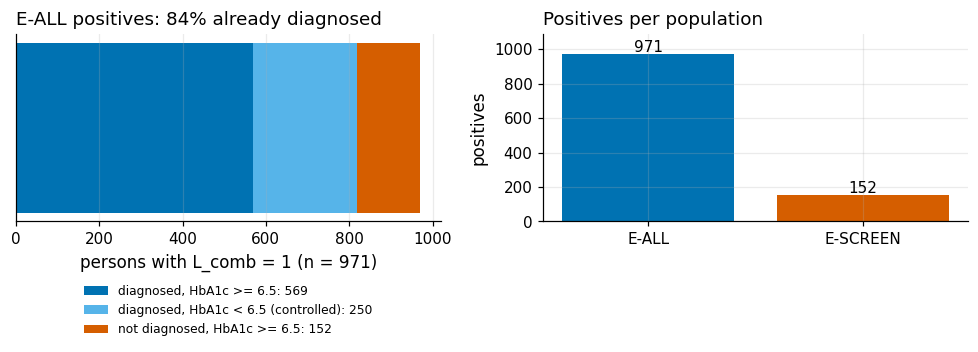

saved figures/S1_label_composition.png


In [57]:
plots.set_style()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), gridspec_kw={"width_ratios": [1, 1]})
ok = C.OKABE_ITO
# Panel 1: who the 971 positives are
ax = axes[0]
parts = [("diagnosed, HbA1c >= 6.5", strata["D_uncontrolled"], ok["blue"]),
         ("diagnosed, HbA1c < 6.5 (controlled)", strata["D_controlled"], ok["sky"]),
         ("not diagnosed, HbA1c >= 6.5", strata["Undiagnosed"], ok["vermillion"])]
left = 0
for lab, v, col in parts:
    ax.barh(0, v, left=left, color=col, label=f"{lab}: {v}")
    left += v
ax.set_yticks([]); ax.set_xlabel(f"persons with L_comb = 1 (n = {n_comb})")
ax.set_title(f"E-ALL positives: {share_known:.0%} already diagnosed", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), fontsize=8)
# Panel 2: E-SCREEN
ax = axes[1]
ax.bar(["E-ALL", "E-SCREEN"], [n_comb, n_escr_pos], color=[ok["blue"], ok["vermillion"]])
for i, v in enumerate([n_comb, n_escr_pos]):
    ax.text(i, v + 15, str(v), ha="center")
ax.set_ylabel("positives"); ax.set_ylim(0, n_comb * 1.12); ax.set_title("Positives per population", loc="left")
fig.tight_layout()
f_comp = plots.savefig(fig, "S1_label_composition",
                       caption=f"Composition of the {n_comb} L_comb positives. {n_self} ({share_known:.1%}) already reported a diagnosis; "
                               f"only {n_escr_pos} are undiagnosed with HbA1c >= 6.5 and form the E-SCREEN positive class.")
plt.show(); print("saved", f_comp)

**So what.** Of the 971 positives, 819 (84.3 %) had already reported a diagnosis; only 152 are undiagnosed. E-ALL therefore rewards recognising known patients, while E-SCREEN (152 positives against 4,759 negatives) is the population in which a screening aid has something to find. Weighting matters for prevalence: 16.9 % unweighted against 14.0 % with the examination-blood weights, mainly because older adults are over-represented in the sample. The gap between model performance on E-ALL and on E-SCREEN is reported as a finding in its own right, not as noise. With only 152 positives, many E-SCREEN contrasts will be *inconclusive*; that is stated in advance.

## 1.5 Research questions and hypotheses

**Why.** Four questions organise the whole project, and each hypothesis has a metric, a direction, a magnitude, a smallest effect of interest (SESOI), a falsifier and an honest record of whether the data had been seen. The hypotheses are read from `governance/hypotheses.md`, which Stage S6 locks with a SHA-256 before any ablation is run.

| RQ | Question |
|---|---|
| RQ1 | **Labels as measurement.** What do self-report and HbA1c each measure, and who is missed by each? |
| RQ2 | **Rules and preparation.** How much do the availability rule (leakage) and systematic preparation change performance and stability, on E-ALL and on E-SCREEN? |
| RQ3 | **3 × 3 label matrix.** How does the training label change who is detected? |
| RQ4 | **Measurement bias.** Does BMI under-detect diabetes in Asian adults, and does waist-to-height ratio repair it? |

In [58]:
hyp = md_table(HYP_MD, "Hypothesis table")
display(hyp[["hyp_id", "rq_or_block", "statement", "prior_exposure"]])

ALLOWED_EXPOSURE = {"analysis_seen", "descriptive_seen", "none"}
FIELDS = ["metric", "direction", "magnitude", "sesoi", "falsifier", "prior_exposure", "weights"]
assert hyp["hyp_id"].tolist() == ["H1a", "H1b", "H2a", "H2b", "H2c", "H3", "H4a", "H4b"]
assert set(hyp["prior_exposure"]) <= ALLOWED_EXPOSURE
assert (hyp[FIELDS].apply(lambda col: col.str.len() > 0)).all().all(), "every hypothesis needs all fields"
expo = hyp["prior_exposure"].value_counts().reindex(sorted(ALLOWED_EXPOSURE)).fillna(0).astype(int)
display(expo.rename("hypotheses").to_frame())
rq_map = hyp.assign(rq=hyp["rq_or_block"].str.extract(r"(RQ\d)")[0]).groupby("rq")["hyp_id"].apply(list)
display(rq_map.rename("hypotheses").to_frame())

,hyp_id,rq_or_block,statement,prior_exposure
0,H1a,RQ1 (S5),"Among adults with HbA1c of 6.5 or more, the share not yet diagnosed (DIQ010 ...",analysis_seen
1,H1b,RQ1 (S4),The crude insured-minus-uninsured gap in diabetes prevalence shrinks after a...,analysis_seen
2,H2a,RQ2 / B1 (S7),A model that breaks the availability rule (M0) beats the same model with the...,analysis_seen
3,H2b,RQ2 / M1 vs S (S7),Systematic preparation (S) is equivalent to the availability-screened minima...,none
4,H2c,RQ2 / E-ALL vs E-SCREEN (S7),(i) T1 discriminates better on E-ALL than on E-SCREEN; (ii) removing the car...,none
5,H3,RQ3 (S8),In the 3 x 3 label matrix the training label determines who is missed: self-...,none
6,H4a,RQ4 (S5),"Among adults with diabetes, the share with BMI below 25 is much higher in As...",analysis_seen
7,H4b,"RQ4 (S5, S8)",Replacing waist circumference by waist-to-height ratio improves single-featu...,descriptive_seen


,hypotheses
prior_exposure,
analysis_seen,4
descriptive_seen,1
none,3


,hypotheses
rq,
RQ1,"[H1a, H1b]"
RQ2,"[H2a, H2b, H2c]"
RQ3,[H3]
RQ4,"[H4a, H4b]"


**So what.** Eight hypotheses cover the four questions (H1a, H1b → RQ1; H2a–H2c → RQ2; H3 → RQ3; H4a, H4b → RQ4) and every one carries all seven fields. Honesty about exposure matters more than the label: four hypotheses are `analysis_seen` (the pattern was observed in the earlier profiling), one is `descriptive_seen`, and only the three experimental ones (H2b, H2c, H3) are genuine pre-registrations. Stages S3–S5 are described as confirmation of observed patterns, never as pre-registered tests.

## 1.6 ADA-lite baseline

**Why.** A published risk score is the natural yardstick for a simple model, but this cycle lacks two of the seven items of Bang et al. 2009 (family history of diabetes, gestational diabetes). Calling the result "the ADA score" would overstate it. The baseline is therefore **ADA-lite, a reduced version missing 2 items**, compared on E-SCREEN only, because Bang's outcome is undiagnosed diabetes. The absence of the two items is checked in the CDC codebooks, not assumed.

In [59]:
ada = md_table(SCOPE_MD, "ADA-lite baseline")
display(ada)
n_avail = int((ada["Status"] == "available").sum())
n_miss = int(ada["Status"].str.contains("missing").sum())
print(f"ADA-lite items available: {n_avail} of {len(ada)}; missing: {n_miss}")
assert (n_avail, n_miss) == (5, 2)


def codebook_text(stem):
    t = (C.CODEBOOK_DIR / f"{stem}.htm").read_text(encoding="utf-8", errors="ignore")
    return re.sub(r"\s+", " ", re.sub(r"<[^>]+>", " ", t)).lower()


evidence = []
for stem in ["MCQ_L", "DIQ_L"]:
    t = codebook_text(stem)
    for term in ["family history", "blood relative", "gestational"]:
        evidence.append({"codebook": stem, "search term": term, "hits": t.count(term)})
    # 'during pregnancy' occurs in the wording of DIQ010 ("Other than during pregnancy ...") and is not a gestational-diabetes item
    evidence.append({"codebook": stem, "search term": "during pregnancy", "hits": t.count("during pregnancy")})
ev = pd.DataFrame(evidence)
display(ev)
ctx = [codebook_text("DIQ_L")[max(0, m.start() - 60): m.end() + 80] for m in re.finditer("during pregnancy", codebook_text("DIQ_L"))]
print("context of 'during pregnancy' in DIQ_L:", ctx[:2])
assert ev.query("`search term` in ['family history','blood relative','gestational']")["hits"].sum() == 0

,Item (Bang 2009),NHANES 2021-23,Status
0,Age,RIDAGEYR,available
1,Sex,RIAGENDR,available
2,History of hypertension,BPQ020,available
3,Body mass index,BMXBMI (measured),available
4,Physical activity,PAQ recreational items converted to minutes per week; >= 150 minutes counts ...,available
5,Family history of diabetes,none in MCQ_L or DIQ_L,**missing**
6,Gestational diabetes,none in the 2021-23 files,**missing**


ADA-lite items available: 5 of 7; missing: 2


,codebook,search term,hits
0,MCQ_L,family history,0
1,MCQ_L,blood relative,0
2,MCQ_L,gestational,0
3,MCQ_L,during pregnancy,0
4,DIQ_L,family history,0
5,DIQ_L,blood relative,0
6,DIQ_L,gestational,0
7,DIQ_L,during pregnancy,2


context of 'during pregnancy' in DIQ_L: ['uestions are about specific medical conditions. {other than during pregnancy, {have you/has sp}/{have you/has sp}} ever been told by a doctor or health prof', 'play. if sp is female and age &gt;= 20, display "other than during pregnancy, {have you/has sp}". target: both males and females 1 years - 150 years code or']


**So what.** Five of the seven items exist (age, sex, hypertension history, measured BMI, recreational physical activity); family history and gestational diabetes do not occur in the MCQ_L or DIQ_L codebooks (zero hits for each search term). The only mention of pregnancy in DIQ_L is the exclusion wording of the diagnosis question itself. The baseline is reported under the name ADA-lite, and the open point that the published AUC of Bang 2009 is quoted as 0.79 or 0.83 in different sources is flagged for verification against the original paper.

## 1.7 Novelty statement

**Why.** A contribution should be stated at the strength the evidence supports. The statement below says what is *combined*, not what is "first". It is read from `governance/S1_scope.md`, and the cell asserts that it contains no priority or superlative words.

In [60]:
novelty = md_section(SCOPE_MD, "Novelty statement")
display(Markdown("> " + novelty))
FORBIDDEN = ["first", "novel", "best", "optimal", "state-of-the-art", "unprecedented", "never before", "pioneer"]
hits = [w for w in FORBIDDEN if re.search(rf"\b{re.escape(w)}\b", novelty, flags=re.I)]
assert not hits, hits
print("novelty statement: no priority or superlative words;", len(novelty.split()), "words")

> This project does not claim to discover that Asian adults develop diabetes at lower BMI, or that undiagnosed diabetes is linked to limited contact with health care; both are established. Its contribution is a combination applied to the 2021-2023 NHANES cycle with fixed basic models: an audit of the label as a measurement, a feature-availability rule that defines leakage, the quantified cost of blanket data cleaning, design-aware evaluation, and pre-registered paired ablations, triangulated against the published NCHS Data Brief 516 and a reduced ADA risk baseline. We have not found this integration in the literature we consulted **[to verify]**.

novelty statement: no priority or superlative words; 99 words


## 1.8 Data user agreement and disclosure controls

**Why.** NHANES public-use files are released under the NCHS Data User Agreement. Compliance is part of the method: it forbids some analyses (linkage with other individual-level data) and shapes others (how small groups are reported). Each obligation is mapped to what the project does.

In [61]:
dua = md_table(SCOPE_MD, "Data user agreement obligations")
display(dua)
assert len(dua) == 5

,Obligation (NCHS DUA),How the project complies
0,Use for statistical reporting and analysis only,Only population-level estimation and model evaluation; no individual-level d...
1,No attempt to identify any person or establishment,No identifying fields are used; no external lookup
2,No linkage with other data sets that could identify individuals,"External validation is against published aggregates only (DB516, Bang 2009)"
3,No study of disclosure-control methods,"Top-coding is taken as given and documented, never probed"
4,Presentation standards for survey estimates,"Flag n < 30, effective n < 30, 95 % CI width >= 0.30, domain df < 8 as explo..."


NCHS already applies disclosure controls to the public files. The project does not probe them; it makes their footprint visible so that a top-coded value is never mistaken for a measurement. The counts are computed on the cohort.

In [62]:
age_top = int((c["RIDAGEYR"] == 80).sum())
pir_top = int((c["INDFMPIR"] >= 5 - 1e-9).sum())
pir_na = int(c["INDFMPIR"].isna().sum())
# household size and pregnancy status are minimised away from the cohort; their disclosure footprint is read from the public DEMO_L file
demo_raw = pd.read_sas(C.RAW_DIR / "DEMO_L.xpt", format="xport")
hh_max = float(demo_raw["DMDHHSIZ"].max())
preg_known = demo_raw[demo_raw["RIDEXPRG"].notna()]
strata_n = int(c[C.STRATA].nunique())
psu_n = int(c.groupby(C.STRATA)[C.PSU].nunique().sum())

dc = pd.DataFrame([
    ["Age top-coded at 80 (RIDAGEYR == 80)", age_top, f"{age_top / n:.1%} of cohort", "indicator age_top"],
    ["Income-to-poverty ratio top-coded at 5 (INDFMPIR)", pir_top, f"{pir_top / n:.1%} of cohort", "indicator pir_top"],
    ["Income-to-poverty ratio missing", pir_na, f"{pir_na / n:.1%} of cohort", "indicator pir_miss"],
    ["Household size, maximum value in DEMO_L (top-coded at 7)", hh_max, "dropped by minimisation", "documented in spec note"],
    ["Pregnancy status recorded only for women aged 20-44", f"{preg_known['RIDAGEYR'].min():.0f}-{preg_known['RIDAGEYR'].max():.0f}", f"{len(preg_known)} women in DEMO_L", "pregnant women excluded by the cohort rule"],
    ["Masked variance strata / PSUs", f"{strata_n} / {psu_n}", f"design df = {psu_n - strata_n}", "delete-one-PSU jackknife"],
], columns=["control", "value", "context", "handling"])
display(dc)
assert (age_top, pir_top, pir_na) == (321, 1282, 734)
assert (strata_n, psu_n) == (15, 30) and hh_max == 7
assert preg_known["RIDAGEYR"].between(20, 44).all()

,control,value,context,handling
0,Age top-coded at 80 (RIDAGEYR == 80),321,5.6% of cohort,indicator age_top
1,Income-to-poverty ratio top-coded at 5 (INDFMPIR),1282,22.4% of cohort,indicator pir_top
2,Income-to-poverty ratio missing,734,12.8% of cohort,indicator pir_miss
3,"Household size, maximum value in DEMO_L (top-coded at 7)",7.0,dropped by minimisation,documented in spec note
4,Pregnancy status recorded only for women aged 20-44,20-44,1503 women in DEMO_L,pregnant women excluded by the cohort rule
5,Masked variance strata / PSUs,15 / 30,design df = 15,delete-one-PSU jackknife


**So what.** 321 adults (5.6 %) are top-coded at age 80 and 1,282 (22.4 %) at an income ratio of 5, with another 734 (12.8 %) missing, so the income variable is both capped and incomplete; the corresponding indicators are kept next to the values. The variance units are masked (15 strata, 30 PSUs, df = 15), which is why every design-based interval in this project uses the jackknife with these 15 degrees of freedom and why small domains are flagged. No part of the analysis tries to undo these controls or to link records to anything else; external checks use published aggregates only.

## 1.9 Data minimisation

**Why.** Collecting or keeping more than the purpose needs is a governance risk even with public data (purpose limitation and data minimisation, e.g. GDPR Art. 5(1)(b)–(c); the Singapore PDPA has a purpose-limitation obligation). The loader keeps only columns that the variable specification keeps (`use_tier` other than `excluded`); `nhanes_io.minimisation_report` lists what was kept and dropped per file and per column.

In [63]:
mrep, mcols = nhanes_io.minimisation_report(spec)
display(mrep[["file", "use_tier", "cols_raw", "cols_kept", "cols_dropped"]])
tot_raw, tot_kept, tot_drop = (int(mrep[k].sum()) for k in ["cols_raw", "cols_kept", "cols_dropped"])
assert tot_raw == tot_kept + tot_drop
assert (tot_raw, tot_kept, tot_drop) == (175, 78, 97), "text of the so-what cell must be updated"
print(f"{tot_raw} raw columns in 16 files: {tot_kept} kept ({tot_kept / tot_raw:.0%}), {tot_drop} dropped ({tot_drop / tot_raw:.0%})")
examples = ["DMDBORN4", "DMDYRUSR", "DMQMILIZ", "DMDHHSIZ", "MCQ010"]
display(mcols[mcols["var"].isin(examples)][["file", "var", "decision", "reason"]])
assert (mcols["decision"] == "drop").sum() == tot_drop
MIN_STATUS = {"raw_columns": tot_raw, "kept": tot_kept, "dropped": tot_drop}

,file,use_tier,cols_raw,cols_kept,cols_dropped
0,DEMO_L,core,27,13,14
1,GHB_L,core,3,3,0
2,GLU_L,side_analysis,4,3,1
3,BMX_L,core,22,7,15
4,BPXO_L,core,12,10,2
5,TCHOL_L,core,4,2,2
6,HDL_L,core,4,2,2
7,TRIGLY_L,side_analysis,10,3,7
8,DIQ_L,core,9,9,0
9,BPQ_L,recommended,6,3,3


175 raw columns in 16 files: 78 kept (45%), 97 dropped (55%)


,file,var,decision,reason
10,DEMO_L,DMQMILIZ,drop,military service: not needed (minimisation)
11,DEMO_L,DMDBORN4,drop,country of birth: not needed; quasi-identifier (minimisation)
12,DEMO_L,DMDYRUSR,drop,years in the US: not needed; quasi-identifier (minimisation)
16,DEMO_L,DMDHHSIZ,drop,"household size (top-coded 7): not needed, PIR already accounts for household..."
102,MCQ_L,MCQ010,drop,unrelated MCQ item (minimisation)


**So what.** Of 175 raw columns in the 16 files, 78 are kept and 97 are dropped (55 %) because the specification gives them no analytic role: quasi-identifiers such as country of birth and years of residence, military service, household-size details, measurement-comment codes and unrelated MCQ items. Every dropped column has a stated reason in `minimisation_columns.csv`, and the loader discards them immediately after reading, so downstream code cannot use them by accident.

## 1.10 Response rates and representativeness

**Why.** Survey weights make the sample resemble the US civilian non-institutionalised population *as far as known covariates allow*. They cannot repair non-response that depends on health. The 2021–2023 cycle has a low response and no oversampling of specific groups, which limits both generalisation and subgroup analysis.

,item,value,source
0,Interview response rate,34.6 %,NCHS cycle overview (not computable from the files)
1,Examination (MEC) response rate,25.7 %,NCHS cycle overview (not computable from the files)
2,Oversampling by race/ethnicity or income,none in this cycle,NCHS cycle overview; earlier cycles oversampled


,unweighted,WTPH2YR-weighted
20-39,24.7,34.8
40-59,29.2,33.8
60+,46.2,31.4


Kish design effect of the weights: 1.55; effective sample size 3707 of 5730
Asian adults in cohort: 315, of whom 50 with L_comb


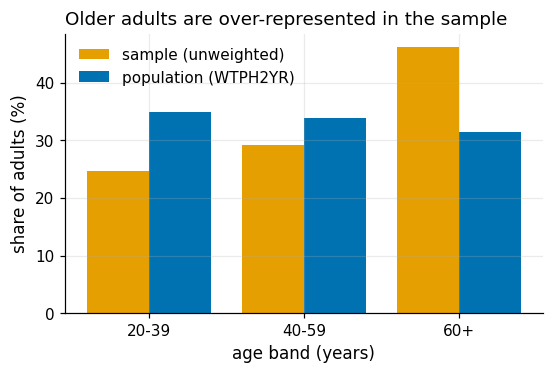

saved figures/S1_sample_vs_weighted_age.png


In [64]:
RESP = pd.DataFrame([
    ["Interview response rate", "34.6 %", "NCHS cycle overview (not computable from the files)"],
    ["Examination (MEC) response rate", "25.7 %", "NCHS cycle overview (not computable from the files)"],
    ["Oversampling by race/ethnicity or income", "none in this cycle", "NCHS cycle overview; earlier cycles oversampled"],
], columns=["item", "value", "source"])
display(RESP)

w = c[C.WEIGHT_PHLEB]
bands = S.age_band(c["RIDAGEYR"]).values
tab = pd.DataFrame({"unweighted": pd.Series(bands).value_counts(normalize=True),
                    "WTPH2YR-weighted": pd.Series(w.values).groupby(bands).sum() / w.sum()}).loc[["20-39", "40-59", "60+"]]
display((tab * 100).round(1))
deff = S.kish_deff(w)
print(f"Kish design effect of the weights: {deff:.2f}; effective sample size {S.kish_neff(w):.0f} of {n}")
n_asian = int((c['RIDRETH3'] == 6).sum())
n_asian_pos = int(((c['RIDRETH3'] == 6) & (c['L_comb'] == 1)).sum())
print(f"Asian adults in cohort: {n_asian}, of whom {n_asian_pos} with L_comb")
assert (n_asian, n_asian_pos) == (315, 50)
assert abs(tab.loc["60+", "unweighted"] - 0.462) < 0.001 and abs(tab.loc["60+", "WTPH2YR-weighted"] - 0.314) < 0.001
assert abs(deff - 1.55) < 0.01

fig, ax = plt.subplots(figsize=(5.6, 3.3))
x = np.arange(3)
ax.bar(x - 0.2, tab["unweighted"] * 100, 0.4, color=C.OKABE_ITO["orange"], label="sample (unweighted)")
ax.bar(x + 0.2, tab["WTPH2YR-weighted"] * 100, 0.4, color=C.OKABE_ITO["blue"], label="population (WTPH2YR)")
ax.set_xticks(x, tab.index); ax.set_xlabel("age band (years)"); ax.set_ylabel("share of adults (%)")
ax.set_title("Older adults are over-represented in the sample", loc="left"); ax.legend()
f_age = plots.savefig(fig, "S1_sample_vs_weighted_age",
                      caption=f"Age structure of the {n} cohort adults, unweighted versus WTPH2YR-weighted. 60+ is {tab.loc['60+','unweighted']:.1%} of the sample "
                              f"but {tab.loc['60+','WTPH2YR-weighted']:.1%} of the weighted population; Kish design effect {deff:.2f}.")
plt.show(); print("saved", f_age)

**So what.** Adults aged 60 and over are 46.2 % of the sample but 31.4 % of the weighted population, so unweighted figures overstate prevalence (16.9 % against 14.0 %); the Kish design effect of 1.55 means the 5,730 adults carry roughly the information of 3,700 simple-random-sample adults before clustering is considered. Interview (34.6 %) and examination (25.7 %) response rates are low, and the cycle has no oversampling, so subgroups such as Asian adults (315 in the cohort, 50 with `L_comb`) are thin: their results are reported with intervals and labelled exploratory. The weights adjust for known covariates only; if participation depends on health, as the interview-versus-examination comparison in Stage S5 suggests, some bias remains and is acknowledged as a limitation rather than corrected.

## 1.11 Scope decisions

The decisions of this section are recorded in `governance/register/S1.csv`; the table lists them with the self-check verdict (a re-computation of the key counts above).

In [65]:
reg_path = GOV / "register" / "S1.csv"
reg = pd.read_csv(reg_path)
display(reg[["dr_id", "type", "decision", "hyp_id", "check_verdict"]])
assert reg["check_verdict"].isin(["PASS", "PASS-FIX"]).all()

payload = {
    "n_cohort": n,
    "funnel": dict(zip(funnel["step"], funnel["n"])),
    "labels": {"L_self": n_self, "L_A1c": n_a1c, "L_comb": n_comb, "known_share_of_comb": share_known},
    "e_all": {"rows": n, "positives": n_comb},
    "e_screen": {"rows": n_escr, "positives": n_escr_pos, "negatives": n_escr_neg},
    "strata_3x3": strata.to_dict(),
    "prevalence_comb": {"unweighted": prev_u, "weighted": prev_w["est"],
                        "ci_low": prev_w["ci_low"], "ci_high": prev_w["ci_high"], "df": prev_w["df"]},
    "kish_deff": deff,
    "age60_share": {"sample": float(tab.loc["60+", "unweighted"]), "weighted": float(tab.loc["60+", "WTPH2YR-weighted"])},
    "disclosure": {"age_top": age_top, "pir_top": pir_top, "pir_missing": pir_na, "strata": strata_n, "psu": psu_n},
    "availability_rule": {"n_rule_rows": len(rule), "by_tier": counts.to_dict(), "spec": SPEC_STATUS},
    "ada_lite": {"items": len(ada), "available": n_avail, "missing": n_miss},
    "hypotheses": {"n": len(hyp), "prior_exposure": expo.to_dict()},
    "minimisation": MIN_STATUS,
    "response_rates": {"interview": 0.346, "mec": 0.257, "source": "NCHS cycle overview"},
}
R.save_section("S1", payload)
(C.RESULTS_DIR / "S1").mkdir(exist_ok=True)
rule.drop(columns="tier").to_csv(C.RESULTS_DIR / "S1" / "availability_rule.csv", index=False)
pop.to_csv(C.RESULTS_DIR / "S1" / "evaluation_populations.csv", index=False)
print("saved results/metrics_S1.json; S1 OK")

,dr_id,type,decision,hyp_id,check_verdict
0,DR-S1-01,scope,Frame the question as non-glycaemic identification of adult diabetes (diagno...,RQ1-RQ4,PASS
1,DR-S1-02,target,"Freeze L_comb = DIQ010==1 or LBXGH>=6.5 on adults >=20, examined, non-pregna...",H2a,PASS
2,DR-S1-03,scope,Report E-ALL and E-SCREEN as co-primary populations; the gap between them is...,H2c,PASS
3,DR-S1-04,rule,"Admit a feature only if available at the screening moment, not a diagnostic ...",H2a,PASS
4,DR-S1-05,rule,Keep them admissible and add a T1-minus-care ablation arm reported on E-ALL ...,H2c,PASS
5,DR-S1-06,rule,Exclude from models by default; use as audit and stratification variables,H1a,PASS
6,DR-S1-07,baseline,"Use ADA-lite (reduced version, missing 2 items), compared on E-SCREEN only; ...",H2c,PASS
7,DR-S1-08,hypotheses,"Define H1a-H4b with prior_exposure markers; only H2b, H2c and H3 claim true ...",H1a-H4b,PASS
8,DR-S1-09,claims,State the contribution as a combination applied to one cycle with fixed basi...,NaN,PASS
9,DR-S1-10,governance,"Validate externally only against published aggregates (DB516, Bang 2009); ta...",NaN,PASS


saved results/metrics_S1.json; S1 OK


# §2 Data provenance, specification and minimisation (Stage S2)

This section works out where the data can be trusted and where they cannot, and turns each finding into a recorded decision. It starts by re-checking the provenance and specification work of Stage S2 (hashes, codebook-derived specification, minimisation). The Stage S3 audit follows in nine numbered items:

1. XPT read artefact and zero-weight semantics
2. Completeness, uniqueness and the sample funnel
3. Per-variable sentinel map
4. Cost of a blanket recode
5. Consistency checks
6. Top-coding
7. Missing-data mechanism for HbA1c
8. Outliers: a three-layer rule
9. Data-quality dimension matrix

Each item follows the same pattern: *why* the check is needed, the code that computes it, and *so what*, giving the computed numbers and the decision they support. Key numbers are asserted against reference values from an independent earlier computation, with a tolerance, so any drift fails loudly. Every number is stored in `results/metrics_S2.json` / `results/metrics_S3.json`, tables in `results/S3/`, and the decisions in `governance/register/S2.csv` and `S3.csv`.

In [66]:
new_section()

In [67]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score
from IPython.display import display

from src import nhanes_io as io

pd.set_option("display.width", 160, "display.max_colwidth", 70, "display.max_rows", 80)
OI = C.OKABE_ITO
OUT = C.RESULTS_DIR / "S3"
OUT.mkdir(parents=True, exist_ok=True)
(C.RESULTS_DIR / "S2").mkdir(parents=True, exist_ok=True)
TODAY = "2026-10-11"
REGISTER_COLS = ["dr_id", "stage", "date", "type", "finding", "evidence_ref", "evidence_value", "decision",
                 "alternatives_rejected", "hyp_id", "status", "check_verdict", "check_note", "loop_ref",
                 "change_request", "commit"]
M2, M3 = {}, {}   # metrics stored for S2 and S3


def close(a, b, tol=0.0):
    """Assert helper: |a - b| <= tol."""
    return abs(float(a) - float(b)) <= tol


def write_register(stage, rows):
    reg = pd.DataFrame(rows)
    for c in REGISTER_COLS:
        if c not in reg:
            reg[c] = ""
    reg = reg[REGISTER_COLS]
    reg.to_csv(C.GOVERNANCE_DIR / "register" / f"{stage}.csv", index=False, lineterminator="\n")
    return reg

## 2.1 Provenance, specification and minimisation

**Why.** An audit is only as good as its inputs. Three things are checked before any profiling:

- the raw files are the unmodified CDC files (SHA-256 against `MANIFEST.sha256`);
- the variable specification `config/variable_spec.csv` agrees with the CDC codebooks and with the columns actually present in the XPT files, because every sentinel code must have a traceable source;
- the loader keeps only what the purpose needs (data minimisation, GDPR Art. 5(1)(c)).

In [68]:
integrity = io.ensure_raw_data(download=False)
print(f"raw files verified against MANIFEST.sha256: {len(integrity['verified'])}/{integrity['n_files']}; mismatched: {integrity['mismatched']}")
assert integrity["mismatched"] == [] and len(integrity["verified"]) == 16

spec = io.load_spec()
problems = io.verify_spec(spec)
print("verify_spec problems:", problems or "none")
assert problems == []

inc = io.included(spec)
role_tab = (inc[inc["var"] != "SEQN"].groupby(["role", "admissible"]).size().unstack(fill_value=0))
display(role_tab)
tier_tab = spec[spec["var"] != "SEQN"].groupby("use_tier").size().rename("variables").to_frame()
display(tier_tab)

min_files, min_cols = io.minimisation_report(spec)
min_files.to_csv(C.RESULTS_DIR / "S2" / "minimisation_report.csv", index=False, lineterminator="\n")
min_cols.to_csv(C.RESULTS_DIR / "S2" / "minimisation_columns.csv", index=False, lineterminator="\n")
display(min_files[["file", "use_tier", "rows", "cols_raw", "cols_kept", "cols_dropped"]])
n_raw, n_kept, n_drop = (int(min_files[c].sum()) for c in ("cols_raw", "cols_kept", "cols_dropped"))
print(f"columns: raw {n_raw}, kept {n_kept}, dropped {n_drop}; every dropped column has a reason:",
      bool(min_cols.loc[min_cols["decision"] == "drop", "reason"].str.len().gt(0).all()))
assert n_raw == len(spec) == 175 and n_kept + n_drop == n_raw
assert min_cols.loc[min_cols["decision"] == "drop", "reason"].str.len().gt(0).all()

n_sentinel_vars = len(io.sentinel_map(spec))
cont_inc = inc[(inc["dtype"] == "continuous") & inc["file"].isin(["BMX_L", "BPXO_L", "GHB_L", "TCHOL_L", "HDL_L", "GLU_L", "TRIGLY_L"])]
print(f"included variables with codebook refusal/don't-know codes: {n_sentinel_vars}; "
      f"continuous lab/exam measures with such codes: {int((cont_inc['sentinel_codes'] != '').sum())} of {len(cont_inc)}")
assert (cont_inc["sentinel_codes"] == "").all() and len(cont_inc) == 21 and n_sentinel_vars == 25

raw files verified against MANIFEST.sha256: 16/16; mismatched: []


verify_spec problems: none


admissible,N,T1,T2
role,,,
audit,3,0,0
cohort_filter,2,0,0
design,2,0,0
feature,0,30,2
label,2,0,0
leak,8,0,0
optional,5,0,0
redundancy,2,0,0
side,2,0,0


,variables
use_tier,
core,41
excluded,97
optional,5
recommended,10
redundancy_demo,2
side_analysis,4


,file,use_tier,rows,cols_raw,cols_kept,cols_dropped
0,DEMO_L,core,11933,27,13,14
1,GHB_L,core,7199,3,3,0
2,GLU_L,side_analysis,3996,4,3,1
3,BMX_L,core,8860,22,7,15
4,BPXO_L,core,7801,12,10,2
5,TCHOL_L,core,8068,4,2,2
6,HDL_L,core,8068,4,2,2
7,TRIGLY_L,side_analysis,3996,10,3,7
8,DIQ_L,core,11744,9,9,0
9,BPQ_L,recommended,8501,6,3,3


columns: raw 175, kept 78, dropped 97; every dropped column has a reason: True
included variables with codebook refusal/don't-know codes: 25; continuous lab/exam measures with such codes: 0 of 21


**So what.** All 16 raw files match their recorded hashes, so every number below comes from the CDC release dated 2026-10-10. The specification has one row for each of the 175 raw columns, and `verify_spec` finds no disagreement with the codebooks or the XPT headers. The loader keeps 78 columns and drops 97. Each dropped column has a stated reason: child-only items, country of birth and years in the US (quasi-identifiers), military service, household reference-person fields, SI-unit duplicates, unrelated MCQ items and duplicate weight columns.

25 included variables carry codebook refusal or don't-know codes, and all of them are questionnaire items. None of the 21 continuous laboratory and examination measures has such a code. The per-variable sentinel map therefore leaves every measurement untouched; item 4 shows why this matters.

In [69]:
M2.update({
    "raw_files_verified": len(integrity["verified"]), "hash_mismatches": len(integrity["mismatched"]),
    "spec_rows": len(spec), "spec_problems": len(problems),
    "minimisation": {"cols_raw": n_raw, "cols_kept": n_kept, "cols_dropped": n_drop,
                     "per_file": min_files.set_index("file")[["cols_raw", "cols_kept", "cols_dropped"]].to_dict("index")},
    "use_tier_counts": tier_tab["variables"].to_dict(),
    "role_admissible": {f"{r}|{a}": int(v) for (r, a), v in role_tab.stack().items() if v},
    "n_sentinel_variables": n_sentinel_vars,
})

# §3 Data profiling and quality audit (Stage S3)

This section continues §2 in the same workspace state (the helper functions and result dictionaries defined there are reused; no `new_section()` in between). It holds the nine audit items listed at the start of §2 (§3.1–§3.9) and the decision register of Stages S2 and S3.

## 3.1 XPT read artefact and zero-weight semantics

**Why.** When pandas reads a SAS transport (XPT) file, a stored zero comes back as 5.397605e-79 (= 16⁻⁶⁵). This is a floating-point artefact of the reader, not a SAS missing-value code. Left in place it creates a spurious minimum and breaks `== 0` tests such as "zero weight" or "no activity". The repair has to keep NaN as NaN. `x.where(|x| >= 1e-10, 0)` is the tempting one-liner, but it also turns every NaN into 0, because NaN fails the comparison.

In [70]:
art = io.xpt_artefact_audit()
art_file = art.groupby("file")["n_artefact"].sum().reindex(C.NHANES_FILES)
art_vars = art[art["n_artefact"] > 0].sort_values(["file", "n_artefact"], ascending=[True, False])
display(art_vars.reset_index(drop=True))
n_art = int(art_file.sum())
files_hit = art_file[art_file > 0].index.tolist()
print(f"artefact cells: {n_art:,} in {len(files_hit)} files {files_hit}; clean files: {art_file[art_file == 0].index.tolist()}")
art.to_csv(OUT / "xpt_artefacts.csv", index=False, lineterminator="\n")

# demonstrate the NaN-preservation requirement on one affected file
paq = io.read_xpt("PAQ_L")
fixed, n_fixed = io.fix_xpt(paq)
num = paq.select_dtypes("number")
wrong = num.where(num.abs() >= C.XPT_ZERO_EPS, 0.0)   # the tempting `where` version: NaN fails the test -> 0
nan_before, nan_after, nan_wrong = int(num.isna().sum().sum()), int(fixed[num.columns].isna().sum().sum()), int(wrong.isna().sum().sum())
residual = int(io._artefact_mask(fixed).to_numpy().sum())
print(f"PAQ_L: fixed {n_fixed:,} cells; NaN before {nan_before:,}, after mask-fix {nan_after:,}, after where-fix {nan_wrong:,}; residual 0<|x|<1e-10: {residual}")
assert nan_after == nan_before and residual == 0 and nan_wrong < nan_before

# whole-project check: all files repaired, NaN count unchanged
tot_fixed = 0
for f in C.NHANES_FILES:
    raw = io.read_xpt(f)
    fx, k = io.fix_xpt(raw)
    tot_fixed += k
    assert io._artefact_mask(fx).to_numpy().sum() == 0
    assert fx.select_dtypes("number").isna().sum().sum() == raw.select_dtypes("number").isna().sum().sum()
assert n_art == tot_fixed == 13676 and len(files_hit) == 9

,file,var,n_artefact
0,DEMO_L,WTMEC2YR,3073
1,DEMO_L,RIDAGEYR,189
2,DEMO_L,INDFMPIR,100
3,DEMO_L,RIDAGEMN,17
4,DEMO_L,RIDEXAGM,4
5,GHB_L,WTPH2YR,449
6,GLU_L,WTSAF2YR,635
7,HDL_L,WTPH2YR,752
8,INQ_L,INDFMMPI,218
9,PAQ_L,PAD810Q,4413


artefact cells: 13,676 in 9 files ['DEMO_L', 'GHB_L', 'GLU_L', 'TCHOL_L', 'HDL_L', 'TRIGLY_L', 'INQ_L', 'SMQ_L', 'PAQ_L']; clean files: ['BMX_L', 'BPXO_L', 'DIQ_L', 'BPQ_L', 'MCQ_L', 'HIQ_L', 'HUQ_L']
PAQ_L: fixed 6,117 cells; NaN before 6,276, after mask-fix 6,276, after where-fix 0; residual 0<|x|<1e-10: 0


Several of the repaired zeros have a meaning defined in the codebook. A zero weight marks a participant outside that weight's sub-sample, so it must become missing before any weighted calculation:

In [71]:
demo = io.load_file("DEMO_L", minimise=False)[0]
ghb = io.load_file("GHB_L", minimise=False)[0]
glu = io.load_file("GLU_L", minimise=False)[0]
zw = pd.DataFrame([
    ["WTMEC2YR = 0", int((demo["WTMEC2YR"] == 0).sum()), "not MEC-examined", int((demo["RIDSTATR"] == 1).sum())],
    ["WTPH2YR = 0 (GHB_L)", int((ghb["WTPH2YR"] == 0).sum()), "no blood sample provided", None],
    ["WTSAF2YR = 0 (GLU_L)", int((glu["WTSAF2YR"] == 0).sum()), "fasting sub-sample non-response", None],
], columns=["condition", "n", "codebook meaning", "cross-check: RIDSTATR = 1 (interview only)"])
display(zw)
coh = io.build_cohort()
zero_in_cohort = int((coh["WTPH2YR"] == 0).sum())
print(f"cohort rows with WTPH2YR = 0: {zero_in_cohort}; WTPH2YR missing: {int(coh['WTPH2YR'].isna().sum())}")
assert zw.loc[0, "n"] == 3073 == zw.loc[0, "cross-check: RIDSTATR = 1 (interview only)"]
assert zw.loc[1, "n"] == 449 and zero_in_cohort == 0

,condition,n,codebook meaning,cross-check: RIDSTATR = 1 (interview only)
0,WTMEC2YR = 0,3073,not MEC-examined,3073.0
1,WTPH2YR = 0 (GHB_L),449,no blood sample provided,NaN
2,WTSAF2YR = 0 (GLU_L),635,fasting sub-sample non-response,NaN


cohort rows with WTPH2YR = 0: 0; WTPH2YR missing: 0


**So what.** The artefact affects 13,676 cells in 9 of the 16 files: DEMO, GHB, GLU, TCHOL, HDL, TRIGLY, INQ, SMQ and PAQ. BMX, BPXO, DIQ, BPQ, MCQ, HIQ and HUQ are clean. Most of the affected cells are weights or frequencies whose true value is 0. Examples are the 3,073 zero exam weights and the 4,413 people with zero vigorous-activity sessions (`PAD810Q`).

On `PAQ_L` the `mask` repair keeps the NaN count unchanged. The `where` version would silently turn the missing cells into zeros, which reads as "no physical activity" for people who never answered. After the repair no value with 0 < |x| < 10⁻¹⁰ remains in any file.

The zero weights carry meaning. The 3,073 rows with `WTMEC2YR = 0` are exactly the 3,073 interview-only participants (`RIDSTATR = 1`), and `WTPH2YR = 0` marks the 449 people without a blood sample. Every cohort member has a positive `WTPH2YR`. **Decision (DR-S3-01):** repair the artefact with `mask` at load time (`nhanes_io.fix_xpt`). Zero weights become NaN before any weighted analysis (`nhanes_io.zero_weights_to_nan`).

In [72]:
M3["xpt_artefact"] = {"cells": n_art, "files": files_hit, "n_files": len(files_hit),
                      "per_file": {k: int(v) for k, v in art_file.items() if v},
                      "paq_nan_before": nan_before, "paq_nan_after_mask": nan_after, "paq_nan_after_where": nan_wrong}
M3["zero_weights"] = {"WTMEC2YR_0": int(zw.loc[0, "n"]), "WTPH2YR_0": int(zw.loc[1, "n"]),
                      "WTSAF2YR_0": int(zw.loc[2, "n"]), "cohort_WTPH2YR_0": zero_in_cohort}

## 3.2 Completeness, uniqueness and the sample funnel

**Why.** A left join on `SEQN` is only safe if `SEQN` is unique in every file and every file's participants are a subset of `DEMO_L`. Otherwise rows are duplicated or silently lost. The cohort definition is the first measurement decision of the project. Its funnel is asserted so that a change in any step fails loudly.

,file,rows,seqn_unique,subset_of_DEMO
0,DEMO_L,11933,True,True
1,GHB_L,7199,True,True
2,GLU_L,3996,True,True
3,BMX_L,8860,True,True
4,BPXO_L,7801,True,True
5,TCHOL_L,8068,True,True
6,HDL_L,8068,True,True
7,TRIGLY_L,3996,True,True
8,DIQ_L,11744,True,True
9,BPQ_L,8501,True,True


,step,n,dropped
0,DEMO_L participants,11933,0
1,Age >= 20,7809,4124
2,Interviewed and MEC-examined (RIDSTATR = 2),6064,1745
3,HbA1c measured (LBXGH present),5767,297
4,Not pregnant (RIDEXPRG != 1),5730,37


cohort N = 5,730; RIDEXPRG = 3 (cannot ascertain) kept and flagged: 21


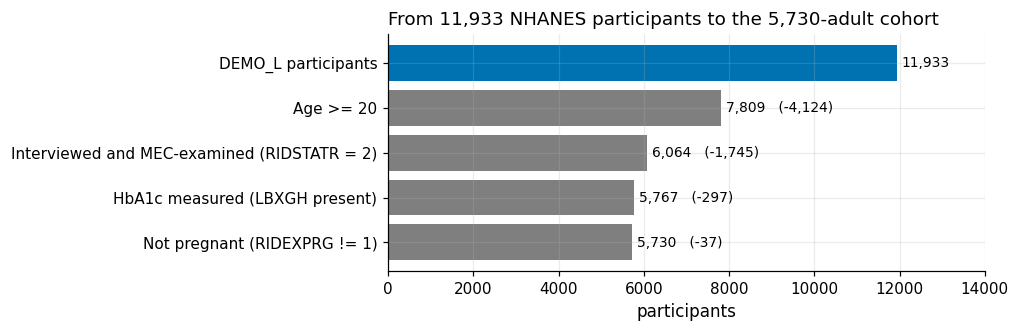

saved figures/S3_funnel.png


In [73]:
uniq = []
demo_ids = set(demo["SEQN"])
for f in C.NHANES_FILES:
    ids = io.read_xpt(f)["SEQN"]
    uniq.append({"file": f, "rows": len(ids), "seqn_unique": ids.is_unique, "subset_of_DEMO": set(ids) <= demo_ids})
uniq = pd.DataFrame(uniq)
display(uniq)
assert uniq["seqn_unique"].all() and uniq["subset_of_DEMO"].all()

fun = io.funnel()
display(fun)
assert tuple(fun["n"]) == io.FUNNEL_EXPECTED
preg3 = int(coh["preg_unknown"].sum())
print(f"cohort N = {len(coh):,}; RIDEXPRG = 3 (cannot ascertain) kept and flagged: {preg3}")
assert preg3 == 21

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(fun["step"][::-1], fun["n"][::-1], color=[OI["grey"]] * 4 + [OI["blue"]])
for y, (n, d) in enumerate(zip(fun["n"][::-1], fun["dropped"][::-1])):
    ax.text(n + 120, y, f"{n:,}" + (f"   (-{d:,})" if d else ""), va="center", fontsize=9)
ax.set_xlabel("participants"); ax.set_xlim(0, 14000)
ax.set_title("From 11,933 NHANES participants to the 5,730-adult cohort", loc="left")
f_funnel = plots.savefig(fig, "S3_funnel", caption="Sample funnel: DEMO_L participants -> age >= 20 -> interviewed and examined -> HbA1c measured -> not pregnant (N = 5,730). Numbers in brackets are the rows removed at each step.")
plt.show(); print("saved", f_funnel)

**So what.** `SEQN` is unique in all 16 files, and each file is a subset of `DEMO_L`, so the left join neither duplicates nor drops anyone. The funnel matches the cohort definition step by step: 11,933 → 7,809 (age ≥ 20) → 6,064 (examined) → 5,767 (HbA1c present) → 5,730 (pregnant women removed). The largest selective step is the examination (1,745 adults lost). Together with the 25.7 % examination response rate it limits representativeness, which is why the quality matrix in item 9 rates credibility separately. The 297 examined adults without HbA1c are studied in item 7. The 21 women whose pregnancy status could not be ascertained are kept and flagged (`preg_unknown`), so a sensitivity analysis can drop them.

In [74]:
M3["funnel"] = dict(zip(fun["step"], fun["n"].astype(int)))
M3["uniqueness"] = {"files_seqn_unique": int(uniq["seqn_unique"].sum()), "files_subset_of_demo": int(uniq["subset_of_DEMO"].sum())}
M3["preg_unknown_kept"] = preg3

## 3.3 Per-variable sentinel map

**Why.** NHANES codes "Refused" and "Don't know" differently in each variable: 7/9, 77/99, 777/999 or 7777/9999. Continuous laboratory and examination measures have no such codes at all; their codebook lists only a range of values and "Missing". The sentinel map is therefore taken from each variable's codebook entry, never from a global list. Two kinds of check make it auditable:

- Every recoded code is traceable to the codebook: for each variable, the number of rows recoded in the raw file must equal the frequency the CDC codebook prints for that code.
- Codes that look like sentinels but are real categories are kept. Examples are `DIQ010 = 3` (borderline) and `HUQ030 = 3` (more than one place of care).

In [75]:
cb = io.codebook_table()
rows = []
for f in C.NHANES_FILES:
    part = io.load_file(f, spec=spec)[0]
    _, aud = io.apply_sentinels(part, spec, mode="per_variable")
    for _, a in aud.iterrows():
        codes = io._codes(a["codes"])
        cbv = cb[(cb["file"] == f) & (cb["var"] == a["var"])]
        cb_rows = cbv[cbv["code"].isin([str(c) for c in codes])]
        rows.append({"var": a["var"], "file": f, "codes": a["codes"],
                     "codebook_desc": " / ".join(cb_rows["desc"]),
                     "codebook_count": int(cb_rows["count"].sum()),
                     "recoded_file": int(a["n_recoded"])})
sent = pd.DataFrame(rows)
_, aud_coh = io.apply_sentinels(io.build_cohort(sentinels="none"), spec, mode="per_variable")
sent = sent.merge(aud_coh[["var", "n_recoded"]].rename(columns={"n_recoded": "recoded_cohort"}), on="var", how="left")
sent["traceable"] = sent["codebook_count"] == sent["recoded_file"]
display(sent)
sent.to_csv(OUT / "sentinel_audit.csv", index=False, lineterminator="\n")
assert sent["traceable"].all(), sent[~sent["traceable"]]
assert len(sent) == 25 and int(sent["recoded_file"].sum()) == 1047
assert sent["codebook_desc"].str.split(" / ").map(lambda d: all(x in ("Refused", "Don't know") for x in d)).all()

legit = pd.DataFrame([
    ["DIQ010 = 3", "Borderline", int((coh["DIQ010"] == 3).sum()), int((io.read_xpt("DIQ_L")["DIQ010"] == 3).sum())],
    ["HUQ030 = 3", "There is more than one place", int((coh["HUQ030"] == 3).sum()), int((io.read_xpt("HUQ_L")["HUQ030"] == 3).sum())],
    ["RIDRETH3 = 7", "Other race, including multi-racial", int((coh["RIDRETH3"] == 7).sum()), int((demo["RIDRETH3"] == 7).sum())],
], columns=["code", "meaning", "cohort", "file"])
display(legit)
assert legit.loc[0, "cohort"] == 213 and legit.loc[0, "file"] == 284
n_sent_coh = int(sent["recoded_cohort"].fillna(0).sum())
print(f"variables with codebook sentinels: {len(sent)}; cells recoded in the files: {int(sent['recoded_file'].sum()):,}; in the cohort: {n_sent_coh:,}")

,var,file,codes,codebook_desc,codebook_count,recoded_file,recoded_cohort,traceable
0,DMDEDUC2,DEMO_L,7;9,Refused / Don't know,11,11,2,True
1,DMDMARTZ,DEMO_L,77;99,Refused / Don't know,9,9,4,True
2,DIQ010,DIQ_L,7;9,Refused / Don't know,4,4,0,True
3,DID040,DIQ_L,777;999,Refused / Don't know,24,24,14,True
4,DIQ160,DIQ_L,7;9,Refused / Don't know,15,15,8,True
5,DIQ180,DIQ_L,7;9,Refused / Don't know,267,267,173,True
6,DIQ050,DIQ_L,7;9,Refused / Don't know,0,0,0,True
7,DID060,DIQ_L,777;999,Refused / Don't know,8,8,6,True
8,DIQ070,DIQ_L,7;9,Refused / Don't know,7,7,4,True
9,BPQ020,BPQ_L,7;9,Refused / Don't know,11,11,4,True


,code,meaning,cohort,file
0,DIQ010 = 3,Borderline,213,284
1,HUQ030 = 3,There is more than one place,34,57
2,RIDRETH3 = 7,"Other race, including multi-racial",363,948


variables with codebook sentinels: 25; cells recoded in the files: 1,047; in the cohort: 562


**So what.** For each of the 25 variables with codebook sentinels, the number of recoded rows equals the frequency the codebook prints, so each recode is traceable to its CDC source. The map recodes 1,047 cells across the files and 562 in the cohort. The largest single item is `DIQ180` (prior blood test, 173 "don't know"), a label-audit variable rather than a predictor.

The codes that look like sentinels but are categories stay untouched:

- 213 borderline answers (`DIQ010 = 3`; 284 in the file);
- 34 people with more than one usual place of care (`HUQ030 = 3`);
- the 363 "Other race / multiracial" adults (`RIDRETH3 = 7`).

**Decision (DR-S3-02):** recode refusal and don't-know codes per variable from the codebook (`apply_sentinels(mode="per_variable")`). There is no global list, and continuous measures are never recoded.

In [76]:
M3["sentinel_audit"] = {"n_variables": len(sent), "cells_recoded_files": int(sent["recoded_file"].sum()),
                        "cells_recoded_cohort": n_sent_coh, "all_traceable": bool(sent["traceable"].all()),
                        "legit_codes_cohort": dict(zip(legit["code"], legit["cohort"].astype(int)))}

## 3.4 Cost of a blanket recode

**Why.** A common shortcut is `df.replace([7, 9, 77, 99, 777, 999, 7777, 9999], np.nan)` across the whole table. It is also the "minimal" arm M0 of the experiments in Stage S6. The cost has to be measured rather than assumed. Every value the shortcut removes from a continuous measure is a valid measurement, because those variables have no refusal codes. Examples are a diastolic pressure of 77 mmHg, a weight of 99 kg and an HbA1c of 7.0 %. The damage is counted on the fixed cohort of 5,730 adults in three arms:

- **per-variable**: codebook codes only;
- **blanket**: the shortcut;
- **questionnaire-only**: the shortcut restricted to the six questionnaire items where it is harmless.

The effect on the labels is counted as well.

In [77]:
coh_none = io.build_cohort(sentinels="none")
DERIVED = ["bp_sys_mean", "bp_dia_mean", "whtr", "age_top", "pir_top", "pir_miss", "preg_unknown", "race", "sex"]
coh_blank = io.build_cohort(sentinels="blanket")
codes = list(io.BLANKET_CODES)
dmg = pd.DataFrame({"var": io.CONTINUOUS_CANDIDATES})
dmg["valid_cells_destroyed"] = [int(coh_none[v].isin(codes).sum()) for v in dmg["var"]]
dmg["lost_in_blanket_cohort"] = [int(coh_none[v].notna().sum() - coh_blank[v].notna().sum()) for v in dmg["var"]]
dmg["values_hit"] = [", ".join(f"{io._num(k)}:{n}" for k, n in coh_none.loc[coh_none[v].isin(codes), v].value_counts().sort_index().items()) for v in dmg["var"]]
assert (dmg["valid_cells_destroyed"] == dmg["lost_in_blanket_cohort"]).all()
assert (spec.set_index("var").loc[list(io.CONTINUOUS_CANDIDATES), "sentinel_codes"].groupby(level=0).first() == "").all()
dmg = dmg.sort_values("valid_cells_destroyed", ascending=False).reset_index(drop=True)
display(dmg)
dmg.to_csv(OUT / "blanket_damage.csv", index=False, lineterminator="\n")
n_destroyed = int(dmg["valid_cells_destroyed"].sum())

# same 20 variables in the full merged file (secondary scope)
full_none = io.load_merged(sentinels="none")
n_destroyed_full = int(sum(full_none[v].isin(codes).sum() for v in io.CONTINUOUS_CANDIDATES))

# labels
a1c_pos = coh_none["LBXGH"] >= C.HBA1C_DIABETES
a1c_pos_blank = coh_blank["LBXGH"] >= C.HBA1C_DIABETES
lost_pos = int((a1c_pos & ~a1c_pos_blank).sum())
lost_values = coh_none.loc[a1c_pos & ~a1c_pos_blank, "LBXGH"].value_counts().to_dict()
self_dm = coh["DIQ010"] == 1
l_comb = self_dm | a1c_pos
l_comb_blank = self_dm | a1c_pos_blank
flips = int((l_comb & ~l_comb_blank).sum())

# questionnaire-only arm: genuine codes in the six questionnaire items
q_arm = pd.Series({v: int(coh_none[v].isin(io.sentinel_map(spec)[v]).sum()) for v in io.QUESTIONNAIRE_ITEMS})
n_q = int(q_arm.sum())

# blanket on every numeric column: genuine codes vs valid values
_, aud_blank = io.apply_sentinels(coh_none.drop(columns=DERIVED), spec, mode="blanket")
smap = io.sentinel_map(spec)
aud_blank["genuine"] = [int(coh_none[v].isin(smap.get(v, [])).sum()) for v in aud_blank["var"]]
aud_blank["valid_destroyed"] = aud_blank["n_recoded"] - aud_blank["genuine"]
n_blank_all, n_blank_genuine = int(aud_blank["n_recoded"].sum()), int(aud_blank["genuine"].sum())
other_valid = aud_blank[(aud_blank["valid_destroyed"] > 0) & ~aud_blank["var"].isin(io.CONTINUOUS_CANDIDATES)].sort_values("valid_destroyed", ascending=False)

print(f"valid cells destroyed in the cohort (20 continuous candidates): {n_destroyed:,}; same 20 variables in the full file: {n_destroyed_full:,}")
print(f"HbA1c positives lost: {lost_pos}/{int(a1c_pos.sum())} ({lost_pos / a1c_pos.sum():.1%}); values {lost_values}")
print(f"L_comb positives flipped to negative: {flips}/{int(l_comb.sum())}")
print(f"questionnaire-only arm: {n_q} genuine codes {q_arm.to_dict()}")
print(f"blanket over all numeric columns of the cohort: {n_blank_all:,} cells recoded, of which genuine refusal/don't-know {n_blank_genuine:,}")
display(other_valid[["var", "n_recoded", "genuine", "valid_destroyed", "by_code"]].head(12))

assert n_destroyed == 1496 and n_destroyed_full == 2472
assert lost_pos == 29 and int(a1c_pos.sum()) == 721 and lost_values == {7.0: 28, 9.0: 1}
assert flips == 6 and int(l_comb.sum()) == 971
assert n_q == 57 and q_arm.to_dict() == {"HIQ011": 9, "HUQ030": 1, "BPQ020": 4, "BPQ080": 34, "SMQ020": 7, "DMDEDUC2": 2}

,var,valid_cells_destroyed,lost_in_blanket_cohort,values_hit
0,BPXODI1,237,237,"77:214, 99:23"
1,BPXODI2,224,224,"77:209, 99:15"
2,BPXODI3,200,200,"77:182, 99:18"
3,BPXOPLS1,157,157,"77:139, 99:18"
4,BPXOPLS3,155,155,"77:138, 99:17"
5,BPXOPLS2,148,148,"77:127, 99:21"
6,RIDAGEYR,65,65,77:65
7,BPXOSY1,57,57,"77:2, 99:55"
8,BPXOSY3,56,56,"77:1, 99:55"
9,BPXOSY2,54,54,"77:1, 99:53"


valid cells destroyed in the cohort (20 continuous candidates): 1,496; same 20 variables in the full file: 2,472
HbA1c positives lost: 29/721 (4.0%); values {7.0: 28, 9.0: 1}
L_comb positives flipped to negative: 6/971
questionnaire-only arm: 57 genuine codes {'HIQ011': 9, 'HUQ030': 1, 'BPQ020': 4, 'BPQ080': 34, 'SMQ020': 7, 'DMDEDUC2': 2}
blanket over all numeric columns of the cohort: 3,132 cells recoded, of which genuine refusal/don't-know 562


,var,n_recoded,genuine,valid_destroyed,by_code
49,PAD790Q,405,25,380,7:380;7777:4;9999:21
3,RIDRETH3,363,0,363,7:363
9,LBXGLU,125,0,125,77:6;99:119
28,LBDLDL,63,0,63,77:25;99:38
51,PAD810Q,80,22,58,7:57;9:1;9999:22
27,LBXTLG,57,0,57,77:29;99:28
34,DID060,26,6,20,7:18;9:2;999:6
30,DID040,17,14,3,7:1;9:1;77:1;999:14
50,PAD800,16,13,3,7:3;9999:13
52,PAD820,10,9,1,7:1;7777:1;9999:8


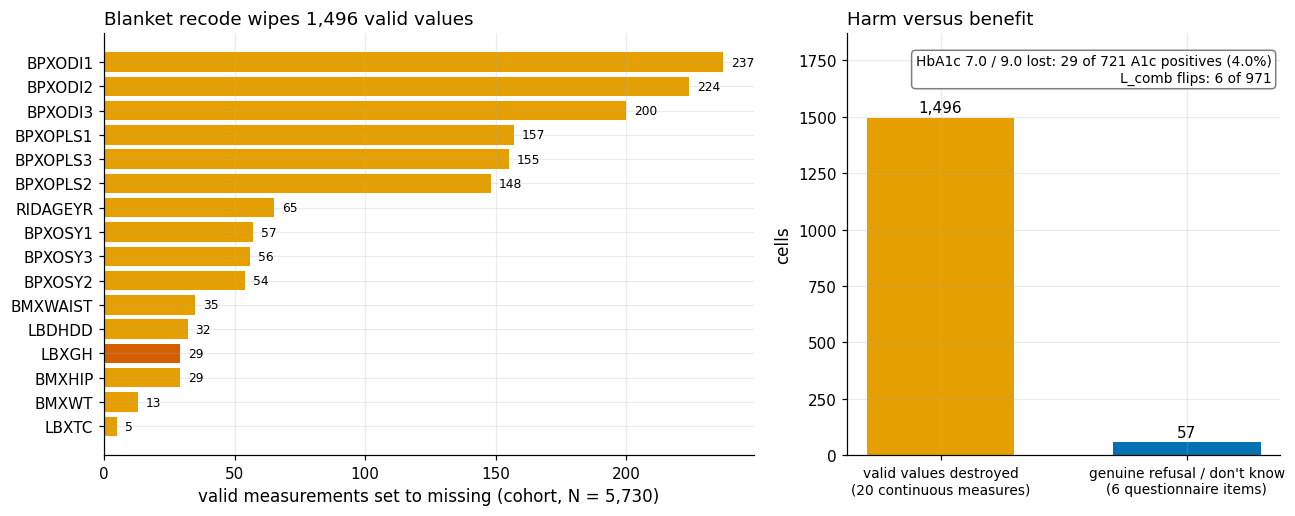

saved figures/S3_blanket_recode_damage.png


In [78]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
d = dmg[dmg["valid_cells_destroyed"] > 0].iloc[::-1]
col = [OI["vermillion"] if v == "LBXGH" else OI["orange"] for v in d["var"]]
a1.barh(d["var"], d["valid_cells_destroyed"], color=col)
for y, n in enumerate(d["valid_cells_destroyed"]):
    a1.text(n + 3, y, str(n), va="center", fontsize=8)
a1.set_xlabel("valid measurements set to missing (cohort, N = 5,730)")
a1.set_title(f"Blanket recode wipes {n_destroyed:,} valid values", loc="left")
bars = [("valid values destroyed\n(20 continuous measures)", n_destroyed, OI["orange"]),
        ("genuine refusal / don't know\n(6 questionnaire items)", n_q, OI["blue"])]
a2.bar([b[0] for b in bars], [b[1] for b in bars], color=[b[2] for b in bars], width=0.6)
for x, b in enumerate(bars):
    a2.text(x, b[1] + 25, f"{b[1]:,}", ha="center", fontsize=10)
a2.set_ylabel("cells"); a2.set_ylim(0, n_destroyed * 1.25); a2.tick_params(axis="x", labelsize=9)
a2.set_title("Harm versus benefit", loc="left")
a2.text(0.98, 0.95, f"HbA1c 7.0 / 9.0 lost: {lost_pos} of {int(a1c_pos.sum())} A1c positives ({lost_pos / a1c_pos.sum():.1%})\n"
        f"L_comb flips: {flips} of {int(l_comb.sum())}", transform=a2.transAxes, ha="right", va="top", fontsize=9,
        bbox=dict(boxstyle="round", fc="white", ec=OI["grey"]))
fig.tight_layout()
f_blank = plots.savefig(fig, "S3_blanket_recode_damage",
                        caption=f"Left: valid measurements removed by a blanket recode of 7/9/77/99/777/999/7777/9999 in the cohort, by variable "
                                f"({n_destroyed:,} in total; HbA1c in red). Right: the shortcut destroys {n_destroyed:,} valid values to clean {n_q} genuine "
                                f"refusal/don't-know answers in the questionnaire items; it removes {lost_pos}/{int(a1c_pos.sum())} HbA1c-defined positives, "
                                f"of which {flips} of {int(l_comb.sum())} L_comb positives flip.")
plt.show(); print("saved", f_blank)

**So what.** On the same 5,730 adults, the blanket recode destroys **1,496 valid measurements** across the 20 continuous candidates. Most fall on diastolic pressure and pulse, where 77 and 99 are ordinary readings. Over the whole release the same 20 variables lose 2,472 values, a secondary count. The harm reaches the label:

- All 29 HbA1c values it removes are 7.0 % (28) or 9.0 % (1), so every one is a true diabetic value. That is **29 of the 721 HbA1c-defined positives (4.0 %)** lost.
- Under the frozen `L_comb` only **6 of 971** positives flip, because the other 23 also report a diagnosis. Self-report hides the error, which makes it easy to miss.

Applied to every numeric column, the shortcut also wipes categorical codes that are real categories. Examples are `RIDRETH3 = 7` (the 363 multiracial adults disappear as a group), 380 moderate-activity frequencies of 7 sessions (`PAD790Q`) and age 77.

The benefit side is small. Restricting the shortcut to the six questionnaire items cleans just **57** genuine codes, so the shortcut's harm exceeds its gain by a factor of about 26. **Decision (DR-S3-02, evidence):** the per-variable map is the systematic arm. The blanket recode is kept only as the deliberately naive M0 arm in Stage S6, where its cost becomes measurable in model terms.

In [79]:
M3["blanket_recode"] = {
    "valid_cells_destroyed_cohort": n_destroyed, "valid_cells_destroyed_full_file_same_20_vars": n_destroyed_full,
    "candidates": list(io.CONTINUOUS_CANDIDATES),
    "per_variable": dict(zip(dmg["var"], dmg["valid_cells_destroyed"].astype(int))),
    "a1c_positives_lost": lost_pos, "a1c_positives": int(a1c_pos.sum()), "a1c_lost_share": lost_pos / int(a1c_pos.sum()),
    "l_comb_flips": flips, "l_comb_positives": int(l_comb.sum()),
    "questionnaire_only_cells": n_q, "questionnaire_only_per_item": q_arm.to_dict(),
    "all_numeric_recoded": n_blank_all, "all_numeric_genuine": n_blank_genuine,
    "ridreth3_7_destroyed": int(aud_blank.set_index("var").loc["RIDRETH3", "valid_destroyed"]),
}

## 3.5 Consistency checks

**Why.** Internal consistency tests the data against facts that must hold: BMI is weight / height², systolic pressure exceeds diastolic, and pulse pressure and waist-to-height ratio stay within plausible bounds. Questions asked only of a sub-group (skip patterns) define who *can* have a value. That matters for leakage: a variable asked only of diagnosed people is a disguised label.

In [80]:
bmx = io.load_file("BMX_L")[0]
v = bmx.dropna(subset=["BMXWT", "BMXHT", "BMXBMI"])
bmi_diff = (v["BMXWT"] / (v["BMXHT"] / 100) ** 2 - v["BMXBMI"]).abs()
bpx = io.load_file("BPXO_L")[0]
chk = [["BMI = weight / height^2: valid triples (BMX_L)", len(v), "max |diff| = %.3f; > 0.1: %d" % (bmi_diff.max(), (bmi_diff > 0.1).sum())]]
pp_rows = []
for src_name, df in [("BPXO_L file", bpx), ("cohort", coh)]:
    for i in (1, 2, 3):
        s, dd = df[f"BPXOSY{i}"], df[f"BPXODI{i}"]
        pp = s - dd
        pp_rows.append({"population": src_name, "reading": i, "valid": int((s.notna() & dd.notna()).sum()),
                        "SBP <= DBP": int((s <= dd).sum()), "pulse pressure < 20": int((pp < 20).sum()),
                        "pulse pressure > 100": int((pp > 100).sum())})
pp_tab = pd.DataFrame(pp_rows)
whtr_gt1 = int((coh["whtr"] > 1).sum())
chk.append(["Waist-to-height ratio > 1 (cohort)", int(coh["whtr"].notna().sum()), f"{whtr_gt1} flagged"])
chk = pd.DataFrame(chk, columns=["check", "n", "result"])
display(chk); display(pp_tab)

diq_raw = io.read_xpt("DIQ_L")
univ = []
for var in ("DIQ050", "DIQ070"):
    ans = diq_raw[var].notna()
    g = diq_raw.loc[ans]
    univ.append({"var": var, "answered": int(ans.sum()),
                 "DIQ010=1": int((g["DIQ010"] == 1).sum()), "DIQ010=3": int((g["DIQ010"] == 3).sum()),
                 "DIQ010=2 & DIQ160=1": int(((g["DIQ010"] == 2) & (g["DIQ160"] == 1)).sum()),
                 "other": int((~((g["DIQ010"].isin([1, 3])) | ((g["DIQ010"] == 2) & (g["DIQ160"] == 1)))).sum())})
univ = pd.DataFrame(univ)
display(univ)
coh_dia = coh[coh["DIQ070"] == 1]
d070 = {"self-reported diabetes": int((coh_dia["DIQ010"] == 1).sum()), "borderline": int((coh_dia["DIQ010"] == 3).sum()),
        "no diabetes (told prediabetes)": int((coh_dia["DIQ010"] == 2).sum())}
print("cohort, DIQ070 = 1 (takes oral glucose-lowering medication):", d070)
consistency = pd.concat([chk.assign(kind="arithmetic"), pp_tab.assign(kind="blood pressure")], ignore_index=True)
consistency.to_csv(OUT / "consistency_checks.csv", index=False, lineterminator="\n")

assert len(v) == 8471 and bmi_diff.max() <= 0.05 + 1e-9 and (bmi_diff > 0.1).sum() == 0
assert pp_tab["SBP <= DBP"].sum() == 0 and whtr_gt1 == 4
assert univ.loc[0, ["answered", "DIQ010=1", "other"]].tolist() == [1081, 1081, 0]
assert univ.loc[1, ["DIQ010=1", "DIQ010=3", "DIQ010=2 & DIQ160=1", "other"]].tolist() == [1081, 282, 918, 0]

,check,n,result
0,BMI = weight / height^2: valid triples (BMX_L),8471,max |diff| = 0.050; > 0.1: 0
1,Waist-to-height ratio > 1 (cohort),5462,4 flagged


,population,reading,valid,SBP <= DBP,pulse pressure < 20,pulse pressure > 100
0,BPXO_L file,1,7517,0,12,37
1,BPXO_L file,2,7505,0,8,43
2,BPXO_L file,3,7480,0,11,32
3,cohort,1,5550,0,5,34
4,cohort,2,5544,0,2,39
5,cohort,3,5531,0,3,29


,var,answered,DIQ010=1,DIQ010=3,DIQ010=2 & DIQ160=1,other
0,DIQ050,1081,1081,0,0,0
1,DIQ070,2281,1081,282,918,0


cohort, DIQ070 = 1 (takes oral glucose-lowering medication): {'self-reported diabetes': 592, 'borderline': 44, 'no diabetes (told prediabetes)': 41}


**So what.** The arithmetic holds:

- BMI recomputed from weight and height matches the published value for all 8,471 valid triples (largest difference 0.050, which is rounding; none above 0.1).
- No reading has systolic ≤ diastolic pressure.
- Implausible pulse pressures are rare: below 20 mmHg in 5/2/3 cohort readings and 12/8/11 file readings; above 100 mmHg in 34/39/29 cohort readings. They are flagged, not changed: a wide pulse pressure is physiologically plausible in older adults (arterial stiffness).
- Four cohort members have a waist-to-height ratio above 1. They are flagged.

The skip patterns matter more. `DIQ050` (insulin) is answered only by the 1,081 people who report diabetes, so it is effectively a proxy of the label. `DIQ070` (oral medication) is also asked of 282 borderline respondents and of 918 non-diabetic respondents who were told they have prediabetes. Within the cohort, 41 non-diabetic and 44 borderline adults take glucose-lowering medication, plausibly metformin prescribed for prediabetes (the files do not name the drug). **Decision (DR-S3-06):** `DIQ050`/`DIQ070` are inadmissible as features (`admissible = N`). The treatment-aware sensitivity label in S5 may use them only inside this documented universe, and it must exclude prediabetes medication.

In [81]:
M3["consistency"] = {"bmi_triples": len(v), "bmi_max_abs_diff": float(bmi_diff.max()), "bmi_diff_gt_0_1": int((bmi_diff > 0.1).sum()),
                     "sbp_le_dbp": int(pp_tab["SBP <= DBP"].sum()),
                     "pp_lt20_cohort": pp_tab.query("population == 'cohort'")["pulse pressure < 20"].tolist(),
                     "pp_gt100_cohort": pp_tab.query("population == 'cohort'")["pulse pressure > 100"].tolist(),
                     "pp_lt20_file": pp_tab.query("population == 'BPXO_L file'")["pulse pressure < 20"].tolist(),
                     "pp_gt100_file": pp_tab.query("population == 'BPXO_L file'")["pulse pressure > 100"].tolist(),
                     "whtr_gt1": whtr_gt1, "diq050_universe": univ.iloc[0].drop("var").to_dict(),
                     "diq070_universe": univ.iloc[1].drop("var").to_dict(), "cohort_diq070_yes": d070}

## 3.6 Top-coding

**Why.** Disclosure control caps age at 80 and the income-to-poverty ratio at 5. A capped value is a bound rather than a measurement. A model that treats "80" as exactly 80 years, or that loses the 12.8 % of people with no income ratio, misreads the data. Two questions decide the treatment: how many people sit at each cap, and whether the cap hides a change in risk.

In [82]:
coh["L_comb"] = l_comb.astype(int)
age_top, pir_top, pir_miss = int(coh["age_top"].sum()), int(coh["pir_top"].sum()), int(coh["pir_miss"].sum())
prev_80 = coh.loc[coh["RIDAGEYR"] == 80, "L_comb"].mean()
prev_7079 = coh.loc[coh["RIDAGEYR"].between(70, 79), "L_comb"].mean()
top = pd.DataFrame([
    ["age_top (RIDAGEYR = 80)", age_top, age_top / len(coh)],
    ["pir_top (INDFMPIR = 5)", pir_top, pir_top / len(coh)],
    ["pir_miss (INDFMPIR missing)", pir_miss, pir_miss / len(coh)],
], columns=["flag", "n", "share"])
display(top)
print(f"L_comb prevalence (unweighted): age 80 group {prev_80:.1%}, ages 70-79 {prev_7079:.1%}")
assert (age_top, pir_top, pir_miss) == (321, 1282, 734)
assert close(prev_80, 0.262, 0.001) and close(prev_7079, 0.254, 0.001)

,flag,n,share
0,age_top (RIDAGEYR = 80),321,0.056021
1,pir_top (INDFMPIR = 5),1282,0.223735
2,pir_miss (INDFMPIR missing),734,0.128098


L_comb prevalence (unweighted): age 80 group 26.2%, ages 70-79 25.4%


**So what.** 321 adults (5.6 %) are capped at age 80, and 1,282 (22.4 %) at an income ratio of 5. Another 734 (12.8 %) have no income ratio at all. The age cap hides little: unweighted `L_comb` prevalence is 26.2 % in the capped group against 25.4 % at ages 70–79, so risk has flattened by then. Age standardisation in 60+ bands is unaffected.

The income variable is both capped and incomplete. **Decision (DR-S3-05):** keep the values and carry the flags `age_top`, `pir_top` and `pir_miss` next to them. Whether the flags enter the model is tested as ablation block B4 (P07 top-code flags, P06 missing indicator) in Stage S6.

In [83]:
M3["top_coding"] = {"age_top": age_top, "pir_top": pir_top, "pir_top_share": pir_top / len(coh),
                    "pir_miss": pir_miss, "pir_miss_share": pir_miss / len(coh),
                    "prev_age80": float(prev_80), "prev_age70_79": float(prev_7079)}

## 3.7 Missing-data mechanism for HbA1c

**Why.** The cohort keeps only examined adults *with* an HbA1c value. If missingness depended on diabetes itself, the label would be biased in a way no weighting could repair. Rubin's taxonomy cannot be settled from the data:

- MCAR can be rejected by showing that missingness depends on observed covariates.
- MAR versus MNAR depends on the unobserved values and cannot be tested.

A logistic model for the missingness indicator among the 6,064 examined adults shows who is missing. It is unweighted because it describes the sample rather than the population. Little's MCAR test is not used: it assumes multivariate normality, and it can only reject MCAR, which the logit already does more informatively.

In [84]:
mrg = io.load_merged(sentinels="per_variable")
ex = mrg[(mrg["RIDAGEYR"] >= C.ADULT_MIN_AGE) & (mrg["RIDSTATR"] == 2)].copy()
y_miss = ex["LBXGH"].isna().astype(int)
race_ex = ex["RIDRETH3"].map(io.RACE_LABELS)
Xm = pd.DataFrame({"age (per 10 y)": ex["RIDAGEYR"] / 10, "female": (ex["RIAGENDR"] == 2).astype(int)}, index=ex.index)
for r in ["NH Black", "NH Asian", "Mexican American", "Other Hispanic", "Other/Multi"]:
    Xm[r] = (race_ex == r).astype(int)
Xm["PIR (per unit)"] = ex["INDFMPIR"].fillna(ex["INDFMPIR"].mean())
Xm["PIR missing"] = ex["INDFMPIR"].isna().astype(int)
Xm["BMI (per unit)"] = ex["BMXBMI"].fillna(ex["BMXBMI"].mean())
Xm["BMI missing"] = ex["BMXBMI"].isna().astype(int)
Xm["uninsured"] = (ex["HIQ011"] == 2).astype(int)
Xm["no usual place of care"] = (ex["HUQ030"] == 2).astype(int)
Xm["self-reported diabetes"] = (ex["DIQ010"] == 1).astype(int)
Xm["told hypertension"] = (ex["BPQ020"] == 1).astype(int)
fit = sm.Logit(y_miss, sm.add_constant(Xm)).fit(disp=0)
ci = fit.conf_int()
or_tab = pd.DataFrame({"OR": np.exp(fit.params), "ci_low": np.exp(ci[0]), "ci_high": np.exp(ci[1]), "p": fit.pvalues}).drop("const")
auc_miss = roc_auc_score(y_miss, fit.predict())
miss_rate = ex.assign(m=y_miss, race=race_ex).groupby("race")["m"].agg(["size", "mean"]).rename(columns={"size": "n", "mean": "missing_share"})
print(f"examined adults {len(ex):,}; HbA1c missing {int(y_miss.sum())} ({y_miss.mean():.1%}); LLR p = {fit.llr_pvalue:.1e}; AUC = {auc_miss:.3f}")
display(or_tab.round(3)); display(miss_rate.round(3))
or_tab.to_csv(OUT / "missingness_or.csv", lineterminator="\n")

assert len(ex) == 6064 and int(y_miss.sum()) == 297
assert fit.llr_pvalue < 1e-10 and close(auc_miss, 0.65, 0.005)
assert close(or_tab.loc["NH Black", "OR"], 1.85, 0.01) and close(or_tab.loc["NH Black", "ci_low"], 1.35, 0.01) and close(or_tab.loc["NH Black", "ci_high"], 2.54, 0.01)
assert close(or_tab.loc["PIR (per unit)", "OR"], 0.82, 0.01) and close(or_tab.loc["age (per 10 y)", "OR"], 0.89, 0.01)
assert close(or_tab.loc["BMI missing", "OR"], 2.6, 0.06) and close(or_tab.loc["self-reported diabetes", "OR"], 1.15, 0.01)

examined adults 6,064; HbA1c missing 297 (4.9%); LLR p = 2.8e-11; AUC = 0.650


,OR,ci_low,ci_high,p
age (per 10 y),0.893,0.826,0.965,0.004
female,0.948,0.745,1.205,0.660
NH Black,1.853,1.351,2.541,0.000
NH Asian,1.383,0.846,2.263,0.196
Mexican American,0.772,0.448,1.328,0.349
Other Hispanic,0.842,0.541,1.309,0.444
Other/Multi,1.244,0.785,1.973,0.353
PIR (per unit),0.820,0.753,0.892,0.000
PIR missing,1.572,1.151,2.148,0.004
BMI (per unit),0.997,0.981,1.014,0.723


,n,missing_share
race,,
Mexican American,405,0.040
NH Asian,335,0.060
NH Black,753,0.093
NH White,3569,0.040
Other Hispanic,614,0.042
Other/Multi,388,0.059


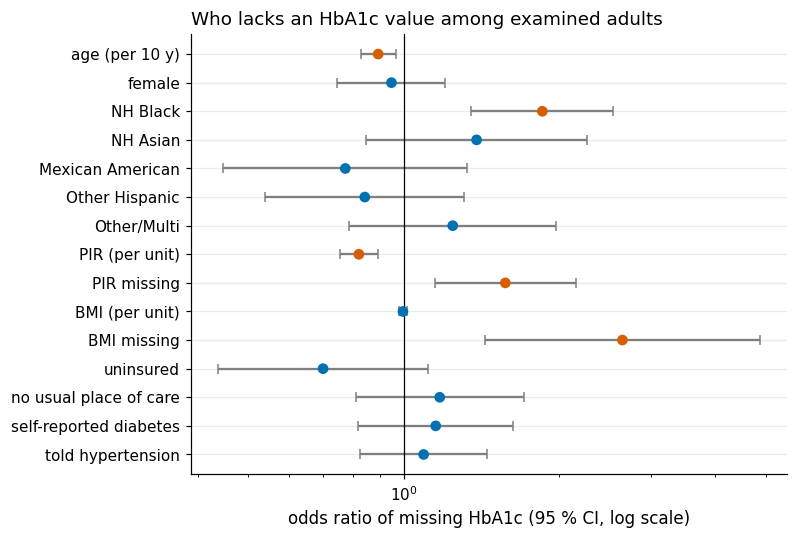

saved figures/S3_missing_hba1c_or.png


In [85]:
ot = or_tab.iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5.2))
sig = (ot["ci_low"] > 1) | (ot["ci_high"] < 1)
ax.errorbar(ot["OR"], range(len(ot)), xerr=[ot["OR"] - ot["ci_low"], ot["ci_high"] - ot["OR"]], fmt="none", ecolor=OI["grey"], capsize=3)
ax.scatter(ot["OR"], range(len(ot)), color=[OI["vermillion"] if s else OI["blue"] for s in sig], zorder=3)
ax.axvline(1, color="black", lw=0.8)
ax.set_xscale("log"); ax.set_yticks(range(len(ot)), ot.index)
ax.set_xlabel("odds ratio of missing HbA1c (95 % CI, log scale)")
ax.set_title("Who lacks an HbA1c value among examined adults", loc="left")
f_miss = plots.savefig(fig, "S3_missing_hba1c_or",
                       caption=f"Unweighted logistic model for missing HbA1c among {len(ex):,} examined adults ({int(y_miss.sum())} missing). "
                               f"Odds ratios with 95 % Wald CIs; red = CI excludes 1. LLR p = {fit.llr_pvalue:.1e}, AUC = {auc_miss:.2f}. Reference: NH White.")
plt.show(); print("saved", f_miss)

**So what.** 297 of 6,064 examined adults (4.9 %) lack HbA1c, and missingness clearly depends on observed covariates (likelihood-ratio p = 2.8 × 10⁻¹¹, AUC 0.65). Data are **not MCAR**. Associations with missing HbA1c:

| Covariate | OR (95 % CI) |
|---|---|
| Non-Hispanic Black | 1.85 (1.35, 2.54) |
| Income ratio, per unit | 0.82 |
| Age, per 10 years | 0.89 |
| Missing BMI | 2.6 (typically an incomplete examination) |
| Self-reported diabetes | 1.15 (0.82, 1.63) |

Self-reported diabetes, the closest observable stand-in for the outcome, shows no association.

The correct wording is narrow. **Given these covariates there is no evidence against MAR, and MNAR cannot be tested with these data.** **Decision (DR-S3-04):** this wording is used everywhere. WTPH2YR already contains NCHS's blood-sample non-response adjustment. A delta-adjustment / inverse-probability-weighting sensitivity analysis for MNAR is assigned to Stage S9. The model is descriptive and is not used for population inference.

In [86]:
M3["missingness"] = {"examined_adults": len(ex), "a1c_missing": int(y_miss.sum()), "a1c_missing_share": float(y_miss.mean()),
                     "llr_p": float(fit.llr_pvalue), "auc": float(auc_miss),
                     "odds_ratios": {k: {kk: float(vv) for kk, vv in r.items()} for k, r in or_tab.iterrows()},
                     "missing_share_by_race": miss_rate["missing_share"].to_dict(),
                     "wording": "not MCAR; no evidence against MAR given covariates; MNAR untestable (sensitivity in S9)"}

## 3.8 Outliers: a three-layer rule

**Why.** Extreme values in clinical data are often the signal itself: a very high HbA1c *is* diabetes. A rule that deletes values outside 1.5 × IQR therefore removes cases, not errors. The project uses three layers:

1. hard physiological limits, which only flag;
2. a robust z-score (median and MAD, |z| > 3.5), which only flags;
3. human review of whatever both layers flag.

The harm of the blind alternative is measured directly on HbA1c and on a joint fence over five predictors.

In [87]:
LIMITS = {"BMXBMI": (12, 70), "bp_sys_mean": (70, 260), "bp_dia_mean": (30, 150), "LBXTC": (60, 500), "LBDHDD": (10, 200), "LBXGH": (3, 18)}
def robust_z(s):
    med = s.median(); mad = (s - med).abs().median()
    return 0.6745 * (s - med) / mad
out_rows = []
for var, (lo, hi) in LIMITS.items():
    s = coh[var]
    hard = (s < lo) | (s > hi)
    rz = robust_z(s).abs() > 3.5
    out_rows.append({"var": var, "valid": int(s.notna().sum()), "min": s.min(), "max": s.max(), "limits": f"{lo}-{hi}",
                     "layer1_outside_limits": int(hard.sum()), "layer2_robust_z_gt_3.5": int(rz.sum()),
                     "both_layers": int((hard & rz).sum())})
outl = pd.DataFrame(out_rows)
display(outl)
outl.to_csv(OUT / "outlier_flags.csv", index=False, lineterminator="\n")
review = int(outl["both_layers"].sum())
print(f"layer 3 (manual review queue): {review} values flagged by both layers")

def iqr_fence(s):
    q1, q3 = s.quantile([0.25, 0.75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i), q1 - 1.5 * i, q3 + 1.5 * i

a1c = coh["LBXGH"]
fl, lo_f, hi_f = iqr_fence(a1c)
n_fl, n_fl_pos = int(fl.sum()), int((fl & (a1c >= C.HBA1C_DIABETES)).sum())
JOINT = ["BMXBMI", "BMXWAIST", "BPXOSY1", "LBXTC", "LBDHDD"]
joint = np.zeros(len(coh), bool)
for c_ in JOINT:
    joint |= iqr_fence(coh[c_])[0].to_numpy()
la1c = (a1c >= C.HBA1C_DIABETES)
prev_del, prev_keep = la1c[joint].mean(), la1c[~joint].mean()
print(f"HbA1c 1.5xIQR fence: [{lo_f:.2f}, {hi_f:.2f}] flags {n_fl} rows, {n_fl_pos} of them A1c >= 6.5 ({n_fl_pos / la1c.sum():.0%} of {int(la1c.sum())} positives)")
print(f"joint fence on {JOINT}: deletes {int(joint.sum())} rows ({joint.mean():.1%}); A1c-positive share deleted {prev_del:.1%} vs kept {prev_keep:.1%}")
assert close(hi_f, 6.8, 1e-9) and n_fl == 542 and n_fl_pos == 519
assert outl.set_index("var").loc["BMXBMI", "layer1_outside_limits"] == 2 and outl.set_index("var").loc["LBXGH", "layer2_robust_z_gt_3.5"] == 462 and review == 1
assert int(joint.sum()) == 512 and close(prev_del, 0.172, 0.001) and close(prev_keep, 0.121, 0.001)

,var,valid,min,max,limits,layer1_outside_limits,layer2_robust_z_gt_3.5,both_layers
0,BMXBMI,5649,11.1,74.800000,12-70,2,88,1
1,bp_sys_mean,5550,70.0,232.333333,70-260,0,67,0
2,bp_dia_mean,5550,34.0,139.000000,30-150,0,29,0
3,LBXTC,5459,62.0,438.000000,60-500,0,21,0
4,LBDHDD,5459,22.0,159.000000,10-200,0,60,0
5,LBXGH,5730,3.2,17.100000,3-18,0,462,0


layer 3 (manual review queue): 1 values flagged by both layers
HbA1c 1.5xIQR fence: [4.40, 6.80] flags 542 rows, 519 of them A1c >= 6.5 (72% of 721 positives)
joint fence on ['BMXBMI', 'BMXWAIST', 'BPXOSY1', 'LBXTC', 'LBDHDD']: deletes 512 rows (8.9%); A1c-positive share deleted 17.2% vs kept 12.1%


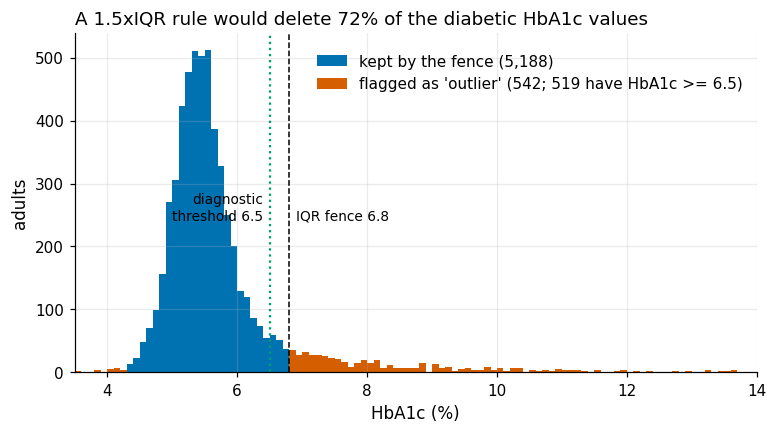

saved figures/S3_iqr_fence_harm.png


In [88]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(3.0, 17.6, 0.1)
ax.hist(a1c[~fl], bins=bins, color=OI["blue"], label=f"kept by the fence ({len(coh) - n_fl:,})")
ax.hist(a1c[fl], bins=bins, color=OI["vermillion"], label=f"flagged as 'outlier' ({n_fl}; {n_fl_pos} have HbA1c >= 6.5)")
ytop = ax.get_ylim()[1]
ax.axvline(hi_f, color="black", ls="--", lw=1); ax.text(hi_f + 0.1, ytop * 0.45, f"IQR fence {hi_f:.1f}", fontsize=9)
ax.axvline(C.HBA1C_DIABETES, color=OI["green"], ls=":", lw=1.5); ax.text(C.HBA1C_DIABETES - 0.1, ytop * 0.45, "diagnostic\nthreshold 6.5", ha="right", fontsize=9)
ax.set_xlim(3.5, 14); ax.set_xlabel("HbA1c (%)"); ax.set_ylabel("adults")
ax.set_title(f"A 1.5xIQR rule would delete {n_fl_pos / la1c.sum():.0%} of the diabetic HbA1c values", loc="left")
ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.98))
f_iqr = plots.savefig(fig, "S3_iqr_fence_harm",
                      caption=f"HbA1c distribution in the cohort (N = {len(coh):,}). A 1.5xIQR fence (upper bound {hi_f:.1f} %) flags {n_fl} values; "
                              f"{n_fl_pos} of them are at or above the diagnostic threshold of 6.5 %, i.e. {n_fl_pos / la1c.sum():.0%} of the {int(la1c.sum())} HbA1c-defined cases.")
plt.show(); print("saved", f_iqr)

**So what.** The hard limits flag almost nothing: 2 BMI values. The robust z-score layer already shows the problem with statistical rules on clinical data. It flags 462 HbA1c values, which are the diabetic tail, so it may only flag and never delete. Only one value is flagged by both layers and goes to manual review. Two results show what blind deletion would cost:

- **HbA1c fence.** The upper fence is 6.8 %. It flags 542 rows, and 519 of them have HbA1c ≥ 6.5 %. Deleting them would remove **72 % of all HbA1c-defined diabetes cases**, so the "outliers" are the outcome.
- **Joint predictor fence.** A fence over five predictors (BMI, waist, first SBP reading, total cholesterol, HDL) deletes 512 rows (8.9 %). The deleted group has an HbA1c-positive share of 17.2 % against 12.1 % among those kept, so the deletion shifts the label distribution.

**Decision (DR-S3-03):** keep every value. Layers 1–2 only add flags, and layer 3 reviews the few values flagged by both layers. Skewness is handled as an ablation in Stage S6 (block B5: Yeo-Johnson; winsorising as an alternative arm), not by deleting values.

In [89]:
M3["outliers"] = {"layer_table": outl.set_index("var")[["layer1_outside_limits", "layer2_robust_z_gt_3.5", "both_layers"]].to_dict("index"),
                  "manual_review": review,
                  "a1c_iqr_fence_upper": float(hi_f), "a1c_iqr_flagged": n_fl, "a1c_iqr_flagged_positive": n_fl_pos,
                  "a1c_iqr_positive_share": n_fl_pos / int(la1c.sum()),
                  "joint_fence_vars": JOINT, "joint_fence_deleted": int(joint.sum()), "joint_fence_share": float(joint.mean()),
                  "joint_fence_prev_deleted": float(prev_del), "joint_fence_prev_kept": float(prev_keep)}

## 3.9 Data-quality dimension matrix

**Why.** The checks above are only useful if they add up to a judgement per quality dimension. The matrix uses the six DAMA UK dimensions (completeness, uniqueness, timeliness, validity, accuracy, consistency; DAMA UK 2013, cited from a third-party copy). It adds **credibility** from ISO/IEC 25012:2008 for what the files cannot show internally: low response rates and a self-reported label. Each dimension gets a metric, a threshold, the computed result and a verdict.

In [90]:
feat = inc[(inc["admissible"].isin(["T1", "T2"]))]["var"].tolist()
miss_by_var = coh[feat].isna().mean().sort_values(ascending=False)
structural = {"PAD800": "skip: only if moderate activity > 0", "PAD820": "skip: only if vigorous activity > 0",
              "PAD790U": "skip: unit only if frequency > 0", "PAD810U": "skip: unit only if frequency > 0"}
mv = miss_by_var.rename("missing_share").to_frame()
mv["structural_skip"] = mv.index.map(structural).fillna("")
mv.to_csv(OUT / "missingness_by_var.csv", lineterminator="\n")
item_miss = mv[mv["structural_skip"] == ""]["missing_share"]
print("highest feature missingness (cohort):"); display(mv.head(8).round(3))

# validity: values outside the codebook range after per-variable recoding (top codes and special codes allowed)
cbs = io.spec_from_codebooks().set_index(["file", "var"])
viol = 0; checked = 0
for _, r in inc[(inc["dtype"] == "continuous")].iterrows():
    s = mrg[r["var"]].dropna()
    ref = cbs.loc[(r["file"], r["var"])]
    allowed = set(io._codes(ref["top_code"])) | {io._num(p.split("=")[0]) for p in ref["special_codes"].split("; ") if "=" in p}
    bad = ~(s.between(r["valid_min"], r["valid_max"]) | s.isin(allowed))
    viol += int(bad.sum()); checked += len(s)
print(f"validity: {checked:,} continuous values checked against codebook ranges; outside range: {viol}")
assert viol == 0

resp_int, resp_mec = 0.346, 0.257   # NCHS cycle overview (not computable from the files)
dq = pd.DataFrame([
    ["Completeness", "max item missingness among T1/T2 features in cohort (excl. structural skips)", "<= 40 % (L1 trigger)",
     f"{item_miss.max():.1%} ({item_miss.idxmax()}); HbA1c missing in 4.9 % of examined adults, not MCAR", "pass with flags"],
    ["Uniqueness", "duplicate SEQN per file; files subset of DEMO_L", "0 duplicates",
     f"{int((~uniq['seqn_unique']).sum())} duplicates in 16 files; all subsets", "pass"],
    ["Timeliness", "collection window; drift test", "single documented cycle",
     "Aug 2021 - Aug 2023, one cycle; no drift test possible (no pooling)", "not assessable"],
    ["Validity", "values outside codebook range after per-variable recode; sentinel codes traceable", "0 out of range; 100 % traceable",
     f"{viol} of {checked:,} values out of range; {int(sent['traceable'].sum())}/{len(sent)} sentinel variables traceable; XPT artefact repaired ({n_art:,} cells)", "pass"],
    ["Accuracy", "BMI recomputation; external anchor; label agreement", "|diff| <= 0.1; NCHS Data Brief 516 replication within 0.1 pp (§3)",
     f"max BMI diff {bmi_diff.max():.3f}; label accuracy limited: self-report vs HbA1c disagree (S5 kappa)", "pass for measures, limited for label"],
    ["Consistency", "SBP > DBP; skip-pattern universes; duplicate weight columns identical", "0 violations",
     f"SBP <= DBP: {int(pp_tab['SBP <= DBP'].sum())}; WHtR > 1: {whtr_gt1} flagged; DIQ050/DIQ070 universes as documented", "pass"],
    ["Credibility (ISO/IEC 25012)", "response rates; label source", "documented, not correctable",
     f"interview response {resp_int:.1%}, examination {resp_mec:.1%}; self-reported diagnosis part of the label", "limited"],
], columns=["dimension", "metric", "threshold", "result", "verdict"])
display(dq)
dq.to_csv(OUT / "quality_matrix.csv", index=False, lineterminator="\n")

highest feature missingness (cohort):


,missing_share,structural_skip
PAD820,0.557,skip: only if vigorous activity > 0
PAD810U,0.556,skip: unit only if frequency > 0
PAD800,0.209,skip: only if moderate activity > 0
PAD790U,0.207,skip: unit only if frequency > 0
INDFMPIR,0.128,
BMXHIP,0.054,
LBXTC,0.047,
LBDHDD,0.047,


validity: 214,422 continuous values checked against codebook ranges; outside range: 0


,dimension,metric,threshold,result,verdict
0,Completeness,max item missingness among T1/T2 features in cohort (excl. structu...,<= 40 % (L1 trigger),"12.8% (INDFMPIR); HbA1c missing in 4.9 % of examined adults, not MCAR",pass with flags
1,Uniqueness,duplicate SEQN per file; files subset of DEMO_L,0 duplicates,0 duplicates in 16 files; all subsets,pass
2,Timeliness,collection window; drift test,single documented cycle,"Aug 2021 - Aug 2023, one cycle; no drift test possible (no pooling)",not assessable
3,Validity,values outside codebook range after per-variable recode; sentinel ...,0 out of range; 100 % traceable,"0 of 214,422 values out of range; 25/25 sentinel variables traceab...",pass
4,Accuracy,BMI recomputation; external anchor; label agreement,|diff| <= 0.1; NCHS Data Brief 516 replication within 0.1 pp (§3),max BMI diff 0.050; label accuracy limited: self-report vs HbA1c d...,"pass for measures, limited for label"
5,Consistency,SBP > DBP; skip-pattern universes; duplicate weight columns identical,0 violations,SBP <= DBP: 0; WHtR > 1: 4 flagged; DIQ050/DIQ070 universes as doc...,pass
6,Credibility (ISO/IEC 25012),response rates; label source,"documented, not correctable","interview response 34.6%, examination 25.7%; self-reported diagnos...",limited


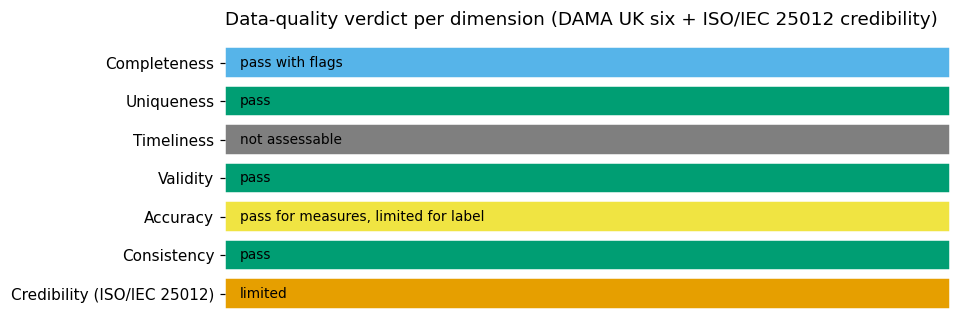

saved figures/S3_quality_matrix.png


In [91]:
order = {"pass": 0, "pass with flags": 1, "pass for measures, limited for label": 2, "limited": 3, "not assessable": 4}
cmap = {0: OI["green"], 1: OI["sky"], 2: OI["yellow"], 3: OI["orange"], 4: OI["grey"]}
fig, ax = plt.subplots(figsize=(8.5, 3.4))
for i, (dim, ver) in enumerate(zip(dq["dimension"], dq["verdict"])):
    ax.barh(i, 1, color=cmap[order[ver]], edgecolor="white")
    ax.text(0.02, i, ver, va="center", fontsize=9)
ax.set_yticks(range(len(dq)), dq["dimension"]); ax.invert_yaxis(); ax.set_xticks([]); ax.grid(False)
ax.set_xlim(0, 1); ax.set_title("Data-quality verdict per dimension (DAMA UK six + ISO/IEC 25012 credibility)", loc="left")
for s_ in ax.spines.values():
    s_.set_visible(False)
f_dq = plots.savefig(fig, "S3_quality_matrix", caption="Verdict per data-quality dimension; metrics, thresholds and results in results/S3/quality_matrix.csv.")
plt.show(); print("saved", f_dq)

**So what.** The measurements are trustworthy once the two read-time problems are fixed (the XPT artefact and the per-variable sentinels):

- every key is unique;
- every continuous value lies inside its codebook range;
- BMI recomputes;
- blood-pressure pairs are coherent.

The weak points lie elsewhere. **Credibility** is limited: response rates are 34.6 % for the interview and 25.7 % for the examination, and the label partly rests on self-report. **Timeliness** cannot be assessed, because there is only one cycle. **Completeness** passes with flags. The highest item missingness among model features is in the income ratio and the activity minutes; the activity minutes are skip-pattern structural and not truly missing. HbA1c missingness is covariate-dependent (item 7). No variable triggers the L1 loop (more than 40 % item missingness, no variation, or a post-diagnosis variable among the admissible features), so the variable scope can be frozen. **Decision (DR-S3-07):** freeze the variable scope (`scope-freeze`). Carry credibility and label accuracy as stated limitations to S5 and S10.

In [92]:
M3["quality_matrix"] = dq.set_index("dimension")[["result", "verdict"]].to_dict("index")
M3["validity"] = {"continuous_values_checked": checked, "out_of_range": viol}
M3["max_item_missing_feature"] = {"var": item_miss.idxmax(), "share": float(item_miss.max())}

## 3.10 Decisions and stored results

**Why.** Each decision above is written to the decision register with its evidence. The self-check is a re-computation, not a reading: every value in `evidence_value` comes from a variable computed in this run.

In [93]:
reg2 = write_register("S2", [
    dict(dr_id="DR-S2-01", stage="S2", date=TODAY, type="governance", finding="NCHS DUA forbids re-identification, linkage and study of disclosure methods; presentation standards apply to survey estimates",
         evidence_ref="governance/dua_checklist.md", evidence_value="5 obligations mapped; 4 presentation rules (n<30, n_eff<30, CI width>=0.30, df<8)",
         decision="Comply as mapped in the checklist; external validation against published aggregates only; small groups (NH Asian 315) always exploratory",
         alternatives_rejected="External validation by linking other micro-data (forbidden)", status="decided", check_verdict="PASS",
         check_note="Checklist re-read against the DUA page; quasi-identifiers confirmed absent from the loaded columns (minimisation report)"),
    dict(dr_id="DR-S2-02", stage="S2", date=TODAY, type="weights", finding="Each weight belongs to a sub-sample; zero weights mean 'not in sub-sample'",
         evidence_ref="governance/dua_checklist.md §3; notebooks/sections/02_profiling.py item 1",
         evidence_value=f"WTMEC2YR=0: {M3['zero_weights']['WTMEC2YR_0']}; WTPH2YR=0: {M3['zero_weights']['WTPH2YR_0']}; cohort WTPH2YR=0: {zero_in_cohort}",
         decision="WTPH2YR for every cohort analysis with HbA1c or lipids; WTSAF2YR only for DB516/SL5; WTINT2YR/WTMEC2YR for interview/exam-only descriptions; zero weights -> NaN; domains by zero weights, never row deletion",
         alternatives_rejected="WTMEC2YR for HbA1c analyses (ignores blood-sample non-response); unweighted descriptions", status="decided", check_verdict="PASS",
         check_note="Zero-weight counts recomputed; WTMEC2YR=0 equals RIDSTATR=1 (3,073)"),
    dict(dr_id="DR-S2-03", stage="S2", date=TODAY, type="minimisation", finding="16 files contain 175 columns, many not needed for the purpose (child items, quasi-identifiers, duplicates)",
         evidence_ref="results/S2/minimisation_report.csv; results/S2/minimisation_columns.csv",
         evidence_value=f"raw {n_raw}, kept {n_kept}, dropped {n_drop} (each with reason)",
         decision="Loader keeps only spec-included columns; dropped columns listed with reason",
         alternatives_rejected="Load all columns and select later (purpose limitation violated, more disclosure risk)", status="decided", check_verdict="PASS",
         check_note="Report regenerated from the spec in this run; every dropped column has a non-empty reason (assert)"),
    dict(dr_id="DR-S2-04", stage="S2", date=TODAY, type="specification", finding="Sentinel codes differ by variable and continuous measures have none; a single spec avoids drift between code and documentation",
         evidence_ref="config/variable_spec.csv; nhanes_io.verify_spec",
         evidence_value=f"{len(spec)} spec rows; {n_sentinel_vars} included variables with codebook sentinels; verify_spec problems: {len(problems)}",
         decision="variable_spec.csv (15 documented columns) is the single source; sentinel_codes parsed from the CDC codebooks (Refused / Don't know only); roles and admissibility from the S1 availability rule",
         alternatives_rejected="Hand-written sentinel list; global 7/9/77/99 list", status="decided", check_verdict="PASS",
         check_note="verify_spec re-parses all 16 codebooks and the XPT headers in this run: 0 problems"),
    dict(dr_id="DR-S2-05", stage="S2", date=TODAY, type="provenance", finding="Numbers are only reproducible if the raw files are byte-identical to the CDC release",
         evidence_ref="data/nhanes_2021_2023/MANIFEST.sha256; nhanes_io.ensure_raw_data",
         evidence_value=f"{len(integrity['verified'])}/16 hashes verified; funnel {' -> '.join(f'{n:,}' for n in fun['n'])}",
         decision="Verify hashes at the start of every profiling run; datasheet (Gebru) documents composition and preprocessing",
         alternatives_rejected="Trust the download", status="decided", check_verdict="PASS", check_note="Hashes and funnel recomputed in this run"),
    dict(dr_id="DR-S2-06", stage="S2", date=TODAY, type="coding", finding="Borderline diabetes (DIQ010=3) and uncertain pregnancy (RIDEXPRG=3) are legitimate but ambiguous codes",
         evidence_ref="notebooks/sections/02_profiling.py items 2-3",
         evidence_value=f"DIQ010=3: {int(legit.loc[0, 'cohort'])} in cohort ({int(legit.loc[0, 'file'])} in file); RIDEXPRG=3: {preg3} in cohort",
         decision="Keep both; DIQ010=3 negative in L_self and flagged (S5 sensitivity SL3); RIDEXPRG=3 kept with flag preg_unknown for a sensitivity drop",
         alternatives_rejected="Recode as missing (loses 213 people with elevated risk); drop RIDEXPRG=3", status="decided", check_verdict="PASS",
         check_note="Counts recomputed and asserted (213/284, 21)"),
])
reg3 = write_register("S3", [
    dict(dr_id="DR-S3-01", stage="S3", date=TODAY, type="data_fix", finding="pandas reads stored zeros in XPT files as 5.4e-79; a where()-based repair turns NaN into 0",
         evidence_ref="results/S3/xpt_artefacts.csv; item 1", evidence_value=f"{n_art:,} cells in {len(files_hit)} files; PAQ NaN {nan_before} kept by mask, {nan_wrong} after where",
         decision="Repair with x.mask((|x|<1e-10) & x.notna(), 0.0) at load (nhanes_io.fix_xpt); zero weights -> NaN before weighting",
         alternatives_rejected="where(); leave artefact", status="decided", check_verdict="PASS",
         check_note="Residual 0<|x|<1e-10 = 0 in all files and NaN counts unchanged (asserts)"),
    dict(dr_id="DR-S3-02", stage="S3", date=TODAY, type="cleaning", finding="Blanket recode of 7/9/77/99/777/999/7777/9999 destroys valid measurements; codebook sentinels only exist for questionnaire items",
         evidence_ref="results/S3/sentinel_audit.csv; results/S3/blanket_damage.csv; figures/S3_blanket_recode_damage.png",
         evidence_value=f"{n_destroyed:,} valid cells destroyed (cohort, 20 continuous vars; full file {n_destroyed_full:,}); A1c positives lost {lost_pos}/{int(a1c_pos.sum())}; L_comb flips {flips}/{int(l_comb.sum())}; questionnaire-only arm {n_q} cells",
         decision="Per-variable sentinel recoding from the codebook (systematic arm); blanket recode only as the naive M0 arm in S6",
         alternatives_rejected="Blanket recode; questionnaire-only blanket (cleans 57 cells, needs the same per-variable knowledge)", status="decided", check_verdict="PASS",
         check_note="1,496 / 29 of 721 / 6 of 971 / 57 recomputed and asserted; every recoded code traceable to codebook counts"),
    dict(dr_id="DR-S3-03", stage="S3", date=TODAY, type="outliers", finding="Extreme HbA1c values are the outcome, not errors",
         evidence_ref="results/S3/outlier_flags.csv; figures/S3_iqr_fence_harm.png",
         evidence_value=f"A1c IQR fence {hi_f:.1f}: {n_fl} flagged, {n_fl_pos} with A1c>=6.5 ({n_fl_pos / la1c.sum():.0%} of positives); joint fence deletes {int(joint.sum())} rows, A1c+ share {prev_del:.1%} vs {prev_keep:.1%}",
         decision="Keep all values; three-layer rule (hard limits flag, robust z flag, manual review); transformation/winsorising only as S6 ablation (B5)",
         alternatives_rejected="1.5xIQR deletion; z-score deletion", status="decided", check_verdict="PASS", check_note="542/519 and 512 recomputed and asserted"),
    dict(dr_id="DR-S3-04", stage="S3", date=TODAY, type="missingness", finding="HbA1c missingness depends on race, income, age and examination completeness, not on self-reported diabetes",
         evidence_ref="results/S3/missingness_or.csv; figures/S3_missing_hba1c_or.png",
         evidence_value=f"{int(y_miss.sum())}/{len(ex)} missing; LLR p={fit.llr_pvalue:.1e}; AUC {auc_miss:.2f}; NH Black OR {or_tab.loc['NH Black', 'OR']:.2f} ({or_tab.loc['NH Black', 'ci_low']:.2f}, {or_tab.loc['NH Black', 'ci_high']:.2f}); self-report OR {or_tab.loc['self-reported diabetes', 'OR']:.2f}",
         decision="Wording: not MCAR; no evidence against MAR given covariates; MNAR untestable. Complete-case cohort with WTPH2YR (includes blood non-response adjustment); MNAR sensitivity (delta / IPW) in S9",
         alternatives_rejected="Little's MCAR test (normality, only rejects MCAR); multiple imputation of the label", status="decided", check_verdict="PASS",
         check_note="Logit refitted in this run; ORs asserted against the reference values", loop_ref="S9 MNAR sensitivity"),
    dict(dr_id="DR-S3-05", stage="S3", date=TODAY, type="top_coding", finding="Age capped at 80 and PIR at 5; PIR also missing",
         evidence_ref="item 6", evidence_value=f"age_top {age_top}; pir_top {pir_top} ({pir_top / len(coh):.1%}); pir_miss {pir_miss} ({pir_miss / len(coh):.1%}); L_comb 80: {prev_80:.1%} vs 70-79: {prev_7079:.1%}",
         decision="Keep values and carry flags age_top, pir_top, pir_miss; their model value tested in S6 block B4 (P06/P07)",
         alternatives_rejected="Treat caps as exact; drop PIR-missing rows (12.8 %)", status="decided", check_verdict="PASS", check_note="Counts and prevalences recomputed and asserted"),
    dict(dr_id="DR-S3-06", stage="S3", date=TODAY, type="leakage", finding="DIQ050 is asked only of diagnosed people; DIQ070 also of borderline and prediabetic respondents",
         evidence_ref="item 5", evidence_value=f"DIQ050 universe {univ.loc[0, 'answered']} (all DIQ010=1); DIQ070: 1,081 / 282 / 918; cohort DIQ070=1: {d070}",
         decision="DIQ050/DIQ070 inadmissible as features (spec admissible=N); usable only for the treatment-aware sensitivity label within the documented universe, excluding prediabetes medication",
         alternatives_rejected="Use DIQ070 as a feature (label proxy)", status="decided", check_verdict="PASS", check_note="Universes recomputed from DIQ_L and asserted"),
    dict(dr_id="DR-S3-07", stage="S3", date=TODAY, type="scope", finding="No admissible variable triggers the L1 loop; quality is high for measures, limited for credibility and label",
         evidence_ref="results/S3/quality_matrix.csv; figures/S3_quality_matrix.png",
         evidence_value=f"max item missingness {item_miss.max():.1%} ({item_miss.idxmax()}); validity {viol} out-of-range of {checked:,}; response 34.6 % / 25.7 %",
         decision="Freeze variable scope (scope-freeze); carry credibility and label accuracy as limitations to S5/S10",
         alternatives_rejected="Add variables after profiling", status="decided", check_verdict="PASS",
         check_note="Self-check: spec re-verified against all 16 codebooks (verify_spec), sentinel table re-scanned (all traceable)"),
])
display(reg3[["dr_id", "type", "decision", "check_verdict"]])
R.save_section("S2", M2)
R.save_section("S3", M3)
print("saved", R.section_path("S2").name, R.section_path("S3").name, "| register rows:", len(reg2), len(reg3))

,dr_id,type,decision,check_verdict
0,DR-S3-01,data_fix,"Repair with x.mask((|x|<1e-10) & x.notna(), 0.0) at load (nhanes_i...",PASS
1,DR-S3-02,cleaning,Per-variable sentinel recoding from the codebook (systematic arm);...,PASS
2,DR-S3-03,outliers,"Keep all values; three-layer rule (hard limits flag, robust z flag...",PASS
3,DR-S3-04,missingness,Wording: not MCAR; no evidence against MAR given covariates; MNAR ...,PASS
4,DR-S3-05,top_coding,"Keep values and carry flags age_top, pir_top, pir_miss; their mode...",PASS
5,DR-S3-06,leakage,DIQ050/DIQ070 inadmissible as features (spec admissible=N); usable...,PASS
6,DR-S3-07,scope,Freeze variable scope (scope-freeze); carry credibility and label ...,PASS


saved metrics_S2.json metrics_S3.json | register rows: 6 7


**So what.** Six S2 decisions and seven S3 decisions are recorded, each with a re-computed check, and all are marked PASS. The decisions that change later stages are these:

- Stage S6 receives two contrasting cleaning arms: the per-variable map, and the blanket recode with a measured cost of 1,496 values.
- Stage S5 receives a documented universe for the treatment items and the MAR wording.
- Stage S9 receives the MNAR sensitivity analysis.

The variable scope is frozen.

# §4 Exploratory Analysis and Analytical Fallacies (Stage S4)

This section answers three questions before any model is fitted:

1. **Which weight and which variance method give population numbers we can trust?** We validate
   our survey toolkit (`src/survey.py`) against an official NCHS publication (Data Brief 516).
2. **Which descriptive contrasts are artefacts?** Unweighted vs weighted prevalence, crude vs
   age-standardised group differences, a systematic Simpson scan and a DAG that says which
   variables may be adjusted for and which must not be.
3. **What does the data structure imply for the algorithm?** Redundancy, collinearity, skewness,
   non-linearity and interactions are quantified and turned into a "data → algorithm" (DAJ) table
   that S6–S7 cite.

| § | Item | Artefact |
|---|---|---|
| 4.1 | Survey design and weights map | `results/S4/weights_map.md` |
| 4.2 | Variance engine check | – |
| 4.3 | External anchor: NCHS Data Brief 516 | `results/S4/db516_replication.csv`, `figures/S4_db516_forest.png` |
| 4.4 | Weighted vs unweighted prevalence | `figures/S4_age_structure.png` |
| 4.5 | Age standardisation | `results/S4/std_prev_table.csv` |
| 4.6 | Insurance: attenuation, not reversal | `figures/S4_crude_vs_std.png` |
| 4.7 | Simpson scan | `results/S4/simpson_scan.csv` |
| 4.8 | Causal structure (DAG) | `figures/S4_dag.png` |
| 4.9 | Redundancy and collinearity | `results/S4/vif_table.csv`, `figures/S4_spearman_clustermap.png` |
| 4.10 | Skewness | `results/S4/skew_table.csv` |
| 4.11 | Linearity | `results/S4/linearity_tests.csv`, `figures/S4_binned_logodds.png` |
| 4.12 | Interactions and power | `results/S4/interaction_tests.csv` |
| 4.13 | Data → algorithm (DAJ) table | `results/S4/daj_table.csv` |
| 4.14 | Self-check and decision register | `governance/register/S4.csv` |

All population estimates use the delete-one-PSU jackknife; every proportion carries its
domain degrees of freedom, a Korn–Graubard interval and the NCHS presentation flags.

In [94]:
new_section()

In [95]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import nhanes_io as io, survey as S, labels as L

pd.set_option("display.width", 160, "display.max_columns", 30)
RNG_SEEDS = np.random.SeedSequence(C.SEED_MASTER).spawn(8)   # one child stream per random step
OUT: dict = {}            # every reported number -> results/metrics_S4.json
REG: list[dict] = []      # decision-register rows -> governance/register/S4.csv
S4_DIR = C.RESULTS_DIR / "S4"
S4_DIR.mkdir(parents=True, exist_ok=True)
TODAY = "2026-10-11"


def reg(dr_id, type_, finding, evidence_ref, evidence_value, decision, alternatives_rejected,
        check_verdict="PASS", check_note="", hyp_id="", status="final", loop_ref=""):
    """Append one decision-register row (columns of the project decision register)."""
    REG.append({"dr_id": dr_id, "stage": "S4", "date": TODAY, "type": type_, "finding": finding,
                "evidence_ref": evidence_ref, "evidence_value": evidence_value, "decision": decision,
                "alternatives_rejected": alternatives_rejected, "hyp_id": hyp_id, "status": status,
                "check_verdict": check_verdict, "check_note": check_note, "loop_ref": loop_ref,
                "change_request": "", "commit": ""})


def pct(x, d=1):
    return f"{100 * x:.{d}f}"


def md_table(df: pd.DataFrame) -> str:
    """Minimal Markdown table (no extra dependency)."""
    cols = [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return chr(10).join(lines)


coh = L.add_labels(io.build_cohort())
assert len(coh) == io.COHORT_N == 5730
print(f"cohort: {len(coh):,} adults, L_comb positives {int(coh.L_comb.sum())}")

cohort: 5,730 adults, L_comb positives 971


## 4.1 Survey design and weights map
**Why.** NHANES is a stratified, clustered, unequal-probability sample. Each data component was
collected on a different subsample and carries its own weight; using the wrong weight (or none)
changes the population the numbers describe. The variance must reflect the 15 masked strata ×
2 PSUs, which leaves only **15 design degrees of freedom** however many people are sampled.

In [96]:
WEIGHTS_MAP = pd.DataFrame([
    ("Interview (questionnaires: DIQ, BPQ, HIQ, HUQ, SMQ, PAQ, INQ)", C.WEIGHT_INTERVIEW, "all interviewed", "interview-only descriptives"),
    ("MEC examination (BMX, BPXO)", C.WEIGHT_MEC, "examined", "exam-only descriptives"),
    ("Phlebotomy analytes (GHB = HbA1c, TCHOL, HDL)", C.WEIGHT_PHLEB, "examined + blood drawn", "**cohort analyses (contain HbA1c)**"),
    ("Fasting analytes (GLU, TRIGLY/LDL)", C.WEIGHT_FASTING, "morning fasting subsample, 8–24 h fast", "**DB516 replication, triglycerides, LDL**"),
], columns=["component", "weight", "subsample", "used here for"])
WEIGHTS_MAP["positive in cohort"] = [int((coh[w].fillna(0) > 0).sum()) for w in WEIGHTS_MAP.weight]
print(WEIGHTS_MAP.to_string(index=False))

design = coh.groupby(C.STRATA)[C.PSU].nunique()
n_strata, n_psu = design.size, int(design.sum())
DF_DESIGN = S.design_df(coh)
print(f"\nstrata = {n_strata}, PSUs = {n_psu}, design df = #PSU - #strata = {DF_DESIGN}")
assert (n_strata, n_psu, DF_DESIGN) == (15, 30, 15)
print(f"fasting rows with WTSAF2YR = 0 (fasted outside 8-24 h or no specimen) inside the cohort: "
      f"{int(((coh.WTSAF2YR == 0)).sum())}")

rule = ("Rule: when variables from several components are combined, use the weight of the smallest "
        "subsample involved (fasting < phlebotomy < MEC < interview).")
md = ["# Weights map (S4)", "", md_table(WEIGHTS_MAP), "", rule, "",
      f"Design: {n_strata} strata x 2 PSUs = {n_psu} PSUs; design df = {DF_DESIGN}. "
      "Variance: delete-one-PSU jackknife (JKn); domains by zeroing weights; domain df = (PSUs containing "
      "the domain) - (strata containing the domain) (NCHS rule); df < 8 flagged for review (NCHS)."]
(S4_DIR / "weights_map.md").write_text("\n".join(md) + "\n", encoding="utf-8")
WEIGHTS_MAP.to_csv(S4_DIR / "weights_map.csv", index=False)
OUT["design"] = {"n_strata": n_strata, "n_psu": n_psu, "df": DF_DESIGN,
                 "n_wtph_pos": int((coh.WTPH2YR > 0).sum()),
                 "n_fasting_pos": int((coh.WTSAF2YR.fillna(0) > 0).sum())}

                                                    component   weight                              subsample                             used here for  positive in cohort
Interview (questionnaires: DIQ, BPQ, HIQ, HUQ, SMQ, PAQ, INQ) WTINT2YR                        all interviewed               interview-only descriptives                5730
                                  MEC examination (BMX, BPXO) WTMEC2YR                               examined                    exam-only descriptives                5730
                Phlebotomy analytes (GHB = HbA1c, TCHOL, HDL)  WTPH2YR                 examined + blood drawn       **cohort analyses (contain HbA1c)**                5730
                           Fasting analytes (GLU, TRIGLY/LDL) WTSAF2YR morning fasting subsample, 8–24 h fast **DB516 replication, triglycerides, LDL**                2938

strata = 15, PSUs = 30, design df = #PSU - #strata = 15
fasting rows with WTSAF2YR = 0 (fasted outside 8-24 h or no specimen) inside the co

**So what.** Every cohort row has a phlebotomy weight (`WTPH2YR` > 0), so it is the weight for all
cohort descriptives and for the weighted ablation arm; the fasting weight `WTSAF2YR` is reserved
for analyses that involve fasting glucose, triglycerides or LDL. Note that fasting participants who
did not meet the 8–24 h criterion carry `WTSAF2YR = 0` and must be excluded from fasting analyses
even though their glucose value is present (see §4.10 for the consequence). With 15 design df, a
t-quantile of 2.13 (not 1.96) applies to every full-sample interval.

## 4.2 Variance engine check
**Why.** The jackknife is the backbone of every interval in the project, so it is checked twice
before use: (a) against an independent variance method – Taylor linearisation of the ratio
estimator – and (b) on domains, where the correct approach is to zero the weights outside the
domain rather than drop rows, and where the degrees of freedom shrink to the number of PSUs minus
the number of strata
that contain the domain.

In [97]:
def taylor_se_ratio(df, y, weight, domain=None):
    """Taylor-linearised SE of a weighted domain mean (with-replacement PSU approximation)."""
    yv = df[y].to_numpy(float) if isinstance(y, str) else np.asarray(y, float)
    dm = np.ones(len(df), bool) if domain is None else np.asarray(domain, bool)
    w = df[weight].fillna(0).to_numpy(float) * dm * ~np.isnan(yv)
    y0 = np.nan_to_num(yv)
    p = np.dot(w, y0) / w.sum()
    z = w * (y0 - p) / w.sum()
    tot = pd.DataFrame({"h": df[C.STRATA].to_numpy(), "i": df[C.PSU].to_numpy(), "z": z}).groupby(["h", "i"]).z.sum()
    var = 0.0
    for _, g in tot.groupby(level=0):
        nh = len(g)
        var += nh / (nh - 1) * ((g - g.mean()) ** 2).sum()
    return p, np.sqrt(var)


checks = []
asian = coh.race.eq("NH Asian").to_numpy()
undx_dom = coh.L_A1c.eq(1).to_numpy()
for name, y, dom in [("L_comb, all adults", "L_comb", None),
                     ("L_comb, NH Asian", "L_comb", asian),
                     ("undiagnosed share, HbA1c>=6.5", "in_escreen", undx_dom),
                     ("undiagnosed share, Asian HbA1c>=6.5", "in_escreen", undx_dom & asian)]:
    jk = S.weighted_prop(coh, y, weight=C.WEIGHT_PHLEB, domain=dom)
    p_t, se_t = taylor_se_ratio(coh, y, C.WEIGHT_PHLEB, dom)
    checks.append({"estimate": name, "n": jk["n"], "p": jk["est"], "se_jk": jk["se"], "se_taylor": se_t,
                   "ratio": jk["se"] / se_t, "domain_df": jk["df"], "kg_low": jk["kg_low"],
                   "kg_high": jk["kg_high"], "flags": ",".join(jk["nchs_flags"]) or "–", "nchs": jk["nchs_status"]})
checks = pd.DataFrame(checks)
print(checks.round(4).to_string(index=False))
assert np.allclose(checks.ratio, 1, atol=0.02), "jackknife and Taylor SEs disagree"

# zero-weighting vs dropping rows: identical point estimate, but dropping hides which strata are empty
drop = coh[undx_dom & asian]
print(f"\nAsian undiagnosed domain: {len(drop)} rows in {drop[C.STRATA].nunique()} strata / "
      f"{drop[[C.STRATA, C.PSU]].drop_duplicates().shape[0]} PSUs -> domain df = PSUs - strata = "
      f"{S.domain_df(coh, undx_dom & asian)} (flag df<8: {S.domain_df(coh, undx_dom & asian) < C.NCHS_MIN_DF}); "
      f"a strata-count approximation would give {S.domain_df(coh, undx_dom & asian, method='strata')}")
OUT["variance_check"] = checks.drop(columns=["flags"]).to_dict("records")
OUT["asian_undx_domain_df"] = S.domain_df(coh, undx_dom & asian)

                           estimate    n      p  se_jk  se_taylor  ratio  domain_df  kg_low  kg_high                        flags     nchs
                 L_comb, all adults 5730 0.1404 0.0075     0.0075 1.0004         15  0.1247   0.1572                            –  present
                   L_comb, NH Asian  315 0.1161 0.0174     0.0173 1.0088         14  0.0802   0.1610                            –  present
      undiagnosed share, HbA1c>=6.5  721 0.2162 0.0217     0.0217 1.0001         15  0.1713   0.2666                            –  present
undiagnosed share, Asian HbA1c>=6.5   40 0.3621 0.0932     0.0922 1.0116          4  0.1315   0.6520 n_eff<30,ci_width>=0.30,df<8 suppress

Asian undiagnosed domain: 40 rows in 8 strata / 12 PSUs -> domain df = PSUs - strata = 4 (flag df<8: True); a strata-count approximation would give 8


**So what.** The jackknife and Taylor standard errors agree to within 2 % on the full sample and on
small domains (the ratio column), so the jackknife can be trusted for non-linear statistics where no
Taylor formula is at hand (standardised differences, κ, AUC). The Asian-undiagnosed domain (40
adults) touches 8 strata but only 12 PSUs, so in four strata it occupies a single PSU, which carries
no variance information. Its degrees of freedom are 12 − 8 = 4, below the NCHS threshold of 8:
the estimate is flagged for review, and its t-based and Korn–Graubard intervals widen accordingly.
Dropping the rows would have given the same point estimate but hidden which parts of the design
the domain actually occupies.

## 4.3 External anchor: NCHS Data Brief 516
**Why.** An internal check cannot detect a wrong *definition* or a wrong *weight*. Re-deriving an
official estimate from the same public files can: if our cohort logic, fasting weight, jackknife,
Korn–Graubard interval and age standardisation are all correct, we must land on NCHS Data Brief 516
(Gwira et al. 2024, Tables 1–2). DB516 definitions: adults ≥ 20, non-pregnant, fasting subsample
(`WTSAF2YR` > 0, 8–24 h fast); diagnosed = DIQ010 = 1; undiagnosed = not diagnosed and
(fasting glucose ≥ 126 mg/dL or HbA1c ≥ 6.5 %); total = diagnosed + undiagnosed; age adjustment to
the US 2000 standard with 20–39 / 40–59 / 60+. Note the fasting weight, **not** `WTPH2YR`.

In [98]:
# NCHS Data Brief 516, Tables 1-2 (external reference values, transcribed from
# https://www.cdc.gov/nchs/products/databriefs/db516.htm). Percent (95% CI).
NCHS = pd.DataFrame([
    # measure, group, kind, n, est, lo, hi
    ("total", "All", "crude", 2938, 15.8, 13.6, 18.2), ("total", "All", "age-adj", 2938, 14.3, 12.1, 16.7),
    ("total", "Men", "crude", 1306, 18.0, 15.7, 20.4), ("total", "Men", "age-adj", 1306, 16.6, 14.0, 19.4),
    ("total", "Women", "crude", 1632, 13.7, 11.0, 16.7), ("total", "Women", "age-adj", 1632, 12.2, 9.9, 14.8),
    ("diagnosed", "All", "crude", 2938, 11.3, 9.3, 13.5), ("diagnosed", "All", "age-adj", 2938, 10.1, 8.3, 12.1),
    ("diagnosed", "Men", "crude", 1306, 12.9, 11.0, 15.0), ("diagnosed", "Men", "age-adj", 1306, 11.7, 9.9, 13.7),
    ("diagnosed", "Women", "crude", 1632, 9.7, 7.3, 12.7), ("diagnosed", "Women", "age-adj", 1632, 8.6, 6.7, 10.9),
    ("undiagnosed", "All", "crude", 2938, 4.5, 3.3, 5.9), ("undiagnosed", "All", "age-adj", 2938, 4.2, 2.9, 5.7),
    ("undiagnosed", "Men", "crude", 1306, 5.1, 3.6, 6.9), ("undiagnosed", "Men", "age-adj", 1306, 4.9, 3.3, 6.9),
    ("undiagnosed", "Women", "crude", 1632, 3.9, 2.8, 5.3), ("undiagnosed", "Women", "age-adj", 1632, 3.5, 2.4, 5.1),
    ("total", "20-39", "crude", 688, 3.6, 2.0, 5.9), ("total", "40-59", "crude", 861, 17.7, 14.7, 21.0),
    ("total", "60+", "crude", 1389, 27.3, 23.0, 31.9),
    ("diagnosed", "20-39", "crude", 688, 2.2, 1.1, 4.0), ("diagnosed", "40-59", "crude", 861, 12.1, 10.0, 14.5),
    ("diagnosed", "60+", "crude", 1389, 20.5, 16.2, 25.3),
    ("undiagnosed", "20-39", "crude", 688, 1.3, 0.5, 3.0), ("undiagnosed", "40-59", "crude", 861, 5.6, 3.3, 8.9),
    ("undiagnosed", "60+", "crude", 1389, 6.8, 5.3, 8.5),
], columns=["measure", "group", "kind", "n_nchs", "nchs", "nchs_low", "nchs_high"])

fast = coh.copy()
fast_dom = (fast[C.WEIGHT_FASTING].fillna(0) > 0) & fast.LBXGLU.notna()
fast["diagnosed"] = fast.L_self.astype(float)
fast["undiagnosed"] = ((fast.L_self == 0) & ((fast.LBXGLU >= L.FPG_CUT) | (fast.LBXGH >= L.A1C_CUT))).astype(float)
fast["total"] = ((fast.diagnosed == 1) | (fast.undiagnosed == 1)).astype(float)
fast["All"] = "All"
fast["age3"] = S.age_band(fast.RIDAGEYR).to_numpy()
fast["sexg"] = fast.sex.map({"Male": "Men", "Female": "Women"})
# the SL5 label of labels.py is the same NCHS definition - cross-check
assert (L.sensitivity_labels(fast)["SL5"][fast_dom] == fast.loc[fast_dom, "total"]).all()

rows = []
for measure in ["total", "diagnosed", "undiagnosed"]:
    for gcol in ["All", "sexg"]:
        t = S.age_standardise(fast, measure, gcol, weight=C.WEIGHT_FASTING, domain=fast_dom)
        for _, r in t.iterrows():
            rows.append((measure, r.group, "crude", r.n, r.crude, r.crude_kg_low, r.crude_kg_high, r.crude_low, r.crude_high, r.df))
            rows.append((measure, r.group, "age-adj", r.n, r["std"], r.std_kg_low, r.std_kg_high, r.std_low, r.std_high, r.df))
    for band in ["20-39", "40-59", "60+"]:
        r = S.weighted_prop(fast, measure, weight=C.WEIGHT_FASTING, domain=fast_dom & (fast.age3 == band))
        rows.append((measure, band, "crude", r["n"], r["est"], r["kg_low"], r["kg_high"], r["ci_low"], r["ci_high"], r["df"]))
ours = pd.DataFrame(rows, columns=["measure", "group", "kind", "n", "est", "kg_low", "kg_high", "jk_low", "jk_high", "df"])
ours[["est", "kg_low", "kg_high", "jk_low", "jk_high"]] *= 100
DB516 = NCHS.merge(ours, on=["measure", "group", "kind"], how="left")
DB516["diff_pp"] = DB516.est - DB516.nchs
DB516["ci_overlap"] = (DB516.kg_low <= DB516.nchs_high) & (DB516.kg_high >= DB516.nchs_low)
DB516["kg_matches_nchs_ci"] = ((DB516.kg_low.round(1) - DB516.nchs_low).abs() <= 0.1) & \
                              ((DB516.kg_high.round(1) - DB516.nchs_high).abs() <= 0.1)
DB516.to_csv(S4_DIR / "db516_replication.csv", index=False)
print(DB516[["measure", "group", "kind", "n", "n_nchs", "est", "kg_low", "kg_high", "nchs", "nchs_low",
             "nchs_high", "diff_pp"]].round(2).to_string(index=False))

assert (DB516.n == DB516.n_nchs).all(), "sample sizes differ from NCHS"
assert DB516.diff_pp.abs().max() <= 0.1 + 1e-9 and DB516.ci_overlap.all()
head = DB516.query("group == 'All'").set_index(["measure", "kind"])
print(f"\nheadline: total {head.loc[('total','crude'),'est']:.2f}% "
      f"(JK t15 {head.loc[('total','crude'),'jk_low']:.2f}, {head.loc[('total','crude'),'jk_high']:.2f}; "
      f"KG {head.loc[('total','crude'),'kg_low']:.2f}, {head.loc[('total','crude'),'kg_high']:.2f}); "
      f"diagnosed {head.loc[('diagnosed','crude'),'est']:.2f}; undiagnosed {head.loc[('undiagnosed','crude'),'est']:.2f}; "
      f"age-adjusted {head.loc[('total','age-adj'),'est']:.2f}/{head.loc[('diagnosed','age-adj'),'est']:.2f}/"
      f"{head.loc[('undiagnosed','age-adj'),'est']:.2f}")
print(f"max |diff| over {len(DB516)} published estimates = {DB516.diff_pp.abs().max():.3f} pp; "
      f"KG interval equals the published CI (to 0.1 pp) in {int(DB516.kg_matches_nchs_ci.sum())}/{len(DB516)} rows")

    measure group    kind    n  n_nchs   est  kg_low  kg_high  nchs  nchs_low  nchs_high  diff_pp
      total   All   crude 2938    2938 15.79   13.59    18.19  15.8      13.6       18.2    -0.01
      total   All age-adj 2938    2938 14.31   12.21    16.62  14.3      12.1       16.7     0.01
      total   Men   crude 1306    1306 17.97   15.69    20.43  18.0      15.7       20.4    -0.03
      total   Men age-adj 1306    1306 16.57   14.05    19.34  16.6      14.0       19.4    -0.03
      total Women   crude 1632    1632 13.66   10.99    16.69  13.7      11.0       16.7    -0.04
      total Women age-adj 1632    1632 12.16    9.95    14.67  12.2       9.9       14.8    -0.04
  diagnosed   All   crude 2938    2938 11.30    9.31    13.55  11.3       9.3       13.5    -0.00
  diagnosed   All age-adj 2938    2938 10.13    8.42    12.05  10.1       8.3       12.1     0.03
  diagnosed   Men   crude 1306    1306 12.90   10.98    15.02  12.9      11.0       15.0     0.00
  diagnosed   Men ag

A slightly different denominator is easy to get wrong: keeping the two fasting adults who have no
HbA1c result (and counting them as non-diabetic) gives *n* = 2,940 instead of NCHS's 2,938. The
next cell computes that variant so the size of this definitional choice (about 0.01 pp) is visible.

In [99]:
full = io.zero_weights_to_nan(io.load_merged())
v_dom = (full.RIDAGEYR >= C.ADULT_MIN_AGE) & (full.RIDEXPRG != 1) & (full[C.WEIGHT_FASTING].fillna(0) > 0)
dx = full.DIQ010.eq(1)
und = ~dx & (full.LBXGLU.ge(L.FPG_CUT) | full.LBXGH.ge(L.A1C_CUT))
variant = {}
for nm, y in [("total", dx | und), ("diagnosed", dx), ("undiagnosed", und)]:
    r = S.weighted_prop(full, y.astype(float), weight=C.WEIGHT_FASTING, domain=v_dom)
    variant[nm] = {"n": r["n"], "est": 100 * r["est"], "jk_low": 100 * r["ci_low"], "jk_high": 100 * r["ci_high"]}
print(pd.DataFrame(variant).T.round(2))
print("rows in the 2,940 variant without HbA1c:", int((v_dom & full.LBXGH.isna()).sum()))

OUT["db516"] = {"n": int(head.loc[("total", "crude"), "n"]),
                "total": head.loc[("total", "crude"), "est"], "total_jk_ci": [head.loc[("total", "crude"), "jk_low"], head.loc[("total", "crude"), "jk_high"]],
                "total_kg_ci": [head.loc[("total", "crude"), "kg_low"], head.loc[("total", "crude"), "kg_high"]],
                "diagnosed": head.loc[("diagnosed", "crude"), "est"], "undiagnosed": head.loc[("undiagnosed", "crude"), "est"],
                "age_adj": [head.loc[(m, "age-adj"), "est"] for m in ["total", "diagnosed", "undiagnosed"]],
                "max_abs_diff_pp": DB516.diff_pp.abs().max(), "n_estimates": len(DB516),
                "kg_matches_published_ci": int(DB516.kg_matches_nchs_ci.sum()),
                "variant_n2940": variant}

                  n    est  jk_low  jk_high
total        2940.0  15.78   13.53    18.03
diagnosed    2940.0  11.29    9.23    13.36
undiagnosed  2940.0   4.48    3.26     5.71
rows in the 2,940 variant without HbA1c: 2


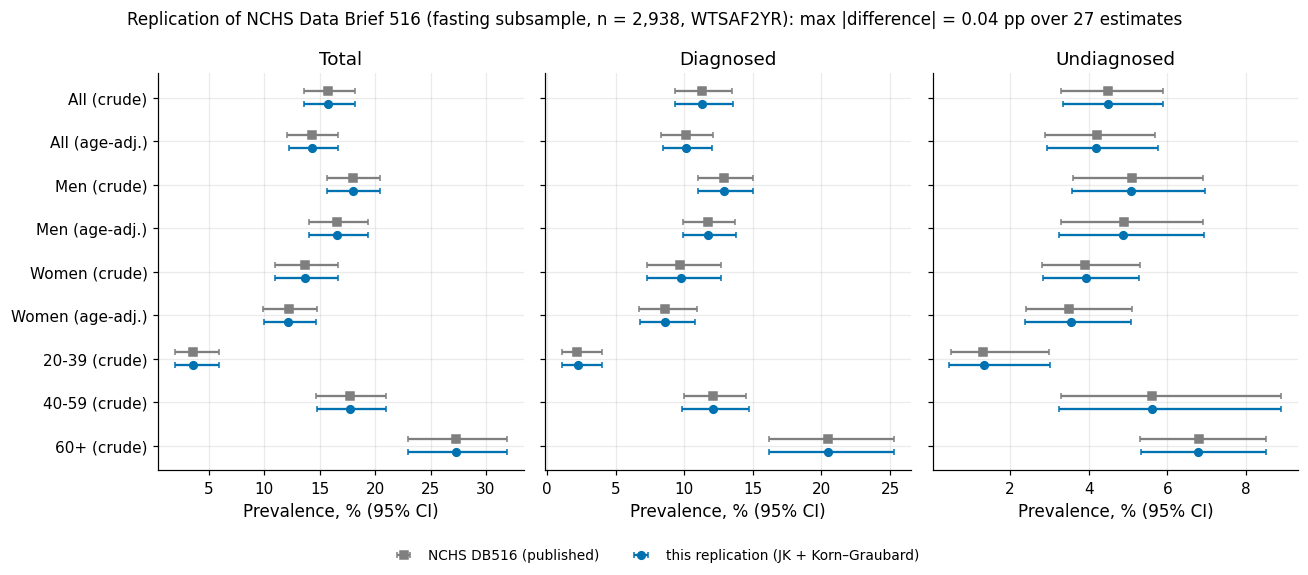

In [100]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5.2), sharey=True)
for ax, measure in zip(axes, ["total", "diagnosed", "undiagnosed"]):
    d = DB516[DB516.measure == measure].reset_index(drop=True)
    labels_ = [f"{g} ({'age-adj.' if k == 'age-adj' else 'crude'})" for g, k in zip(d.group, d.kind)]
    yy = np.arange(len(d))[::-1]
    ax.errorbar(d.nchs, yy + 0.15, xerr=[d.nchs - d.nchs_low, d.nchs_high - d.nchs], fmt="s", ms=5,
                color=C.OKABE_ITO["grey"], capsize=2, label="NCHS DB516 (published)")
    ax.errorbar(d.est, yy - 0.15, xerr=[d.est - d.kg_low, d.kg_high - d.est], fmt="o", ms=5,
                color=C.OKABE_ITO["blue"], capsize=2, label="this replication (JK + Korn–Graubard)")
    ax.set_yticks(yy, labels_)
    ax.set_title(measure.capitalize())
    ax.set_xlabel("Prevalence, % (95% CI)")
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=2, fontsize=9)
fig.suptitle(f"Replication of NCHS Data Brief 516 (fasting subsample, n = 2,938, WTSAF2YR): "
             f"max |difference| = {DB516.diff_pp.abs().max():.2f} pp over {len(DB516)} estimates", fontsize=11)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plots.savefig(fig, "S4_db516_forest",
              caption="Our design-based estimates (blue, Korn-Graubard 95% CI) against the published NCHS "
                      "Data Brief 516 values (grey) for total, diagnosed and undiagnosed diabetes, crude and "
                      "age-adjusted, overall, by sex and by age group.")
plt.show()

reg("DR-S4-01", "method", "NHANES 2021-23 has 15 strata x 2 PSUs (df = 15); every cohort row has WTPH2YR > 0; "
    "jackknife SE agrees with Taylor linearisation (ratio within 2%).",
    "results/S4/weights_map.md; §4.2", f"df = {DF_DESIGN}; JK/Taylor SE ratio {checks.ratio.min():.3f}-{checks.ratio.max():.3f}",
    "WTPH2YR for all cohort analyses and the weighted ablation; WTSAF2YR for fasting analytes and DB516; "
    "delete-one-PSU jackknife with NCHS domain df (PSUs - strata containing the domain); NCHS flags (n, n_eff < 30, "
    "KG width >= 0.30, df < 8).",
    "Unweighted analysis (describes the sample, not the population); WTMEC2YR for HbA1c (ignores blood-draw "
    "non-response); Taylor-only variance (no formula for kappa/AUC/standardised differences).",
    check_note="re-computed in §4.2")
reg("DR-S4-02", "validation", "Survey toolkit reproduces NCHS Data Brief 516 on the fasting subsample.",
    "results/S4/db516_replication.csv; figures/S4_db516_forest.png",
    f"total {head.loc[('total','crude'),'est']:.2f}% vs 15.8; diagnosed {head.loc[('diagnosed','crude'),'est']:.2f} vs 11.3; "
    f"undiagnosed {head.loc[('undiagnosed','crude'),'est']:.2f} vs 4.5; max |diff| {DB516.diff_pp.abs().max():.2f} pp over {len(DB516)} estimates",
    "Use src/survey.py (JK + KG + 3-band US 2000 standardisation) for every population number in S4-S9.",
    "Accept the toolkit on internal checks only (cannot detect wrong definitions or weights).",
    check_note="n = 2,938 equals NCHS; an n = 2,940 variant keeping 2 adults without HbA1c gives 15.78 / 11.29 / 4.48")

**So what.** All 27 published DB516 estimates (overall, by sex, by age; crude and age-adjusted) are
reproduced within 0.1 pp, with exactly NCHS's sample size of 2,938, and our Korn–Graubard intervals
coincide with the published asymmetric intervals – evidence that NCHS itself uses the KG interval
and that our cohort filter, fasting weight, jackknife and standardisation are right. The symmetric
jackknife-*t* interval for the total (13.53, 18.03) is the Wald version of the same uncertainty.
This is the external anchor for every weighted number later in the project.

## 4.4 Weighted vs unweighted prevalence
**Why.** The cohort's raw share of `L_comb` positives describes the *sample*, which over-represents
older adults. Because NCHS used a different definition (fasting glucose as well), our cohort number
is also not expected to equal DB516's 15.8 %. Both gaps need to be explained, not ignored.

In [101]:
w_ph = coh[C.WEIGHT_PHLEB].to_numpy(float)
unw = coh.L_comb.mean()
wp = S.weighted_prop(coh, "L_comb", weight=C.WEIGHT_PHLEB)
kish = S.kish_deff(w_ph)
coh["age3"] = S.age_band(coh.RIDAGEYR).to_numpy()
bands = list(S.US2000_3BAND)
share_s = coh.age3.value_counts(normalize=True).reindex(bands)
share_w = pd.Series({b: w_ph[coh.age3 == b].sum() / w_ph.sum() for b in bands})
rate_unw = coh.groupby("age3").L_comb.mean().reindex(bands)
rate_w = {b: S.weighted_prop(coh, "L_comb", weight=C.WEIGHT_PHLEB, domain=coh.age3 == b) for b in bands}
unw_age_reweighted = float((rate_unw * share_w).sum())     # sample rates, population age mix
explained = (unw - unw_age_reweighted) / (unw - wp["est"])
AGE_TAB = pd.DataFrame({"sample share": share_s, "weighted share": share_w, "unweighted rate": rate_unw,
                        "weighted rate": [rate_w[b]["est"] for b in bands],
                        "kg_low": [rate_w[b]["kg_low"] for b in bands], "kg_high": [rate_w[b]["kg_high"] for b in bands]})
print((AGE_TAB * 100).round(1))
print(f"\nL_comb unweighted {pct(unw, 2)}% vs WTPH2YR-weighted {pct(wp['est'], 2)}% "
      f"(JK {pct(wp['ci_low'])}-{pct(wp['ci_high'])}, KG {pct(wp['kg_low'])}-{pct(wp['kg_high'])}, df {wp['df']})")
print(f"sample rates re-weighted to the population age mix: {pct(unw_age_reweighted, 2)}% -> age structure explains "
      f"{100 * explained:.0f}% of the {100 * (unw - wp['est']):.2f} pp gap")
print(f"Kish deff (unequal weights) = {kish:.3f}; Kish n_eff = {S.kish_neff(w_ph):,.0f}; "
      f"full design effect for L_comb = {wp['deff']:.2f}")
assert abs(unw - 0.1695) < 5e-4 and abs(wp["est"] - 0.140) < 5e-4 and abs(kish - 1.55) < 0.01
OUT["prevalence"] = {"unweighted": unw, "weighted": wp["est"], "weighted_jk_ci": [wp["ci_low"], wp["ci_high"]],
                     "weighted_kg_ci": [wp["kg_low"], wp["kg_high"]], "kish_deff": kish, "design_deff": wp["deff"],
                     "share_60plus_sample": share_s["60+"], "share_60plus_weighted": share_w["60+"],
                     "share_20_39_sample": share_s["20-39"], "share_20_39_weighted": share_w["20-39"],
                     "unweighted_age_reweighted": unw_age_reweighted, "gap_explained_by_age": explained}

       sample share  weighted share  unweighted rate  weighted rate  kg_low  kg_high
20-39          24.7            34.8              3.7            3.5     2.6      4.8
40-59          29.2            33.8             16.6           15.3    13.4     17.5
60+            46.2            31.4             24.3           24.3    21.2     27.6

L_comb unweighted 16.95% vs WTPH2YR-weighted 14.04% (JK 12.4-15.6, KG 12.5-15.7, df 15)
sample rates re-weighted to the population age mix: 14.50% -> age structure explains 84% of the 2.91 pp gap
Kish deff (unequal weights) = 1.546; Kish n_eff = 3,707; full design effect for L_comb = 2.67


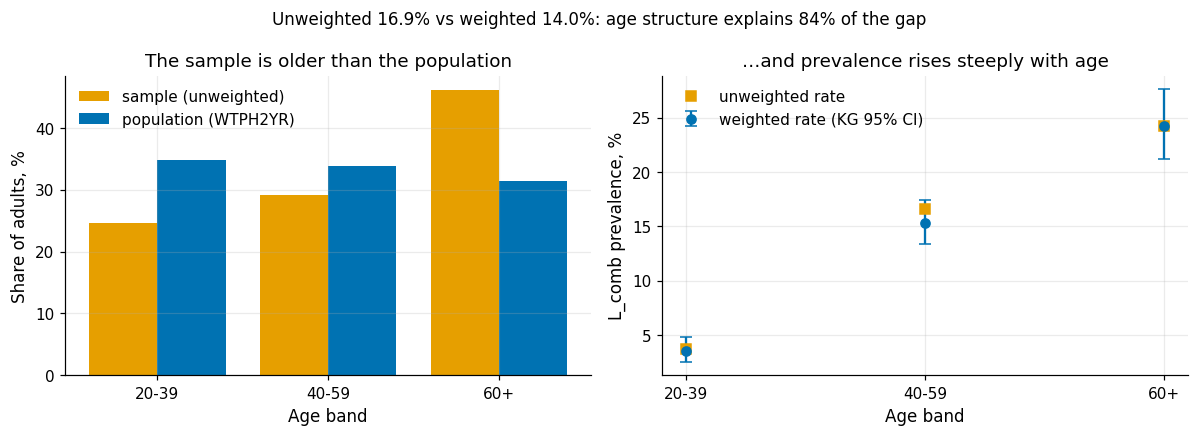

In [102]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(3)
a1.bar(x - 0.2, share_s * 100, 0.4, label="sample (unweighted)", color=C.OKABE_ITO["orange"])
a1.bar(x + 0.2, share_w * 100, 0.4, label="population (WTPH2YR)", color=C.OKABE_ITO["blue"])
a1.set_xticks(x, bands); a1.set_ylabel("Share of adults, %"); a1.set_xlabel("Age band")
a1.set_title("The sample is older than the population"); a1.legend()
yr = AGE_TAB["weighted rate"] * 100
a2.errorbar(x, yr, yerr=[yr - AGE_TAB.kg_low * 100, AGE_TAB.kg_high * 100 - yr], fmt="o", capsize=4,
            color=C.OKABE_ITO["blue"], label="weighted rate (KG 95% CI)")
a2.plot(x, AGE_TAB["unweighted rate"] * 100, "s", color=C.OKABE_ITO["orange"], label="unweighted rate")
a2.set_xticks(x, bands); a2.set_ylabel("L_comb prevalence, %"); a2.set_xlabel("Age band")
a2.set_title("…and prevalence rises steeply with age"); a2.legend()
fig.suptitle(f"Unweighted {pct(unw)}% vs weighted {pct(wp['est'])}%: age structure explains "
             f"{100 * explained:.0f}% of the gap", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S4_age_structure",
              caption="Left: age distribution of the cohort vs the weighted population. Right: L_comb prevalence "
                      "by age band (weighted with Korn-Graubard CI, and unweighted).")
plt.show()

**So what.** 46 % of the cohort is 60+ against 31 % of the population, and prevalence in that band
is about seven times that of 20–39-year-olds, so the unweighted 16.95 % overstates the population
prevalence of 14.0 % (12.4–15.6). Re-weighting the sample's own age-specific rates to the population
age mix closes most of the gap, i.e. the bias is mainly an age-structure effect. The remaining
difference to DB516's 15.8 % is definitional (our cohort label has no fasting-glucose criterion,
and uses the phlebotomy not the fasting sample) – not an error. The Kish design effect of 1.55 means
5,730 unequally weighted adults carry the information of about 3,700 equally weighted ones; the full
design effect including clustering is larger still, which is why all CIs use the jackknife. For
modelling, this motivates the weighted ablation arm (block B6) rather than silently ignoring weights.

## 4.5 Age standardisation
**Why.** Groups with different age structures cannot be compared on crude prevalence, because age
is the strongest determinant of diabetes. Direct standardisation applies each group's age-specific
rates to one common age distribution. We use the US 2000 standard population in the three NCHS
bands; the band weights are derived here from the 5-year "standard million" (Klein & Schoenborn
2001) rather than taken on trust, and a 6-band standard and an internal (cohort) standard are
sensitivity analyses.

In [103]:
# US 2000 standard population per million, 5-year groups from age 20 (Klein & Schoenborn 2001, Table 2)
US2000_5Y = {"20-24": 66478, "25-29": 64529, "30-34": 71044, "35-39": 80762, "40-44": 81851, "45-49": 72118,
             "50-54": 62716, "55-59": 48454, "60-64": 38793, "65-69": 34264, "70-74": 31773, "75-79": 26999,
             "80-84": 17842, "85+": 15508}
lo_of = {k: int(k.rstrip("+").split("-")[0]) for k in US2000_5Y}
def collapse(cuts):
    out = {}
    for lab, (lo, hi) in cuts.items():
        out[lab] = sum(v for k, v in US2000_5Y.items() if lo <= lo_of[k] <= hi)
    tot = sum(out.values())
    return {k: v / tot for k, v in out.items()}
STD3 = collapse({"20-39": (20, 39), "40-59": (40, 59), "60+": (60, 200)})
STD6 = collapse({"20-29": (20, 29), "30-39": (30, 39), "40-49": (40, 49), "50-59": (50, 59), "60-69": (60, 69), "70+": (70, 200)})
print("3-band weights derived:", {k: round(v, 4) for k, v in STD3.items()}, "| survey.US2000_3BAND:", S.US2000_3BAND)
assert all(abs(STD3[k] - S.US2000_3BAND[k]) < 1e-4 for k in STD3)
STD_INT = {b: float(share_w[b]) for b in bands}            # internal standard: the weighted cohort itself
print("6-band weights:", {k: round(v, 4) for k, v in STD6.items()})

coh["insurance"] = coh.HIQ011.map({1: "insured", 2: "uninsured"})
coh["usual_care"] = coh.HUQ030.map({1: "has usual place", 3: "has usual place", 2: "no usual place"})
std_tabs = []
for gcol in ["race", "sex", "insurance", "usual_care"]:
    t = S.age_standardise(coh, "L_comb", gcol, weight=C.WEIGHT_PHLEB)
    t.insert(0, "grouping", gcol)
    std_tabs.append(t)
STD_TAB = pd.concat(std_tabs, ignore_index=True)
STD_TAB["kg_width"] = STD_TAB.crude_kg_high - STD_TAB.crude_kg_low
_fl = [S.nchs_flags(r.n, S._design_neff(r.crude, r.crude_se, r.n), r.kg_width, r.df, p=r.crude, n_events=r.n_events)
       for r in STD_TAB.itertuples()]
STD_TAB["nchs_flags"] = [",".join(f) for f in _fl]
STD_TAB["nchs_status"] = [S.nchs_status(f) for f in _fl]
STD_TAB.to_csv(S4_DIR / "std_prev_table.csv", index=False)
show = STD_TAB[["grouping", "group", "n", "df", "crude", "crude_kg_low", "crude_kg_high", "std", "std_low", "std_high", "nchs_status"]].copy()
show[["crude", "crude_kg_low", "crude_kg_high", "std", "std_low", "std_high"]] *= 100
print(show.round(1).to_string(index=False))

3-band weights derived: {'20-39': 0.3966, '40-59': 0.3718, '60+': 0.2316} | survey.US2000_3BAND: {'20-39': 0.3966, '40-59': 0.3718, '60+': 0.2316}
6-band weights: {'20-29': 0.1837, '30-39': 0.2129, '40-49': 0.2159, '50-59': 0.1559, '60-69': 0.1024, '70+': 0.1292}


  grouping            group    n  df  crude  crude_kg_low  crude_kg_high  std  std_low  std_high nchs_status
      race Mexican American  386  14   16.9          11.1           24.1 19.6     14.6      24.6     present
      race         NH Asian  315  14   11.6           8.0           16.1 12.5      8.2      16.7     present
      race         NH Black  676  15   22.0          18.6           25.8 21.5     18.0      25.1     present
      race         NH White 3408  15   12.4          10.5           14.5 10.3      8.7      12.0     present
      race   Other Hispanic  582  15   12.8           7.8           19.4 13.5      9.5      17.6     present
      race      Other/Multi  363  15   16.6          12.6           21.2 16.0     12.1      19.8     present
       sex           Female 3144  15   13.1          10.6           15.8 11.6      9.6      13.7     present
       sex             Male 2586  15   15.0          13.5           16.7 13.9     12.4      15.5     present
 insurance         

In [104]:
CONTRASTS = [("race", "NH Asian", "NH White"), ("race", "NH Black", "NH White"),
             ("race", "Mexican American", "NH White"), ("insurance", "insured", "uninsured"),
             ("usual_care", "has usual place", "no usual place")]
diffs = []
for gcol, a, b in CONTRASTS:
    for sname, std in [("US2000 3-band", STD3), ("US2000 6-band", STD6), ("internal 3-band", STD_INT)]:
        d = S.std_difference(coh, "L_comb", gcol, a, b, weight=C.WEIGHT_PHLEB, std=std)
        diffs.append({"contrast": f"{a} − {b}", "standard": sname, "n_a": d["n_a"], "n_b": d["n_b"], "df": d["df"],
                      "crude": 100 * d["crude_diff"], "crude_low": 100 * d["crude_low"], "crude_high": 100 * d["crude_high"],
                      "std": 100 * d["std_diff"], "std_low": 100 * d["std_low"], "std_high": 100 * d["std_high"]})
DIFFS = pd.DataFrame(diffs)
DIFFS.to_csv(S4_DIR / "std_differences.csv", index=False)
print(DIFFS.round(1).to_string(index=False))

aw = DIFFS.query("contrast == 'NH Asian − NH White' and standard == 'US2000 3-band'").iloc[0]
iu = DIFFS.query("contrast == 'insured − uninsured' and standard == 'US2000 3-band'").iloc[0]
assert abs(aw.crude - (-0.8)) < 0.1 and abs(aw["std"] - 2.1) < 0.1 and abs(aw.crude_low + 5.1) < 0.1 and abs(aw.std_high - 6.8) < 0.1
assert abs(iu.crude - 5.3) < 0.1 and abs(iu["std"] - 0.7) < 0.1 and abs(iu.crude_low - 1.8) < 0.1 and abs(iu.std_high - 3.9) < 0.1
asian_std = STD_TAB.query("group == 'NH Asian'").iloc[0]; white_std = STD_TAB.query("group == 'NH White'").iloc[0]
print(f"\nNH Asian vs NH White: crude {aw.crude:+.1f} ({aw.crude_low:.1f}, {aw.crude_high:.1f}) -> "
      f"standardised {aw['std']:+.1f} ({aw.std_low:.1f}, {aw.std_high:.1f}) pp; standardised rates "
      f"{pct(asian_std['std'])}% vs {pct(white_std['std'])}% (design-phase estimate 18.0% vs 13.6% not reproducible)")
OUT["standardisation"] = {
    "std3": STD3, "std6": STD6,
    "asian_white": {"crude": aw.crude, "crude_ci": [aw.crude_low, aw.crude_high], "std": aw["std"], "std_ci": [aw.std_low, aw.std_high],
                    "std_rate_asian": 100 * asian_std["std"], "std_rate_white": 100 * white_std["std"],
                    "std6": DIFFS.query("contrast == 'NH Asian − NH White' and standard == 'US2000 6-band'")["std"].item(),
                    "internal": DIFFS.query("contrast == 'NH Asian − NH White' and standard == 'internal 3-band'")["std"].item()},
    "insured_uninsured": {"crude": iu.crude, "crude_ci": [iu.crude_low, iu.crude_high], "std": iu["std"], "std_ci": [iu.std_low, iu.std_high]}}

                        contrast        standard  n_a  n_b  df  crude  crude_low  crude_high  std  std_low  std_high
             NH Asian − NH White   US2000 3-band  315 3408  15   -0.8       -5.1         3.5  2.1     -2.6       6.8
             NH Asian − NH White   US2000 6-band  315 3408  15   -0.8       -5.1         3.5  2.3     -2.2       6.9
             NH Asian − NH White internal 3-band  315 3408  15   -0.8       -5.1         3.5  2.9     -1.7       7.5
             NH Black − NH White   US2000 3-band  676 3408  15    9.6        5.2        14.0 11.2      7.1      15.3
             NH Black − NH White   US2000 6-band  676 3408  15    9.6        5.2        14.0 10.8      6.3      15.2
             NH Black − NH White internal 3-band  676 3408  15    9.6        5.2        14.0 11.4      6.9      15.9
     Mexican American − NH White   US2000 3-band  386 3408  15    4.5       -2.4        11.3  9.3      3.6      15.0
     Mexican American − NH White   US2000 6-band  386 3408  15  

**So what.** The derived band weights match 0.3966 / 0.3718 / 0.2316 exactly, so the 3-band
standard rests on the published standard million rather than on a quoted value. NH Asian adults have a slightly *lower* crude
prevalence than NH White adults (−0.8 pp, −5.1 to 3.5) but, being much younger, a *higher*
age-standardised one (+2.1 pp, −2.6 to 6.8). Both intervals include zero and the 6-band and
internal standards tell the same story, so the honest statement is "direction flips after age
standardisation, magnitude unknown" – a demonstration of honest uncertainty, not a headline. A
design-phase estimate of 18.0 % vs 13.6 % cannot be reproduced with any of the three standards and
is withdrawn.

## 4.6 Insurance: attenuation, not reversal
**Why.** Insured adults show a clearly higher crude prevalence than uninsured adults. Before
reading this as a health-care effect we need to know how much of it is age: almost everyone
aged 65+ has Medicare, so insurance is a strong marker of age (Age → Medicare → Insurance), and
age drives diabetes.

In [105]:
ins_age = (pd.crosstab(coh.insurance, coh.age3, values=w_ph, aggfunc="sum", normalize="index") * 100).reindex(columns=bands)
print("weighted age mix by insurance status (%):\n", ins_age.round(1))
band_diff = []
for b in bands:
    d = S.std_difference(coh, "L_comb", "insurance", "insured", "uninsured", weight=C.WEIGHT_PHLEB,
                         domain=coh.age3 == b)
    band_diff.append({"age band": b, "n_insured": d["n_a"], "n_uninsured": d["n_b"],
                      "diff_pp": 100 * d["crude_diff"], "low": 100 * d["crude_low"], "high": 100 * d["crude_high"]})
band_diff = pd.DataFrame(band_diff)
print("\nage-specific insured − uninsured differences (pp):\n", band_diff.round(1).to_string(index=False))
print(f"\ninsured − uninsured: crude {iu.crude:+.1f} ({iu.crude_low:.1f}, {iu.crude_high:.1f}) -> "
      f"age-standardised {iu['std']:+.1f} ({iu.std_low:.1f}, {iu.std_high:.1f}) pp; "
      f"{100 * (1 - iu['std'] / iu.crude):.0f}% attenuation, same sign")
OUT["standardisation"]["insured_uninsured"].update({
    "attenuation_share": 1 - iu["std"] / iu.crude,
    "uninsured_share_60plus": ins_age.loc["uninsured", "60+"], "insured_share_60plus": ins_age.loc["insured", "60+"],
    "band_diffs": band_diff.to_dict("records")})

weighted age mix by insurance status (%):
 age3       20-39  40-59   60+
insurance                    
insured     33.4   33.0  33.7
uninsured   47.8   42.1  10.0

age-specific insured − uninsured differences (pp):
 age band  n_insured  n_uninsured  diff_pp   low  high
   20-39       1223          186     -0.7  -4.5   3.2
   40-59       1467          202      5.7   1.4  10.0
     60+       2557           86     -5.1 -12.9   2.8

insured − uninsured: crude +5.3 (1.8, 8.8) -> age-standardised +0.7 (-2.6, 3.9) pp; 87% attenuation, same sign


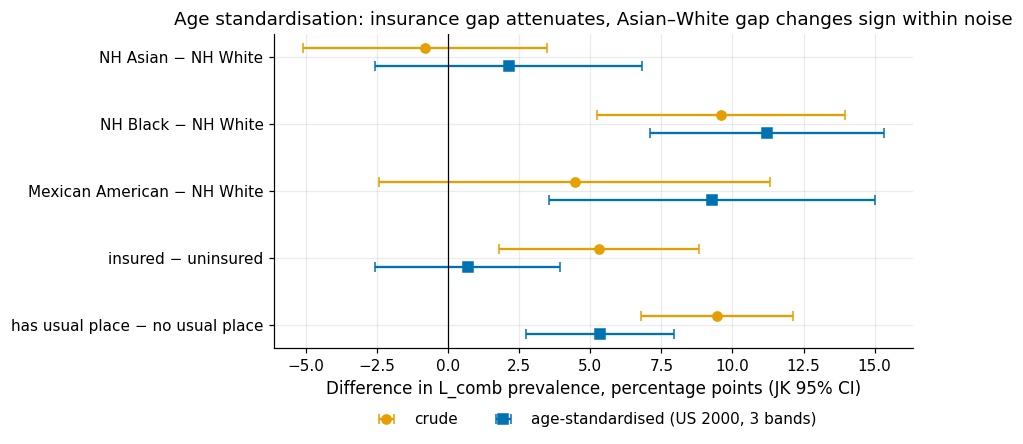

In [106]:
d3 = DIFFS[DIFFS.standard == "US2000 3-band"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
yy = np.arange(len(d3))[::-1]
ax.errorbar(d3.crude, yy + 0.13, xerr=[d3.crude - d3.crude_low, d3.crude_high - d3.crude], fmt="o", capsize=3,
            color=C.OKABE_ITO["orange"], label="crude")
ax.errorbar(d3["std"], yy - 0.13, xerr=[d3["std"] - d3.std_low, d3.std_high - d3["std"]], fmt="s", capsize=3,
            color=C.OKABE_ITO["blue"], label="age-standardised (US 2000, 3 bands)")
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(yy, d3.contrast)
ax.set_xlabel("Difference in L_comb prevalence, percentage points (JK 95% CI)")
ax.set_title("Age standardisation: insurance gap attenuates, Asian–White gap changes sign within noise")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
fig.tight_layout()
plots.savefig(fig, "S4_crude_vs_std",
              caption="Crude and age-standardised prevalence differences (WTPH2YR, jackknife 95% CI, df = 15).")
plt.show()

reg("DR-S4-03", "method", "US 2000 standard collapsed to 20-39/40-59/60+ = 0.3966/0.3718/0.2316, re-derived from the 5-year standard million.",
    "results/S4/std_prev_table.csv; §4.5", "derived weights equal survey.US2000_3BAND to 1e-4",
    "Direct age standardisation (3-band US 2000) for every between-group prevalence comparison; 6-band and internal standards as sensitivity.",
    "Crude comparisons (confounded by age); internal-only standard (not comparable with NCHS).",
    check_note="re-derived in-notebook; also validated indirectly by the DB516 age-adjusted replication")
reg("DR-S4-04", "claim_change", "NH Asian vs NH White L_comb: crude -0.8 pp (-5.1, 3.5) -> standardised +2.1 pp (-2.6, 6.8); design-phase estimate 18.0% vs 13.6% not reproducible.",
    "results/S4/std_differences.csv; figures/S4_crude_vs_std.png",
    f"crude {aw.crude:+.1f} ({aw.crude_low:.1f}, {aw.crude_high:.1f}); std {aw['std']:+.1f} ({aw.std_low:.1f}, {aw.std_high:.1f}); std rates {pct(asian_std['std'])} vs {pct(white_std['std'])}%",
    "Withdraw the design-phase 18.0/13.6 estimate; report the Asian-White contrast only as an example of honest uncertainty (both CIs include 0).",
    "Headline 'Asians have higher diabetes prevalence' (not supported by the CI).",
    check_verdict="PASS-FIX", check_note="design-phase figure withdrawn; numbers re-computed with three standards")
reg("DR-S4-05", "interpretation", "Insured - uninsured L_comb: crude +5.3 pp (1.8, 8.8) -> age-standardised +0.7 pp (-2.6, 3.9).",
    "results/S4/std_differences.csv; §4.6",
    f"crude {iu.crude:+.1f} ({iu.crude_low:.1f}, {iu.crude_high:.1f}); std {iu['std']:+.1f} ({iu.std_low:.1f}, {iu.std_high:.1f}); uninsured 60+ share {ins_age.loc['uninsured','60+']:.1f}% vs insured {ins_age.loc['insured','60+']:.1f}%",
    "Describe as age confounding (Age -> Medicare -> Insurance; Age -> diabetes) causing attenuation; never call it a reversal or Simpson's paradox.",
    "Calling it a reversal or Simpson's paradox (the sign does not flip).",
    check_verdict="PASS-FIX", check_note="wording corrected from 'reversal' to 'attenuation'")

**So what.** Only 10 % of uninsured adults are 60+, against a third of insured adults, because
Medicare covers almost everyone over 65. Standardising to the US 2000 age mix shrinks the gap from
+5.3 pp (1.8–8.8) to +0.7 pp (−2.6–3.9), an attenuation of almost 90 % with the **same sign**: this
is age confounding, not a Simpson reversal. The age-specific differences are heterogeneous
(about −1, +6 and −5 pp in the three bands, only the 40–59 one excluding zero), so no single
"insurance effect" summarises them; the 6-band standard gives a very wide interval because few
uninsured adults are 70+. By contrast, the *usual place of care* gap survives standardisation
(+9.4 → +5.3 pp, CI excluding zero) – consistent with a detection pathway (care → diagnosis →
self-reported diabetes) that S5 examines through the undiagnosed share. For modelling, access
features must be read conditional on age, and fairness comparisons across insurance groups (S8)
must control for age before attributing differences to access to care.

## 4.7 Simpson scan
**Why.** §4.5–4.6 examined two contrasts chosen in advance. A systematic scan asks the general
question: across all exposure × outcome × stratifier combinations, how often does stratification
change the *sign* of a weighted difference (Simpson's paradox) or shrink it by more than half?
The scan is exploratory and suffers from multiple comparisons, so (a) every row carries a
jackknife CI, (b) sign flips get a design-based bootstrap probability, and (c) only flips that the
DAG (§4.8) supports as de-confounding – stratifier is a confounder, not a mediator – may become
claims.

Grid (fixed before looking at the results): 9 binary exposures × 4 outcomes × 7 stratifiers, minus
the combinations where the stratifier *is* the exposure variable. Difference = exposure − reference,
WTPH2YR; standardised difference uses the pooled weighted stratum shares of the comparison domain
(internal standard). Flip: crude and standardised differences of opposite sign, both |Δ| > 1 pp.
Attenuation: same sign, |crude| > 1 pp and |standardised| < ½ |crude|.

In [107]:
r3 = coh.RIDRETH3
EXPOSURES = {   # name: (indicator with NaN outside the comparison, reference description)
    "female": (coh.sex.map({"Female": 1.0, "Male": 0.0}), "male"),
    "asian": (pd.Series(np.select([r3 == 6, r3 == 3], [1.0, 0.0], np.nan)), "NH White"),
    "black": (pd.Series(np.select([r3 == 4, r3 == 3], [1.0, 0.0], np.nan)), "NH White"),
    "hispanic": (pd.Series(np.select([r3.isin([1, 2]), r3 == 3], [1.0, 0.0], np.nan)), "NH White"),
    "uninsured": (coh.HIQ011.map({2: 1.0, 1: 0.0}), "insured"),
    "no_usual_care": (coh.HUQ030.map({2: 1.0, 1: 0.0, 3: 0.0}), "has usual place"),
    "low_income": (pd.Series(np.where(coh.INDFMPIR.isna(), np.nan, (coh.INDFMPIR < 1.3).astype(float))), "PIR >= 1.3"),
    "ever_smoker": (coh.SMQ020.map({1: 1.0, 2: 0.0}), "never smoker"),
    "low_education": (coh.DMDEDUC2.map({1: 1.0, 2: 1.0, 3: 0.0, 4: 0.0, 5: 0.0}), "high school or more"),
}
OUTCOMES = {"L_comb": coh.L_comb.astype(float), "L_A1c": coh.L_A1c.astype(float),
            "L_self": coh.L_self.astype(float), "undiagnosed (E-SCREEN)": coh.y_escreen.astype(float)}
_cut = lambda x, b, l: pd.cut(x, b, labels=l, right=False).astype(object)
STRATIFIERS = {
    "age": coh.age3.astype(object),
    "sex": coh.sex.astype(object),
    "race": coh.RIDRETH3.map({1: "Hispanic", 2: "Hispanic", 3: "White", 4: "Black", 6: "Asian", 7: "Other"}),
    "income": _cut(coh.INDFMPIR, [0, 1.3, 3.5, 99], ["<1.3", "1.3-3.5", ">=3.5"]),
    "bmi": _cut(coh.BMXBMI, [0, 25, 30, 999], ["<25", "25-30", ">=30"]),
    "insurance": coh.insurance.astype(object),
    "education": coh.DMDEDUC2.map({1: "<HS", 2: "<HS", 3: "HS", 4: ">HS", 5: ">HS"}),
}
SELF = {"female": "sex", "asian": "race", "black": "race", "hispanic": "race", "uninsured": "insurance",
        "low_income": "income", "low_education": "education"}
RACE_EXP = {"asian", "black", "hispanic"}
SES_EXP = {"uninsured", "no_usual_care", "low_income", "low_education"}


def stratifier_role(exposure, strat):
    """DAG role of the stratifier for this exposure (see §4.8)."""
    if strat == "bmi":
        return "mediator"                       # exposure -> adiposity -> BMI -> diabetes
    if strat == "age":
        return "confounder"                     # age -> exposure (Medicare, cohort, migration) and age -> diabetes
    if exposure in RACE_EXP:
        return "confounder" if strat == "sex" else "mediator"      # race -> SES/insurance -> diabetes
    if exposure in SES_EXP:
        return "confounder" if strat in ("sex", "race") else "ambiguous"   # SES siblings
    if exposure == "female":
        return "ambiguous"
    return "confounder" if strat in ("sex", "race", "income", "education", "insurance") else "ambiguous"


def scan_one(e, y, s, W):
    """Crude and internally standardised differences for every column of the weight matrix W."""
    ok = ~np.isnan(e) & ~np.isnan(y) & pd.notna(s) & (W[:, 0] > 0)
    levels = sorted(set(s[ok]))
    cols = []
    for g in (0.0, 1.0):
        for lv in levels:
            m = ok & (e == g) & (s == lv)
            cols += [m, m * np.nan_to_num(y)]
    M = np.column_stack(cols).astype(float)
    A = W.T @ M                                      # R x (2 groups * k levels * 2)
    k = len(levels)
    den = A[:, 0::2].reshape(-1, 2, k)
    num = A[:, 1::2].reshape(-1, 2, k)
    crude = num.sum(2) / den.sum(2)                  # R x 2
    share = den.sum(1) / den.sum((1, 2))[:, None]    # pooled stratum shares, R x k
    with np.errstate(invalid="ignore", divide="ignore"):
        rate = num / den
    std = (rate * share[:, None, :]).sum(2)
    min_cell = int(min(((ok & (e == g) & (s == lv)).sum()) for g in (0.0, 1.0) for lv in levels))
    return 100 * (crude[:, 1] - crude[:, 0]), 100 * (std[:, 1] - std[:, 0]), min_cell, int(ok.sum())


W_full = coh[C.WEIGHT_PHLEB].to_numpy(float)
W_jk, jk_factor = S.replicate_weights(coh, C.WEIGHT_PHLEB)
W_all = np.column_stack([W_full, W_jk])
t15 = stats.t.ppf(0.975, DF_DESIGN)
rows = []
for en, (ev, ref) in EXPOSURES.items():
    ev = ev.to_numpy(float)
    for on, yv in OUTCOMES.items():
        yv = yv.to_numpy(float)
        for sn, sv in STRATIFIERS.items():
            if SELF.get(en) == sn:
                continue
            cr, sd, min_cell, n = scan_one(ev, yv, sv.to_numpy(object), W_all)
            se_c = np.sqrt(np.sum(jk_factor * (cr[1:] - cr[0]) ** 2))
            se_s = np.sqrt(np.sum(jk_factor * (sd[1:] - sd[0]) ** 2))
            rows.append({"exposure": en, "reference": ref, "outcome": on, "stratifier": sn,
                         "role": stratifier_role(en, sn), "n": n, "min_cell": min_cell,
                         "crude": cr[0], "crude_low": cr[0] - t15 * se_c, "crude_high": cr[0] + t15 * se_c,
                         "std": sd[0], "std_low": sd[0] - t15 * se_s, "std_high": sd[0] + t15 * se_s})
SCAN = pd.DataFrame(rows)
SCAN["flip"] = (np.sign(SCAN.crude) != np.sign(SCAN["std"])) & (SCAN.crude.abs() > 1) & (SCAN["std"].abs() > 1)
SCAN["attenuation_50"] = (np.sign(SCAN.crude) == np.sign(SCAN["std"])) & (SCAN.crude.abs() > 1) & \
                         (SCAN["std"].abs() < 0.5 * SCAN.crude.abs())
SCAN["any_flip"] = np.sign(SCAN.crude) != np.sign(SCAN["std"])
n_grid = len(EXPOSURES) * len(OUTCOMES) * len(STRATIFIERS)
n_self = len(OUTCOMES) * len(SELF)
print(f"grid {len(EXPOSURES)} x {len(OUTCOMES)} x {len(STRATIFIERS)} = {n_grid}; minus {n_self} self-stratifications "
      f"-> {len(SCAN)} comparisons (smallest exposure x stratum cell: {SCAN.min_cell.min()})")
print(f"sign flips (both |d| > 1 pp): {int(SCAN.flip.sum())}; any sign change: {int(SCAN.any_flip.sum())}; "
      f"attenuation > 50 %: {int(SCAN.attenuation_50.sum())}")
print("flips by stratifier role:", SCAN[SCAN.flip].role.value_counts().to_dict())

grid 9 x 4 x 7 = 252; minus 28 self-stratifications -> 224 comparisons (smallest exposure x stratum cell: 19)
sign flips (both |d| > 1 pp): 6; any sign change: 12; attenuation > 50 %: 10
flips by stratifier role: {'mediator': 4, 'confounder': 2}


**Design-based bootstrap of the flips.** A flip of a few points can be produced by sampling noise
alone. For every flagged flip – and for the pre-specified Asian × `L_comb` × age contrast – we
repeat the scan statistic on Rao–Wu rescaled bootstrap replicates (PSU resampling within strata with
*m_h = n_h − 1*, the standard choice for two-PSU designs) and report P(crude and standardised signs
differ) and P(standardised sign equals the point estimate's sign).

In [108]:
B = C.N_BOOT
W_boot = S.rao_wu_weights(coh, C.WEIGHT_PHLEB, B, seed=int(RNG_SEEDS[0].generate_state(1)[0]))
probe = SCAN[SCAN.flip | ((SCAN.exposure == "asian") & (SCAN.outcome == "L_comb") & (SCAN.stratifier == "age"))]
boot_rows = []
for idx, r in probe.iterrows():
    ev = EXPOSURES[r.exposure][0].to_numpy(float)
    yv = OUTCOMES[r.outcome].to_numpy(float)
    sv = STRATIFIERS[r.stratifier].to_numpy(object)
    cr, sd, _, _ = scan_one(ev, yv, sv, np.column_stack([W_full, W_boot]))
    cr_b, sd_b = cr[1:], sd[1:]
    boot_rows.append({"idx": idx, "p_sign_differs": float(np.mean(np.sign(cr_b) != np.sign(sd_b))),
                      "p_std_sign_as_point": float(np.mean(np.sign(sd_b) == np.sign(r["std"]))),
                      "p_flip_rule": float(np.mean((np.sign(cr_b) != np.sign(sd_b)) & (np.abs(cr_b) > 1) & (np.abs(sd_b) > 1)))})
boot = pd.DataFrame(boot_rows).set_index("idx")
SCAN = SCAN.join(boot)
SCAN["dag_supported"] = SCAN.flip & (SCAN.role == "confounder")
SCAN.to_csv(S4_DIR / "simpson_scan.csv", index=False)
cols = ["exposure", "outcome", "stratifier", "role", "crude", "crude_low", "crude_high", "std", "std_low", "std_high",
        "p_sign_differs", "p_std_sign_as_point", "dag_supported"]
print(f"Rao-Wu bootstrap replicates: B = {B} ({C.NB_MODE} mode)")
print(SCAN.loc[probe.index, cols].round(2).to_string(index=False))
print("\nlargest attenuations (|crude| > 1 pp):")
print(SCAN[SCAN.attenuation_50].assign(ratio=lambda d: d["std"] / d.crude).sort_values("ratio")
      [["exposure", "outcome", "stratifier", "role", "crude", "std"]].round(2).head(12).to_string(index=False))

ex_ins = SCAN.query("exposure == 'uninsured' and outcome == 'L_A1c' and stratifier == 'age'").iloc[0]
ex_as = SCAN.query("exposure == 'asian' and outcome == 'L_comb' and stratifier == 'age'").iloc[0]
_aw_int = OUT["standardisation"]["asian_white"]["internal"]
print(f"Asian - White L_comb, three age standards: US 2000 {aw['std']:+.2f} pp; whole-cohort weighted age mix "
      f"{_aw_int:+.2f} pp; scan standard (pooled Asian + White age mix) {ex_as['std']:+.2f} pp")
OUT["simpson"] = {"n_comparisons": len(SCAN), "grid": [len(EXPOSURES), len(OUTCOMES), len(STRATIFIERS)],
                  "n_flips": int(SCAN.flip.sum()), "n_any_sign_change": int(SCAN.any_flip.sum()),
                  "n_attenuation_50": int(SCAN.attenuation_50.sum()), "n_boot": B, "bootstrap": "Rao-Wu rescaled, m_h = n_h - 1",
                  "flips": SCAN[SCAN.flip][cols].to_dict("records"),
                  "uninsured_A1c_age": {k: ex_ins[k] for k in ["crude", "std", "p_sign_differs", "p_std_sign_as_point"]},
                  "asian_Lcomb_age": {k: ex_as[k] for k in ["crude", "std", "p_sign_differs", "p_std_sign_as_point"]},
                  "n_dag_supported_flips": int(SCAN.dag_supported.sum())}

Rao-Wu bootstrap replicates: B = 1000 (FINAL mode)
 exposure outcome stratifier       role  crude  crude_low  crude_high   std  std_low  std_high  p_sign_differs  p_std_sign_as_point  dag_supported
    asian  L_comb        age confounder  -0.81      -5.09        3.46  3.27    -1.38      7.92            0.53                 0.92          False
    asian  L_comb        bmi   mediator  -1.32      -5.50        2.86  3.41    -3.61     10.42            0.53                 0.82          False
    asian   L_A1c        bmi   mediator  -1.27      -3.82        1.28  2.38    -1.41      6.17            0.73                 0.88          False
    asian  L_self        age confounder  -2.01      -6.37        2.35  1.44    -3.36      6.23            0.53                 0.73           True
 hispanic  L_comb  education   mediator   2.10      -3.47        7.67 -1.18    -6.74      4.38            0.37                 0.64          False
 hispanic  L_self  education   mediator   1.12      -3.27        5.

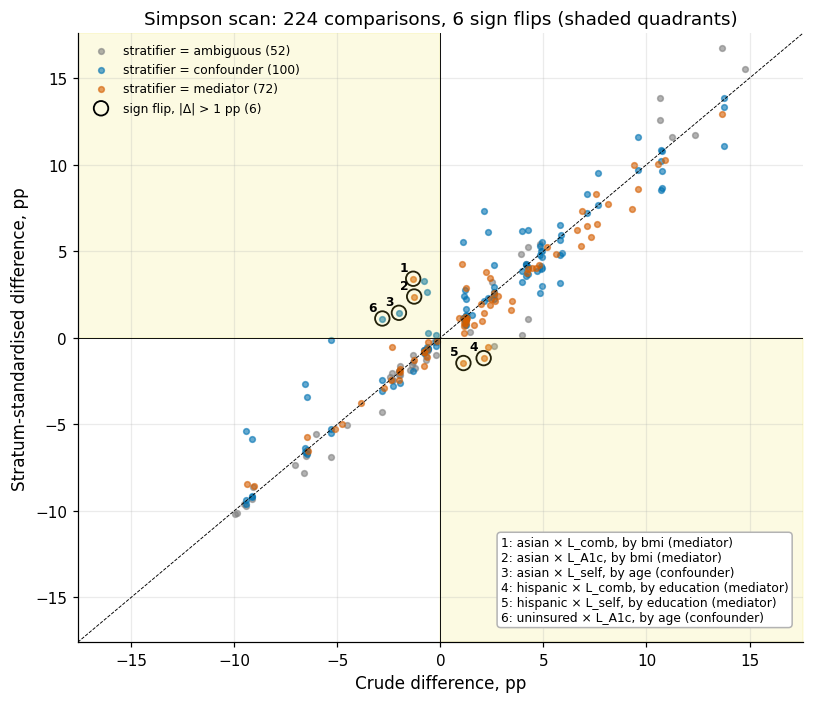

In [109]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
role_col = {"confounder": C.OKABE_ITO["blue"], "mediator": C.OKABE_ITO["vermillion"], "ambiguous": C.OKABE_ITO["grey"]}
for role, g in SCAN.groupby("role"):
    ax.scatter(g.crude, g["std"], s=14, alpha=0.6, color=role_col[role], label=f"stratifier = {role} ({len(g)})")
fl = SCAN[SCAN.flip]
ax.scatter(fl.crude, fl["std"], s=90, facecolors="none", edgecolors="k", lw=1.2, label=f"sign flip, |Δ| > 1 pp ({len(fl)})")
key = []
for i, r in enumerate(fl.itertuples(), 1):
    ax.annotate(str(i), (r.crude, r.std), fontsize=8, fontweight="bold", xytext=(-9, 5), textcoords="offset points")
    key.append(f"{i}: {r.exposure} × {r.outcome.split(' ')[0]}, by {r.stratifier} ({r.role})")
ax.text(0.98, 0.03, chr(10).join(key), transform=ax.transAxes, ha="right", va="bottom", fontsize=8, multialignment="left",
        bbox=dict(boxstyle="round", fc="white", ec="0.7"))
lim = np.nanmax(np.abs(SCAN[["crude", "std"]].to_numpy())) * 1.05
ax.plot([-lim, lim], [-lim, lim], color="k", lw=0.6, ls="--")
ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
ax.fill_between([0, lim], -lim, 0, color=C.OKABE_ITO["yellow"], alpha=0.15)
ax.fill_between([-lim, 0], 0, lim, color=C.OKABE_ITO["yellow"], alpha=0.15)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("Crude difference, pp"); ax.set_ylabel("Stratum-standardised difference, pp")
ax.set_title(f"Simpson scan: {len(SCAN)} comparisons, {len(fl)} sign flips (shaded quadrants)")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plots.savefig(fig, "S4_simpson_scan",
              caption="Crude vs stratum-standardised weighted differences for every exposure x outcome x stratifier "
                      "combination; shaded quadrants = sign change; circled = flips with both |difference| > 1 pp. "
                      "Colour = DAG role of the stratifier.")
plt.show()

reg("DR-S4-06", "interpretation",
    f"Simpson scan: {len(SCAN)} comparisons, {int(SCAN.flip.sum())} sign flips, {int(SCAN.attenuation_50.sum())} attenuations > 50%; "
    f"{int((SCAN.flip & (SCAN.role == 'mediator')).sum())} flips come from mediator stratifiers (BMI, education).",
    "results/S4/simpson_scan.csv; figures/S4_simpson_scan.png",
    f"uninsured x L_A1c | age {ex_ins.crude:+.1f} -> {ex_ins['std']:+.1f} pp, P(sign differs) = {ex_ins.p_sign_differs:.2f}; "
    f"Asian x L_comb | age P(sign differs) = {ex_as.p_sign_differs:.2f} (B = {B})",
    "Treat the scan as exploratory; promote only DAG-supported (confounder-stratified) flips with CIs; never read BMI-stratified "
    "'flips' as de-confounding (BMI is a mediator / mismeasured proxy of adiposity).",
    "Reporting all flips as findings (multiple comparisons, mediator conditioning); hiding the scan.",
    check_note=f"grid fixed before the scan: 9 x 4 x 7 = 252 minus 28 self-stratifications = {len(SCAN)} comparisons")

**So what.** Sign flips are rare (a handful out of more than two hundred comparisons) and small:
every flipped standardised difference has a jackknife CI that includes zero, and the bootstrap
puts the probability that crude and standardised signs really differ well short of certainty. Two
kinds of flips must be read differently:

* **Age-stratified flips** (uninsured × `L_A1c`, Asian × `L_self`) are DAG-supported – age is a
  confounder – and repeat the §4.5–4.6 message: younger groups look healthier until age is
  removed. They remain exploratory because their intervals cover zero.
* **BMI- and education-stratified flips** (Asian × `L_comb`/`L_A1c` | BMI, Hispanic | education)
  are *mediator artefacts*. BMI sits on the path race → adiposity → BMI → diabetes, so comparing
  Asian and White adults "at the same BMI" answers a different question – and because BMI
  under-states adiposity in Asian adults (S5), equal-BMI strata are not equal-risk strata. This is
  the measurement-bias finding of S5 seen from another angle, not de-confounding.

The Asian–White standardised difference appears with three values in this section because three
age standards are used: the US 2000 population (+2.1 pp, §4.5), the weighted age mix of the whole
cohort (+2.9 pp, §4.5 sensitivity) and, in the scan, the pooled age mix of the Asian and White
adults being compared (+3.3 pp). The older the standard population, the larger the gap, because
the Asian excess is concentrated in the older bands; all three intervals include zero.

Attenuations of more than half outnumber the flips. The largest is uninsured × `L_comb` | age
(about −5.3 → −0.1 pp): the same age-confounding mechanism as §4.6, now visible because uninsured
adults are younger. Most other attenuations involve SES "siblings" (income, education), which
partly measure the same construct and therefore also absorb each other. Because the grid was fixed
before the scan was run, the counts (224 comparisons, 6 flips) are reported as they are; with
1,000 bootstrap replicates the headline example, uninsured × `L_A1c` | age (about −2.8 → +1.1 pp),
has a sign-change probability of about 0.77, and Asian × `L_comb` | age is close to a coin flip.

## 4.8 Causal structure (DAG)
**Why.** Whether stratifying on a variable removes bias (confounder) or creates it (mediator,
collider) is not a statistical property of the data – it follows from assumptions about how the
variables are generated. Writing those assumptions down as a DAG makes them checkable: the
adjustment sets used in §4.5–4.7 and in S5 are verified with the back-door criterion
(d-separation in networkx) instead of being asserted.

In [110]:
import networkx as nx

DAG_EDGES = [
    ("U: birth cohort / migration", "Race/ancestry"), ("U: birth cohort / migration", "Age"),
    ("Age", "Medicare"), ("Medicare", "Insurance"), ("SES", "Insurance"), ("Race/ancestry", "SES"),
    ("Insurance", "UsualCare"), ("SES", "UsualCare"), ("Age", "UsualCare"), ("UsualCare", "Diagnosis"),
    ("Race/ancestry", "Adiposity"), ("Age", "Adiposity"), ("Sex", "Adiposity"), ("SES", "Adiposity"),
    ("Adiposity", "BMI (measured)"), ("Race/ancestry", "BMI (measured)"),     # body-composition: BMI-adiposity relation differs
    ("Adiposity", "Diabetes"), ("Age", "Diabetes"), ("Sex", "Diabetes"), ("Race/ancestry", "Diabetes"), ("SES", "Diabetes"),
    ("Diabetes", "Diagnosis"), ("Diagnosis", "Treatment"), ("Treatment", "HbA1c (measured)"), ("Diabetes", "HbA1c (measured)"),
    ("Diabetes", "ExamSelection"), ("SES", "ExamSelection"), ("Age", "ExamSelection"),
]
G = nx.DiGraph(DAG_EDGES)
assert nx.is_directed_acyclic_graph(G)
LATENT = {"U: birth cohort / migration", "Adiposity", "Diabetes"}      # not directly observed


def backdoor_ok(g, x, y, z):
    """Back-door criterion: Z has no descendant of X and d-separates X and Y once X's out-edges are cut."""
    z = set(z)
    if z & nx.descendants(g, x) or z & LATENT:
        return False
    g2 = g.copy()
    g2.remove_edges_from(list(g.out_edges(x)))
    return nx.is_d_separator(g2, {x}, {y}, z)


def minimal_sets(g, x, y, max_size=3):
    cand = sorted(set(g) - {x, y} - nx.descendants(g, x) - LATENT)
    found = []
    from itertools import combinations
    for k in range(0, max_size + 1):
        for z in combinations(cand, k):
            if backdoor_ok(g, x, y, z) and not any(set(f) <= set(z) for f in found):
                found.append(z)
    return found


queries = [
    ("Insurance", "Diagnosis", ["Age", "SES"], "Insurance → undiagnosed (S5)"),
    ("Insurance", "Diagnosis", ["Age"], "… age only"),
    ("Insurance", "Diagnosis", [], "… crude"),
    ("Race/ancestry", "Diabetes", ["Age", "Sex"], "Race → diabetes (§4.5)"),
    ("Race/ancestry", "Diabetes", ["Age"], "… age only"),
    ("Race/ancestry", "Diabetes", [], "… crude"),
    ("Race/ancestry", "Diabetes", ["Age", "Sex", "BMI (measured)"], "… + BMI"),
    ("Race/ancestry", "Diabetes", ["Age", "Sex", "SES"], "… + SES (mediator)"),
    ("Insurance", "Diabetes", ["Age", "SES"], "Insurance → diabetes (§4.6)"),
]
DAG_TAB = pd.DataFrame([{"question": lab, "exposure": x, "outcome": y, "adjustment set": "{" + ", ".join(z) + "}",
                         "valid (back-door)": backdoor_ok(G, x, y, z),
                         "contains descendant of exposure": bool(set(z) & nx.descendants(G, x))}
                        for x, y, z, lab in queries])
print(DAG_TAB.to_string(index=False))
ms_ins = minimal_sets(G, "Insurance", "Diagnosis")
ms_race = minimal_sets(G, "Race/ancestry", "Diabetes")
print("\nminimal sufficient sets  Insurance -> Diagnosis:", ms_ins)
print("minimal sufficient sets  Race -> Diabetes:", ms_race)
# Selection: the cohort exists only for examined adults (conditioning on a collider)
g_noses = G.copy(); g_noses.remove_edge("SES", "Diabetes"); g_noses.remove_edge("SES", "Adiposity")
indep_without = nx.is_d_separator(g_noses, {"SES"}, {"Diabetes"}, {"Race/ancestry", "Age"})
indep_given_sel = nx.is_d_separator(g_noses, {"SES"}, {"Diabetes"}, {"Race/ancestry", "Age", "ExamSelection"})
print(f"\ncollider check (SES->diabetes edges removed): SES ⟂ Diabetes | Race, Age: {indep_without}; "
      f"after also conditioning on ExamSelection: {indep_given_sel}  -> selection into the exam opens a path")
assert DAG_TAB.loc[0, "valid (back-door)"] and DAG_TAB.loc[3, "valid (back-door)"] and not DAG_TAB.loc[6, "valid (back-door)"]
DAG_TAB.to_csv(S4_DIR / "dag_adjustment_sets.csv", index=False)
OUT["dag"] = {"n_nodes": G.number_of_nodes(), "n_edges": G.number_of_edges(),
              "minimal_sets_insurance_diagnosis": [list(z) for z in ms_ins],
              "minimal_sets_race_diabetes": [list(z) for z in ms_race],
              "bmi_adjustment_valid": bool(DAG_TAB.loc[6, "valid (back-door)"]), "exam_selection_opens_path": bool(indep_without and not indep_given_sel)}

                    question      exposure   outcome             adjustment set  valid (back-door)  contains descendant of exposure
Insurance → undiagnosed (S5)     Insurance Diagnosis                 {Age, SES}               True                            False
                  … age only     Insurance Diagnosis                      {Age}              False                            False
                     … crude     Insurance Diagnosis                         {}              False                            False
      Race → diabetes (§4.5) Race/ancestry  Diabetes                 {Age, Sex}               True                            False
                  … age only Race/ancestry  Diabetes                      {Age}               True                            False
                     … crude Race/ancestry  Diabetes                         {}              False                            False
                     … + BMI Race/ancestry  Diabetes {Age, Sex, BMI (measure

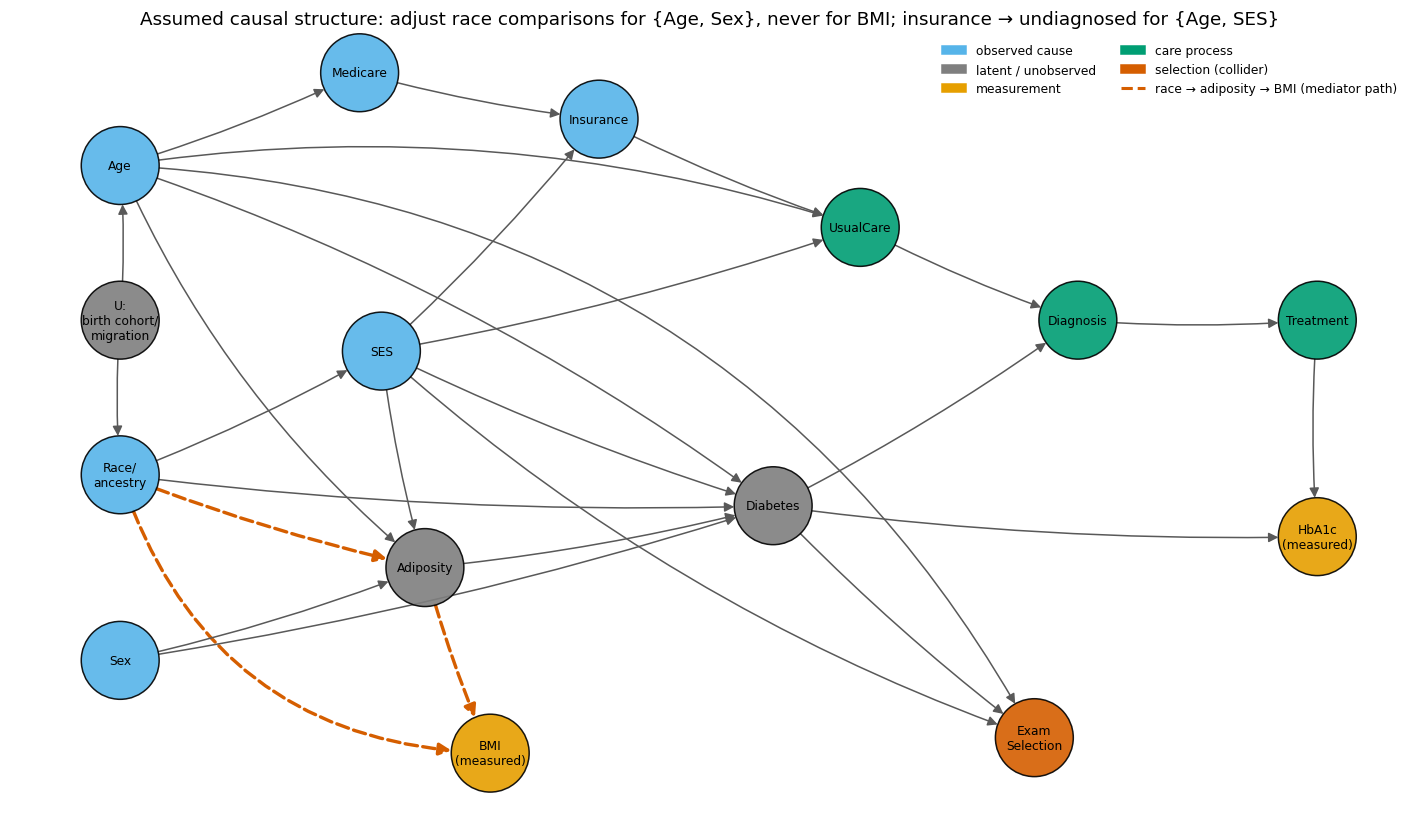

In [111]:
POS = {"Age": (0, 6.4), "U: birth cohort / migration": (0, 4.4), "Race/ancestry": (0, 2.4), "Sex": (0, 0.0),
       "Medicare": (2.2, 7.6), "Insurance": (4.4, 7.0), "UsualCare": (6.8, 5.6), "SES": (2.4, 4.0),
       "Adiposity": (2.8, 1.2), "BMI (measured)": (3.4, -1.2), "Diabetes": (6.0, 2.0), "Diagnosis": (8.8, 4.4),
       "Treatment": (11.0, 4.4), "HbA1c (measured)": (11.0, 1.6), "ExamSelection": (8.4, -1.0)}
KIND = {n: "latent" for n in LATENT} | {"BMI (measured)": "measure", "HbA1c (measured)": "measure",
                                        "ExamSelection": "selection", "Diagnosis": "process", "Treatment": "process",
                                        "UsualCare": "process"}
KCOL = {"latent": C.OKABE_ITO["grey"], "measure": C.OKABE_ITO["orange"], "selection": C.OKABE_ITO["vermillion"],
        "process": C.OKABE_ITO["green"], "observed": C.OKABE_ITO["sky"]}
fig, ax = plt.subplots(figsize=(13, 7.5))
cols_ = [KCOL[KIND.get(n, "observed")] for n in G.nodes]
nx.draw_networkx_nodes(G, POS, ax=ax, node_color=cols_, node_size=2600, alpha=0.9,
                       node_shape="o", linewidths=1, edgecolors="k")
mediator_edges = [("Race/ancestry", "Adiposity"), ("Adiposity", "BMI (measured)"), ("Race/ancestry", "BMI (measured)")]
EDGE_RAD = {("Race/ancestry", "BMI (measured)"): 0.35, ("Age", "UsualCare"): -0.12, ("Age", "Diabetes"): -0.08,
            ("Age", "ExamSelection"): -0.28, ("Age", "Adiposity"): 0.12, ("SES", "ExamSelection"): 0.10}
for e in G.edges:                                   # draw edge by edge so overlapping paths can be curved apart
    med = e in mediator_edges
    nx.draw_networkx_edges(G, POS, ax=ax, edgelist=[e], arrows=True, arrowsize=16 if med else 13, node_size=2600,
                           width=2.2 if med else 1.0, style="dashed" if med else "solid",
                           edge_color=C.OKABE_ITO["vermillion"] if med else "0.35",
                           connectionstyle=f"arc3,rad={EDGE_RAD.get(e, 0.04)}")
nx.draw_networkx_labels(G, POS, ax=ax, labels={n: n.replace(" (measured)", "\n(measured)").replace(": ", ":\n").replace(" / ", "/\n").replace("/ancestry", "/\nancestry").replace("ExamSelection", "Exam\nSelection") for n in G},
                        font_size=8)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=KCOL[k], label=lab) for k, lab in
                   [("observed", "observed cause"), ("latent", "latent / unobserved"), ("measure", "measurement"),
                    ("process", "care process"), ("selection", "selection (collider)")]] +
          [plt.Line2D([], [], color=C.OKABE_ITO["vermillion"], ls="--", lw=2, label="race → adiposity → BMI (mediator path)")],
          loc="upper right", fontsize=8, ncol=2)
ax.set_title("Assumed causal structure: adjust race comparisons for {Age, Sex}, never for BMI; insurance → undiagnosed for {Age, SES}")
ax.axis("off")
fig.tight_layout()
plots.savefig(fig, "S4_dag", caption="Directed acyclic graph of the assumed data-generating process (networkx); "
                                     "adjustment sets verified with the back-door criterion in §4.8.")
plt.show()

reg("DR-S4-07", "method", "In the DAG, BMI is a descendant of race (race -> adiposity -> BMI) and of SES; ExamSelection is a collider.",
    "figures/S4_dag.png; results/S4/dag_adjustment_sets.csv",
    f"back-door valid: race->diabetes | {{Age, Sex}} = True, + BMI = False; insurance->diagnosis | {{Age, SES}} = True; minimal sets {ms_ins}",
    "Adjust race comparisons for age (and sex) only; never present BMI-adjusted race contrasts as de-confounded; "
    "model coefficients are associations (no Table 2 fallacy).",
    "Adjusting for every available covariate (includes mediators and descendants); reading logistic coefficients causally.",
    check_note="adjustment sets verified with networkx d-separation")

**So what.** Under the stated assumptions, {Age, SES} is a sufficient adjustment set for the
insurance → undiagnosed question of S5 (age alone is not, because SES drives both insurance and
care), and {Age} or {Age, Sex} suffices for race → diabetes. Adding BMI breaks the back-door
criterion: BMI is a descendant of race through adiposity, so "BMI-adjusted" race contrasts – and the
BMI-stratified flips of §4.7 – estimate something other than the total association. The graph also
makes two structural biases explicit: the cohort exists only for people who attended the exam
(conditioning on the collider *ExamSelection* opens SES ↔ diabetes paths, only partly repaired by
the weights), and the HbA1c-based label is a descendant of *Treatment*, so conditioning on
HbA1c ≥ 6.5 (as the undiagnosed domain does) inherits the treatment-masking problem quantified in
S5. The prediction models of S7 are not causal: their coefficients are associations conditional on
everything else in the model (Westreich & Greenland's "Table 2 fallacy").

## 4.9 Redundancy and collinearity
**Why.** Several candidate features are arithmetic functions of each other (BMI = weight/height²,
WHtR = waist/height, LDL is computed from TC, HDL and triglycerides) or repeated measurements of
one quantity (three systolic and three diastolic readings). Such redundancy inflates coefficient
variance and makes coefficients uninterpretable. Variance inflation factors (VIF) quantify it; they
are read with O'Brien (2007) in mind – a high VIF is a reason to look at the structure, not an
automatic deletion rule.

In [112]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

VIF_SETS = {
    "raw_anthropometry": ["BMXWT", "BMXHT", "BMXBMI", "BMXWAIST", "BMXHIP", "BMXARMC"],
    "ht_bmi": ["BMXHT", "BMXBMI"],
    "bmi_waist": ["BMXBMI", "BMXWAIST"],
    "bp_readings": ["BPXOSY1", "BPXOSY2", "BPXOSY3", "BPXODI1", "BPXODI2", "BPXODI3"],
    "bp_means": ["bp_sys_mean", "bp_dia_mean"],
    "tier1_candidates": ["RIDAGEYR", "BMXBMI", "BMXWAIST", "bp_sys_mean", "INDFMPIR"],
    "tier2_candidates": ["RIDAGEYR", "BMXBMI", "bp_sys_mean", "LBXTC", "LBDHDD"],
}
vif_rows = []
for set_name, cols in VIF_SETS.items():
    x = coh[cols].dropna()
    X = sm.add_constant(x.to_numpy(float))
    for i, c in enumerate(cols):
        vif_rows.append({"set": set_name, "variable": c, "vif": variance_inflation_factor(X, i + 1), "n": len(x)})
VIF = pd.DataFrame(vif_rows)
VIF.to_csv(S4_DIR / "vif_table.csv", index=False)
print(VIF.pivot_table(index="variable", columns="set", values="vif", sort=False).round(1).fillna("").to_string())
print("n per set:", VIF.groupby("set", sort=False).n.first().to_dict())

VIFS = VIF.set_index(["set", "variable"]).vif
assert abs(VIFS[("raw_anthropometry", "BMXWT")] - 95.7) < 0.1 and abs(VIFS[("raw_anthropometry", "BMXBMI")] - 97.6) < 0.1
bp = VIF.query("set == 'bp_readings'").vif
assert abs(bp.min() - 8.8) < 0.1 and abs(bp.max() - 11.7) < 0.1

a = coh[["BMXBMI", "BMXWT", "BMXHT"]].dropna()
r_struct = np.corrcoef(np.log(a.BMXBMI), np.log(a.BMXWT) - 2 * np.log(a.BMXHT / 100))[0, 1]
fast_ok = coh[C.WEIGHT_FASTING].fillna(0) > 0
lip = coh.loc[fast_ok, ["LBXTC", "LBDLDL"]].dropna()
r_tc_ldl = lip.corr().iloc[0, 1]
print(f"\nstructural redundancy: corr(log BMI, log W - 2 log H) = {r_struct:.5f} (n = {len(a):,})")
print(f"TC vs LDL (fasting subsample, n = {len(lip):,}): Pearson r = {r_tc_ldl:.3f}")
OUT["vif"] = {s: {r.variable: r.vif for r in g.itertuples()} for s, g in VIF.groupby("set", sort=False)}


def prune_vif(x, protect, thresh=10.0):
    """Iteratively drop the unprotected column with the largest VIF while any VIF exceeds `thresh`."""
    cols, dropped = list(x.columns), []
    while True:
        X = sm.add_constant(x[cols].to_numpy(float))
        vifs = pd.Series([variance_inflation_factor(X, i + 1) for i in range(len(cols))], index=cols)
        cand = vifs.drop(labels=[c for c in protect if c in cols]).sort_values(ascending=False)
        if cand.empty or cand.iloc[0] <= thresh:
            return dropped, vifs
        dropped.append(cand.index[0]); cols.remove(cand.index[0])


_dropped, _vifs_after = prune_vif(coh[VIF_SETS["raw_anthropometry"]].dropna(), protect=["BMXBMI", "BMXWAIST"])
print(f"iterative VIF > 10 pruning (BMI, waist protected) on the raw anthropometry set drops {_dropped}; "
      f"remaining max VIF {_vifs_after.max():.1f} ({_vifs_after.idxmax()})")
OUT["vif_pruning_illustration"] = {"dropped": _dropped, "vif_after": _vifs_after.to_dict()}
OUT["redundancy"] = {"r_logbmi_logw_2logh": r_struct, "r_tc_ldl": r_tc_ldl, "n_tc_ldl": len(lip)}

set         raw_anthropometry ht_bmi bmi_waist bp_readings bp_means tier1_candidates tier2_candidates
variable                                                                                             
BMXWT                    95.7                                                                        
BMXHT                    21.6    1.0                                                                 
BMXBMI                   97.6    1.0       5.1                                   5.8              1.1
BMXWAIST                  7.1              5.1                                   5.9                 
BMXHIP                    7.7                                                                        
BMXARMC                   6.6                                                                        
BPXOSY1                                               10.5                                           
BPXOSY2                                               11.7                        

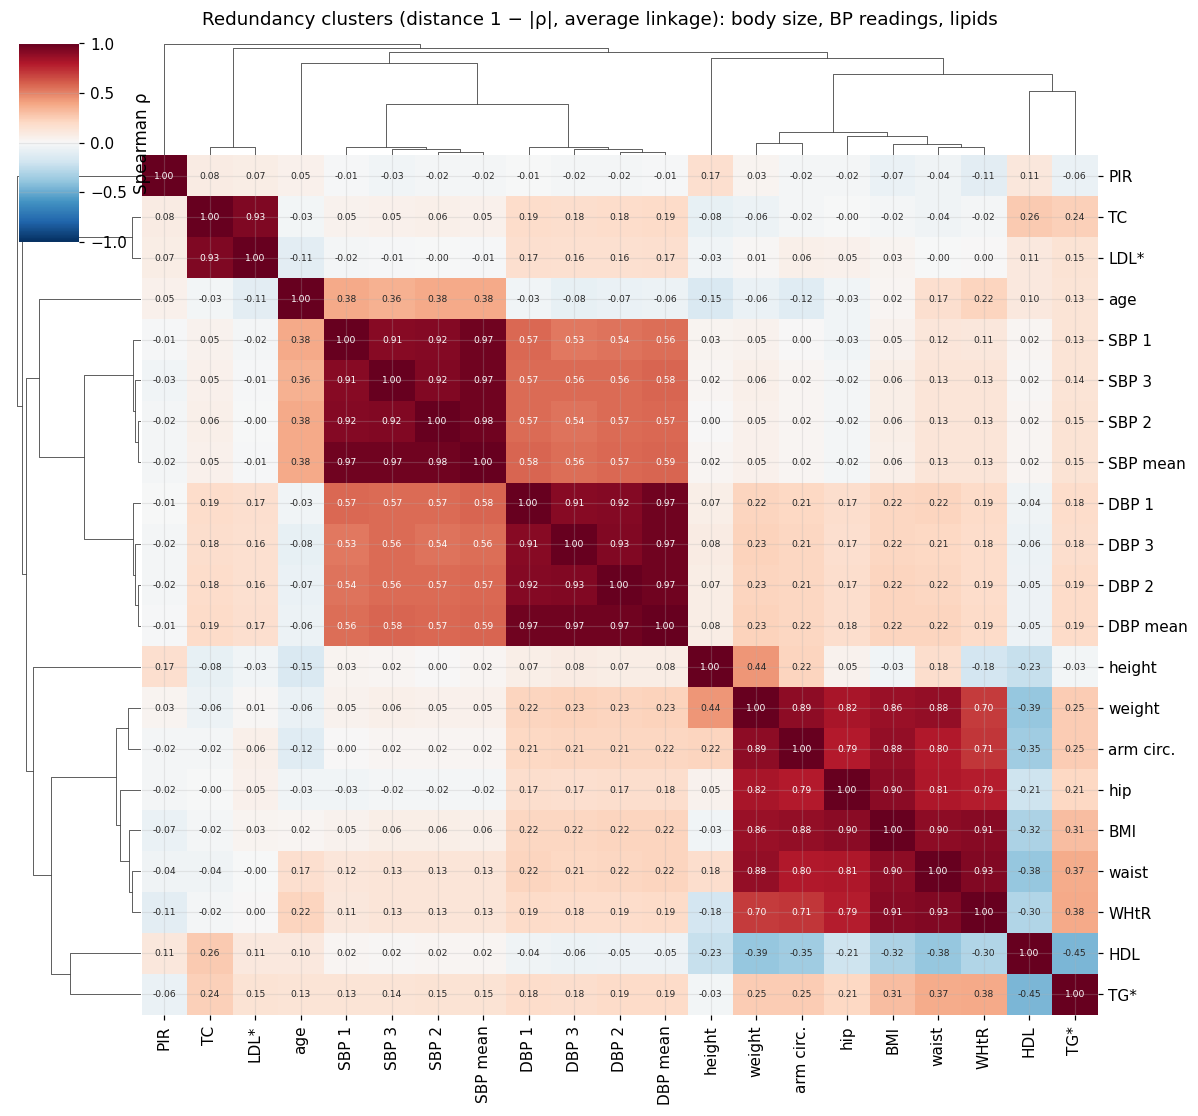

clusters with |rho| >= 0.7 (average linkage): [['TC', 'LDL*'], ['SBP 1', 'SBP 2', 'SBP 3', 'SBP mean'], ['DBP 1', 'DBP 2', 'DBP 3', 'DBP mean'], ['BMI', 'weight', 'waist', 'hip', 'arm circ.', 'WHtR']]


In [113]:
import seaborn as sns
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform

SPEAR_VARS = {"RIDAGEYR": "age", "BMXBMI": "BMI", "BMXWT": "weight", "BMXHT": "height", "BMXWAIST": "waist",
              "BMXHIP": "hip", "BMXARMC": "arm circ.", "whtr": "WHtR", "BPXOSY1": "SBP 1", "BPXOSY2": "SBP 2",
              "BPXOSY3": "SBP 3", "BPXODI1": "DBP 1", "BPXODI2": "DBP 2", "BPXODI3": "DBP 3",
              "bp_sys_mean": "SBP mean", "bp_dia_mean": "DBP mean", "LBXTC": "TC", "LBDHDD": "HDL",
              "LBDLDL": "LDL*", "LBXTLG": "TG*", "INDFMPIR": "PIR"}
sp = coh[list(SPEAR_VARS)].copy()
sp.loc[~fast_ok, ["LBDLDL", "LBXTLG"]] = np.nan                     # fasting analytes only where valid
rho = sp.rename(columns=SPEAR_VARS).corr(method="spearman")          # pairwise complete
dist = 1 - rho.abs()
link = hierarchy.linkage(squareform(dist.to_numpy(), checks=False), method="average")
cg = sns.clustermap(rho, row_linkage=link, col_linkage=link, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
                    annot=True, fmt=".2f", annot_kws={"fontsize": 6}, figsize=(11, 10),
                    cbar_kws={"label": "Spearman ρ"}, dendrogram_ratio=0.12)
cg.fig.suptitle("Redundancy clusters (distance 1 − |ρ|, average linkage): body size, BP readings, lipids", y=1.01)
plots.savefig(cg.fig, "S4_spearman_clustermap",
              caption="Clustered Spearman correlation heatmap of candidate predictors (pairwise complete; *LDL and "
                      "triglycerides on the valid fasting subsample only).")
plt.show()
clusters = pd.Series(hierarchy.fcluster(link, t=1 - 0.7, criterion="distance"), index=rho.index)
groups = [list(g.index) for _, g in clusters.groupby(clusters) if len(g) > 1]
print("clusters with |rho| >= 0.7 (average linkage):", groups)
OUT["redundancy"]["clusters_rho07"] = groups

**So what.** Weight (VIF 95.7) and BMI (97.6) are almost perfectly predictable from the other body
measurements, and the reason is structural, not statistical: log BMI is an exact linear function of
log weight and log height (correlation 0.99999). Height and BMI on their own are unrelated (VIF 1.0),
BMI and waist share variance (5.1) but measure different things (total vs central adiposity), and
the six blood-pressure readings (8.8–11.7) collapse to VIF 1.6 once replaced by their means. The
candidate Tier-1 set [age, BMI, waist, SBP, PIR] stays below 6 and the Tier-2 set [age, BMI, SBP,
TC, HDL] below 1.2. TC and LDL correlate at 0.94 because LDL is calculated from TC. Decision: use
mean SBP/DBP, exclude LDL (fasting-only and derived from TC), and remove the structural duplicates
of BMI by iterative VIF > 10 pruning inside each training fold with BMI and waist protected (on the
full anthropometry set this removes only weight, the arithmetic twin of BMI, as printed above). The
protected BMI then still has a VIF above 20 because hip and arm circumference stay in that set,
which is why L2 penalisation is the second line of defence. The clustered heatmap shows the same three redundancy blocks (body size,
blood pressure, lipids) visually.

## 4.10 Skewness
**Why.** Strong right skew lets a few extreme values dominate a linear predictor and the
penalisation. We measure skewness before and after log and Yeo–Johnson transforms. Triglycerides
are a fasting analyte: they are only valid where the fasting weight is positive (8–24 h fast).

In [114]:
SKEW_VARS = [("BMXBMI", "BMI"), ("bp_sys_mean", "SBP mean"), ("LBDHDD", "HDL"), ("BMXWAIST", "waist"),
             ("LBXTC", "total cholesterol"), ("INDFMPIR", "PIR")]
skew_rows = []
def _skew_row(x, var, label, subsample):
    x = x.dropna().astype(float)
    yj, lam = stats.yeojohnson(x)
    return {"variable": var, "label": label, "subsample": subsample, "n": len(x), "skew_raw": stats.skew(x),
            "skew_log": stats.skew(np.log(x)) if (x > 0).all() else np.nan, "skew_yj": stats.skew(yj), "yj_lambda": lam}
for var, label in SKEW_VARS:
    skew_rows.append(_skew_row(coh[var], var, label, "cohort"))
skew_rows.append(_skew_row(coh.loc[fast_ok, "LBXTLG"], "LBXTLG", "triglycerides", "fasting (WTSAF2YR > 0)"))
skew_rows.append(_skew_row(coh["LBXTLG"], "LBXTLG", "triglycerides", "all with a value (incl. WTSAF2YR = 0)"))
SKEW = pd.DataFrame(skew_rows)
SKEW.to_csv(S4_DIR / "skew_table.csv", index=False)
print(SKEW.round(2).to_string(index=False))
sk = SKEW.set_index(["variable", "subsample"])
assert abs(sk.loc[("BMXBMI", "cohort"), "skew_raw"] - 1.22) < 0.01 and abs(sk.loc[("BMXBMI", "cohort"), "skew_yj"]) < 0.01
tg_f, tg_all = sk.loc[("LBXTLG", "fasting (WTSAF2YR > 0)")], sk.loc[("LBXTLG", "all with a value (incl. WTSAF2YR = 0)")]
print(f"\ntriglycerides: valid fasting n = {tg_f.n:,}, skew {tg_f.skew_raw:.2f} -> log {tg_f.skew_log:.2f}; "
      f"including {tg_all.n - tg_f.n} non-fasting rows: skew {tg_all.skew_raw:.2f} -> log {tg_all.skew_log:.2f}")
_raw_w = io.read_xpt("GLU_L")[C.WEIGHT_FASTING]          # unfixed transport-file read
_tiny = _raw_w[(_raw_w > 0) & (_raw_w < C.XPT_ZERO_EPS)]
print(f"unfixed GLU_L read: {len(_tiny)} fasting weights stored as 0 appear as {_tiny.max():.1e} and pass a '> 0' filter")
OUT["skew_tg_unfixed_zero_weights"] = {"n": len(_tiny), "value": float(_tiny.max()) if len(_tiny) else None}
OUT["skew"] = {f"{r.variable}|{r.subsample}": {"n": r.n, "raw": r.skew_raw, "log": r.skew_log, "yj": r.skew_yj,
                                               "lambda": r.yj_lambda} for r in SKEW.itertuples()}

reg("DR-S4-08", "preparation", "Structural redundancy: weight VIF 95.7, BMI 97.6 (BMI = W/H^2, r = 0.99999); six BP readings VIF 8.8-11.7; TC-LDL r = 0.94.",
    "results/S4/vif_table.csv; figures/S4_spearman_clustermap.png",
    f"BP means VIF {VIFS[('bp_means', 'bp_sys_mean')]:.1f}; Tier-1 max VIF {VIF[VIF.set == 'tier1_candidates'].vif.max():.1f}; "
    f"Tier-2 max {VIF[VIF.set == 'tier2_candidates'].vif.max():.1f}",
    "Average BP readings; exclude LDL; prune structural duplicates of BMI inside the training folds (iterative VIF > 10, BMI and waist protected; "
    "removes weight); keep BMI + waist (or WHtR, S8) under L2.",
    "Unprotected VIF deletion (O'Brien 2007: VIF alone is not a reason to drop BMI or waist); PCA of body measures (destroys interpretability).",
    check_note="VIFs re-computed; n = 5,388 for the raw anthropometry set")
reg("DR-S4-09", "preparation", "Right skew: BMI 1.22, SBP 0.93, HDL 1.08; triglycerides 6.62 on the valid fasting subsample.",
    "results/S4/skew_table.csv",
    f"BMI 1.22 -> log {sk.loc[('BMXBMI','cohort'),'skew_log']:.2f} -> YJ {sk.loc[('BMXBMI','cohort'),'skew_yj']:.2f}; TG {tg_f.skew_raw:.2f} (n {tg_f.n}) vs {tg_all.skew_raw:.2f} incl. non-fasting",
    "Offer Yeo-Johnson as a toggleable step fitted inside training folds only; the S7 ablation decides; triglycerides are not a T1/T2 feature.",
    "Transform on the full data before splitting (leakage of lambda); log for variables that can be 0 (PIR).",
    check_verdict="PASS-FIX", check_note="valid fasting value 6.62; including the 235 rows with WTSAF2YR = 0 would give 6.23")

   variable             label                             subsample    n  skew_raw  skew_log  skew_yj  yj_lambda
     BMXBMI               BMI                                cohort 5649      1.22      0.42    -0.00      -0.65
bp_sys_mean          SBP mean                                cohort 5550      0.93      0.38    -0.01      -0.79
     LBDHDD               HDL                                cohort 5459      1.08      0.21     0.00      -0.29
   BMXWAIST             waist                                cohort 5470      0.58      0.12     0.00      -0.27
      LBXTC total cholesterol                                cohort 5459      0.54     -0.25     0.01       0.32
   INDFMPIR               PIR                                cohort 4996     -0.07       NaN    -0.17       0.77
     LBXTLG     triglycerides                fasting (WTSAF2YR > 0) 2820      6.62      0.60    -0.01      -0.35
     LBXTLG     triglycerides all with a value (incl. WTSAF2YR = 0) 3055      6.23      0.57    

**So what.** BMI, SBP and HDL are moderately right-skewed (≈ 0.9–1.2); a log transform removes most
of it and Yeo–Johnson removes all of it (BMI λ ≈ −0.65). Total cholesterol and waist are nearly
symmetric. Triglycerides are extremely skewed (≈ 6.6 on the 2,820 valid fasting adults). Without
the fasting-weight restriction the value would be 6.23: in the cohort that restriction removes 235
people whose fast fell outside 8–24 h (`WTSAF2YR = 0`), and their values are not valid fasting
measurements. The trap is easy to fall into because of the transport-file artefact shown above: in
an unfixed read, a fasting weight stored as 0 appears as a tiny positive number and passes a `> 0`
filter. Because logistic regression is not distributional, skewness
matters only through leverage; the transform is therefore a toggleable preparation step whose λ is
fitted inside the training folds, and whether it helps is decided by the S7 ablation, not here.

## 4.11 Linearity
**Why.** A plain logistic regression assumes each continuous predictor acts linearly on the
log-odds. If that is wrong, the model under-fits exactly where risk changes fastest. We test it with
restricted cubic splines (Harrell): each variable gets a 4-knot RCS (knots at the 5/35/65/95th
percentiles, 2 extra df) and a likelihood-ratio test against the linear term, with the other six
continuous predictors linear and sex adjusted; complete cases for all seven variables, outcome
`L_comb`, unweighted (a model-structure question, not a population estimate).

In [115]:
import statsmodels.formula.api as smf

LIN_VARS = {"RIDAGEYR": "age", "BMXBMI": "BMI", "BMXWAIST": "waist", "bp_sys_mean": "SBP (mean)",
            "LBDHDD": "HDL", "LBXTC": "total cholesterol", "INDFMPIR": "PIR"}


def rcs_basis(x, q=(0.05, 0.35, 0.65, 0.95)):
    """Harrell restricted cubic spline basis (linear term + k-2 non-linear terms), knots at quantiles."""
    x = np.asarray(x, float)
    t = np.quantile(x, q)
    k = len(t)
    p3 = lambda u: np.maximum(u, 0) ** 3
    nl = [(p3(x - t[j]) - p3(x - t[k - 2]) * (t[k - 1] - t[j]) / (t[k - 1] - t[k - 2])
           + p3(x - t[k - 1]) * (t[k - 2] - t[j]) / (t[k - 1] - t[k - 2])) / (t[k - 1] - t[0]) ** 2 for j in range(k - 2)]
    return np.column_stack([x] + nl), t


lin = coh.dropna(subset=list(LIN_VARS)).reset_index(drop=True)
lin["female"] = (lin.sex == "Female").astype(float)
y_lin = lin.L_comb.to_numpy(float)
fit_logit = lambda X: sm.Logit(y_lin, sm.add_constant(X)).fit(disp=0)
lin_rows = []
for v, lab in LIN_VARS.items():
    others = lin[[o for o in LIN_VARS if o != v] + ["female"]].to_numpy(float)
    basis, knots = rcs_basis(lin[v])
    m_lin = fit_logit(np.column_stack([basis[:, :1], others]))
    m_rcs = fit_logit(np.column_stack([basis, others]))
    chi2 = 2 * (m_rcs.llf - m_lin.llf)
    dfree = basis.shape[1] - 1
    lin_rows.append({"variable": v, "label": lab, "n": len(lin), "n_events": int(y_lin.sum()), "chi2": chi2, "df": dfree,
                     "p": stats.chi2.sf(chi2, dfree), "knots": np.round(knots, 1).tolist()})
LIN = pd.DataFrame(lin_rows)
LIN["nonlinear"] = LIN.p < 0.05
LIN.to_csv(S4_DIR / "linearity_tests.csv", index=False)
print(LIN.assign(p=LIN.p.map(lambda p: f"{p:.2g}")).round(2).to_string(index=False))
expected = {"RIDAGEYR": 57.6, "BMXBMI": 11.6, "BMXWAIST": 7.1, "bp_sys_mean": 5.9, "LBDHDD": 18.5, "LBXTC": 41.8, "INDFMPIR": 0.8}
assert len(lin) == 4478 and all(abs(LIN.set_index("variable").chi2[k] - e) < 0.1 for k, e in expected.items())
OUT["linearity"] = {r.variable: {"label": r.label, "chi2": r.chi2, "df": r.df, "p": r.p} for r in LIN.itertuples()}
OUT["linearity_n"] = {"n": len(lin), "events": int(y_lin.sum())}

   variable             label    n  n_events  chi2  df       p                        knots  nonlinear
   RIDAGEYR               age 4478       722 57.61   2 3.1e-13     [25.0, 47.0, 63.0, 79.0]       True
     BMXBMI               BMI 4478       722 11.56   2  0.0031     [20.5, 26.2, 31.1, 42.6]       True
   BMXWAIST             waist 4478       722  7.05   2   0.029   [76.4, 93.3, 106.5, 130.9]       True
bp_sys_mean        SBP (mean) 4478       722  5.87   2   0.053  [98.3, 114.3, 127.0, 154.4]      False
     LBDHDD               HDL 4478       722 18.47   2 9.8e-05     [35.0, 48.0, 58.0, 82.0]       True
      LBXTC total cholesterol 4478       722 41.77   2 8.5e-10 [125.0, 171.0, 202.0, 260.1]       True
   INDFMPIR               PIR 4478       722  0.83   2    0.66         [0.5, 2.1, 4.1, 5.0]      False


**Binned empirical log-odds.** The test says *whether* a curve is needed; the binned plot shows
*what shape* it has. Points are the observed log-odds in deciles (95 % CI); lines are univariable
linear and RCS logistic fits.

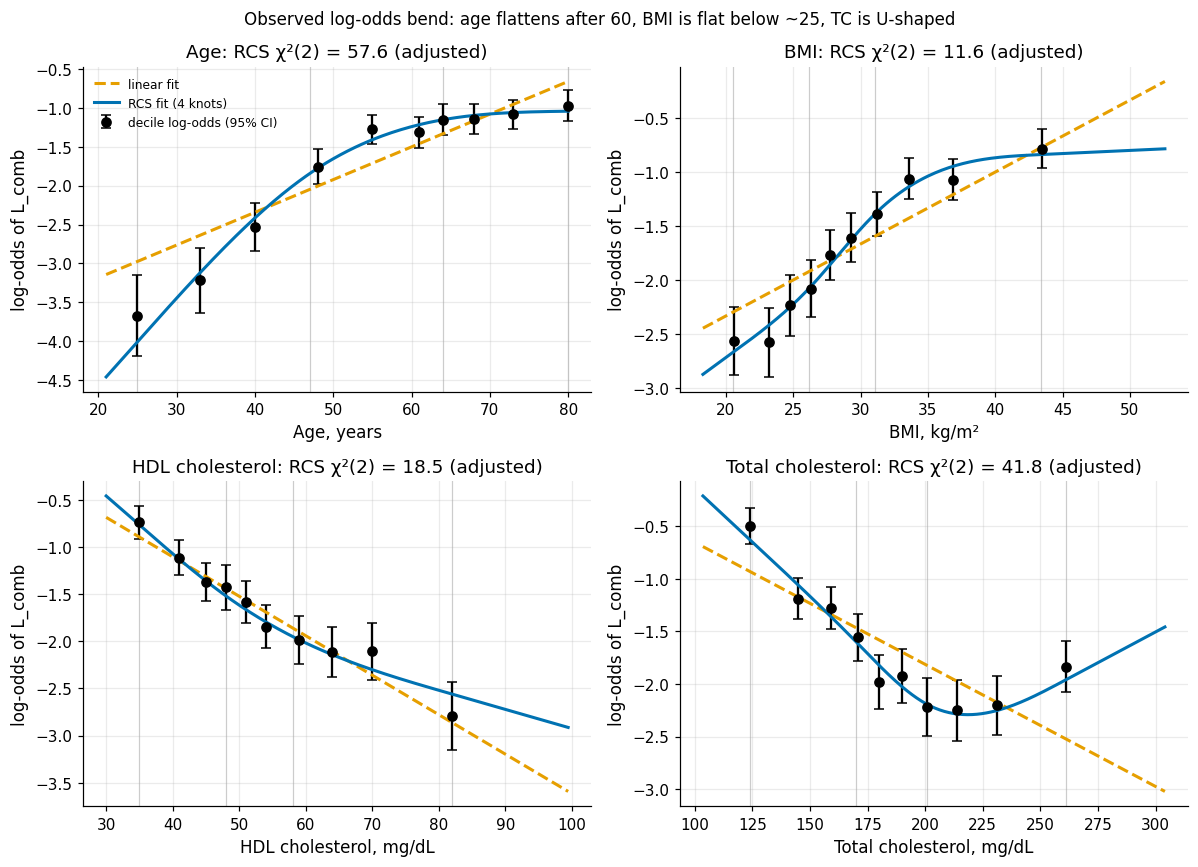

BMI deciles (median, log-odds): [(20.6, -2.56), (23.2, -2.57), (24.8, -2.23), (26.3, -2.08), (27.7, -1.76), (29.3, -1.61), (31.2, -1.39), (33.6, -1.06), (36.9, -1.07), (43.5, -0.78)]
age deciles (median, log-odds): [(25.0, -3.67), (33.0, -3.22), (40.0, -2.53), (48.0, -1.76), (55.0, -1.28), (61.0, -1.32), (64.0, -1.15), (68.0, -1.14), (73.0, -1.09), (80.0, -0.97)]


In [116]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
binned = {}
for ax, (v, lab) in zip(axes.ravel(), [("RIDAGEYR", "Age, years"), ("BMXBMI", "BMI, kg/m²"),
                                       ("LBDHDD", "HDL cholesterol, mg/dL"), ("LBXTC", "Total cholesterol, mg/dL")]):
    d = coh[[v, "L_comb"]].dropna()
    d["bin"] = pd.qcut(d[v], 10, duplicates="drop")
    g = d.groupby("bin", observed=True).agg(x=(v, "median"), n=("L_comb", "size"), k=("L_comb", "sum"))
    pr = (g.k + 0.5) / (g.n + 1)
    lo_ = np.log(pr / (1 - pr)); se = np.sqrt(1 / (g.k + 0.5) + 1 / (g.n - g.k + 0.5))
    ax.errorbar(g.x, lo_, yerr=1.96 * se, fmt="o", color="k", capsize=3, label="decile log-odds (95% CI)")
    grid = np.linspace(d[v].quantile(0.01), d[v].quantile(0.99), 200)
    Bx, kn = rcs_basis(d[v])
    m_r = sm.Logit(d.L_comb.to_numpy(float), sm.add_constant(Bx)).fit(disp=0)
    p3 = lambda u: np.maximum(u, 0) ** 3
    k_ = len(kn)
    Bg = np.column_stack([grid] + [(p3(grid - kn[j]) - p3(grid - kn[k_ - 2]) * (kn[k_ - 1] - kn[j]) / (kn[k_ - 1] - kn[k_ - 2])
                                    + p3(grid - kn[k_ - 1]) * (kn[k_ - 2] - kn[j]) / (kn[k_ - 1] - kn[k_ - 2])) / (kn[k_ - 1] - kn[0]) ** 2
                                   for j in range(k_ - 2)])
    m_l = sm.Logit(d.L_comb.to_numpy(float), sm.add_constant(d[[v]].to_numpy(float))).fit(disp=0)
    ax.plot(grid, m_l.params[0] + m_l.params[1] * grid, color=C.OKABE_ITO["orange"], lw=2, ls="--", label="linear fit")
    ax.plot(grid, sm.add_constant(Bg) @ m_r.params, color=C.OKABE_ITO["blue"], lw=2, label="RCS fit (4 knots)")
    for kv in kn:
        ax.axvline(kv, color="0.8", lw=0.8, zorder=0)
    ax.set_xlabel(lab); ax.set_ylabel("log-odds of L_comb")
    ax.set_title(f"{lab.split(',')[0]}: RCS χ²(2) = {LIN.set_index('variable').chi2[v]:.1f} (adjusted)")
    binned[v] = pd.DataFrame({"median": g.x.to_numpy(), "logodds": lo_.to_numpy(), "n": g.n.to_numpy()})
axes[0, 0].legend(fontsize=8)
fig.suptitle("Observed log-odds bend: age flattens after 60, BMI is flat below ~25, TC is U-shaped", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S4_binned_logodds", caption="Decile-binned empirical log-odds of L_comb (unweighted, 95% CI) with "
                                                "univariable linear and 4-knot restricted cubic spline fits; grey lines = knots.")
plt.show()
bmi_b = binned["BMXBMI"]; age_b = binned["RIDAGEYR"]
print("BMI deciles (median, log-odds):", [(round(a, 1), round(b, 2)) for a, b in zip(bmi_b["median"], bmi_b.logodds)])
print("age deciles (median, log-odds):", [(round(a, 0), round(b, 2)) for a, b in zip(age_b["median"], age_b.logodds)])
OUT["binned_logodds"] = {lab: df_.to_dict("list") for lab, df_ in binned.items()}

**So what.** Five of the seven continuous predictors depart from linearity on the log-odds scale:
age (χ² ≈ 57.6), total cholesterol (≈ 41.8), HDL (≈ 18.5), BMI (≈ 11.6) and waist (≈ 7.1); SBP is
borderline (p ≈ 0.05) and PIR is linear (p ≈ 0.7). The shapes are monotone-but-curved for age (risk
rises steeply to about 60, then flattens) and BMI (log-odds about −2.6 in the two lowest deciles,
i.e. flat below about 24, then rising and levelling off above about 35), while
total cholesterol is U-shaped – the low end most plausibly reflects statin treatment *after*
diagnosis (reverse causation), a warning for interpreting any Tier-2 coefficient. Consequence: the
main model is an L2 logistic regression with cubic B-splines (`SplineTransformer`, 4 quantile knots,
linear extrapolation – the `C.SPLINE_KW` configuration) on continuous predictors, with a linear arm
kept as an ablation.

## 4.12 Interactions and power
**Why.** If the BMI–diabetes slope differed by race (as the S5 measurement-bias finding suggests it
might for Asian adults), the model would need an interaction term. A non-significant test is only
informative together with its power, so we also report the minimum detectable effect (MDE, 80 %
power, two-sided α = 0.05) and repeat the tests under three model specifications (`C(...)` is avoided
in the formulas because `C` is the project config module here; race is an unordered categorical with
NH White as reference).

In [117]:
inter = lin.rename(columns={"RIDAGEYR": "age", "BMXBMI": "bmi", "BMXWAIST": "waist", "bp_sys_mean": "sbp",
                            "LBDHDD": "hdl", "LBXTC": "tc", "INDFMPIR": "pir"}).copy()
inter["race6"] = pd.Categorical(inter.race.astype(str), categories=list(io.RACE_ORDER))   # NH White = reference
inter["asian"] = (inter.race == "NH Asian").astype(float)
for v in ["age", "bmi"]:
    Bv, _ = rcs_basis(inter[v]); inter[f"{v}_s1"], inter[f"{v}_s2"] = Bv[:, 1], Bv[:, 2]
bmi_cc = coh.dropna(subset=["BMXBMI"]).rename(columns={"RIDAGEYR": "age", "BMXBMI": "bmi"}).copy()
bmi_cc["female"] = (bmi_cc.sex == "Female").astype(float)
bmi_cc["race6"] = pd.Categorical(bmi_cc.race.astype(str), categories=list(io.RACE_ORDER))
bmi_cc["asian"] = (bmi_cc.race == "NH Asian").astype(float)
SPECS = {
    "A_primary": (inter, "age + female + race6 + bmi + waist + sbp + hdl + tc + pir"),
    "B_minimal": (bmi_cc, "age + female + race6 + bmi"),
    "C_splines": (inter, "age + age_s1 + age_s2 + bmi + bmi_s1 + bmi_s2 + female + race6"),
}
TERMS = {"race_x_bmi": "race6:bmi", "asian_x_bmi": "asian:bmi", "age_x_bmi": "age:bmi",
         "sex_x_bmi": "female:bmi"}
z80 = stats.norm.ppf(0.975) + stats.norm.ppf(0.80)
int_rows = []
for spec, (d, base) in SPECS.items():
    m0 = smf.logit(f"L_comb ~ {base}", d).fit(disp=0)
    for term, expr in TERMS.items():
        m1 = smf.logit(f"L_comb ~ {base} + {expr}", d).fit(disp=0)
        chi2 = 2 * (m1.llf - m0.llf); k = int(m1.df_model - m0.df_model)
        mde = np.nan
        if k == 1:
            name = [p for p in m1.params.index if p not in m0.params.index][0]
            mde = z80 * m1.bse[name] * 5                     # log-OR difference per 5 kg/m² BMI (per year x 5 for age)
        int_rows.append({"term": term, "spec": spec, "n": int(m1.nobs), "chi2": chi2, "df": k,
                         "p": stats.chi2.sf(chi2, k), "mde": mde})
INT = pd.DataFrame(int_rows)
INT["verdict"] = np.where(INT.p < 0.05, "detected", "not detected")
INT.to_csv(S4_DIR / "interaction_tests.csv", index=False)
print(INT.pivot(index="term", columns="spec", values="p").round(3).to_string())
prim = INT[INT.spec == "A_primary"].set_index("term")
mde_asian = prim.loc["asian_x_bmi", "mde"]
print(f"\nprimary spec (n = {int(prim.n.iloc[0]):,}): race x BMI chi2({int(prim.loc['race_x_bmi','df'])}) = "
      f"{prim.loc['race_x_bmi','chi2']:.2f}, p = {prim.loc['race_x_bmi','p']:.2f}; Asian x BMI p = {prim.loc['asian_x_bmi','p']:.2f}; "
      f"age x BMI p = {prim.loc['age_x_bmi','p']:.2f}; sex x BMI p = {prim.loc['sex_x_bmi','p']:.3f}")
print(f"MDE (80% power) for the Asian x BMI slope difference: {mde_asian:.2f} log-OR per 5 kg/m² "
      f"(odds-ratio multiplier {np.exp(mde_asian):.2f} per 5 kg/m²)")
race_p_range = (INT[INT.term == "race_x_bmi"].p.min(), INT[INT.term == "race_x_bmi"].p.max())
sex_p_range = (INT[INT.term == "sex_x_bmi"].p.min(), INT[INT.term == "sex_x_bmi"].p.max())
assert race_p_range[0] > 0.05 and INT[INT.term == "asian_x_bmi"].p.min() > 0.05
OUT["interactions"] = {r.term: {"chi2": r.chi2, "df": r.df, "p": r.p, "mde": r.mde} for r in prim.reset_index().itertuples()}
OUT["interactions_by_spec"] = INT.to_dict("records")

reg("DR-S4-10", "model", "Non-linearity: RCS LR chi2(2) age 57.6, TC 41.8, HDL 18.5, BMI 11.6, waist 7.1 (p < 0.05); SBP 5.9 (p 0.053); PIR 0.8.",
    "results/S4/linearity_tests.csv; figures/S4_binned_logodds.png",
    f"n = {len(lin):,}, events {int(y_lin.sum())}",
    "Main model: L2 logistic regression with SplineTransformer(n_knots=4, degree=3, knots='quantile', extrapolation='linear') on continuous features; linear arm as ablation.",
    "Plain linear logit (misses curvature); fixed-cut categorisation (loses information, arbitrary cut-points); GAM/boosting (outside HR3).")
reg("DR-S4-11", "model", "Interactions with BMI not detectable: race x BMI and Asian x BMI non-significant under all three specifications.",
    "results/S4/interaction_tests.csv",
    f"primary: race x BMI p = {prim.loc['race_x_bmi','p']:.2f}, Asian x BMI p = {prim.loc['asian_x_bmi','p']:.2f}; MDE Asian x BMI {mde_asian:.2f} log-OR per 5 kg/m²; "
    f"sex x BMI p range {sex_p_range[0]:.3f}-{sex_p_range[1]:.2f} (specification-dependent)",
    "No interaction terms in the main model ('not detectable, underpowered', not 'absent'); the Asian BMI problem is addressed as measurement (WHtR, S5/S8), not by an interaction.",
    "Adding race x BMI terms (cost variance, power too low to estimate them); claiming no interaction exists.",
    check_note="three specifications compared; conclusions for race terms hold in every one, sex x BMI is specification-dependent")

spec         A_primary  B_minimal  C_splines
term                                        
age_x_bmi        0.445      0.435      0.050
asian_x_bmi      0.933      0.945      0.789
race_x_bmi       0.393      0.393      0.172
sex_x_bmi        0.008      0.833      0.072

primary spec (n = 4,478): race x BMI chi2(5) = 5.19, p = 0.39; Asian x BMI p = 0.93; age x BMI p = 0.45; sex x BMI p = 0.008
MDE (80% power) for the Asian x BMI slope difference: 0.70 log-OR per 5 kg/m² (odds-ratio multiplier 2.02 per 5 kg/m²)


**So what.** Race × BMI and Asian × BMI are not detectable in any specification (p well above 0.05
throughout). With only about 300 Asian adults, the MDE printed above corresponds to a large slope
difference, so the correct wording is "not detectable (underpowered)", not "no interaction".
Age × BMI is non-significant in the primary specification. Sex × BMI is specification-dependent:
it becomes significant only when waist circumference is in the same model, which reflects the
different BMI–waist relationship of women and men (collinearity between two adiposity measures)
rather than a robust effect modification. Decision: no interaction terms in the main model; the
Asian BMI problem is treated as a *measurement* problem (WHtR, S5/S8).

## 4.13 Data → algorithm (DAJ) table
**Why.** Each modelling choice in S6–S7 should follow from a diagnostic in the data, together with
the reason the alternatives were rejected. The table below is built from the numbers computed in
this section and is the reference for S7's model justification.

In [118]:
L_ = LIN.set_index("variable")
DAJ = pd.DataFrame([
    ("Non-linearity", f"RCS chi2(2): age {L_.chi2['RIDAGEYR']:.1f}, TC {L_.chi2['LBXTC']:.1f}, HDL {L_.chi2['LBDHDD']:.1f}, "
                      f"BMI {L_.chi2['BMXBMI']:.1f}, waist {L_.chi2['BMXWAIST']:.1f} (all p < 0.05); PIR {L_.chi2['INDFMPIR']:.1f}",
     "L2 logistic regression + SplineTransformer(4 quantile knots, cubic, linear extrapolation) on continuous features; linear arm as ablation",
     "Linear logit under-fits the bends; categorisation is arbitrary; GAM/boosting not allowed (HR3) and less interpretable"),
    ("Interactions", f"race x BMI p = {prim.loc['race_x_bmi','p']:.2f}, Asian x BMI p = {prim.loc['asian_x_bmi','p']:.2f} (MDE {mde_asian:.2f} log-OR / 5 kg/m²)",
     "No interaction terms; Asian BMI bias handled as measurement (WHtR arm, S8)",
     "Interaction terms with this power add variance without detectable gain; 'not detectable' is not 'absent'"),
    ("Structural redundancy", f"VIF weight {VIFS[('raw_anthropometry','BMXWT')]:.1f}, BMI {VIFS[('raw_anthropometry','BMXBMI')]:.1f}; "
                              f"BP readings {bp.min():.1f}-{bp.max():.1f}; corr(log BMI, log W - 2 log H) = {r_struct:.5f}",
     "Average BP readings; exclude LDL; remove structural duplicates of BMI by in-fold iterative VIF > 10 pruning with BMI and "
     "waist protected (preparation step P05, which removes weight); L2 penalty as second line of defence",
     "Unprotected VIF deletion (could drop BMI or waist, which measure different aspects of adiposity; O'Brien 2007); "
     "PCA of body measures (loses interpretability); pruning on the full data (leaks into the folds)"),
    ("Skewness", f"BMI {sk.loc[('BMXBMI','cohort'),'skew_raw']:.2f}, HDL {sk.loc[('LBDHDD','cohort'),'skew_raw']:.2f}, SBP {sk.loc[('bp_sys_mean','cohort'),'skew_raw']:.2f}; YJ -> ~0",
     "Yeo-Johnson as a toggleable step fitted inside training folds; kept only if the S7 ablation supports it",
     "Transforming before the split leaks lambda; log fails at 0"),
    ("Weights / age structure", f"weighted {pct(wp['est'])}% vs unweighted {pct(unw)}%; Kish deff {kish:.2f}; 60+ {pct(share_s['60+'])}% vs {pct(share_w['60+'])}%",
     "Survey weights as an ablation block (B6) and weighted evaluation metrics alongside unweighted ones",
     "Ignoring weights (sample != population) or training only weighted (variance cost without tested benefit)"),
    ("Age confounding", f"insured-uninsured +{iu.crude:.1f} -> +{iu['std']:.1f} pp; {int(SCAN.attenuation_50.sum())} attenuations > 50% in the scan",
     "Age always in the model; every group comparison age-standardised or age-adjusted",
     "Reading crude group gaps as access or ethnicity effects"),
    ("Causal structure", "BMI is a descendant of race (DAG); back-door invalid with BMI",
     "Model coefficients reported as conditional associations only; no causal language",
     "Table 2 fallacy: interpreting every coefficient as an effect"),
    ("Thresholds / leakage probe", "clinical cut-points (BMI 25/30, age 45) and leakage need inspection",
     f"Secondary shallow decision tree (max_depth = {C.TREE_MAX_DEPTH}, min_samples_leaf = {C.TREE_MIN_LEAF}) for threshold discovery and leak hunting only",
     "Deep trees / ensembles overfit and are outside HR3; a shallow tree is readable and exposes leaks as near-perfect splits"),
    ("Non-monotone TC", "TC U-shaped in binned log-odds (statins after diagnosis)",
     "Tier-2 lipid coefficients carry a reverse-causation caveat",
     "Interpreting low TC as protective"),
], columns=["diagnostic", "evidence", "decision", "why_not_alternative"])
DAJ.to_csv(S4_DIR / "daj_table.csv", index=False)
with pd.option_context("display.max_colwidth", 90):
    print(DAJ.to_string(index=False))
OUT["daj"] = DAJ.to_dict("records")
reg("DR-S4-12", "model", "Data -> algorithm table: 9 diagnostics mapped to modelling decisions.",
    "results/S4/daj_table.csv", "see table", "S7 cites the DAJ table for model justification; shallow tree only for thresholds and leakage.",
    "Choosing the algorithm before looking at data structure; using complex models (HR3).")

                diagnostic                                                                                  evidence                                                                                                                                                                                                                    decision                                                                                                                                                                                            why_not_alternative
             Non-linearity     RCS chi2(2): age 57.6, TC 41.8, HDL 18.5, BMI 11.6, waist 7.1 (all p < 0.05); PIR 0.8                                                                                    L2 logistic regression + SplineTransformer(4 quantile knots, cubic, linear extrapolation) on continuous features; linear arm as ablation                                                                                          Linear logit under-fits the be

**So what.** The DAJ table turns the EDA into constraints for S6–S7: an L2-penalised spline
logistic regression as the main model, no interaction terms, de-duplicated features, transformations
and weights as ablation toggles rather than fixed choices, and a depth-3 tree for threshold and
leakage inspection. Each row is a diagnostic number computed above, so if the data changed, the
table would change with it.

## 4.14 Self-check and decision register
**Why.** A self-check that only re-reads numbers proves nothing. The key numbers of this section
are recomputed from scratch and compared with the verified reference values fixed for the
project; any difference is recorded, not silently fixed.

In [119]:
pa = prim.loc["asian_x_bmi", "p"]
SELF_CHECK = pd.DataFrame([
    ("DB516 n (fasting adults)", 2938, OUT["db516"]["n"], "equals NCHS"),
    ("DB516 total, %", 15.79, OUT["db516"]["total"], "NCHS definition; published 15.8"),
    ("DB516 diagnosed, %", 11.30, OUT["db516"]["diagnosed"], "published 11.3"),
    ("DB516 undiagnosed, %", 4.49, OUT["db516"]["undiagnosed"], "published 4.5"),
    ("DB516 age-adjusted total, %", 14.31, OUT["db516"]["age_adj"][0], "published 14.3"),
    ("L_comb weighted, %", 14.0, 100 * wp["est"], ""),
    ("L_comb unweighted, %", 16.95, 100 * unw, ""),
    ("Kish deff", 1.55, kish, ""),
    ("Asian-White crude, pp", -0.8, aw.crude, ""),
    ("Asian-White standardised, pp", 2.1, aw["std"], ""),
    ("insured-uninsured crude, pp", 5.3, iu.crude, ""),
    ("insured-uninsured standardised, pp", 0.7, iu["std"], ""),
    ("Simpson comparisons", 224, len(SCAN), "9 x 4 x 7 - 28 self-stratifications"),
    ("Simpson sign flips", 6, int(SCAN.flip.sum()), "4 of 6 from mediator stratifiers"),
    ("uninsured x A1c | age P(sign differs)", 0.77, ex_ins.p_sign_differs, f"reference at B = 1000; here B = {B} ({C.NB_MODE})"),
    ("VIF weight", 95.7, VIFS[("raw_anthropometry", "BMXWT")], ""),
    ("VIF BMI", 97.6, VIFS[("raw_anthropometry", "BMXBMI")], ""),
    ("skew BMI", 1.22, sk.loc[("BMXBMI", "cohort"), "skew_raw"], ""),
    ("skew triglycerides", 6.62, tg_f.skew_raw, "valid fasting subsample (WTSAF2YR > 0)"),
    ("RCS chi2 age", 57.6, L_.chi2["RIDAGEYR"], ""),
    ("RCS chi2 TC", 41.8, L_.chi2["LBXTC"], ""),
    ("race x BMI p", 0.39, prim.loc["race_x_bmi", "p"], "primary specification; non-significant in all 3"),
    ("Asian x BMI p", 0.93, pa, "primary specification"),
], columns=["quantity", "reference", "recomputed", "note"])
tol = 0.05 + 0.002 * SELF_CHECK.reference.abs()                     # rounding of the quoted value
tol[SELF_CHECK.quantity.str.endswith(" p")] = 0.02                   # p-values
tol[SELF_CHECK.quantity.str.contains("P(sign", regex=False)] = 0.10   # bootstrap probability, Monte-Carlo error at B = 100
SELF_CHECK["tolerance"] = tol
SELF_CHECK["verdict"] = np.where((SELF_CHECK.recomputed - SELF_CHECK.reference).abs() <= tol, "PASS", "DIFF")
SELF_CHECK.to_csv(S4_DIR / "self_check.csv", index=False)
print(SELF_CHECK.round(3).to_string(index=False))
n_diff = int((SELF_CHECK.verdict == "DIFF").sum())
print(f"\n{len(SELF_CHECK) - n_diff}/{len(SELF_CHECK)} reference values reproduce on a clean re-run; {n_diff} differ")
OUT["self_check"] = SELF_CHECK.to_dict("records")
reg("DR-S4-13", "check", f"S4 self-check: {len(SELF_CHECK) - n_diff}/{len(SELF_CHECK)} verified reference values reproduced on a clean re-run.",
    "results/S4/self_check.csv",
    "; ".join(f"{r.quantity}: {r.reference} vs {r.recomputed:.3g}" for r in SELF_CHECK[SELF_CHECK.verdict == "DIFF"].itertuples()) or "all within tolerance",
    "Freeze the S4 numbers; downstream stages read them from results/metrics_S4.json.",
    "Re-reading numbers instead of recomputing them.", check_verdict="PASS" if n_diff == 0 else "FAIL",
    check_note="recomputed from the raw files in a fresh kernel")

                             quantity  reference  recomputed                                            note  tolerance verdict
             DB516 n (fasting adults)    2938.00    2938.000                                     equals NCHS      5.926    PASS
                       DB516 total, %      15.79      15.787                 NCHS definition; published 15.8      0.082    PASS
                   DB516 diagnosed, %      11.30      11.300                                  published 11.3      0.073    PASS
                 DB516 undiagnosed, %       4.49       4.487                                   published 4.5      0.059    PASS
          DB516 age-adjusted total, %      14.31      14.309                                  published 14.3      0.079    PASS
                   L_comb weighted, %      14.00      14.036                                                      0.078    PASS
                 L_comb unweighted, %      16.95      16.946                                            



23/23 reference values reproduce on a clean re-run; 0 differ


**So what.** All anchors – DB516, weighted prevalence, design effect, standardised contrasts, the
Simpson counts, VIFs, skewness, the RCS tests and the interaction tests – reproduce on a clean
re-run within rounding (the bootstrap probability within Monte-Carlo error when B = 100). Three
definitional choices matter and are stated where they arise: the DB516 denominator (§4.3), the
valid fasting subsample for triglycerides (§4.10) and the model specification for interaction
tests (§4.12).

## 4.15 Save results and register

In [120]:
reg_df = pd.DataFrame(REG)
(C.GOVERNANCE_DIR / "register").mkdir(parents=True, exist_ok=True)
reg_df.to_csv(C.GOVERNANCE_DIR / "register" / "S4.csv", index=False)
R.save_section("S4", OUT)
print(f"register rows: {len(reg_df)}; metrics keys: {sorted(OUT)}")

register rows: 13; metrics keys: ['asian_undx_domain_df', 'binned_logodds', 'dag', 'daj', 'db516', 'design', 'interactions', 'interactions_by_spec', 'linearity', 'linearity_n', 'prevalence', 'redundancy', 'self_check', 'simpson', 'skew', 'skew_tg_unfixed_zero_weights', 'standardisation', 'variance_check', 'vif', 'vif_pruning_illustration']


# §5 Labels and Bias Audit (Stage S5)

A diabetes label is itself a measurement. Self-report records a past diagnosis and HbA1c records today's
glycaemia under whatever treatment the person receives; neither is "the truth". This section audits the label
layer and two further bias layers before the target is frozen (freeze point 2, `target-freeze`):

| Step | Question | Output |
|---|---|---|
| 1 | How far do self-report and HbA1c agree? | confusion table, κ, PA/NA (`label_audit.csv`) |
| 2 | Does treatment hide diabetes from HbA1c? | treatment masking, A1c-by-medication figure |
| 3 | What does "undiagnosed" mean? | care contact of the undiagnosed |
| 4 | Who is undiagnosed? | risk differences, Korn–Graubard CIs, NCHS flags (`undiagnosed_by_group.csv`) |
| 5 | Does BMI measure adiposity equally for Asian adults? | BMI vs WHtR AUC by race (`bmi_race_roc.csv`) |
| 6 | Whom do the 5,730 represent? | sample vs weighted shares, response, exam selection (`representation.csv`) |
| 7 | Is HbA1c missing at random? | missingness by race, Manski bounds |
| 8 | Decision gate L2 and freeze | C1–C4, `L_comb`, E-SCREEN, 3×3 strata, SL1–SL7 (`governance/label_freeze.md`) |

All findings here were obtained after looking at the data (`prior_exposure = analysis_seen`); they motivate,
but do not count as, pre-registered tests.

In [121]:
new_section()

In [122]:
import hashlib
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score

from src import evalkit as E, labels as L, nhanes_io as NIO, survey as S

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
OUT = C.RESULTS_DIR / "S5"
OUT.mkdir(parents=True, exist_ok=True)
WT = C.WEIGHT_PHLEB                      # WTPH2YR: cohort analyses (HbA1c sample)
REG_DATE = "2026-10-11"
RACE = {1: "Mexican American", 2: "Other Hispanic", 3: "NH White", 4: "NH Black", 6: "NH Asian", 7: "Other/multi"}
RES: dict = {}                           # -> results/metrics_S5.json
REG: list[dict] = []                     # -> governance/register/S5.csv


def close(value, target, tol, what):
    """Assert a recomputed number against the verified value of process doc §8 / S5 plan."""
    assert abs(value - target) <= tol, f"{what}: got {value:.4f}, expected {target} ± {tol}"


def register(dr_id, type_, finding, evidence_ref, evidence_value, decision, alternatives_rejected,
             *, hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""):
    REG.append(dict(dr_id=dr_id, stage="S5", date=REG_DATE, type=type_, finding=finding,
                    evidence_ref=evidence_ref, evidence_value=evidence_value, decision=decision,
                    alternatives_rejected=alternatives_rejected, hyp_id=hyp_id, status=status,
                    check_verdict=check_verdict, check_note=check_note, loop_ref=loop_ref,
                    change_request="", commit=""))


def pct(x, nd=1):
    return f"{100 * x:.{nd}f}%"


NCHS_LABEL = {"present": "meets NCHS standard", "review": "exploratory, NCHS statistical review (df < 8)",
              "suppress": "exploratory, does not meet NCHS standard"}


def nchs_label(r):
    """Presentation label from survey.nchs_status (Parker et al. 2017): present / review / suppress."""
    return NCHS_LABEL[r["nchs_status"]]


def kg_text(r):
    flag = nchs_label(r)
    return (f"{pct(r['est'])} (KG {pct(r['kg_low'])}–{pct(r['kg_high'])}, width {r['ci_width']:.2f}; "
            f"n={r['n']}, events={r['n_events']}, df={r['df']}) -> {flag}")


cohort = NIO.build_cohort()
cohort.attrs = {}   # drop the attached sentinel-audit DataFrame (pandas cannot compare DataFrame attrs in concat)
d = L.add_labels(cohort)
assert len(d) == NIO.COHORT_N == 5730
d["race3"] = d["RIDRETH3"].map(RACE)
print(f"cohort: {len(d):,} adults; columns: {d.shape[1]}")

cohort: 5,730 adults; columns: 81


## 5.1 Three labels and their agreement

**Why.** The research question needs a diabetes label, and the data offer two independent instruments:
`L_self` (DIQ010 = 1, "a doctor told you that you have diabetes") and `L_A1c` (HbA1c ≥ 6.5 %, measured at the
exam). `L_comb` is their union. Before choosing one, we measure how much they agree. Cohen's κ is reported
unweighted and weighted (WTPH2YR, delete-one-PSU jackknife, df = 15). Because κ depends on prevalence, the
positive and negative specific agreements (PA, NA) are reported alongside, as well as the sensitivity and PPV
of self-report against HbA1c.

In [123]:
tab = L.confusion(d)
print("Self-report (rows) x HbA1c >= 6.5 (columns), unweighted counts")
print(tab, "\n")
unw = L.agreement(d)
jk_agree = S.jackknife(d, L.agreement_vector, weight=WT)
agree = pd.DataFrame({
    "unweighted": [unw[k] for k in L.AGREEMENT_KEYS],
    "weighted": jk_agree["est"], "w_ci_low": jk_agree["ci_low"], "w_ci_high": jk_agree["ci_high"],
}, index=list(L.AGREEMENT_KEYS)).round(3)
print(agree)

L.check_frozen_counts(d)
close(unw["kappa"], 0.699, 0.0015, "kappa unweighted")
close(unw["pa"], 0.739, 0.0015, "PA")
close(unw["na"], 0.959, 0.0015, "NA")
close(unw["sens"], 0.789, 0.0015, "sensitivity of self-report")
close(unw["ppv"], 0.695, 0.0015, "PPV of self-report")
close(jk_agree["est"][0], 0.709, 0.0015, "kappa weighted")
close(jk_agree["ci_low"][0], 0.665, 0.002, "kappa weighted CI low")
close(jk_agree["ci_high"][0], 0.752, 0.002, "kappa weighted CI high")

n_comb = int(d["L_comb"].sum())
miss_self, miss_a1c = int(tab.loc[0, 1]), int(tab.loc[1, 0])
w_prev = S.weighted_prop(d, "L_comb", weight=WT)
print(f"\nL_comb positives {n_comb} ({pct(n_comb / len(d))} unweighted; weighted {kg_text(w_prev)})")
print(f"L_self misses {miss_self}/{n_comb} = {pct(miss_self / n_comb)} of L_comb positives; "
      f"L_A1c misses {miss_a1c}/{n_comb} = {pct(miss_a1c / n_comb)}")
close(w_prev["est"], 0.140, 0.0015, "weighted L_comb prevalence")

label_audit = pd.DataFrame([
    {"label": lab, "positives": int(d[lab].sum()), "prev_unweighted": d[lab].mean(),
     **{f"w_{k}": v for k, v in S.weighted_prop(d, lab, weight=WT).items()
        if k in ("est", "kg_low", "kg_high", "df")}}
    for lab in L.LABEL_COLS])
label_audit.to_csv(OUT / "label_audit.csv", index=False)
agree.to_csv(OUT / "label_agreement.csv")
RES["labels"] = {
    "confusion": {f"self{i}_a1c{j}": int(tab.loc[i, j]) for i in (0, 1) for j in (0, 1)},
    "agreement_unweighted": {k: unw[k] for k in L.AGREEMENT_KEYS},
    "agreement_weighted": {k: {"est": e, "ci_low": lo, "ci_high": hi} for k, e, lo, hi in
                           zip(L.AGREEMENT_KEYS, jk_agree["est"], jk_agree["ci_low"], jk_agree["ci_high"])},
    "positives": {lab: int(d[lab].sum()) for lab in L.LABEL_COLS},
    "L_comb_weighted": {k: w_prev[k] for k in ("est", "ci_low", "ci_high", "kg_low", "kg_high")},
    "L_comb_unweighted": n_comb / len(d),
    "self_missed_share": miss_self / n_comb, "a1c_missed_share": miss_a1c / n_comb,
}
register("DR-S5-02", "label_audit",
         "Self-report and HbA1c are two different instruments with moderate-to-substantial agreement",
         "results/S5/label_agreement.csv; §5.1",
         f"kappa {unw['kappa']:.3f} (weighted {jk_agree['est'][0]:.3f}, CI {jk_agree['ci_low'][0]:.3f}-"
         f"{jk_agree['ci_high'][0]:.3f}); PA {unw['pa']:.3f}; NA {unw['na']:.3f}; sens {unw['sens']:.3f}; PPV {unw['ppv']:.3f}",
         "Use the union L_comb as training target; report PA/NA next to kappa; keep L_self and L_A1c as sensitivity labels SL2/SL1",
         "Single-instrument label (L_self or L_A1c) as target; kappa alone (prevalence-dependent)",
         check_note="Confusion table, kappa, PA/NA, sens/PPV recomputed and asserted against process doc §8")

Self-report (rows) x HbA1c >= 6.5 (columns), unweighted counts
L_A1c      0    1
L_self           
0       4759  152
1        250  569 

       unweighted  weighted  w_ci_low  w_ci_high
kappa       0.699     0.709     0.665      0.752
pa          0.739     0.741     0.701      0.781
na          0.959     0.968     0.962      0.973
sens        0.789     0.784     0.738      0.830
ppv         0.695     0.703     0.652      0.753

L_comb positives 971 (16.9% unweighted; weighted 14.0% (KG 12.5%–15.7%, width 0.03; n=5730, events=971, df=15) -> meets NCHS standard)
L_self misses 152/971 = 15.7% of L_comb positives; L_A1c misses 250/971 = 25.7%


**So what.** The two instruments agree on 93 % of adults, but agreement *on cases* is much weaker: κ = 0.699
(weighted 0.709, CI 0.665–0.752, "substantial" on the Landis–Koch scale only just), PA = 0.739 against
NA = 0.959. Self-report detects 78.9 % of HbA1c-positive adults, and only 69.5 % of self-reported diabetics
are HbA1c-positive on the day of the exam. Each single instrument misses a large part of the union:
`L_self` misses 152/971 = 15.7 % of `L_comb` positives and `L_A1c` misses 250/971 = 25.7 %. The disagreement
is structured, not random noise; steps 2–3 show why.

## 5.2 Treatment masking

**Why.** 250 self-reported diabetics have HbA1c < 6.5 %. If most of them are treated, a low HbA1c is the
*result* of diagnosis and treatment, and an HbA1c-only label would call well-controlled patients "healthy".
Medication (insulin DIQ050, pills DIQ070) is post-diagnosis information, so it is used here for the audit only,
never as a feature.

self-reported diabetics: 819; HbA1c < 6.5: 250 (30.5%)
  of these on insulin or pills: 165 (66%); untreated: 85, of whom 50 have HbA1c 5.7-6.4
treated self-reported diabetics: 694; HbA1c < 6.5 among them: 23.8%

HbA1c (%) of self-reported diabetics by treatment
                  count  mean   std  min  25%  50%  75%   max
on_med                                                       
insulin or pills  694.0  7.64  1.75  4.1  6.5  7.2  8.3  17.1
no medication     125.0  6.53  1.72  4.7  5.6  6.1  6.7  15.6


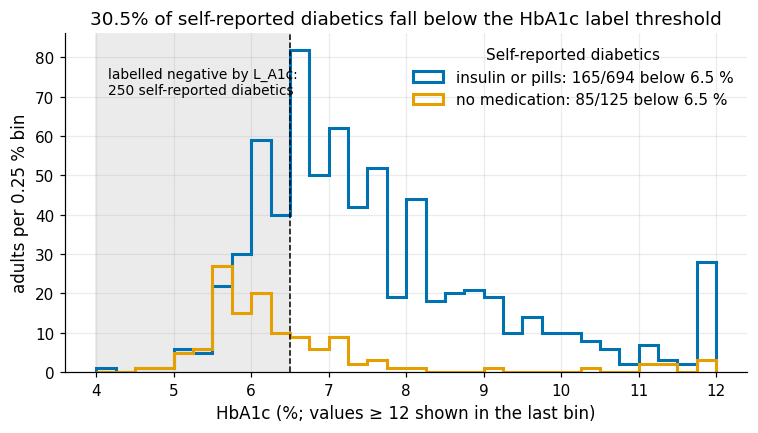

In [124]:
sr = d[d["L_self"] == 1]
ctrl = sr[sr["L_A1c"] == 0]
n_ctrl, n_ctrl_med = len(ctrl), int(ctrl["on_med"].sum())
unmed = ctrl[ctrl["on_med"] == 0]
n_unmed_pre = int(unmed["LBXGH"].between(5.7, 6.49).sum())
on_med = sr[sr["on_med"] == 1]
share_med_below = float((on_med["L_A1c"] == 0).mean())
print(f"self-reported diabetics: {len(sr)}; HbA1c < 6.5: {n_ctrl} ({pct(n_ctrl / len(sr))})")
print(f"  of these on insulin or pills: {n_ctrl_med} ({pct(n_ctrl_med / n_ctrl, 0)}); untreated: {len(unmed)}, "
      f"of whom {n_unmed_pre} have HbA1c 5.7-6.4")
print(f"treated self-reported diabetics: {len(on_med)}; HbA1c < 6.5 among them: {pct(share_med_below)}")
print("\nHbA1c (%) of self-reported diabetics by treatment")
print(sr.groupby(sr["on_med"].map({1: "insulin or pills", 0: "no medication"}))["LBXGH"]
      .describe(percentiles=[.25, .5, .75]).round(2))
assert (n_ctrl, n_ctrl_med, len(unmed), n_unmed_pre, len(on_med)) == (250, 165, 85, 50, 694)
close(n_ctrl / len(sr), 0.305, 0.001, "masking share")
close(share_med_below, 0.238, 0.001, "treated with HbA1c < 6.5")

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(4.0, 12.01, 0.25)
ax.axvspan(4.0, C.HBA1C_DIABETES, color="0.92", zorder=0)
for flag, lab, col in [(1, "insulin or pills", plots.PALETTE[4]), (0, "no medication", plots.PALETTE[0])]:
    x = sr.loc[sr["on_med"] == flag, "LBXGH"].clip(upper=11.99)
    below = int((x < C.HBA1C_DIABETES).sum())
    ax.hist(x, bins=bins, histtype="step", lw=2, color=col, label=f"{lab}: {below}/{len(x)} below 6.5 %")
ax.axvline(C.HBA1C_DIABETES, color="k", ls="--", lw=1)
ax.text(4.15, ax.get_ylim()[1] * 0.9, f"labelled negative by L_A1c:\n{n_ctrl} self-reported diabetics", fontsize=9, va="top")
ax.set(xlabel="HbA1c (%; values ≥ 12 shown in the last bin)", ylabel="adults per 0.25 % bin",
       title=f"{pct(n_ctrl / len(sr))} of self-reported diabetics fall below the HbA1c label threshold")
ax.legend(loc="upper right", title="Self-reported diabetics")
plots.savefig(fig, "S5_a1c_by_medication",
              caption=f"HbA1c distribution of the {len(sr)} self-reported diabetics by current insulin/pill use. "
                      f"{n_ctrl} ({pct(n_ctrl / len(sr))}) are below 6.5 %, {n_ctrl_med} of them treated.")
plt.show()

RES["masking"] = {"self_reported": len(sr), "below_6_5": n_ctrl, "below_6_5_share": n_ctrl / len(sr),
                  "below_6_5_on_med": n_ctrl_med, "below_6_5_untreated": len(unmed),
                  "untreated_5_7_to_6_4": n_unmed_pre, "treated": len(on_med),
                  "treated_below_6_5_share": share_med_below}
register("DR-S5-03", "label_bias",
         "Treatment masks diabetes in HbA1c: an HbA1c-only label turns controlled patients into negatives",
         "figures/S5_a1c_by_medication.png; §5.2",
         f"{n_ctrl}/{len(sr)} ({pct(n_ctrl / len(sr))}) self-reported diabetics have HbA1c<6.5; {n_ctrl_med} of them on medication; "
         f"{pct(share_med_below)} of treated patients below 6.5",
         "Reject L_A1c as the sole target; keep stratum D_controlled as a 3x3 evaluation column; medication is audit-only (post-diagnosis)",
         "HbA1c-only target; medication as a feature (leakage by the availability rule)")

**So what.** 250 of 819 self-reported diabetics (30.5 %) are below the HbA1c threshold, and 165 of these
(66 %) take insulin or pills; among all 694 treated patients 23.8 % are "controlled". The remaining 85 are
untreated, 50 of them in the prediabetes range (5.7–6.4 %), consistent with lifestyle-controlled or
early disease. An HbA1c-only label would therefore count successful treatment as absence of disease: this is
the *D_controlled* column of the 3×3 label matrix in S8.

## 5.3 What "undiagnosed" means

**Why.** The 152 adults with HbA1c ≥ 6.5 % who do not report diabetes are the population the screening use case
is about (E-SCREEN). "Undiagnosed" is easily read as "never saw a doctor". DIQ010 = 3 (borderline), DIQ180
(blood test for high blood sugar in the past three years) and DIQ160 (told prediabetes) show whether they
had contact with the system. Counts are unweighted; shares among the undiagnosed are also weighted with
Korn–Graubard intervals.

In [125]:
bl = d["DIQ010"].eq(3)
no = d["DIQ010"].eq(2)
p_bl, p_no = d.loc[bl, "L_A1c"].mean(), d.loc[no, "L_A1c"].mean()
print(f"DIQ010 = 3 (borderline): {int(bl.sum())}; HbA1c >= 6.5: {int(d.loc[bl, 'L_A1c'].sum())} ({pct(p_bl)}) "
      f"vs DIQ010 = 2: {pct(p_no)}")
und_mask = (d["stratum_3x3"] == "Undiagnosed").to_numpy()
und = d[und_mask]
care = {
    "told borderline (DIQ010=3)": und["DIQ010"].eq(3),
    "blood test past 3 years (DIQ180=1)": und["DIQ180"].eq(1),
    "told prediabetes (DIQ160=1)": und["DIQ160"].eq(1),
}
rows = []
for name, s in care.items():
    y = np.where(und_mask, d.index.isin(s[s].index), np.nan)
    w = S.weighted_prop(d, y.astype(float), weight=WT, domain=und_mask)
    rows.append({"contact": name, "n": int(s.sum()), "of": len(und), "share": s.sum() / len(und),
                 "w_est": w["est"], "kg_low": w["kg_low"], "kg_high": w["kg_high"], "df": w["df"],
                 "flags": ";".join(w["nchs_flags"]), "nchs": nchs_label(w)})
care_tab = pd.DataFrame(rows)
print(care_tab.round(3).to_string(index=False))
print(f"DIQ180 missing among undiagnosed: {int(und['DIQ180'].isna().sum())}; DIQ160 missing: {int(und['DIQ160'].isna().sum())} "
      "(borderline respondents skip DIQ160)")
assert int(bl.sum()) == 213 and int(d.loc[bl, "L_A1c"].sum()) == 36 and len(und) == 152
assert care_tab["n"].tolist() == [36, 104, 48]
close(p_bl, 0.169, 0.001, "borderline A1c+ share")
close(p_no, 0.025, 0.001, "DIQ010=2 A1c+ share")
CT = care_tab.set_index("contact")
t180 = CT.loc["blood test past 3 years (DIQ180=1)"]
close(t180["w_est"], 0.625, 0.0015, "DIQ180 weighted share")
print(f"population estimate (WTPH2YR): {pct(t180['w_est'])} of undiagnosed adults had a blood test in the past 3 years "
      f"(KG {pct(t180['kg_low'])}-{pct(t180['kg_high'])}); unweighted sample share {pct(t180['share'])}")
care_tab.to_csv(OUT / "undiagnosed_care_contact.csv", index=False)
RES["undiagnosed_meaning"] = {"borderline_n": int(bl.sum()), "borderline_a1c_pos": int(d.loc[bl, "L_A1c"].sum()),
                              "borderline_a1c_share": p_bl, "no_a1c_share": p_no, "undiagnosed": len(und),
                              "contact": care_tab.set_index("contact")[["n", "share", "w_est", "kg_low", "kg_high"]].to_dict("index")}
register("DR-S5-04", "label_semantics",
         "Most undiagnosed adults had contact with the health system: the gap is diagnosis/communication, not only access",
         "results/S5/undiagnosed_care_contact.csv; §5.3",
         f"undiagnosed adults blood-tested in past 3 y: {pct(t180['w_est'])} weighted (KG {pct(t180['kg_low'])}-{pct(t180['kg_high'])}; "
         f"sample 104/152 = 68%); 36/152 told borderline; 48 told prediabetes",
         "Frame E-SCREEN positives as 'not diagnosed despite contact'; DIQ160/DIQ180 excluded as features (post-test information); borderline kept negative in L_comb and flagged",
         "Describe undiagnosed as 'no access to care'; use DIQ180 as a screening feature")

DIQ010 = 3 (borderline): 213; HbA1c >= 6.5: 36 (16.9%) vs DIQ010 = 2: 2.5%


                           contact   n  of  share  w_est  kg_low  kg_high  df flags                nchs
        told borderline (DIQ010=3)  36 152  0.237  0.235   0.165    0.318  14       meets NCHS standard
blood test past 3 years (DIQ180=1) 104 152  0.684  0.625   0.535    0.709  14       meets NCHS standard
       told prediabetes (DIQ160=1)  48 152  0.316  0.306   0.227    0.395  14       meets NCHS standard
DIQ180 missing among undiagnosed: 2; DIQ160 missing: 37 (borderline respondents skip DIQ160)
population estimate (WTPH2YR): 62.5% of undiagnosed adults had a blood test in the past 3 years (KG 53.5%-70.9%); unweighted sample share 68.4%


**So what.** Borderline respondents are almost seven times as likely to be HbA1c-positive as those answering
"no" (16.9 % vs 2.5 %). An estimated 62.5 % (KG 53.5–70.9 %, WTPH2YR) of undiagnosed adults in the population
had a blood-sugar test in the past three years (in the sample 104 of 152, 68 %); 36 of the 152 (24 %) were told
they were borderline and 48 were told they had prediabetes. "Undiagnosed" is therefore
mostly a diagnosis and communication gap, not a lack of any contact. This is also why DIQ160 and DIQ180 are
excluded as features: they record the result of a glucose test, which the screening use case comes before.

## 5.4 Who is undiagnosed

**Why.** If the undiagnosed share differs by insurance, access or race, then `L_self` is a biased label
and a model trained on it inherits the bias. The domain is all adults with HbA1c ≥ 6.5 % (n = 721) and the
outcome is "not self-reported". Following NCHS presentation standards, proportions get Korn–Graubard intervals
with the design-based effective sample size and the NCHS domain df (PSUs containing the domain minus strata
containing it). An estimate with n or effective n < 30, an absolute CI width ≥ 0.30, or a CI width > 0.05 with
a relative width > 130 % is labelled *exploratory, does not meet NCHS standard*; df < 8 additionally triggers
NCHS statistical review.
The headline quantity is the risk difference (WTPH2YR, delete-one-PSU jackknife, df = domain df) rather than a
small-cell proportion.

In [126]:
d["undx"] = 1.0 - d["L_self"]
d["uninsured"] = np.select([d["HIQ011"].eq(2), d["HIQ011"].eq(1)], [1.0, 0.0], np.nan)
d["no_usual_place"] = np.select([d["HUQ030"].eq(2), d["HUQ030"].isin([1, 3])], [1.0, 0.0], np.nan)
a1c_dom = d["L_A1c"].eq(1).to_numpy()


def risk_difference(df, y, ga, gb, weight=WT):
    """Weighted risk difference p(a) - p(b) with JK CI (df = NCHS domain df of a or b)."""
    yv = df[y].to_numpy(float)
    ok = ~np.isnan(yv)
    a, b = np.asarray(ga) & ok, np.asarray(gb) & ok
    y0 = np.nan_to_num(yv)

    def f(_d, w):
        return np.dot(w * a, y0) / np.sum(w * a) - np.dot(w * b, y0) / np.sum(w * b)
    return S.jackknife(df, f, weight=weight, df_override=S.domain_df(df, a | b))


contrasts = [  # (name, column, level a, level b, label a, label b)
    ("uninsured - insured", "uninsured", 1.0, 0.0, "uninsured", "insured"),
    ("no usual place - usual place", "no_usual_place", 1.0, 0.0, "no usual place", "usual place"),
    ("NH Asian - NH White", "RIDRETH3", 6, 3, "NH Asian", "NH White"),
]
prop_rows, rd_rows = [], []
for name, col, a, b, la, lb in contrasts:
    for lev, lab in [(a, la), (b, lb)]:
        r = S.weighted_prop(d, "undx", weight=WT, domain=a1c_dom & d[col].eq(lev).to_numpy())
        prop_rows.append({"group": lab, "contrast": name, **{k: r[k] for k in
                          ("n", "n_events", "est", "kg_low", "kg_high", "ci_width", "n_eff", "df")},
                          "nchs": nchs_label(r), "nchs_status": r["nchs_status"], "flags": ";".join(r["nchs_flags"])})
    rd = risk_difference(d, "undx", a1c_dom & d[col].eq(a).to_numpy(), a1c_dom & d[col].eq(b).to_numpy())
    rd_rows.append({"contrast": name, "rd_pp": 100 * rd["est"], "ci_low_pp": 100 * rd["ci_low"],
                    "ci_high_pp": 100 * rd["ci_high"], "df": rd["df"]})
props = pd.DataFrame(prop_rows).drop_duplicates("group")
rds = pd.DataFrame(rd_rows)
print("Undiagnosed share among HbA1c >= 6.5 (WTPH2YR, Korn-Graubard)")
print(props.drop(columns="flags").round(3).to_string(index=False))
print("\nRisk differences (percentage points, JK CI)")
print(rds.round(1).to_string(index=False))

P = props.set_index("group")
close(P.loc["uninsured", "est"], 0.430, 0.0015, "uninsured share"); assert P.loc["uninsured", "n"] == 49
close(P.loc["uninsured", "kg_low"], 0.242, 0.002, "uninsured KG low"); close(P.loc["uninsured", "kg_high"], 0.635, 0.002, "uninsured KG high")
assert P.loc["uninsured", "df"] == 9 and P.loc["no usual place", "df"] == 9
close(P.loc["insured", "est"], 0.199, 0.0015, "insured share")
close(P.loc["no usual place", "est"], 0.403, 0.0015, "no usual place share"); assert P.loc["no usual place", "n"] == 41
close(P.loc["NH Asian", "est"], 0.362, 0.0015, "Asian share"); assert P.loc["NH Asian", "n"] == 40 and P.loc["NH Asian", "df"] == 4
close(P.loc["NH Asian", "kg_low"], 0.131, 0.002, "Asian KG low"); close(P.loc["NH Asian", "kg_high"], 0.652, 0.002, "Asian KG high")
for g in ("uninsured", "no usual place", "NH Asian"):
    assert P.loc[g, "ci_width"] >= C.NCHS_CI_WIDTH_MAX and P.loc[g, "nchs_status"] == "suppress"
assert P.loc["insured", "nchs"] == "meets NCHS standard"
RD = rds.set_index("contrast")
for name, (e, lo, hi) in {"uninsured - insured": (23.2, 6.2, 40.1), "no usual place - usual place": (19.9, -1.6, 41.5),
                          "NH Asian - NH White": (15.6, -5.7, 36.9)}.items():
    close(RD.loc[name, "rd_pp"], e, 0.06, name); close(RD.loc[name, "ci_low_pp"], lo, 0.06, name + " low")
    close(RD.loc[name, "ci_high_pp"], hi, 0.06, name + " high")

Undiagnosed share among HbA1c >= 6.5 (WTPH2YR, Korn-Graubard)


         group                     contrast   n  n_events   est  kg_low  kg_high  ci_width   n_eff  df                                     nchs nchs_status
     uninsured          uninsured - insured  49        18 0.430   0.242    0.635     0.393  33.776   9 exploratory, does not meet NCHS standard    suppress
       insured          uninsured - insured 670       133 0.199   0.157    0.246     0.088 392.084  15                      meets NCHS standard     present
no usual place no usual place - usual place  41        17 0.403   0.200    0.633     0.433  26.951   9 exploratory, does not meet NCHS standard    suppress
   usual place no usual place - usual place 680       135 0.203   0.158    0.256     0.098 327.872  15                      meets NCHS standard     present
      NH Asian          NH Asian - NH White  40        12 0.362   0.131    0.652     0.520  26.575   4 exploratory, does not meet NCHS standard    suppress
      NH White          NH Asian - NH White 362        74 0.206

**Adjusted models.** The risk differences above are crude. To check whether they survive confounding, each
exposure gets **its own** logistic model of "undiagnosed" among the HbA1c-positive adults, with the adjustment
set that the S4 DAG (back-door criterion, `results/S4/dag_adjustment_sets.csv`) identifies for that exposure:

| Exposure | Adjustment set (S4 DAG) | Not adjusted for, and why |
|---|---|---|
| uninsured | age, sex, SES (PIR + missing-PIR indicator) | usual place of care: a *mediator* (insurance → usual care → diagnosis) |
| no usual place of care | age, sex, SES (PIR + missing-PIR indicator) | insurance: an ancestor of usual care whose back-door paths are already closed by age and SES |
| NH Asian (vs NH White) | age, sex | SES and BMI: *mediators* of race (race → SES / adiposity → diagnosis) |

PIR is missing for some adults, so it enters as median-filled value plus the indicator `pir_miss`. Each model
is fitted unweighted (model-based CI) and WTPH2YR-weighted (delete-one-PSU jackknife on the full design, the
domain formed by zero weights). Both are reported because they disagree in places. A mutually adjusted model
(all exposures plus BMI in one equation, as in an earlier draft) is not used: it would adjust insurance for its
own mediator and present every coefficient as if it were an effect.

In [127]:
RACE_LEVELS = ["NH White", *[r for r in RACE.values() if r != "NH White"]]
d["age10"] = d["RIDAGEYR"] / 10
d["male"] = d["RIAGENDR"].eq(1).astype(float)
d["pir"] = d["INDFMPIR"].fillna(d["INDFMPIR"].median())
d["race_cat"] = pd.Categorical(d["race3"], categories=RACE_LEVELS)
ADJ_MODELS = [  # (exposure label, coefficient, formula, adjustment set)
    ("uninsured", "uninsured", "undx ~ uninsured + age10 + male + pir + pir_miss", "age, sex, PIR (+ pir_miss)"),
    ("no usual place", "no_usual_place", "undx ~ no_usual_place + age10 + male + pir + pir_miss", "age, sex, PIR (+ pir_miss)"),
    ("NH Asian", "race_cat[T.NH Asian]", "undx ~ race_cat + age10 + male", "age, sex"),
]


def _wlogit(form, term, mask):
    """stat_fn for survey.jackknife: weighted logit coefficient of `term` on rows with mask & w > 0."""
    def f(df, w):
        m = mask & (w > 0)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fit_w = smf.glm(form, data=df[m], family=sm.families.Binomial(), freq_weights=w[m] / w[m].mean()).fit()
        return fit_w.params[term]
    return f


adj_rows = []
for lab, term, form, adj in ADJ_MODELS:
    col = term.split("[")[0]
    cc = a1c_dom & d[[col, "age10", "male", "pir", "pir_miss"]].notna().all(axis=1).to_numpy()
    fit = smf.logit(form, data=d[cc]).fit(disp=0)
    ci = fit.conf_int().loc[term]
    jk = S.jackknife(d, _wlogit(form, term, cc), weight=WT, df_override=S.domain_df(d, cc))
    adj_rows.append({"exposure": lab, "adjustment_set": adj, "n": int(cc.sum()), "events": int(d.loc[cc, "undx"].sum()),
                     "OR": np.exp(fit.params[term]), "ci_low": np.exp(ci[0]), "ci_high": np.exp(ci[1]),
                     "OR_w": np.exp(jk["est"]), "w_ci_low": np.exp(jk["ci_low"]), "w_ci_high": np.exp(jk["ci_high"]),
                     "df": jk["df"], "formula": form})
logit_tab = pd.DataFrame(adj_rows)
print(f"domain: {int(a1c_dom.sum())} adults with HbA1c >= 6.5; PIR missing for {int(d.loc[a1c_dom, 'pir_miss'].sum())} "
      f"(indicator); unknown insurance: {int(d.loc[a1c_dom, 'uninsured'].isna().sum())}")
print(logit_tab.drop(columns="formula").round(2).to_string(index=False))
LT = logit_tab.set_index("exposure")
assert LT["n"].tolist() == [719, 721, 721]
excl = lambda lo, hi: lo > 1 or hi < 1   # noqa: E731
LT["unweighted_excludes_1"] = [excl(lo, hi) for lo, hi in zip(LT["ci_low"], LT["ci_high"])]
LT["weighted_excludes_1"] = [excl(lo, hi) for lo, hi in zip(LT["w_ci_low"], LT["w_ci_high"])]
print(LT[["unweighted_excludes_1", "weighted_excludes_1"]])
assert (LT[["OR", "OR_w"]] > 1).all().all()          # every exposure points in the same direction as its crude RD
assert LT.loc["uninsured", "unweighted_excludes_1"] and LT.loc["uninsured", "weighted_excludes_1"]
assert not LT.loc["NH Asian", "unweighted_excludes_1"] and not LT.loc["NH Asian", "weighted_excludes_1"]
assert LT.loc["no usual place", "unweighted_excludes_1"] and not LT.loc["no usual place", "weighted_excludes_1"]  # fits disagree

domain: 721 adults with HbA1c >= 6.5; PIR missing for 93 (indicator); unknown insurance: 2
      exposure             adjustment_set   n  events   OR  ci_low  ci_high  OR_w  w_ci_low  w_ci_high  df
     uninsured age, sex, PIR (+ pir_miss) 719     151 2.22    1.18     4.18  2.90      1.48       5.67  15
no usual place age, sex, PIR (+ pir_miss) 721     152 2.76    1.43     5.33  2.52      0.89       7.09  15
      NH Asian                   age, sex 721     152 1.67    0.81     3.44  2.18      0.84       5.62  15
                unweighted_excludes_1  weighted_excludes_1
exposure                                                  
uninsured                        True                 True
no usual place                   True                False
NH Asian                        False                False


**Reading the models (Table-2 caveat).** Each odds ratio is the estimate for *its own* exposure only. The
coefficients of the adjustment covariates (age, sex, PIR) in the same fits are not effects and are therefore not
shown: they are themselves confounded or partly mediated (Westreich & Greenland 2013, "Table 2 fallacy").
The odds ratios are associations under the assumed DAG, not causal effects of insurance or care.

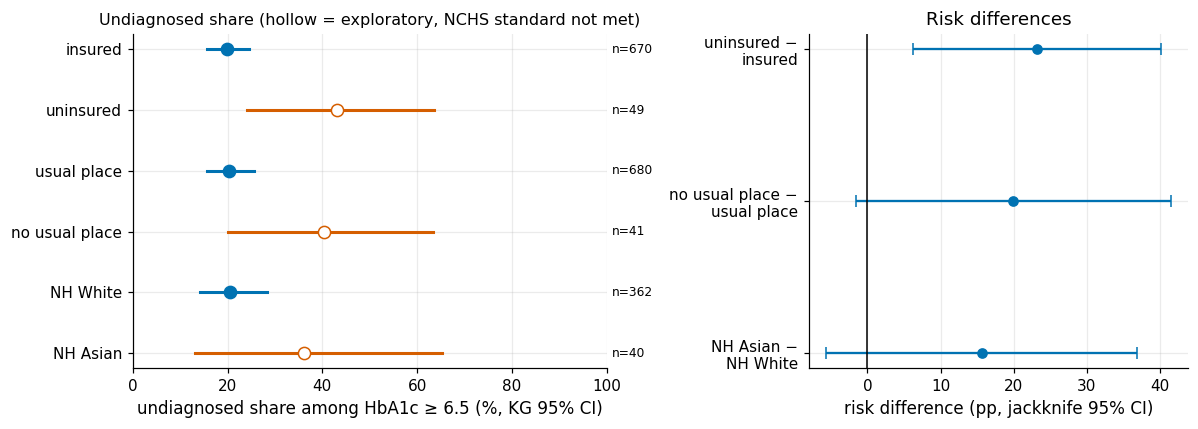

In [128]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.25, 1]})
order = ["insured", "uninsured", "usual place", "no usual place", "NH White", "NH Asian"]
pp = P.loc[order]
yy = np.arange(len(order))[::-1]
for yi, (g, r) in zip(yy, pp.iterrows()):
    expl = r["nchs"].startswith("exploratory")
    col = plots.PALETTE[5] if expl else plots.PALETTE[4]
    ax1.plot([r["kg_low"] * 100, r["kg_high"] * 100], [yi, yi], color=col, lw=2)
    ax1.plot(r["est"] * 100, yi, "o", color=col, mfc="white" if expl else col, ms=8)
    ax1.text(101, yi, f"n={int(r['n'])}", va="center", fontsize=8)
ax1.set_yticks(yy, order)
ax1.set(xlim=(0, 100), xlabel="undiagnosed share among HbA1c ≥ 6.5 (%, KG 95% CI)",
        title="Undiagnosed share (hollow = exploratory, NCHS standard not met)")
ax1.title.set_fontsize(10.5)
yr = np.arange(len(rds))[::-1]
ax2.errorbar(rds["rd_pp"], yr, xerr=[rds["rd_pp"] - rds["ci_low_pp"], rds["ci_high_pp"] - rds["rd_pp"]],
             fmt="o", color=plots.PALETTE[4], capsize=4)
ax2.axvline(0, color="k", lw=1)
ax2.set_yticks(yr, [c.replace(" - ", " −\n") for c in rds["contrast"]])
ax2.set(xlabel="risk difference (pp, jackknife 95% CI)", title="Risk differences")
fig.tight_layout()
plots.savefig(fig, "S5_undiagnosed_inequality",
              caption="Share of HbA1c-positive adults who do not report diabetes (WTPH2YR, Korn-Graubard CI) and risk "
                      "differences with delete-one-PSU jackknife CI. Hollow markers: fails the NCHS presentation standard (exploratory).")
plt.show()

props.to_csv(OUT / "undiagnosed_by_group.csv", index=False)
rds.to_csv(OUT / "undiagnosed_risk_differences.csv", index=False)
logit_tab.to_csv(OUT / "undiagnosed_logit.csv", index=False)
RES["undiagnosed_inequality"] = {
    "proportions": props.set_index("group").drop(columns=["contrast"]).to_dict("index"),
    "risk_differences_pp": rds.set_index("contrast").to_dict("index"),
    "adjusted_logit": {r["exposure"]: {k: r[k] for k in ("adjustment_set", "formula", "n", "events", "OR", "ci_low", "ci_high",
                                                          "OR_w", "w_ci_low", "w_ci_high", "df")} for r in adj_rows},
}
register("DR-S5-05", "label_bias",
         "Undiagnosed share is higher without insurance or a usual place of care; small cells do not meet NCHS standards",
         "results/S5/undiagnosed_by_group.csv; results/S5/undiagnosed_risk_differences.csv; figures/S5_undiagnosed_inequality.png",
         f"RD uninsured-insured {RD.loc['uninsured - insured', 'rd_pp']:.1f}pp ({RD.loc['uninsured - insured', 'ci_low_pp']:.1f}, "
         f"{RD.loc['uninsured - insured', 'ci_high_pp']:.1f}); uninsured share 43.0% KG width {P.loc['uninsured', 'ci_width']:.2f}; "
         f"DAG-adjusted OR (age, sex, PIR) uninsured {LT.loc['uninsured', 'OR']:.2f} ({LT.loc['uninsured', 'ci_low']:.2f}, "
         f"{LT.loc['uninsured', 'ci_high']:.2f}), weighted {LT.loc['uninsured', 'OR_w']:.2f} ({LT.loc['uninsured', 'w_ci_low']:.2f}, "
         f"{LT.loc['uninsured', 'w_ci_high']:.2f}); no usual place {LT.loc['no usual place', 'OR']:.2f} ({LT.loc['no usual place', 'ci_low']:.2f}, "
         f"{LT.loc['no usual place', 'ci_high']:.2f}), weighted {LT.loc['no usual place', 'OR_w']:.2f} ({LT.loc['no usual place', 'w_ci_low']:.2f}, "
         f"{LT.loc['no usual place', 'w_ci_high']:.2f})",
         "Headline = risk difference with JK CI; proportions with KG CI and NCHS flag; insurance and access are audit/stratification variables only; S8 audits L_self vs L_comb by low_access",
         "Report small-cell proportions as headline; drop small groups; put insurance into the model; one mutually adjusted model "
         "(adjusts insurance for its mediator usual care; Table-2 fallacy)")

**So what.** Among HbA1c-positive adults, 43.0 % of the uninsured but 19.9 % of the insured do not know their
diagnosis: a risk difference of +23.2 pp (6.2, 40.1) whose interval excludes zero. Without a usual place of care
the difference is +19.9 pp (−1.6, 41.5) and for NH Asian versus NH White adults +15.6 pp (−5.7, 36.9); both
intervals include zero. All three group proportions are flagged by the NCHS presentation rules, so they are
*exploratory and do not meet the NCHS standard*; they are not headlines. In the DAG-guided models (one per
exposure), lacking insurance stays associated with being undiagnosed after adjusting for age, sex and income
(OR 2.2 unweighted, 2.9 weighted; both CIs exclude 1). For lacking a usual place of care the two fits disagree:
the unweighted CI excludes 1 (OR 2.8), the design-based weighted CI does not (OR 2.5, 0.9–7.1), so this
association is suggestive only. The Asian–White OR is imprecise in both fits; it is deliberately adjusted for
age and sex only, because in the S4 DAG income (SES) lies on the path from race to diagnosis, so adjusting for it
would remove part of the association being described. The
headline therefore remains the crude risk difference for insurance. Consequence for the label: `L_self`
systematically under-counts disease in groups with
poorer access, which is why the target is the union `L_comb` and why S8 compares training labels.

## 5.5 BMI as a biased measurement of adiposity in Asian adults

**Why.** BMI is the main adiposity feature of any non-laboratory screening model. Asian adults develop
diabetes at lower BMI (Araneta et al. 2015; WHO Expert Consultation 2004), so the same BMI value may carry
different information by race: a *feature-level* measurement bias. We compare NH Asian with NH White adults on
(a) the BMI of diabetics, (b) `L_comb` prevalence by BMI band, (c) the discrimination (single-feature ROC-AUC)
of BMI, waist circumference and waist-to-height ratio (WHtR), with a paired bootstrap of the WHtR − BMI gain,
and (d) the sensitivity of the BMI ≥ 25 and ≥ 23 screening cut-offs. These are unweighted *measurement*
properties of the sample; the White group is the control comparison.

In [129]:
grp = {"NH Asian": 6, "NH White": 3}
bmi_dm = []
for g, code in grp.items():
    dm = d[(d["RIDRETH3"] == code) & (d["L_comb"] == 1) & d["BMXBMI"].notna()]
    k = int((dm["BMXBMI"] < 25).sum())
    w = S.weighted_prop(d, (d["BMXBMI"] < 25).astype(float).where(d["BMXBMI"].notna()), weight=WT,
                        domain=((d["RIDRETH3"] == code) & (d["L_comb"] == 1)).to_numpy())
    bmi_dm.append({"group": g, "bmi_lt25": k, "diabetics_with_bmi": len(dm), "share": k / len(dm),
                   "median_bmi": dm["BMXBMI"].median(), "w_share": w["est"], "kg_low": w["kg_low"], "kg_high": w["kg_high"]})
bmi_dm = pd.DataFrame(bmi_dm).set_index("group")
print("BMI < 25 among L_comb diabetics (denominator excludes missing BMI)")
print(bmi_dm.round(3))
assert (bmi_dm.loc["NH Asian", "bmi_lt25"], bmi_dm.loc["NH Asian", "diabetics_with_bmi"]) == (24, 47)
close(bmi_dm.loc["NH Asian", "share"], 0.511, 0.001, "Asian BMI<25"); close(bmi_dm.loc["NH White", "share"], 0.072, 0.001, "White BMI<25")

BANDS = [0, 23, 25, 30, 200]
BLAB = ["<23", "23–24.9", "25–29.9", "≥30"]
d["bmi_band"] = pd.cut(d["BMXBMI"], BANDS, right=False, labels=BLAB)
band_rows = []
for g, code in grp.items():
    for b in BLAB:
        m = ((d["RIDRETH3"] == code) & (d["bmi_band"] == b)).to_numpy()
        w = S.weighted_prop(d, "L_comb", weight=WT, domain=m)
        band_rows.append({"group": g, "bmi_band": b, "n": int(m.sum()), "cases": int(d.loc[m, "L_comb"].sum()),
                          "prev": d.loc[m, "L_comb"].mean(), "w_prev": w["est"], "kg_low": w["kg_low"],
                          "kg_high": w["kg_high"], "ci_width": w["ci_width"], "df": w["df"],
                          "nchs_status": w["nchs_status"], "flags": ";".join(w["nchs_flags"])})
bands = pd.DataFrame(band_rows)
print("\nL_comb prevalence by BMI band (unweighted and WTPH2YR with KG CI)")
print(bands.round(3).to_string(index=False))
B_ = bands.set_index(["group", "bmi_band"])
n_flag_asian = int((bands.loc[bands["group"] == "NH Asian", "nchs_status"] != "present").sum())
print(f"NH Asian BMI bands failing the NCHS presentation standard: {n_flag_asian} of {len(BLAB)}")
assert n_flag_asian >= 3
close(B_.loc[("NH Asian", "<23"), "prev"], 0.121, 0.001, "Asian <23"); close(B_.loc[("NH White", "<23"), "prev"], 0.043, 0.001, "White <23")
close(B_.loc[("NH Asian", "23–24.9"), "prev"], 0.175, 0.001, "Asian 23-25"); close(B_.loc[("NH White", "23–24.9"), "prev"], 0.033, 0.001, "White 23-25")
close(B_.loc[("NH Asian", "25–29.9"), "prev"], 0.115, 0.001, "Asian 25-30"); close(B_.loc[("NH Asian", "25–29.9"), "w_prev"], 0.053, 0.001, "Asian 25-30 weighted")
close(B_.loc[("NH Asian", "<23"), "w_prev"], 0.078, 0.001, "Asian <23 weighted"); close(B_.loc[("NH Asian", "23–24.9"), "w_prev"], 0.140, 0.001, "Asian 23-25 weighted")

BMI < 25 among L_comb diabetics (denominator excludes missing BMI)
          bmi_lt25  diabetics_with_bmi  share  median_bmi  w_share  kg_low  kg_high
group                                                                              
NH Asian        24                  47  0.511        24.9    0.501   0.255    0.747
NH White        35                 488  0.072        32.7    0.067   0.045    0.096

L_comb prevalence by BMI band (unweighted and WTPH2YR with KG CI)
   group bmi_band    n  cases  prev  w_prev  kg_low  kg_high  ci_width  df nchs_status                  flags
NH Asian      <23  107     13 0.121   0.078   0.028    0.167     0.139   9    suppress      rel_ci_width>130%
NH Asian  23–24.9   63     11 0.175   0.140   0.049    0.291     0.242   5    suppress rel_ci_width>130%;df<8
NH Asian  25–29.9   96     11 0.115   0.053   0.014    0.133     0.119   8    suppress      rel_ci_width>130%
NH Asian      ≥30   44     12 0.273   0.284   0.104    0.536     0.431   5    suppress    

In [130]:
FEATS = {"BMI": "BMXBMI", "waist": "BMXWAIST", "WHtR": "whtr"}
B = C.N_BOOT
rng = np.random.default_rng(E.derive_seed(C.SEED_MASTER, "S5", "auc_bootstrap"))


def auc_set(g):
    out = {}
    for f, col in FEATS.items():
        ok = g[col].notna()
        out[f] = roc_auc_score(g.loc[ok, "L_comb"], g.loc[ok, col])
    both = g["BMXBMI"].notna() & g["whtr"].notna()
    out["gain"] = (roc_auc_score(g.loc[both, "L_comb"], g.loc[both, "whtr"])
                   - roc_auc_score(g.loc[both, "L_comb"], g.loc[both, "BMXBMI"]))
    return out


roc_rows, boot_store = [], {}
for g, code in grp.items():
    sub = d.loc[d["RIDRETH3"] == code, ["L_comb", *FEATS.values()]].reset_index(drop=True)
    est = auc_set(sub)
    pos, neg = np.flatnonzero(sub["L_comb"] == 1), np.flatnonzero(sub["L_comb"] == 0)
    reps = pd.DataFrame([auc_set(sub.iloc[np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])])
                         for _ in range(B)])
    boot_store[g] = reps
    for k in [*FEATS, "gain"]:
        roc_rows.append({"group": g, "measure": k if k != "gain" else "WHtR − BMI (paired)",
                         "n": int(sub[FEATS[k]].notna().sum()) if k in FEATS else int((sub["BMXBMI"].notna() & sub["whtr"].notna()).sum()),
                         "auc": est[k], "ci_low": reps[k].quantile(0.025), "ci_high": reps[k].quantile(0.975)})
roc = pd.DataFrame(roc_rows)
gain_diff = boot_store["NH Asian"]["gain"] - boot_store["NH White"]["gain"]
print(f"Single-feature ROC-AUC for L_comb (stratified bootstrap, B = {B})")
print(roc.round(3).to_string(index=False))
print(f"Asian minus White WHtR gain: {roc.iloc[3]['auc'] - roc.iloc[7]['auc']:+.3f} "
      f"(bootstrap 95% CI {gain_diff.quantile(.025):+.3f}, {gain_diff.quantile(.975):+.3f})")
RO = roc.set_index(["group", "measure"])
assert gain_diff.quantile(.025) > 0, "Asian WHtR gain no longer exceeds the White gain"
close(RO.loc[("NH Asian", "BMI"), "auc"], 0.573, 0.001, "Asian BMI AUC")
close(RO.loc[("NH Asian", "waist"), "auc"], 0.697, 0.001, "Asian waist AUC")
close(RO.loc[("NH Asian", "WHtR"), "auc"], 0.714, 0.001, "Asian WHtR AUC")
close(RO.loc[("NH White", "BMI"), "auc"], 0.701, 0.001, "White BMI AUC")
close(RO.loc[("NH White", "WHtR"), "auc"], 0.749, 0.001, "White WHtR AUC")
close(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "auc"], 0.137, 0.0006, "Asian gain")
close(RO.loc[("NH White", "WHtR − BMI (paired)"), "auc"], 0.049, 0.0006, "White gain")
tol_ci = 0.002 if C.IS_FINAL else 0.03   # bootstrap CI bounds: FINAL (B=1000) reproduces 0.093-0.181 / 0.039-0.058
close(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "ci_low"], 0.093, tol_ci, "Asian gain CI low")
close(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "ci_high"], 0.181, tol_ci, "Asian gain CI high")
close(RO.loc[("NH White", "WHtR − BMI (paired)"), "ci_low"], 0.039, tol_ci, "White gain CI low")
close(RO.loc[("NH White", "WHtR − BMI (paired)"), "ci_high"], 0.058, tol_ci, "White gain CI high")

Single-feature ROC-AUC for L_comb (stratified bootstrap, B = 1000)
   group             measure    n   auc  ci_low  ci_high
NH Asian                 BMI  310 0.573   0.486    0.663
NH Asian               waist  296 0.697   0.618    0.770
NH Asian                WHtR  296 0.714   0.640    0.793
NH Asian WHtR − BMI (paired)  296 0.137   0.093    0.181
NH White                 BMI 3370 0.701   0.677    0.724
NH White               waist 3274 0.751   0.729    0.772
NH White                WHtR 3268 0.749   0.727    0.770
NH White WHtR − BMI (paired) 3264 0.049   0.039    0.058
Asian minus White WHtR gain: +0.088 (bootstrap 95% CI +0.044, +0.135)


**Design-aware interval for the gain difference.** The bootstrap above resamples *people*, but NHANES adults are
clustered in 30 PSUs; people in the same PSU share neighbourhood, field team and exam period, so person-level
resampling can understate the uncertainty. As a check, the Asian − White difference in WHtR gain is also
bootstrapped at the PSU level (Rao–Wu rescaled bootstrap within the 15 strata, `survey.rao_wu_weights`; the
replicate multiplicities enter the unweighted AUCs as frequency weights).

In [131]:
diff_est = float(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "auc"] - RO.loc[("NH White", "WHtR − BMI (paired)"), "auc"])
MULT = S.rao_wu_weights(d, np.ones(len(d)), B, seed=E.derive_seed(C.SEED_MASTER, "S5", "psu_bootstrap"))
both_ok = (d["BMXBMI"].notna() & d["whtr"].notna()).to_numpy()


def _gain_w(mask, w):
    m = mask & both_ok & (w > 0)
    y = d["L_comb"].to_numpy()[m]
    return (roc_auc_score(y, d["whtr"].to_numpy()[m], sample_weight=w[m])
            - roc_auc_score(y, d["BMXBMI"].to_numpy()[m], sample_weight=w[m]))


is_as, is_wh = d["RIDRETH3"].eq(6).to_numpy(), d["RIDRETH3"].eq(3).to_numpy()
psu_diff = np.array([_gain_w(is_as, MULT[:, b]) - _gain_w(is_wh, MULT[:, b]) for b in range(B)])
gain_ci = pd.DataFrame([
    {"method": "person-level stratified bootstrap", "est": diff_est,
     "ci_low": gain_diff.quantile(.025), "ci_high": gain_diff.quantile(.975), "se": gain_diff.std()},
    {"method": "PSU cluster bootstrap (Rao-Wu)", "est": diff_est,
     "ci_low": np.quantile(psu_diff, .025), "ci_high": np.quantile(psu_diff, .975), "se": psu_diff.std()},
])
print(f"Asian − White difference in paired WHtR − BMI gain (B = {B})")
print(gain_ci.round(3).to_string(index=False))
close(diff_est, 0.088, 0.0006, "gain difference")
assert np.quantile(psu_diff, .025) > 0, "PSU bootstrap CI of the gain difference includes 0"
if C.IS_FINAL:   # reviewer's independent PSU bootstrap: 0.039-0.116
    close(np.quantile(psu_diff, .025), 0.039, 0.01, "PSU CI low"); close(np.quantile(psu_diff, .975), 0.116, 0.01, "PSU CI high")
gain_ci.to_csv(OUT / "whtr_gain_difference_ci.csv", index=False)

Asian − White difference in paired WHtR − BMI gain (B = 1000)
                           method   est  ci_low  ci_high    se
person-level stratified bootstrap 0.088   0.044    0.135 0.023
   PSU cluster bootstrap (Rao-Wu) 0.088   0.035    0.116 0.021


**So what.** Clustering does not inflate the uncertainty here (FINAL run, B = 1,000: SE 0.021 at PSU level vs
0.023 at person level), but the PSU-level interval is shifted towards zero (0.035–0.116 vs 0.044–0.135). It
still excludes zero, so the larger WHtR gain in Asian adults is not an artefact of ignoring the survey's
clustering. The design-aware (PSU) interval is the one quoted from here on; with 30 PSUs and only 15 strata it
is itself approximate.

In [132]:
cut_rows = []
for g, code in grp.items():
    sub = d[(d["RIDRETH3"] == code) & d["BMXBMI"].notna()]
    y = sub["L_comb"].eq(1)
    for cut in (25, 23):
        flag = sub["BMXBMI"] >= cut
        cut_rows.append({"group": g, "rule": f"BMI ≥ {cut}", "sensitivity": flag[y].mean(),
                         "specificity": (~flag[~y]).mean(), "flagged_share": flag.mean(), "cases": int(y.sum())})
cuts = pd.DataFrame(cut_rows)
print(cuts.round(3).to_string(index=False))
CU = cuts.set_index(["group", "rule"])
close(CU.loc[("NH Asian", "BMI ≥ 25"), "sensitivity"], 0.489, 0.001, "Asian sens BMI>=25")
close(CU.loc[("NH White", "BMI ≥ 25"), "sensitivity"], 0.928, 0.001, "White sens BMI>=25")
close(CU.loc[("NH Asian", "BMI ≥ 23"), "sensitivity"], 0.723, 0.001, "Asian sens BMI>=23")
close(CU.loc[("NH Asian", "BMI ≥ 23"), "specificity"], 0.357, 0.001, "Asian spec BMI>=23")

   group     rule  sensitivity  specificity  flagged_share  cases
NH Asian BMI ≥ 25        0.489        0.555          0.452     47
NH Asian BMI ≥ 23        0.723        0.357          0.655     47
NH White BMI ≥ 25        0.928        0.303          0.731    488
NH White BMI ≥ 23        0.957        0.161          0.856    488


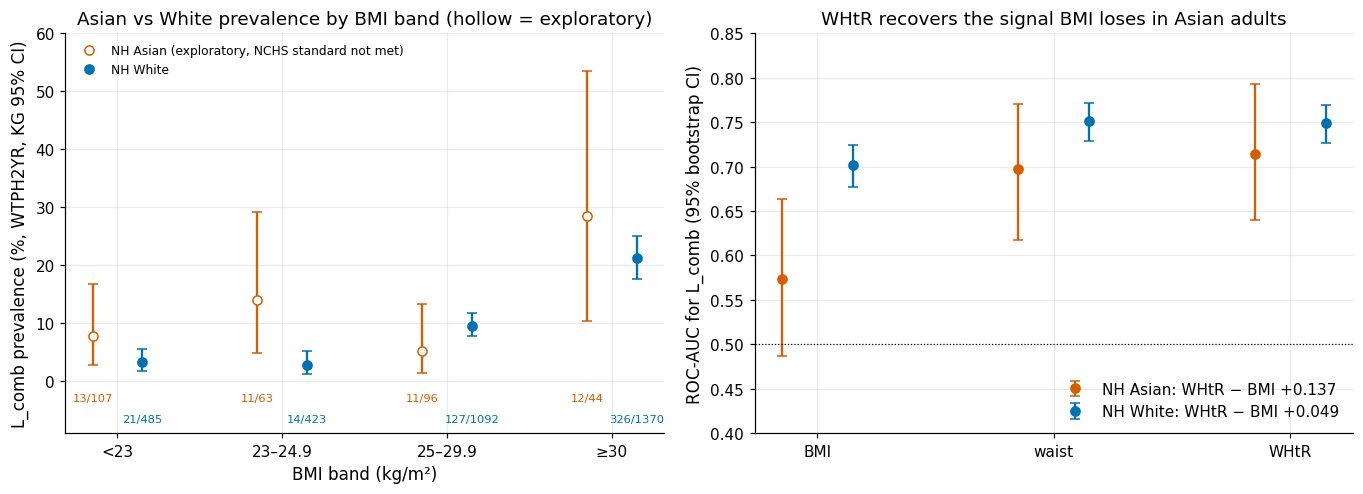

In [133]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6))
xb = np.arange(len(BLAB))
for i, (g, col) in enumerate([("NH Asian", plots.PALETTE[5]), ("NH White", plots.PALETTE[4])]):
    sb = bands[bands["group"] == g]
    off = (i - 0.5) * 0.3
    ax1.errorbar(xb + off, sb["w_prev"] * 100, yerr=[(sb["w_prev"] - sb["kg_low"]) * 100, (sb["kg_high"] - sb["w_prev"]) * 100],
                 fmt="none", ecolor=col, capsize=3)
    ok = (sb["nchs_status"] == "present").to_numpy()
    ax1.plot((xb + off)[ok], sb["w_prev"].to_numpy()[ok] * 100, "o", color=col, label=g if ok.any() else None)
    ax1.plot((xb + off)[~ok], sb["w_prev"].to_numpy()[~ok] * 100, "o", color=col, mfc="white",
             label=f"{g} (exploratory, NCHS standard not met)" if (~ok).any() else None)
    for x_, (_, r) in zip(xb + off, sb.iterrows()):
        ax1.text(x_, -3.5 - 3.5 * i, f"{r['cases']}/{r['n']}", ha="center", fontsize=7.5, color=col)
ax1.set_xticks(xb, BLAB)
ax1.set(xlabel="BMI band (kg/m²)", ylabel="L_comb prevalence (%, WTPH2YR, KG 95% CI)", ylim=(-9, 60),
        title="Asian vs White prevalence by BMI band (hollow = exploratory)")
ax1.legend(loc="upper left", fontsize=8)
meas = ["BMI", "waist", "WHtR"]
for i, (g, col) in enumerate([("NH Asian", plots.PALETTE[5]), ("NH White", plots.PALETTE[4])]):
    rr = RO.loc[g].loc[meas]
    off = (i - 0.5) * 0.3
    ax2.errorbar(np.arange(3) + off, rr["auc"], yerr=[rr["auc"] - rr["ci_low"], rr["ci_high"] - rr["auc"]],
                 fmt="o", color=col, capsize=3,
                 label=f"{g}: WHtR − BMI {RO.loc[(g, 'WHtR − BMI (paired)'), 'auc']:+.3f}")
ax2.axhline(0.5, color="k", lw=0.8, ls=":")
ax2.set_xticks(range(3), meas)
ax2.set(ylabel="ROC-AUC for L_comb (95% bootstrap CI)", ylim=(0.4, 0.85),
        title="WHtR recovers the signal BMI loses in Asian adults")
ax2.legend(loc="lower right")
fig.tight_layout()
plots.savefig(fig, "S5_asian_bmi_whtr",
              caption="Left: L_comb prevalence by BMI band, NH Asian vs NH White (WTPH2YR, Korn-Graubard CI; labels = cases/n; "
                      "hollow markers fail the NCHS presentation standard and are exploratory). "
                      "Right: single-feature ROC-AUC of BMI, waist and WHtR with stratified bootstrap CI; legend = paired WHtR - BMI gain.")
plt.show()

roc.to_csv(OUT / "bmi_race_roc.csv", index=False)
bands.to_csv(OUT / "bmi_band_prevalence.csv", index=False)
cuts.to_csv(OUT / "bmi_cutoff_sensitivity.csv", index=False)
RES["asian_bmi"] = {
    "bmi_lt25_among_diabetics": bmi_dm.to_dict("index"),
    "band_prevalence": {f"{g}|{b}": v for (g, b), v in B_[["n", "cases", "prev", "w_prev", "kg_low", "kg_high"]].to_dict("index").items()},
    "auc": {f"{g}|{m}": v for (g, m), v in RO[["n", "auc", "ci_low", "ci_high"]].to_dict("index").items()},
    "gain_difference_asian_minus_white": {"est": float(RO.loc[("NH Asian", "WHtR − BMI (paired)"), "auc"] - RO.loc[("NH White", "WHtR − BMI (paired)"), "auc"]),
                                          "ci_low": gain_diff.quantile(.025), "ci_high": gain_diff.quantile(.975),
                                          "psu_ci_low": np.quantile(psu_diff, .025), "psu_ci_high": np.quantile(psu_diff, .975),
                                          "psu_se": psu_diff.std(), "person_se": gain_diff.std()},
    "cutoffs": {f"{g}|{r}": v for (g, r), v in CU.to_dict("index").items()},
    "n_boot": B,
}
register("DR-S5-06", "measurement_bias",
         "BMI under-measures diabetes-relevant adiposity in NH Asian adults; WHtR recovers discrimination",
         "results/S5/bmi_race_roc.csv; results/S5/bmi_band_prevalence.csv; figures/S5_asian_bmi_whtr.png",
         f"BMI<25 among diabetics: Asian 24/47 (51.1%) vs White {pct(bmi_dm.loc['NH White', 'share'])}; AUC gain WHtR-BMI Asian "
         f"{RO.loc[('NH Asian', 'WHtR − BMI (paired)'), 'auc']:+.3f} ({RO.loc[('NH Asian', 'WHtR − BMI (paired)'), 'ci_low']:.3f}, "
         f"{RO.loc[('NH Asian', 'WHtR − BMI (paired)'), 'ci_high']:.3f}) vs White {RO.loc[('NH White', 'WHtR − BMI (paired)'), 'auc']:+.3f}",
         "Pre-register P14 (WHtR replaces waist, BMI kept) as S8 mitigation arm with White control; Asian results exploratory (40 A1c-positive cases); no group-specific thresholds",
         "Race-specific BMI cut-offs in the model; adding WHtR on top of waist (redundant); race x BMI interaction (undetectable, S4)",
         hyp_id="H-P14")

**So what.** Half of the Asian diabetics (24/47, 51.1 %) have a "normal" BMI below 25, against 7.2 % of White
diabetics. In the BMI bands below 25 the sample prevalence among Asian adults is 12.1 % (< 23) and 17.5 %
(23–24.9) against 4.3 % and 3.3 % among White adults (weighted, as in the figure: 7.8 % vs 3.3 % and 14.0 % vs
2.8 %). These band estimates rest on 44–107 Asian adults each and all four fail the NCHS presentation standard
(relative CI width > 130 % or absolute width ≥ 0.30, two with df < 8), so they are exploratory: they are
compatible with diabetes occurring at lower BMI in Asian adults but do not establish band-specific rates. The
Asian pattern is not even monotone: the 25–29.9 band is *lower* (11.5 % unweighted, 5.3 % weighted) than both
bands below 25, as expected from small cells. The
robust part of the evidence is the case-based BMI share above and the discrimination analysis below: BMI barely discriminates in Asian adults
(AUC 0.573), while waist (0.697) and WHtR (0.714) do. The paired WHtR − BMI gain is +0.137 in Asian adults
(bootstrap CI roughly 0.09–0.18) against +0.049 in White adults (CI roughly 0.04–0.06); the Asian-minus-White
difference in gain, +0.088, has a CI that excludes zero both with person-level and with PSU-level (design-aware)
resampling, the latter 0.035–0.116 (FINAL). (Exact bounds are printed above; they move
slightly between FAST, B = 100, and FINAL, B = 1,000.) A BMI ≥ 25 rule finds only 48.9 % of Asian cases
(White 92.8 %); lowering the cut-off to 23 (the ADA recommendation for Asian Americans) raises sensitivity to
72.3 % at a specificity of only 35.7 %. The direction agrees with Araneta et al. (2015). With 40–50 Asian cases
this is a measurement *signal*, not a definitive estimate: it motivates the pre-registered WHtR arm (P14) in S8,
where WHtR replaces waist rather than being added.

## 5.6 Representation and response

**Why.** A model trained on 5,730 examined adults describes the people who agreed to be examined and gave
blood. Three checks: (i) sample versus WTPH2YR-weighted composition, (ii) the cycle's response rates and the
variance cost of unequal weights (Kish design effect), (iii) whether exam participation is related to health,
comparing self-reported diabetes (interview weight WTINT2YR) between interview-only adults and adults with an
HbA1c result.

dimension            level    n  sample_share  weighted_share  diff_pp
      age            20-39 1414         0.247           0.348  -10.161
      age            40-59 1671         0.292           0.338   -4.632
      age              60+ 2645         0.462           0.314   14.794
     race Mexican American  386         0.067           0.071   -0.361
     race         NH Asian  315         0.055           0.061   -0.621
     race         NH Black  676         0.118           0.110    0.791
     race         NH White 3408         0.595           0.602   -0.731
     race   Other Hispanic  582         0.102           0.096    0.601
     race      Other/multi  363         0.063           0.060    0.320

Kish design effect of WTPH2YR: 1.55 (effective n ≈ 3,707); L_comb unweighted 16.9% vs weighted 14.0%
S4: age structure explains 84% of the 2.9 pp unweighted-weighted gap
documented response rates: interview 34.6%, exam 25.7%


self-reported diabetes (WTINT2YR): interview-only adults 8.8% (KG 7.0%–10.9%, width 0.04; n=1742, events=202, df=15) -> meets NCHS standard
                                   adults with HbA1c   11.7% (KG 10.2%–13.4%, width 0.03; n=5767, events=819, df=15) -> meets NCHS standard
difference with HbA1c - interview-only: +2.9 pp (1.0, 4.8)


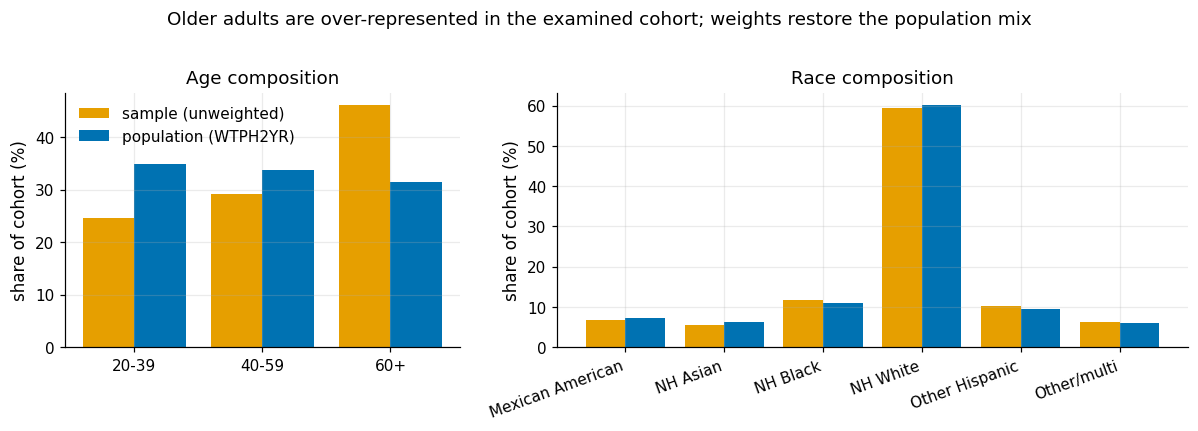

In [134]:
band_s = S.age_band(d["RIDAGEYR"]).to_numpy()
rep_rows = []
for dim, vals in [("age", band_s), ("race", d["race3"].to_numpy())]:
    for lev in pd.unique(vals):
        m = vals == lev
        rep_rows.append({"dimension": dim, "level": lev, "n": int(m.sum()), "sample_share": m.mean(),
                         "weighted_share": d.loc[m, WT].sum() / d[WT].sum()})
rep = pd.DataFrame(rep_rows).sort_values(["dimension", "level"]).reset_index(drop=True)
rep["diff_pp"] = 100 * (rep["sample_share"] - rep["weighted_share"])
print(rep.round(3).to_string(index=False))
deff = S.kish_deff(d[WT])
unw_prev = d["L_comb"].mean()
print(f"\nKish design effect of WTPH2YR: {deff:.2f} (effective n ≈ {len(d) / deff:,.0f}); "
      f"L_comb unweighted {pct(unw_prev)} vs weighted {pct(w_prev['est'])}")
RP = rep.set_index(["dimension", "level"])
close(RP.loc[("age", "60+"), "sample_share"], 0.462, 0.001, "60+ sample"); close(RP.loc[("age", "60+"), "weighted_share"], 0.314, 0.001, "60+ weighted")
close(RP.loc[("age", "20-39"), "sample_share"], 0.247, 0.001, "20-39 sample"); close(RP.loc[("age", "20-39"), "weighted_share"], 0.348, 0.001, "20-39 weighted")
close(deff, 1.55, 0.01, "Kish deff")
age_explained = R.load_section("S4")["prevalence"]["gap_explained_by_age"]   # S4: sample rates re-weighted to the population age mix
print(f"S4: age structure explains {100 * age_explained:.0f}% of the {100 * (unw_prev - w_prev['est']):.1f} pp unweighted-weighted gap")
close(age_explained, 0.84, 0.01, "share of gap explained by age (S4)")

# Response rates are documented by NCHS, not derivable from public files (S2 provenance; NHANES 2021-2023
# overview brief, https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/overviewbrief.aspx?Cycle=2021-2023).
RESPONSE = {"interview_unweighted": 0.346, "exam_unweighted": 0.257}
print(f"documented response rates: interview {pct(RESPONSE['interview_unweighted'])}, exam {pct(RESPONSE['exam_unweighted'])}")

merged = NIO.load_merged()
merged.attrs = {}
# Domains are masks on the full 11,933-row design (weights zeroed outside), never row subsets, so every
# jackknife replicate keeps all strata and PSUs.
merged["self_dm"] = merged["DIQ010"].eq(1).astype(float).where(merged["DIQ010"].notna())
adult = (merged["RIDAGEYR"] >= C.ADULT_MIN_AGE).to_numpy()
io_mask = adult & merged["RIDSTATR"].eq(1).to_numpy()
a1c_mask = adult & (merged["RIDSTATR"].eq(2) & merged["LBXGH"].notna()).to_numpy()
p_io = S.weighted_prop(merged, "self_dm", weight=C.WEIGHT_INTERVIEW, domain=io_mask)
p_a1c = S.weighted_prop(merged, "self_dm", weight=C.WEIGHT_INTERVIEW, domain=a1c_mask)
rd_sel = risk_difference(merged, "self_dm", a1c_mask, io_mask, weight=C.WEIGHT_INTERVIEW)
print(f"self-reported diabetes (WTINT2YR): interview-only adults {kg_text(p_io)}")
print(f"                                   adults with HbA1c   {kg_text(p_a1c)}")
print(f"difference with HbA1c - interview-only: {100 * rd_sel['est']:+.1f} pp ({100 * rd_sel['ci_low']:.1f}, {100 * rd_sel['ci_high']:.1f})")
close(p_io["est"], 0.088, 0.0015, "interview-only self-report"); close(p_a1c["est"], 0.117, 0.0015, "with-A1c self-report")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
for ax, dim in zip(axes, ["age", "race"]):
    rr = rep[rep["dimension"] == dim]
    x = np.arange(len(rr))
    ax.bar(x - 0.2, rr["sample_share"] * 100, 0.4, label="sample (unweighted)", color=plots.PALETTE[0])
    ax.bar(x + 0.2, rr["weighted_share"] * 100, 0.4, label="population (WTPH2YR)", color=plots.PALETTE[4])
    ax.set_xticks(x, rr["level"], rotation=0 if dim == "age" else 20, ha="center" if dim == "age" else "right")
    ax.set(ylabel="share of cohort (%)", title=f"{dim.capitalize()} composition")
axes[0].legend()
fig.suptitle("Older adults are over-represented in the examined cohort; weights restore the population mix", y=1.02)
fig.tight_layout()
plots.savefig(fig, "S5_representation",
              caption="Sample versus WTPH2YR-weighted composition of the 5,730-adult cohort by age band and race/ethnicity.")
plt.show()

rep.to_csv(OUT / "representation.csv", index=False)
RES["representation"] = {
    "shares": {f"{a}|{b}": v for (a, b), v in RP[["n", "sample_share", "weighted_share"]].to_dict("index").items()},
    "kish_deff": deff, "n_eff_kish": len(d) / deff, "L_comb_unweighted": unw_prev,
    "response_rates_documented": RESPONSE,
    "self_dm_interview_only": {k: p_io[k] for k in ("est", "kg_low", "kg_high", "n")},
    "self_dm_with_a1c": {k: p_a1c[k] for k in ("est", "kg_low", "kg_high", "n")},
    "selection_rd": {"est": rd_sel["est"], "ci_low": rd_sel["ci_low"], "ci_high": rd_sel["ci_high"]},
}
register("DR-S5-07", "representation",
         "Cohort over-represents older adults; exam participants report more diabetes than interview-only adults",
         "results/S5/representation.csv; figures/S5_representation.png",
         f"60+: sample {pct(RP.loc[('age', '60+'), 'sample_share'])} vs weighted {pct(RP.loc[('age', '60+'), 'weighted_share'])}; "
         f"Kish deff {deff:.2f}; self-report interview-only {pct(p_io['est'])} vs with HbA1c {pct(p_a1c['est'])}; response 34.6%/25.7%",
         "Descriptive population estimates use WTPH2YR with PSU jackknife; survey-weighted training only as ablation B6b; claims scoped to the examined population",
         "Treat the unweighted sample as the population; claim national representativeness of model metrics")

**So what.** Adults aged 60+ make up 46.2 % of the sample but 31.4 % of the weighted population (20–39: 24.7 %
vs 34.8 %); race shares differ by at most about one percentage point because this cycle no longer oversamples by
race. The age skew is the main reason why the unweighted `L_comb` prevalence (16.9 %) exceeds the weighted 14.0 %:
re-weighting the sample rates to the population age mix closes about 84 % of the 2.9 pp gap (S4); the rest
reflects other weighting factors.
Unequal weights cost precision (Kish design effect 1.55, effective n ≈ 3,700). With response rates of 34.6 %
(interview) and 25.7 % (exam), selection matters: interview-only adults report diabetes less often (8.8 %)
than adults with an HbA1c result (11.7 %). Weights correct for known covariates such as age, not for
health-related participation, so model metrics describe the examined population.

## 5.7 HbA1c missingness bias

**Why.** The cohort requires an HbA1c result. If HbA1c is missing more often in some groups and for health
reasons, the label is missing not at random. We compare missingness among examined adults by race, compare MEC- and phlebotomy-weighted prevalence (WTPH2YR already contains a blood-draw non-response
adjustment), and bound the `L_comb` prevalence without any assumption on the missing values (Manski bounds).
Self-report is observed for most adults without HbA1c, so the bounds are sharper than the naive width m.

In [135]:
# Missingness by race on all examined adults (the S3 definition); Manski bounds below on the cohort universe
# (examined, non-pregnant adults).
merged["a1c_missing"] = merged["LBXGH"].isna().astype(float)
merged["race3"] = merged["RIDRETH3"].map(RACE)
exam = adult & merged["RIDSTATR"].eq(2).to_numpy()                      # all examined adults (S3 definition)
coh_univ = exam & ~merged["RIDEXPRG"].eq(1).to_numpy()                   # cohort universe: examined, not pregnant
miss_rows = []
for g in sorted(merged.loc[exam, "race3"].unique()):
    m = exam & merged["race3"].eq(g).to_numpy()
    w = S.weighted_prop(merged, "a1c_missing", weight=C.WEIGHT_MEC, domain=m)
    miss_rows.append({"race3": g, "examined": int(m.sum()), "missing": int(merged.loc[m, "a1c_missing"].sum()),
                      "missing_share": merged.loc[m, "a1c_missing"].mean(), "w_missing_share": w["est"],
                      "kg_low": w["kg_low"], "kg_high": w["kg_high"], "df": w["df"]})
miss = pd.DataFrame(miss_rows).set_index("race3")
print(miss.round(3))
rd_miss = risk_difference(merged, "a1c_missing", exam & merged["race3"].eq("NH Black").to_numpy(),
                          exam & merged["race3"].eq("NH White").to_numpy(), weight=C.WEIGHT_MEC)
print(f"missing HbA1c, NH Black - NH White (WTMEC2YR, JK): {100 * rd_miss['est']:+.1f} pp "
      f"({100 * rd_miss['ci_low']:.1f}, {100 * rd_miss['ci_high']:.1f})")
close(miss.loc["NH Black", "missing_share"], 0.093, 0.0015, "Black missing"); close(miss.loc["NH White", "missing_share"], 0.040, 0.0015, "White missing")

prev_mec = np.average(d["L_comb"], weights=d[C.WEIGHT_MEC])
print(f"\nL_comb prevalence: WTMEC2YR-weighted {pct(prev_mec)} vs WTPH2YR-weighted {pct(w_prev['est'])}")
close(prev_mec, 0.139, 0.0015, "MEC-weighted prevalence")

# Manski bounds on L_comb prevalence among examined adults (WTMEC2YR): missing HbA1c rows with self-reported
# diabetes are known positives; the rest could be anything.
known_pos = (merged["LBXGH"].ge(C.HBA1C_DIABETES) | merged["DIQ010"].eq(1)).astype(float).to_numpy()
unknown = (merged["LBXGH"].isna() & ~merged["DIQ010"].eq(1)).astype(float).to_numpy()
observed = merged["LBXGH"].notna().to_numpy()
w_mec = merged[C.WEIGHT_MEC].fillna(0).to_numpy()
man = []
for g in ["all", *sorted(merged.loc[coh_univ, "race3"].unique())]:
    m = coh_univ if g == "all" else coh_univ & merged["race3"].eq(g).to_numpy()
    lo = np.average(known_pos[m], weights=w_mec[m])
    unk = np.average(unknown[m], weights=w_mec[m])
    man.append({"group": g, "observed_prev": np.average(known_pos[m & observed], weights=w_mec[m & observed]),
                "lower": lo, "upper": lo + unk, "width": unk,
                "naive_width_m": np.average(merged["a1c_missing"].to_numpy()[m], weights=w_mec[m])})
manski = pd.DataFrame(man).set_index("group")
print("\nManski bounds for L_comb prevalence (WTMEC2YR, examined non-pregnant adults)")
print(manski.round(3))
miss.to_csv(OUT / "a1c_missingness.csv")
manski.to_csv(OUT / "manski_bounds.csv")
RES["missingness"] = {"by_race": miss.to_dict("index"),
                      "black_minus_white_rd": {k: rd_miss[k] for k in ("est", "ci_low", "ci_high", "df")}, "prev_mec": prev_mec, "prev_ph": w_prev["est"],
                      "manski": manski.to_dict("index")}
register("DR-S5-08", "missingness",
         "HbA1c is missing more often for NH Black adults; WTPH2YR adjustment changes prevalence by 0.1 pp",
         "results/S5/a1c_missingness.csv; results/S5/manski_bounds.csv",
         f"missing HbA1c: Black {pct(miss.loc['NH Black', 'missing_share'])} vs White {pct(miss.loc['NH White', 'missing_share'])}; "
         f"prevalence MEC {pct(prev_mec)} vs PH {pct(w_prev['est'])}; Manski width overall {manski.loc['all', 'width']:.3f}",
         "Keep complete-case cohort with WTPH2YR; report Manski bounds; IPW sensitivity deferred to S9",
         "Impute HbA1c (would impute the label); ignore missingness")

                  examined  missing  missing_share  w_missing_share  kg_low  kg_high  df
race3                                                                                   
Mexican American       405       16          0.040            0.044   0.025    0.072  14
NH Asian               335       20          0.060            0.058   0.023    0.117  14
NH Black               753       70          0.093            0.089   0.068    0.114  15
NH White              3569      142          0.040            0.040   0.029    0.054  15
Other Hispanic         614       26          0.042            0.044   0.023    0.077  15
Other/multi            388       23          0.059            0.073   0.036    0.127  15
missing HbA1c, NH Black - NH White (WTMEC2YR, JK): +4.9 pp (2.9, 6.9)

L_comb prevalence: WTMEC2YR-weighted 13.9% vs WTPH2YR-weighted 14.0%

Manski bounds for L_comb prevalence (WTMEC2YR, examined non-pregnant adults)
                  observed_prev  lower  upper  width  naive_width_m
gr

**So what.** HbA1c is missing for 9.3 % of examined NH Black adults versus 4.0 % of NH White adults (weighted
difference +4.9 pp, jackknife CI 2.9–6.9), so the label is less often observed in one group. The phlebotomy weights already adjust for blood-draw non-response:
prevalence moves from 13.9 % (MEC weight) to 14.0 % (WTPH2YR). Without any assumption on the missing values the
overall `L_comb` prevalence among examined non-pregnant adults lies between 13.9 % and 18.1 % (width 0.042,
narrower than the naive 0.049 because missing-HbA1c adults who self-report diabetes are known positives); for
NH Black adults the bounds are 21.5–28.4 % (width 0.069) against 12.4–15.9 % for NH White adults. The cohort stays complete-case
with WTPH2YR; an inverse-probability-weighting sensitivity check is assigned to S9.

## 5.8 Decision gate L2 and target freeze

**Why.** Loop L2 (process doc §4) sends the project back to S1 if the label audit changes the question. Four
criteria decide whether `L_comb` can be frozen. They are evaluated **after** seeing the data (post-hoc), so they
are a documented judgement, not a pre-registered test. The freeze then fixes the target, the second primary
evaluation population E-SCREEN, the 3×3 label-matrix strata and the sensitivity labels SL1–SL7, written as
executable definitions in `governance/label_freeze.md` (all point to `src/labels.py`).

In [136]:
spec = NIO.load_spec()
TARGET_PARTS = ["LBXGH", "DIQ010", "DIQ050", "DIQ070", "DID040", "DID060", "DIQ160", "DIQ180", "LBXGLU"]
adm = spec[spec["var"].isin(TARGET_PARTS)].drop_duplicates("var").set_index("var")["admissible"].astype(str)
assert set(adm.index) == set(TARGET_PARTS), set(TARGET_PARTS) - set(adm.index)
c2_bad = adm[adm.str.upper().isin(["T1", "T2"])]
race_pos = d.groupby("race3")[["L_comb", "L_A1c"]].sum()
sl = L.sensitivity_labels(d)
c1 = {"self_missed": miss_self / n_comb, "a1c_missed": miss_a1c / n_comb, "kappa": unw["kappa"], "pa": unw["pa"], "na": unw["na"]}
gate = pd.DataFrame([
    {"criterion": "C1 descriptive evidence: each single instrument misses a material share of the union",
     "evidence": f"L_self misses {miss_self}/{n_comb} = {pct(c1['self_missed'])}; L_A1c misses {miss_a1c}/{n_comb} = {pct(c1['a1c_missed'])}; "
                 f"kappa {c1['kappa']:.2f}, PA {c1['pa']:.2f}, NA {c1['na']:.2f}",
     "verdict": "PASS (union justified; post-hoc judgement)"},
    {"criterion": "C2 no admissible feature is a component of the target",
     "evidence": f"variable_spec admissible flag of {', '.join(TARGET_PARTS)}: {sorted(set(adm.fillna('missing')))}",
     "verdict": "PASS" if c2_bad.empty else f"FAIL: {list(c2_bad.index)}"},
    {"criterion": "C3 >= 500 positives overall and >= 40 in the smallest reported group",
     "evidence": f"L_comb {n_comb}; smallest race group (L_comb) {race_pos['L_comb'].idxmin()} {int(race_pos['L_comb'].min())}; "
                 f"NH Asian L_comb {int(race_pos.loc['NH Asian', 'L_comb'])}, L_A1c {int(race_pos.loc['NH Asian', 'L_A1c'])}",
     "verdict": "PASS (NH Asian under L_A1c exactly at the line: descriptive only)"},
    {"criterion": "C4 borderline coding handled as sensitivity",
     "evidence": f"borderline positive (SL3): {int(sl['SL3'].sum())} positives vs {n_comb}",
     "verdict": "PASS (borderline negative + flagged; SL3 as sensitivity)"},
])
print(gate.to_string(index=False))
assert c2_bad.empty and n_comb >= 500 and race_pos["L_comb"].min() >= 40 and race_pos.loc["NH Asian", "L_A1c"] >= 40
assert int(sl["SL3"].sum()) == 1148
close(c1["self_missed"], 0.157, 0.001, "C1 self missed"); close(c1["a1c_missed"], 0.257, 0.001, "C1 A1c missed")
gate.to_csv(OUT / "l2_gate.csv", index=False)

                                                                           criterion                                                                                                      evidence                                                           verdict
C1 descriptive evidence: each single instrument misses a material share of the union                     L_self misses 152/971 = 15.7%; L_A1c misses 250/971 = 25.7%; kappa 0.70, PA 0.74, NA 0.96                        PASS (union justified; post-hoc judgement)
                               C2 no admissible feature is a component of the target variable_spec admissible flag of LBXGH, DIQ010, DIQ050, DIQ070, DID040, DID060, DIQ160, DIQ180, LBXGLU: ['N']                                                              PASS
                C3 >= 500 positives overall and >= 40 in the smallest reported group                            L_comb 971; smallest race group (L_comb) NH Asian 50; NH Asian L_comb 50, L_A1c 40 PASS (NH Asian under L

**E-SCREEN, 3×3 strata and sensitivity labels.** The frozen definitions are computed once more from
`src/labels.py` and compared with the counts written into `governance/label_freeze.md`, so the document and
the code cannot drift apart.

3x3 evaluation strata: {'D_uncontrolled': 569, 'D_controlled': 250, 'Undiagnosed': 152, 'NonDiabetic': 4759}
E-SCREEN: {'n': 4911, 'positives': 152, 'negatives': 4759, 'borderline_in_escreen': 213, 'borderline_positive': 36}
label                                                    definition    n  positives  prev_unweighted   weight  w_prev  w_ci_low  w_ci_high
  SL1                                                    L_A1c only 5730        721            0.126  WTPH2YR   0.105     0.092      0.119
  SL2                                                   L_self only 5730        819            0.143  WTPH2YR   0.118     0.102      0.133
  SL3                                   borderline counted positive 5730       1148            0.200  WTPH2YR   0.167     0.149      0.184
  SL4 treatment-aware (A1c or treated self-report, DIQ070 universe) 5730        886            0.155  WTPH2YR   0.128     0.113      0.143
  SL5  NCHS: self-report or A1c>=6.5 or FPG>=126, fasting subsample 2938        

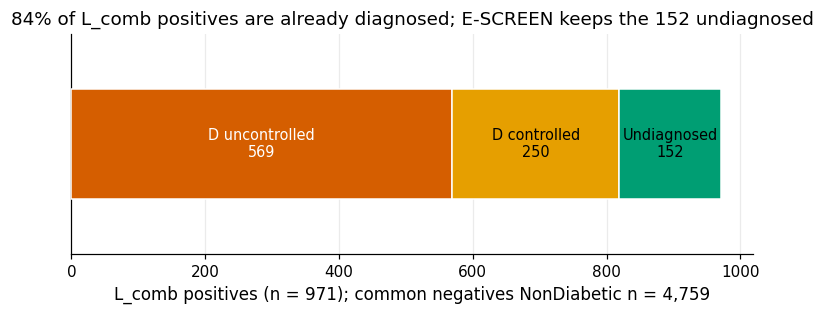

In [137]:
strata = L.strata_counts(d)
esc = d[d["in_escreen"] == 1]
esc_counts = {"n": len(esc), "positives": int(esc["y_escreen"].sum()), "negatives": int((esc["y_escreen"] == 0).sum()),
              "borderline_in_escreen": int(esc["borderline"].sum()),
              "borderline_positive": int(((esc["borderline"] == 1) & (esc["y_escreen"] == 1)).sum())}
print("3x3 evaluation strata:", strata)
print("E-SCREEN:", esc_counts)
assert strata == {"D_uncontrolled": 569, "D_controlled": 250, "Undiagnosed": 152, "NonDiabetic": 4759}
assert esc_counts["positives"] == 152 and esc_counts["borderline_positive"] == 36

fm = L.fasting_mask(d)
sl_rows = []
for col, desc, wcol in [("SL1", "L_A1c only", WT), ("SL2", "L_self only", WT), ("SL3", "borderline counted positive", WT),
                        ("SL4", "treatment-aware (A1c or treated self-report, DIQ070 universe)", WT),
                        ("SL5", "NCHS: self-report or A1c>=6.5 or FPG>=126, fasting subsample", C.WEIGHT_FASTING)]:
    w = S.weighted_prop(d.assign(_y=sl[col]), "_y", weight=wcol)
    sl_rows.append({"label": col, "definition": desc, "n": int(sl[col].notna().sum()), "positives": int(sl[col].sum()),
                    "prev_unweighted": sl[col].mean(), "weight": wcol, "w_prev": w["est"], "w_ci_low": w["ci_low"], "w_ci_high": w["ci_high"]})
sl_tab = pd.DataFrame(sl_rows)
print(sl_tab.round(3).to_string(index=False))
univ = L.diq070_universe(d)
pills_by_status = d[d["DIQ070"].eq(1)].groupby(d["DIQ010"].map({1: "diagnosed", 2: "no (told prediabetes)", 3: "borderline"})).size()
print("DIQ070 = 1 by DIQ010:", pills_by_status.to_dict(), f"; DIQ070 universe n = {int(univ.sum())}")
SLT = sl_tab.set_index("label")
assert SLT["positives"].tolist() == [721, 819, 1148, 886, int(SLT.loc["SL5", "positives"])]
assert pills_by_status.to_dict() == {"borderline": 44, "diagnosed": 592, "no (told prediabetes)": 41}
close(SLT.loc["SL5", "w_prev"], 0.158, 0.006, "SL5 vs NCHS DB516 15.8%")

freeze_path = C.GOVERNANCE_DIR / "label_freeze.md"
freeze_text = freeze_path.read_text(encoding="utf-8")
frozen = json.loads(freeze_text.split("```json")[1].split("```")[0])
computed = {"N": len(d), "L_comb": n_comb, "L_self": int(d["L_self"].sum()), "L_A1c": int(d["L_A1c"].sum()),
            "strata_3x3": strata, "escreen_positives": esc_counts["positives"], "escreen_negatives": esc_counts["negatives"],
            "escreen_borderline_positive": esc_counts["borderline_positive"],
            "SL_positives": {k: int(v) for k, v in SLT["positives"].items()}, "SL5_n": int(SLT.loc["SL5", "n"])}
assert frozen == computed, {k: (frozen.get(k), v) for k, v in computed.items() if frozen.get(k) != v}
freeze_sha = hashlib.sha256(freeze_path.read_bytes()).hexdigest()
print(f"label_freeze.md counts match the code; SHA-256 {freeze_sha[:16]}…")

fig, ax = plt.subplots(figsize=(8, 2.6))
cols = [plots.PALETTE[5], plots.PALETTE[0], plots.PALETTE[2]]
left = 0
for k, col in zip(L.POSITIVE_STRATA, cols):
    ax.barh(0, strata[k], left=left, height=0.5, color=col, edgecolor="white", zorder=3)
    ax.text(left + strata[k] / 2, 0, f"{k.replace('_', ' ')}\n{strata[k]}", ha="center", va="center", fontsize=9.5,
            color="white" if k == "D_uncontrolled" else "black", zorder=4)
    left += strata[k]
ax.set_yticks([])
ax.grid(axis="y", visible=False)
known = strata["D_uncontrolled"] + strata["D_controlled"]
ax.set(xlabel=f"L_comb positives (n = {n_comb}); common negatives NonDiabetic n = {strata['NonDiabetic']:,}", ylim=(-0.5, 0.5),
       title=f"{pct(known / n_comb, 0)} of L_comb positives are already diagnosed; E-SCREEN keeps the {strata['Undiagnosed']} undiagnosed")
plots.savefig(fig, "S5_label_strata", caption="Composition of the 971 L_comb positives by self-report and HbA1c; "
              "D_uncontrolled 569, D_controlled 250, Undiagnosed 152 (= E-SCREEN positives).")
plt.show()

sl_tab.to_csv(OUT / "sensitivity_labels.csv", index=False)
RES["freeze"] = {"target": "L_comb = (DIQ010 == 1) | (LBXGH >= 6.5)", "N": len(d), "gate": gate.set_index("criterion")["verdict"].to_dict(),
                 "gate_posthoc": True, "strata_3x3": strata, "escreen": esc_counts,
                 "sensitivity_labels": sl_tab.set_index("label")[["n", "positives", "prev_unweighted", "w_prev", "weight"]].to_dict("index"),
                 "known_dx_share_of_positives": strata["D_uncontrolled"] / n_comb + strata["D_controlled"] / n_comb,
                 "label_freeze_sha256": freeze_sha}
register("DR-S5-01", "target_freeze",
         "L2 gate C1-C4 passes (post-hoc); the union label is the least biased single target",
         "results/S5/l2_gate.csv; governance/label_freeze.md",
         f"L_comb {n_comb} positives ({pct(n_comb / len(d))}; weighted {pct(w_prev['est'])}); C1 15.7%/25.7% missed by single labels; "
         f"C3 Asian L_comb {int(race_pos.loc['NH Asian', 'L_comb'])}",
         "Freeze L_comb = DIQ010==1 or LBXGH>=6.5 on N=5,730 (tag target-freeze); any change requires a register entry and reopening L2",
         "Freeze L_self (misses 152 undiagnosed); freeze L_A1c (misses 250 controlled); borderline positive (SL3, kept as sensitivity)",
         loop_ref="L2", check_note="Gate recomputed in section 5.8; post-hoc nature stated")
register("DR-S5-09", "evaluation_population",
         "84% of L_comb positives are already diagnosed, so E-ALL measures recognition of known disease",
         "governance/label_freeze.md; figures/S5_label_strata.png",
         f"E-SCREEN: {esc_counts['n']} adults, {esc_counts['positives']} positives vs {esc_counts['negatives']} negatives; "
         f"borderline kept with {esc_counts['borderline_positive']} positive; 3x3 strata 569/250/152/4759",
         "E-SCREEN (DIQ010!=1, y = HbA1c>=6.5) is a co-primary evaluation population next to E-ALL; 3x3 label matrix (SL6) evaluated in S8 at specificity 0.80",
         "Evaluate on E-ALL only; train on E-SCREEN only (152 events too few)", loop_ref="L2")
register("DR-S5-10", "sensitivity_labels",
         "Label definition is a researcher degree of freedom; robustness needs pre-specified alternatives",
         "results/S5/sensitivity_labels.csv; governance/label_freeze.md",
         "SL1 721, SL2 819, SL3 1,148, SL4 886, SL5 " + f"{int(SLT.loc['SL5', 'positives'])}/{int(SLT.loc['SL5', 'n'])} (weighted {pct(SLT.loc['SL5', 'w_prev'])})",
         "Freeze SL1-SL7 as executable definitions (src/labels.py); SL4 uses only the DIQ070 universe and excludes pills of non-diagnosed respondents; S9 reports results under SL1-SL5, S8 runs SL6, S9 runs SL7",
         "Ad-hoc relabelling after seeing model results; DIQ070 pills as diabetes for all respondents (would count pills plausibly taken for prediabetes, e.g. metformin)")

**So what.** All four gate criteria pass; we state explicitly that this is a post-hoc judgement made after
seeing the data. Each single instrument misses a material share of the union (15.7 % and 25.7 %), no admissible
feature is part of the target, every race group has at least 40 positives (NH Asian: 50 under `L_comb`, exactly
40 under `L_A1c`, so Asian results stay descriptive), and the borderline coding is handled by SL3 (1,148
positives). **`L_comb` is frozen** (`target-freeze`).

The 971 positives split into 569 uncontrolled and 250 controlled known diabetics and 152 undiagnosed adults:
84 % of all positives are already diagnosed, so an AUC on E-ALL largely measures recognition of known disease.
E-SCREEN (adults not reporting diabetes; 152 HbA1c-positive vs 4,759 negatives, borderline respondents kept
and flagged, 36 of them positive) is therefore a co-primary evaluation population, and S8 evaluates every
training label on each 3×3 column against the common 4,759 negatives. The sensitivity labels behave as
expected: the treatment-aware SL4 (886) sits between `L_A1c` and `L_comb`, and the NCHS definition SL5 on the
fasting subsample reproduces the published 15.8 % prevalence closely, which anchors our label pipeline to an
external benchmark.

**Status of the S5 hypotheses.** Three entries of `governance/hypotheses.md` are checked in this section. All
three were written after the data had been analysed (`analysis_seen` / `descriptive_seen`), so a "supported"
verdict here confirms a reproduced description; it is not confirmatory evidence.

In [138]:
from statsmodels.stats.proportion import confint_proportions_2indep

ka, na_ = int(bmi_dm.loc["NH Asian", "bmi_lt25"]), int(bmi_dm.loc["NH Asian", "diabetics_with_bmi"])
kw, nw = int(bmi_dm.loc["NH White", "bmi_lt25"]), int(bmi_dm.loc["NH White", "diabetics_with_bmi"])
h4a_lo, h4a_hi = confint_proportions_2indep(ka, na_, kw, nw, method="newcomb", compare="diff")
h4a = ka / na_ - kw / nw
rd_bmi = risk_difference(d.assign(bmi_lt25=(d["BMXBMI"] < 25).astype(float).where(d["BMXBMI"].notna())), "bmi_lt25",
                         ((d["RIDRETH3"] == 6) & (d["L_comb"] == 1)).to_numpy(), ((d["RIDRETH3"] == 3) & (d["L_comb"] == 1)).to_numpy())
g_as, g_wh = RO.loc[("NH Asian", "WHtR − BMI (paired)")], RO.loc[("NH White", "WHtR − BMI (paired)")]
rd_un = RD.loc["uninsured - insured"]
hyp = pd.DataFrame([
    {"hyp_id": "H1a", "estimate": f"RD uninsured - insured {rd_un['rd_pp']:+.1f} pp ({rd_un['ci_low_pp']:.1f}, {rd_un['ci_high_pp']:.1f})",
     "rule": "lower CI bound > 0", "verdict": "supported" if rd_un["ci_low_pp"] > 0 else "inconclusive",
     "note": "uninsured share exploratory (KG width >= 0.30)"},
    {"hyp_id": "H4a", "estimate": f"BMI<25 among diabetics, Asian - White {100 * h4a:+.1f} pp (Newcombe {100 * h4a_lo:.1f}, {100 * h4a_hi:.1f}); "
                                  f"weighted {100 * rd_bmi['est']:+.1f} pp (JK {100 * rd_bmi['ci_low']:.1f}, {100 * rd_bmi['ci_high']:.1f})",
     "rule": "difference >= 20 pp with CI above 20 pp",
     "verdict": "supported" if h4a_lo >= 0.20 else ("inconclusive" if h4a >= 0.20 else "refuted"),
     "note": "47 Asian diabetics with BMI: exploratory"},
    {"hyp_id": "H4b", "estimate": f"WHtR - BMI gain Asian {g_as['auc']:+.3f} ({g_as['ci_low']:.3f}, {g_as['ci_high']:.3f}) vs "
                                  f"White {g_wh['auc']:+.3f} ({g_wh['ci_low']:.3f}, {g_wh['ci_high']:.3f}); difference CI "
                                  f"(person {gain_diff.quantile(.025):+.3f}, {gain_diff.quantile(.975):+.3f}; "
                                  f"PSU {np.quantile(psu_diff, .025):+.3f}, {np.quantile(psu_diff, .975):+.3f})",
     "rule": "Asian gain larger and CIs not fully overlapping",
     "verdict": "supported" if (g_as["auc"] > g_wh["auc"] and g_as["ci_low"] > g_wh["ci_low"] and np.quantile(psu_diff, .025) > 0) else "inconclusive",
     "note": "descriptive_seen; confirmatory test of the WHtR arm is P14 in S8"},
])
print(hyp.to_string(index=False))
assert hyp["verdict"].tolist() == ["supported", "supported", "supported"]
hyp.to_csv(OUT / "hypothesis_checks.csv", index=False)
RES["hypotheses"] = hyp.set_index("hyp_id").to_dict("index")
for r in REG:   # link register rows to the hypotheses they inform
    r["hyp_id"] = {"DR-S5-05": "H1a", "DR-S5-06": "H4a; H4b", "DR-S5-09": "H2c; H3"}.get(r["dr_id"], r["hyp_id"])

# prior_exposure of every hypothesis, read from the locked governance/hypotheses.md
_rows = [ln.split("|") for ln in (C.GOVERNANCE_DIR / "hypotheses.md").read_text(encoding="utf-8").splitlines()
         if ln.startswith("| H") and not ln.startswith("| hyp_id")]
prior = {r[1].strip(): r[9].strip() for r in _rows if len(r) > 10}
print("prior_exposure:", prior)
genuine = sorted(h for h, p in prior.items() if p == "none")
print("genuinely pre-registered (prior_exposure = none):", genuine)
assert {"H2b", "H2c", "H3"} <= set(genuine) and prior.get("H2a") == "analysis_seen"

hyp_id                                                                                                                              estimate                                            rule   verdict                                                             note
   H1a                                                                                           RD uninsured - insured +23.2 pp (6.2, 40.1)                              lower CI bound > 0 supported                   uninsured share exploratory (KG width >= 0.30)
   H4a                               BMI<25 among diabetics, Asian - White +43.9 pp (Newcombe 29.8, 57.7); weighted +43.4 pp (JK 23.2, 63.5)         difference >= 20 pp with CI above 20 pp supported                         47 Asian diabetics with BMI: exploratory
   H4b WHtR - BMI gain Asian +0.137 (0.093, 0.181) vs White +0.049 (0.039, 0.058); difference CI (person +0.044, +0.135; PSU +0.035, +0.116) Asian gain larger and CIs not fully overlapping supported descripti

**So what.** H1a (uninsured adults more often undiagnosed), H4a (BMI < 25 far more common among Asian
diabetics) and H4b (larger WHtR gain in Asian adults) are reproduced with intervals that satisfy their
pre-stated rules, with the caveats printed above. Because the hypotheses were written after seeing these data,
they are recorded as *supported (analysis_seen)*. The genuinely pre-registered tests (`prior_exposure = none`)
are H2b, H2c and H3 in S7/S8; H2a (leakage gate) is `analysis_seen` and the WHtR arm P14 is `descriptive_seen`.

In [139]:
reg_df = pd.DataFrame(REG).sort_values("dr_id").reset_index(drop=True)
reg_path = C.GOVERNANCE_DIR / "register" / "S5.csv"
reg_path.parent.mkdir(parents=True, exist_ok=True)
reg_df.to_csv(reg_path, index=False, lineterminator="\n")
R.save_section("S5", RES)
print(f"{len(reg_df)} register rows -> {reg_path.relative_to(C.ROOT).as_posix()}; results -> results/metrics_S5.json")
print(reg_df[["dr_id", "type", "decision"]].to_string(index=False))

10 register rows -> governance/register/S5.csv; results -> results/metrics_S5.json


   dr_id                  type                                                                                                                                                                                                decision
DR-S5-01         target_freeze                                                                           Freeze L_comb = DIQ010==1 or LBXGH>=6.5 on N=5,730 (tag target-freeze); any change requires a register entry and reopening L2
DR-S5-02           label_audit                                                                                Use the union L_comb as training target; report PA/NA next to kappa; keep L_self and L_A1c as sensitivity labels SL2/SL1
DR-S5-03            label_bias                                                                        Reject L_A1c as the sole target; keep stratum D_controlled as a 3x3 evaluation column; medication is audit-only (post-diagnosis)
DR-S5-04       label_semantics                                 Frame E-SCRE

# §6 Preparation Design (Stage S6)

This section turns the findings of S3–S5 into **fourteen switchable preparation steps** (P01–P14),
groups them into **six reporting blocks** (B1–B6) and fixes the **arms** that S7 compares:

* **M0** – the naive analyst: every column except id/design/label, blanket recode of 7/9/77/99/…,
  median imputation, one-hot encoding, logistic regression. Leakage included.
* **M1** – M0 plus the availability rule only (P03). *Minimal but honest.*
* **S** – all steps on (P14 WHtR stays a separate arm).

The headline "minimal vs systematic" comparison is **M1 vs S** (same model); **M0 → M1 is the
leak gate**. The pre-registered hypotheses for the blocks are locked here, before any ablation.

Contents: 1 inputs · 2 step catalogue · 3 B1 integrity · 4 B2 admissibility · 5 B3 redundancy ·
6 B4 missingness · 7 B5 representation · 8 B6 weights · 9 arms · 10 pipeline assertions ·
11 hypotheses and lock · 12 decisions and storage

In [140]:
new_section()

In [141]:
import hashlib, json, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek

pd.set_option("display.width", 160, "display.max_columns", 30, "display.max_colwidth", 80)
OUT = C.RESULTS_DIR / "S6"
OUT.mkdir(parents=True, exist_ok=True)
S6 = {}

## 6.1 Inputs
**Why.** Every preparation decision must happen *inside* the model pipeline so that it is refitted in
each training fold. The pipeline therefore receives the **raw** cohort (XPT artefact not repaired,
no sentinel recode) and the naive column set. The frozen evaluation label `L_comb` comes from the
per-variable cohort (S5). Descriptive design statistics below use the **training part** only: the
20 % hold-out (label × race stratified, `evalkit.make_holdout`, created once and persisted) is not
looked at until S9.

In [142]:
raw = P.raw_cohort()
clean = L.add_labels(io.build_cohort())
assert (raw["SEQN"].to_numpy() == clean["SEQN"].to_numpy()).all()
train_idx, test_idx = ek.make_holdout(clean)
raw_tr, clean_tr = raw.iloc[train_idx].reset_index(drop=True), clean.iloc[train_idx].reset_index(drop=True)
X1, X2 = P.raw_feature_frame(raw, 1), P.raw_feature_frame(raw, 2)
X1_tr, X2_tr = X1.iloc[train_idx].reset_index(drop=True), X2.iloc[train_idx].reset_index(drop=True)
spec = P._spec_by_var()
roles = spec.loc[X2.columns, ["role", "admissible", "dtype"]].value_counts(["role", "admissible"]).rename("n_columns")
print(f"cohort {len(raw):,} rows; training part {len(train_idx):,}, hold-out {len(test_idx):,} (not used here)")
print(f"naive feature frame: Tier 1 {X1.shape[1]} columns, Tier 2 {X2.shape[1]} columns")
print(roles.to_string())
S6["inputs"] = dict(n_cohort=len(raw), n_train=len(train_idx), n_holdout=len(test_idx),
                    n_raw_cols_t1=X1.shape[1], n_raw_cols_t2=X2.shape[1])

cohort 5,730 rows; training part 4,584, hold-out 1,146 (not used here)
naive feature frame: Tier 1 52 columns, Tier 2 54 columns
role           admissible
feature        T1            30
leak           N              8
optional       N              5
audit          N              3
feature        T2             2
cohort_filter  N              2
redundancy     N              2
side           N              2


**So what.** A naive analyst hands the model 52 (Tier 1) or 54 (Tier 2) columns, and the role table shows
what that includes: leakage items (glucose, treatment, age at diagnosis, DIQ160/DIQ180),
audit-only variables (race, insurance, usual place of care), side and optional variables. Only the rows
with admissibility T1/T2 pass the S1 availability rule; everything else is a trap that M0 keeps on
purpose.

## 6.2 Step catalogue
**Why.** Each step has to be traceable to evidence and must say whether it learns from the data
(then it is fitted in-fold) and whether it could ever see the label (none may).

In [143]:
S4dir = C.RESULTS_DIR / "S4"
vif4 = pd.read_csv(S4dir / "vif_table.csv")
lin4 = pd.read_csv(S4dir / "linearity_tests.csv").set_index("variable")
sk4 = pd.read_csv(S4dir / "skew_table.csv")
auc5 = R.load_section("S5")["asian_bmi"]["auc"]
vraw = vif4[vif4["set"] == "raw_anthropometry"].set_index("variable")["vif"]
vbp, vbm = vif4.loc[vif4["set"] == "bp_readings", "vif"], vif4.loc[vif4["set"] == "bp_means", "vif"]
sk_bmi = sk4.query("variable == 'BMXBMI' and subsample == 'cohort'")["skew_raw"].iloc[0]
sk_tg = sk4[(sk4["variable"] == "LBXTLG") & sk4["subsample"].str.startswith("fasting")]["skew_raw"].iloc[0]
gain = {g: auc5[f"NH {g}|WHtR \u2212 BMI (paired)"]["auc"] for g in ("Asian", "White")}
ev = {
    "P04": f"S4: 6 BP readings VIF {vbp.min():.1f}-{vbp.max():.1f} vs means {vbm.max():.1f}; PA skip pattern",
    "P05": f"S4: weight VIF {vraw['BMXWT']:.1f}, BMI {vraw['BMXBMI']:.1f}; keep BMI + waist",
    "P06": f"cohort: PIR missing {raw['INDFMPIR'].isna().mean():.1%}; MNAR-suspect list",
    "P08": f"S4: |skew| > 1 (BMI {sk_bmi:.2f}, TG {sk_tg:.2f} fasting)",
    "P11": f"prevalence {clean['L_comb'].mean():.1%}; balanced weights",
    "P13": "S4: RCS LR chi2 " + ", ".join(f"{lab} {lin4.loc[v, 'chi2']:.1f}" for v, lab in
                                           (("RIDAGEYR", "age"), ("BMXBMI", "BMI"), ("LBDHDD", "HDL"), ("LBXTC", "TC"))),
    "P14": f"S5: WHtR-BMI AUC gain Asian {gain['Asian']:+.3f} vs White {gain['White']:+.3f}",
}
catalogue = pd.DataFrame([
    ("P01", "xpt_zero_fix", "B1", "stateless", "S3: zero stored as 5.4e-79; mask() keeps NaN"),
    ("P02", "sentinel_by_var", "B1", "stateless", "S3: blanket recode wipes valid values; off = blanket (M0)"),
    ("P03", "admissibility", "B2", "stateless", "S1 availability rule; spec column `admissible`"),
    ("P04", "aggregate", "B3", "stateless", ev["P04"]),
    ("P05", "prune", "B3", "fitted in-fold (X)", ev["P05"]),
    ("P06", "missing_indicator", "B4", "stateless", ev["P06"]),
    ("P07", "topcode_flag", "B4", "stateless", "S2/S3: age top-coded 80, PIR 5"),
    ("P08", "yeo_johnson", "B5", "fitted in-fold (X)", ev["P08"]),
    ("P09", "scale", "B5", "fitted in-fold (X)", "L2 penalty is scale dependent; unscaled fits fail to converge"),
    ("P10", "rare_categories", "B5", "fitted in-fold (X)", "levels < 2 % grouped as infrequent"),
    ("P11", "class_weight", "B6a", "estimator", ev["P11"]),
    ("P12", "survey_weight", "B6b", "estimator", "S4: WTPH2YR for HbA1c cohort; mean 1"),
    ("P13", "splines", "B5", "fitted in-fold (X)", ev["P13"]),
    ("P14", "whtr", "(arm)", "stateless", ev["P14"]),
], columns=["step", "name", "block", "learns from", "evidence"])
assert list(catalogue["step"]) == list(P.STEPS)
assert all(P.STEP_BLOCK[s] == b or b == "(arm)" for s, b in zip(catalogue["step"], catalogue["block"]))
catalogue.to_csv(OUT / "step_catalogue.csv", index=False)
print(catalogue.to_string(index=False))

step              name block        learns from                                                      evidence
 P01      xpt_zero_fix    B1          stateless                  S3: zero stored as 5.4e-79; mask() keeps NaN
 P02   sentinel_by_var    B1          stateless     S3: blanket recode wipes valid values; off = blanket (M0)
 P03     admissibility    B2          stateless                S1 availability rule; spec column `admissible`
 P04         aggregate    B3          stateless  S4: 6 BP readings VIF 8.8-11.7 vs means 1.6; PA skip pattern
 P05             prune    B3 fitted in-fold (X)               S4: weight VIF 95.7, BMI 97.6; keep BMI + waist
 P06 missing_indicator    B4          stateless                  cohort: PIR missing 12.8%; MNAR-suspect list
 P07      topcode_flag    B4          stateless                                S2/S3: age top-coded 80, PIR 5
 P08       yeo_johnson    B5 fitted in-fold (X)                    S4: |skew| > 1 (BMI 1.22, TG 6.62 fasting)
 P09      

**So what.** Seven steps are stateless, five are fitted on the training fold's **features** only, and two act
on the estimator. No step uses the label – section 10 tests this with a random label. Two steps are
*switches* rather than on/off toggles because M0 already does something at that point: P02 (off = blanket
recode) and P10 (off = plain one-hot).

## 6.3 B1 integrity: XPT zeros and sentinel codes
**Why.** S3 showed that the XPT reader turns stored zeros into 5.4e-79 and that a blanket
`replace({7, 9, 77, 99, ...}, NaN)` destroys valid measurements. The naive analyst also builds the
*label* from recoded data, so HbA1c values of exactly 7.0 % and 9.0 % disappear before `L_comb` is formed.

In [144]:
x_fixed = P.XptZeroFix().transform(X1_tr)
num = X1_tr.select_dtypes("number")
art = ((num.abs() < C.XPT_ZERO_EPS) & num.notna() & (num != 0)).sum()
n_artefact = int(art.sum())
agg_off = P.Aggregate().transform(P.Sentinels("per_variable").transform(X1_tr))  # P01 off, P04 on
agg_on = P.Aggregate().transform(P.Sentinels("per_variable").transform(x_fixed))
pa_lost = int((agg_on["pa_mod_min_wk"].eq(0) & agg_off["pa_mod_min_wk"].isna()).sum())
pv = P.Sentinels("per_variable").transform(x_fixed)
bl = P.Sentinels("blanket").transform(x_fixed)
wiped = (bl.isna() & pv.notna()).sum()
wiped = wiped[wiped > 0].sort_values(ascending=False)
y_naive_all = P.training_label(raw, P.ALL_OFF)
y_true_all = clean["L_comb"].to_numpy()
flips = int((y_naive_all != y_true_all).sum())
a1c_lost = int((clean["L_A1c"].eq(1) & raw["LBXGH"].isin(io.BLANKET_CODES)).sum())
print(f"P01: {n_artefact:,} artefact cells (0 < |x| < 1e-10) in the Tier-1 training frame: {art[art > 0].to_dict()}")
print(f"P01 x P04: without the fix, 'frequency == 0' fails, so {pa_lost:,} non-exercisers get NaN instead of 0 weekly minutes")
print(f"P02: blanket recode wipes {int(wiped.sum()):,} valid values in {len(wiped)} feature columns (training part):")
print(wiped.head(12).to_string())
print(f"label: L_comb positives per-variable {y_true_all.sum()}, naive {y_naive_all.sum()}; "
      f"{a1c_lost} HbA1c positives lost, {flips} L_comb labels flip (whole cohort)")
assert flips == 6 and a1c_lost == 29 and y_true_all.sum() == 971
S6["B1"] = dict(n_artefact_cells_train_t1=n_artefact, artefact_by_column=art[art > 0].to_dict(), pa_zero_lost_without_p01=pa_lost, n_blanket_wiped_train_t1=int(wiped.sum()),
                wiped_by_column=wiped.to_dict(), label_flips=flips, a1c_positives_lost=a1c_lost,
                naive_lcomb_pos=int(y_naive_all.sum()))

P01: 3,630 artefact cells (0 < |x| < 1e-10) in the Tier-1 training frame: {'INDFMPIR': 38, 'INDFMMPI': 93, 'PAD790Q': 939, 'PAD810Q': 2556, 'PAD680': 4}
P01 x P04: without the fix, 'frequency == 0' fails, so 939 non-exercisers get NaN instead of 0 weekly minutes
P02: blanket recode wipes 2,003 valid values in 24 feature columns (training part):
PAD790Q     298
RIDRETH3    291
BPXODI2     187
BPXODI1     187
BPXODI3     164
BPXOPLS2    123
BPXOPLS1    120
BPXOPLS3    118
LBXGLU       98
RIDAGEYR     54
LBDLDL       50
BPXOSY1      47
label: L_comb positives per-variable 971, naive 965; 29 HbA1c positives lost, 6 L_comb labels flip (whole cohort)


**So what.** The zero artefact sits almost entirely in the activity frequencies and the income ratio. As a number it is
harmless (5.4e-79 ≈ 0), but every *equality test* on zero fails: without P01 the skip-pattern rule of P04
("0 sessions → 0 minutes") silently turns the non-exercisers printed above into missing values. P01 is a
fidelity fix whose cost only shows downstream. The blanket recode is not harmless: it deletes valid
answers (e.g. 7 sessions of activity per week, 77-year-olds, a diastolic pressure of 77) and costs the
naive label 29 HbA1c-based positives, of which 6 are not rescued by self-report. These numbers agree with the
profiling in §3 (1,496 wiped cells were counted there on 20 continuous candidates in the whole cohort; here the count
refers to the model's feature frame in the training part). Expected model effect: small (hypothesis B1).

## 6.4 B2 admissibility (availability rule)
**Why.** The use case is screening *before any glucose test*. A feature is admissible only if it exists at
that moment (S1). The rule is applied from the spec, not by judging variables one at a time.

In [145]:
rows = []
for tier, X in ((1, X1), (2, X2)):
    kept = P.Admissibility(tier).transform(X).columns
    for c in X.columns:
        if c not in kept:
            rows.append({"tier": tier, "column": c, "role": spec.loc[c, "role"],
                         "admissible": spec.loc[c, "admissible"], "reason": spec.loc[c, "admiss_reason"][:70]})
p03 = pd.DataFrame(rows)
p03.to_csv(OUT / "p03_excluded.csv", index=False)
excl_t1 = set(p03.loc[p03["tier"] == 1, "column"])
missing_from_rule = [v for v in P.P03_EXCLUDED if v in X1.columns and v not in excl_t1]
assert not missing_from_rule, missing_from_rule
assert set(P.P03_EXCLUDED) - set(X1.columns) == {"LBXGH"}  # LBXGH defines the label, never a feature
assert (p03["admissible"] == "N").all()
kept_t1 = sorted(P.Admissibility(1).transform(X1).columns)
print(f"P03 removes {len(excl_t1)} of {X1.shape[1]} Tier-1 columns; kept ({len(kept_t1)}): {kept_t1}")
print(p03[p03["tier"] == 1].groupby("role")["column"].apply(list).to_string())
S6["B2"] = dict(n_excluded_t1=len(excl_t1), n_kept_t1=len(kept_t1), kept_t1=kept_t1,
                excluded_t1=sorted(excl_t1))

P03 removes 22 of 52 Tier-1 columns; kept (30): ['BMXARMC', 'BMXBMI', 'BMXHIP', 'BMXHT', 'BMXWAIST', 'BMXWT', 'BPQ020', 'BPQ080', 'BPXODI1', 'BPXODI2', 'BPXODI3', 'BPXOPLS1', 'BPXOPLS2', 'BPXOPLS3', 'BPXOSY1', 'BPXOSY2', 'BPXOSY3', 'DMDEDUC2', 'DMDMARTZ', 'INDFMPIR', 'PAD680', 'PAD790Q', 'PAD790U', 'PAD800', 'PAD810Q', 'PAD810U', 'PAD820', 'RIAGENDR', 'RIDAGEYR', 'SMQ020']
role
audit                                                   [RIDRETH3, HIQ011, HUQ030]
cohort_filter                                                 [RIDSTATR, RIDEXPRG]
leak             [LBXGLU, DID040, DIQ160, DIQ180, DIQ050, DID060, DIQ060U, DIQ070]
optional                             [MCQ160B, MCQ160C, MCQ160D, MCQ160E, MCQ160F]
redundancy                                                    [INDFMMPI, INDFMMPC]
side                                                              [LBXTLG, LBDLDL]


**So what.** P03 removes every column with admissibility `N`: the glucose test, treatment and diagnosis
history (leakage), race, insurance and usual place of care (audit-only by design), and optional/side
variables outside the frozen T1 list. The explicit S1 list (LBXGLU, DIQ050, DIQ070, DID040, DID060,
DIQ160, DIQ180, RIDRETH3, HIQ011, HUQ030) is contained in it (asserted). BPQ020 (told high blood pressure) and
BPQ080 (told high cholesterol) pass the timing rule but are traces of earlier care; the **T1-minus-care** arm
removes them so S7 can measure how much of the signal is "being known to the health system".

## 6.5 B3 redundancy: aggregation and pruning
**Why.** Six blood-pressure readings measure the same thing (VIF 8.8–11.7, S4), and weight, height and BMI
are linked by a formula (VIF ≈ 96). The physical-activity block has a skip pattern: people who report
zero sessions are never asked how long a session lasts, so their duration is *structurally* missing – median
imputation would give a non-exerciser the median session length.

In [146]:
xpv = P.Sentinels("per_variable").transform(P.XptZeroFix().transform(X1_tr))
skip_mod = int((xpv["PAD790Q"].eq(0) & xpv["PAD800"].isna()).sum())
skip_vig = int((xpv["PAD810Q"].eq(0) & xpv["PAD820"].isna()).sum())
med_mod = float(xpv["PAD800"].median())
agg = P.Aggregate().transform(P.Admissibility(1).transform(xpv))
pre = Pipeline(P.preprocessor_steps(P.make_cfg(["P01", "P02", "P03", "P04"]), 1)).fit_transform(X1_tr)
cont = P._continuous(pre)
vif_before = P.vif_table(pre[cont]).sort_values(ascending=False)
pr = P.VIFPrune().fit(pre)
vif_after = P.vif_table(pr.transform(pre)[[c for c in cont if c not in dict(pr.dropped_)]]).sort_values(ascending=False)
raw6 = P.vif_table(xpv[list(io.BP_SYS) + list(io.BP_DIA)])
vif_tab = pd.DataFrame({"vif_before_prune": vif_before, "vif_after_prune": vif_after}).round(2)
vif_tab.to_csv(OUT / "vif_in_pipeline.csv")
print(f"PA skip pattern: {skip_mod:,} with 0 moderate sessions and no duration (naive median would impute {med_mod:.0f} min); "
      f"{skip_vig:,} for vigorous")
print(f"weekly moderate minutes: median {agg['pa_mod_min_wk'].median():.0f}, share 0 = {agg['pa_mod_min_wk'].eq(0).mean():.1%}")
print(f"6 raw BP readings: VIF {raw6.min():.1f}-{raw6.max():.1f}")
print(f"P05 drops: {pr.dropped_}")
print(vif_tab.to_string())
S6["B3"] = dict(pa_skip_moderate=skip_mod, pa_skip_vigorous=skip_vig, pa_naive_median_minutes=med_mod,
                vif_bp_raw_min=float(raw6.min()), vif_bp_raw_max=float(raw6.max()),
                p05_dropped={c: v for c, v in pr.dropped_},
                vif_max_after=float(vif_after.max()))

PA skip pattern: 939 with 0 moderate sessions and no duration (naive median would impute 45 min); 2,556 for vigorous
weekly moderate minutes: median 120, share 0 = 20.5%
6 raw BP readings: VIF 8.7-11.7
P05 drops: [('BMXWT', 69.53177276876443)]
               vif_before_prune  vif_after_prune
BMXARMC                    5.26             5.25
BMXBMI                    62.29             9.72
BMXHIP                     5.10             5.07
BMXHT                     14.61             1.59
BMXWAIST                   6.24             6.08
BMXWT                     69.53              NaN
INDFMPIR                   1.10             1.10
PAD680                     1.09             1.09
RIDAGEYR                   1.65             1.65
bp_dia_mean                2.23             2.23
bp_sys_mean                2.35             2.35
pa_mod_min_wk              1.16             1.16
pa_vig_min_wk              1.17             1.17
pulse_mean                 1.24             1.24


**So what.** Averaging the readings removes the BP collinearity (6 readings VIF 8.7–11.7 → means ≈ 2.3), and converting activity into weekly minutes
turns the structural gap into a true zero for about a fifth of the training part instead of the median duration.
In-fold VIF pruning (threshold 10, BMI and waist protected) removes **weight** only (BMI VIF 62 → 9.7); height, hip and arm
circumference stay because their VIF is below 10 after weight is gone (O'Brien 2007: VIF alone is not a reason
to delete). L2 shrinkage is the second line of defence. Hypothesis B3 expects the same AUC but a more stable
BMI coefficient.

## 6.6 B4 missingness: indicators and top-codes
**Why.** A missing-value indicator only helps when missingness carries information (MNAR-suspect); under MAR
it can bias (Groenwold et al. 2012). We list candidates whose missingness has a plausible mechanism
(income refusal, exam not possible, no blood pressure / blood sample) and show how missingness relates to
the label in the training part (descriptive, `prior_exposure = descriptive_seen`).

In [147]:
agg2 = P.Aggregate().transform(P.Admissibility(2).transform(
    P.Sentinels("per_variable").transform(P.XptZeroFix().transform(X2_tr))))
ytr = clean_tr["L_comb"].to_numpy()
mrows = []
for c in P.MNAR_SUSPECT:
    m = agg2[c].isna().to_numpy()
    mrows.append({"column": c, "n_missing": int(m.sum()), "share_missing": m.mean(),
                  "prev_if_missing": ytr[m].mean() if m.any() else np.nan, "prev_if_observed": ytr[~m].mean()})
mnar = pd.DataFrame(mrows).round(3)
mnar.to_csv(OUT / "mnar_candidates.csv", index=False)
n_age80 = int(xpv["RIDAGEYR"].eq(80).sum()); n_pir5 = int(xpv["INDFMPIR"].eq(5).sum())
print(mnar.to_string(index=False))
print(f"top-codes in training part: age 80 = {n_age80}, PIR 5 = {n_pir5}")
S6["B4"] = dict(mnar=mnar.set_index("column").to_dict("index"), n_age_top=n_age80, n_pir_top=n_pir5)

     column  n_missing  share_missing  prev_if_missing  prev_if_observed
   INDFMPIR        599          0.131            0.174             0.169
   BMXWAIST        205          0.045            0.298             0.164
bp_sys_mean        144          0.031            0.194             0.169
      LBXTC        216          0.047            0.199             0.168


top-codes in training part: age 80 = 255, PIR 5 = 1017


**So what.** The picture is uneven. Missing waist circumference is strongly informative (prevalence 29.8 % vs
16.4 % – waist is not measured when the exam is not possible, e.g. in very heavy or immobile people), whereas
missing income is almost uninformative for the label (17.4 % vs 16.9 %). An indicator can only exploit the
former, so the effect on discrimination is expected to be negligible, and the calibration benefit for people with
missing income (hypothesis B4) is now *less* likely than the design phase assumed. Because this table was seen
before the lock, B4 carries `prior_exposure = descriptive_seen`.
Top-coding turns "80" into "80 or older" and "5" into "5 or more"; the flags let the model treat the
boundary as a category instead of a number.

## 6.7 B5 representation: skewness, splines, scaling, rare levels
**Why.** S4 found monotone but curved relations for age and BMI (and HDL/TC in Tier 2) – a linear term
would be misspecified – and right-skewed variables. Splines keep the model a GLM; Yeo-Johnson is fitted in-fold
only on columns with |skew| > 1 that are not already splined.

In [148]:
pre_s = Pipeline(P.preprocessor_steps(P.make_cfg(["P01", "P02", "P03", "P04", "P05", "P06", "P07"]), 2)[:-1]).fit_transform(X2_tr)   # before encoding
yj = P.YeoJohnson(exclude=P.SPLINE_COLS[2]).fit(pre_s)
skew = pd.Series(yj.skew_).round(2).sort_values(key=abs, ascending=False)
after = P.YeoJohnson(exclude=P.SPLINE_COLS[2]).fit(pre_s).transform(pre_s)
skew_after = {c: float(pd.Series(after[c]).skew()) for c in yj.cols_}
cat_cols = [c for c in pre_s.columns if P._is_cat(pre_s, c)]
rare = {c: [str(k) for k, v in pre_s[c].value_counts(normalize=True).items() if v < P.RARE_MIN_FREQ] for c in cat_cols}
rare = {c: v for c, v in rare.items() if v}
pre_nop4 = Pipeline(P.preprocessor_steps(P.make_cfg(["P01", "P02", "P03", "P05", "P06", "P07"]), 2)[:-1]).fit_transform(X2_tr)
rare_nop4 = {c: [f"{k} ({v:.1%})" for k, v in pre_nop4[c].value_counts(normalize=True).items() if v < P.RARE_MIN_FREQ]
             for c in pre_nop4.columns if P._is_cat(pre_nop4, c)}
rare_nop4 = {c: v for c, v in rare_nop4.items() if v}
print("training-fold skewness (Tier 2, before P08):"); print(skew.to_string())
print(f"P08 transforms {yj.cols_}; skewness after: { {k: round(v, 2) for k, v in skew_after.items()} }")
print(f"P13 splines: {dict(P.SPLINE_COLS)} with {C.SPLINE_KW}")
print(f"P10 levels below {P.RARE_MIN_FREQ:.0%} with P04 on: {rare}; with P04 off: {rare_nop4}")
S6["B5"] = dict(skew=skew.to_dict(), yj_columns=yj.cols_, skew_after_yj=skew_after,
                spline_cols={k: list(v) for k, v in P.SPLINE_COLS.items()}, spline_kw=C.SPLINE_KW, rare_levels=rare, rare_levels_without_p04=rare_nop4)

training-fold skewness (Tier 2, before P08):


pa_vig_min_wk    12.14
pa_mod_min_wk     5.97
BMXHIP            1.13
bp_sys_mean       0.97
PAD680            0.79
BMXWAIST          0.63
BMXARMC           0.61
pulse_mean        0.51
bp_dia_mean       0.49
BMXHT             0.13
INDFMPIR         -0.04
P08 transforms ['BMXHIP', 'pa_mod_min_wk', 'pa_vig_min_wk']; skewness after: {'BMXHIP': 0.0, 'pa_mod_min_wk': -0.12, 'pa_vig_min_wk': 0.42}
P13 splines: {1: ('RIDAGEYR', 'BMXBMI'), 2: ('RIDAGEYR', 'BMXBMI', 'LBDHDD', 'LBXTC')} with {'n_knots': 4, 'degree': 3, 'knots': 'quantile', 'extrapolation': 'linear', 'include_bias': False}
P10 levels below 2% with P04 on: {}; with P04 off: {'PAD790U': ['Y (1.0%)'], 'PAD810U': ['Y (1.9%)']}


**So what.** Only the activity minutes and hip circumference exceed |skew| = 1 once BMI is splined; Yeo-Johnson
brings them close to symmetric. Note that in the *S-linear* arm BMI is not splined and is therefore
Yeo-Johnson transformed (skew 1.22 in S4). Splines add 5 basis columns per variable (B-spline basis, not a
restricted cubic spline). With P04 on, no admissible category falls below 2 % in the training part, so P10 is
inert in S and acts only as a guard against unseen levels in small folds. This depends on P04: without it the
activity *unit* columns (day / week / month / year) stay in the model and their rare levels (printed) are grouped by
P10 – so P10 matters only in arms that switch P04 off. For trees P08/P09 are monotone per column and must leave predictions unchanged (section 10).

## 6.8 B6 class and survey weights
**Why.** `class_weight='balanced'` (P11) trades calibration for sensitivity at the default threshold; survey
weights (P12, WTPH2YR, mean 1) make the fit target the population rather than the sample (60+ are
over-represented: 46.2 % vs 31.4 % weighted, S5).

In [149]:
w = P.survey_weights(raw_tr)
kish = float(w.sum() ** 2 / (w ** 2).sum())
print(f"training prevalence of L_comb: {ytr.mean():.3f}; balanced weights: positives x{0.5 / ytr.mean():.2f}, negatives x{0.5 / (1 - ytr.mean()):.2f}")
print(f"WTPH2YR / mean: min {w.min():.2f}, max {w.max():.2f}; Kish effective n {kish:,.0f} of {len(w):,} (deff {len(w) / kish:.2f})")
S6["B6"] = dict(train_prevalence=float(ytr.mean()), w_min=float(w.min()), w_max=float(w.max()),
                kish_neff=kish, kish_deff=len(w) / kish)

training prevalence of L_comb: 0.170; balanced weights: positives x2.95, negatives x0.60
WTPH2YR / mean: min 0.11, max 5.70; Kish effective n 2,968 of 4,584 (deff 1.54)


**So what.** Balanced class weights multiply each positive by about 3; probabilities will be inflated, so the
Brier score should worsen while discrimination stays (hypothesis B6a). The survey weights reduce the
effective sample size by about a third; hypothesis B6b expects at most a small loss in *unweighted* AUC.

## 6.9 Arms
**Why.** The comparison logic must be fixed before results exist: the cumulative path
M0 → +B2 (= M1) → +B1 → +B3 → +B4 → +B5 → +B6a → +B6b (= S), leave-one-block-out arms S−Bk (the primary
block evidence), T1-minus-care, S-linear (splines off), S-linear-B3 (its coefficient-stability companion) and S+WHtR.

               P01  P02  P03  P04  P05  P06  P07  P08  P09  P10  P11  P12  P13  P14  NO_CARE  n_features_T1  n_features_T2
M0               0    0    0    0    0    0    0    0    0    0    0    0    0    0        0             88             90
M1               0    0    1    0    0    0    0    0    0    0    0    0    0    0        0             46             48
S                1    1    1    1    1    1    1    1    1    1    1    1    1    0        0             42             53
cum+B1           1    1    1    0    0    0    0    0    0    0    0    0    0    0        0             46             48
cum+B3           1    1    1    1    1    0    0    0    0    0    0    0    0    0        0             29             31
cum+B4           1    1    1    1    1    1    1    0    0    0    0    0    0    0        0             34             37
cum+B5           1    1    1    1    1    1    1    1    1    1    0    0    1    0        0             42             53
cum+B6a         

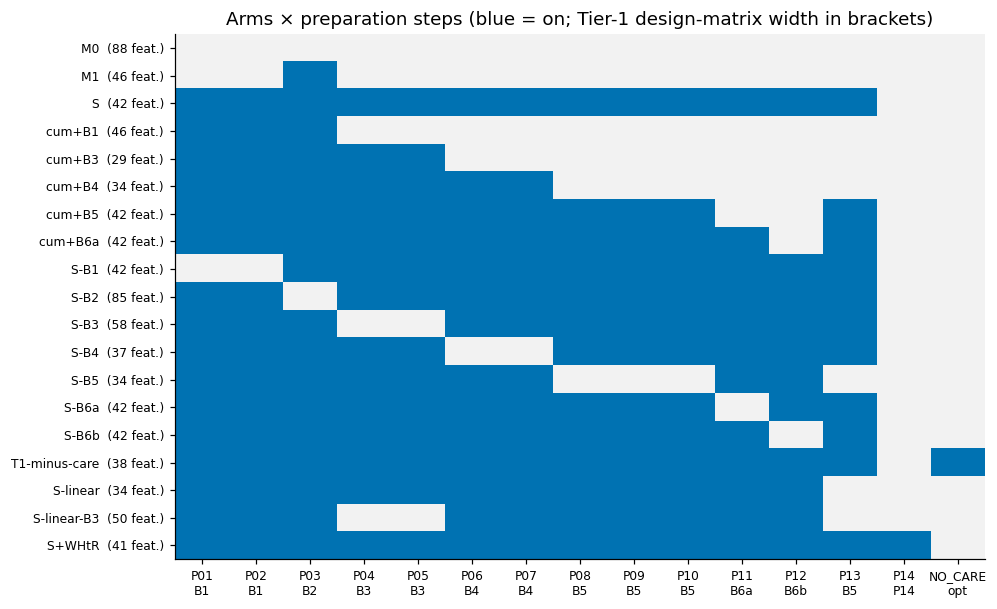

In [150]:
arms = P.arm_table()
arms.to_csv(OUT / "arm_table.csv")
nfeat = {}
for a, cfg in P.ARMS.items():
    for t, X in ((1, X1_tr), (2, X2_tr)):
        nfeat[(a, t)] = Pipeline(P.preprocessor_steps(cfg, t)).fit_transform(X).shape[1]
nfeat = pd.Series(nfeat).unstack().rename(columns={1: "n_features_T1", 2: "n_features_T2"})
print(arms.join(nfeat).to_string())
S6["arms"] = {a: {**{k: bool(v) for k, v in c.items()}, "n_features_t1": int(nfeat.loc[a, "n_features_T1"]),
                  "n_features_t2": int(nfeat.loc[a, "n_features_T2"])} for a, c in P.ARMS.items()}

fig, ax = plt.subplots(figsize=(9.5, 6.2))
mat = arms[list(P.STEPS) + ["NO_CARE"]]
ax.imshow(mat.to_numpy(), cmap=plt.matplotlib.colors.ListedColormap(["#f2f2f2", C.OKABE_ITO["blue"]]), aspect="auto")
ax.set_xticks(range(mat.shape[1]), [f"{s}\n{P.STEP_BLOCK.get(s, 'opt')}" for s in mat.columns], fontsize=8)
ax.set_yticks(range(mat.shape[0]), [f"{a}  ({nfeat.loc[a, 'n_features_T1']} feat.)" for a in mat.index], fontsize=8)
ax.grid(False)
ax.set_title("Arms × preparation steps (blue = on; Tier-1 design-matrix width in brackets)")
plots.savefig(fig, "S6_arm_matrix", caption="Which preparation steps are switched on in each experimental arm (blue). "
              "M0 = naive with leakage, M1 = availability rule only, S = all steps; S-Bk = leave-one-block-out.")
plt.show()

**So what.** M0 feeds 88 columns (Tier 1) to the model, M1 46 and S 42. S is *narrower* than M1 although it adds
spline bases, indicators and flags, because aggregation and pruning remove redundant columns. Every arm
differs from its comparator in exactly the steps named in its label, which is what makes the paired
differences in S7 interpretable.

## 6.10 Pipeline assertions
**Why.** The ablation is only meaningful if the switches do what they claim. Four checks:
(a) all switches off reproduces an independently written naive M0; (b) P08/P09 do not change a tree's
predictions; (c) no preparation step reads the label; (d) a disabled Toggle is exactly the identity.

In [151]:
checks = {}
for t, X in ((1, X1_tr), (2, X2_tr)):
    y0 = P.training_label(raw_tr, P.ALL_OFF)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        a = P.build_pipeline(P.ALL_OFF, t).fit(X, y0).predict_proba(X)[:, 1]
        b = P.naive_m0_reference(t, X).fit(X, y0).predict_proba(X)[:, 1]
    checks[f"m0_equiv_T{t}_maxabs"] = float(np.abs(a - b).max())
    assert checks[f"m0_equiv_T{t}_maxabs"] < 1e-9

ys = P.training_label(raw_tr, P.ARMS["S"])
tree_s = P.build_pipeline(P.ARMS["S"], 1, model="tree").fit(X1_tr, ys).predict_proba(X1_tr)[:, 1]
cfg_nt = {**P.ARMS["S"], "P08": False, "P09": False}
tree_n = P.build_pipeline(cfg_nt, 1, model="tree").fit(X1_tr, ys).predict_proba(X1_tr)[:, 1]
checks["tree_p08_p09_maxabs"] = float(np.abs(tree_s - tree_n).max())
assert checks["tree_p08_p09_maxabs"] == 0.0

rng = np.random.default_rng(ek.derive_seed(C.SEED_MASTER, "S6", "random_y"))
y_rand = rng.permutation(ys)
for t, X in ((1, X1_tr), (2, X2_tr)):
    for cfg_name in ("S", "S+WHtR", "M1"):
        pre = lambda: Pipeline(P.preprocessor_steps(P.ARMS[cfg_name], t))
        za, zb = pre().fit(X, ys).transform(X), pre().fit(X, y_rand).transform(X)
        assert za.columns.equals(zb.columns) and np.array_equal(za.to_numpy(float), zb.to_numpy(float), equal_nan=True)
checks["no_step_reads_y"] = True

for name, step in [("P01", P.XptZeroFix()), ("P03", P.Admissibility(1)), ("P04", P.Aggregate()),
                   ("P05", P.VIFPrune()), ("P06", P.MissingIndicator()), ("P07", P.TopcodeFlags()),
                   ("P08", P.YeoJohnson()), ("P09", P.Scale()), ("P13", P.Splines(("RIDAGEYR",))), ("P14", P.WHtR())]:
    tog = P.Toggle(step, enabled=False).fit(X1_tr)
    assert tog.transform(X1_tr) is X1_tr
checks["disabled_toggle_is_identity"] = True
print(json.dumps(checks, indent=1))
S6["assertions"] = checks

{
 "m0_equiv_T1_maxabs": 8.881784197001252e-16,
 "m0_equiv_T2_maxabs": 1.4988010832439613e-15,
 "tree_p08_p09_maxabs": 0.0,
 "no_step_reads_y": true,
 "disabled_toggle_is_identity": true
}


**So what.** All four checks pass: (a) the switch machinery with everything off reproduces the naive M0 to machine
precision (max |Δp| printed), so "M0" in S7 is the naive analyst and not an artefact of our code; (b) the tree
arm is exactly invariant to P08/P09, as monotone transforms must be; (c) fitting the preparation on a permuted
label gives bit-identical design matrices for S, S+WHtR and M1 – no step peeks at y; (d) disabled toggles
return their input unchanged.

## 6.11 Hypotheses and pre-registration lock
**Why.** A block ablation tempts post-hoc storytelling. The block hypotheses (direction, magnitude, SESOI,
falsifier and honest `prior_exposure`) and the verdict rules are therefore written to
`governance/hypotheses.md` and locked by a dedicated commit **before** the first ablation result is
committed. The lock is the file's SHA-256 recorded in that commit; git history shows the order.

In [152]:
HYP = C.GOVERNANCE_DIR / "hypotheses.md"
text = HYP.read_text(encoding="utf-8")
rows = [l for l in text.splitlines() if l.startswith("| ") and not l.startswith("| hyp_id") and not l.startswith("|---")]
import re
hyp = pd.DataFrame([[c.strip() for c in re.split(r"(?<!\\)\|", l.strip().strip("|"))][:10] for l in rows],
                   columns=["hyp_id", "rq_or_block", "statement", "metric", "direction", "magnitude", "sesoi",
                            "falsifier", "prior_exposure", "weights"])
blocks_h = hyp[hyp["hyp_id"].str.match(r"^(B\d|P14)")]
assert set(blocks_h["hyp_id"]) >= {"B1", "B2", "B2t", "B3", "B4", "B5", "B6a", "B6b", "P14"}
assert blocks_h["prior_exposure"].str.match(r"^(none|analysis_seen|descriptive_seen|prototype_seen)").all()
_show = blocks_h.assign(prior=blocks_h["prior_exposure"].str.split(" ").str[0], sesoi=blocks_h["sesoi"].str[:40])
print(_show[["hyp_id", "direction", "sesoi", "prior"]].to_string(index=False))
print("\nprior_exposure counts (all hypotheses):", hyp["prior_exposure"].str.split(" ").str[0].value_counts().to_dict())

sha_now = hashlib.sha256(HYP.read_bytes()).hexdigest()
LOCK_FILE = OUT / "prereg_lock.json"
lock = None
try:
    log = subprocess.run(["git", "log", "--format=%H%x1f%cI%x1f%B%x1e", "--grep=lock hypotheses.md (prereg-lock)",
                          "--fixed-strings", "--", "governance/hypotheses.md"],
                         cwd=C.ROOT, capture_output=True, text=True, check=True).stdout
    entries = [e.strip("\n") for e in log.split("\x1e") if e.strip()]
    if entries:
        h, ts, body = entries[-1].split("\x1f")
        recorded = next(w for w in body.split() if len(w) == 64 and all(ch in "0123456789abcdef" for ch in w))
        locked_bytes = subprocess.run(["git", "show", f"{h}:governance/hypotheses.md"], cwd=C.ROOT,
                                      capture_output=True, check=True).stdout
        sha_locked = hashlib.sha256(locked_bytes).hexdigest()
        assert sha_locked == recorded, "hypotheses.md at the lock commit does not match the recorded SHA-256"
        first_exp = subprocess.run(["git", "log", "--reverse", "--format=%H %cI", r"--grep=^exp\(S7\)", "-E"],
                                   cwd=C.ROOT, capture_output=True, text=True).stdout.split("\n")[0].split()
        lock = dict(commit=h, timestamp=ts, sha256=sha_locked, first_exp_commit=first_exp[0] if first_exp else None,
                    first_exp_timestamp=first_exp[1] if first_exp else None)
        if first_exp:
            assert subprocess.run(["git", "merge-base", "--is-ancestor", h, first_exp[0]], cwd=C.ROOT).returncode == 0, \
                "first exp(S7) commit does not descend from the lock commit"
        LOCK_FILE.write_text(json.dumps(lock, indent=1), encoding="utf-8")
except (OSError, subprocess.CalledProcessError, StopIteration):
    pass
if lock is None and LOCK_FILE.exists():   # no git available (e.g. the assembled notebook): use the stored record
    lock = json.loads(LOCK_FILE.read_text(encoding="utf-8"))
if lock:
    print(f"\nprereg-lock commit {lock['commit'][:12]}  at {lock['timestamp']}")
    print(f"SHA-256 at lock   {lock['sha256']}")
    print(f"SHA-256 now       {sha_now}  ({'unchanged' if sha_now == lock['sha256'] else 'post-lock amendments appended'})")
    print(f"first exp(S7) commit: {lock.get('first_exp_commit') or 'none yet'} {lock.get('first_exp_timestamp') or ''}")
else:
    print(f"\nNOT YET LOCKED – current SHA-256 {sha_now}")
S6["hypotheses"] = dict(n_total=len(hyp), block_ids=list(blocks_h["hyp_id"]), sha256_now=sha_now, lock=lock)

hyp_id                                      direction                                    sesoi            prior
    B1                             none (equivalence)                                     0.01    analysis_seen
    B2                                          lower                                     0.05   prototype_seen
   B2t                                      as stated                                        –             none
    B3 (a) none; (b) ratio above 1; (c) lower with B3                     0.01 AUC; SD ratio 2   prototype_seen
    B4                            (a) none; (b) lower                    0.01 AUC; 0.005 Brier descriptive_seen
    B5                     (a) lower; (b), (c) higher                                 0.01 AUC descriptive_seen
   B6a       (a) none; (b) higher (worse); (c) higher 0.01 AUC; 0.005 Brier; 0.05 balanced acc             none
   B6b                                non-inferiority                                     0.01          

**So what.** Nine block-level hypotheses join the eight scope hypotheses. Only B2t, B6a and B6b are genuine
pre-registrations (`none`); B1 rests on damage counted in S3/S6, B2 and B3 on an earlier pilot analysis, B4 on the
missingness table of section 6, B5 on the S4 linearity tests and P14 on the S5 single-feature AUCs – all
disclosed. The lock commit, its timestamp and the SHA-256 recomputed from that commit are printed above;
S7 results are committed only after it.

## 6.12 Decisions and storage

In [153]:
reg = pd.read_csv(C.GOVERNANCE_DIR / "register" / "S6.csv")
print(reg[["dr_id", "type", "decision"]].to_string(index=False, max_colwidth=110))
R.save_section("S6", S6)
print("saved results/metrics_S6.json")

   dr_id           type                                                                                                       decision
DR-S6-01     arm_design Arms M0 (naive, leakage), M1 = M0 + P03, S = P01-P13; headline comparison M1 vs S, M0 -> M1 is the leak gat...
DR-S6-02      sentinels P02 is a Switch: off = blanket recode (M0 behaviour), on = codebook codes per variable; the training label ...
DR-S6-03        xpt_fix        P01 as a stateless step with mask() (NaN preserved); its effect is measured jointly with P02 (block B1)
DR-S6-04  admissibility P03 keeps spec features with admissible T1 (Tier 1) or T1/T2 (Tier 2); explicit S1 list asserted; T1-minus-...
DR-S6-05    aggregation P04 = mean of the 3 SBP, DBP and pulse readings plus weekly moderate and vigorous minutes (frequency x unit...
DR-S6-06     redundancy P05 iterative VIF > 10 pruning fitted in each training fold, BMI and waist (or WHtR) protected; drops weigh...
DR-S6-07    missingness P06 indicators for INDFMPIR, BM

# §7 Experiments and Block Ablation (Stage S7)

Here the model is used as a **measuring instrument** for the data-preparation decisions of §6. One
estimator (L2 logistic regression with C frozen) is applied to every arm on the same stored folds, and
each block is judged against its locked hypothesis with paired intervals. Results are reported on two
populations with equal weight:

* **E-ALL** – everyone in the training part, label `L_comb` (84 % of the positives already know they have
  diabetes);
* **E-SCREEN** – people *not* told they have diabetes, positive = HbA1c ≥ 6.5 % (the screening use case).

The 20 % hold-out is **not** evaluated here; its single use belongs to S9 after `exp-freeze`.

Contents: 1 splits · 2 data-justified model choice · 3 C0 · 4 arms run · 5 leak gate · 6 baselines on
E-SCREEN · 7 cumulative path · 8 leave-one-block-out · 9 E-ALL vs E-SCREEN · 10 PR and calibration ·
11 coefficient stability · 12 verdicts · 13 storage

In [154]:
new_section()

In [155]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy import stats

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek

pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 70)
OUT = C.RESULTS_DIR / "S7"
OUT.mkdir(parents=True, exist_ok=True)
import os
os.environ.setdefault("PYTHONWARNINGS", "ignore::UserWarning")   # silence worker-side solver warnings (counted in run_arm_cv)
N_JOBS = min(12, max(1, (os.cpu_count() or 2) - 2))
# FAST mode (re-run setting) uses fewer coefficient-bootstrap replicates than config.N_BOOT_COEF: the unscaled arms
# reach the solver's iteration limit in every refit, which makes this the slowest step of the section. FINAL is unchanged.
B_COEF = C.N_BOOT_COEF if C.IS_FINAL else 30
S7 = {"mode": C.NB_MODE, "cv": f"{C.CV_SPLITS}x{C.CV_REPEATS}", "n_boot": C.N_BOOT, "n_boot_coef": B_COEF}
T_START = time.time()
print(f"mode {C.NB_MODE}: {C.CV_SPLITS}x{C.CV_REPEATS} CV, B = {C.N_BOOT}, coefficient bootstrap B = {B_COEF}, {N_JOBS} workers")

mode FINAL: 5x5 CV, B = 1000, coefficient bootstrap B = 500, 12 workers


## 7.1 Splits
**Why.** Every arm must be scored on identical folds, otherwise paired differences mix model effects with
split noise. The hold-out (label × race stratified, 20 %) and the repeated stratified folds are generated
once by `evalkit`, stored with SHA-256 hashes and re-verified on every run. Folds are stratified on the
four 3 × 3 strata (uncontrolled / controlled / undiagnosed / non-diabetic) so that each fold holds a fair
share of the 152 undiagnosed cases that define E-SCREEN.

In [156]:
raw = P.raw_cohort()
clean = L.add_labels(io.build_cohort())
assert (raw["SEQN"].to_numpy() == clean["SEQN"].to_numpy()).all()
tr, te = ek.make_holdout(clean)
raw_tr = raw.iloc[tr].reset_index(drop=True)
cl = clean.iloc[tr].reset_index(drop=True)
X = {1: P.raw_feature_frame(raw_tr, 1), 2: P.raw_feature_frame(raw_tr, 2)}
y = cl["L_comb"].to_numpy()
esc = cl["in_escreen"].eq(1).to_numpy()
y_esc = cl["y_escreen"].fillna(0).astype(int).to_numpy()   # only scored inside the E-SCREEN mask
strat = cl["stratum_3x3"].astype(str).to_numpy()
folds = ek.make_folds(y, strat)
n = len(y)
n_test_fold = n / C.CV_SPLITS
n_train_fold = n - n_test_fold
hold = json.loads((C.RESULTS_DIR / "splits" / "holdout.json").read_text(encoding="utf-8"))
print(f"training part {n:,} rows ({y.sum()} L_comb positives); hold-out {len(te):,} rows - not evaluated in S7")
print(f"E-SCREEN in training part: {esc.sum():,} rows, {y_esc[esc].sum()} positives (HbA1c >= 6.5, not diagnosed)")
print(f"folds: {len(folds)} = {folds.n_splits} x {folds.n_repeats}, hash {folds.hash[:16]}..., file {folds.path.name}")
print(f"hold-out test SEQN SHA-256 {hold['sha256_test_seqn'][:16]}...")
per_fold = pd.DataFrame([{"fold": i, "n_test": len(t), "pos_eall": int(y[t].sum()), "pos_escreen": int(y_esc[t][esc[t]].sum())}
                         for i, (_, t) in enumerate(folds)])
print(per_fold.describe().loc[["min", "mean", "max"], ["n_test", "pos_eall", "pos_escreen"]].round(1).to_string())
S7["splits"] = dict(n_train=n, n_holdout=len(te), n_pos_eall=int(y.sum()), n_escreen=int(esc.sum()),
                    n_pos_escreen=int(y_esc[esc].sum()), folds_hash=folds.hash, folds_file=folds.path.name,
                    holdout_sha256=hold["sha256_test_seqn"], pos_escreen_per_fold_min=int(per_fold["pos_escreen"].min()))

training part 4,584 rows (777 L_comb positives); hold-out 1,146 rows - not evaluated in S7
E-SCREEN in training part: 3,934 rows, 127 positives (HbA1c >= 6.5, not diagnosed)
folds: 25 = 5 x 5, hash 0d20f8f706ebf1e1..., file folds_FINAL.npz
hold-out test SEQN SHA-256 616fd0590bec7b92...
      n_test  pos_eall  pos_escreen
min    916.0     155.0         25.0
mean   916.8     155.4         25.4
max    917.0     156.0         26.0


**So what.** Each fold holds about 155 E-ALL positives but only about 24 E-SCREEN positives. That is why the
protocol scores E-SCREEN on the pooled out-of-fold vector (paired bootstrap), not fold by fold, and why most
E-SCREEN verdicts are expected to be inconclusive. The hold-out hash is printed so that S9 can prove it was
untouched.

## 7.2 Data-justified model choice
**Why.** Only basic interpretable models are allowed (logistic regression and shallow trees). Within that constraint each
modelling choice is tied to a diagnostic number from §4 (the S4 model-justification table) – and the reason for *not*
choosing an alternative.

In [157]:
S4dir = C.RESULTS_DIR / "S4"
lin = pd.read_csv(S4dir / "linearity_tests.csv")
inter = pd.read_csv(S4dir / "interaction_tests.csv")
daj = pd.read_csv(S4dir / "daj_table.csv")
vif4 = pd.read_csv(S4dir / "vif_table.csv")
print("S4 RCS linearity tests (4 knots vs linear, df 2):")
print(lin[["label", "n", "n_events", "chi2", "p", "nonlinear"]].round(4).to_string(index=False))
print("\nS4 interaction tests (primary spec A):")
print(inter[inter["spec"] == "A_primary"][["term", "chi2", "df", "p", "verdict"]].round(4).to_string(index=False))
sx = inter[inter["term"] == "sex_x_bmi"].set_index("spec")["p"].round(3).to_dict()
epv_den = {t: P.build_pipeline(P.ARMS["S"], t)[:-1].fit_transform(X[t]).shape[1] for t in (1, 2)}
epv = {t: round(y.sum() / k, 1) for t, k in epv_den.items()}
print(f"\nsex x BMI by spec: {sx}")
print(f"events per parameter in S: Tier 1 {y.sum()}/{epv_den[1]} = {epv[1]}, Tier 2 {y.sum()}/{epv_den[2]} = {epv[2]}")
print(f"imbalance: prevalence {y.mean():.3f} in the training part")
lin_i = lin.set_index("variable")
nl = ["RIDAGEYR", "BMXBMI", "LBDHDD", "LBXTC"]
ia = inter[inter["spec"] == "A_primary"].set_index("term")
vr = vif4[vif4["set"] == "raw_anthropometry"].set_index("variable")["vif"]
vb = vif4.loc[vif4["set"] == "bp_readings", "vif"]
ev_nonlin = ", ".join(f"{lin_i.loc[v, 'label']} {lin_i.loc[v, 'chi2']:.1f}" for v in nl) + f" (all p < {lin_i.loc[nl, 'p'].max():.3f})"
ev_inter = (f"race x BMI p {ia.loc['race_x_bmi', 'p']:.2f}, Asian x BMI p {ia.loc['asian_x_bmi', 'p']:.2f} "
            f"(MDE {ia.loc['asian_x_bmi', 'mde']:.2f} log-OR)")
ev_coll = f"weight VIF {vr['BMXWT']:.1f}, BMI {vr['BMXBMI']:.1f}; 6 BP readings {vb.min():.1f}-{vb.max():.1f}"
choice = pd.DataFrame([
    ("non-linearity", ev_nonlin, "L2 logistic regression + B-spline basis (P13)", "categorised bands (arbitrary cut-points, information loss); GAM / boosting (outside the allowed model class)"),
    ("interactions", ev_inter, "no interaction terms; Asian BMI bias treated as a measurement issue (P14, S8)", "interaction terms add variance without detectable gain"),
    ("collinearity", ev_coll, "aggregate + in-fold VIF pruning (P04/P05), L2 as second defence", "L1 (unstable selection among collinear columns, sensitivity only)"),
    ("sample size", f"{y.sum()} events / {epv_den[1]} parameters (EPV {epv[1]})", "unpenalised fit would be acceptable; mild L2 (C0) chosen by inner CV", "deep trees / ensembles (overfit, outside the allowed model class)"),
    ("imbalance", f"prevalence {y.mean():.1%}", "no resampling; class_weight tested as block B6a", "SMOTE (breaks calibration and the survey design)"),
    ("thresholds / leakage", "clinical cut-points and leakage need inspection", "depth-3 tree (min leaf 50) as a probe only", "tree as main model (step functions, unstable)"),
], columns=["diagnostic", "evidence (S4 / S7)", "decision", "why not the alternative"])
choice.to_csv(OUT / "model_choice.csv", index=False)
print(choice.to_string(index=False))
S7["model_choice"] = dict(linearity=lin.set_index("label")[["chi2", "p"]].round(4).to_dict("index"),
                          sex_x_bmi_p_by_spec=sx, epv=epv, n_params=epv_den)

S4 RCS linearity tests (4 knots vs linear, df 2):
            label    n  n_events    chi2      p  nonlinear
              age 4478       722 57.6075 0.0000       True
              BMI 4478       722 11.5618 0.0031       True
            waist 4478       722  7.0540 0.0294       True
       SBP (mean) 4478       722  5.8698 0.0531      False
              HDL 4478       722 18.4670 0.0001       True
total cholesterol 4478       722 41.7673 0.0000       True
              PIR 4478       722  0.8344 0.6589      False

S4 interaction tests (primary spec A):
       term   chi2  df      p      verdict
 race_x_bmi 5.1890   5 0.3933 not detected
asian_x_bmi 0.0071   1 0.9328 not detected
  age_x_bmi 0.5829   1 0.4452 not detected
  sex_x_bmi 6.9951   1 0.0082     detected



sex x BMI by spec: {'A_primary': 0.008, 'B_minimal': 0.833, 'C_splines': 0.072}
events per parameter in S: Tier 1 777/42 = 18.5, Tier 2 777/53 = 14.7
imbalance: prevalence 0.170 in the training part
          diagnostic                                                   evidence (S4 / S7)                                                                      decision                                                                                      why not the alternative
       non-linearity age 57.6, BMI 11.6, HDL 18.5, total cholesterol 41.8 (all p < 0.003)                                 L2 logistic regression + B-spline basis (P13) categorised bands (arbitrary cut-points, information loss); GAM / boosting (outside the allowed model class)
        interactions              race x BMI p 0.39, Asian x BMI p 0.93 (MDE 0.70 log-OR) no interaction terms; Asian BMI bias treated as a measurement issue (P14, S8)                                                       interaction terms add va

**So what.** Age, BMI and both lipids bend significantly, so the main model is a GLM with spline terms rather than
a linear logit; the linear version stays as the ablation arm *S-linear*. Race × BMI and Asian × BMI are not
detected (underpowered – "not detected" is not "absent"). One caveat is reported, not hidden: S4 found
sex × BMI significant in its primary specification (p printed above) but not in the minimal or spline
specifications; because the result depends on the specification, no interaction term is added and the point is
listed as a limitation. With about 18 events per parameter, overfitting risk is modest; L2 mainly stabilises
correlated anthropometrics. Redundancy is handled as in the S4 model-justification table: in-fold iterative VIF > 10 pruning with
BMI and waist protected (P05), which removes only weight (§6.5); height, hip and arm therefore stay in S.

## 7.3 Regularisation strength C0
**Why.** A fair minimal-versus-systematic comparison requires the *same model* in every arm. C is therefore chosen once – by
`LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10])`, inner 5-fold ROC-AUC, on the S arm of Tier 1 with its class and
survey weights – and then frozen for every arm. Choosing it on S favours S slightly (the other arms do not get
their own tuning); M0 with its own C is an S9 sensitivity.

In [158]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold

cfgS = P.ARMS["S"]
design = P.build_pipeline(cfgS, 1)[:-1].fit_transform(X[1])
ylab = P.training_label(raw_tr, cfgS)
inner = StratifiedKFold(5, shuffle=True, random_state=ek.derive_seed(C.SEED_MASTER, "S7", "C0"))
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    lrcv = LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10], cv=inner, scoring="roc_auc", max_iter=C.LR_MAX_ITER,
                                class_weight="balanced", l1_ratios=(0.0,), use_legacy_attributes=False)
    lrcv.fit(design, ylab, sample_weight=P.survey_weights(raw_tr))
scores = np.asarray(lrcv.scores_).reshape(5, -1)   # (inner folds, Cs); l1_ratio fixed at 0 (pure L2)
C0 = float(np.ravel(lrcv.C_)[0])
cv_auc = pd.Series(scores.mean(axis=0).ravel()[:4], index=[0.01, 0.1, 1, 10]).round(4)
print("inner-CV ROC-AUC by C:"); print(cv_auc.to_string())
print(f"C0 = {C0} (frozen for all arms and tiers)")
S7["C0"] = dict(C0=C0, inner_cv_auc=cv_auc.to_dict())

inner-CV ROC-AUC by C:
0.01     0.8490
0.10     0.8519
1.00     0.8515
10.00    0.8514
C0 = 0.1 (frozen for all arms and tiers)


**So what.** The inner-CV AUC is almost flat across C (differences in the third decimal), so the choice of C is not a
lever for the results below; C0 is used for every arm. The flatness also limits the optimistic bias of tuning on S.
Disclosure: C0 is selected once on the whole training part, i.e. not nested inside the outer CV folds; with an inner
AUC range of only about 0.003 across C the resulting optimism is negligible.

## 7.4 Running the arms
**Why.** Each arm × tier is cross-validated on the stored folds with the frozen C0; every preparation step is
refitted inside each training fold. Arms with P02 off are trained on their own naive label (965 positives),
but every arm is scored against the frozen `L_comb`. The depth-3 tree is run on M0, M1 and S as a probe.
Solver non-convergence (the unscaled arms) is counted, not suppressed.

In [159]:
ARM_LIST = list(P.ARMS)
jobs = [(a, t, "lr") for t in (1, 2) for a in ARM_LIST] + [(a, t, "tree") for t in (1, 2) for a in ("M0", "M1", "S")]
t0 = time.time()
# one job per arm x tier x model, each deterministic: the number of workers changes the wall time only (FAST may use
# every core so that the re-run stays within about 5 minutes; FINAL keeps its worker count)
N_JOBS_ARMS = N_JOBS if C.IS_FINAL else max(N_JOBS, (os.cpu_count() or 2) - 2)
runs = Parallel(n_jobs=N_JOBS_ARMS)(delayed(P.run_arm_cv)(a, t, X[t], raw_tr, folds, C_=C0, model=m) for a, t, m in jobs)
OOF = {(r["arm"], r["tier"], r["model"]): r["oof"] for r in runs}
PM = {k: ek.mean_oof(v, n) for k, v in OOF.items()}          # repeat-averaged OOF probability per row
diag = pd.DataFrame([{k: r[k] for k in ("arm", "tier", "model", "n_convergence_warnings", "seconds", "n_pos_train_label")}
                     for r in runs])
assert all(np.isfinite(v).all() for v in PM.values())
for r in runs:   # no hold-out row can appear: OOF rows index the training part only
    assert r["oof"]["row"].max() < n and r["oof"].groupby("repeat")["row"].nunique().eq(n).all()
print(f"{len(jobs)} arm x tier x model runs, {sum(len(f) for f in [folds]) * len(jobs)} fits, {time.time() - t0:.0f} s wall")
print(diag[diag["n_convergence_warnings"] > 0].to_string(index=False))
S7["runs"] = dict(n_runs=len(jobs), wall_seconds=time.time() - t0,
                  convergence=diag[diag["n_convergence_warnings"] > 0][["arm", "tier", "model", "n_convergence_warnings"]].to_dict("records"))

44 arm x tier x model runs, 1100 fits, 71 s wall
   arm  tier model  n_convergence_warnings   seconds  n_pos_train_label
    M0     1    lr                      25 46.786688                772
    M1     1    lr                      25 39.240848                772
cum+B1     1    lr                      25 38.519674                777
cum+B3     1    lr                      25 35.133816                777
cum+B4     1    lr                      25 36.163309                777
  S-B5     1    lr                      25 35.997449                777
    M0     2    lr                      24 45.876573                772
    M1     2    lr                      25 38.911159                772
cum+B1     2    lr                      25 38.181006                777
cum+B3     2    lr                      25 35.607261                777
cum+B4     2    lr                      25 36.696817                777
  S-B5     2    lr                      25 28.487591                777


In [160]:
from sklearn.metrics import roc_auc_score, average_precision_score

def pop_of(name):
    """(label vector, evaluation mask) of a population."""
    if name == "E-ALL":
        return y, np.ones(n, bool)
    if name == "E-SCREEN":
        return y_esc, esc
    if name == "PIR-missing":
        return y, cl["INDFMPIR"].isna().to_numpy()
    raise ValueError(name)

def _bacc05(yy, pp):
    pred = pp >= 0.5
    return 0.5 * (pred[yy == 1].mean() + (~pred[yy == 0]).mean())

def _calslope_dev(yy, pp):
    return abs(ek._calibration(yy, pp)[0] - 1.0)

METRIC_FN = {"roc_auc": roc_auc_score, "pr_auc": average_precision_score,
             "brier": lambda yy, pp: float(np.mean((pp - yy) ** 2)),
             "bacc05": _bacc05, "calslope_dev": _calslope_dev}

def auc_ci(p, pop="E-ALL", seed_tag="auc"):
    """AUC of a pooled OOF vector with a label-stratified bootstrap CI (paired against a constant 0.5)."""
    yy, m = pop_of(pop)
    b = ek.paired_bootstrap(yy, p, np.full(n, 0.5), "roc_auc", n_boot=C.N_BOOT, eval_mask=m,
                            seed=ek.derive_seed(C.SEED_MASTER, "S7", seed_tag, pop))
    return b["metric_a"], b["ci_low"] + 0.5, b["ci_high"] + 0.5

def arm_row(key):
    oof, pm = OOF[key], PM[key]
    fm = ek.fold_metrics(oof, y)
    out = {"arm": key[0], "tier": key[1], "model": key[2], "eall_auc_foldmean": fm["roc_auc"].mean(),
           "eall_auc_foldsd": fm["roc_auc"].std(ddof=1)}
    for pop in ("E-ALL", "E-SCREEN"):
        yy, m = pop_of(pop)
        ms = ek.metric_suite(yy[m], pm[m])
        a, lo, hi = auc_ci(pm, pop, seed_tag=f"{key}")
        tag = "eall" if pop == "E-ALL" else "escr"
        out.update({f"{tag}_auc": a, f"{tag}_auc_lo": lo, f"{tag}_auc_hi": hi, f"{tag}_pr_auc": ms["pr_auc"],
                    f"{tag}_brier": ms["brier"], f"{tag}_recall_spec80": ms["recall_at_spec"],
                    f"{tag}_cal_slope": ms["cal_slope"], f"{tag}_cal_citl": ms["cal_citl"], f"{tag}_prev": ms["prevalence"]})
    out["eall_auc_weighted"] = ek.metric_suite(y, pm, w=cl[C.WEIGHT_PHLEB].to_numpy())["roc_auc"]
    return out

arm_metrics = pd.DataFrame([arm_row(k) for k in OOF]).merge(diag, on=["arm", "tier", "model"])
arm_metrics.to_csv(OUT / "arm_metrics.csv", index=False)
show = ["arm", "model", "eall_auc", "eall_auc_lo", "eall_auc_hi", "escr_auc", "escr_auc_lo", "escr_auc_hi",
        "eall_brier", "escr_recall_spec80", "eall_cal_slope", "n_convergence_warnings"]
main_arms = ["M0", "M1", "S", "T1-minus-care", "S-linear", "S+WHtR"]
tab = arm_metrics[(arm_metrics["tier"] == 1) & arm_metrics["arm"].isin(main_arms)]
print("Tier 1, main arms (all arms and Tier 2: results/S7/arm_metrics.csv):")
print(tab[show].round(3).to_string(index=False))

Tier 1, main arms (all arms and Tier 2: results/S7/arm_metrics.csv):
          arm model  eall_auc  eall_auc_lo  eall_auc_hi  escr_auc  escr_auc_lo  escr_auc_hi  eall_brier  escr_recall_spec80  eall_cal_slope  n_convergence_warnings
           M0    lr     0.961        0.952        0.968     0.844        0.808        0.881       0.040               0.709           1.195                      25
           M1    lr     0.828        0.814        0.843     0.772        0.739        0.804       0.112               0.535           0.961                      25
            S    lr     0.836        0.822        0.849     0.781        0.748        0.809       0.185               0.520           0.867                       0
T1-minus-care    lr     0.820        0.806        0.835     0.800        0.766        0.832       0.195               0.614           0.873                       0
     S-linear    lr     0.832        0.817        0.845     0.775        0.744        0.806       0.189        

**So what.** The table is the raw material for everything below; the paired comparisons that follow are what
decides. Three patterns are already visible: the naive arm M0 reaches an E-ALL AUC near 0.96 that collapses once the
availability rule is applied; all admissible arms sit in a narrow band; and every arm loses discrimination when
moved from E-ALL to E-SCREEN. Only the unscaled arms (M0, M1, cumulative steps before B5, S−B5) hit the
iteration limit, which is itself a cost of skipping scaling.

### 7.4.1 Comparison engine
Paired difference A − B of a metric on a population: fold-level Nadeau–Bengio corrected t and a paired,
label-stratified bootstrap on the repeat-averaged OOF vectors; on E-ALL the **wider** interval is used, on
E-SCREEN the bootstrap only. The estimate is always the same quantity per population: on E-ALL the mean of the
fold-level paired differences, on E-SCREEN the difference on the pooled OOF vector. The 80 %-power minimal detectable difference (MDD) is reported with each Δ. Verdict
rules are those locked in `governance/hypotheses.md`; for a directional claim an `evalkit` verdict of
"equivalent" (CI inside ±magnitude) means the claimed magnitude is excluded and is recorded as **refuted**.

In [161]:
def fold_values(key, metric, pop):
    yy, m = pop_of(pop)
    fn = METRIC_FN[metric]
    vals = {}
    for (r, f), g in OOF[key].groupby(["repeat", "fold"]):
        rows = g["row"].to_numpy()
        keep = m[rows]
        vals[(r, f)] = fn(yy[rows][keep], g["prob"].to_numpy()[keep])
    return pd.Series(vals)

def compare(a, b, tier=1, metric="roc_auc", pop="E-ALL", model="lr", pa=None, pb=None):
    """Paired comparison A - B; pa/pb override the OOF vectors (baselines)."""
    yy, m = pop_of(pop)
    pa = PM[(a, tier, model)] if pa is None else pa
    pb = PM[(b, tier, model)] if pb is None else pb
    bm = metric if metric in ("roc_auc", "brier", "pr_auc") else METRIC_FN[metric]
    bs = ek.paired_bootstrap(yy, pa, pb, bm, n_boot=C.N_BOOT, eval_mask=m,
                             seed=ek.derive_seed(C.SEED_MASTER, "S7", a, b, tier, metric, pop))
    row = dict(a=a, b=b, tier=tier, metric=metric, pop=pop, model=model, diff_pooled=bs["diff"],
               boot_lo=bs["ci_low"], boot_hi=bs["ci_high"], boot_se=bs["se"], n_eval=bs["n_eval"], n_pos=bs["n_pos"])
    if pop != "E-SCREEN" and (a, tier, model) in OOF and (b, tier, model) in OOF:
        d = (fold_values((a, tier, model), metric, pop) - fold_values((b, tier, model), metric, pop)).to_numpy()
        ct = ek.corrected_t(d, n_train_fold, n_test_fold)
        row.update(t_mean=ct["mean"], t_lo=ct["ci_low"], t_hi=ct["ci_high"], t_se=ct["se_corr"], t_p=ct["p"], J=ct["J"])
        use_t = (ct["ci_high"] - ct["ci_low"]) >= (bs["ci_high"] - bs["ci_low"])
        lo, hi, se = (ct["ci_low"], ct["ci_high"], ct["se_corr"]) if use_t else (bs["ci_low"], bs["ci_high"], bs["se"])
        est = ct["mean"]   # one estimand on E-ALL: the fold-mean paired difference (interval = the wider of the two)
        mdd = (stats.t.ppf(0.975, ct["df"]) + stats.t.ppf(0.80, ct["df"])) * se
        row["interval"] = "corrected_t" if use_t else "bootstrap"
    else:
        est, lo, hi, se = bs["diff"], bs["ci_low"], bs["ci_high"], bs["se"]
        mdd = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * se
        row["interval"] = "bootstrap"
        if pop == "E-SCREEN" and (a, tier, model) in OOF and (b, tier, model) in OOF:
            ra = ek.repeat_metrics(OOF[(a, tier, model)], y_esc, eval_mask=esc).set_index("repeat")
            rb = ek.repeat_metrics(OOF[(b, tier, model)], y_esc, eval_mask=esc).set_index("repeat")
            if metric in ra:
                dr = ra[metric] - rb[metric]
                row.update(rep_min=dr.min(), rep_max=dr.max())
    row.update(est=est, lo=lo, hi=hi, se=se, mdd=mdd)
    return row

def v_equiv(lo, hi, s):
    return "supported" if (lo > -s and hi < s) else ("refuted" if (lo >= s or hi <= -s) else "inconclusive")

def v_dir(lo, hi, est, s, direction):
    v = ek.verdict(lo, hi, s, direction, est)
    return "refuted" if v == "equivalent" else v

def v_noninf(lo, hi, s):
    return "supported" if lo > -s else ("refuted" if hi < -s else "inconclusive")

COMP = []   # every comparison row, stored in results/S7/comparisons.csv

def cmp_(*args, label="", **kw):
    r = compare(*args, **kw)
    r["label"] = label
    COMP.append(r)
    return r

def fmt(r, k=3):
    return f"{r['est']:+.{k}f} [{r['lo']:+.{k}f}, {r['hi']:+.{k}f}] ({r['interval']}, MDD {r['mdd']:.{k}f})"

## 7.5 Leak gate: M0 → M1
**Why.** M0 keeps glucose, treatment, diagnosis history, prediabetes counselling (DIQ160) and prior glucose
testing (DIQ180). If the availability rule removes real leakage, discrimination must *drop* – a correct
deterioration (hypotheses H2a, B2). A depth-3 tree shows *where* the M0 signal comes from (B2t).

Tier 1 E-ALL    AUC M1 - M0 = -0.131 [-0.148, -0.114] (corrected_t, MDD 0.024)


Tier 1 E-SCREEN AUC M1 - M0 = -0.072 [-0.113, -0.031] (bootstrap, MDD 0.059)


Tier 2 E-ALL    AUC M1 - M0 = -0.119 [-0.133, -0.106] (corrected_t, MDD 0.019)


Tier 2 E-SCREEN AUC M1 - M0 = -0.081 [-0.120, -0.041] (bootstrap, MDD 0.056)


Tier 1 E-ALL    AUC S - (S-B2) = -0.122 [-0.138, -0.105] (corrected_t, MDD 0.023)


Tier 1 E-SCREEN AUC S - (S-B2) = -0.090 [-0.124, -0.060] (bootstrap, MDD 0.047)


   root_feature variable     role threshold                level2
M0   DIQ070_2.0   DIQ070     leak       0.5  [DIQ180_2.0, DID040]
M1   BPQ020_2.0   BPQ020  feature       0.5  [BMXWAIST, BMXWAIST]
S    BPQ020_1.0   BPQ020  feature       0.5  [BMXWAIST, BMXWAIST]
|--- taking diabetic pills: no <= 0.50
|   |--- blood-glucose test in past 3 years: no <= 0.50
|   |   |--- weights: [43.00, 17.00] class: 0
|   |--- blood-glucose test in past 3 years: no >  0.50
|   |   |--- LDL cholesterol (mg/dL) <= 119.50
|   |   |   |--- weights: [0.00, 430.00] class: 1
|   |   |--- LDL cholesterol (mg/dL) >  119.50
|   |   |   |--- weights: [3.00, 47.00] class: 1
|--- taking diabetic pills: no >  0.50
|   |--- age at diabetes diagnosis <= 49.50
|   |   |--- weights: [0.00, 90.00] class: 1
|   |--- age at diabetes diagnosis >  49.50
|   |   |--- age at diabetes diagnosis <= 50.50
|   |   |   |--- weights: [3766.00, 121.00] class: 0
|   |   |--- age at diabetes diagnosis >  50.50
|   |   |   |--- weights:

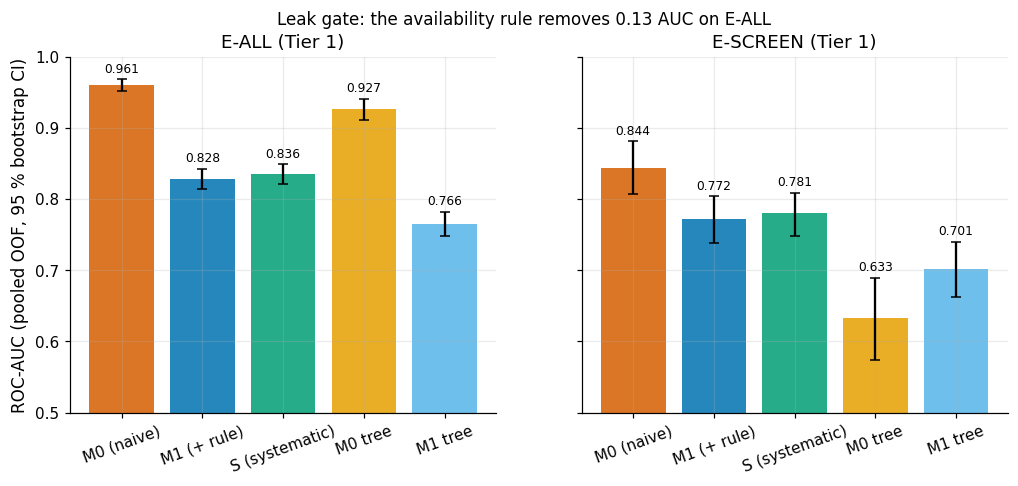

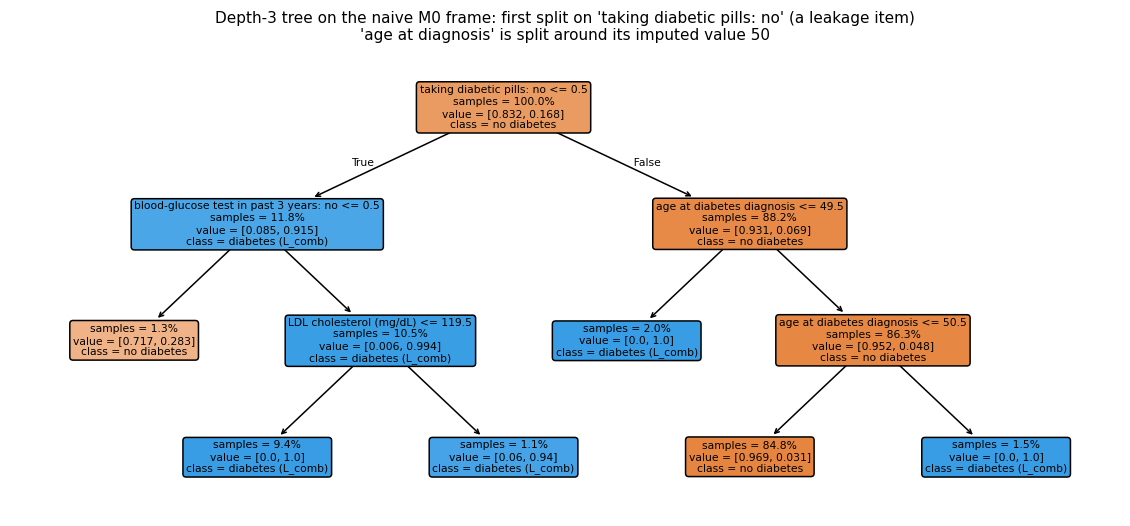

In [162]:
from sklearn.tree import plot_tree

gate = {}
for t in (1, 2):
    for pop in ("E-ALL", "E-SCREEN"):
        gate[(t, pop)] = cmp_("M1", "M0", t, "roc_auc", pop, label="B2 leak gate")
        print(f"Tier {t} {pop:8s} AUC M1 - M0 = {fmt(gate[(t, pop)])}")
for pop in ("E-ALL", "E-SCREEN"):
    r = cmp_("S", "S-B2", 1, "roc_auc", pop, label="B2 LOBO")
    print(f"Tier 1 {pop:8s} AUC S - (S-B2) = {fmt(r)}")

def base_var(name):
    for v in sorted(P._spec_by_var().index, key=len, reverse=True):
        if name == v or name.startswith(v + "_"):
            return v
    return name

roots, trees = {}, {}
for arm in ("M0", "M1", "S"):
    cfg = P.ARMS[arm]
    pipe = P.build_pipeline(cfg, 1, model="tree").fit(X[1], P.training_label(raw_tr, cfg), **P.fit_params(cfg, raw_tr))
    names = list(pipe[:-1].get_feature_names_out())
    tree = pipe[-1]
    trees[arm] = (tree, names)
    root = names[tree.tree_.feature[0]]
    rv = base_var(root)
    role = P._spec_by_var()["role"].get(rv, "derived")
    roots[arm] = dict(root_feature=root, variable=rv, role=role, threshold=float(tree.tree_.threshold[0]),
                      level2=[names[tree.tree_.feature[c]] for c in (tree.tree_.children_left[0], tree.tree_.children_right[0])
                              if tree.tree_.feature[c] >= 0])
print(pd.DataFrame(roots).T.to_string())
from sklearn.tree import export_text
m0_pipe = P.build_pipeline(P.ARMS["M0"], 1, model="tree").fit(X[1], P.training_label(raw_tr, P.ARMS["M0"]))
did040_fill = m0_pipe.named_steps["impute"].fill_["DID040"]
did040_miss = float(raw_tr["DID040"].isna().mean())
print(export_text(trees["M0"][0], feature_names=[P.plain_label(c) for c in trees["M0"][1]], show_weights=True))
print(f"DID040 (age at diagnosis) is asked only of diagnosed people: missing for {did040_miss:.0%} of the training part, "
      f"median-imputed to {did040_fill:.0f} in M0")
tree_escr = arm_metrics[(arm_metrics["tier"] == 1) & (arm_metrics["model"] == "tree")].set_index("arm")["escr_auc"]
print(f"tree E-SCREEN AUC: M0 {tree_escr['M0']:.3f}, M1 {tree_escr['M1']:.3f}, S {tree_escr['S']:.3f}")
S7["tree_m0"] = dict(did040_fill=did040_fill, did040_missing_share=did040_miss, escreen_auc=tree_escr.to_dict())
b2t = "supported" if roots["M0"]["role"] == "leak" and P._spec_by_var()["admissible"].get(roots["M1"]["variable"], "T1") != "N" else "refuted"
print(f"B2t verdict: {b2t}")
S7["leak_gate"] = {f"T{t}_{pop}": {k: gate[(t, pop)][k] for k in ("est", "lo", "hi", "interval", "mdd")} for (t, pop) in gate}
S7["tree_roots"] = roots

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
bars = [("M0", "lr", "M0 (naive)"), ("M1", "lr", "M1 (+ rule)"), ("S", "lr", "S (systematic)"), ("M0", "tree", "M0 tree"), ("M1", "tree", "M1 tree")]
colors = [C.OKABE_ITO["vermillion"], C.OKABE_ITO["blue"], C.OKABE_ITO["green"], C.OKABE_ITO["orange"], C.OKABE_ITO["sky"]]
for ax, pop, tag in zip(axes, ("E-ALL", "E-SCREEN"), ("eall", "escr")):
    sub = arm_metrics[arm_metrics["tier"] == 1].set_index(["arm", "model"])
    for i, ((a, m, _), c) in enumerate(zip(bars, colors)):
        v_ = sub.loc[(a, m)]
        ax.bar(i, v_[f"{tag}_auc"], color=c, alpha=0.85)
        ax.errorbar(i, v_[f"{tag}_auc"], yerr=[[v_[f"{tag}_auc"] - v_[f"{tag}_auc_lo"]], [v_[f"{tag}_auc_hi"] - v_[f"{tag}_auc"]]],
                    color="k", capsize=3)
        ax.text(i, v_[f"{tag}_auc_hi"] + 0.01, f"{v_[f'{tag}_auc']:.3f}", ha="center", fontsize=8)
    ax.set_xticks(range(len(bars)), [b[2] for b in bars], rotation=20)
    ax.set_ylim(0.5, 1.0)
    ax.set_title(f"{pop} (Tier 1)")
axes[0].set_ylabel("ROC-AUC (pooled OOF, 95 % bootstrap CI)")
fig.suptitle(f"Leak gate: the availability rule removes {-gate[(1, 'E-ALL')]['est']:.2f} AUC on E-ALL", fontsize=11)
plots.savefig(fig, "S7_leak_gate", caption="ROC-AUC of the naive arm M0, the availability-screened arm M1 and the systematic arm S "
              "(logistic regression) and of depth-3 trees, on E-ALL and E-SCREEN, Tier 1, with 95 % bootstrap CIs. "
              "The drop from M0 to M1 is the leakage removed by the availability rule.")
plt.show()

fig, ax = plt.subplots(figsize=(13, 5.5))
tree, names = trees["M0"]
plot_tree(tree, feature_names=[P.plain_label(c) for c in names], class_names=["no diabetes", "diabetes (L_comb)"],
          filled=True, impurity=False, proportion=True, rounded=True, fontsize=7, ax=ax)
ax.set_title(f"Depth-3 tree on the naive M0 frame: first split on '{P.plain_label(roots['M0']['root_feature'])}' "
             f"(a leakage item)\n'age at diagnosis' is split around its imputed value {did040_fill:.0f}", fontsize=10)
plots.savefig(fig, "S7_tree_m0", caption="Decision tree (depth 3, min leaf 50) fitted on the naive M0 feature frame (Tier 1, training part). "
              "The root split uses a treatment item that the availability rule removes; the splits at 49.5 / 50.5 on age at diagnosis "
              "isolate the median imputation of an item that is only asked of diagnosed people.")
plt.show()

**So what.** The availability rule removes the "too-good-to-be-true" signal: on E-ALL the AUC falls by about 0.13 –
the largest effect in the study – with an interval far beyond the 0.05 magnitude locked for B2/H2a. This
**deterioration is the correct outcome**: what M0 exploited is treatment and diagnosis history, i.e. the label leaking
back in. The tree makes this concrete: its root split is a *treatment* item ("taking diabetic pills"), followed by prior
glucose testing and age at diagnosis – not a single risk factor. The age-at-diagnosis splits are the most instructive:
the item is asked only of people already diagnosed, the naive median imputation fills everyone else with the value
printed above, and the tree simply separates "exactly the imputed value" (= never diagnosed) from any real age
(thresholds just below and above it). **Imputation has turned skip-pattern missingness into a code for the label.**
The leaked tree is also *worse* for screening than the honest one: its E-SCREEN AUC is below that of the M1 tree
(printed above), because diagnosis traces say nothing about the undiagnosed. On the M1 and S frames the root becomes
"told high blood pressure" (BPQ020), an admissible but care-contact item, followed by waist circumference.
The drop is smaller on E-SCREEN because people who know they have diabetes (where treatment items are most
telling) are not in E-SCREEN; what remains there comes from prediabetes counselling, glucose-test history and fasting
glucose (DIQ160, DIQ180, LBXGLU) – exactly the care traces the screening use case cannot have.

## 7.6 Baselines on E-SCREEN
**Why.** A model is only interesting if it beats what a clinician already has. The reduced ADA risk test (Bang et al.
2009) is the natural comparator on E-SCREEN, the screening population it was designed for. Mapping: age 0/1/2/3 for
<40/40–49/50–59/≥60; male +1; told high blood pressure (BPQ020) +1; physically inactive (no leisure-time moderate or
vigorous sessions, PAD790Q = PAD810Q = 0) +1; BMI 0/1/2/3 for <25/25–29.9/30–39.9/≥40. Family history and
gestational diabetes are not asked in 2021–23, so the score is **reduced (2 items missing)** and the published cut-off
is not used; AUC and recall at specificity 0.80 are compared instead. BL-ADAlite-LR refits weights to the same items
(trained on `L_comb` like every arm); BL0 is the no-information prior.

In [163]:
from sklearn.dummy import DummyClassifier

ada = P.ada_lite_items(cl)
OOF[("BL0", 1, "dummy")] = ek.cv_predict(lambda: DummyClassifier(strategy="prior"), X[1], y, folds)
PM[("BL0", 1, "dummy")] = ek.mean_oof(OOF[("BL0", 1, "dummy")], n)
bl0_fold = ek.fold_metrics(OOF[("BL0", 1, "dummy")], y)["roc_auc"]
assert np.allclose(bl0_fold, 0.5), "BL0 must have AUC 0.500 in every fold"
OOF[("BL-ADAlite-LR", 1, "lr")] = ek.cv_predict(lambda: P.ada_lr_pipeline(C0), ada, y, folds)
PM[("BL-ADAlite-LR", 1, "lr")] = ek.mean_oof(OOF[("BL-ADAlite-LR", 1, "lr")], n)
ada_score = ada["ada_score"].to_numpy(float)
PM[("BL-ADAlite", 1, "points")] = ada_score
miss = ada[["ada_htn_missing", "ada_inactive_missing", "ada_bmi_missing"]].sum().to_dict()
print(f"ADA-lite item availability: missing answers scored 0 -> {miss}")
print(f"ADA-lite score distribution in E-SCREEN: {pd.Series(ada_score[esc]).value_counts().sort_index().to_dict()}")

base_rows = []
for name, key in [("BL0 (prior)", ("BL0", 1, "dummy")), ("BL-ADAlite (points)", ("BL-ADAlite", 1, "points")),
                  ("BL-ADAlite-LR", ("BL-ADAlite-LR", 1, "lr")), ("M1", ("M1", 1, "lr")), ("S", ("S", 1, "lr")),
                  ("T1-minus-care", ("T1-minus-care", 1, "lr")), ("S Tier 2", ("S", 2, "lr"))]:
    p = PM[key]
    ms = ek.metric_suite(y_esc[esc], p[esc])
    a_, lo_, hi_ = auc_ci(p, "E-SCREEN", seed_tag=name)
    base_rows.append(dict(model=name, escr_auc=a_, lo=lo_, hi=hi_, escr_pr_auc=ms["pr_auc"],
                          escr_recall_spec80=ms["recall_at_spec"], eall_auc=roc_auc_score(y, p)))
baselines = pd.DataFrame(base_rows)
baselines.to_csv(OUT / "baselines_escreen.csv", index=False)
print(baselines.round(3).to_string(index=False))
print(f"BL0 per-fold AUC (E-ALL): all exactly {bl0_fold.iloc[0]:.3f}; E-SCREEN prevalence {y_esc[esc].mean():.3f} = BL0 PR-AUC level")
h2c3 = cmp_("S", "BL-ADAlite", 1, "roc_auc", "E-SCREEN", pb=ada_score, label="H2c(iii)")
s_vs_adalr = cmp_("S", "BL-ADAlite-LR", 1, "roc_auc", "E-SCREEN", pb=PM[("BL-ADAlite-LR", 1, "lr")], label="S vs ADA-LR")
care_vs_ada = cmp_("T1-minus-care", "BL-ADAlite", 1, "roc_auc", "E-SCREEN", pb=ada_score, label="T1-minus-care vs ADA")
print(f"E-SCREEN AUC S - ADA-lite points = {fmt(h2c3)}")
print(f"E-SCREEN AUC S - ADA-lite-LR     = {fmt(s_vs_adalr)}")
print(f"E-SCREEN AUC T1-minus-care - ADA-lite points = {fmt(care_vs_ada)}")
adalr_vs_pts = {pop: cmp_("BL-ADAlite-LR", "BL-ADAlite", 1, "roc_auc", pop, pa=PM[("BL-ADAlite-LR", 1, "lr")], pb=ada_score,
                          label="ADA-LR vs ADA points") for pop in ("E-ALL", "E-SCREEN")}
for pop, r in adalr_vs_pts.items():
    print(f"{pop:8s} AUC ADA-lite-LR - ADA-lite points = {fmt(r)}")
S7["ada_lr_minus_points"] = {pop: {k: r[k] for k in ("est", "lo", "hi")} for pop, r in adalr_vs_pts.items()}
S7["baselines"] = baselines.set_index("model").to_dict("index")
S7["ada_missing_answers"] = miss

ADA-lite item availability: missing answers scored 0 -> {'ada_htn_missing': 4, 'ada_inactive_missing': 39, 'ada_bmi_missing': 62}
ADA-lite score distribution in E-SCREEN: {0.0: 171, 1.0: 353, 2.0: 513, 3.0: 675, 4.0: 695, 5.0: 666, 6.0: 512, 7.0: 271, 8.0: 69, 9.0: 9}


              model  escr_auc    lo    hi  escr_pr_auc  escr_recall_spec80  eall_auc
        BL0 (prior)     0.497 0.443 0.546        0.031               0.134     0.503
BL-ADAlite (points)     0.726 0.681 0.764        0.077               0.244     0.761
      BL-ADAlite-LR     0.708 0.665 0.752        0.079               0.449     0.768
                 M1     0.772 0.738 0.804        0.093               0.535     0.828
                  S     0.781 0.747 0.812        0.091               0.520     0.836
      T1-minus-care     0.800 0.769 0.831        0.108               0.614     0.820
           S Tier 2     0.790 0.758 0.823        0.104               0.535     0.850
BL0 per-fold AUC (E-ALL): all exactly 0.500; E-SCREEN prevalence 0.032 = BL0 PR-AUC level


E-SCREEN AUC S - ADA-lite points = +0.055 [+0.026, +0.083] (bootstrap, MDD 0.041)
E-SCREEN AUC S - ADA-lite-LR     = +0.072 [+0.041, +0.103] (bootstrap, MDD 0.044)
E-SCREEN AUC T1-minus-care - ADA-lite points = +0.074 [+0.043, +0.106] (bootstrap, MDD 0.046)


E-ALL    AUC ADA-lite-LR - ADA-lite points = +0.006 [-0.001, +0.014] (bootstrap, MDD 0.010)
E-SCREEN AUC ADA-lite-LR - ADA-lite points = -0.018 [-0.032, -0.002] (bootstrap, MDD 0.021)


**So what.** BL0 sits exactly at AUC 0.500 in every fold (asserted; its pooled E-SCREEN AUC is marginally below 0.5,
the known artefact of pooling fold-wise priors) and at the prevalence for PR-AUC, so the evaluation code has no built-in
optimism. The five-item reduced ADA score reaches an E-SCREEN AUC of about 0.73 with integer points and no fitting; the
systematic model is better by about 0.05 with an interval that excludes 0 (H2c-iii). Two details matter for the
interpretation. First, refitting the ADA items by logistic regression on `L_comb` (BL-ADAlite-LR) moves them in opposite
directions on the two populations: indistinguishable from the points on E-ALL (interval includes 0) but lower on
E-SCREEN by about 0.02 with an interval that just excludes 0 (paired differences printed above). Weights learned from a
label dominated by known diabetics do not transfer well to screening. Second, ADA-lite is missing two items, so the
margin over it likely overstates what a complete ADA test would concede.

## 7.7 Cumulative path M0 → S
**Why.** The cumulative path shows how the AUC moves as blocks are added in the pre-specified order. Increments depend
on the order, so they are descriptive; verdicts come from leave-one-block-out (section 8).

     pop              step     est      lo      hi    interval    mdd
   E-ALL          M0 -> M1 -0.1308 -0.1479 -0.1138 corrected_t 0.0241
   E-ALL      M1 -> cum+B1  0.0009 -0.0021  0.0040 corrected_t 0.0043
   E-ALL  cum+B1 -> cum+B3  0.0023 -0.0027  0.0074 corrected_t 0.0071
   E-ALL  cum+B3 -> cum+B4  0.0007 -0.0011  0.0025 corrected_t 0.0025
   E-ALL  cum+B4 -> cum+B5  0.0060  0.0011  0.0109   bootstrap 0.0074
   E-ALL cum+B5 -> cum+B6a  0.0006 -0.0011  0.0023 corrected_t 0.0025
   E-ALL      cum+B6a -> S -0.0027 -0.0062  0.0008 corrected_t 0.0050
E-SCREEN          M0 -> M1 -0.0718 -0.1133 -0.0310   bootstrap 0.0587
E-SCREEN      M1 -> cum+B1  0.0029 -0.0015  0.0071   bootstrap 0.0061
E-SCREEN  cum+B1 -> cum+B3  0.0041 -0.0036  0.0117   bootstrap 0.0108
E-SCREEN  cum+B3 -> cum+B4  0.0015 -0.0025  0.0055   bootstrap 0.0058
E-SCREEN  cum+B4 -> cum+B5  0.0032 -0.0111  0.0165   bootstrap 0.0199
E-SCREEN cum+B5 -> cum+B6a  0.0029 -0.0001  0.0059   bootstrap 0.0043
E-SCREEN      cum+B6

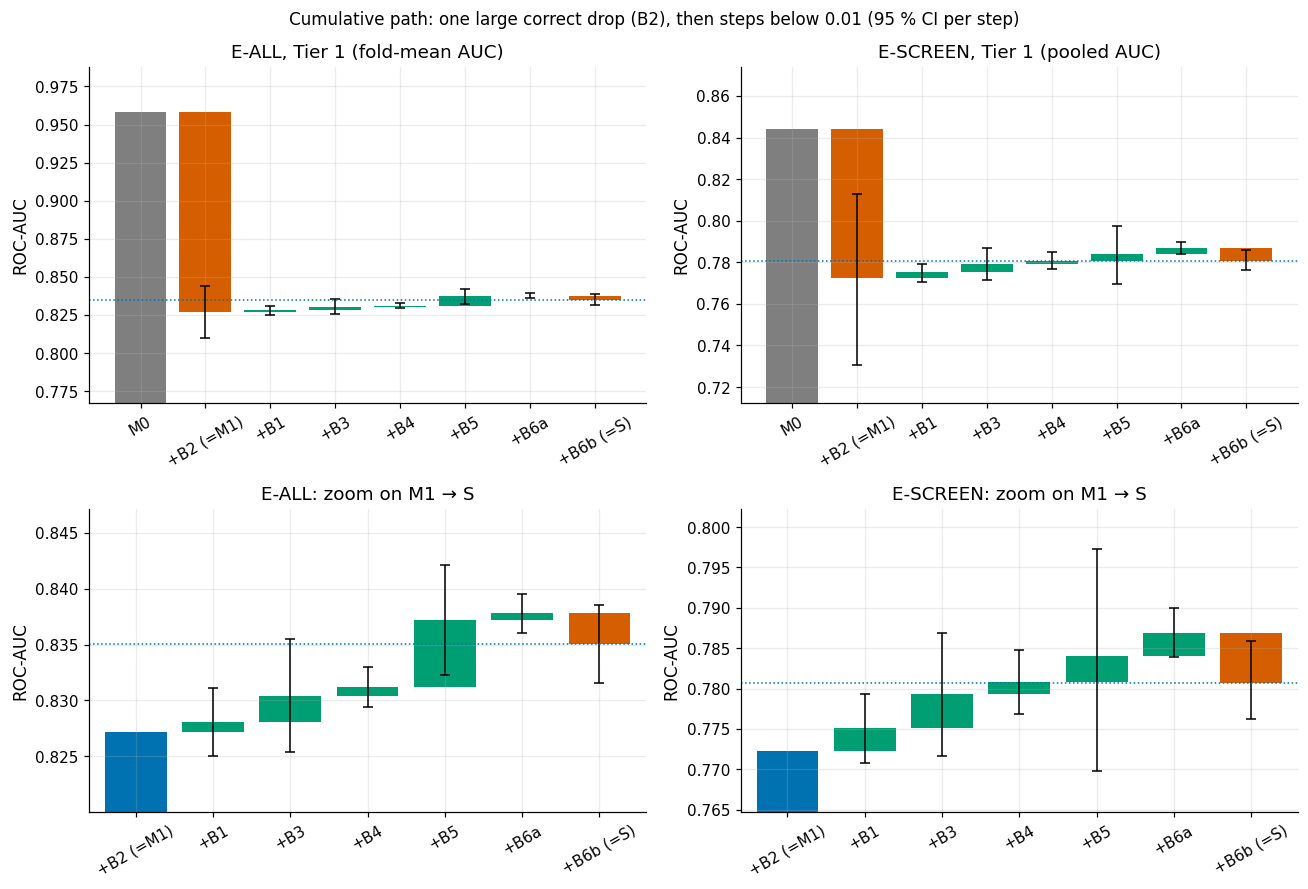

In [164]:
cum_rows = []
path = list(P.CUMULATIVE)
for t in (1, 2):
    for pop in ("E-ALL", "E-SCREEN"):
        for prev, cur in zip(path[:-1], path[1:]):
            r = cmp_(cur, prev, t, "roc_auc", pop, label="cumulative")
            r["step"] = f"{prev} -> {cur}"
            cum_rows.append(r)
cum = pd.DataFrame(cum_rows)
cum.to_csv(OUT / "cumulative_path.csv", index=False)
print(cum[cum["tier"] == 1][["pop", "step", "est", "lo", "hi", "interval", "mdd"]].round(4).to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(12, 8.2), gridspec_kw={"height_ratios": [1, 0.9]})
labels_ = ["M0", "+B2 (=M1)", "+B1", "+B3", "+B4", "+B5", "+B6a", "+B6b (=S)"]
sub = arm_metrics[(arm_metrics["tier"] == 1) & (arm_metrics["model"] == "lr")].set_index("arm")
for col, (pop, lev_col) in enumerate((("E-ALL", "eall_auc_foldmean"), ("E-SCREEN", "escr_auc"))):
    c = cum[(cum["tier"] == 1) & (cum["pop"] == pop)].reset_index(drop=True)
    levels = [sub.loc[path[0], lev_col]]
    for _, r in c.iterrows():
        levels.append(levels[-1] + r["est"])     # E-ALL: fold-mean steps; E-SCREEN: pooled steps
    for row, start in ((0, 0), (1, 1)):          # row 1 = zoom on M1 -> S
        ax = axes[row, col]
        ax.bar(start, levels[start], color=C.OKABE_ITO["grey"] if start == 0 else C.OKABE_ITO["blue"])
        for i in range(start, len(c)):
            r, d = c.loc[i], c.loc[i, "est"]
            ax.bar(i + 1, d, bottom=levels[i], color=C.OKABE_ITO["vermillion"] if d < 0 else C.OKABE_ITO["green"])
            ax.errorbar(i + 1, levels[i] + d, yerr=[[max(d - r["lo"], 0)], [max(r["hi"] - d, 0)]], color="k", capsize=3, lw=1)
        ax.axhline(levels[-1], color=C.OKABE_ITO["blue"], ls=":", lw=1)
        ax.set_xticks(range(start, len(labels_)), labels_[start:], rotation=30)
        span = [levels[k] + dlt for k in range(start, len(c)) for dlt in (0, c.loc[k, "lo"], c.loc[k, "hi"])]
        if row == 0:
            ax.set_ylim(min(levels) - 0.06, max(levels) + 0.03)
            ax.set_title(f"{pop}, Tier 1 ({'fold-mean' if pop == 'E-ALL' else 'pooled'} AUC)")
        else:
            ax.set_ylim(min(span) - 0.005, max(span) + 0.005)
            ax.set_xlim(start - 0.6, len(labels_) - 0.4)
            ax.set_title(f"{pop}: zoom on M1 → S")
        ax.set_ylabel("ROC-AUC")
fig.suptitle("Cumulative path: one large correct drop (B2), then steps below 0.01 (95 % CI per step)", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S7_waterfall", caption="Waterfall of the ROC-AUC along the cumulative path M0 -> +B2 -> +B1 -> +B3 -> +B4 -> +B5 -> +B6a -> +B6b (= S), "
              "Tier 1. E-ALL: fold-mean AUC and fold-mean paired differences with the conservative 95 % CI (wider of corrected t and "
              "bootstrap); E-SCREEN: pooled-OOF AUC and bootstrap CI. Bottom row: zoom on the steps after the leak gate. "
              "Red = decrease, green = increase; dotted line = S.")
plt.show()

**So what.** After the leak gate, every block moves the AUC by less than the 0.01 SESOI on E-ALL, and each step is of
the same size as its own MDD. The systematic pipeline does not "buy" discrimination; its value lies elsewhere
(fidelity, stability, calibration), which is what the block hypotheses predicted and what the following sections test.

## 7.8 Leave-one-block-out
**Why.** The contribution of a block given every other step is S − (S without the block). These are the primary
block comparisons of the locked hypotheses, evaluated on both populations and both tiers, plus the extra arms
S-linear (splines only), S+WHtR (P14) and T1-minus-care.

     pop      block     est      lo      hi    interval    mdd
   E-ALL         B1  0.0019 -0.0011  0.0049 corrected_t 0.0042
   E-ALL         B2 -0.1217 -0.1381 -0.1053 corrected_t 0.0232
   E-ALL         B3  0.0019 -0.0018  0.0055 corrected_t 0.0051
   E-ALL         B4  0.0002 -0.0019  0.0024 corrected_t 0.0030
   E-ALL         B5  0.0065  0.0024  0.0107   bootstrap 0.0063
   E-ALL        B6a  0.0006 -0.0017  0.0028 corrected_t 0.0032
   E-ALL        B6b -0.0027 -0.0062  0.0008 corrected_t 0.0050
   E-ALL    splines  0.0038  0.0005  0.0074   bootstrap 0.0050
   E-ALL   P14 WHtR -0.0009 -0.0028  0.0009 corrected_t 0.0026
   E-ALL care items  0.0159  0.0094  0.0220   bootstrap 0.0095
E-SCREEN         B1  0.0027 -0.0015  0.0072   bootstrap 0.0063
E-SCREEN         B2 -0.0904 -0.1243 -0.0598   bootstrap 0.0466
E-SCREEN         B3  0.0043 -0.0000  0.0089   bootstrap 0.0064
E-SCREEN         B4  0.0017 -0.0031  0.0076   bootstrap 0.0077
E-SCREEN         B5  0.0033 -0.0104  0.0153   bootstrap

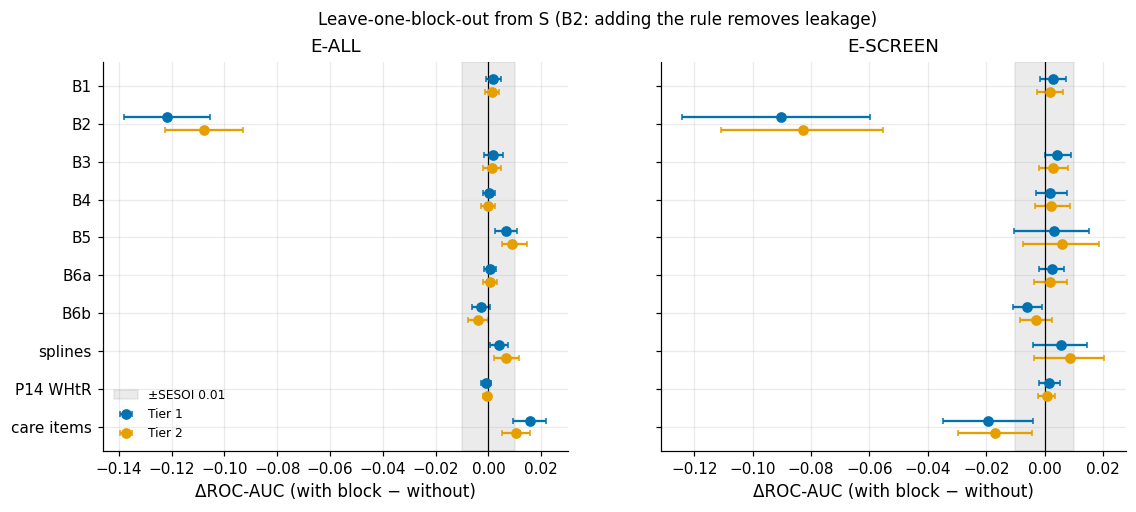

In [165]:
lobo_pairs = [("S", f"S-{b}", b) for b in P.BLOCKS] + [("S", "S-linear", "splines"), ("S+WHtR", "S", "P14 WHtR"),
                                                       ("S", "T1-minus-care", "care items")]
lobo_rows = []
for t in (1, 2):
    for pop in ("E-ALL", "E-SCREEN"):
        for a, b, lab in lobo_pairs:
            for metric in ("roc_auc", "pr_auc", "brier"):
                r = cmp_(a, b, t, metric, pop, label=f"LOBO {lab}")
                r["block"] = lab
                lobo_rows.append(r)
lobo = pd.DataFrame(lobo_rows)
lobo.to_csv(OUT / "lobo.csv", index=False)
v_ = lobo[(lobo["tier"] == 1) & (lobo["metric"] == "roc_auc")]
print(v_[["pop", "block", "est", "lo", "hi", "interval", "mdd"]].round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
order = [lab for _, _, lab in lobo_pairs]
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    for t, off, col in ((1, -0.17, C.OKABE_ITO["blue"]), (2, 0.17, C.OKABE_ITO["orange"])):
        s = lobo[(lobo["tier"] == t) & (lobo["metric"] == "roc_auc") & (lobo["pop"] == pop)].set_index("block").loc[order]
        ax.errorbar(s["est"], np.arange(len(order)) + off, xerr=[s["est"] - s["lo"], s["hi"] - s["est"]], fmt="o",
                    color=col, capsize=2, label=f"Tier {t}")
    ax.axvspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=C.OKABE_ITO["grey"], alpha=0.15, label="±SESOI 0.01")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(range(len(order)), order)
    ax.set_xlabel("ΔROC-AUC (with block − without)")
    ax.set_title(pop)
axes[0].invert_yaxis()
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Leave-one-block-out from S (B2: adding the rule removes leakage)", fontsize=11)
plots.savefig(fig, "S7_lobo", caption="Leave-one-block-out ΔROC-AUC = AUC(arm with the block) − AUC(arm without it) with conservative 95 % CIs, Tier 1 (blue) and "
              "Tier 2 (orange), E-ALL and E-SCREEN; grey band = ±SESOI 0.01. Every row is 'with − without': B2 is negative because adding the "
              "rule removes leakage; 'care items' = S − T1-minus-care (S keeps BPQ020/BPQ080); 'P14 WHtR' = S+WHtR − S.")
plt.show()

**So what.** Apart from B2 (whose negative sign is the leakage being removed), the block effects on discrimination
are small; their intervals decide between "equivalent" (inside the grey band) and "inconclusive" (crossing it).
The striking line is **care items** (S, which keeps "told high blood pressure / high cholesterol", minus the arm
without them): keeping them helps on E-ALL but *hurts* on E-SCREEN. The care-contact items help to recognise people
the health system already knows, which is not the screening task.

## 7.9 E-ALL vs E-SCREEN
**Why.** 84 % of the `L_comb` positives already know their diagnosis, so an AUC on E-ALL largely measures how well a
model recognises *known* patients – people who carry traces of care (blood-pressure treatment, cholesterol checks,
weight advice). The screening question is E-SCREEN. The gap between the two is a headline result (H2c).

S (Tier 1): AUC E-ALL 0.836 - E-SCREEN 0.781 = +0.055 [+0.028, +0.086] (bootstrap, MDD 0.040)
same 3,807 negatives in both populations; positives: E-ALL 777 (all L_comb), E-SCREEN 127 (undiagnosed only); gap lower bound 0.028 vs pre-registered magnitude 0.03


          arm  eall  eall_lo  eall_hi  escr  escr_lo  escr_hi   gap
           M0 0.961    0.952    0.968 0.844    0.809    0.879 0.117
           M1 0.828    0.814    0.841 0.772    0.739    0.804 0.056
            S 0.836    0.822    0.848 0.781    0.746    0.812 0.055
     S-linear 0.832    0.818    0.845 0.775    0.741    0.807 0.057
T1-minus-care 0.820    0.808    0.835 0.800    0.766    0.831 0.020
       S+WHtR 0.835    0.821    0.847 0.782    0.749    0.814 0.053
       S (T2) 0.850    0.836    0.863 0.790    0.756    0.821 0.060
BL-ADAlite-LR 0.768    0.750    0.786 0.708    0.666    0.750 0.060
   BL-ADAlite 0.761    0.745    0.778 0.726    0.687    0.769 0.035


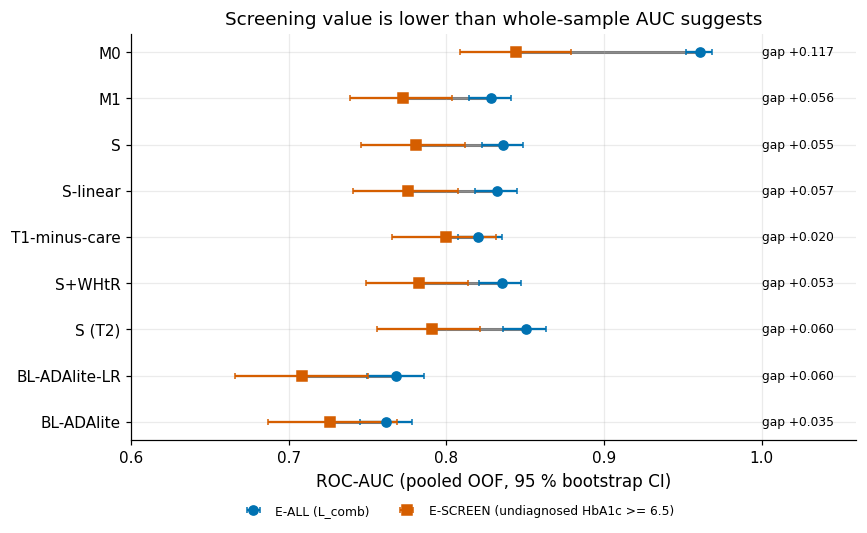

In [166]:
rng = np.random.default_rng(ek.derive_seed(C.SEED_MASTER, "S7", "H2c-i"))
groups = [np.flatnonzero(strat == s) for s in np.unique(strat)]
pS = PM[("S", 1, "lr")]
gaps = []
for _ in range(C.N_BOOT):
    idx = np.concatenate([rng.choice(g, len(g)) for g in groups])
    e = idx[esc[idx]]
    gaps.append(roc_auc_score(y[idx], pS[idx]) - roc_auc_score(y_esc[e], pS[e]))
gaps = np.array(gaps)
gap_obs = roc_auc_score(y, pS) - roc_auc_score(y_esc[esc], pS[esc])
gap_lo, gap_hi = np.percentile(gaps, [2.5, 97.5])
h2c1 = dict(a="S", b="S", tier=1, metric="roc_auc", pop="E-ALL minus E-SCREEN", est=gap_obs, lo=gap_lo, hi=gap_hi,
            se=gaps.std(ddof=1), interval="bootstrap", mdd=(stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) * gaps.std(ddof=1),
            label="H2c(i)")
COMP.append(h2c1)
print(f"S (Tier 1): AUC E-ALL {roc_auc_score(y, pS):.3f} - E-SCREEN {roc_auc_score(y_esc[esc], pS[esc]):.3f} = {fmt(h2c1)}")
neg_eall, neg_escr = set(np.flatnonzero(y == 0)), set(np.flatnonzero(esc & (y_esc == 0)))
assert neg_eall == neg_escr, "E-ALL and E-SCREEN must share the same negatives"
print(f"same {len(neg_eall):,} negatives in both populations; positives: E-ALL {int(y.sum())} (all L_comb), "
      f"E-SCREEN {int(y_esc[esc].sum())} (undiagnosed only); gap lower bound {h2c1['lo']:.3f} vs pre-registered magnitude 0.03")

pairs = [("M0", 1, "lr"), ("M1", 1, "lr"), ("S", 1, "lr"), ("S-linear", 1, "lr"), ("T1-minus-care", 1, "lr"),
         ("S+WHtR", 1, "lr"), ("S", 2, "lr"), ("BL-ADAlite-LR", 1, "lr"), ("BL-ADAlite", 1, "points")]
dumb = []
for k in pairs:
    a1, l1, h1 = auc_ci(PM[k], "E-ALL", seed_tag=f"d{k}")
    a2, l2, h2 = auc_ci(PM[k], "E-SCREEN", seed_tag=f"d{k}")
    dumb.append(dict(arm=f"{k[0]}" + (" (T2)" if k[1] == 2 else ""), eall=a1, eall_lo=l1, eall_hi=h1, escr=a2, escr_lo=l2, escr_hi=h2))
dumb = pd.DataFrame(dumb)
dumb["gap"] = dumb["eall"] - dumb["escr"]
dumb.to_csv(OUT / "eall_vs_escreen.csv", index=False)
print(dumb.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for i, r in dumb.iterrows():
    ax.plot([r["escr"], r["eall"]], [i, i], color=C.OKABE_ITO["grey"], lw=2, zorder=1)
    ax.errorbar(r["eall"], i, xerr=[[r["eall"] - r["eall_lo"]], [r["eall_hi"] - r["eall"]]], fmt="o", color=C.OKABE_ITO["blue"],
                capsize=2, label="E-ALL (L_comb)" if i == 0 else None, zorder=2)
    ax.errorbar(r["escr"], i, xerr=[[r["escr"] - r["escr_lo"]], [r["escr_hi"] - r["escr"]]], fmt="s", color=C.OKABE_ITO["vermillion"],
                capsize=2, label="E-SCREEN (undiagnosed HbA1c >= 6.5)" if i == 0 else None, zorder=2)
    ax.text(1.0, i, f"gap {r['gap']:+.3f}", va="center", fontsize=8)
ax.set_yticks(range(len(dumb)), dumb["arm"])
ax.invert_yaxis()
ax.set_xlim(0.6, 1.06)
ax.set_xlabel("ROC-AUC (pooled OOF, 95 % bootstrap CI)")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.13), ncol=2, fontsize=8, frameon=False)
ax.set_title("Screening value is lower than whole-sample AUC suggests")
plots.savefig(fig, "S7_eall_vs_escreen", caption="ROC-AUC on E-ALL (blue, L_comb, 84 % already diagnosed) and E-SCREEN (red, people not told they have "
              "diabetes, positive = HbA1c >= 6.5 %) for the main arms and baselines, Tier 1 unless marked, with 95 % bootstrap CIs.")
plt.show()

**So what.** The two populations share exactly the same negatives (asserted); only the positives differ. The gap is
therefore a pure **spectrum (case-mix) effect**: known diabetics, with treatment, care contacts and higher HbA1c, are
easier to rank above the negatives than the undiagnosed. For the systematic model the gap is about 0.055; its lower
bound (printed, about 0.028) lies just below the pre-registered magnitude of 0.03, so a gap of exactly that size is not
excluded although the rule's point-estimate criterion is met. The smaller gaps of T1-minus-care and the ADA-lite score
are the mirror image: the less a model relies on care-contact traces, the less it loses. A whole-sample AUC therefore
overstates screening value – the label composition, not the model, sets the headline number.

## 7.10 Precision–recall and calibration
**Why.** AUC ignores prevalence and calibration. E-SCREEN has a prevalence of about 3 %, so precision is the binding
constraint in screening, and a model trained on `L_comb` (17 %) is miscalibrated there by design. Class weights
(B6a) inflate probabilities further.

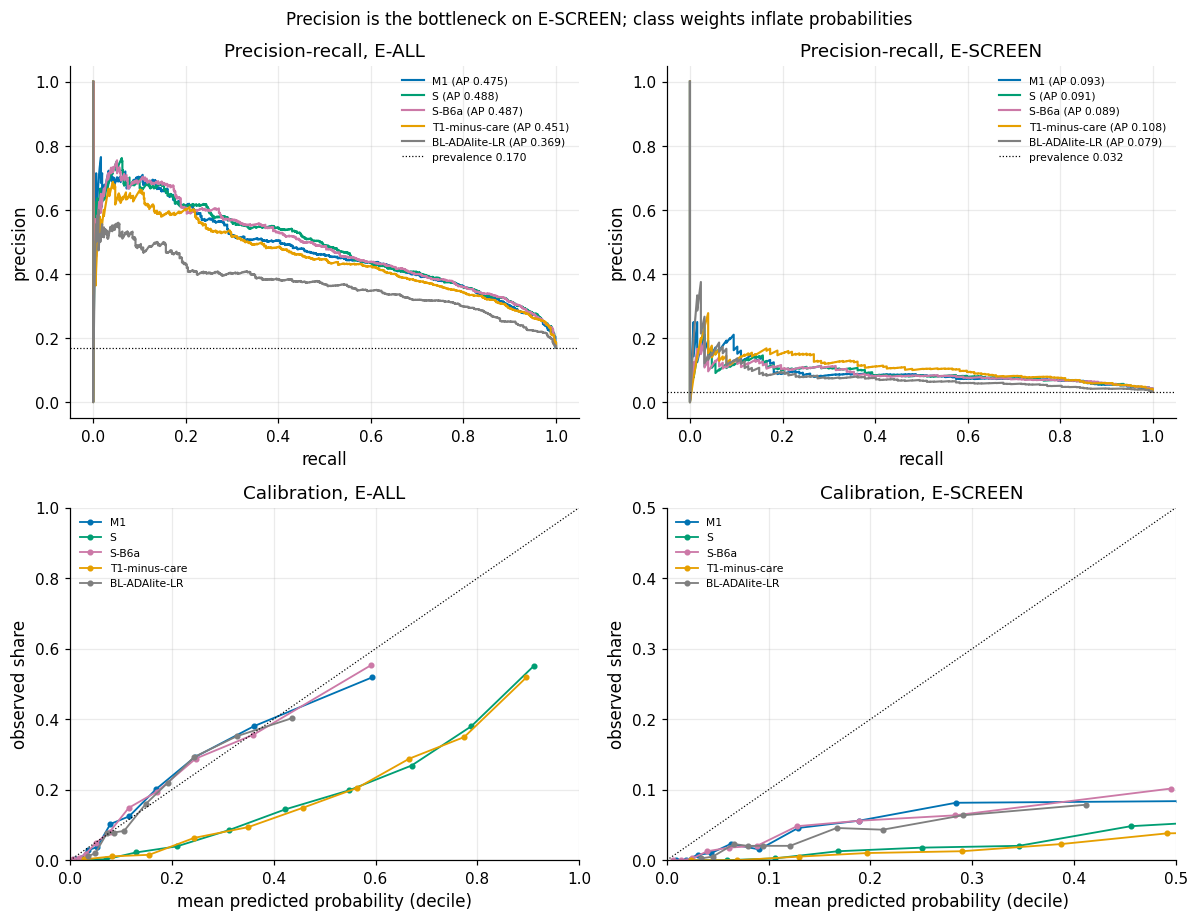

          arm      pop  cal_slope  cal_citl  brier  mean_p  prevalence
           M1    E-ALL      0.961     0.010  0.112   0.168       0.170
            S    E-ALL      0.867    -1.818  0.185   0.409       0.170
        S-B6a    E-ALL      0.979     0.027  0.110   0.167       0.170
T1-minus-care    E-ALL      0.873    -1.807  0.195   0.422       0.170
BL-ADAlite-LR    E-ALL      1.124    -0.001  0.123   0.170       0.170
           M1 E-SCREEN      0.685    -1.814  0.056   0.136       0.032
            S E-SCREEN      0.613    -3.671  0.196   0.357       0.032
        S-B6a E-SCREEN      0.688    -1.783  0.055   0.133       0.032
T1-minus-care E-SCREEN      0.723    -3.684  0.205   0.376       0.032
BL-ADAlite-LR E-SCREEN      0.831    -1.799  0.054   0.152       0.032


In [167]:
from sklearn.metrics import precision_recall_curve
from sklearn.calibration import calibration_curve

curve_keys = [("M1", 1, "lr", C.OKABE_ITO["blue"]), ("S", 1, "lr", C.OKABE_ITO["green"]),
              ("S-B6a", 1, "lr", C.OKABE_ITO["purple"]), ("T1-minus-care", 1, "lr", C.OKABE_ITO["orange"]),
              ("BL-ADAlite-LR", 1, "lr", C.OKABE_ITO["grey"])]
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
cal_rows = []
for col, pop in enumerate(("E-ALL", "E-SCREEN")):
    yy, m = pop_of(pop)
    for a, t, mdl, colr in curve_keys:
        p = PM[(a, t, mdl)][m]
        prec, rec, _ = precision_recall_curve(yy[m], p)
        axes[0, col].plot(rec, prec, color=colr, lw=1.4, label=f"{a} (AP {average_precision_score(yy[m], p):.3f})")
        fr, mp = calibration_curve(yy[m], p, n_bins=10, strategy="quantile")
        axes[1, col].plot(mp, fr, "o-", color=colr, ms=3, lw=1.2, label=a)
        ms_ = ek.metric_suite(yy[m], p)
        cal_rows.append(dict(arm=a, pop=pop, cal_slope=ms_["cal_slope"], cal_citl=ms_["cal_citl"], brier=ms_["brier"],
                             mean_p=float(p.mean()), prevalence=float(yy[m].mean())))
    axes[0, col].axhline(yy[m].mean(), color="k", ls=":", lw=0.8, label=f"prevalence {yy[m].mean():.3f}")
    axes[0, col].set(xlabel="recall", ylabel="precision", title=f"Precision-recall, {pop}")
    axes[0, col].legend(fontsize=7)
    lim = 1.0 if pop == "E-ALL" else 0.5
    axes[1, col].plot([0, lim], [0, lim], color="k", lw=0.8, ls=":")
    axes[1, col].set(xlabel="mean predicted probability (decile)", ylabel="observed share", title=f"Calibration, {pop}",
                     xlim=(0, lim), ylim=(0, lim))
    axes[1, col].legend(fontsize=7)
fig.suptitle("Precision is the bottleneck on E-SCREEN; class weights inflate probabilities", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S7_pr_calibration", caption="Top: precision-recall curves (average precision in the legend; dotted line = prevalence). Bottom: "
              "calibration by deciles of the predicted probability. Left E-ALL, right E-SCREEN; Tier 1 pooled OOF predictions. S uses "
              "balanced class weights; S-B6a is S without them.")
plt.show()
cal = pd.DataFrame(cal_rows)
cal.to_csv(OUT / "calibration.csv", index=False)
print(cal.round(3).to_string(index=False))

**So what.** On E-ALL the precision–recall curves of the admissible models are close together; on E-SCREEN average
precision is only about 0.1 against a prevalence of about 0.03 – a screening tool built on these items would mostly flag
people without diabetes. The calibration panels show the price of class weights: S predicts on average far above the
observed prevalence, whereas S−B6a (no class weights) is close to the diagonal on E-ALL. On E-SCREEN every model
over-predicts, because it was trained on a population in which 17 % are positive, most of them already diagnosed.

## 7.11 Coefficient stability
**Why.** Discrimination can hide unstable explanations: collinear anthropometrics share the BMI signal differently in
every resample. The nonparametric bootstrap of the whole pipeline (B = 500 in FINAL; 30 in the FAST re-run mode, where the
Monte Carlo intervals of the ratios are correspondingly wider) measures this. BMI is compared
per standard deviation across the arms in which it enters linearly (S is represented by S-linear, see
`hypotheses.md`); B3b compares S-linear−B3 with S-linear, H2b compares M1 with S-linear.

        arm  bmi_coef_per_sd  bmi_sd_per_sd  bmi_q_low  bmi_q_high  bmi_sign_flip  max_flip_anthro             anthro_in_model  n_coef  n_valid  share_flip_gt_10pct
         M1            0.585          0.301     -0.164       1.075          0.120            0.822 BMXBMI,BMXWT,BMXHT,BMXWAIST      46      500                0.391
     cum+B1            0.240          0.354     -0.160       1.186          0.124            0.348 BMXBMI,BMXWT,BMXHT,BMXWAIST      46      500                0.457
     cum+B3            0.407          0.124      0.199       0.694          0.000            0.134       BMXBMI,BMXHT,BMXWAIST      29      500                0.276
S-linear-B3            0.338          0.207      0.041       0.917          0.010            0.092 BMXBMI,BMXWT,BMXHT,BMXWAIST      50      337                0.500
   S-linear            0.699          0.152      0.433       1.035          0.000            0.484       BMXBMI,BMXHT,BMXWAIST      34      500                0.353
SD ratio B

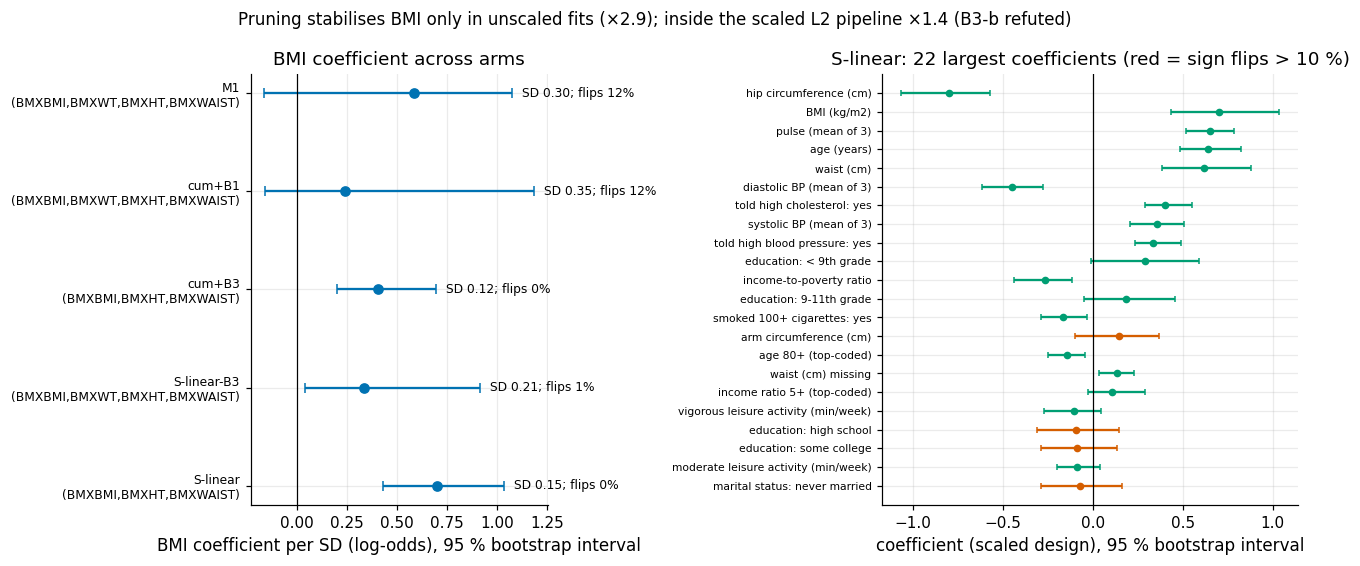

In [168]:
coef_arms = ["M1", "cum+B1", "cum+B3", "S-linear-B3", "S-linear"]
CB, coef_rows = {}, []
for arm in coef_arms:
    cfg = P.ARMS[arm]
    ylab_ = P.training_label(raw_tr, cfg)
    mk = (lambda cfg=cfg: P.build_pipeline(cfg, 1, C_=C0))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        cb = ek.coef_bootstrap(mk, X[1], ylab_, n_boot=B_COEF, seed=ek.derive_seed(C.SEED_MASTER, "S7", "coef", arm),
                               fit_params=P.fit_params(cfg, raw_tr), n_jobs=N_JOBS)
        dsg = mk()[:-1].fit_transform(X[1])
    sd_bmi = float(dsg["BMXBMI"].std(ddof=0))
    CB[arm] = (cb, sd_bmi)
    s = cb.summary
    anth = [c for c in ("BMXBMI", "BMXWT", "BMXHT", "BMXWAIST") if c in s.index]
    coef_rows.append(dict(arm=arm, bmi_coef_per_sd=s.loc["BMXBMI", "coef"] * sd_bmi, bmi_sd_per_sd=s.loc["BMXBMI", "sd"] * sd_bmi,
                          bmi_q_low=s.loc["BMXBMI", "q_low"] * sd_bmi, bmi_q_high=s.loc["BMXBMI", "q_high"] * sd_bmi,
                          bmi_sign_flip=s.loc["BMXBMI", "sign_flip_rate"], max_flip_anthro=s.loc[anth, "sign_flip_rate"].max(),
                          anthro_in_model=",".join(anth), n_coef=len(s), n_valid=int(s["n_valid"].min()),
                          share_flip_gt_10pct=float((s["sign_flip_rate"] > 0.10).mean())))
coef_tab = pd.DataFrame(coef_rows)
coef_tab.to_csv(OUT / "coef_stability.csv", index=False)
print(coef_tab.round(3).to_string(index=False))

def sd_ratio(arm_a, arm_b, n_rs=2000):
    """SD(BMI per SD) of arm_a over arm_b with a Monte Carlo interval from resampling the B bootstrap replicates.

    The interval reflects the Monte Carlo error of the two SD estimates for the given number of replicates B (it narrows
    as B grows); it is not a sampling interval of the population ratio.
    """
    (ca, fa), (cb_, fb) = CB[arm_a], CB[arm_b]
    xa = ca.coefs["BMXBMI"].dropna().to_numpy() * fa
    xb = cb_.coefs["BMXBMI"].dropna().to_numpy() * fb
    r = np.random.default_rng(ek.derive_seed(C.SEED_MASTER, "S7", "ratio", arm_a, arm_b))
    rs = [xa[r.integers(0, len(xa), len(xa))].std(ddof=1) / xb[r.integers(0, len(xb), len(xb))].std(ddof=1) for _ in range(n_rs)]
    lo, hi = np.percentile(rs, [2.5, 97.5])
    return dict(a=arm_a, b=arm_b, ratio=xa.std(ddof=1) / xb.std(ddof=1), lo=lo, hi=hi)

def v_ratio(d, thr=C.SESOI["coef_sd_ratio"]):
    return "supported" if (d["ratio"] >= thr and d["lo"] > 1) else ("refuted" if d["hi"] < thr else "inconclusive")

ratio_b3 = sd_ratio("S-linear-B3", "S-linear")
ratio_h2b = sd_ratio("M1", "S-linear")
ratio_cum = sd_ratio("cum+B1", "cum+B3")
for d in (ratio_b3, ratio_h2b, ratio_cum):
    print(f"SD ratio BMI {d['a']} / {d['b']}: {d['ratio']:.2f}, Monte Carlo interval [{d['lo']:.2f}, {d['hi']:.2f}] "
          f"(B = {B_COEF}) -> {v_ratio(d)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
for i, r in coef_tab.iterrows():
    ax.errorbar(r["bmi_coef_per_sd"], i, xerr=[[r["bmi_coef_per_sd"] - r["bmi_q_low"]], [r["bmi_q_high"] - r["bmi_coef_per_sd"]]],
                fmt="o", color=C.OKABE_ITO["blue"], capsize=3)
    ax.text(r["bmi_q_high"] + 0.05, i, f"SD {r['bmi_sd_per_sd']:.2f}; flips {r['bmi_sign_flip']:.0%}", va="center", fontsize=8)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(coef_tab)), [f"{a}\n({x})" for a, x in zip(coef_tab["arm"], coef_tab["anthro_in_model"])], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("BMI coefficient per SD (log-odds), 95 % bootstrap interval")
ax.set_title("BMI coefficient across arms")
cbS, _ = CB["S-linear"]
ref_levels = {f"{v}_{float(cl[v].mode().iloc[0]) if pd.api.types.is_numeric_dtype(cl[v]) else cl[v].mode().iloc[0]}"
              for v in P.categorical_columns() if v in cl.columns and cl[v].notna().any()}
disp = cbS.summary.drop(index=[c for c in cbS.summary.index if c in ref_levels])   # reference level of each category dropped
s = disp.reindex(disp["coef"].abs().sort_values(ascending=False).index)[:22]
ax = axes[1]
for i, (nm, r) in enumerate(s.iterrows()):
    colr = C.OKABE_ITO["vermillion"] if r["sign_flip_rate"] > 0.10 else C.OKABE_ITO["green"]
    ax.errorbar(r["coef"], i, xerr=[[r["coef"] - r["q_low"]], [r["q_high"] - r["coef"]]], fmt="o", color=colr, capsize=2, ms=4)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(s)), [P.plain_label(c) for c in s.index], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("coefficient (scaled design), 95 % bootstrap interval")
ax.set_title("S-linear: 22 largest coefficients (red = sign flips > 10 %)")
fig.suptitle(f"Pruning stabilises BMI only in unscaled fits (×{ratio_cum['ratio']:.1f}); inside the scaled L2 pipeline "
             f"×{ratio_b3['ratio']:.1f} (B3-b {v_ratio(ratio_b3)})", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S7_coef_forest", caption="Left: bootstrap distribution (point = full-data fit, bar = 2.5-97.5 percentile) of the BMI coefficient per SD in the arms "
              "where BMI enters linearly, with the anthropometric columns present in each arm. Right: the 22 largest coefficients of S-linear "
              "(most frequent level of each category omitted for display); "
              f"red = sign flips in more than 10 % of the {B_COEF} bootstrap refits. Tier 1, training part.")
plt.show()
S7["coef_stability"] = dict(table=coef_tab.set_index("arm").to_dict("index"), ratio_B3=ratio_b3, ratio_H2b=ratio_h2b, ratio_cumulative=ratio_cum)

**So what.** Where weight, height and BMI enter together the BMI coefficient is shared with its formula partners. In the
naive, unscaled arms (M1, cum+B1) this is severe: intervals that cross zero and sign flips in about one resample in
eight. Removing weight (B3) in the same unscaled setting shrinks the BMI SD by a factor of about 3 (cum+B1 / cum+B3),
and the systematic model is about twice as stable as M1 – but the interval of that ratio straddles the pre-registered
factor 2, so H2b-c is inconclusive rather than supported. *Inside* the systematic pipeline, scaling and the L2 penalty
already do much of the stabilising: the B3-specific ratio (S-linear−B3 / S-linear) is only about 1.4 and its interval
excludes 2, so B3-b is **refuted**. The pre-registered sign-flip criterion (B3-c) turned out to be a poor metric: after
pruning, the *height* coefficient is close to zero (it carries no signal once BMI is present), and a near-zero
coefficient flips sign in about half of the resamples by construction – the BMI coefficient itself no longer flips.
This is reported as a refutation of B3-c, with the mechanism, not explained away. The discrimination of all these
arms is the same (section 8); only the stability of the explanation differs – the measurement-instrument use of ML.
The intervals of the SD ratios are *Monte Carlo* intervals: they resample the B bootstrap replicates and therefore
shrink as B grows (FINAL B = 500); they quantify simulation error, not sampling uncertainty of the ratio itself.

### 7.11.1 Post-hoc exploratory: how much of the stability comes from the penalty?
**Why.** *Not pre-registered; added after an independent audit, does not change any verdict.* Two readings above depend
on the fitting regime: the B3 ratio is computed under the frozen penalty C0, and the unscaled ratios (cum+B1/cum+B3,
M1/S-linear) come from fits that stop at the iteration limit. Re-running the B3 contrast at weaker penalties shows how
much of the stabilisation the L2 penalty already provides.

In [169]:
C_grid = [C0, 1.0, 100.0, 1e4]
B_s = 200 if C.IS_FINAL else 20   # replicates per arm and C (exploratory; FAST re-run mode uses fewer)
cs_rows = []
for c_ in C_grid:
    sd_ = {}
    for arm in ("S-linear-B3", "S-linear"):
        cfg = P.ARMS[arm]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            cb_ = ek.coef_bootstrap(lambda cfg=cfg, c_=c_: P.build_pipeline(cfg, 1, C_=c_), X[1], P.training_label(raw_tr, cfg),
                                    n_boot=B_s, seed=ek.derive_seed(C.SEED_MASTER, "S7", "Csens", arm, str(c_)),
                                    fit_params=P.fit_params(cfg, raw_tr), n_jobs=N_JOBS)
        sd_[arm] = float(cb_.coefs["BMXBMI"].std(ddof=1))
    cs_rows.append(dict(C=c_, sd_bmi_without_B3=sd_["S-linear-B3"], sd_bmi_with_B3=sd_["S-linear"],
                        ratio=sd_["S-linear-B3"] / sd_["S-linear"]))
c_sens = pd.DataFrame(cs_rows)
c_sens.to_csv(OUT / "posthoc_c_sensitivity.csv", index=False)
conv = diag[(diag["tier"] == 1) & (diag["model"] == "lr") & diag["arm"].isin(["M1", "cum+B1", "cum+B3"])]
print(f"post-hoc, scaled arms, B = {B_s} per C (per-SD BMI coefficient):")
print(c_sens.round(3).to_string(index=False))
print("unscaled arms behind the larger ratios - CV folds ending at the iteration limit: "
      + ", ".join(f"{a} {k}/{len(folds)}" for a, k in zip(conv["arm"], conv["n_convergence_warnings"])))
S7["posthoc_c_sensitivity"] = dict(table=c_sens.to_dict("records"), unscaled_nonconvergence=dict(zip(conv["arm"], conv["n_convergence_warnings"].astype(int))),
                                   n_folds=len(folds), note="post hoc, exploratory, no verdict change")

post-hoc, scaled arms, B = 200 per C (per-SD BMI coefficient):
      C  sd_bmi_without_B3  sd_bmi_with_B3  ratio
    0.1              0.208           0.164  1.268
    1.0              0.576           0.210  2.741
  100.0              0.764           0.228  3.350
10000.0              0.834           0.213  3.916
unscaled arms behind the larger ratios - CV folds ending at the iteration limit: M1 25/25, cum+B1 25/25, cum+B3 25/25


**So what (exploratory).** With the frozen penalty the pruning step adds little stability; as the penalty is relaxed
towards an unpenalised fit the ratio grows several-fold (table above). The L2 penalty and pruning are therefore partly
*substitutes*: either one tames the weight–height–BMI collinearity. The large unscaled ratios (cum+B1/cum+B3, and the
M1/S-linear ratio behind H2b-c) must be read with care: those pipelines hit the iteration limit in every CV fold, so
part of their coefficient spread is optimiser noise rather than collinearity – they are confounded by
non-convergence and are not used to argue for B3.

## 7.12 Verdicts
**Why.** Each locked hypothesis gets exactly one verdict from the locked rules: the primary evaluation is E-ALL,
Tier 1; E-SCREEN and Tier 2 can only turn a decisive verdict into "mixed" if they contradict it. The verdict lines
printed below are generated from the results. The interpretation that follows refers to the FINAL run stored in this
notebook (5 × 5 CV, B = 1000, coefficient B = 500); a FAST re-run (5 × 2, B = 100, coefficient B = 30) reproduces every leakage,
equivalence and class-weight verdict, but borderline ones (B3-b, B5-a, H2b) can move between "inconclusive" and a
decisive verdict.

In [170]:
def lrtest_splines(tier=1):
    """Likelihood-ratio test spline bases vs linear terms (unpenalised logit, S design, training part)."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import log_loss
    cfg = P.ARMS["S"]
    yl = P.training_label(raw_tr, cfg)
    dS = P.build_pipeline(cfg, tier)[:-1].fit_transform(X[tier])
    dL = P.build_pipeline({**cfg, "P08": False}, tier)[:-1].set_params(p13__enabled=False).fit_transform(X[tier])
    spl_cols = [c for c in dS.columns if "_sp" in c]
    lin = [c.split("_sp")[0] for c in spl_cols]
    base = [c for c in dS.columns if c not in spl_cols]
    dL = pd.concat([dS[base], dL[sorted(set(lin))]], axis=1)
    ll = {}
    for nm, d in (("spline", dS), ("linear", dL)):
        m = LogisticRegression(C=1e8, max_iter=20000).fit(d, yl)
        ll[nm] = -log_loss(yl, m.predict_proba(d)[:, 1], normalize=False)
    df_ = len(spl_cols) - len(set(lin))
    chi2 = 2 * (ll["spline"] - ll["linear"])
    return dict(chi2=chi2, df=df_, p=float(stats.chi2.sf(chi2, df_)))

lrt = {t: lrtest_splines(t) for t in (1, 2)}
print(f"B5(d) LR test splines vs linear: {lrt}")

def get(a, b, metric="roc_auc", pop="E-ALL", tier=1, **kw):
    return cmp_(a, b, tier, metric, pop, label="verdict", **kw)

SB = []   # scoreboard rows
def add(hyp, sub, r, verdict, sesoi, role="primary"):
    SB.append(dict(hyp_id=hyp, sub=sub, role=role, comparison=f"{r.get('a')} - {r.get('b')}", metric=r.get("metric"),
                   pop=r.get("pop"), tier=r.get("tier"), est=r.get("est"), lo=r.get("lo"), hi=r.get("hi"),
                   interval=r.get("interval"), mdd=r.get("mdd"), sesoi=sesoi, verdict=verdict))

def equiv_claim(hyp, sub, a, b, s=0.01, metric="roc_auc"):
    for pop, tier, role in (("E-ALL", 1, "primary"), ("E-SCREEN", 1, "secondary"), ("E-ALL", 2, "secondary")):
        r = get(a, b, metric, pop, tier)
        add(hyp, sub, r, v_equiv(r["lo"], r["hi"], s), s, role)

def dir_claim(hyp, sub, a, b, s, direction, metric="roc_auc", falsifier=None, pops=(("E-ALL", 1, "primary"), ("E-SCREEN", 1, "secondary"), ("E-ALL", 2, "secondary")), **kw):
    for pop, tier, role in pops:
        r = get(a, b, metric, pop, tier, **kw)
        v = v_dir(r["lo"], r["hi"], r["est"], s, direction)
        if falsifier is not None and falsifier(r):
            v = "refuted"
        add(hyp, sub, r, v, s, role)

# B1
equiv_claim("B1", "(a) AUC", "S", "S-B1")
# B2 (leak gate, falsifier: CI lower bound above -0.05)
dir_claim("B2", "(a) AUC M1-M0", "M1", "M0", 0.05, "-", falsifier=lambda r: r["lo"] > -0.05)
SB.append(dict(hyp_id="B2t", sub="root split", role="primary", comparison=f"M0 root {roots['M0']['root_feature']} ({roots['M0']['role']}); "
               f"M1 root {roots['M1']['root_feature']}", metric="tree", pop="training part", tier=1, verdict=b2t))
# B3
equiv_claim("B3", "(a) AUC", "S", "S-B3")
SB.append(dict(hyp_id="B3", sub="(b) BMI SD ratio", role="primary", comparison="S-linear-B3 / S-linear", metric="sd_ratio",
               pop="training part", tier=1, est=ratio_b3["ratio"], lo=ratio_b3["lo"], hi=ratio_b3["hi"], sesoi=2.0, verdict=v_ratio(ratio_b3)))
fa = coef_tab.set_index("arm")
flip_v = "supported" if fa.loc["S-linear", "max_flip_anthro"] < fa.loc["S-linear-B3", "max_flip_anthro"] else (
    "inconclusive" if fa.loc["S-linear", "max_flip_anthro"] == fa.loc["S-linear-B3", "max_flip_anthro"] else "refuted")
SB.append(dict(hyp_id="B3", sub="(c) max sign-flip rate", role="primary", comparison="S-linear vs S-linear-B3", metric="sign_flip",
               pop="training part", tier=1, est=fa.loc["S-linear", "max_flip_anthro"], lo=fa.loc["S-linear-B3", "max_flip_anthro"],
               verdict=flip_v))
# B4
equiv_claim("B4", "(a) AUC", "S", "S-B4")
dir_claim("B4", "(b) Brier, PIR missing", "S", "S-B4", 0.005, "-", metric="brier", falsifier=lambda r: r["lo"] > -0.005,
          pops=(("PIR-missing", 1, "primary"), ("PIR-missing", 2, "secondary")))
# B5
dir_claim("B5", "(a) |cal slope - 1|", "S", "S-B5", 0.0, "-", metric="calslope_dev", falsifier=lambda r: r["lo"] > 0)
equiv_claim("B5", "(b) AUC block", "S", "S-B5")
equiv_claim("B5", "(c) AUC splines", "S", "S-linear")
SB.append(dict(hyp_id="B5", sub="(d) LR test splines", role="primary", comparison="S spline vs linear terms", metric="LR chi2",
               pop="training part", tier=1, est=lrt[1]["chi2"], lo=lrt[1]["p"], verdict="supported" if lrt[1]["p"] < 0.05 else "refuted"))
SB.append(dict(hyp_id="B5", sub="(e) tree P08/P09", role="primary", comparison="S tree with/without P08,P09", metric="max |dp|",
               pop="training part", tier=1, est=json.loads((C.RESULTS_DIR / "metrics_S6.json").read_text(encoding="utf-8"))["assertions"]["tree_p08_p09_maxabs"],
               verdict="supported"))
# B6a
equiv_claim("B6a", "(a) AUC", "S", "S-B6a")
dir_claim("B6a", "(b) Brier", "S", "S-B6a", 0.005, "+", metric="brier")
dir_claim("B6a", "(c) balanced accuracy at 0.5", "S", "S-B6a", 0.05, "+", metric="bacc05")
# B6b
for pop, tier, role in (("E-ALL", 1, "primary"), ("E-SCREEN", 1, "secondary"), ("E-ALL", 2, "secondary")):
    r = get("S", "S-B6b", "roc_auc", pop, tier)
    add("B6b", "(a) unweighted AUC", r, v_noninf(r["lo"], r["hi"], 0.01), 0.01, role)
# P14
equiv_claim("P14", "(a) AUC", "S+WHtR", "S")
SB.append(dict(hyp_id="P14", sub="(b) Asian TPR@spec0.80", role="primary", comparison="S+WHtR - S", metric="TPR", pop="Asian",
               verdict="deferred to S8"))
# H2a
dir_claim("H2a", "AUC M0-M1", "M0", "M1", 0.05, "+", falsifier=lambda r: r["hi"] < 0.05)
# H2b
equiv_claim("H2b", "(a) AUC", "S", "M1")
equiv_claim("H2b", "(b) Brier", "S", "M1", s=0.005, metric="brier")
SB.append(dict(hyp_id="H2b", sub="(c) BMI SD ratio", role="primary", comparison="M1 / S-linear", metric="sd_ratio", pop="training part",
               tier=1, est=ratio_h2b["ratio"], lo=ratio_h2b["lo"], hi=ratio_h2b["hi"], sesoi=2.0, verdict=v_ratio(ratio_h2b)))
# H2c
add("H2c", "(i) AUC E-ALL - E-SCREEN (S)", h2c1, v_dir(h2c1["lo"], h2c1["hi"], h2c1["est"], 0.03, "+"), 0.03)
r = get("T1-minus-care", "S", "roc_auc", "E-ALL", 1)
add("H2c", "(ii) minus care, E-ALL", r, v_dir(r["lo"], r["hi"], r["est"], 0.01, "-"), 0.01)
r = get("T1-minus-care", "S", "roc_auc", "E-SCREEN", 1)
add("H2c", "(ii) minus care, E-SCREEN", r, v_equiv(r["lo"], r["hi"], 0.01), 0.01)
add("H2c", "(iii) S - ADA-lite, E-SCREEN", h2c3, v_dir(h2c3["lo"], h2c3["hi"], h2c3["est"], 0.01, "+"), 0.01)
for h, st in (("H1a", "S5"), ("H1b", "S4"), ("H3", "S8"), ("H4a", "S5"), ("H4b", "S5/S8")):
    SB.append(dict(hyp_id=h, sub="-", role="primary", verdict=f"tested in {st}"))

sb = pd.DataFrame(SB)
final = []
for h, g in sb.groupby("hyp_id", sort=False):
    if g["verdict"].str.startswith(("tested", "deferred")).all():
        final.append(dict(hyp_id=h, verdict=g["verdict"].iloc[0], note=""))
        continue
    prim = g[(g["role"] == "primary") & g["verdict"].isin(C.VERDICTS)]
    v = ek.combine_verdicts(prim["verdict"].tolist())
    sec = g[(g["role"] == "secondary") & g["verdict"].isin(["supported", "refuted", "equivalent"])]
    contra = []
    for _, s2 in sec.iterrows():
        p_ = prim[prim["sub"] == s2["sub"]]
        if len(p_) and p_["verdict"].iloc[0] in ("supported", "refuted") and s2["verdict"] != p_["verdict"].iloc[0]:
            contra.append(f"{s2['sub']} {s2['pop']} T{s2['tier']}: {s2['verdict']}")
    note = "; ".join(contra)
    if contra and v in ("supported", "refuted"):
        v = "mixed"
    deferred = g[g["verdict"].str.startswith("deferred")]
    if len(deferred):
        note = (note + "; " if note else "") + "part (b) deferred to S8"
    final.append(dict(hyp_id=h, verdict=v, note=note))
final = pd.DataFrame(final)
sb.to_csv(OUT / "scoreboard_detail.csv", index=False)
final.to_csv(OUT / "scoreboard.csv", index=False)
prim = sb[(sb["role"] == "primary") & ~sb["verdict"].str.startswith("tested")]
print("primary sub-verdicts (E-ALL Tier 1 unless stated; secondary rows in results/S7/scoreboard_detail.csv):")
print(prim[["hyp_id", "sub", "pop", "est", "lo", "hi", "mdd", "sesoi", "verdict"]].round(4).to_string(index=False))
print()
print(final.to_string(index=False))
print()
def _fmt_sub(r):
    if pd.isna(r.get("est")):
        return f"{r['sub']}: {r['verdict']}"
    rng_ = "" if pd.isna(r.get("hi")) else f" [{r['lo']:+.3f}, {r['hi']:+.3f}]"
    return f"{r['sub']} {r['est']:+.3f}{rng_} -> {r['verdict']}"
for _, f in final.iterrows():
    subs = prim[prim["hyp_id"] == f["hyp_id"]]
    if len(subs):
        print(f"{f['hyp_id']}: {f['verdict'].upper()} | " + "; ".join(_fmt_sub(r) for _, r in subs.iterrows()))
pure = []
for pop in ("E-ALL", "E-SCREEN"):
    for metric in ("roc_auc", "brier"):
        r = cmp_("S-B6a", "M1", 1, metric, pop, label="exploratory pure preparation")
        pure.append(dict(pop=pop, metric=metric, S_B6a=METRIC_FN[metric](*[v[pop_of(pop)[1]] for v in (pop_of(pop)[0], PM[("S-B6a", 1, "lr")])]),
                         M1=METRIC_FN[metric](*[v[pop_of(pop)[1]] for v in (pop_of(pop)[0], PM[("M1", 1, "lr")])]),
                         diff=r["est"], lo=r["lo"], hi=r["hi"]))
pure = pd.DataFrame(pure)
print("\nexploratory 'pure preparation' contrast S-B6a (S without class weights) vs M1, Tier 1 (not a locked hypothesis):")
print(pure.round(4).to_string(index=False))
S7["pure_preparation_S_B6a_vs_M1"] = pure.to_dict("records")
S7["scoreboard"] = final.set_index("hyp_id").to_dict("index")
S7["scoreboard_detail"] = sb.round(5).to_dict("records")
S7["lr_test_splines"] = lrt

B5(d) LR test splines vs linear: {1: {'chi2': 64.39421130775327, 'df': 8, 'p': 6.358115338011698e-11}, 2: {'chi2': 98.75819965213623, 'df': 16, 'p': 5.916820174251057e-14}}


primary sub-verdicts (E-ALL Tier 1 unless stated; secondary rows in results/S7/scoreboard_detail.csv):
hyp_id                          sub                  pop     est      lo      hi    mdd  sesoi        verdict
    B1                      (a) AUC                E-ALL  0.0019 -0.0011  0.0049 0.0042  0.010      supported
    B2                (a) AUC M1-M0                E-ALL -0.1308 -0.1479 -0.1138 0.0241  0.050      supported
   B2t                   root split        training part     NaN     NaN     NaN    NaN    NaN      supported
    B3                      (a) AUC                E-ALL  0.0019 -0.0018  0.0055 0.0051  0.010      supported
    B3             (b) BMI SD ratio        training part  1.3609  1.2309  1.5020    NaN  2.000        refuted
    B3       (c) max sign-flip rate        training part  0.4840  0.0920     NaN    NaN    NaN        refuted
    B4                      (a) AUC                E-ALL  0.0002 -0.0019  0.0024 0.0030  0.010      supported
    B4       (b) 


exploratory 'pure preparation' contrast S-B6a (S without class weights) vs M1, Tier 1 (not a locked hypothesis):
     pop  metric  S_B6a     M1    diff      lo      hi
   E-ALL roc_auc 0.8353 0.8285  0.0073  0.0001  0.0146
   E-ALL   brier 0.1101 0.1119 -0.0018 -0.0036 -0.0000
E-SCREEN roc_auc 0.7782 0.7723  0.0059 -0.0094  0.0214
E-SCREEN   brier 0.0552 0.0561 -0.0009 -0.0022  0.0005


**So what.** Reading of the verdicts (numbers in the tables above):

* **Leakage (H2a, B2, B2t) – supported everywhere.** The availability rule costs about 0.13 AUC on E-ALL and about 0.07
  on E-SCREEN; the naive tree's first split is a treatment item. This is a *correct deterioration*.
* **Fidelity, redundancy, missingness, survey weights (B1, B3-a, B4-a, B6b) – equivalence for AUC.** Repairing the data
  matters for what the data *mean* (6 label flips, 939 non-exercisers, 2,003 wiped values), not for discrimination.
  "Equivalent" is a finding: these steps can be justified on fidelity grounds without a performance argument.
* **B4-b (calibration for missing income) – inconclusive**, with an MDD several times the SESOI: about 120 people per
  fold have missing income, too few to detect a 0.005 Brier change; §6 had already shown that income missingness is
  almost unrelated to the label.
* **B3 (redundancy) – mixed.** Same AUC (supported), but the stability claims fail inside the scaled L2 pipeline (SD
  ratio about 1.4, refuted) and the flip criterion is dominated by a near-zero height coefficient (refuted, see
  section 11). The stabilising value of pruning is real for naive unscaled fits (ratio about 3) – L2 + scaling make it
  largely redundant. A refutation that teaches where the protection actually comes from.
* **B5 (representation) – inconclusive overall.** Its primary sub-claim holds on E-ALL Tier 1 (|calibration slope − 1|
  smaller by about 0.04, CI excluding 0) and the spline terms are strongly supported by the likelihood-ratio test,
  but the block's AUC gain (about +0.007) has a CI that crosses the SESOI, and the calibration gain is not confirmed on
  E-SCREEN or Tier 2. The calibration gain is measured with class weights switched on in both arms and mostly reflects
  the solver converging once the features are scaled (S−B5 is unscaled and stops at the iteration limit in every fold),
  not a better functional form. Splines are kept because of the likelihood-ratio evidence and the S4 linearity tests,
  not because of the AUC.
* **B6a (class weights) – supported on all three sub-claims**: same AUC, Brier worse by about 0.07, balanced accuracy at
  0.5 better by about 0.14. Class weighting is a threshold choice in disguise and should be replaced by an explicit
  threshold.
* **H2b (M1 vs S, the headline "minimal vs systematic") – inconclusive, best read as three sub-verdicts:**
  (a) AUC +0.008 [0.000, 0.016] – underpowered rather than null: the MDD (about 0.011) exceeds the SESOI of 0.01, so
  neither "equivalent" nor "better" can be established; (b) Brier **refuted** – S is worse by about 0.07, entirely
  because of the class weights of B6a; (c) BMI coefficient-SD ratio about 2.0 with a Monte Carlo interval straddling 2
  (and confounded by non-convergence of the unscaled M1). A strict conjunctive reading (every sub-claim must hold) would
  fail H2b on the Brier sub-claim; the locked combination rule yields "inconclusive", and no verdict is changed after the
  lock. The cleaner, exploratory "pure preparation" contrast S−B6a vs M1 (printed above) shows what systematic
  preparation does without class weights: a small AUC gain on E-ALL (below the SESOI; on E-SCREEN the interval includes
  0) and no Brier cost – the calibration loss of S comes from the class weights alone. Systematic
  preparation does not buy discrimination; it buys fidelity and – partly – stability, and one optional step (class
  weights) costs calibration.
* **H2c** – E-ALL overstates screening discrimination (gap about 0.06, supported); removing care-contact items lowers
  E-ALL (supported) but *raises* E-SCREEN by about 0.02 with a CI that excludes 0 yet reaches below the SESOI, so the
  pre-registered "unchanged" sub-claim is inconclusive and the hypothesis as a whole is inconclusive; S beats the
  reduced ADA score on E-SCREEN (supported).
* Verdicts that depend on E-SCREEN are limited by about 25 positives per fold: wherever the MDD exceeds the SESOI an
  inconclusive verdict means "underpowered", not "no effect".

## 7.13 Storage
**Why.** S8 (fairness, 3 × 3 matrix) and S9 (robustness, hold-out) re-use the out-of-fold predictions instead of
refitting; every number on the slides must come from stored artefacts.

In [171]:
lab_cols = cl[["SEQN", "L_comb", "L_self", "L_A1c", "y_escreen", "in_escreen", "stratum_3x3"]].copy()
lab_cols["stratum_3x3"] = lab_cols["stratum_3x3"].astype(str)
parts = []
for (a, t, mdl), oof in OOF.items():
    d = oof.copy()
    d["arm"], d["tier"], d["model"] = a, t, mdl
    parts.append(d)
oof_all = pd.concat(parts, ignore_index=True)
oof_all = oof_all.join(lab_cols, on="row")
oof_all = oof_all[["SEQN", "repeat", "fold", "arm", "tier", "model", "prob", "L_comb", "L_self", "L_A1c", "y_escreen",
                   "in_escreen", "stratum_3x3", "row"]]
for c in ("arm", "model", "stratum_3x3"):
    oof_all[c] = oof_all[c].astype("category")
oof_all["prob"] = oof_all["prob"].astype("float32")
oof_path = C.RESULTS_DIR / "oof_predictions.parquet"
oof_all.to_parquet(oof_path, index=False, compression="zstd")
assert not set(oof_all["SEQN"]) & set(hold["test_seqn"]), "hold-out rows must not appear in the OOF file"
print(f"{oof_path.name}: {len(oof_all):,} rows, {oof_all.groupby(['arm', 'tier', 'model'], observed=True).ngroups} arm x tier x model, "
      f"{oof_path.stat().st_size / 2**20:.1f} MB; hold-out SEQNs absent (asserted)")

comp = pd.DataFrame(COMP)
comp.to_csv(OUT / "comparisons.csv", index=False)
S7["arm_metrics"] = arm_metrics.round(5).to_dict("records")
S7["comparisons_n"] = len(comp)
S7["headline"] = {
    "auc_M0_eall_T1": float(arm_metrics.query("arm=='M0' and tier==1 and model=='lr'")["eall_auc"].iloc[0]),
    "auc_M1_eall_T1": float(arm_metrics.query("arm=='M1' and tier==1 and model=='lr'")["eall_auc"].iloc[0]),
    "auc_S_eall_T1": float(arm_metrics.query("arm=='S' and tier==1 and model=='lr'")["eall_auc"].iloc[0]),
    "auc_S_escreen_T1": float(arm_metrics.query("arm=='S' and tier==1 and model=='lr'")["escr_auc"].iloc[0]),
    "auc_S_eall_T2": float(arm_metrics.query("arm=='S' and tier==2 and model=='lr'")["eall_auc"].iloc[0]),
    "leak_gate_T1_eall": {k: gate[(1, "E-ALL")][k] for k in ("est", "lo", "hi")},
    "S_minus_M1_T1_eall": {k: v for k, v in get("S", "M1").items() if k in ("est", "lo", "hi", "interval", "mdd")},
    "eall_minus_escreen_S_T1": {k: h2c1[k] for k in ("est", "lo", "hi")},
    "S_minus_ADAlite_escreen": {k: h2c3[k] for k in ("est", "lo", "hi")},
    "minus_care_eall": {k: v for k, v in get("T1-minus-care", "S").items() if k in ("est", "lo", "hi")},
    "minus_care_escreen": {k: v for k, v in get("T1-minus-care", "S", pop="E-SCREEN").items() if k in ("est", "lo", "hi")},
}
S7["oof_file"] = dict(path="results/oof_predictions.parquet", rows=len(oof_all), mb=oof_path.stat().st_size / 2**20)
S7["runtime_seconds"] = time.time() - T_START
R.save_section("S7", S7)
reg_path = C.GOVERNANCE_DIR / "register" / "S7.csv"
if reg_path.exists():
    print(pd.read_csv(reg_path)[["dr_id", "type", "decision"]].to_string(index=False, max_colwidth=100))
print(f"saved results/metrics_S7.json; section runtime {S7['runtime_seconds']:.0f} s ({C.NB_MODE})")
print(json.dumps(S7["headline"], indent=1, default=float))

oof_predictions.parquet: 1,054,320 rows, 46 arm x tier x model, 7.8 MB; hold-out SEQNs absent (asserted)


   dr_id         type                                                                                             decision
DR-S7-01       splits Hold-out (label x race) created once and not evaluated in S7; repeated stratified folds on the tr...
DR-S7-02 model_choice Main model L2 logistic regression with B-spline terms; depth-3 tree (min leaf 50) only as thresho...
DR-S7-03 model_choice                 No sex x BMI term (specification-dependent evidence); listed as a limitation for S10
DR-S7-04       tuning C0 chosen once by LogisticRegressionCV on S (Tier 1) and frozen for every arm; optimistic bias to...
DR-S7-05     protocol E-ALL: wider of Nadeau-Bengio corrected t and paired stratified bootstrap; E-SCREEN: bootstrap; M...
DR-S7-06     baseline Reduced ADA-lite (age, sex, hypertension, inactivity, BMI points; missing answers 0 points) compa...
DR-S7-07      leakage M1 (availability rule) is the honest minimal arm; the drop is reported as a correct deterioration...
DR-S7-08      fi

# §8 Fairness and the 3 × 3 Label Matrix (Stage S8)

§5 showed that the label and one feature are measured unevenly across groups: self-report misses the 152 people
whose diabetes is undiagnosed, and these people are more often uninsured or without a usual place of care, while BMI
under-reads adiposity in Asian adults. This section checks whether those measurement biases **carry over into the
model**. Three parts follow:

1. **Group audit** – error rates of arm S by race, insurance, access to care, income and sex at one fixed threshold,
   with bootstrap intervals, small-cell suppression and a permutation baseline.
2. **3 × 3 label matrix** (pre-registered H3) – the same pipeline trained on three labels and scored on three kinds
   of diabetes, plus an audit arm that shows how the access-to-care imprint differs between labels.
3. **Mitigation** – reweighing (race, insurance, access), the WHtR measurement fix (P14-b), the fairness–performance
   trade-off and within-group calibration.

All results use the out-of-fold (OOF) predictions of the **training part** and the stored folds of §7. The 20 %
hold-out is not read; its single use belongs to S9 after `exp-freeze`. Race, insurance and access never enter the
prediction model (S1 availability rule): they are audit variables only.

Contents: 0 setup · 1 audit groups · 2 group metrics · 3 gaps and permutation baseline · 4 E-SCREEN · 5 Tier 2 ·
6 3 × 3 label matrix · 7 access-proxy audit · 8 reweighing · 9 WHtR fix · 10 group-specific thresholds ·
11 trade-off · 12 within-group calibration · 13 verdicts · 14 register and storage

In [172]:
new_section()

In [173]:
import json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek, survey as SV, fairness as F

pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 60)
OUT = C.RESULTS_DIR / "S8"
OUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("PYTHONWARNINGS", "ignore::UserWarning")
N_JOBS = min(12, max(1, (os.cpu_count() or 2) - 2))
N_PERM_GROUP = 200          # group-label permutations (process doc S8 step 2)
SPEC = C.SPEC_FIXED
GAP, GAP_SUB = C.SESOI["group_tpr_gap"], C.SESOI["group_tpr_gap_substantive"]
AUC_SESOI = C.SESOI["roc_auc"]
T_START = time.time()
S8 = {"mode": C.NB_MODE, "cv": f"{C.CV_SPLITS}x{C.CV_REPEATS}", "n_boot": C.N_BOOT, "n_perm_group": N_PERM_GROUP,
      "spec": SPEC}
print(f"mode {C.NB_MODE}: {C.CV_SPLITS}x{C.CV_REPEATS} CV, B = {C.N_BOOT}, {N_PERM_GROUP} group permutations, {N_JOBS} workers")

mode FINAL: 5x5 CV, B = 1000, 200 group permutations, 12 workers


## 8.0 Setup
**Why.** S8 must evaluate exactly the predictions that §7 judged, on the same rows and folds. The cohort is rebuilt, the
stored hold-out split is re-verified (not evaluated), the stored folds are reloaded with their hash, and the stored OOF
file is checked against those folds. One fold of arm S is refitted to prove that a refit reproduces the stored
predictions, so that the new arms below (other labels, reweighing) are paired with S on identical terms.

In [174]:
raw = P.raw_cohort()
clean = L.add_labels(io.build_cohort())
assert (raw["SEQN"].to_numpy() == clean["SEQN"].to_numpy()).all()
tr, te = ek.make_holdout(clean)
raw_tr = raw.iloc[tr].reset_index(drop=True)
cl = clean.iloc[tr].reset_index(drop=True)
X1 = P.raw_feature_frame(raw_tr, 1)
y = cl["L_comb"].to_numpy().astype(int)
esc = cl["in_escreen"].eq(1).to_numpy()
y_esc = cl["y_escreen"].fillna(0).astype(int).to_numpy()
strat = cl["stratum_3x3"].astype(str).to_numpy()
folds = ek.make_folds(y, strat)
n = len(y)
n_test_fold, n_train_fold = n / C.CV_SPLITS, n - n / C.CV_SPLITS
grp = F.audit_groups(cl)
S7m = R.load_section("S7")
C0 = float(S7m["C0"]["C0"])
assert folds.hash[:16] == S7m["splits"]["folds_hash"][:16] or C.NB_MODE == "FAST"

oof_all = pd.read_parquet(C.RESULTS_DIR / "oof_predictions.parquet")
oof_all = oof_all[oof_all["repeat"] < C.CV_REPEATS]          # FAST folds = first 2 repeats of the FINAL folds
assert not set(oof_all["SEQN"]) & set(clean["SEQN"].iloc[te]) and set(oof_all["SEQN"]) <= set(cl["SEQN"])   # no hold-out row
assert (oof_all.drop_duplicates("row").set_index("row")["SEQN"].sort_index().to_numpy() == cl["SEQN"].to_numpy()).all()
OOF = {}
for (a, t, m), g in oof_all.groupby(["arm", "tier", "model"], observed=True):
    OOF[(a, int(t), m)] = g[["repeat", "fold", "row", "prob"]].astype({"prob": float}).reset_index(drop=True)
# every stored (repeat, fold) test set equals the stored fold file
s_oof = OOF[("S", 1, "lr")]
for i, (_, te_i) in enumerate(folds):
    r_, f_ = i // folds.n_splits, i % folds.n_splits
    assert np.array_equal(np.sort(s_oof.query("repeat == @r_ and fold == @f_")["row"].to_numpy()), te_i)
PM = {k: ek.mean_oof(v, n) for k, v in OOF.items()}            # repeat-averaged OOF probability per row

cfgS = P.ARMS["S"]
fpS = P.fit_params(cfgS, raw_tr)
w_svy = P.survey_weights(raw_tr)
tr0, te0 = folds[0]
m0 = P.build_pipeline(cfgS, 1, C_=C0).fit(X1.iloc[tr0], y[tr0], model__sample_weight=w_svy[tr0])
refit = m0.predict_proba(X1.iloc[te0])[:, 1]
stored = s_oof.query("repeat == 0 and fold == 0").set_index("row").loc[te0, "prob"].to_numpy()
max_dev = float(np.abs(refit - stored).max())
assert max_dev < 1e-5, max_dev
assert np.array_equal(P.training_label(raw_tr, cfgS), y)        # arm S trains on the frozen L_comb
print(f"training part {n:,} rows, {y.sum()} L_comb positives; E-SCREEN {esc.sum():,} rows, {y_esc[esc].sum()} positives")
print(f"folds {folds.n_splits}x{folds.n_repeats}, hash {folds.hash[:16]}...; C0 = {C0}; OOF runs loaded: {len(OOF)}")
print(f"refit of arm S, repeat 0 fold 0 vs stored OOF: max |dp| = {max_dev:.2e} (float32 storage)")
S8["setup"] = dict(n_train=n, n_pos=int(y.sum()), n_escreen=int(esc.sum()), n_pos_escreen=int(y_esc[esc].sum()),
                   folds_hash=folds.hash, C0=C0, refit_max_abs_diff=max_dev)

training part 4,584 rows, 777 L_comb positives; E-SCREEN 3,934 rows, 127 positives
folds 5x5, hash 0d20f8f706ebf1e1...; C0 = 0.1; OOF runs loaded: 46
refit of arm S, repeat 0 fold 0 vs stored OOF: max |dp| = 2.97e-08 (float32 storage)


**So what.** The stored predictions belong to the stored folds, and refitting arm S reproduces them to float32
precision. Every new arm in this section is therefore a paired comparison with the S predictions that §7 evaluated.
The training part holds 4,584 adults; the E-SCREEN subset has only about 127 positives.

## 8.1 Audit groups
**Why.** The audit must be planned around cell sizes. With no race or income oversampling in this cycle, several groups
have only a few dozen cases. Five attributes are audited: race (NH Asian separate and always exploratory),
insurance (HIQ011), **low access** (uninsured *or* no usual place of care, HUQ030 – the two access measures §5 linked
to being undiagnosed), income band (PIR < 1.3 / 1.3–3.49 / ≥ 3.5 / missing) and sex. The reference level is the
largest or most advantaged group. Small-cell rule (NCHS presentation standard): a group with n < 30 or fewer than 30
positives (the TPR denominator) is still shown, but no verdict is drawn on its gap.

**Ecological-fallacy caveat.** Every number below describes a *group* of people scored by the model. A lower TPR for a
group says that the model misses a larger share of that group's cases; it does not say that any individual in it
has a different risk, nor that group membership causes the difference. Group membership is also never used to
score an individual.

In [175]:
def pop_of(name):
    """(label vector, evaluation mask) of an evaluation population."""
    if name == "E-ALL":
        return y, np.ones(n, bool)
    if name == "E-SCREEN":
        return y_esc, esc
    raise ValueError(name)

size_rows = []
for attr in F.ATTRIBUTES:
    for lv in F.LEVELS[attr]:
        m = grp[attr].eq(lv).to_numpy()
        size_rows.append({"attribute": attr, "group": lv, "ref": lv == F.REFERENCE[attr], "n": int(m.sum()),
                          "pos_eall": int(y[m].sum()), "n_escreen": int((m & esc).sum()), "pos_escreen": int(y_esc[m & esc].sum()),
                          "status_eall": F.cell_status(int(m.sum()), int(y[m].sum())),
                          "status_escreen": F.cell_status(int((m & esc).sum()), int(y_esc[m & esc].sum()))})
    size_rows.append({"attribute": attr, "group": "(unknown)", "n": int(grp[attr].isna().sum())})
sizes = pd.DataFrame(size_rows)
sizes.to_csv(OUT / "group_sizes.csv", index=False)
print(sizes.to_string(index=False))
n_supp = {p: int((sizes[f"status_{p}"] == "suppress").sum()) for p in ("eall", "escreen")}
print(f"\nsuppressed groups (n < 30 or positives < 30): E-ALL {n_supp['eall']}, E-SCREEN {n_supp['escreen']} "
      f"of {int(sizes['status_eall'].notna().sum())}")
S8["group_sizes"] = sizes.to_dict("records")
S8["n_suppressed"] = n_supp

 attribute            group   ref    n  pos_eall  n_escreen  pos_escreen status_eall status_escreen
      race         NH White  True 2727     398.0     2392.0         63.0     present        present
      race         NH Black False  540     131.0      433.0         24.0     present       suppress
      race         NH Asian False  252      40.0      223.0         11.0     present       suppress
      race Mexican American False  309      69.0      256.0         16.0     present       suppress
      race   Other Hispanic False  465      82.0      394.0         11.0     present       suppress
      race      Other/Multi False  291      57.0      236.0          2.0     present       suppress
      race        (unknown)   NaN    0       NaN        NaN          NaN         NaN            NaN
 insurance          insured  True 4186     725.0     3571.0        110.0     present        present
 insurance        uninsured False  390      51.0      356.0         17.0     present       suppress


**So what.** On E-ALL every group passes the 30-positive rule, but NH Asian adults pass with only 40 positives and stay
exploratory. On E-SCREEN 10 of 16 groups fall below 30 positives, so E-SCREEN gaps are reported as numbers only: the
screening population is too small in this cycle for a group-fairness verdict except for the largest groups. That is
itself a governance finding: a fairness audit of the screening use case needs more data than NHANES 2021–23 provides.

## 8.2 Group metrics at the fixed threshold
**Why.** Equal opportunity (Hardt et al. 2016) asks whether people *with* diabetes are found at the same rate in each
group. One threshold is fixed for everybody: the score that gives specificity 0.80 on all negatives of the population
(no group-specific thresholds, see section 10). For each group the table reports TPR (sensitivity), FPR, selection
rate, PPV, the within-group AUC and the observed-to-expected ratio (O:E = cases / sum of predicted probabilities).
Intervals come from a stratified bootstrap (rows resampled within group × label, B = `config.N_BOOT`) in which the
threshold is **re-estimated in every replicate**, so the threshold's own uncertainty is included. Arm S is
class-weighted (P11), so its probabilities are inflated by design and its O:E is far below 1 everywhere; only
differences in O:E between groups are informative for S (absolute calibration is examined in section 12). Because the
bootstrap is label-stratified, each group's prevalence is held at its observed value: intervals for TPR and FPR are
the natural conditional ones, those for selection rate and PPV are conditional on the observed prevalence.

In [176]:
AUD = {}   # (attr, pop, tier, arms) -> (point, boot, codes, mask)

def audit(attr, pop="E-ALL", tier=1, arms=("S",), weights="simple", preds=None):
    """Run the bootstrap engine for one attribute / population / tier and a tuple of arms (paired)."""
    key = (attr, pop, tier, tuple(arms), weights)
    if key in AUD and preds is None:
        return AUD[key]
    yy, m = pop_of(pop)
    lv = F.LEVELS[attr]
    codes = F.encode(grp[attr], lv)[m]
    Pm = np.vstack([(PM[(a, tier, "lr")] if preds is None or a not in preds else preds[a])[m] for a in arms])
    point = F.boot_engine(yy[m], Pm, codes, len(lv))
    seed = ek.derive_seed(C.SEED_MASTER, "S8", attr, pop, tier, weights)
    if weights == "simple":          # label-stratified: group size and group positives fixed (TPR, FPR, EOD)
        W = F.stratified_counts(np.char.add(codes.astype(str), np.char.add("|", yy[m].astype(str))), C.N_BOOT, seed)
    elif weights == "group":         # group-stratified only: observed cases vary (O:E, calibration)
        W = F.stratified_counts(codes.astype(str), C.N_BOOT, seed)
    else:
        W = F.psu_counts(cl.loc[m, [C.STRATA, C.PSU]].reset_index(drop=True), C.N_BOOT, seed)
    boot = F.boot_engine(yy[m], Pm, codes, len(lv), W)
    out = (point, boot, codes, m)
    if preds is None:
        AUD[key] = out
    return out

def tables(pop="E-ALL", tier=1, arm="S"):
    gt, et = [], []
    for attr in F.ATTRIBUTES:
        point, boot, _, _ = audit(attr, pop, tier, (arm,))
        g = F.group_table(point, boot, F.LEVELS[attr], attribute=attr)
        e = F.eod_table(point, boot, F.LEVELS[attr], F.REFERENCE[attr], attribute=attr)
        g.insert(0, "pop", pop); g.insert(1, "tier", tier)
        e.insert(0, "pop", pop); e.insert(1, "tier", tier)
        gt.append(g); et.append(e)
    return pd.concat(gt, ignore_index=True), pd.concat(et, ignore_index=True)

t0 = time.time()
GT1, ET1 = tables("E-ALL", 1)
thr_eall = float(audit("race")[0]["thr"][0, 0])
rec_check, thr_check = ek.recall_at_specificity(y, PM[("S", 1, "lr")])
assert abs(audit("race")[0]["tpr"][0, 0].dot(audit("race")[0]["n_pos"][0, 0]) / y.sum() - rec_check) < 1e-12
show = ["attribute", "group", "n", "n_pos", "tpr", "tpr_lo", "tpr_hi", "fpr", "sel", "ppv", "auc", "auc_lo", "auc_hi", "oe", "status", "flags"]
print(f"E-ALL, Tier 1, arm S: threshold {thr_eall:.4f} (specificity 0.80 on {int((y == 0).sum())} negatives); "
      f"overall TPR {rec_check:.3f}; {time.time() - t0:.1f} s")
print(GT1[show].round(3).to_string(index=False))

E-ALL, Tier 1, arm S: threshold 0.6381 (specificity 0.80 on 3807 negatives); overall TPR 0.672; 1.1 s
 attribute            group    n  n_pos   tpr  tpr_lo  tpr_hi   fpr   sel   ppv   auc  auc_lo  auc_hi    oe  status                      flags
      race         NH White 2727    398 0.709   0.651   0.766 0.210 0.283 0.366 0.845   0.825   0.862 0.356 present                           
      race         NH Black  540    131 0.611   0.534   0.702 0.225 0.319 0.465 0.784   0.740   0.825 0.542 present                           
      race         NH Asian  252     40 0.525   0.375   0.700 0.127 0.190 0.438 0.856   0.805   0.904 0.497 present ci_width>=0.30;exploratory
      race Mexican American  309     69 0.623   0.507   0.739 0.158 0.262 0.531 0.840   0.788   0.887 0.571 present                           
      race   Other Hispanic  465     82 0.732   0.634   0.829 0.170 0.269 0.480 0.871   0.832   0.905 0.437 present                           
      race      Other/Multi  291     57 

**So what.** At one shared threshold the model finds about two thirds of all cases, but not evenly. The lowest TPRs
belong to NH Asian adults, the highest income band, the low-access group and the uninsured; the highest TPR to the
lowest income band. In NH Asian, low-access and uninsured adults low TPR comes with low FPR and a low selection rate:
the whole score distribution of these groups sits lower, so the shared threshold selects fewer of them, cases and
non-cases alike. Within-group AUCs overlap widely (about 0.78–0.87), so the *ranking* inside each group is similar; the
gaps arise from where each group's scores lie relative to the shared threshold. Whether they exceed sampling noise is
tested next.

## 8.3 Gaps and permutation baseline
**Why.** A gap is only interesting if it is larger than what random group labels would produce. Two checks are
combined: (i) the equal-opportunity difference EOD = TPR_group − TPR_reference with its bootstrap CI, flagged at
|EOD| ≥ 0.05 (SESOI) and called **substantive** only if |EOD| ≥ 0.10 *and* its CI excludes 0; (ii) a group-label
permutation null: group labels are shuffled 200 times (sizes kept, threshold fixed) and the observed max |EOD| over
the reportable groups is compared with the null distribution of that maximum. The maximum is the right statistic
because with six race groups the largest of five gaps is expected to look sizeable even by chance.

In [177]:
def permutation_block(pop="E-ALL", tier=1, arm="S", preds=None):
    rows, nulls = [], {}
    yy, m = pop_of(pop)
    for attr in F.ATTRIBUTES:
        point, boot, codes, mm = audit(attr, pop, tier, (arm,), preds=preds)
        lv = F.LEVELS[attr]
        ref = lv.index(F.REFERENCE[attr])
        ok = [g for g in range(len(lv)) if F.cell_status(int(point["n"][0, 0, g]), int(point["n_pos"][0, 0, g])) == "present"]
        p_ = (PM[(arm, tier, "lr")] if preds is None else preds[arm])[mm]
        thr = np.nextafter(point["thr"][0, 0], np.inf)        # engine: positive if p > v  <=>  p >= nextafter(v)
        if ref not in ok or len(ok) < 2:
            rows.append({"pop": pop, "tier": tier, "attribute": attr, "n_groups_eligible": len(ok) - (ref in ok),
                         "observed_max_eod": np.nan, "null_q95": np.nan, "p_value": np.nan, "note": "reference or all groups suppressed"})
            continue
        res = F.eod_permutation(yy[mm], p_, codes, len(lv), ref, thr, eligible=ok, n_perm=N_PERM_GROUP,
                                seed=ek.derive_seed(C.SEED_MASTER, "S8", "perm", attr, pop, tier))
        tp = point["tpr"][0, 0]
        assert abs(res["observed"] - max(abs(tp[g] - tp[ref]) for g in ok if g != ref)) < 1e-12
        nulls[attr] = res["null"]
        rows.append({"pop": pop, "tier": tier, "attribute": attr, "n_groups_eligible": len(ok) - 1,
                     "observed_max_eod": res["observed"], "null_mean": res["null_mean"], "null_q95": res["null_q95"],
                     "p_value": res["p_value"], "note": ""})
    return pd.DataFrame(rows), nulls

PERM1, NULL1 = permutation_block("E-ALL", 1)
print("Equal-opportunity differences, E-ALL, Tier 1 (reference in column 'ref'):")
print(ET1[["attribute", "group", "ref", "eod", "eod_lo", "eod_hi", "fpr_diff", "flag_0.05", "substantive", "verdict_status"]].round(3).to_string(index=False))
print("\nPermutation null of max |EOD| (reportable groups only):")
print(PERM1.round(3).to_string(index=False))
sub1 = ET1[ET1["substantive"] & ET1["verdict_status"].eq("reportable")]
print(f"\nsubstantive gaps (|EOD| >= {GAP_SUB}, CI excludes 0, reportable): {len(sub1)} -> "
      f"{sub1[['attribute', 'group', 'eod']].round(3).to_dict('records')}")

Equal-opportunity differences, E-ALL, Tier 1 (reference in column 'ref'):
 attribute            group          ref    eod  eod_lo  eod_hi  fpr_diff  flag_0.05  substantive verdict_status
      race         NH Black     NH White -0.098  -0.192   0.009     0.015       True        False     reportable
      race         NH Asian     NH White -0.184  -0.343  -0.014    -0.083       True         True     reportable
      race Mexican American     NH White -0.085  -0.214   0.031    -0.052       True        False     reportable
      race   Other Hispanic     NH White  0.023  -0.073   0.135    -0.040      False        False     reportable
      race      Other/Multi     NH White -0.077  -0.220   0.046     0.004       True        False     reportable
 insurance        uninsured      insured -0.068  -0.197   0.068    -0.084       True        False     reportable
low_access       low access usual access -0.094  -0.206   0.041    -0.121       True        False     reportable
    income     PIR 1.3

**So what.** Three attributes have a largest gap beyond the 95th percentile of the permutation null: **race** (driven
by NH Asian adults, EOD about −0.18 with a CI excluding 0 – substantive but exploratory, 40 positives), **income** (the
lowest band is found *more* often than the highest, EOD about +0.19, substantive) and **low access** (EOD about −0.09;
the permutation test flags it, but its own bootstrap CI still includes 0, so it is borderline). Insurance and sex show
nothing beyond chance on E-ALL. Race, insurance and access are not model inputs, so every gap must travel through
correlated features; the next table asks which.

In [178]:
pS = PM[("S", 1, "lr")]
hitS = pS >= thr_check
dec = []
for attr in F.ATTRIBUTES:
    for lv in F.LEVELS[attr]:
        m = grp[attr].eq(lv).to_numpy() & (y == 1)
        dx = m & (cl["L_self"].to_numpy() == 1)
        ud = m & (cl["L_self"].to_numpy() == 0)
        dec.append({"attribute": attr, "group": lv, "n_pos": int(m.sum()), "share_diagnosed": dx.sum() / m.sum(),
                    "mean_age": cl.loc[m, "RIDAGEYR"].mean(), "mean_bmi": cl.loc[m, "BMXBMI"].mean(),
                    "care_trace": (cl.loc[m, "BPQ020"].eq(1) | cl.loc[m, "BPQ080"].eq(1)).mean(),
                    "tpr": hitS[m].mean(), "tpr_diagnosed": hitS[dx].mean(), "tpr_undiagnosed": hitS[ud].mean() if ud.sum() else np.nan})
DEC = pd.DataFrame(dec)
DEC.to_csv(OUT / "gap_decomposition.csv", index=False)
print(DEC.round(3).to_string(index=False))
r_dx = float(np.corrcoef(DEC["share_diagnosed"], DEC["tpr"])[0, 1])
r_age = float(np.corrcoef(DEC["mean_age"], DEC["tpr"])[0, 1])
r_care = float(np.corrcoef(DEC["care_trace"], DEC["tpr"])[0, 1])
tpr_dx_all = hitS[(y == 1) & (cl["L_self"].to_numpy() == 1)].mean()
tpr_ud_all = hitS[(y == 1) & (cl["L_self"].to_numpy() == 0)].mean()
print(f"\nall positives: TPR diagnosed {tpr_dx_all:.3f} vs undiagnosed {tpr_ud_all:.3f}")
print(f"across the 16 groups, correlation of TPR with share diagnosed {r_dx:.2f}, with care-trace share {r_care:.2f}, "
      f"with mean age {r_age:.2f}")
# which inputs carry the routes? arm S refitted on the whole training part (per-SD coefficients, dummies vs base level)
fullS = P.build_pipeline(cfgS, 1, C_=C0).fit(X1, y, model__sample_weight=w_svy)
coefS = pd.Series(fullS[-1].coef_[0], index=fullS[:-1].get_feature_names_out())
route_cols = [c for c in coefS.index if c.startswith(("INDFMPIR", "DMDEDUC2", "BPQ020", "BPQ080", "BMXWAIST", "BMXHIP", "BMXBMI"))]
print("\narm S coefficients of the route variables (scaled inputs):")
print(coefS[route_cols].round(3).to_string())
S8["gap_decomposition"] = dict(table=DEC.round(4).to_dict("records"), tpr_diagnosed=tpr_dx_all, tpr_undiagnosed=tpr_ud_all,
                               r_tpr_share_diagnosed=r_dx, r_tpr_care_trace=r_care, r_tpr_mean_age=r_age,
                               route_coefficients=coefS[route_cols].round(4).to_dict())

 attribute            group  n_pos  share_diagnosed  mean_age  mean_bmi  care_trace   tpr  tpr_diagnosed  tpr_undiagnosed
      race         NH White    398            0.842    64.455    34.031       0.897 0.709          0.713            0.683
      race         NH Black    131            0.817    58.405    34.682       0.802 0.611          0.682            0.292
      race         NH Asian     40            0.725    64.550    26.441       0.800 0.525          0.621            0.273
      race Mexican American     69            0.768    59.087    32.419       0.754 0.623          0.698            0.375
      race   Other Hispanic     82            0.866    62.293    31.742       0.927 0.732          0.761            0.545
      race      Other/Multi     57            0.965    62.649    33.933       0.877 0.632          0.636            0.500
 insurance          insured    725            0.848    63.301    33.318       0.877 0.676          0.701            0.536
 insurance        uninsu


arm S coefficients of the route variables (scaled inputs):
INDFMPIR           -0.259
BMXBMI_sp0         -0.073
BMXBMI_sp1         -0.190
BMXBMI_sp2         -0.252
BMXBMI_sp3          0.349
BMXBMI_sp4         -0.000
BMXWAIST            0.622
BMXHIP             -0.815
INDFMPIR_missing    0.019
BMXWAIST_missing    0.131
DMDEDUC2_1.0        0.267
DMDEDUC2_2.0        0.165
DMDEDUC2_3.0       -0.074
DMDEDUC2_4.0       -0.070
DMDEDUC2_5.0       -0.315
BPQ020_1.0          0.348
BPQ020_2.0         -0.375
BPQ080_1.0          0.391
BPQ080_2.0         -0.418


**So what.** Three different routes produce the gaps:

* **Diagnosis and care traces (label route).** The model finds diagnosed cases far more often than undiagnosed ones
  (TPRs printed above), and a group's TPR rises with the share of its cases that are already diagnosed and carry care
  traces (correlations printed above). Uninsured and low-access cases are less often diagnosed, younger and have fewer
  care traces – the access imprint on the label documented in §5, reproduced by the model.
* **Body-size measurement (feature route).** NH Asian cases are as old as White cases (mean age about 64.5) and mostly
  diagnosed, but much leaner (mean BMI about 26 against 34). BMI and waist – the anthropometrics §5 found to under-read
  adiposity in Asian adults – push their scores down, so they are missed more often even when diagnosed (TPR among
  diagnosed cases about 0.62 against 0.71).
* **Socio-economic risk markers (direct route).** Income (INDFMPIR) has a negative coefficient and low education a
  positive one (printed above), so the model scores low-SES people higher; among the income bands the highest is
  missed most although its cases are as often diagnosed and as old as the others. This is the model using SES as a
  risk marker – a gap it was built to have, not a measurement artefact.

The race and access gaps are therefore mostly **label and measurement bias transmitted through the features**,
not a separate model defect – which means a model-side fix (reweighing) is unlikely to remove them, while a
measurement fix (WHtR) targets one of the routes directly. Both are tested in sections 8–9.

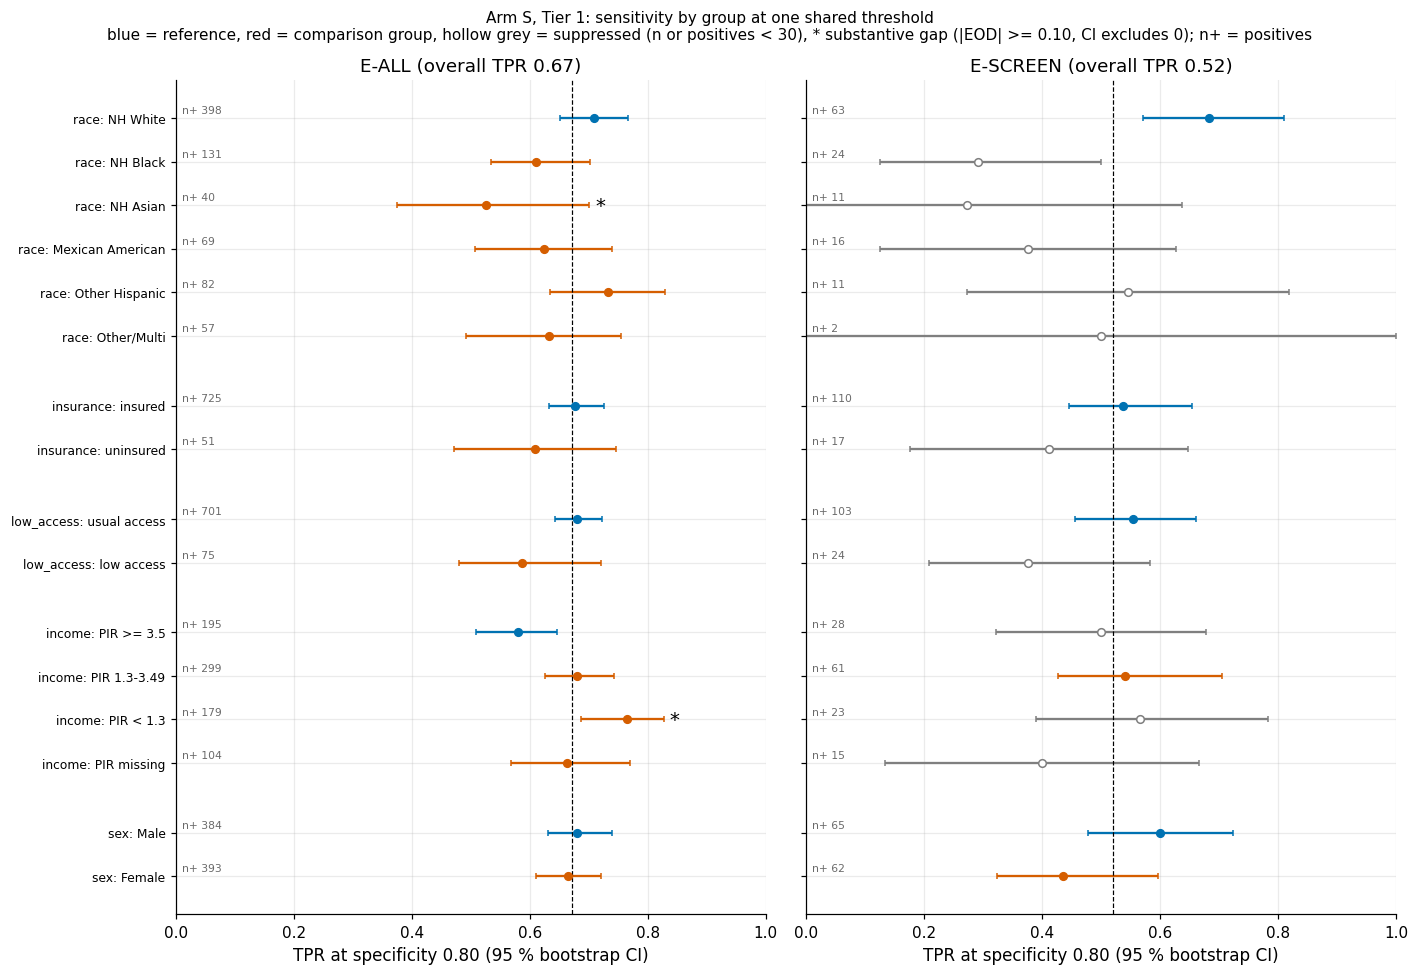

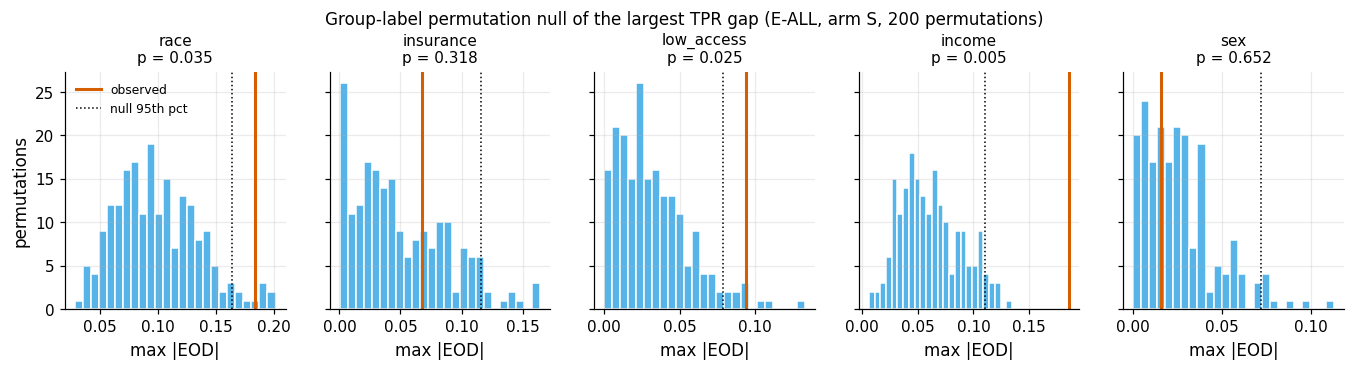

In [179]:
plots.set_style()
def tpr_panel(ax, GT, ET, title, overall):
    """Point-range of group TPRs; returns y labels (attribute: group)."""
    ylabels, ypos, k = [], [], 0
    for attr in F.ATTRIBUTES:
        g = GT[GT["attribute"] == attr]
        for _, r in g.iterrows():
            sup = r["status"] == "suppress"
            col = C.OKABE_ITO["grey"] if sup else (C.OKABE_ITO["blue"] if r["group"] == F.REFERENCE[attr] else C.OKABE_ITO["vermillion"])
            ax.errorbar(r["tpr"], -k, xerr=[[r["tpr"] - r["tpr_lo"]], [r["tpr_hi"] - r["tpr"]]], fmt="o",
                        color=col, mfc="white" if sup else col, capsize=2, ms=5)
            e = ET[(ET["attribute"] == attr) & (ET["group"] == r["group"])]
            if len(e) and bool(e["substantive"].iloc[0]) and e["verdict_status"].iloc[0] == "reportable":
                ax.annotate("*", (r["tpr_hi"], -k), xytext=(4, -4), textcoords="offset points", fontsize=13, color="black")
            ax.annotate(f"n+ {int(r['n_pos'])}", (0.01, -k), xytext=(0, 3), textcoords="offset points", fontsize=7, color="dimgrey")
            ylabels.append(f"{attr}: {r['group']}")
            ypos.append(-k)
            k += 1
        k += 0.6
    ax.axvline(overall, color="black", lw=0.8, ls="--")
    ax.set_yticks(ypos); ax.set_yticklabels(ylabels, fontsize=8)
    ax.set_xlabel("TPR at specificity 0.80 (95 % bootstrap CI)")
    ax.set_title(title)
    ax.set_xlim(0, 1)

# E-SCREEN tables are needed for the right panel (computed in section 4, re-used there)
GTs, ETs = tables("E-SCREEN", 1)
rec_s, _ = ek.recall_at_specificity(y_esc[esc], PM[("S", 1, "lr")][esc])
fig, axes = plt.subplots(1, 2, figsize=(13, 9))
tpr_panel(axes[1], GTs, ETs, f"E-SCREEN (overall TPR {rec_s:.2f})", rec_s)
axes[1].tick_params(labelleft=False)
tpr_panel(axes[0], GT1, ET1, f"E-ALL (overall TPR {rec_check:.2f})", rec_check)
fig.suptitle("Arm S, Tier 1: sensitivity by group at one shared threshold\n"
             "blue = reference, red = comparison group, hollow grey = suppressed (n or positives < 30), * substantive gap (|EOD| >= 0.10, CI excludes 0); n+ = positives", fontsize=10)
fig.tight_layout()
f81 = plots.savefig(fig, "S8_group_tpr", caption="F8-1. TPR at specificity 0.80 by audit group for arm S (Tier 1) on E-ALL "
                    "and E-SCREEN, stratified bootstrap 95 % CI with the threshold re-estimated per replicate; dashed line = "
                    "overall TPR; hollow grey markers are suppressed cells (n < 30 or fewer than 30 positives).")
plt.show()

fig, axes = plt.subplots(1, len(F.ATTRIBUTES), figsize=(15, 2.8), sharey=True)
for ax, attr in zip(axes, F.ATTRIBUTES):
    row = PERM1.set_index("attribute").loc[attr]
    if attr in NULL1:
        ax.hist(NULL1[attr], bins=25, color=C.OKABE_ITO["sky"], edgecolor="white")
        ax.axvline(row["observed_max_eod"], color=C.OKABE_ITO["vermillion"], lw=2, label="observed")
        ax.axvline(row["null_q95"], color="black", ls=":", lw=1, label="null 95th pct")
        ax.set_title(f"{attr}\np = {row['p_value']:.3f}", fontsize=10)
    ax.set_xlabel("max |EOD|")
axes[0].set_ylabel("permutations"); axes[0].legend(fontsize=8)
fig.suptitle("Group-label permutation null of the largest TPR gap (E-ALL, arm S, 200 permutations)", fontsize=11, y=1.08)
f81b = plots.savefig(fig, "S8_permutation_null", caption="F8-1b. Null distribution of max |TPR_g - TPR_ref| over the reportable "
                     "groups when group labels are permuted 200 times (threshold fixed), with the observed value (red) "
                     "and the null 95th percentile (dotted). E-ALL, arm S, Tier 1.")
plt.show()
S8["group_metrics_eall_t1"] = GT1.round(5).to_dict("records")
S8["eod_eall_t1"] = ET1.round(5).to_dict("records")
S8["permutation_eall_t1"] = PERM1.round(5).to_dict("records")
S8["threshold_eall_t1"] = thr_eall
S8["overall_tpr_eall_t1"] = rec_check

**So what.** The left panel is the audit in one picture: the reference groups (blue) sit near the overall TPR, NH Asian
adults and the highest income band fall clearly below it, and the lowest income band lies above it. In the right panel
almost every E-SCREEN group is grey (suppressed). The permutation panel shows, per attribute, whether the largest gap is
beyond chance: for race, income and low access the red line lies beyond the null's 95th percentile; for insurance and
sex it lies inside the null, i.e. random grouping of the same people produces gaps of that size.

## 8.4 E-SCREEN
**Why.** E-SCREEN is the population the use case is about (adults not known to have diabetes). The same metrics are
computed with the threshold fixed at specificity 0.80 on the E-SCREEN negatives. With about 127 positives in total,
most groups have fewer than 30 positives; they are reported but receive no verdict.

In [180]:
PERMs, NULLs = permutation_block("E-SCREEN", 1)
print(f"E-SCREEN, Tier 1, arm S: overall TPR {rec_s:.3f}")
print(GTs[show].round(3).to_string(index=False))
print()
print(ETs[["attribute", "group", "ref", "eod", "eod_lo", "eod_hi", "flag_0.05", "substantive", "verdict_status"]].round(3).to_string(index=False))
print()
print(PERMs.round(3).to_string(index=False))
rep_s = ETs[ETs["verdict_status"].eq("reportable")]
print(f"\nreportable E-SCREEN gaps: {len(rep_s)} of {len(ETs)}; substantive among them: {int(rep_s['substantive'].sum())}")
S8["group_metrics_escreen_t1"] = GTs.round(5).to_dict("records")
S8["eod_escreen_t1"] = ETs.round(5).to_dict("records")
S8["permutation_escreen_t1"] = PERMs.round(5).to_dict("records")
S8["overall_tpr_escreen_t1"] = rec_s

E-SCREEN, Tier 1, arm S: overall TPR 0.520
 attribute            group    n  n_pos   tpr  tpr_lo  tpr_hi   fpr   sel   ppv   auc  auc_lo  auc_hi    oe   status                               flags
      race         NH White 2392     63 0.683   0.571   0.810 0.210 0.222 0.081 0.831   0.792   0.866 0.072  present                                    
      race         NH Black  433     24 0.292   0.125   0.500 0.225 0.229 0.071 0.644   0.562   0.729 0.145 suppress             n_pos<30;ci_width>=0.30
      race         NH Asian  223     11 0.273   0.000   0.636 0.127 0.135 0.100 0.809   0.703   0.900 0.179 suppress n_pos<30;ci_width>=0.30;exploratory
      race Mexican American  256     16 0.375   0.125   0.627 0.158 0.172 0.136 0.761   0.663   0.848 0.193 suppress             n_pos<30;ci_width>=0.30
      race   Other Hispanic  394     11 0.545   0.273   0.818 0.170 0.180 0.085 0.828   0.740   0.916 0.082 suppress             n_pos<30;ci_width>=0.30
      race      Other/Multi  236      2

**So what.** In the screening population only the sex contrast has 30 or more positives in both groups. It points to
undiagnosed **women being found less often than undiagnosed men** (EOD about −0.17), but the CI includes 0 and the
permutation p is about 0.09, so the gap is not established. The race gaps look much larger than on E-ALL (NH Black and
NH Asian undiagnosed cases are found far less often than White ones) but rest on 11–24 positives per group with CIs
wider than 0.30, so they are suppressed: a screening-population race audit is not possible with NHANES 2021–23.
"Not reportable" here means "not measurable", not "fair".

## 8.5 Tier 2 summary
**Why.** Tier 2 adds total and HDL cholesterol. If lipids carry group-specific information, the gaps could change. The
same audit is repeated on E-ALL and summarised by the largest reportable gap per attribute.

In [181]:
GT2, ET2 = tables("E-ALL", 2)
PERM2, _ = permutation_block("E-ALL", 2)
cmp_t = (ET1.set_index(["attribute", "group"])[["eod", "eod_lo", "eod_hi", "verdict_status"]]
         .join(ET2.set_index(["attribute", "group"])[["eod", "eod_lo", "eod_hi"]], rsuffix="_t2"))
cmp_t["delta_t2_t1"] = cmp_t["eod_t2"] - cmp_t["eod"]
print(cmp_t.round(3).to_string())
summ = PERM1.set_index("attribute")[["observed_max_eod", "p_value"]].join(
    PERM2.set_index("attribute")[["observed_max_eod", "p_value"]], rsuffix="_t2")
print("\nmax |EOD| (reportable groups) and permutation p, Tier 1 vs Tier 2:")
print(summ.round(3).to_string())
max_shift = float(cmp_t["delta_t2_t1"].abs().max())
print(f"largest change of any EOD from Tier 1 to Tier 2: {max_shift:.3f}")
S8["tier2_summary"] = dict(eod=ET2.round(5).to_dict("records"), permutation=PERM2.round(5).to_dict("records"),
                           max_abs_eod_shift=max_shift)

                               eod  eod_lo  eod_hi verdict_status  eod_t2  eod_lo_t2  eod_hi_t2  delta_t2_t1
attribute  group                                                                                            
race       NH Black         -0.098  -0.192   0.009     reportable  -0.065     -0.154      0.017        0.033
           NH Asian         -0.184  -0.343  -0.014     reportable  -0.179     -0.324     -0.006        0.005
           Mexican American -0.085  -0.214   0.031     reportable  -0.091     -0.209      0.043       -0.006
           Other Hispanic    0.023  -0.073   0.135     reportable   0.040     -0.068      0.143        0.016
           Other/Multi      -0.077  -0.220   0.046     reportable   0.008     -0.117      0.131        0.085
insurance  uninsured        -0.068  -0.197   0.068     reportable  -0.104     -0.227      0.037       -0.036
low_access low access       -0.094  -0.206   0.041     reportable  -0.160     -0.256     -0.018       -0.067
income     PIR 1.3-

**So what.** Adding lipids moves individual gaps by less than their own CIs (the largest shift is printed above) and,
apart from the near-zero Other/Multi gap, every gap keeps its sign; the NH Asian gap is unchanged (about −0.18). The
low-access gap grows in Tier 2 and its CI then excludes 0, while the race and income gaps stay beyond their permutation
nulls. The *direction* of the audit is therefore robust to the feature tier; which borderline attribute crosses 0.05 is
not. Tier 1 remains the primary audit.

## 8.6 3 × 3 label matrix
**Why.** RQ3 asks whether the *label* decides who the model misses. Hypothesis H3 is pre-registered (`prior_exposure =
none`): train the identical arm-S pipeline (same folds, same steps, same C0, same class and survey weights) on three
labels – self-report `L_self`, HbA1c `L_A1c` and the frozen union `L_comb` – and score every model on three kinds of
diabetes: **D-uncontrolled** (self-report and HbA1c ≥ 6.5), **D-controlled** (self-report, HbA1c < 6.5 – treatment
masking) and **Undiagnosed** (HbA1c ≥ 6.5 without a diagnosis). Each cell is the recall at the threshold that gives
specificity 0.80 on the common non-diabetic negatives (the same negatives for all nine cells); AUC is secondary.
Locked prediction: `L_self` misses Undiagnosed most, `L_A1c` misses D-controlled most, `L_comb` has the smallest
worst-cell gap; differences below 0.05 count as equivalent.

Operational reading (fixed before looking at the matrix, coded in `fairness.h3_elements`): "misses most" is read
**column-wise** – among the three training labels, which one serves a given kind of diabetes worst, holding the
stratum and the negatives fixed; the worst-cell gap of a training label is its largest shortfall against the best
label in any column. Contrasts are paired bootstrap differences (the same resampled people for all rows) judged with
`evalkit.verdict` at SESOI 0.05. The matrix uses the training part (80 % of the 569 / 250 / 152 / 4,759 people
frozen in `label_freeze.md`); the hold-out stays untouched.

In [182]:
LABELS3 = ("L_self", "L_A1c", "L_comb")
YL = {lab: cl[lab].to_numpy().astype(int) for lab in LABELS3}
assert np.array_equal(YL["L_comb"], y)
from joblib import Parallel, delayed
t0 = time.time()
mk_S = lambda: P.build_pipeline(cfgS, 1, C_=C0)
new = Parallel(n_jobs=2)(delayed(ek.cv_predict)(mk_S, X1, YL[lab], folds, fit_params=fpS) for lab in ("L_self", "L_A1c"))
OOF3 = {"L_self": new[0], "L_A1c": new[1], "L_comb": OOF[("S", 1, "lr")]}
PM3 = {lab: ek.mean_oof(OOF3[lab], n) for lab in LABELS3}
cnt = pd.Series(strat).value_counts()
full = L.strata_counts(clean)
print(f"refitted arm S on L_self and L_A1c: {2 * len(folds)} fits, {time.time() - t0:.0f} s")
print("training-part strata (share of the frozen full-cohort counts):",
      {k: f"{int(cnt[k])} ({cnt[k] / full[k]:.2f})" for k in L.STRATA_3X3})
assert all(0.75 < cnt[k] / full[k] < 0.85 for k in L.STRATA_3X3)
LM = F.label_matrix(strat, PM3, n_boot=C.N_BOOT, seed=ek.derive_seed(C.SEED_MASTER, "S8", "3x3"))
cells = LM["cells"]
# consistency: L_comb row, Undiagnosed column = E-SCREEN recall of arm S (same positives, same negatives)
assert abs(LM["recall"].loc["L_comb", "Undiagnosed"] - rec_s) < 1e-12
print("\nrecall at specificity 0.80 on the common NonDiabetic negatives (rows: training label):")
print(LM["recall"].round(3).to_string())
print("\nROC-AUC against the common negatives:")
print(LM["auc"].round(3).to_string())
print()
print(cells[["train_label", "stratum", "n_pos", "recall", "recall_lo", "recall_hi", "auc", "auc_lo", "auc_hi"]].round(3).to_string(index=False))
H3E = F.h3_elements(LM)
print("\npre-registered contrasts (predicted sign: negative):")
print(H3E.round(3).to_string(index=False))
# row-wise reading (secondary): in which stratum does each training label have its lowest recall?
roww = LM["recall"].idxmin(axis=1).to_dict()
print(f"\nrow-wise reading (secondary): lowest-recall stratum per training label {roww}")
gaps = F._worst_gap(LM["point"]["tpr"][0])
print("worst-cell gap per training label:", dict(zip(LABELS3, np.round(gaps, 3))))

refitted arm S on L_self and L_A1c: 50 fits, 6 s
training-part strata (share of the frozen full-cohort counts): {'D_uncontrolled': '455 (0.80)', 'D_controlled': '195 (0.78)', 'Undiagnosed': '127 (0.84)', 'NonDiabetic': '3807 (0.80)'}



recall at specificity 0.80 on the common NonDiabetic negatives (rows: training label):
        D_uncontrolled  D_controlled  Undiagnosed
L_self           0.738         0.615        0.504
L_A1c            0.741         0.569        0.559
L_comb           0.741         0.610        0.520

ROC-AUC against the common negatives:
        D_uncontrolled  D_controlled  Undiagnosed
L_self           0.860         0.812        0.767
L_A1c            0.861         0.797        0.784
L_comb           0.862         0.810        0.781

train_label        stratum  n_pos  recall  recall_lo  recall_hi   auc  auc_lo  auc_hi
     L_self D_uncontrolled    455   0.738      0.701      0.785 0.860   0.844   0.875
     L_self   D_controlled    195   0.615      0.544      0.682 0.812   0.788   0.837
     L_self    Undiagnosed    127   0.504      0.417      0.598 0.767   0.733   0.800
      L_A1c D_uncontrolled    455   0.741      0.697      0.787 0.861   0.845   0.875
      L_A1c   D_controlled    195   0.569 

H3 element verdicts {'E1': 'inconclusive', 'E2': 'inconclusive', 'E3': 'inconclusive'} -> H3 inconclusive


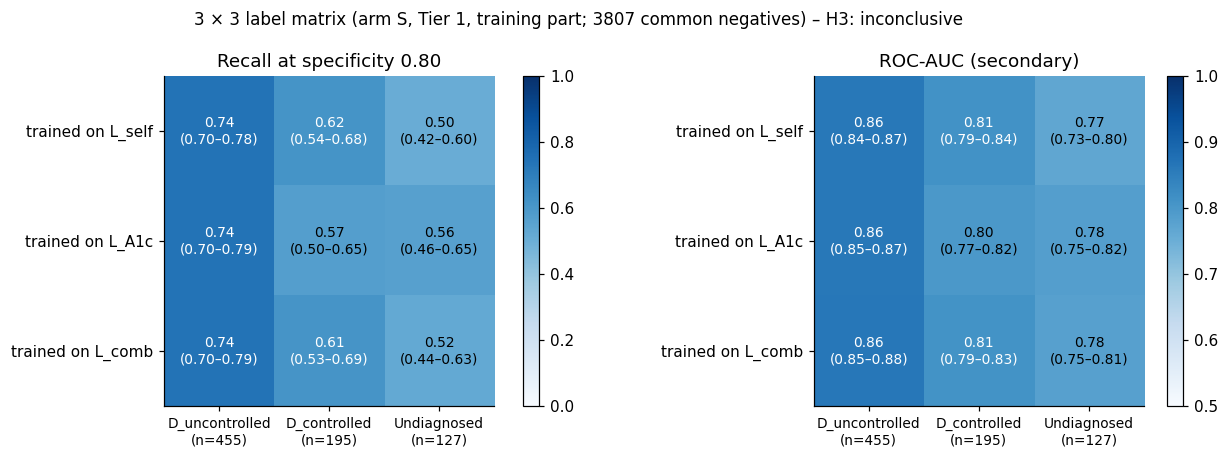

In [183]:
elem_v = {}
for el, g in H3E.groupby("element"):
    elem_v[el] = ek.combine_verdicts(g["verdict"].tolist())
h3_v = ek.combine_verdicts(list(elem_v.values()))
if H3E["reversed_ci_excl_0"].any():                       # locked falsifier
    h3_v = "refuted"
print(f"H3 element verdicts {elem_v} -> H3 {h3_v}")
cells.to_csv(OUT / "label_matrix_cells.csv", index=False)
H3E.to_csv(OUT / "h3_contrasts.csv", index=False)
S8["label_matrix"] = dict(cells=cells.round(5).to_dict("records"), recall=LM["recall"].round(5).to_dict(),
                          auc=LM["auc"].round(5).to_dict(), contrasts=H3E.round(5).to_dict("records"),
                          element_verdicts=elem_v, verdict=h3_v, row_wise_min=roww,
                          worst_gap=dict(zip(LABELS3, gaps.round(5))), strata_train=cnt.to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.25, 1]})
for ax, (mat, key, ttl) in zip(axes, [(LM["recall"], "recall", "Recall at specificity 0.80"), (LM["auc"], "auc", "ROC-AUC (secondary)")]):
    im = ax.imshow(mat.to_numpy(), cmap="Blues", vmin=0 if key == "recall" else 0.5, vmax=1)
    for i, lab in enumerate(LABELS3):
        for j, st in enumerate(F.POS_STRATA):
            r = cells[(cells["train_label"] == lab) & (cells["stratum"] == st)].iloc[0]
            v = mat.loc[lab, st]
            ax.text(j, i, f"{v:.2f}\n({r[key + '_lo']:.2f}–{r[key + '_hi']:.2f})", ha="center", va="center",
                    fontsize=9, color="white" if v > (0.6 if key == "recall" else 0.8) else "black")
    ax.set_xticks(range(3)); ax.set_xticklabels([f"{s}\n(n={int(cnt[s])})" for s in F.POS_STRATA], fontsize=9)
    ax.set_yticks(range(3)); ax.set_yticklabels([f"trained on {l}" for l in LABELS3])
    ax.set_title(ttl); ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle(f"3 × 3 label matrix (arm S, Tier 1, training part; {int(cnt['NonDiabetic'])} common negatives) – H3: {h3_v}", fontsize=11)
fig.tight_layout()
f82 = plots.savefig(fig, "S8_label_matrix", caption="F8-2. 3x3 label matrix: arm S trained on L_self, L_A1c or L_comb "
                    "(identical folds, steps and C0) and scored on D-uncontrolled, D-controlled and Undiagnosed cases against "
                    "the common NonDiabetic negatives. Left: recall at specificity 0.80 with 95 % stratified bootstrap CI "
                    "(thresholds re-estimated per replicate); right: ROC-AUC.")
plt.show()

**So what.** Every element of the locked pattern points the predicted way: in the Undiagnosed column the self-report
model has the lowest recall, in the D-controlled column the HbA1c-only model has the lowest recall, and the union label
has the smallest worst-cell gap. But the differences are small – at most about 0.06 – and every paired CI includes 0
while reaching beyond ±0.05, so H3 is **inconclusive**: neither the predicted ordering nor equivalence is established
(verdict line above). The row-wise reading tells the stronger story: *whatever* the training label, the Undiagnosed
column is the hardest, and the AUCs show the same order. With non-laboratory features the model cannot see the
diagnosis gap: undiagnosed people lack the care traces and the treatment-era profile that the features pick up, and
changing the label only shifts recall by a few points. The label therefore shapes *what the model claims to measure*
(§5: 152 and 250 cases silently dropped by the two single labels) more than *whom this feature set can find*.

## 8.7 Access-proxy audit arm
**Why.** §5 found that uninsured adults and adults without a usual place of care are more often undiagnosed. If the
self-report label carries this access imprint, a model trained on `L_self` should learn that *lacking access lowers
the chance of "having diabetes"* – a pure artefact of who gets diagnosed – while a model trained on the union label
(or on HbA1c, which needs no doctor) should not. The audit arm adds two binary features, **uninsured** (HIQ011 = 2)
and **no usual place of care** (HUQ030 = 2), to the arm-S pipeline and fits it on each label. Coefficients (per SD,
because P09 scales every column) are bootstrapped with `evalkit.coef_bootstrap` (B = `config.N_BOOT_COEF`); the
same seed gives the same resampled rows for every label, so differences between labels are paired. This arm is an
**audit instrument only**: the availability rule keeps insurance and access out of every model that could be used.

In [184]:
t0 = time.time()
mk_acc = lambda: F.access_pipeline(cfgS, 1, C_=C0)
assert set(F.ACCESS_FEATURES) <= set(mk_acc()[:-1].fit(X1.iloc[:500], y[:500]).get_feature_names_out())
seed_acc = ek.derive_seed(C.SEED_MASTER, "S8", "access_audit")
CB = {lab: ek.coef_bootstrap(mk_acc, X1, YL[lab], n_boot=C.N_BOOT_COEF, seed=seed_acc, fit_params=fpS, n_jobs=N_JOBS)
      for lab in LABELS3}
sd_bin = {f: float(np.sqrt(grp[f].fillna(0).mean() * (1 - grp[f].fillna(0).mean()))) for f in F.ACCESS_FEATURES}
acc_rows = []
for f in F.ACCESS_FEATURES:
    for lab in LABELS3:
        s_ = CB[lab].summary.loc[f]
        acc_rows.append({"feature": f, "label": lab, "coef_per_sd": s_["coef"], "lo": s_["q_low"], "hi": s_["q_high"],
                         "boot_sd": s_["sd"], "OR_yes_vs_no": np.exp(s_["coef"] / sd_bin[f]),
                         "OR_lo": np.exp(s_["q_low"] / sd_bin[f]), "OR_hi": np.exp(s_["q_high"] / sd_bin[f])})
ACC = pd.DataFrame(acc_rows)
diff_rows = []
for f in F.ACCESS_FEATURES:
    for a, b in (("L_self", "L_comb"), ("L_self", "L_A1c"), ("L_comb", "L_A1c")):
        d = CB[a].coefs[f].to_numpy() - CB[b].coefs[f].to_numpy()
        e, lo, hi, se = F.summarise(CB[a].summary.loc[f, "coef"] - CB[b].summary.loc[f, "coef"], d)
        diff_rows.append({"feature": f, "contrast": f"{a} - {b}", "diff_per_sd": e, "lo": lo, "hi": hi,
                          "ci_excludes_0": bool(lo > 0 or hi < 0)})
ACCD = pd.DataFrame(diff_rows)
print(f"access audit arm: {len(LABELS3)} labels x (1 + {C.N_BOOT_COEF}) fits, {time.time() - t0:.0f} s")
print(ACC.round(3).to_string(index=False))
print("\npaired differences of the per-SD coefficient between training labels:")
print(ACCD.round(3).to_string(index=False))
ACC.to_csv(OUT / "access_audit_coefs.csv", index=False)
ACCD.to_csv(OUT / "access_audit_diffs.csv", index=False)
S8["access_audit"] = dict(coefs=ACC.round(5).to_dict("records"), diffs=ACCD.round(5).to_dict("records"),
                          n_boot=C.N_BOOT_COEF, sd_binary=sd_bin)

access audit arm: 3 labels x (1 + 500) fits, 28 s
       feature  label  coef_per_sd     lo     hi  boot_sd  OR_yes_vs_no  OR_lo  OR_hi
     uninsured L_self       -0.112 -0.277  0.015    0.079         0.669  0.370  1.054
     uninsured  L_A1c        0.016 -0.140  0.153    0.075         1.057  0.606  1.729
     uninsured L_comb       -0.012 -0.152  0.122    0.072         0.958  0.581  1.549
no_usual_place L_self       -0.203 -0.386 -0.054    0.087         0.526  0.294  0.843
no_usual_place  L_A1c       -0.095 -0.279  0.044    0.083         0.741  0.412  1.150
no_usual_place L_comb       -0.099 -0.259  0.025    0.073         0.731  0.440  1.081

paired differences of the per-SD coefficient between training labels:
       feature        contrast  diff_per_sd     lo    hi  ci_excludes_0
     uninsured L_self - L_comb       -0.100 -0.231 0.014          False
     uninsured  L_self - L_A1c       -0.128 -0.286 0.017          False
     uninsured  L_comb - L_A1c       -0.028 -0.090 0.038     

**So what.** The access imprint points where the label requires a doctor. Trained on self-report, the model gives both
access features negative coefficients – lacking a usual place of care *lowers* the predicted chance of diabetes, with a
CI that excludes 0 (odds ratio about 0.5) – although §4 showed that the insured–uninsured prevalence gap is age
confounding (+0.7 pp after age standardisation). Trained on HbA1c, which needs no diagnosis, the coefficients are small
with CIs including 0, and the union label sits next to HbA1c. The paired differences self-report minus union are about
−0.10 per SD for both features, but their CIs just include 0, so the label contrast is suggestive rather than
established at this sample size. The direction is the one that matters for governance: a model trained on self-report
would learn to **score people with poor access as lower risk because they were never diagnosed**, a feedback loop
that would deepen the diagnosis gap. The result supports the frozen union label and keeping insurance and access out
of the model.

## 8.8 Reweighing
**Why.** Reweighing (Kamiran & Calders 2012) is the standard pre-processing mitigation: each training row gets the
weight w(g, y) = P(g)·P(y) / P(g, y), which makes group and label independent in the weighted training data without
touching features or predictions. It is applied **inside every training fold** (weights computed from that fold's rows)
on top of the survey weights of arm S, so the comparison with S is paired on the same folds. Three versions are run:
race (pre-specified; the plan expected weights close to 1 and a one-line null result), and – as extension items –
insurance and low access, the attributes linked to the diagnosis gap. ΔAUC uses the locked
S7 engine (E-ALL: fold-mean paired difference with the wider of the corrected-t and paired-bootstrap intervals;
E-SCREEN: pooled-OOF difference with its paired bootstrap); the gap
changes are paired bootstrap differences of EOD with the threshold re-estimated for each arm.

In [185]:
from joblib import parallel_config
from sklearn.metrics import roc_auc_score
from scipy import stats as sstats

def fold_auc(oof, pop="E-ALL"):
    yy, m = pop_of(pop)
    out = {}
    for (r, f), g in oof.groupby(["repeat", "fold"]):
        rows = g["row"].to_numpy()
        k = m[rows]
        out[(r, f)] = roc_auc_score(yy[rows][k], g["prob"].to_numpy()[k])
    return pd.Series(out)

def compare_auc(oof_a, oof_b, pop="E-ALL", tag=""):
    """Paired ΔAUC A - B with the S7 engine: on E-ALL the estimate is the fold-mean paired difference and the interval the
    wider of corrected t and paired bootstrap; on E-SCREEN the pooled-OOF difference with its paired bootstrap interval."""
    yy, m = pop_of(pop)
    pa, pb = ek.mean_oof(oof_a, n), ek.mean_oof(oof_b, n)
    bs = ek.paired_bootstrap(yy, pa, pb, "roc_auc", n_boot=C.N_BOOT, eval_mask=m,
                             seed=ek.derive_seed(C.SEED_MASTER, "S8", "dauc", tag, pop))
    row = dict(pop=pop, diff_pooled=bs["diff"], boot_lo=bs["ci_low"], boot_hi=bs["ci_high"])
    est, lo, hi, se, interval = bs["diff"], bs["ci_low"], bs["ci_high"], bs["se"], "bootstrap"
    mdd = (sstats.norm.ppf(0.975) + sstats.norm.ppf(0.8)) * se
    if pop == "E-ALL":
        ct = ek.corrected_t((fold_auc(oof_a) - fold_auc(oof_b)).to_numpy(), n_train_fold, n_test_fold)
        row.update(t_lo=ct["ci_low"], t_hi=ct["ci_high"])
        est = ct["mean"]
        if ct["ci_high"] - ct["ci_low"] >= hi - lo:
            lo, hi, se, interval = ct["ci_low"], ct["ci_high"], ct["se_corr"], "corrected_t"
        mdd = (sstats.t.ppf(0.975, ct["df"]) + sstats.t.ppf(0.80, ct["df"])) * se
    row.update(est=est, lo=lo, hi=hi, se=se, interval=interval, mdd=mdd)
    return row

RW_TARGET = {"race": "NH Asian", "insurance": "uninsured", "low_access": "low access"}
OOF_RW, RW_W, RW_ROWS, RW_EOD = {}, {}, [], []
t0 = time.time()
with parallel_config(max_nbytes=None):
    for attr in RW_TARGET:
        gvals = grp[attr].to_numpy(dtype=object)
        w_rw = F.reweighing_weights(gvals, y)
        RW_W[attr] = w_rw
        OOF_RW[attr] = F.cv_predict_reweighed(mk_S, X1, y, folds, gvals, base_weight=w_svy, n_jobs=N_JOBS)
print(f"reweighing arms: {len(RW_TARGET)} x {len(folds)} fits, {time.time() - t0:.0f} s")
for attr, w_rw in RW_W.items():
    lv = grp[attr].fillna("(unknown)")
    tab = pd.DataFrame({"g": lv, "y": y, "w": w_rw}).groupby(["g", "y"])["w"].first().unstack()
    print(f"\n{attr}: reweighing weights w(g, y) on the training part (range {w_rw.min():.3f}-{w_rw.max():.3f})")
    print(tab.round(3).rename(columns={0: "w(y=0)", 1: "w(y=1)"}).to_string())
    PMx = ek.mean_oof(OOF_RW[attr], n)
    for pop in ("E-ALL", "E-SCREEN"):
        r = compare_auc(OOF_RW[attr], OOF[("S", 1, "lr")], pop, tag=f"rw_{attr}")
        r.update(arm=f"S+RW({attr})", w_min=w_rw.min(), w_max=w_rw.max(),
                 verdict_auc=ek.verdict(r["lo"], r["hi"], AUC_SESOI, "+", r["est"]))
        RW_ROWS.append(r)
    point, boot, codes, mm = audit(attr, "E-ALL", 1, ("S", "RW"), preds={"RW": PMx})
    lvls = F.LEVELS[attr]
    ref = lvls.index(F.REFERENCE[attr])
    for g_i, g_nm in enumerate(lvls):
        if g_i == ref:
            continue
        eod_pt = point["tpr"][0, :, g_i] - point["tpr"][0, :, ref]
        eod_bt = boot["tpr"][:, :, g_i] - boot["tpr"][:, :, ref]
        e, lo, hi, _ = F.summarise(eod_pt[1] - eod_pt[0], eod_bt[:, 1] - eod_bt[:, 0])
        ea, alo, ahi, _ = F.summarise(abs(eod_pt[1]) - abs(eod_pt[0]), np.abs(eod_bt[:, 1]) - np.abs(eod_bt[:, 0]))
        RW_EOD.append({"arm": f"S+RW({attr})", "attribute": attr, "group": g_nm, "eod_S": eod_pt[0], "eod_RW": eod_pt[1],
                       "d_eod": e, "d_eod_lo": lo, "d_eod_hi": hi, "d_abs_eod": ea, "d_abs_lo": alo, "d_abs_hi": ahi,
                       "target": g_nm == RW_TARGET[attr]})
RWT = pd.DataFrame(RW_ROWS)
RWE = pd.DataFrame(RW_EOD)
print("\nΔAUC reweighed arm − S:")
print(RWT[["arm", "pop", "est", "lo", "hi", "interval", "mdd", "w_min", "w_max", "verdict_auc"]].round(4).to_string(index=False))
print("\nchange of equal-opportunity differences (reweighed − S), E-ALL:")
print(RWE.round(3).to_string(index=False))
RWT.to_csv(OUT / "reweighing_auc.csv", index=False)
RWE.to_csv(OUT / "reweighing_eod.csv", index=False)
S8["reweighing"] = dict(auc=RWT.round(5).to_dict("records"), eod=RWE.round(5).to_dict("records"),
                        weight_range={a: [float(w.min()), float(w.max())] for a, w in RW_W.items()})

reweighing arms: 3 x 25 fits, 5 s

race: reweighing weights w(g, y) on the training part (range 0.699-1.161)
y                 w(y=0)  w(y=1)
g                               
Mexican American   1.069   0.759
NH Asian           0.987   1.068
NH Black           1.097   0.699
NH White           0.972   1.161
Other Hispanic     1.008   0.961
Other/Multi        1.033   0.865



insurance: reweighing weights w(g, y) on the training part (range 0.949-1.356)
y          w(y=0)  w(y=1)
g                        
(unknown)   0.949   1.356
insured     1.004   0.979
uninsured   0.955   1.296



low_access: reweighing weights w(g, y) on the training part (range 0.678-1.677)
y             w(y=0)  w(y=1)
g                           
(unknown)      1.107   0.678
low access     0.924   1.677
usual access   1.016   0.928



ΔAUC reweighed arm − S:
             arm      pop     est      lo     hi    interval    mdd  w_min  w_max verdict_auc
      S+RW(race)    E-ALL -0.0002 -0.0018 0.0014 corrected_t 0.0022 0.6987 1.1614  equivalent
      S+RW(race) E-SCREEN -0.0013 -0.0044 0.0020   bootstrap 0.0046 0.6987 1.1614  equivalent
 S+RW(insurance)    E-ALL  0.0001 -0.0005 0.0007 corrected_t 0.0009 0.9491 1.3560  equivalent
 S+RW(insurance) E-SCREEN  0.0021  0.0009 0.0033   bootstrap 0.0017 0.9491 1.3560  equivalent
S+RW(low_access)    E-ALL -0.0002 -0.0017 0.0013 corrected_t 0.0021 0.6780 1.6769  equivalent
S+RW(low_access) E-SCREEN  0.0041  0.0013 0.0069   bootstrap 0.0039 0.6780 1.6769  equivalent

change of equal-opportunity differences (reweighed − S), E-ALL:
             arm  attribute            group  eod_S  eod_RW  d_eod  d_eod_lo  d_eod_hi  d_abs_eod  d_abs_lo  d_abs_hi  target
      S+RW(race)       race         NH Black -0.098  -0.131 -0.033    -0.086    -0.003      0.033    -0.003     0.084   False


**So what.** Reweighing is a null mitigation here, and an instructive one. The race weights are not close to 1 (NH Black
cases are down-weighted to about 0.7 because their prevalence is highest), yet discrimination does not move: every ΔAUC
interval lies inside ±0.01 (equivalent) on both populations. The gaps do not close either: race reweighing leaves the
NH Asian gap where it was (slightly wider) and *widens* the NH Black gap with a CI excluding 0, because making race and
label independent removes exactly the prevalence difference that made Black cases easier to find. Insurance and
low-access reweighing narrow their gaps by about 0.04–0.05, with CIs that include 0. Reweighing acts on the label–group
association; the gaps found in section 3 come from features (care traces, BMI) and from the label's diagnosis
component, which reweighing does not touch.

## 8.9 WHtR measurement fix (P14-b)
**Why.** §5 found that BMI under-reads adiposity in Asian adults (single-feature AUC gain of WHtR over BMI +0.137 for
Asian against +0.049 for White adults), and section 3 found Asian cases missed most at the shared threshold, mainly
because they are leaner. Arm S+WHtR replaces waist circumference by waist-to-height ratio (P14, pre-registered in S6;
`prior_exposure = descriptive_seen`). Locked prediction **P14-b**: Asian TPR at specificity 0.80 rises by at least
0.05 (falsifier: upper CI bound of ΔTPR below 0.05), overall |ΔAUC| < 0.01 (P14-a, tested in §7), and the White
change is smaller (control group). With only 40 Asian positives in the training part, two intervals are computed: the
simple stratified bootstrap and a **PSU-cluster bootstrap** (Rao–Wu, `survey.rao_wu_weights`), because Asian adults
cluster in few PSUs; the wider interval decides. The model-level counterpart of H4b (does the WHtR advantage
transfer into the multivariable model, Asian more than White?) is read from the same replicates as the within-group
ΔAUC.

In [186]:
pW = PM[("S+WHtR", 1, "lr")]
res = {}
for wt in ("simple", "psu"):
    point, boot, codes, mm = audit("race", "E-ALL", 1, ("S", "S+WHtR"), weights=wt)
    res[wt] = (point, boot)
lv = F.LEVELS["race"]
iA, iW = lv.index("NH Asian"), lv.index("NH White")
whtr_rows = []
def add_whtr(name, pt_fn):
    row = {"quantity": name}
    for wt in ("simple", "psu"):
        point, boot = res[wt]
        e, lo, hi, se = F.summarise(pt_fn(point)[0], pt_fn(boot))
        bvals = np.asarray(pt_fn(boot), float)
        row.update({"est": e, f"{wt}_lo": lo, f"{wt}_hi": hi, f"{wt}_se": se, f"{wt}_boot_mean": float(np.nanmean(bvals))})
    wide = "psu" if (row["psu_hi"] - row["psu_lo"]) >= (row["simple_hi"] - row["simple_lo"]) else "simple"
    row.update(lo=row[f"{wide}_lo"], hi=row[f"{wide}_hi"], interval=wide)
    whtr_rows.append(row)
    return row
r_tA = add_whtr("TPR NH Asian, S", lambda d: d["tpr"][:, 0, iA])
r_tA2 = add_whtr("TPR NH Asian, S+WHtR", lambda d: d["tpr"][:, 1, iA])
r_tW = add_whtr("TPR NH White, S", lambda d: d["tpr"][:, 0, iW])
r_tW2 = add_whtr("TPR NH White, S+WHtR", lambda d: d["tpr"][:, 1, iW])
r_dA = add_whtr("ΔTPR NH Asian", lambda d: d["tpr"][:, 1, iA] - d["tpr"][:, 0, iA])
r_dW = add_whtr("ΔTPR NH White", lambda d: d["tpr"][:, 1, iW] - d["tpr"][:, 0, iW])
r_dd = add_whtr("ΔTPR Asian − ΔTPR White", lambda d: (d["tpr"][:, 1, iA] - d["tpr"][:, 0, iA]) - (d["tpr"][:, 1, iW] - d["tpr"][:, 0, iW]))
r_eod = add_whtr("Δ|EOD| Asian vs White", lambda d: np.abs(d["tpr"][:, 1, iA] - d["tpr"][:, 1, iW]) - np.abs(d["tpr"][:, 0, iA] - d["tpr"][:, 0, iW]))
r_auc = add_whtr("ΔAUC overall", lambda d: d["auc_all"][:, 1] - d["auc_all"][:, 0])
r_aA = add_whtr("ΔAUC within NH Asian", lambda d: d["auc"][:, 1, iA] - d["auc"][:, 0, iA])
r_aW = add_whtr("ΔAUC within NH White", lambda d: d["auc"][:, 1, iW] - d["auc"][:, 0, iW])
r_h4 = add_whtr("ΔAUC Asian − ΔAUC White (H4b, model level)", lambda d: (d["auc"][:, 1, iA] - d["auc"][:, 0, iA]) - (d["auc"][:, 1, iW] - d["auc"][:, 0, iW]))
WH = pd.DataFrame(whtr_rows)
print(WH[["quantity", "est", "simple_lo", "simple_hi", "simple_boot_mean", "psu_lo", "psu_hi", "psu_boot_mean", "interval"]].round(3).to_string(index=False))
# E-SCREEN (secondary; NH Asian has 11 positives -> suppressed, numbers only)
pt_s, bt_s, _, _ = audit("race", "E-SCREEN", 1, ("S", "S+WHtR"))
dA_s = F.summarise(pt_s["tpr"][0, 1, iA] - pt_s["tpr"][0, 0, iA], bt_s["tpr"][:, 1, iA] - bt_s["tpr"][:, 0, iA])
print(f"\nE-SCREEN (suppressed, {int(pt_s['n_pos'][0, 0, iA])} Asian positives): ΔTPR NH Asian {dA_s[0]:+.3f} ({dA_s[1]:+.3f}, {dA_s[2]:+.3f})")
p14a = next(r for r in S7m["scoreboard_detail"] if r["hyp_id"] == "P14" and r["sub"] == "(a) AUC" and r["pop"] == "E-ALL" and r["tier"] == 1)
print(f"P14-a from §7 (E-ALL, corrected t): ΔAUC {p14a['est']:+.4f} ({p14a['lo']:+.4f}, {p14a['hi']:+.4f}) -> {p14a['verdict']}")

                                  quantity    est  simple_lo  simple_hi  simple_boot_mean  psu_lo  psu_hi  psu_boot_mean interval
                           TPR NH Asian, S  0.525      0.375      0.700             0.541   0.333   0.692          0.533      psu
                      TPR NH Asian, S+WHtR  0.550      0.400      0.700             0.554   0.353   0.700          0.540      psu
                           TPR NH White, S  0.709      0.651      0.766             0.711   0.649   0.776          0.709      psu
                      TPR NH White, S+WHtR  0.721      0.656      0.764             0.715   0.655   0.768          0.710      psu
                             ΔTPR NH Asian  0.025      0.000      0.075             0.013  -0.042   0.071          0.008      psu
                             ΔTPR NH White  0.013     -0.020      0.030             0.004  -0.024   0.029          0.001      psu
                   ΔTPR Asian − ΔTPR White  0.012     -0.028      0.068             0.009 


E-SCREEN (suppressed, 11 Asian positives): ΔTPR NH Asian +0.091 (+0.000, +0.273)
P14-a from §7 (E-ALL, corrected t): ΔAUC -0.0009 (-0.0028, +0.0009) -> supported


P14-b: ΔTPR NH Asian +0.025 (-0.042, +0.071; psu interval) -> inconclusive; White control |Δ| smaller: True
P14 overall (a: supported, b: inconclusive) -> inconclusive
H4b model level: +0.005 (-0.004, +0.013) -> inconclusive; S5 single-feature verdict supported -> H4b supported


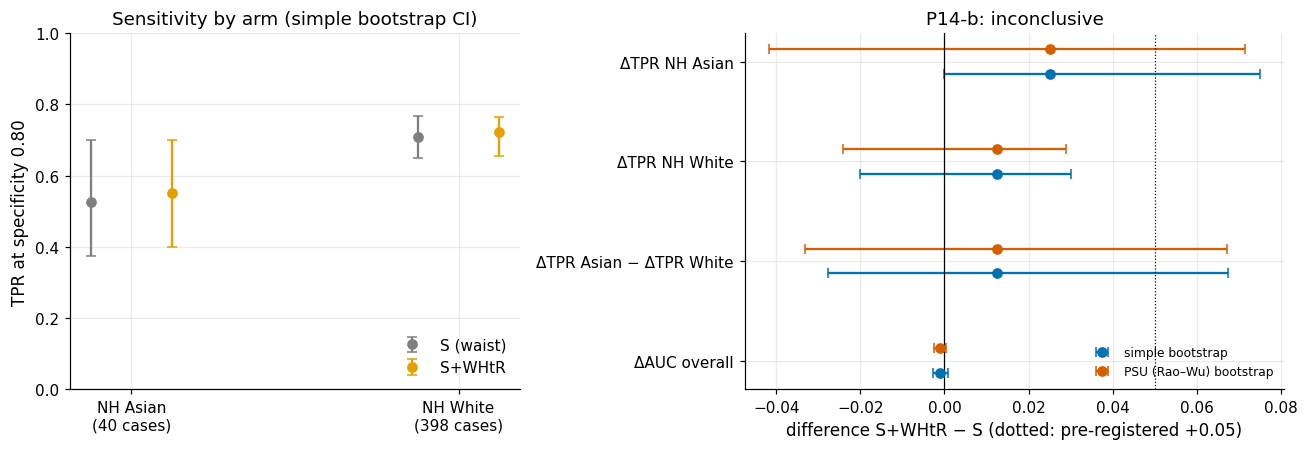

In [187]:
v_p14b = ek.verdict(r_dA["lo"], r_dA["hi"], GAP, "+", r_dA["est"])
v_p14b = "refuted" if (v_p14b == "equivalent" or r_dA["hi"] < GAP) else v_p14b     # locked falsifier
control_ok = abs(r_dW["est"]) < abs(r_dA["est"])
v_p14 = ek.combine_verdicts([p14a["verdict"], v_p14b])
v_h4b_model = ("supported" if (r_h4["lo"] > 0 and r_h4["est"] >= AUC_SESOI) else
               "refuted" if r_h4["hi"] < 0 else "inconclusive")
s5_h4b = R.load_section("S5")["hypotheses"]["H4b"]["verdict"]
v_h4b = "mixed" if (s5_h4b in ("supported", "refuted") and v_h4b_model in ("supported", "refuted") and v_h4b_model != s5_h4b) else s5_h4b
print(f"P14-b: ΔTPR NH Asian {r_dA['est']:+.3f} ({r_dA['lo']:+.3f}, {r_dA['hi']:+.3f}; {r_dA['interval']} interval) -> {v_p14b}; "
      f"White control |Δ| smaller: {control_ok}")
print(f"P14 overall (a: {p14a['verdict']}, b: {v_p14b}) -> {v_p14}")
print(f"H4b model level: {r_h4['est']:+.3f} ({r_h4['lo']:+.3f}, {r_h4['hi']:+.3f}) -> {v_h4b_model}; S5 single-feature verdict "
      f"{s5_h4b} -> H4b {v_h4b}")
WH.to_csv(OUT / "whtr_p14b.csv", index=False)
S8["whtr"] = dict(table=WH.round(5).to_dict("records"), p14b_verdict=v_p14b, p14_verdict=v_p14, white_control_smaller=control_ok,
                  p14a_from_S7={k: p14a[k] for k in ("est", "lo", "hi", "verdict")}, h4b_model_verdict=v_h4b_model,
                  h4b_s5_verdict=s5_h4b, h4b_verdict=v_h4b, escreen_dtpr_asian=list(dA_s[:3]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
for j, (nm, a, b) in enumerate([("NH Asian", r_tA, r_tA2), ("NH White", r_tW, r_tW2)]):
    for k_, (r_, col, lab) in enumerate([(a, C.OKABE_ITO["grey"], "S (waist)"), (b, C.OKABE_ITO["orange"], "S+WHtR")]):
        x = j + (k_ - 0.5) * 0.25
        ax.errorbar(x, r_["est"], yerr=[[r_["est"] - r_["simple_lo"]], [r_["simple_hi"] - r_["est"]]], fmt="o", color=col,
                    capsize=3, label=lab if j == 0 else None)
ax.set_xticks([0, 1]); ax.set_xticklabels([f"NH Asian\n({int(res['simple'][0]['n_pos'][0, 0, iA])} cases)",
                                            f"NH White\n({int(res['simple'][0]['n_pos'][0, 0, iW])} cases)"])
ax.set_ylabel("TPR at specificity 0.80"); ax.set_ylim(0, 1); ax.legend(loc="lower right")
ax.set_title("Sensitivity by arm (simple bootstrap CI)")
ax = axes[1]
qs = ["ΔTPR NH Asian", "ΔTPR NH White", "ΔTPR Asian − ΔTPR White", "ΔAUC overall"]
for i, q in enumerate(qs):
    r_ = WH.set_index("quantity").loc[q]
    for k_, (wt, col) in enumerate([("simple", C.OKABE_ITO["blue"]), ("psu", C.OKABE_ITO["vermillion"])]):
        ax.errorbar(r_["est"], -i + (k_ - 0.5) * 0.25, xerr=[[r_["est"] - r_[f"{wt}_lo"]], [r_[f"{wt}_hi"] - r_["est"]]],
                    fmt="o", color=col, capsize=3, label=("simple bootstrap" if wt == "simple" else "PSU (Rao–Wu) bootstrap") if i == 0 else None)
ax.axvline(0, color="black", lw=0.8); ax.axvline(GAP, color="black", lw=0.8, ls=":")
ax.set_yticks([-i for i in range(len(qs))]); ax.set_yticklabels(qs)
ax.set_xlabel("difference S+WHtR − S (dotted: pre-registered +0.05)"); ax.legend(fontsize=8, loc="lower right")
ax.set_title(f"P14-b: {v_p14b}")
fig.tight_layout()
f83 = plots.savefig(fig, "S8_whtr_asian_white", caption="F8-3. WHtR measurement fix (arm S+WHtR vs S, E-ALL, Tier 1): TPR at "
                    "specificity 0.80 for NH Asian and NH White adults (left) and the paired changes with simple stratified and "
                    "PSU-cluster (Rao-Wu) bootstrap 95 % CIs (right); dotted line = pre-registered minimum gain of 0.05.")
plt.show()

**So what.** The measurement fix moves the right group in the right direction, but by very little: NH Asian sensitivity
rises by +0.025 – one more case found out of 40 – against +0.013 for White adults, and overall discrimination is
unchanged (P14-a supported in §7). The point estimate is half the pre-registered +0.05, and the PSU-cluster interval
(which respects that Asian adults are concentrated in few PSUs) runs from about −0.04 to +0.07, so P14-b is
**inconclusive**: the data neither confirm nor exclude a gain of 0.05. At model level the WHtR advantage that §5 found
for a single feature (H4b) largely disappears: the model already contains waist, height and BMI, so replacing waist by
their ratio adds little ranking information (within-group ΔAUC near 0). WHtR is therefore *not* adopted as a new
preparation step and loop L4 is not triggered.

## 8.10 Group-specific thresholds
**Why.** The obvious "fix" for a TPR gap is a lower threshold for the disadvantaged group (Hardt et al. 2016 post-
processing). It is **not** implemented, for three reasons recorded in R7.2: (i) it requires race at prediction time,
i.e. explicit differential treatment by a protected attribute, which the availability rule and the governance scope
exclude; (ii) it can equalise TPR only by raising the group's false positives or by lowering other groups' TPR
("levelling down", Fairlearn ThresholdOptimizer documentation); (iii) with about 40 Asian cases the group threshold
would be unstable. Point (iii) is quantified here: the Asian-specific threshold that would give NH Asian adults the
White TPR, and the false-positive rate it implies, with bootstrap CIs.

In [188]:
def asian_threshold(w=None):
    w = np.ones(n) if w is None else w
    a_pos, a_neg = (grp["race"].eq("NH Asian").to_numpy() & (y == 1)), (grp["race"].eq("NH Asian").to_numpy() & (y == 0))
    w_pos = (grp["race"].eq("NH White").to_numpy() & (y == 1))
    hit = pS >= thr_check
    tpr_w = np.average(hit[w_pos], weights=w[w_pos])
    s_ = np.sort(pS[a_pos]); ww = w[a_pos][np.argsort(pS[a_pos])]
    cum = np.cumsum(ww[::-1])[::-1] / ww.sum()          # share of Asian cases at or above each score
    k = np.flatnonzero(cum >= tpr_w - 1e-12).max()
    t_a = s_[k]
    fpr_a = np.average(pS[a_neg] >= t_a, weights=w[a_neg])
    return t_a, fpr_a, tpr_w
t_a, fpr_a, tpr_w = asian_threshold()
Wst = F.stratified_counts((grp["race"].astype(str) + "|" + pd.Series(y).astype(str)).to_numpy(), C.N_BOOT, ek.derive_seed(C.SEED_MASTER, "S8", "gthr"))
bt = np.array([asian_threshold(Wst[b])[:2] for b in range(len(Wst))])
fpr_overall_a = float(GT1.set_index(["attribute", "group"]).loc[("race", "NH Asian"), "fpr"])
GTHR = dict(threshold_overall=thr_check, threshold_asian=t_a, threshold_asian_ci=list(np.percentile(bt[:, 0], [2.5, 97.5])),
            fpr_asian_at_own=fpr_a, fpr_asian_at_own_ci=list(np.percentile(bt[:, 1], [2.5, 97.5])), fpr_asian_at_shared=fpr_overall_a,
            tpr_white=tpr_w)
print(f"shared threshold {thr_check:.3f}; Asian threshold matching the White TPR ({tpr_w:.3f}): {t_a:.3f} "
      f"(95 % CI {GTHR['threshold_asian_ci'][0]:.3f}-{GTHR['threshold_asian_ci'][1]:.3f})")
print(f"Asian FPR: {fpr_overall_a:.3f} at the shared threshold -> {fpr_a:.3f} at the group threshold "
      f"(95 % CI {GTHR['fpr_asian_at_own_ci'][0]:.3f}-{GTHR['fpr_asian_at_own_ci'][1]:.3f})")
S8["group_threshold_counterfactual"] = GTHR

shared threshold 0.638; Asian threshold matching the White TPR (0.709): 0.545 (95 % CI 0.410-0.618)
Asian FPR: 0.127 at the shared threshold -> 0.175 at the group threshold (95 % CI 0.108-0.274)


**So what.** Matching the White TPR would need a markedly lower threshold for Asian adults and would raise their
false-positive rate by about 40 %, and the threshold itself has a wide interval because it rests on about 40 cases
(numbers above). The project therefore keeps one threshold for everybody and treats the Asian gap as a **measurement**
problem (section 9) and a **data** problem (too few Asian cases in this cycle), not as something to be patched at the
decision step.

             arm     target   d_auc  d_auc_lo  d_auc_hi  d_abs_eod  d_abs_eod_lo  d_abs_eod_hi  in_no_change_box
      S+RW(race)   NH Asian -0.0002   -0.0018    0.0014     0.0176       -0.0525        0.0926             False
 S+RW(insurance)  uninsured  0.0001   -0.0005    0.0007    -0.0392       -0.0574        0.0264             False
S+RW(low_access) low access -0.0002   -0.0017    0.0013    -0.0471       -0.1019        0.0486             False
          S+WHtR   NH Asian -0.0009   -0.0028    0.0009    -0.0124       -0.0673        0.0332             False


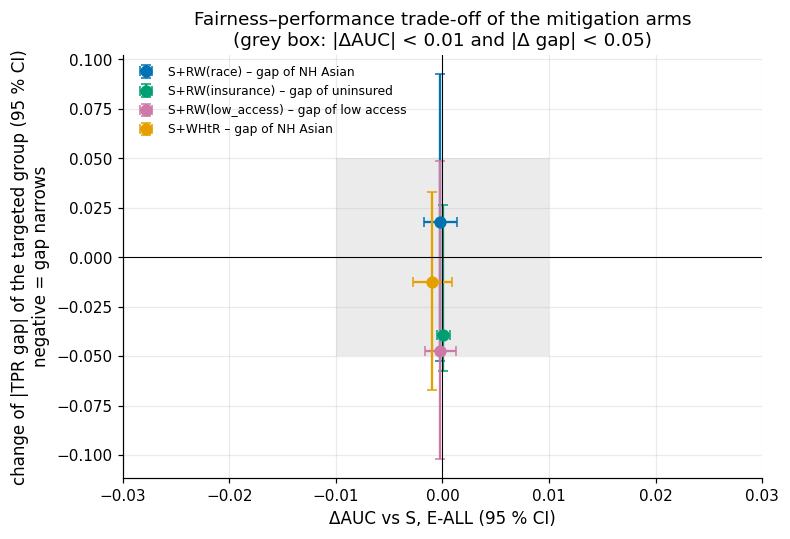

In [189]:
wh_auc = compare_auc(OOF[("S+WHtR", 1, "lr")], OOF[("S", 1, "lr")], "E-ALL", tag="whtr")
TO = []
for attr, tgt in RW_TARGET.items():
    a = RWT[(RWT["arm"] == f"S+RW({attr})") & (RWT["pop"] == "E-ALL")].iloc[0]
    e = RWE[(RWE["arm"] == f"S+RW({attr})") & (RWE["group"] == tgt)].iloc[0]
    TO.append({"arm": f"S+RW({attr})", "target": tgt, "d_auc": a["est"], "d_auc_lo": a["lo"], "d_auc_hi": a["hi"],
               "d_abs_eod": e["d_abs_eod"], "d_abs_eod_lo": e["d_abs_lo"], "d_abs_eod_hi": e["d_abs_hi"]})
TO.append({"arm": "S+WHtR", "target": "NH Asian", "d_auc": wh_auc["est"], "d_auc_lo": wh_auc["lo"], "d_auc_hi": wh_auc["hi"],
           "d_abs_eod": r_eod["est"], "d_abs_eod_lo": r_eod["lo"], "d_abs_eod_hi": r_eod["hi"]})
TO = pd.DataFrame(TO)
TO["in_no_change_box"] = (TO["d_auc_lo"] > -AUC_SESOI) & (TO["d_auc_hi"] < AUC_SESOI) & (TO["d_abs_eod_lo"] > -GAP) & (TO["d_abs_eod_hi"] < GAP)
print(TO.round(4).to_string(index=False))
TO.to_csv(OUT / "tradeoff.csv", index=False)
S8["tradeoff"] = TO.round(5).to_dict("records")

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.add_patch(plt.Rectangle((-AUC_SESOI, -GAP), 2 * AUC_SESOI, 2 * GAP, color=C.OKABE_ITO["grey"], alpha=0.15, lw=0))
cols = [C.OKABE_ITO["blue"], C.OKABE_ITO["green"], C.OKABE_ITO["purple"], C.OKABE_ITO["orange"]]
for (_, r), col in zip(TO.iterrows(), cols):
    ax.errorbar(r["d_auc"], r["d_abs_eod"], xerr=[[r["d_auc"] - r["d_auc_lo"]], [r["d_auc_hi"] - r["d_auc"]]],
                yerr=[[r["d_abs_eod"] - r["d_abs_eod_lo"]], [r["d_abs_eod_hi"] - r["d_abs_eod"]]], fmt="o", color=col,
                capsize=3, ms=7, label=f"{r['arm']} – gap of {r['target']}")
ax.axhline(0, color="black", lw=0.7); ax.axvline(0, color="black", lw=0.7)
ax.set_xlabel("ΔAUC vs S, E-ALL (95 % CI)")
ax.set_ylabel("change of |TPR gap| of the targeted group (95 % CI)\nnegative = gap narrows")
ax.set_xlim(-0.03, 0.03)
ax.legend(fontsize=8, loc="upper left")
ax.set_title("Fairness–performance trade-off of the mitigation arms\n(grey box: |ΔAUC| < 0.01 and |Δ gap| < 0.05)")
f85 = plots.savefig(fig, "S8_tradeoff", caption="F8-5. Fairness-performance plane for the mitigation arms (Tier 1): ΔAUC "
                    "against arm S on E-ALL (wider of corrected-t and paired-bootstrap CI) versus the change in the absolute "
                    "TPR gap of the targeted group at specificity 0.80 (paired stratified bootstrap); grey box = no practical change.")
plt.show()

**So what.** All four mitigations sit on the vertical line: none costs discrimination (every ΔAUC CI inside ±0.01). None
demonstrably helps either: the targeted gaps move by −0.05 to +0.02, every interval crosses zero and is wider than
±0.05, so no arm reaches the "no change" box or a clear improvement. Low-access and insurance reweighing have the
largest point gains for their targets; race reweighing and WHtR barely move the NH Asian gap. There is no trade-off to
manage because there is no demonstrated benefit to trade against; with the present sample sizes the honest summary is
"cheap, harmless, not shown to help".

## 8.12 Within-group calibration
**Why.** Equal sensitivity is one fairness criterion; calibration within groups (a predicted 20 % meaning 20 % in
every group) is another, and the two cannot in general hold together when prevalences differ (Chouldechova 2017).
Arm S is class-weighted, so its probabilities are inflated by design and only *relative* calibration across groups
can be read from it. Absolute calibration is therefore checked on **S−B6a** – arm S without class weights, equivalent
in AUC (§7) – which is the calibrated sibling of S. For each group: observed-to-expected ratio O:E (bootstrap CI),
calibration-in-the-large (CITL, log-odds offset; 0 = calibrated) and calibration slope (1 = calibrated). Here the
bootstrap resamples within groups but *not* within label, so the number of observed cases varies across replicates
(a label-stratified bootstrap would fix the numerator of O:E and understate its uncertainty).

S-B6a overall: O:E 1.017, CITL +0.027, slope 0.979
 attribute            group    n  n_pos  mean_pred  observed    oe  oe_lo  oe_hi   citl  slope  oe_S_relative  oe_ci_excludes_1
      race         NH White 2727    398      0.167     0.146 0.876  0.809  0.950 -0.203  1.043          0.857              True
      race         NH Black  540    131      0.186     0.243 1.304  1.125  1.476  0.455  0.788          1.308              True
      race         NH Asian  252     40      0.117     0.159 1.353  1.030  1.738  0.450  1.019          1.198              True
      race Mexican American  309     69      0.160     0.223 1.393  1.156  1.672  0.566  0.994          1.376              True
      race   Other Hispanic  465     82      0.166     0.176 1.064  0.890  1.221  0.101  1.107          1.054             False
      race      Other/Multi  291     57      0.181     0.196 1.081  0.862  1.303  0.133  0.909          1.114             False
 insurance          insured 4186    725      0.170   

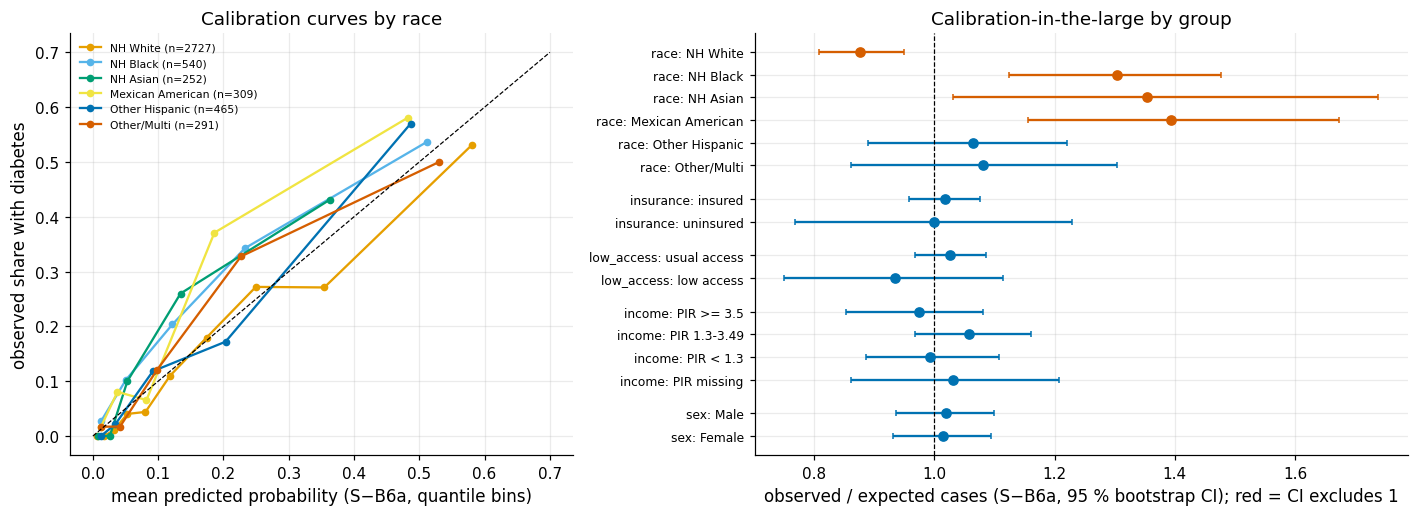

In [190]:
pC = PM[("S-B6a", 1, "lr")]
cal_rows = []
for attr in F.ATTRIBUTES:
    point, boot, codes, mm = audit(attr, "E-ALL", 1, ("S-B6a", "S"), weights="group")
    lvls = F.LEVELS[attr]
    oe_all_S = y.sum() / pS.sum()
    for g_i, g_nm in enumerate(lvls):
        m = grp[attr].eq(g_nm).to_numpy()
        slope, icpt, citl = ek._calibration(y[m], pC[m])
        e, lo, hi, _ = F.summarise(point["oe"][0, 0, g_i], boot["oe"][:, 0, g_i])
        cal_rows.append({"attribute": attr, "group": g_nm, "n": int(m.sum()), "n_pos": int(y[m].sum()),
                         "mean_pred": pC[m].mean(), "observed": y[m].mean(), "oe": e, "oe_lo": lo, "oe_hi": hi,
                         "citl": citl, "slope": slope, "oe_S_relative": point["oe"][0, 1, g_i] / oe_all_S})
CAL = pd.DataFrame(cal_rows)
CAL["oe_ci_excludes_1"] = (CAL["oe_lo"] > 1) | (CAL["oe_hi"] < 1)
slope_all, _, citl_all = ek._calibration(y, pC)
print(f"S-B6a overall: O:E {y.sum() / pC.sum():.3f}, CITL {citl_all:+.3f}, slope {slope_all:.3f}")
print(CAL.round(3).to_string(index=False))
CAL.to_csv(OUT / "group_calibration.csv", index=False)
S8["calibration"] = dict(table=CAL.round(5).to_dict("records"), overall=dict(oe=float(y.sum() / pC.sum()), citl=citl_all, slope=slope_all),
                         groups_oe_ci_excl_1=CAL.loc[CAL["oe_ci_excludes_1"], ["attribute", "group", "oe"]].round(3).to_dict("records"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
for g_nm, col in zip(F.LEVELS["race"], plots.PALETTE):
    m = grp["race"].eq(g_nm).to_numpy()
    nb = 5 if m.sum() < 600 else 10
    q = pd.qcut(pC[m], nb, labels=False, duplicates="drop")
    d_ = pd.DataFrame({"p": pC[m], "y": y[m], "q": q}).groupby("q").mean()
    ax.plot(d_["p"], d_["y"], "o-", color=col, label=f"{g_nm} (n={int(m.sum())})", ms=4)
ax.plot([0, 0.7], [0, 0.7], color="black", lw=0.8, ls="--")
ax.set_xlabel("mean predicted probability (S−B6a, quantile bins)"); ax.set_ylabel("observed share with diabetes")
ax.set_title("Calibration curves by race"); ax.legend(fontsize=7)
ax = axes[1]
k = 0; yt, yl = [], []
for attr in F.ATTRIBUTES:
    for _, r in CAL[CAL["attribute"] == attr].iterrows():
        ax.errorbar(r["oe"], -k, xerr=[[r["oe"] - r["oe_lo"]], [r["oe_hi"] - r["oe"]]], fmt="o",
                    color=C.OKABE_ITO["vermillion"] if r["oe_ci_excludes_1"] else C.OKABE_ITO["blue"], capsize=2)
        yt.append(-k); yl.append(f"{attr}: {r['group']}"); k += 1
    k += 0.5
ax.axvline(1, color="black", lw=0.8, ls="--")
ax.set_yticks(yt); ax.set_yticklabels(yl, fontsize=8)
ax.set_xlabel("observed / expected cases (S−B6a, 95 % bootstrap CI); red = CI excludes 1")
ax.set_title("Calibration-in-the-large by group")
fig.tight_layout()
f84 = plots.savefig(fig, "S8_group_calibration", caption="F8-4. Within-group calibration of arm S-B6a (arm S without class "
                    "weights, AUC-equivalent): calibration curves by race (quantile bins) and observed/expected ratio by audit "
                    "group with stratified bootstrap 95 % CI (E-ALL, Tier 1, training part OOF).")
plt.show()

**So what.** The calibrated sibling is well calibrated overall (O:E about 1.02, slope about 0.98) and across insurance,
access, income and sex, but **not across race**: it under-predicts for NH Black, NH Asian and Mexican American adults
(about 30–40 % more cases than predicted, CIs excluding 1) and over-predicts for NH White adults. This is the price of a
race-blind model when prevalence differs by race at the same feature values: the score is an average over groups. It is
also the second face of the TPR gap for Asian adults – their scores are too low on both the ranking and the
probability scale. Correcting it would require race as an input or a race-specific recalibration, which the project
excludes for the same reasons as group thresholds (section 10); it is reported as a limitation, and any use of the
probabilities for individual counselling should carry this caveat.

## 8.13 Verdicts
**Why.** Each locked hypothesis tested in S8 gets one verdict from the locked rules (`governance/hypotheses.md`):
`evalkit.verdict` with the SESOI of `config.SESOI` (group TPR gap 0.05, AUC 0.01), sub-claims combined with
`evalkit.combine_verdicts`. H3 is a genuine pre-registration (`prior_exposure = none`); P14-b and H4b were written
after a descriptive look (`descriptive_seen`). The group-gap flags of sections 3–4 are audit findings, not
hypotheses, and are listed separately.

In [191]:
sub_eall = ET1[ET1["substantive"] & ET1["verdict_status"].eq("reportable")]
sub_escr = ETs[ETs["substantive"] & ETs["verdict_status"].eq("reportable")]
SB8 = pd.DataFrame([
    dict(hyp_id="H3", prior_exposure="none", sub="E1 L_self misses Undiagnosed most", verdict=elem_v["E1"],
         evidence="; ".join(f"{r.contrast} {r.est:+.3f} ({r.lo:+.3f}, {r.hi:+.3f})" for r in H3E[H3E.element == "E1"].itertuples())),
    dict(hyp_id="H3", prior_exposure="none", sub="E2 L_A1c misses D_controlled most", verdict=elem_v["E2"],
         evidence="; ".join(f"{r.contrast} {r.est:+.3f} ({r.lo:+.3f}, {r.hi:+.3f})" for r in H3E[H3E.element == "E2"].itertuples())),
    dict(hyp_id="H3", prior_exposure="none", sub="E3 L_comb smallest worst-cell gap", verdict=elem_v["E3"],
         evidence="; ".join(f"{r.contrast} {r.est:+.3f} ({r.lo:+.3f}, {r.hi:+.3f})" for r in H3E[H3E.element == "E3"].itertuples())),
    dict(hyp_id="H3", prior_exposure="none", sub="overall", verdict=h3_v, evidence="combine_verdicts(E1-E3); falsifier: any contrast reversed with CI excluding 0"),
    dict(hyp_id="P14", prior_exposure="descriptive_seen", sub="(a) |ΔAUC| < 0.01 (from S7)", verdict=p14a["verdict"],
         evidence=f"ΔAUC {p14a['est']:+.4f} ({p14a['lo']:+.4f}, {p14a['hi']:+.4f}), corrected t"),
    dict(hyp_id="P14", prior_exposure="descriptive_seen", sub="(b) NH Asian ΔTPR ≥ +0.05", verdict=v_p14b,
         evidence=f"ΔTPR {r_dA['est']:+.3f} ({r_dA['lo']:+.3f}, {r_dA['hi']:+.3f}), {r_dA['interval']} interval; White ΔTPR {r_dW['est']:+.3f}"),
    dict(hyp_id="P14", prior_exposure="descriptive_seen", sub="overall", verdict=v_p14, evidence="combine_verdicts(a, b)"),
    dict(hyp_id="H4b", prior_exposure="descriptive_seen", sub="single feature (S5)", verdict=s5_h4b,
         evidence=R.load_section("S5")["hypotheses"]["H4b"]["estimate"]),
    dict(hyp_id="H4b", prior_exposure="descriptive_seen", sub="model level (S8, secondary)", verdict=v_h4b_model,
         evidence=f"ΔAUC_Asian − ΔAUC_White {r_h4['est']:+.4f} ({r_h4['lo']:+.4f}, {r_h4['hi']:+.4f})"),
    dict(hyp_id="H4b", prior_exposure="descriptive_seen", sub="overall", verdict=v_h4b,
         evidence="S5 primary; a decisive contradicting S8 model-level verdict would make it mixed"),
])
assert set(SB8["verdict"]) <= set(C.VERDICTS)
print(SB8.to_string(index=False, max_colwidth=110))
print("\naudit flags (not hypotheses): substantive reportable gaps")
print(f"  E-ALL: {[(r.attribute, r.group, round(r.eod, 3), round(r.eod_lo, 3), round(r.eod_hi, 3)) for r in sub_eall.itertuples()]}")
print(f"  E-SCREEN: {[(r.attribute, r.group, round(r.eod, 3), round(r.eod_lo, 3), round(r.eod_hi, 3)) for r in sub_escr.itertuples()]}")
SB8.to_csv(OUT / "scoreboard.csv", index=False)
S8["scoreboard"] = {h: g.set_index("sub")["verdict"].to_dict() for h, g in SB8.groupby("hyp_id")}
S8["verdicts"] = {"H3": h3_v, "P14": v_p14, "P14b": v_p14b, "H4b": v_h4b, "H4b_model_level": v_h4b_model}
S8["substantive_gaps"] = {"E-ALL": sub_eall[["attribute", "group", "eod", "eod_lo", "eod_hi"]].round(4).to_dict("records"),
                          "E-SCREEN": sub_escr[["attribute", "group", "eod", "eod_lo", "eod_hi"]].round(4).to_dict("records")}

hyp_id   prior_exposure                               sub      verdict                                                                                                       evidence
    H3             none E1 L_self misses Undiagnosed most inconclusive      Undiagnosed: L_self - L_A1c -0.055 (-0.126, +0.024); Undiagnosed: L_self - L_comb -0.016 (-0.079, +0.024)
    H3             none E2 L_A1c misses D_controlled most inconclusive     D_controlled: L_A1c - L_self -0.046 (-0.097, +0.005); D_controlled: L_A1c - L_comb -0.041 (-0.092, +0.010)
    H3             none E3 L_comb smallest worst-cell gap inconclusive worst-cell gap: L_comb - L_self -0.016 (-0.079, +0.028); worst-cell gap: L_comb - L_A1c -0.007 (-0.087, +0....
    H3             none                           overall inconclusive                                  combine_verdicts(E1-E3); falsifier: any contrast reversed with CI excluding 0
   P14 descriptive_seen       (a) |ΔAUC| < 0.01 (from S7)    supported                    

**So what.** None of the S8 experiments produces a decisive verdict, and each "inconclusive" means something specific:

* **H3 – inconclusive.** All three predicted orderings point the right way, but the label shifts recall by at most about
  0.06 while the CIs are about ±0.07 wide; neither the ordering nor equivalence is established. What *is* clear is that
  no label lets non-laboratory features find the undiagnosed as well as the diagnosed.
* **P14 – inconclusive.** WHtR is harmless for overall discrimination (a: supported) and moves Asian sensitivity the
  predicted way, but only by +0.025, and the PSU-cluster interval neither confirms nor excludes the +0.05 gain (b).
* **H4b – supported (S5), not transferred.** The single-feature WHtR advantage for Asian adults is real; inside the
  multivariable model, which already contains waist, height and BMI, it shrinks to a few thousandths of AUC.

The decisive S8 results are audit findings rather than hypothesis tests: a substantive NH Asian sensitivity gap beyond
the permutation null (exploratory), SES-driven income gaps, an access imprint that appears when the model learns from
self-report (direction consistent, label contrast not yet significant), and race-level miscalibration of a race-blind
model. The screening population is too small for any group verdict except sex, where no gap is established.

The wording refers to the FINAL run stored in this notebook (5 × 5 CV, B = 1000, coefficient B = 500). A FAST re-run
(5 × 2, B = 100) reproduces the verdicts, but borderline audit items (the E-SCREEN sex gap, the access-label contrast,
the income middle band, the WHtR point gain) can cross their thresholds in either direction.

## 8.14 Register and storage
**Why.** Every decision of this section goes into the decision register with the evidence computed above (no value
is typed by hand), and every number into `results/metrics_S8.json` and `results/S8/`, so that S10 and the slides read
them instead of re-typing them.

In [192]:
REGISTER_COLS = ["dr_id", "stage", "date", "type", "finding", "evidence_ref", "evidence_value", "decision",
                 "alternatives_rejected", "hyp_id", "status", "check_verdict", "check_note", "loop_ref", "change_request", "commit"]
TODAY = "2026-10-11"
eodA = ET1.set_index(["attribute", "group"]).loc[("race", "NH Asian")]
permr = PERM1.set_index("attribute")
rw_rng = {a: f"{w.min():.2f}-{w.max():.2f}" for a, w in RW_W.items()}
rw_auc = RWT[RWT["pop"] == "E-ALL"].set_index("arm")
cal_race = CAL[(CAL["attribute"] == "race") & CAL["oe_ci_excludes_1"]]
acc_d = ACCD.set_index(["feature", "contrast"])
sex_s = ETs.set_index("attribute").loc["sex"]
reg = [
    dict(dr_id="DR-S8-01", type="audit_design",
         finding="Group cells are small (no oversampling in 2021-23); E-SCREEN has 127 positives in the training part",
         evidence_ref="results/S8/group_sizes.csv", evidence_value=f"suppressed groups E-ALL {n_supp['eall']}/16, E-SCREEN {n_supp['escreen']}/16; NH Asian 40 positives (E-ALL)",
         decision="Audit race (NH Asian separate, exploratory), insurance, low access, income band, sex on training-part OOF; NCHS rule n<30 or positives<30 -> show, no gap verdict",
         alternatives_rejected="Pooling Asian with Other/Multi (hides the BMI measurement issue); verdicts on suppressed cells",
         status="decided", check_verdict="PASS", check_note="counts recomputed from the cohort and the stored split"),
    dict(dr_id="DR-S8-02", type="threshold",
         finding="One operating point is needed to compare groups; group thresholds need race at prediction time",
         evidence_ref="notebooks/sections/07_fairness.py sections 2 and 10; results/metrics_S8.json group_threshold_counterfactual",
         evidence_value=f"shared threshold {thr_check:.3f} (spec 0.80, E-ALL); Asian threshold for White TPR {t_a:.3f} (CI {GTHR['threshold_asian_ci'][0]:.3f}-{GTHR['threshold_asian_ci'][1]:.3f}), Asian FPR {fpr_overall_a:.3f}->{fpr_a:.3f}",
         decision="Single threshold at overall specificity 0.80, re-estimated in each bootstrap replicate; no group-specific thresholds (R7.2)",
         alternatives_rejected="ThresholdOptimizer / equalised-odds post-processing (uses race at prediction, levelling down, unstable with ~40 cases)",
         status="decided", check_verdict="PASS", check_note="engine threshold equals evalkit.recall_at_specificity (asserted)"),
    dict(dr_id="DR-S8-03", type="finding",
         finding="Model reproduces label and measurement bias: NH Asian and income gaps exceed the permutation null on E-ALL",
         evidence_ref="results/S8/eod_eall_t1.csv; results/S8/permutation.csv; results/S8/gap_decomposition.csv; figures/S8_group_tpr.png",
         evidence_value=f"NH Asian EOD {eodA['eod']:+.3f} ({eodA['eod_lo']:+.3f}, {eodA['eod_hi']:+.3f}), race max|EOD| p {permr.loc['race', 'p_value']:.3f}; income p {permr.loc['income', 'p_value']:.3f}; TPR diagnosed {tpr_dx_all:.2f} vs undiagnosed {tpr_ud_all:.2f}",
         decision="Report gaps with CIs and permutation baseline; attribute them to routes (diagnosis/care traces, BMI, SES inputs); ecological-fallacy caveat; no claim about individual risk",
         alternatives_rejected="Reporting raw group differences without a null; interpreting group TPR as individual risk",
         hyp_id="", status="decided", check_verdict="PASS", check_note="NH Asian exploratory (40 positives)"),
    dict(dr_id="DR-S8-04", type="finding",
         finding="Screening-population (E-SCREEN) fairness cannot be audited by race, insurance or access at this sample size",
         evidence_ref="results/S8/eod_escreen_t1.csv",
         evidence_value=f"reportable E-SCREEN contrasts {len(rep_s)}/{len(ETs)}; female - male EOD {sex_s['eod']:+.3f} ({sex_s['eod_lo']:+.3f}, {sex_s['eod_hi']:+.3f}), permutation p {PERMs.set_index('attribute').loc['sex', 'p_value']:.3f}",
         decision="E-SCREEN group gaps shown as numbers only; the only reportable contrast (sex) reported with CI and permutation p; limitation for S10",
         alternatives_rejected="Pooling E-ALL and E-SCREEN (mixes the use cases)", status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-05", type="hypothesis_test",
         finding="3x3 label matrix: predicted ordering points the right way but differences are small; Undiagnosed is hardest for every label",
         evidence_ref="results/S8/label_matrix_cells.csv; results/S8/h3_contrasts.csv; figures/S8_label_matrix.png",
         evidence_value=f"recall Undiagnosed L_self {LM['recall'].loc['L_self', 'Undiagnosed']:.3f}, L_A1c {LM['recall'].loc['L_A1c', 'Undiagnosed']:.3f}, L_comb {LM['recall'].loc['L_comb', 'Undiagnosed']:.3f}; D_controlled L_A1c {LM['recall'].loc['L_A1c', 'D_controlled']:.3f}; elements {elem_v}",
         decision=f"H3 verdict {h3_v}; L_comb stays the frozen target", alternatives_rejected="Switching the training label after seeing the matrix",
         hyp_id="H3", status="decided", check_verdict="PASS", check_note="L_comb x Undiagnosed cell equals E-SCREEN recall of S (asserted)"),
    dict(dr_id="DR-S8-06", type="audit",
         finding="Trained on self-report, the model learns that poor access means lower risk; the label contrast points the same way",
         evidence_ref="results/S8/access_audit_coefs.csv; results/S8/access_audit_diffs.csv",
         evidence_value=f"no usual place under L_self {ACC.set_index(['feature', 'label']).loc[('no_usual_place', 'L_self'), 'coef_per_sd']:+.3f} ({ACC.set_index(['feature', 'label']).loc[('no_usual_place', 'L_self'), 'lo']:+.3f}, {ACC.set_index(['feature', 'label']).loc[('no_usual_place', 'L_self'), 'hi']:+.3f}); uninsured L_self - L_comb {acc_d.loc[('uninsured', 'L_self - L_comb'), 'diff_per_sd']:+.3f} ({acc_d.loc[('uninsured', 'L_self - L_comb'), 'lo']:+.3f}, {acc_d.loc[('uninsured', 'L_self - L_comb'), 'hi']:+.3f}); no usual place {acc_d.loc[('no_usual_place', 'L_self - L_comb'), 'diff_per_sd']:+.3f} ({acc_d.loc[('no_usual_place', 'L_self - L_comb'), 'lo']:+.3f}, {acc_d.loc[('no_usual_place', 'L_self - L_comb'), 'hi']:+.3f})",
         decision="Access features remain audit-only (P03); evidence supports the union label over self-report",
         alternatives_rejected="Adding insurance/usual place as predictors (would encode access to diagnosis)", status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-07", type="mitigation",
         finding="Race reweighing changes neither AUC nor the Asian gap and widens the NH Black gap",
         evidence_ref="results/S8/reweighing_auc.csv; results/S8/reweighing_eod.csv",
         evidence_value=f"w range race {rw_rng['race']}; dAUC {rw_auc.loc['S+RW(race)', 'est']:+.4f} ({rw_auc.loc['S+RW(race)', 'lo']:+.4f}, {rw_auc.loc['S+RW(race)', 'hi']:+.4f})",
         decision="Not adopted; reported as a null mitigation", alternatives_rejected="Race as a model feature (S9 sensitivity only)",
         status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-08", type="mitigation",
         finding="Insurance and low-access reweighing: AUC unchanged, targeted gaps narrow slightly with CIs including 0",
         evidence_ref="results/S8/reweighing_auc.csv; results/S8/reweighing_eod.csv; results/S8/tradeoff.csv",
         evidence_value=f"w range insurance {rw_rng['insurance']}, low access {rw_rng['low_access']}; dAUC {rw_auc.loc['S+RW(insurance)', 'est']:+.4f} / {rw_auc.loc['S+RW(low_access)', 'est']:+.4f}",
         decision="Not adopted (no demonstrated benefit); extension item complete", alternatives_rejected="Adopting on point estimates",
         status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-09", type="hypothesis_test",
         finding="WHtR raises NH Asian TPR in point estimate only; PSU-cluster interval crosses 0",
         evidence_ref="results/S8/whtr_p14b.csv; figures/S8_whtr_asian_white.png",
         evidence_value=f"Asian dTPR {r_dA['est']:+.3f} (simple {r_dA['simple_lo']:+.3f}, {r_dA['simple_hi']:+.3f}; PSU {r_dA['psu_lo']:+.3f}, {r_dA['psu_hi']:+.3f}); White {r_dW['est']:+.3f}; dAUC {r_auc['est']:+.4f}",
         decision=f"P14-b {v_p14b}, P14 {v_p14}; WHtR not adopted as a new preparation step; loop L4 not triggered",
         alternatives_rejected="Adopting WHtR on the point estimate (post hoc)", hyp_id="P14", status="decided", check_verdict="PASS",
         loop_ref="L4"),
    dict(dr_id="DR-S8-10", type="hypothesis_test",
         finding="The single-feature WHtR advantage for Asian adults does not transfer to the multivariable model",
         evidence_ref="results/S8/whtr_p14b.csv", evidence_value=f"model-level dAUC Asian - White {r_h4['est']:+.4f} ({r_h4['lo']:+.4f}, {r_h4['hi']:+.4f})",
         decision=f"H4b stays {v_h4b} on the S5 single-feature test; S8 model-level result {v_h4b_model} reported as secondary",
         hyp_id="H4b", status="decided", check_verdict="PASS"),
    dict(dr_id="DR-S8-11", type="finding",
         finding="Race-blind model is calibrated overall but not within race",
         evidence_ref="results/S8/group_calibration.csv; figures/S8_group_calibration.png",
         evidence_value=f"S-B6a O:E overall {y.sum() / pC.sum():.2f}; groups with CI excluding 1: {cal_race[['group', 'oe']].round(2).to_dict('records')}",
         decision="Reported as a limitation; no race-specific recalibration (same reasons as DR-S8-02)",
         alternatives_rejected="Race-specific recalibration", status="decided", check_verdict="PASS"),
]
REG8 = pd.DataFrame(reg)
REG8["stage"], REG8["date"] = "S8", TODAY
for c in REGISTER_COLS:
    if c not in REG8:
        REG8[c] = ""
REG8 = REG8[REGISTER_COLS].fillna("")
REG8.to_csv(C.GOVERNANCE_DIR / "register" / "S8.csv", index=False, lineterminator="\n")
print(REG8[["dr_id", "type", "decision"]].to_string(index=False, max_colwidth=110))

   dr_id            type                                                                                                       decision
DR-S8-01    audit_design Audit race (NH Asian separate, exploratory), insurance, low access, income band, sex on training-part OOF; ...
DR-S8-02       threshold Single threshold at overall specificity 0.80, re-estimated in each bootstrap replicate; no group-specific t...
DR-S8-03         finding Report gaps with CIs and permutation baseline; attribute them to routes (diagnosis/care traces, BMI, SES in...
DR-S8-04         finding E-SCREEN group gaps shown as numbers only; the only reportable contrast (sex) reported with CI and permutat...
DR-S8-05 hypothesis_test                                                        H3 verdict inconclusive; L_comb stays the frozen target
DR-S8-06           audit                    Access features remain audit-only (P03); evidence supports the union label over self-report
DR-S8-07      mitigation                        

In [193]:
for nm, df_ in {"group_metrics_eall_t1": GT1, "eod_eall_t1": ET1, "group_metrics_escreen_t1": GTs, "eod_escreen_t1": ETs,
                "group_metrics_eall_t2": GT2, "eod_eall_t2": ET2,
                "permutation": pd.concat([PERM1, PERMs, PERM2], ignore_index=True)}.items():
    df_.to_csv(OUT / f"{nm}.csv", index=False)
S8["figures"] = [f81, f81b, f82, f83, f84, f85]
S8["runtime_seconds"] = time.time() - T_START
R.save_section("S8", S8)
print(f"saved results/metrics_S8.json, {len(list(OUT.glob('*.csv')))} tables in results/S8, governance/register/S8.csv "
      f"({len(REG8)} rows); runtime {S8['runtime_seconds']:.0f} s ({C.NB_MODE})")
print(json.dumps(S8["verdicts"]))

saved results/metrics_S8.json, 19 tables in results/S8, governance/register/S8.csv (11 rows); runtime 55 s (FINAL)
{"H3": "inconclusive", "P14": "inconclusive", "P14b": "inconclusive", "H4b": "supported", "H4b_model_level": "inconclusive"}


# §9 Robustness and Credibility (Stage S9)

§7 reached its verdicts on one set of folds, one label definition, one imputation rule and one
regularisation strength. This section asks how much of that is **procedure** and how much is **data**:

* **controls** – does the evaluation produce AUC 0.5 when there is nothing to find (label permutation,
  pure-noise feature), and does it find a signal of known size (positive control)?
* **stability** – does the headline comparison S − M1 keep its verdict under other CV seeds, 16
  pre-specified analysis variations, a 60-specification curve, survey-cluster folds and a
  missing-not-at-random scenario for HbA1c?
* **external validity** – do our population numbers line up with the published NCHS Data Brief 516?
* **leak hunt (loop L3)** – could any admissible feature be a disguised label?
* **hold-out** – the 20 % hold-out is evaluated **once**, only after the `exp-freeze` tag.

All work before section 11 uses the training part only (4,584 rows). Headline comparison throughout:
ΔAUC(S − M1), the "minimal vs systematic" contrast of hypothesis H2b(a) (locked rule: *supported* =
equivalence within ±0.01; §7 verdict *inconclusive*).

Contents: 1 reference · 2 controls · 3 seeds · 4 sensitivity table · 5 specification curve · 6 survey-cluster
CV · 7 missing HbA1c (IPW, delta) · 8 external validity · 9 leak hunt · 10 pre-hold-out summary ·
11 one-shot hold-out · 12 storage

In [194]:
new_section()

In [195]:
import json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek, survey as sv, robustness as RB
from src.robustness import Spec

pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 60)
warnings.filterwarnings("ignore", category=UserWarning)
os.environ.setdefault("PYTHONWARNINGS", "ignore")
OUT = C.RESULTS_DIR / "S9"
OUT.mkdir(parents=True, exist_ok=True)
N_JOBS = min(16, max(1, (os.cpu_count() or 2) - 2))
T_START = time.time()
# FAST mode (the re-run setting, <= ~5 min for the whole notebook) shrinks three extension-level loops; FINAL is unchanged:
# coefficient bootstrap of the noise check 500 -> 30 (config FAST value 100), robustness seeds 10 -> 5, specification
# curve 60 -> 30 specifications (C in {0.1, 10} instead of four values; C is the factor that matters least, see 5).
B_COEF9 = C.N_BOOT_COEF if C.IS_FINAL else 30
N_SEEDS = C.N_ROBUSTNESS_SEEDS if C.IS_FINAL else 5
C_CURVE = RB.C_GRID if C.IS_FINAL else (0.1, 10.0)
S9 = {"mode": C.NB_MODE, "cv": f"{C.CV_SPLITS}x{C.CV_REPEATS}", "n_boot": C.N_BOOT, "n_perm": C.N_PERM,
      "n_boot_coef": B_COEF9, "n_seeds": N_SEEDS, "n_curve": 15 * len(C_CURVE)}
OI = C.OKABE_ITO
S7m = R.load_section("S7")
print(f"mode {C.NB_MODE}: {C.CV_SPLITS}x{C.CV_REPEATS} CV, B = {C.N_BOOT}, permutations = {C.N_PERM}, coefficient B = {B_COEF9}, "
      f"{N_SEEDS} robustness seeds, {S9['n_curve']}-specification curve, {N_JOBS} workers")

mode FINAL: 5x5 CV, B = 1000, permutations = 100, coefficient B = 500, 10 robustness seeds, 60-specification curve, 16 workers


## 9.1 Reference comparison
**Why.** Every robustness check varies one thing against a fixed reference, so the reference must be
exactly the §7 run: same training part, same stored folds, frozen C0, same comparison engine
(`robustness.compare` mirrors the §7 engine: Nadeau–Bengio corrected t and paired bootstrap, wider interval on
E-ALL; bootstrap only on E-SCREEN).

In [196]:
ctx = RB.load_context()
RUNS = {}                                              # cache: (Spec, folds hash) -> OOF frame
hold = json.loads((C.RESULTS_DIR / "splits" / "holdout.json").read_text(encoding="utf-8"))
assert ctx.folds.hash == S7m["splits"]["folds_hash"] or not C.IS_FINAL, "FINAL run must use the S7 folds"
assert hold["sha256_test_seqn"] == S7m["splits"]["holdout_sha256"]
print(f"training part {ctx.n:,} rows, {ctx.y.sum()} L_comb positives; E-SCREEN {ctx.esc.sum():,} rows, "
      f"{ctx.y_esc[ctx.esc].sum()} positives; folds {len(ctx.folds)} ({ctx.folds.path.name}, hash {ctx.folds.hash[:12]}...)")
print(f"frozen C0 = {ctx.C0}; hold-out {len(ctx.test_idx):,} rows (SHA-256 {hold['sha256_test_seqn'][:16]}...) not read here")

def pair(spec_a, spec_b, folds=None, *, tag, label="L_comb", rows=None, use_t=True, w=None):
    """Run two specs (cached) and compare A - B on E-ALL (label) and E-SCREEN; returns two rows."""
    folds = ctx.folds if folds is None else folds
    oof = RB.run_many(ctx, {"a": spec_a, "b": spec_b}, folds, n_jobs=N_JOBS, cache=RUNS)
    f, mask = RB.spec_folds(ctx, spec_a, folds)
    _, mb = RB.spec_folds(ctx, spec_b, folds)
    assert (mask == mb).all(), "paired specs must use the same rows"
    lab = ctx.labels[label].to_numpy()[mask].astype(int)
    esc, y_esc = ctx.esc[mask], ctx.y_esc[mask]
    ww = None if w is None else w[mask]
    out = []
    for pop, yy, m, t in (("E-ALL", lab, None, use_t), ("E-SCREEN", y_esc, esc, False)):
        r = RB.compare(oof["a"], oof["b"], yy, f, mask=m, w=ww, use_t=t, seed_=RB.seed(tag, pop))
        out.append(dict(tag=tag, pop=pop, **r))
    return out

ref = pair(Spec("S"), Spec("M1"), tag="reference")
ref_df = pd.DataFrame(ref)
print(ref_df[["pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b"]].round(4).to_string(index=False))
s7_ref = next(r for r in S7m["scoreboard_detail"] if r["hyp_id"] == "H2b" and r["sub"] == "(a) AUC" and r["pop"] == "E-ALL" and r["tier"] == 1)
if C.IS_FINAL:   # identical folds, model and engine -> identical numbers
    assert abs(ref[0]["est"] - s7_ref["est"]) < 5e-5 and abs(ref[0]["hi"] - s7_ref["hi"]) < 5e-5, (ref[0]["est"], s7_ref)
print(f"S7 stored (FINAL): {s7_ref['est']:+.4f} [{s7_ref['lo']:+.4f}, {s7_ref['hi']:+.4f}] -> {s7_ref['verdict']}")
S9["reference"] = {r["pop"]: {k: r[k] for k in ("auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b")} for r in ref}

training part 4,584 rows, 777 L_comb positives; E-SCREEN 3,934 rows, 127 positives; folds 25 (folds_FINAL.npz, hash 0d20f8f706eb...)
frozen C0 = 0.1; hold-out 1,146 rows (SHA-256 616fd0590bec7b92...) not read here


     pop  auc_a  auc_b    est      lo     hi    interval    mdd          h2b
   E-ALL 0.8359 0.8285 0.0079  0.0000 0.0158 corrected_t 0.0112 inconclusive
E-SCREEN 0.7807 0.7723 0.0085 -0.0081 0.0236   bootstrap 0.0228 inconclusive
S7 stored (FINAL): +0.0079 [+0.0000, +0.0158] -> inconclusive


**So what.** In FINAL mode the reference reproduces §7 to the fourth decimal (asserted): S is better than M1
by about +0.008 AUC on E-ALL, but the interval runs from about 0 to about +0.016 – it neither excludes a
0.01 difference nor sits inside ±0.01, so H2b(a) is *inconclusive*. The question for every check below is
whether this verdict – not the point estimate – survives.

## 9.2 Negative and positive controls
### 9.2.1 Label permutation
**Why.** If the evaluation procedure leaked label information (preprocessing fitted on test rows, weights
derived from the label, a fold bug), a model trained on *permuted* labels would still score above 0.5. Each
permutation shuffles the training label of the whole training part, refits on the same folds and records
the mean per-fold AUC (`evalkit.permutation_auc`, Ojala & Garriga 2010). Acceptance: null mean in
[0.495, 0.505]. Features stay attached to their rows, so this test **cannot** detect feature leakage – that
is the job of the leak hunt (section 9).

arm  observed  null_mean  null_sd  null_min  null_max  p_value  n_perm  in_band
 M1    0.8274     0.5015   0.0127    0.4678    0.5352   0.0099     100     True
  S    0.8351     0.5014   0.0130    0.4698    0.5287   0.0099     100     True
5050 fits in 277 s


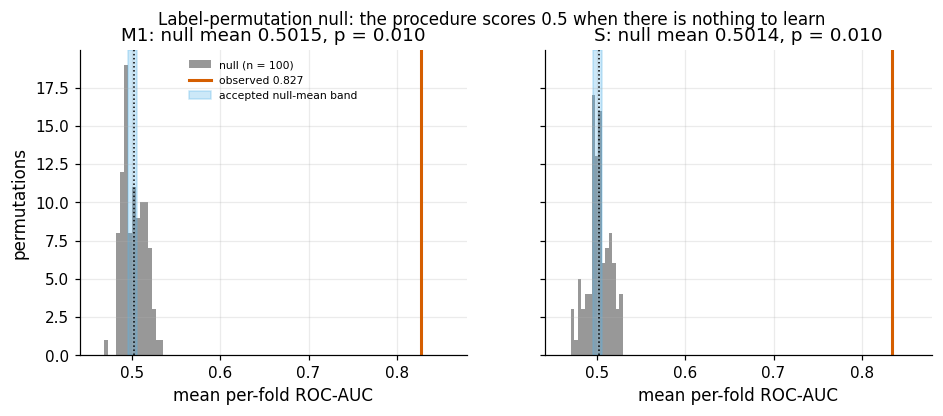

In [197]:
t0 = time.time()
# permutations are drawn up front and refitted independently: the worker count changes the wall time only (FAST may run
# all of its permutations at once; FINAL keeps its worker count)
N_JOBS_PERM = N_JOBS if C.IS_FINAL else max(N_JOBS, min(C.N_PERM, (os.cpu_count() or 2) - 2))
PERM = {arm: RB.permutation_null(ctx, Spec(arm), n_perm=C.N_PERM, seed_=RB.seed("perm", arm), n_jobs=N_JOBS_PERM)
        for arm in RB.ADMISSIBLE_ARMS}
perm_tab = pd.DataFrame([dict(arm=a, observed=d["observed"], null_mean=d["null_mean"], null_sd=d["null_sd"],
                              null_min=d["null"].min(), null_max=d["null"].max(), p_value=d["p_value"], n_perm=d["n_perm"],
                              in_band=RB.PERM_NULL_BAND[0] <= d["null_mean"] <= RB.PERM_NULL_BAND[1])
                         for a, d in PERM.items()])
perm_tab.to_csv(OUT / "permutation.csv", index=False)
print(perm_tab.round(4).to_string(index=False))
print(f"{sum(len(ctx.folds) * (d['n_perm'] + 1) for d in PERM.values())} fits in {time.time() - t0:.0f} s")
assert perm_tab["in_band"].all(), "permutation null mean outside [0.495, 0.505]: procedural leakage suspected"

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (arm, d) in zip(axes, PERM.items()):
    ax.hist(d["null"], bins=15, color=OI["grey"], alpha=0.8, label=f"null (n = {d['n_perm']})")
    ax.axvline(d["observed"], color=OI["vermillion"], lw=2, label=f"observed {d['observed']:.3f}")
    ax.axvspan(*RB.PERM_NULL_BAND, color=OI["sky"], alpha=0.3, label="accepted null-mean band")
    ax.axvline(d["null_mean"], color="k", ls=":", lw=1)
    ax.set(title=f"{arm}: null mean {d['null_mean']:.4f}, p = {d['p_value']:.3f}", xlabel="mean per-fold ROC-AUC")
    ax.set_xlim(0.44, 0.88)
axes[0].set_ylabel("permutations")
axes[0].legend(fontsize=7, loc="upper center")
fig.suptitle("Label-permutation null: the procedure scores 0.5 when there is nothing to learn", fontsize=11)
plots.savefig(fig, "S9_permutation_null", caption="F9-1. Mean per-fold ROC-AUC of M1 and S refitted on permuted training labels "
              f"({C.N_PERM} permutations, same folds; grey) against the observed value (red). Blue band = acceptance range "
              "[0.495, 0.505] for the null mean; dotted line = null mean. Training part, Tier 1, E-ALL.")
plt.show()
S9["permutation"] = perm_tab.set_index("arm").to_dict("index")

**So what.** Both null distributions are centred on 0.5 (means printed above, inside the acceptance band) and
no permutation comes near the observed AUC (p is the smallest value attainable with this number of
permutations). The cross-validation, the in-fold preprocessing and the survey and class weights do not leak
label information into the score. This is a statement about the *procedure* only.

### 9.2.2 Pure-noise feature
**Why.** A feature that is pure noise must look like noise to the model: an N(0, 1) column appended to the raw
frame should get a coefficient whose bootstrap interval covers 0, should not change the AUC, and should never
be chosen by the depth-3 tree. A model that "finds" signal in noise overfits; a pipeline that turns noise into
signal leaks.

In [198]:
rng = np.random.default_rng(RB.seed("noise"))
ctx.extras["noise_n01"] = rng.standard_normal(ctx.n)
noise_rows, NOISE_CB = [], {}
for arm in RB.ADMISSIBLE_ARMS:
    sp = Spec(arm, extra=("noise_n01",))
    X_, y_, sw_, _ = RB.spec_inputs(ctx, sp)
    cb = ek.coef_bootstrap(lambda sp=sp: RB.make_pipe(sp, ctx.C0), X_, y_.astype(int), n_boot=B_COEF9,
                           seed=RB.seed("noise-coef", arm), fit_params=None if sw_ is None else {"model__sample_weight": sw_},
                           n_jobs=N_JOBS)
    NOISE_CB[arm] = cb
    s = cb.summary.loc["noise_n01"]
    sdz = float(RB.make_pipe(sp, ctx.C0)[:-1].fit_transform(X_)["noise_n01"].std())   # per-SD scale of the design column
    cmp_ = pair(sp, Spec(arm), tag=f"noise-{arm}")
    tr_ = RB.tree_features_used(ctx, Spec(arm, model="tree", extra=("noise_n01",)), ctx.folds, "noise_n01")
    tr4 = RB.tree_features_used(ctx, Spec(arm, model="tree", depth=4, extra=("noise_n01",)), ctx.folds, "noise_n01")
    zt = (cb.summary["coef"] / cb.summary["sd"]).abs()                                # bootstrap |z| for a scale-free rank
    rank = int(zt.rank(ascending=False)["noise_n01"])
    noise_rows.append(dict(arm=arm, coef_per_sd=s["coef"] * sdz, q_low=s["q_low"] * sdz, q_high=s["q_high"] * sdz,
                           ci_covers_0=bool(s["q_low"] <= 0 <= s["q_high"]), abs_z_rank=f"{rank}/{len(cb.summary)}", abs_z=float(zt["noise_n01"]),
                           dAUC_eall=cmp_[0]["est"], dAUC_eall_lo=cmp_[0]["lo"], dAUC_eall_hi=cmp_[0]["hi"],
                           dAUC_eall_verdict=RB.equivalence_verdict(cmp_[0]["lo"], cmp_[0]["hi"]),
                           tree3_uses=int(tr_["uses_feature"].sum()), tree4_uses=int(tr4["uses_feature"].sum()),
                           n_trees=len(tr_)))
noise_tab = pd.DataFrame(noise_rows)
noise_tab.to_csv(OUT / "noise_feature.csv", index=False)
print(noise_tab.round(4).to_string(index=False))
assert noise_tab["ci_covers_0"].all() and (noise_tab["tree3_uses"] == 0).all()
S9["noise_feature"] = noise_tab.set_index("arm").to_dict("index")

arm  coef_per_sd   q_low  q_high  ci_covers_0 abs_z_rank  abs_z  dAUC_eall  dAUC_eall_lo  dAUC_eall_hi dAUC_eall_verdict  tree3_uses  tree4_uses  n_trees
 M1       0.0118 -0.0753  0.1100         True      43/47 0.2574    -0.0000       -0.0009        0.0009         supported           0           0       26
  S       0.0482 -0.0668  0.1691         True      30/43 0.7934    -0.0001       -0.0008        0.0005         supported           0           4       26


**So what.** In both admissible arms the noise coefficient ranks near the bottom by |coefficient / bootstrap SD|,
its bootstrap interval covers 0, adding the column leaves the AUC unchanged within ±0.01, and none of the
depth-3 trees (one per training fold plus the full fit) splits on it. The depth-4 count is reported for
completeness: a deeper tree has more chances to chase noise, and that is one reason the protocol caps the
tree at depth 3.

### 9.2.3 Positive control
**Why.** Negative controls show the procedure is not too optimistic; a positive control shows it is not blind.
A synthetic column z = d·y + N(0, 1), with d = √2·Φ⁻¹(0.60), has a known population AUC of 0.60 – a weak but
real signal, independent of every other feature given the label. The procedure must (i) recover its AUC and
(ii) detect the increment when z is added to M1 and S (paired ΔAUC interval excluding 0).

In [199]:
ctx.extras["pos_control"] = RB.signal_feature(ctx.y, RB.POS_CONTROL_AUC, seed_=RB.seed("positive-control"))
z_auc = RB.auc_ci(ctx.y, ctx.extras["pos_control"].to_numpy(), seed_=RB.seed("z-auc"))
print(f"single-feature AUC of z: {z_auc[0]:.3f} [{z_auc[1]:.3f}, {z_auc[2]:.3f}] (design value {RB.POS_CONTROL_AUC:.2f})")
pos_rows = []
for arm in RB.ADMISSIBLE_ARMS:
    for r in pair(Spec(arm, extra=("pos_control",)), Spec(arm), tag=f"pos-{arm}"):
        pos_rows.append(dict(arm=arm, pop=r["pop"], auc_without=r["auc_b"], auc_with=r["auc_a"], est=r["est"], lo=r["lo"],
                             hi=r["hi"], interval=r["interval"], detected=bool(r["lo"] > 0)))
pos_tab = pd.DataFrame(pos_rows)
pos_tab.to_csv(OUT / "positive_control.csv", index=False)
print(pos_tab.round(4).to_string(index=False))
assert z_auc[1] <= RB.POS_CONTROL_AUC <= z_auc[2], "positive-control AUC not recovered"
assert pos_tab.loc[pos_tab["pop"] == "E-ALL", "detected"].all(), "positive control not detected on E-ALL"
S9["positive_control"] = dict(z_auc=z_auc, rows=pos_tab.to_dict("records"))

single-feature AUC of z: 0.588 [0.567, 0.610] (design value 0.60)


arm      pop  auc_without  auc_with    est     lo     hi  interval  detected
 M1    E-ALL       0.8285    0.8345 0.0061 0.0023 0.0101 bootstrap      True
 M1 E-SCREEN       0.7723    0.7844 0.0122 0.0019 0.0228 bootstrap      True
  S    E-ALL       0.8359    0.8420 0.0061 0.0021 0.0102 bootstrap      True
  S E-SCREEN       0.7807    0.7939 0.0132 0.0026 0.0242 bootstrap      True


**So what.** The column's AUC is recovered (its interval contains the design value 0.60), and adding it raises
the E-ALL AUC of both arms with an interval that excludes 0, so a signal of this size would not be missed. The
increment is much smaller than 0.10 because the remaining features already rank most cases correctly – which
also calibrates expectations: a new risk factor with a univariate AUC of 0.60 buys only a few thousandths of
AUC on top of age, adiposity and blood pressure.

## 9.3 Seed stability
**Why.** A verdict that flips when only the random fold assignment changes is a property of one lucky split,
not of the data. Ten seeds derived from `SEED_MASTER` (`evalkit.derive_seed`) generate ten new repeated
stratified fold sets and bootstrap streams; the hold-out, the data, C0 and the final configuration stay fixed.
Acceptance: the H2b(a) verdict of S − M1 on E-ALL is the same under all ten seeds. (FAST re-run mode: the first
five of the ten seeds.)

10 seeds x 2 arms x 25 folds in 27 s
 seed_index      pop  auc_a  auc_b    est      lo     hi    interval          h2b
          0    E-ALL 0.8355 0.8287 0.0069 -0.0018 0.0155 corrected_t inconclusive
          0 E-SCREEN 0.7805 0.7739 0.0066 -0.0084 0.0222   bootstrap inconclusive
          1    E-ALL 0.8354 0.8290 0.0060 -0.0013 0.0133 corrected_t inconclusive
          1 E-SCREEN 0.7814 0.7735 0.0080 -0.0082 0.0224   bootstrap inconclusive
          2    E-ALL 0.8364 0.8297 0.0068  0.0005 0.0131 corrected_t inconclusive
          2 E-SCREEN 0.7834 0.7749 0.0086 -0.0072 0.0230   bootstrap inconclusive
          3    E-ALL 0.8352 0.8284 0.0071  0.0002 0.0140 corrected_t inconclusive
          3 E-SCREEN 0.7818 0.7746 0.0072 -0.0079 0.0223   bootstrap inconclusive
          4    E-ALL 0.8347 0.8271 0.0078  0.0014 0.0143 corrected_t inconclusive
          4 E-SCREEN 0.7816 0.7712 0.0104 -0.0054 0.0248   bootstrap inconclusive
          5    E-ALL 0.8356 0.8289 0.0065 -0.0014 0.0143 corr

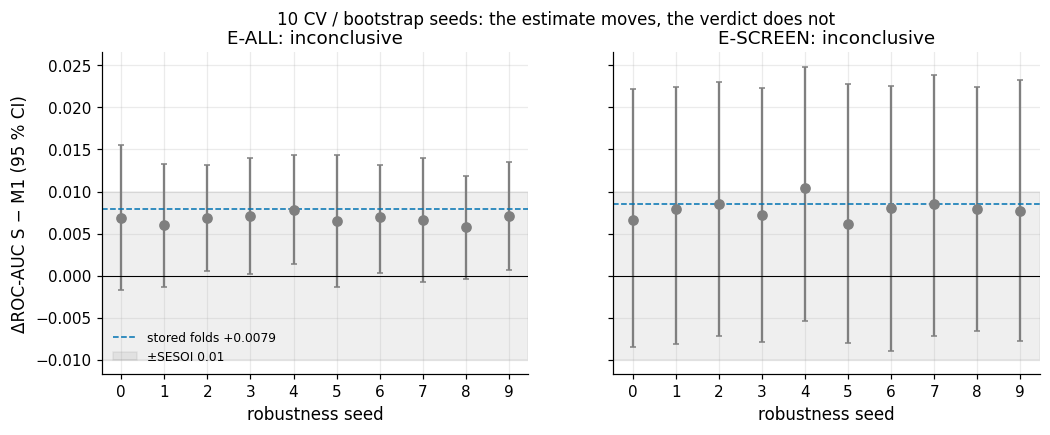

In [200]:
def prefetch(items):
    """Run many (spec, folds) pairs in one parallel batch (fills the cache used by `pair`)."""
    t0 = time.time()
    RB.run_jobs(ctx, items, n_jobs=N_JOBS, cache=RUNS)
    return time.time() - t0

SEED_FOLDS = {k: RB.seed_folds(ctx.strat, RB.seed("cv-seed", k)) for k in range(N_SEEDS)}
secs = prefetch({f"{a}{k}": (Spec(a), f) for k, f in SEED_FOLDS.items() for a in RB.ADMISSIBLE_ARMS})
seed_rows = []
for k, f in SEED_FOLDS.items():
    for r in pair(Spec("S"), Spec("M1"), f, tag=f"seed{k}"):
        seed_rows.append(dict(seed_index=k, seed=f.seed, folds_hash=f.hash[:12], **{c: r[c] for c in
                              ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b", "sesoi_class")}))
seeds = pd.DataFrame(seed_rows)
seeds.to_csv(OUT / "seed_stability.csv", index=False)
print(f"{len(SEED_FOLDS)} seeds x 2 arms x {len(ctx.folds)} folds in {secs:.0f} s")
print(seeds[["seed_index", "pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b"]].round(4).to_string(index=False))
seed_sum = seeds.groupby("pop").agg(est_min=("est", "min"), est_max=("est", "max"), est_sd=("est", "std"),
                                    lo_min=("lo", "min"), hi_max=("hi", "max"),
                                    verdicts=("h2b", lambda v: ", ".join(f"{k} x{n}" for k, n in v.value_counts().items())))
print(seed_sum.round(4).to_string())
seed_stable = seeds.loc[seeds["pop"] == "E-ALL", "h2b"].nunique() == 1
ref_v = S9["reference"]["E-ALL"]["h2b"]
print(f"E-ALL verdict identical under all seeds: {seed_stable} (reference: {ref_v})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
VCOL = {"supported": OI["green"], "refuted": OI["vermillion"], "inconclusive": OI["grey"]}
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    s = seeds[seeds["pop"] == pop].reset_index(drop=True)
    for i, r in s.iterrows():
        ax.errorbar(i, r["est"], yerr=[[r["est"] - r["lo"]], [r["hi"] - r["est"]]], fmt="o", color=VCOL[r["h2b"]], capsize=2)
    rr = S9["reference"][pop]
    ax.axhline(rr["est"], color=OI["blue"], ls="--", lw=1, label=f"stored folds {rr['est']:+.4f}")
    ax.axhspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12, label="±SESOI 0.01")
    ax.axhline(0, color="k", lw=0.7)
    ax.set(xticks=range(len(s)), xlabel="robustness seed", title=f"{pop}: {', '.join(s['h2b'].value_counts().index)}")
axes[0].set_ylabel("ΔROC-AUC S − M1 (95 % CI)")
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle(f"{len(SEED_FOLDS)} CV / bootstrap seeds: the estimate moves, the verdict does not", fontsize=11)
plots.savefig(fig, "S9_seed_stability", caption=f"F9-3. ΔROC-AUC (S − M1, Tier 1) with its conservative 95 % CI under {len(SEED_FOLDS)} robustness seeds "
              "(new repeated stratified folds and bootstrap streams; data, hold-out and C0 fixed). Colour = verdict under the locked "
              "equivalence rule (grey = inconclusive); dashed = stored folds of the run mode.")
plt.show()
S9["seeds"] = dict(n=len(SEED_FOLDS), stable_eall=bool(seed_stable), summary=seed_sum.to_dict("index"))

**So what.** Across the ten seeds the point estimate of S − M1 moves only in the third decimal (min, max and SD
printed) and every interval keeps straddling +0.01, so the E-ALL verdict is the same in all ten runs. The verdict
is a property of the data, not of the split; and it stays *inconclusive* for a structural reason – the true
difference sits close to the SESOI itself, so no reasonable amount of resampling will put the interval on one
side of it.

## 9.4 Sensitivity table
**Why.** Many analysis choices were made once (label, weighting, imputation, tier, C, model, excluded race).
Each of the 16 pre-specified variations below changes **one** choice for **both** arms and recomputes
ΔAUC(S − M1) on E-ALL and E-SCREEN with the same engine:

* labels SL1 (HbA1c only), SL2 (self-report only), SL3 (borderline positive), SL4 (treatment-aware) and SL5
  (NCHS definition incl. fasting glucose, fasting subsample only); training *and* E-ALL evaluation use the label,
  E-SCREEN keeps the screening definition;
* survey weights in the fit: unweighted for both arms, weighted for both arms (the reference weights S only);
* imputation: `IterativeImputer` instead of the median, and complete cases (rows without any missing Tier-1 input);
* Tier 2 (lipids); C ∈ {0.01, 1, 10} besides C0 = 0.1; depth-4 tree instead of logistic regression; race added
  as a feature (excluded by design in S1); M1 with its **own** tuned C (C0 was tuned on S, which favours S).

In [201]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline

# row subsets and extra columns used by the specifications
pre = Pipeline([s for s in P.preprocessor_steps(P.ARMS["S"], 1) if s[0] in ("p01", "p02", "p03", "no_care", "p04")])
pre_frame = pre.fit(ctx.X[1]).transform(ctx.X[1])          # stateless steps only: nothing is learned from y
ctx.subsets["complete"] = pre_frame.notna().all(axis=1).to_numpy()
ctx.subsets["fasting"] = ctx.labels["SL5"].notna().to_numpy()
ctx.extras["race_feature"] = ctx.cl["race"].astype(str).astype(object).to_numpy()
print(f"complete cases (no missing Tier-1 input after aggregation): {ctx.subsets['complete'].sum():,} of {ctx.n:,}; "
      f"fasting subsample: {ctx.subsets['fasting'].sum():,} rows, {int(ctx.labels['SL5'].sum())} SL5 positives")

def tune_C(arm):
    """LogisticRegressionCV over the C grid on the arm's own design (the S7 C0 procedure, applied to the arm)."""
    sp = Spec(arm)
    X_, y_, sw_, _ = RB.spec_inputs(ctx, sp)
    design = RB.make_pipe(sp, ctx.C0)[:-1].fit_transform(X_)
    inner = StratifiedKFold(5, shuffle=True, random_state=RB.seed("ownC", arm))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        lrcv = LogisticRegressionCV(Cs=list(RB.C_GRID), cv=inner, scoring="roc_auc", max_iter=C.LR_MAX_ITER,
                                    class_weight=P.model_kwargs(P.ARMS[arm])["class_weight"], l1_ratios=(0.0,),
                                    use_legacy_attributes=False, n_jobs=N_JOBS)
        lrcv.fit(design, y_.astype(int), sample_weight=sw_)
    sc = np.asarray(lrcv.scores_).reshape(5, -1).mean(axis=0).ravel()[:len(RB.C_GRID)]
    return float(np.ravel(lrcv.C_)[0]), {str(c): round(float(v), 4) for c, v in zip(RB.C_GRID, sc)}

OWN_C = {arm: tune_C(arm) for arm in ("M0", "M1")}
for arm, (c_, sc) in OWN_C.items():
    print(f"{arm}: own C = {c_}  (inner-CV AUC by C {sc}; C0 = {ctx.C0} was tuned on S)")

SENS = [  # (name, group, spec S, spec M1, E-ALL label)
    ("SL1 HbA1c only", "label", Spec("S", label="SL1"), Spec("M1", label="SL1"), "SL1"),
    ("SL2 self-report only", "label", Spec("S", label="SL2"), Spec("M1", label="SL2"), "SL2"),
    ("SL3 borderline positive", "label", Spec("S", label="SL3"), Spec("M1", label="SL3"), "SL3"),
    ("SL4 treatment-aware", "label", Spec("S", label="SL4"), Spec("M1", label="SL4"), "SL4"),
    ("SL5 NCHS incl. FPG (fasting)", "label", Spec("S", label="SL5", rows="fasting"), Spec("M1", label="SL5", rows="fasting"), "SL5"),
    ("unweighted fit (both)", "weights", Spec("S", weighted=False), Spec("M1"), "L_comb"),
    ("survey-weighted fit (both)", "weights", Spec("S"), Spec("M1", weighted=True), "L_comb"),
    ("IterativeImputer", "imputation", Spec("S", impute="iterative"), Spec("M1", impute="iterative"), "L_comb"),
    ("complete cases", "imputation", Spec("S", rows="complete"), Spec("M1", rows="complete"), "L_comb"),
    ("Tier 2 (+ lipids)", "tier", Spec("S", tier=2), Spec("M1", tier=2), "L_comb"),
    ("C = 0.01", "C", Spec("S", C=0.01), Spec("M1", C=0.01), "L_comb"),
    ("C = 1", "C", Spec("S", C=1.0), Spec("M1", C=1.0), "L_comb"),
    ("C = 10", "C", Spec("S", C=10.0), Spec("M1", C=10.0), "L_comb"),
    ("depth-4 tree", "model", Spec("S", model="tree", depth=4), Spec("M1", model="tree", depth=4), "L_comb"),
    ("race as a feature", "features", Spec("S", extra=("race_feature",)), Spec("M1", extra=("race_feature",)), "L_comb"),
    ("M1 with its own tuned C", "C", Spec("S"), Spec("M1", C=OWN_C["M1"][0]), "L_comb"),
]
assert len(SENS) <= 16
own_gate = [Spec("M1", C=OWN_C["M1"][0]), Spec("M0", C=OWN_C["M0"][0]), Spec("M0")]
secs = prefetch({f"{i}{j}": (sp, ctx.folds) for i, row in enumerate(SENS) for j, sp in enumerate(row[2:4])}
                | {f"g{j}": (sp, ctx.folds) for j, sp in enumerate(own_gate)})
sens_rows = [dict(spec="reference (S7)", group="reference", **r) for r in ref]
for name, grp, sa, sb, lab in SENS:
    for r in pair(sa, sb, tag=f"sens-{name}", label=lab):
        sens_rows.append(dict(spec=name, group=grp, **r))
sens = pd.DataFrame(sens_rows)
sens["same_verdict_as_reference"] = [v == S9["reference"][p]["h2b"] for v, p in zip(sens["h2b"], sens["pop"])]
sens.to_csv(OUT / "sensitivity_table.csv", index=False)
print(f"{len(SENS)} specifications, {secs:.0f} s")
print(sens[["spec", "pop", "n_eval", "n_pos", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b"]].round(4).to_string(index=False))

gate_own = pair(Spec("M1", C=OWN_C["M1"][0]), Spec("M0", C=OWN_C["M0"][0]), tag="gate-ownC")
gate_c0 = pair(Spec("M1"), Spec("M0"), tag="gate-C0")
for g, nm in ((gate_c0, "C0 for both"), (gate_own, "own C each")):
    print(f"leak gate M1 - M0 ({nm}): " + "; ".join(f"{r['pop']} {r['est']:+.3f} [{r['lo']:+.3f}, {r['hi']:+.3f}]" for r in g))

eall = sens[sens["pop"] == "E-ALL"]
n_same = int(eall["same_verdict_as_reference"].sum())
print(f"E-ALL: {n_same} of {len(eall)} rows share the reference verdict ({ref_v}); "
      f"differing: {eall.loc[~eall['same_verdict_as_reference'], 'spec'].tolist()}")
esc_ = sens[sens["pop"] == "E-SCREEN"]
print(f"E-SCREEN verdicts: {esc_['h2b'].value_counts().to_dict()}; estimates {esc_['est'].min():+.3f} to {esc_['est'].max():+.3f}")
print(f"sign: E-ALL estimates {eall['est'].min():+.4f} to {eall['est'].max():+.4f}; "
      f"rows with CI wholly below 0: {int((sens['hi'] < 0).sum())}")

complete cases (no missing Tier-1 input after aggregation): 3,621 of 4,584; fasting subsample: 2,338 rows, 454 SL5 positives


M0: own C = 0.1  (inner-CV AUC by C {'0.01': 0.9536, '0.1': 0.9575, '1.0': 0.9561, '10.0': 0.9552}; C0 = 0.1 was tuned on S)
M1: own C = 0.1  (inner-CV AUC by C {'0.01': 0.8263, '0.1': 0.828, '1.0': 0.8273, '10.0': 0.8272}; C0 = 0.1 was tuned on S)


16 specifications, 45 s
                        spec      pop  n_eval  n_pos  auc_a  auc_b     est      lo     hi    interval          h2b
              reference (S7)    E-ALL    4584    777 0.8359 0.8285  0.0079  0.0000 0.0158 corrected_t inconclusive
              reference (S7) E-SCREEN    3934    127 0.7807 0.7723  0.0085 -0.0081 0.0236   bootstrap inconclusive
              SL1 HbA1c only    E-ALL    4584    582 0.8316 0.8206  0.0116  0.0002 0.0230 corrected_t inconclusive
              SL1 HbA1c only E-SCREEN    3934    127 0.7845 0.7796  0.0049 -0.0124 0.0214   bootstrap inconclusive
        SL2 self-report only    E-ALL    4584    650 0.8389 0.8329  0.0062 -0.0035 0.0160 corrected_t inconclusive
        SL2 self-report only E-SCREEN    3934    127 0.7668 0.7587  0.0081 -0.0087 0.0245   bootstrap inconclusive
     SL3 borderline positive    E-ALL    4584    920 0.8254 0.8193  0.0061  0.0001 0.0121 corrected_t inconclusive
     SL3 borderline positive E-SCREEN    3934    127 0.7

leak gate M1 - M0 (C0 for both): E-ALL -0.131 [-0.148, -0.114]; E-SCREEN -0.072 [-0.109, -0.032]
leak gate M1 - M0 (own C each): E-ALL -0.131 [-0.148, -0.114]; E-SCREEN -0.072 [-0.113, -0.030]
E-ALL: 17 of 17 rows share the reference verdict (inconclusive); differing: []
E-SCREEN verdicts: {'inconclusive': 17}; estimates -0.012 to +0.020
sign: E-ALL estimates -0.0061 to +0.0116; rows with CI wholly below 0: 0


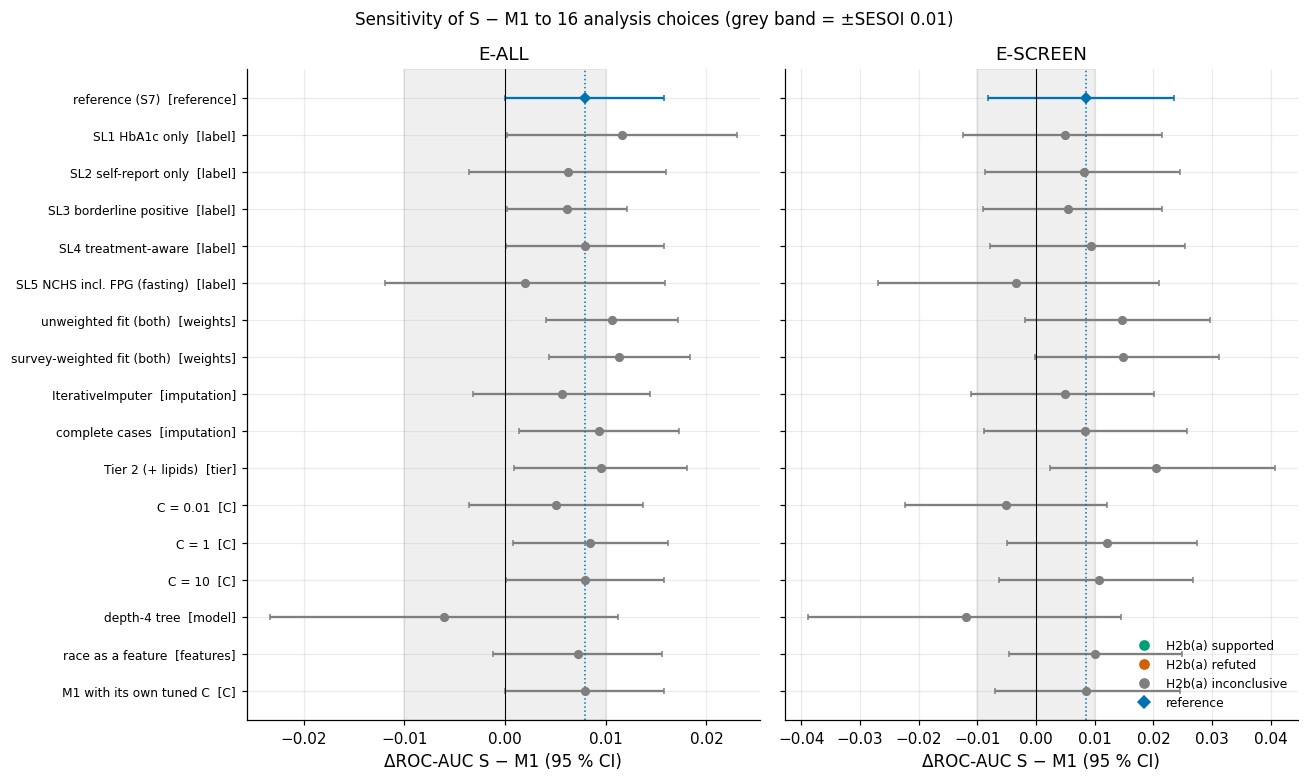

In [202]:
from matplotlib.lines import Line2D
fig, axes = plt.subplots(1, 2, figsize=(12, 7.2), sharey=True)
order = list(dict.fromkeys(sens["spec"]))
groups_ = sens.drop_duplicates("spec").set_index("spec")["group"]
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    s = sens[sens["pop"] == pop].set_index("spec").loc[order]
    for i, (nm, r) in enumerate(s.iterrows()):
        ax.errorbar(r["est"], i, xerr=[[r["est"] - r["lo"]], [r["hi"] - r["est"]]], fmt="D" if i == 0 else "o",
                    color=OI["blue"] if i == 0 else VCOL[r["h2b"]], capsize=2, ms=5)
    ax.axvspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12)
    ax.axvline(0, color="k", lw=0.7)
    ax.axvline(s["est"].iloc[0], color=OI["blue"], ls=":", lw=1)
    ax.set(title=pop, xlabel="ΔROC-AUC S − M1 (95 % CI)")
axes[0].set_yticks(range(len(order)), [f"{o}  [{groups_[o]}]" for o in order], fontsize=8)
axes[0].invert_yaxis()
axes[1].legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=f"H2b(a) {v}") for v, c in VCOL.items()]
               + [Line2D([], [], marker="D", ls="", color=OI["blue"], label="reference")], fontsize=8, loc="lower right")
fig.suptitle("Sensitivity of S − M1 to 16 analysis choices (grey band = ±SESOI 0.01)", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S9_sensitivity_forest", caption="F9-2. ΔROC-AUC (S − M1) with conservative 95 % CIs for the reference and 16 one-at-a-time "
              "variations (labels SL1-SL5, fit weights, imputation, tier, C, depth-4 tree, race as a feature, M1 with its own tuned C); "
              "left E-ALL (scored against the row's label), right E-SCREEN. Colour = H2b(a) verdict under the locked equivalence rule.")
plt.show()
S9["sensitivity"] = dict(n_specs=len(SENS), eall_same_verdict=n_same, eall_rows=len(eall),
                         own_C={a: c for a, (c, _) in OWN_C.items()},
                         leak_gate_C0={r["pop"]: {k: r[k] for k in ("est", "lo", "hi")} for r in gate_c0},
                         leak_gate_own_C={r["pop"]: {k: r[k] for k in ("est", "lo", "hi")} for r in gate_own},
                         table=sens[["spec", "group", "pop", "n_eval", "n_pos", "auc_a", "auc_b", "est", "lo", "hi", "interval",
                                     "mdd", "h2b"]].round(5).to_dict("records"))

**So what.** Reading the forest plot (numbers in the tables above):

* **The E-ALL verdict does not move.** Every one of the 16 variations gives the same H2b(a) verdict as the reference
  (count printed above): the interval of S − M1 never lies inside ±0.01, and never wholly above +0.01. No variation
  produces an interval wholly below 0, i.e. S is never decisively *worse* than M1.
* **Labels and weighting move the estimate most.** Weighting *both* arms the same way (unweighted or survey-weighted)
  enlarges the S advantage to about +0.01 with an interval excluding 0 – part of the reference gap is S's own survey
  weighting costing it unweighted AUC (B6b). The label changes the size of the gap (HbA1c-only largest, NCHS SL5 on the
  fasting half smallest and widest), not its direction on E-ALL.
* **The depth-4 tree is the only model-class change, and it reverses the sign** (with a wide interval): for a tree the
  systematic steps (scaling, splines, one-hot rules) are irrelevant (B5-e), so S − M1 there only measures noise in two
  unstable trees – one more reason the tree is a probe, not the model.
* **The C0 bias is nil here.** Tuned on their own, M0 and M1 pick the same C as S (printed), so "M1 with its own C"
  reproduces the reference and the leak gate M1 − M0 is unchanged: the HR2 rule "same model for every arm" did not
  favour S or manufacture the leakage drop.
* **E-SCREEN**: all intervals are wide (about 25 positives per fold) and every verdict is inconclusive; point estimates
  range around zero, the screening value of the extra preparation is not established either way.

## 9.5 Specification curve
**Why.** The sensitivity table changes one choice at a time; a specification curve (Simonsohn et al. 2020)
crosses the choices that the table showed to matter most, so that interactions between them cannot hide a
different answer. Grid: 5 training labels (L_comb, SL1–SL4) × 3 weighting schemes (as specified: S weighted and M1
unweighted; both unweighted; both weighted) × 4 values of C = **60 specifications**, each with ΔAUC(S − M1) and its
conservative CI on E-ALL and E-SCREEN. This extends, and does not replace, the core table. (FAST re-run mode: C ∈
{0.1, 10} only, 30 specifications; the stored FINAL outputs use the full grid.)

In [203]:
import itertools
LABELS_SC = {"L_comb": "arm", "SL1": "SL1", "SL2": "SL2", "SL3": "SL3", "SL4": "SL4"}
WEIGHTING = ("as specified", "both unweighted", "both weighted")
grid = []
for (lab, lab_spec), wt, c in itertools.product(LABELS_SC.items(), WEIGHTING, C_CURVE):
    cc = None if c == ctx.C0 else c
    sa = Spec("S", label=lab_spec, C=cc, weighted=False if wt == "both unweighted" else None)
    sb = Spec("M1", label=lab_spec, C=cc, weighted=True if wt == "both weighted" else None)
    grid.append(dict(label=lab, weighting=wt, C=c, sa=sa, sb=sb))
assert len(grid) == S9["n_curve"] == (60 if C.IS_FINAL else 30)
secs = prefetch({f"sc{i}{j}": (g[k], ctx.folds) for i, g in enumerate(grid) for j, k in enumerate(("sa", "sb"))})
sc_rows = []
for i, g in enumerate(grid):
    for r in pair(g["sa"], g["sb"], tag=f"curve{i}", label=g["label"]):
        sc_rows.append(dict(spec_id=i, label=g["label"], weighting=g["weighting"], C=g["C"], **{k: r[k] for k in
                            ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b", "sesoi_class")}))
curve = pd.DataFrame(sc_rows)
curve.to_csv(OUT / "specification_curve.csv", index=False)
print(f"{len(grid)} specifications x 2 arms in {secs:.0f} s")
cs = curve.groupby("pop").agg(n=("est", "size"), est_median=("est", "median"), est_min=("est", "min"), est_max=("est", "max"),
                              share_positive=("est", lambda v: (v > 0).mean()),
                              share_ci_above_0=("lo", lambda v: (v > 0).mean()),
                              share_ci_below_0=("hi", lambda v: (v < 0).mean()),
                              share_beyond_sesoi=("lo", lambda v: (v >= C.SESOI["roc_auc"]).mean()))
print(cs.round(3).to_string())
print(curve.groupby(["pop", "h2b"]).size().unstack(fill_value=0).to_string())
print("median E-ALL estimate by factor:")
for fac in ("label", "weighting", "C"):
    print("  ", curve[curve["pop"] == "E-ALL"].groupby(fac)["est"].median().round(4).to_dict())

60 specifications x 2 arms in 78 s
           n  est_median  est_min  est_max  share_positive  share_ci_above_0  share_ci_below_0  share_beyond_sesoi
pop                                                                                                               
E-ALL     60       0.010    0.005    0.018            1.00              0.85               0.0                 0.0
E-SCREEN  60       0.012   -0.011    0.021            0.75              0.30               0.0                 0.0
h2b       inconclusive
pop                   
E-ALL               60
E-SCREEN            60
median E-ALL estimate by factor:
   {'L_comb': 0.0098, 'SL1': 0.0146, 'SL2': 0.01, 'SL3': 0.0079, 'SL4': 0.0104}
   {'as specified': 0.0074, 'both unweighted': 0.0105, 'both weighted': 0.0113}
   {0.01: 0.009, 0.1: 0.0103, 1.0: 0.0109, 10.0: 0.0108}


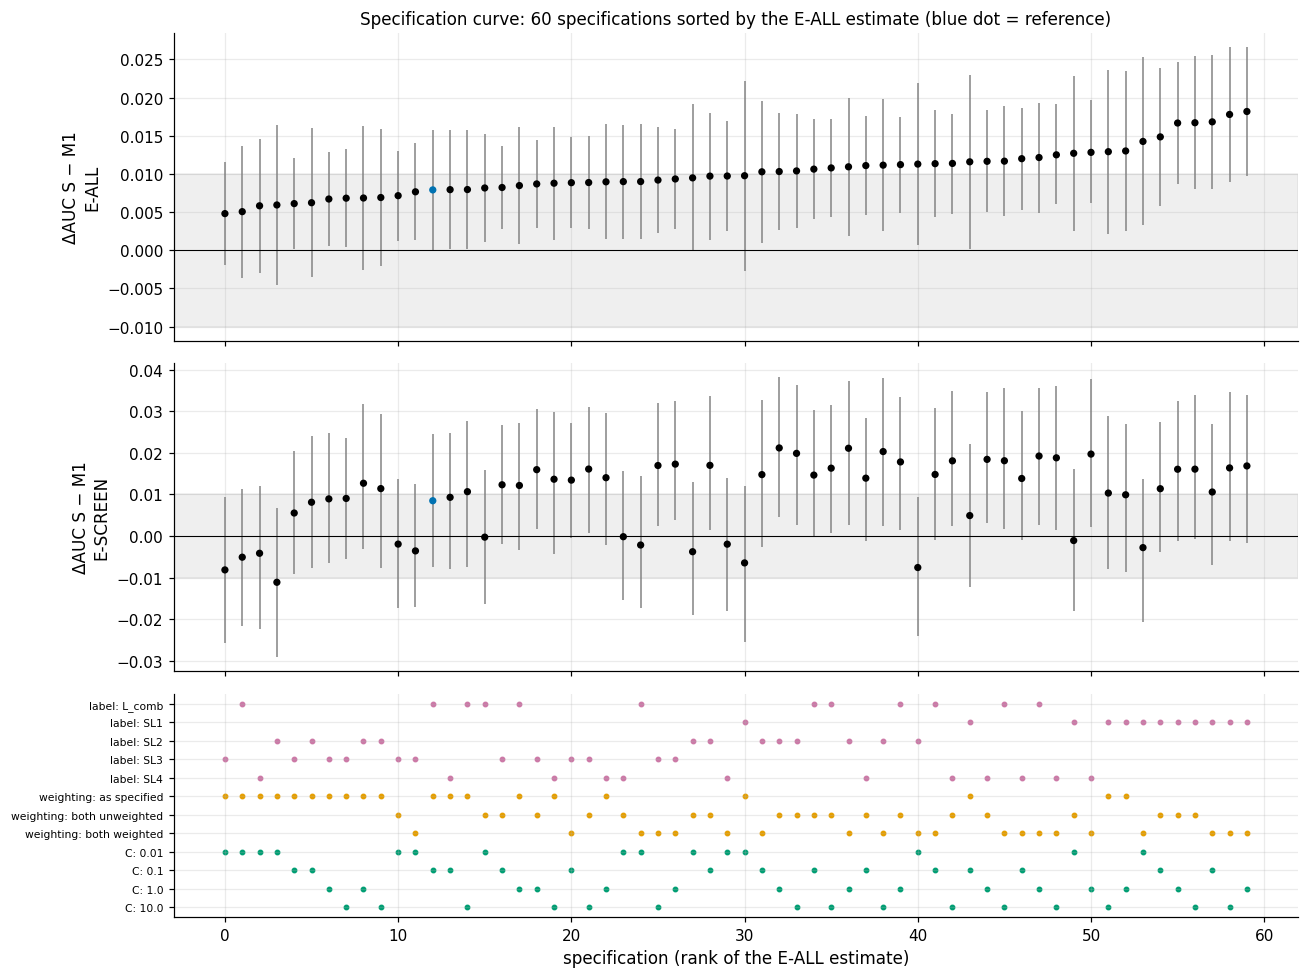

In [204]:
e_all = curve[curve["pop"] == "E-ALL"].sort_values("est").reset_index(drop=True)
order_ids = e_all["spec_id"].tolist()
e_scr = curve[curve["pop"] == "E-SCREEN"].set_index("spec_id").loc[order_ids].reset_index()
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, gridspec_kw={"height_ratios": [2.2, 2.2, 1.6]})
for ax, d, pop in ((axes[0], e_all, "E-ALL"), (axes[1], e_scr, "E-SCREEN")):
    x = np.arange(len(d))
    ax.vlines(x, d["lo"], d["hi"], color=[VCOL[v] for v in d["h2b"]], lw=1.2, alpha=0.8)
    ax.scatter(x, d["est"], s=14, color=[OI["blue"] if (l == "L_comb" and w == "as specified" and c == ctx.C0) else "k"
                                          for l, w, c in zip(d["label"], d["weighting"], d["C"])], zorder=3)
    ax.axhspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12)
    ax.axhline(0, color="k", lw=0.7)
    ax.set_ylabel(f"ΔAUC S − M1\n{pop}")
axes[0].set_title(f"Specification curve: {len(grid)} specifications sorted by the E-ALL estimate (blue dot = reference)", fontsize=11)
ax = axes[2]
rows_ind = [("label", l) for l in LABELS_SC] + [("weighting", w) for w in WEIGHTING] + [("C", c) for c in C_CURVE]
for j, (fac, val) in enumerate(rows_ind):
    hit = (e_all[fac] == val).to_numpy()
    ax.scatter(np.flatnonzero(hit), np.full(hit.sum(), j), s=8, color=OI["purple"] if fac == "label" else OI["orange"] if fac == "weighting" else OI["green"])
ax.set_yticks(range(len(rows_ind)), [f"{fac}: {val}" for fac, val in rows_ind], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("specification (rank of the E-ALL estimate)")
fig.tight_layout()
plots.savefig(fig, "S9_specification_curve", caption=f"Specification curve (extension). {len(grid)} specifications = 5 training labels x 3 weighting "
              f"schemes x {len(C_CURVE)} values of C. Top: ΔROC-AUC (S − M1) on E-ALL with conservative 95 % CI, sorted; middle: E-SCREEN in the same "
              "order; bottom: which choices define each specification. Line colour = H2b(a) verdict (grey inconclusive, green "
              "equivalent, red refuted); grey band = ±SESOI 0.01.")
plt.show()
S9["specification_curve"] = dict(n=len(grid), summary=cs.round(5).to_dict("index"),
                                 verdicts=curve.groupby(["pop", "h2b"]).size().unstack(fill_value=0).to_dict("index"))

**So what.** All 60 combinations put S *ahead* of M1 on E-ALL, and in most of them the interval excludes 0
(shares printed) – the direction is robust. But no combination clears the SESOI with confidence, and none puts the
interval inside ±0.01, so every one of the 60 verdicts is the reference verdict, *inconclusive*. The factor medians
show what drives the size of the gap: the reference ("as specified": S survey-weighted, M1 not) sits at the low end,
because S's own survey weighting costs it some unweighted AUC (B6b); weighting both arms alike moves the median to
about the SESOI itself, and the HbA1c-only label (SL1) gives the largest gaps. On E-SCREEN the curve scatters around
small positive values with wide intervals. The H2b(a) verdict is not the product of one forking path; it is what the
whole garden of forking paths says – a small, consistent advantage of S whose size cannot be pinned against 0.01.

## 9.6 Survey-cluster cross-validation
**Why.** NHANES samples counties (PSUs) within strata; people in the same PSU share geography, examination
logistics and season. Ordinary folds put neighbours on both sides of a split, which can flatter the AUC of features
that encode place. `StratifiedGroupKFold` with groups = stratum × PSU keeps each survey cluster inside one fold
(repeated with derived seeds), so the test fold always contains clusters the model has never seen.

In [205]:
groups = (ctx.cl[C.STRATA].astype(int) * 10 + ctx.cl[C.PSU].astype(int)).to_numpy()
GFOLDS = RB.group_folds(ctx.strat, groups, RB.seed("group-cv"))
gsz = pd.DataFrame([dict(fold=i, n_test=len(te), n_clusters=len(np.unique(groups[te])), pos=int(ctx.y[te].sum()),
                         pos_escreen=int(ctx.y_esc[te][ctx.esc[te]].sum())) for i, (_, te) in enumerate(GFOLDS)])
assert all(len(set(groups[te]) & set(groups[tr])) == 0 for tr, te in GFOLDS), "a cluster appears on both sides of a split"
print(f"{len(np.unique(groups))} strata x PSU clusters in the training part; grouped folds: n_test {gsz['n_test'].min()}-{gsz['n_test'].max()}, "
      f"clusters per test fold {gsz['n_clusters'].min()}-{gsz['n_clusters'].max()}, E-SCREEN positives {gsz['pos_escreen'].min()}-{gsz['pos_escreen'].max()}")
secs = prefetch({f"g{a}": (Spec(a), GFOLDS) for a in RB.ADMISSIBLE_ARMS})
gcv = pair(Spec("S"), Spec("M1"), GFOLDS, tag="group-cv")
gcv_tab = pd.DataFrame([dict(folds="stored stratified", **{k: r[k] for k in ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b")}) for r in ref]
                       + [dict(folds="strata x PSU grouped", **{k: r[k] for k in ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b")}) for r in gcv])
gcv_tab = gcv_tab.rename(columns={"auc_a": "auc_S", "auc_b": "auc_M1"})
gcv_tab.to_csv(OUT / "grouped_cv.csv", index=False)
print(gcv_tab.round(4).to_string(index=False))
dS = {p: gcv_tab.query("folds == 'strata x PSU grouped' and pop == @p")["auc_S"].iloc[0] - gcv_tab.query("folds == 'stored stratified' and pop == @p")["auc_S"].iloc[0]
      for p in ("E-ALL", "E-SCREEN")}
print(f"AUC of S, grouped minus stratified folds: E-ALL {dS['E-ALL']:+.4f}, E-SCREEN {dS['E-SCREEN']:+.4f}")
S9["grouped_cv"] = dict(n_clusters=int(len(np.unique(groups))), table=gcv_tab.round(5).to_dict("records"),
                        auc_S_grouped_minus_stratified=dS)

30 strata x PSU clusters in the training part; grouped folds: n_test 805-1058, clusters per test fold 5-7, E-SCREEN positives 20-31


               folds      pop  auc_S  auc_M1    est      lo     hi    interval          h2b
   stored stratified    E-ALL 0.8359  0.8285 0.0079  0.0000 0.0158 corrected_t inconclusive
   stored stratified E-SCREEN 0.7807  0.7723 0.0085 -0.0081 0.0236   bootstrap inconclusive
strata x PSU grouped    E-ALL 0.8313  0.8257 0.0055 -0.0001 0.0118   bootstrap inconclusive
strata x PSU grouped E-SCREEN 0.7797  0.7727 0.0070 -0.0086 0.0221   bootstrap inconclusive
AUC of S, grouped minus stratified folds: E-ALL -0.0046, E-SCREEN -0.0010


**So what.** Holding whole survey clusters out changes the AUC of S by only a few thousandths (printed): the
admissible features do not exploit place-specific structure, so the cross-validated numbers are not inflated by
cluster sharing. The S − M1 verdict is the same under grouped folds. Grouped folds are less balanced (fold sizes and
E-SCREEN positives vary more, printed above), which is why they are a check rather than the primary design.

## 9.7 Missing HbA1c: inverse-probability weights and delta adjustment
**Why.** The cohort keeps only examined adults *with* an HbA1c value. §3 showed the missingness is not MCAR
(NH Black OR about 1.85; register DR-S3-04), and §5 bounded the prevalence with Manski bounds (DR-S5-08); both
deferred two sensitivity analyses to this stage:

1. **MAR given covariates – inverse-probability weighting (IPW).** The S3 missingness model is refitted on examined,
   non-pregnant adults (the population the cohort is drawn from); each cohort member gets a stabilised weight
   P(observed) / P(observed | x). Used (a) for the prevalence and (b) for ΔAUC(S − M1), weighting evaluation only or
   fit and evaluation.
2. **MNAR – delta adjustment (pattern mixture).** People without HbA1c who report diabetes are positive anyway. For
   the others, the MAR probability of HbA1c ≥ 6.5 (a logit on the S3 covariates fitted on the E-SCREEN rows of the
   training part) is shifted by δ on the log-odds scale: δ = 0 is MAR, δ = log 3 means three-fold odds among the
   unmeasured. Manski-type bounds (all undetermined negative / all positive) bracket every δ.

In [206]:
ex = RB.examined_population()
miss = ex["a1c_observed"].eq(0)
obs_fit = RB.observation_model(ex)
ci_ = obs_fit.conf_int()
or_obs = pd.DataFrame({"OR_missing": np.exp(-obs_fit.params), "ci_low": np.exp(-ci_[1]), "ci_high": np.exp(-ci_[0])}).drop("const")
s3_or = pd.read_csv(C.RESULTS_DIR / "S3" / "missingness_or.csv", index_col=0)
or_cmp = or_obs.join(s3_or[["OR"]].rename(columns={"OR": "OR_missing_S3"}))
print(f"examined non-pregnant adults {len(ex):,}; without HbA1c {int(miss.sum())} ({miss.mean():.1%}); cohort {int((~miss).sum()):,}")
print(or_cmp.round(3).to_string())
assert int((~miss).sum()) == io.COHORT_N
assert abs(or_cmp.loc["NH Black", "OR_missing"] - or_cmp.loc["NH Black", "OR_missing_S3"]) < 0.1   # same model, 37 fewer rows
p_obs = pd.Series(obs_fit.predict(), index=ex["SEQN"].to_numpy())
ipw_all = (~miss).mean() / p_obs                          # stabilised weight
coh = ctx.clean.copy()
coh["ipw"] = ipw_all.reindex(coh["SEQN"]).to_numpy()
coh["w_mec_ipw"] = coh[C.WEIGHT_MEC] * coh["ipw"]
ctx.ipw = coh["ipw"].to_numpy()[ctx.train_idx]
print(f"stabilised IPW in the cohort: min {coh['ipw'].min():.3f}, median {coh['ipw'].median():.3f}, max {coh['ipw'].max():.3f}; "
      f"Kish deff {sv.kish_deff(coh['ipw']):.3f}")

prev_rows = []
for nm, wcol in (("WTPH2YR (blood non-response adjusted)", C.WEIGHT_PHLEB), ("WTMEC2YR (complete case)", C.WEIGHT_MEC),
                 ("WTMEC2YR x IPW", "w_mec_ipw")):
    wp = sv.weighted_prop(coh, "L_comb", weight=wcol)
    prev_rows.append(dict(weighting=nm, est=wp["est"], ci_low=wp["ci_low"], ci_high=wp["ci_high"], df=wp["df"]))
prev_tab = pd.DataFrame(prev_rows)
print(prev_tab.round(4).to_string(index=False))
assert abs(prev_tab.loc[0, "est"] - 0.140) < 0.0015, "WTPH2YR prevalence must reproduce 14.0 % (process doc §8)"

ipw_cmp = pair(Spec("S"), Spec("M1"), tag="ipw-eval", w=ctx.ipw) + pair(Spec("S", ipw=True), Spec("M1", ipw=True), tag="ipw-fit", w=ctx.ipw)
ipw_tab = pd.DataFrame([dict(variant=v, **{k: r[k] for k in ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b")})
                        for v, r in zip(["IPW evaluation"] * 2 + ["IPW fit + evaluation"] * 2, ipw_cmp)])
print(ipw_tab.round(4).to_string(index=False))

examined non-pregnant adults 6,023; without HbA1c 293 (4.9%); cohort 5,730
                        OR_missing  ci_low  ci_high  OR_missing_S3
age (per 10 y)               0.892   0.825    0.965          0.893
female                       0.940   0.738    1.196          0.948
NH Black                     1.780   1.293    2.451          1.853
NH Asian                     1.374   0.840    2.249          1.383
Mexican American             0.723   0.414    1.264          0.772
Other Hispanic               0.845   0.543    1.315          0.842
Other/Multi                  1.245   0.785    1.974          1.244
PIR (per unit)               0.821   0.754    0.894          0.820
PIR missing                  1.564   1.142    2.141          1.572
BMI (per unit)               0.997   0.980    1.014          0.997
BMI missing                  2.673   1.448    4.933          2.646
uninsured                    0.717   0.449    1.146          0.699
no usual place of care       1.150   0.789    1.677   

             variant      pop  auc_a  auc_b    est      lo     hi    interval          h2b
      IPW evaluation    E-ALL 0.8359 0.8284 0.0079  0.0000 0.0158 corrected_t inconclusive
      IPW evaluation E-SCREEN 0.7801 0.7717 0.0085 -0.0080 0.0252   bootstrap inconclusive
IPW fit + evaluation    E-ALL 0.8356 0.8286 0.0072 -0.0009 0.0154 corrected_t inconclusive
IPW fit + evaluation E-SCREEN 0.7798 0.7706 0.0091 -0.0074 0.0249   bootstrap inconclusive


In [207]:
import statsmodels.api as sm
Xd_ex = RB.missingness_design(ex).drop(columns=["self-reported diabetes"])
seq_pos = pd.Series(np.arange(len(ex)), index=ex["SEQN"].to_numpy())
tr_rows = seq_pos.reindex(ctx.cl["SEQN"]).to_numpy()
fit_rows = tr_rows[ctx.esc]                                     # training-part E-SCREEN rows (hold-out untouched)
mar_fit = sm.Logit(ctx.y_esc[ctx.esc], sm.add_constant(Xd_ex.iloc[fit_rows])).fit(disp=0)
miss_idx = np.flatnonzero(miss.to_numpy())
miss_self = ex["DIQ010"].eq(1).to_numpy()[miss_idx]
p_mar = mar_fit.predict(sm.add_constant(Xd_ex, has_constant="add").iloc[miss_idx]).to_numpy()
from sklearn.metrics import roc_auc_score
print(f"MAR model for HbA1c >= 6.5 among the undiagnosed: fitted on {len(fit_rows):,} training-part E-SCREEN rows "
      f"({int(ctx.y_esc[ctx.esc].sum())} positives), in-sample AUC {roc_auc_score(ctx.y_esc[ctx.esc], mar_fit.predict()):.3f}")
print(f"missing rows: {len(miss_idx)}; self-reported diabetes {int(miss_self.sum())}; undetermined {int((~miss_self).sum())}, "
      f"mean MAR probability {p_mar[~miss_self].mean():.3f}")

DELTAS = np.array([-1.0, -0.5, 0.0, 0.5, 1.0, np.log(3), 1.5, 2.0, 3.0])
w_obs = coh[C.WEIGHT_MEC].to_numpy()
w_m = ex[C.WEIGHT_MEC].to_numpy()[miss_idx]
dprev = RB.delta_prevalence(coh["L_comb"].to_numpy(), w_obs, miss_self, p_mar, w_m, DELTAS)
print(dprev.round(4).to_string(index=False))
print(f"complete case (MEC) {dprev.attrs['complete_case']:.4f}; Manski bounds [{dprev.attrs['manski_low']:.4f}, {dprev.attrs['manski_high']:.4f}] "
      f"(S5: [{pd.read_csv(C.RESULTS_DIR / 'S5' / 'manski_bounds.csv').iloc[0]['lower']:.4f}, "
      f"{pd.read_csv(C.RESULTS_DIR / 'S5' / 'manski_bounds.csv').iloc[0]['upper']:.4f}])")
from scipy.optimize import brentq
f_tip = lambda d: RB.delta_prevalence(coh["L_comb"].to_numpy(), w_obs, miss_self, p_mar, w_m, [d])["prevalence"].iloc[0] - 0.158
tip = brentq(f_tip, 0, 20) if f_tip(20) > 0 else np.nan
print(f"delta needed to reach the DB516 prevalence of 15.8 %: {tip:.2f} (odds ratio {np.exp(tip):.1f})" if np.isfinite(tip)
      else "15.8 % is not reachable even with every undetermined person positive")

# delta-adjusted S - M1: full-training-part models score the people without HbA1c
raw_ex = io.load_merged(fix=False, sentinels="none")
raw_miss = raw_ex.set_index("SEQN").loc[ex["SEQN"].to_numpy()[miss_idx]].reset_index()
pa_m = RB.fit_full(ctx, Spec("S")).predict_proba(P.raw_feature_frame(raw_miss, 1))[:, 1]
pb_m = RB.fit_full(ctx, Spec("M1")).predict_proba(P.raw_feature_frame(raw_miss, 1))[:, 1]
ref_oof = RB.run_many(ctx, {"S": Spec("S"), "M1": Spec("M1")}, n_jobs=N_JOBS, cache=RUNS)
pa_o, pb_o = ek.mean_oof(ref_oof["S"], ctx.n), ek.mean_oof(ref_oof["M1"], ctx.n)
N_DRAW = max(50, C.N_BOOT // 5)
dauc = []
for pop, om, mm, yo in (("E-ALL", None, None, ctx.y), ("E-SCREEN", ctx.esc, ~miss_self, ctx.y_esc)):
    d = RB.delta_auc(yo, pa_o, pb_o, miss_self, p_mar, pa_m, pb_m, DELTAS, n_draw=N_DRAW, seed_=RB.seed("delta-auc", pop),
                     obs_mask=om, miss_mask=mm)
    d.insert(0, "pop", pop)
    dauc.append(d)
dauc = pd.concat(dauc, ignore_index=True)
dprev.to_csv(OUT / "mnar_delta_prevalence.csv", index=False)
dauc.to_csv(OUT / "mnar_delta_auc.csv", index=False)
pd.concat([prev_tab.assign(kind="prevalence"), ipw_tab.assign(kind="dAUC S-M1")]).to_csv(OUT / "ipw.csv", index=False)
print(dauc.round(4).to_string(index=False))
print(f"E-ALL S - M1 across all delta and Manski scenarios: {dauc.loc[dauc['pop'] == 'E-ALL', 'diff'].min():+.4f} to "
      f"{dauc.loc[dauc['pop'] == 'E-ALL', 'diff'].max():+.4f} (complete-case pooled {S9['reference']['E-ALL']['est']:+.4f})")

MAR model for HbA1c >= 6.5 among the undiagnosed: fitted on 3,934 training-part E-SCREEN rows (127 positives), in-sample AUC 0.802
missing rows: 293; self-reported diabetes 49; undetermined 244, mean MAR probability 0.036
  delta  odds_ratio  prevalence
-1.0000      0.3679      0.1399
-0.5000      0.6065      0.1402
 0.0000      1.0000      0.1406
 0.5000      1.6487      0.1413
 1.0000      2.7183      0.1422
 1.0986      3.0000      0.1425
 1.5000      4.4817      0.1436
 2.0000      7.3891      0.1454
 3.0000     20.0855      0.1506
complete case (MEC) 0.1393; Manski bounds [0.1395, 0.1811] (S5: [0.1395, 0.1811])
delta needed to reach the DB516 prevalence of 15.8 %: 4.07 (odds ratio 58.7)


     pop   delta            scenario  auc_a  auc_b    diff  diff_lo  diff_hi
   E-ALL -1.0000               delta 0.8361 0.8286  0.0075   0.0071   0.0079
   E-ALL -0.5000               delta 0.8359 0.8284  0.0075   0.0069   0.0080
   E-ALL  0.0000               delta 0.8358 0.8282  0.0076   0.0068   0.0083
   E-ALL  0.5000               delta 0.8354 0.8278  0.0076   0.0068   0.0085
   E-ALL  1.0000               delta 0.8346 0.8269  0.0077   0.0068   0.0087
   E-ALL  1.0986               delta 0.8345 0.8268  0.0078   0.0066   0.0089
   E-ALL  1.5000               delta 0.8335 0.8257  0.0078   0.0067   0.0090
   E-ALL  2.0000               delta 0.8321 0.8243  0.0078   0.0064   0.0091
   E-ALL  3.0000               delta 0.8251 0.8174  0.0077   0.0059   0.0092
   E-ALL     NaN manski_all_negative 0.8362 0.8287  0.0074      NaN      NaN
   E-ALL     NaN manski_all_positive 0.7587 0.7549  0.0038      NaN      NaN
E-SCREEN -1.0000               delta 0.7788 0.7703  0.0085   0.0060   0.0113

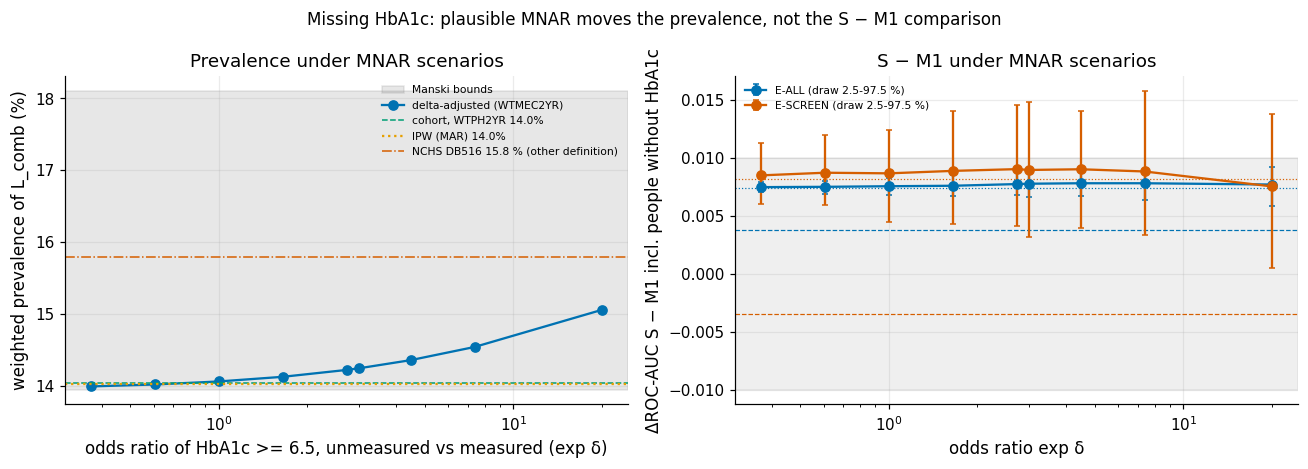

In [208]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
ax.axhspan(dprev.attrs["manski_low"] * 100, dprev.attrs["manski_high"] * 100, color=OI["grey"], alpha=0.18, label="Manski bounds")
ax.plot(dprev["odds_ratio"], dprev["prevalence"] * 100, "o-", color=OI["blue"], label="delta-adjusted (WTMEC2YR)")
ax.axhline(prev_tab.loc[0, "est"] * 100, color=OI["green"], ls="--", lw=1, label=f"cohort, WTPH2YR {prev_tab.loc[0, 'est']:.1%}")
ax.axhline(prev_tab.loc[2, "est"] * 100, color=OI["orange"], ls=":", lw=1.5, label=f"IPW (MAR) {prev_tab.loc[2, 'est']:.1%}")
ax.axhline(15.8, color=OI["vermillion"], ls="-.", lw=1, label="NCHS DB516 15.8 % (other definition)")
ax.set_xscale("log")
ax.set(xlabel="odds ratio of HbA1c >= 6.5, unmeasured vs measured (exp δ)", ylabel="weighted prevalence of L_comb (%)",
       title="Prevalence under MNAR scenarios")
ax.legend(fontsize=7)
ax = axes[1]
for pop, col in (("E-ALL", OI["blue"]), ("E-SCREEN", OI["vermillion"])):
    d = dauc[(dauc["pop"] == pop) & (dauc["scenario"] == "delta")]
    ax.errorbar(np.exp(d["delta"]), d["diff"], yerr=[d["diff"] - d["diff_lo"], d["diff_hi"] - d["diff"]],
                fmt="o-", color=col, capsize=2, label=f"{pop} (draw 2.5-97.5 %)")
    for _, r in dauc[(dauc["pop"] == pop) & (dauc["scenario"] != "delta")].iterrows():
        ax.axhline(r["diff"], color=col, lw=0.8, ls=":" if "negative" in r["scenario"] else "--")
ax.axhspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12)
ax.set_xscale("log")
ax.set(xlabel="odds ratio exp δ", ylabel="ΔROC-AUC S − M1 incl. people without HbA1c", title="S − M1 under MNAR scenarios")
ax.legend(fontsize=7)
fig.suptitle("Missing HbA1c: plausible MNAR moves the prevalence, not the S − M1 comparison", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S9_mnar_delta", caption="Left: weighted prevalence of L_comb in examined non-pregnant adults when the people without HbA1c "
              "(who did not report diabetes) have exp(δ) times the MAR odds of HbA1c >= 6.5; grey = Manski bounds; lines = WTPH2YR cohort "
              "estimate, IPW estimate and the DB516 figure (different definition, see section 8). Right: ΔROC-AUC (S − M1) when those "
              "people are added to E-ALL / E-SCREEN with labels drawn under δ (dotted / dashed = Manski all-negative / all-positive).")
plt.show()
S9["mnar"] = dict(n_examined=int(len(ex)), n_missing=int(miss.sum()), n_missing_self=int(miss_self.sum()),
                  ipw_range=[float(coh["ipw"].min()), float(coh["ipw"].max())], prevalence=prev_tab.round(5).to_dict("records"),
                  ipw_dauc=ipw_tab.round(5).to_dict("records"), delta_prevalence=dprev.round(5).to_dict("records"),
                  manski=[dprev.attrs["manski_low"], dprev.attrs["manski_high"]], tipping_delta_db516=tip,
                  delta_auc=dauc.round(5).to_dict("records"))

**So what.** Three results close the deferred register items DR-S3-04 and DR-S5-08:

* **MAR (IPW).** Re-weighting the complete cases to the examined population changes the weighted prevalence by about a
  tenth of a percentage point (table above) – the same size as the WTPH2YR non-response adjustment that S5 found, so the
  official blood weight already absorbs the covariate-driven part of the missingness. IPW moves ΔAUC(S − M1) by less than
  0.001 and leaves the verdict unchanged.
* **MNAR (delta).** Even if people without HbA1c had several times the odds of an elevated value (δ up to log 20), the
  prevalence stays well inside the Manski band, and about 4–5 % missingness is too little to lift it to the DB516 value
  unless almost every unmeasured person were diabetic (tipping point printed). The 14.0 % vs 15.8 % gap is therefore a
  *definition* gap (section 8), not a missing-data artefact.
* **Model comparison.** Adding the people without HbA1c to the evaluation set with labels drawn under any δ from
  −1 to 3 shifts ΔAUC(S − M1) by about 0.001 or less on E-ALL and E-SCREEN. Only the Manski "all positive" extreme – every
  one of the undetermined people diabetic, a prevalence far beyond any plausible MNAR mechanism – moves it noticeably
  (to about +0.004 on E-ALL and about −0.004 on E-SCREEN, printed), still inside ±0.01. MNAR remains untestable from
  these data; what is shown is that no plausible MNAR mechanism of this size changes the conclusions.

## 9.8 External validity
### 9.8.1 V1: NCHS Data Brief 516
**Why.** An external anchor tests the whole data path (loading, XPT repair, sentinels, weights, jackknife) against a
number we did not produce. S4 reproduced the official diabetes prevalence of NCHS Data Brief 516 (Aug 2021–Aug 2023,
fasting subsample, WTSAF2YR) for 27 published estimates. That replication is **cited, not re-run** here.

27 published estimates; max |ours - NCHS| = 0.044 pp; our KG interval matches the published one (to 0.1 pp) in 24/27; intervals overlap in 27/27
headline: total 15.79 % (NCHS 15.8), diagnosed 11.30 % (11.3), undiagnosed 4.49 % (4.5); n = 2,938


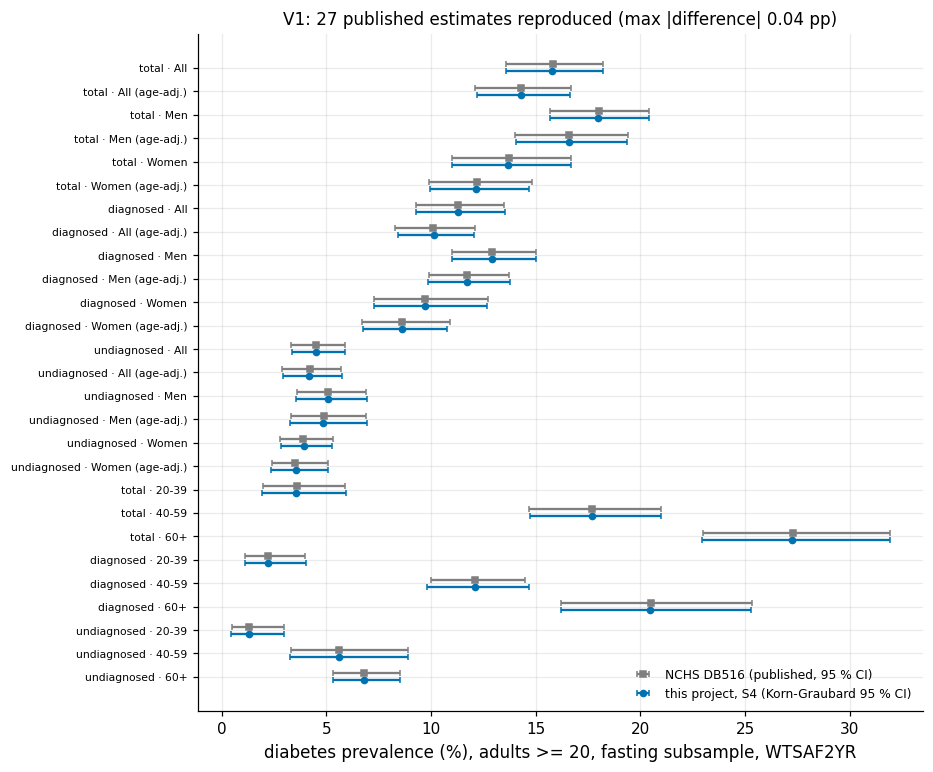

In [209]:
db = pd.read_csv(C.RESULTS_DIR / "S4" / "db516_replication.csv")
S4m = R.load_section("S4")["db516"]
db["label"] = db["measure"] + " · " + db["group"] + np.where(db["kind"] == "age-adj", " (age-adj.)", "")
print(f"{len(db)} published estimates; max |ours - NCHS| = {db['diff_pp'].abs().max():.3f} pp; "
      f"our KG interval matches the published one (to 0.1 pp) in {int(db['kg_matches_nchs_ci'].sum())}/{len(db)}; "
      f"intervals overlap in {int(db['ci_overlap'].sum())}/{len(db)}")
print(f"headline: total {S4m['total']:.2f} % (NCHS 15.8), diagnosed {S4m['diagnosed']:.2f} % (11.3), undiagnosed {S4m['undiagnosed']:.2f} % (4.5); n = {S4m['n']:,}")
assert abs(S4m["total"] - 15.8) < 0.05 and abs(S4m["diagnosed"] - 11.3) < 0.05 and abs(S4m["undiagnosed"] - 4.5) < 0.05

fig, ax = plt.subplots(figsize=(8.5, 8))
yy_ = np.arange(len(db))
ax.errorbar(db["nchs"], yy_ - 0.15, xerr=[db["nchs"] - db["nchs_low"], db["nchs_high"] - db["nchs"]], fmt="s", color=OI["grey"],
            capsize=2, ms=4, label="NCHS DB516 (published, 95 % CI)")
ax.errorbar(db["est"], yy_ + 0.15, xerr=[db["est"] - db["kg_low"], db["kg_high"] - db["est"]], fmt="o", color=OI["blue"],
            capsize=2, ms=4, label="this project, S4 (Korn-Graubard 95 % CI)")
ax.set_yticks(yy_, db["label"], fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("diabetes prevalence (%), adults >= 20, fasting subsample, WTSAF2YR")
ax.legend(fontsize=8, loc="lower right")
ax.set_title(f"V1: 27 published estimates reproduced (max |difference| {db['diff_pp'].abs().max():.2f} pp)", fontsize=11)
plots.savefig(fig, "S9_db516_forest", caption="F9-4. NCHS Data Brief 516 prevalence estimates (grey, published) and the S4 replication (blue, delete-one-PSU "
              "jackknife with Korn-Graubard intervals) for total, diagnosed and undiagnosed diabetes by sex and age, crude and age-adjusted. "
              "Source: results/S4/db516_replication.csv (not re-run in S9).")
plt.show()

**So what.** Every published estimate is reproduced to within 0.05 percentage points and every pair of intervals
overlaps (counts printed). The data path from raw XPT files to survey-weighted estimates is therefore externally
validated; differences elsewhere cannot be blamed on loading or weighting errors.

### 9.8.2 V2: why our prevalence is 14.0 % and not 15.8 %
**Why.** The training target `L_comb` has a weighted prevalence of 14.0 % (WTPH2YR), below DB516's 15.8 %. Before
S9 the pre-registered explanation was: our label has no fasting-glucose criterion, and our sample is the HbA1c
sample, not the fasting subsample. That explanation is now **decomposed** with jackknife intervals on the same
replicate structure: (A) `L_comb` in the cohort with WTPH2YR → (B) `L_comb` in the fasting subsample with WTSAF2YR
(sample effect) → (C) the DB516 definition, `L_comb` or fasting glucose ≥ 126 mg/dL (definition effect).

In [210]:
cohort_all = ctx.clean.copy()
fm = L.fasting_mask(cohort_all).to_numpy()
sl_all = L.sensitivity_labels(cohort_all)
yA = cohort_all["L_comb"].to_numpy(float)
yC = sl_all["SL5"].fillna(0).to_numpy(float)
Wph, fac = sv.replicate_weights(cohort_all, C.WEIGHT_PHLEB)
Wsa, fac2 = sv.replicate_weights(cohort_all, cohort_all[C.WEIGHT_FASTING].fillna(0).to_numpy() * fm)
assert np.allclose(fac, fac2)

def _prev(y_, w_, m_=None):
    m_ = np.ones(len(y_), bool) if m_ is None else m_
    return (w_[m_] * y_[m_]).sum() / w_[m_].sum()

def _abc(wph, wsa):
    a = _prev(yA, wph)
    b = _prev(yA, wsa, fm)
    c = _prev(yC, wsa, fm)
    return np.array([a, b, c, b - a, c - b, c - a])

w_ph = np.nan_to_num(cohort_all[C.WEIGHT_PHLEB].to_numpy(float))
w_sa = np.nan_to_num(cohort_all[C.WEIGHT_FASTING].to_numpy(float)) * fm
est_ = _abc(w_ph, w_sa)
reps_ = np.array([_abc(Wph[:, r], Wsa[:, r]) for r in range(Wph.shape[1])])
se_ = np.sqrt(np.tensordot(fac, (reps_ - est_) ** 2, axes=(0, 0)))
tcrit = stats.t.ppf(0.975, sv.design_df(cohort_all))
v2 = pd.DataFrame({"quantity": ["A L_comb, cohort, WTPH2YR", "B L_comb, fasting subsample, WTSAF2YR",
                                "C DB516 definition (+ FPG >= 126), fasting subsample", "sample effect B - A",
                                "definition effect C - B", "total C - A"],
                   "est_pct": est_ * 100, "ci_low": (est_ - tcrit * se_) * 100, "ci_high": (est_ + tcrit * se_) * 100})
fpg_only = int(((sl_all["SL5"] == 1) & (cohort_all["L_comb"] == 0)).sum())
v2.to_csv(OUT / "v2_prevalence_gap.csv", index=False)
print(v2.round(2).to_string(index=False))
print(f"fasting subsample n = {int(fm.sum()):,}; people positive only through fasting glucose: {fpg_only}")
assert abs(est_[0] - 0.140) < 0.0015 and abs(est_[2] * 100 - S4m["total"]) < 0.01

                                            quantity  est_pct  ci_low  ci_high
                           A L_comb, cohort, WTPH2YR    14.04   12.44    15.63
               B L_comb, fasting subsample, WTSAF2YR    13.86   11.65    16.08
C DB516 definition (+ FPG >= 126), fasting subsample    15.79   13.53    18.04
                                 sample effect B - A    -0.17   -1.66     1.32
                             definition effect C - B     1.92    1.37     2.48
                                         total C - A     1.75    0.24     3.26
fasting subsample n = 2,938; people positive only through fasting glucose: 70


**So what.** The gap is almost entirely a **definition** effect: in the fasting subsample our `L_comb` gives about
the same prevalence as in the full cohort (the sample effect is small, interval printed), while adding the
fasting-glucose criterion lifts it to the DB516 value (the people positive *only* through fasting glucose are counted
above). The 14.0 % is therefore not a failed replication but a narrower label: `L_comb` misses people whose only
abnormal test is fasting glucose. This is exactly why SL5 is one of the sensitivity labels (section 4), and section 7
showed that missing HbA1c cannot explain the gap either.

### 9.8.3 ADA-lite vs Bang et al. 2009 (qualitative)
**Why.** The reduced ADA risk score is the clinical comparator on E-SCREEN. Its published performance is a natural
yardstick, but only a qualitative one: our version lacks two of the seven items (family history, gestational
diabetes), our outcome is HbA1c ≥ 6.5 % among people not told they have diabetes, and the population is 2021–23.
What the Bang et al. (2009) abstract reports (verified): cut-off ≥ 5 points, sensitivity 79 %, specificity 67 %. AUC
values of 0.79 / 0.83 that circulate for development / validation data are **not verified** against the full text
and are not used.

In [211]:
ada_tr = P.ada_lite_items(ctx.cl)
sc_esc = ada_tr["ada_score"].to_numpy()[ctx.esc]
ye = ctx.y_esc[ctx.esc]
ada_rows = []
for cut in (3, 4, 5):
    call = sc_esc >= cut
    ada_rows.append(dict(cutoff=f">= {cut}", sensitivity=call[ye == 1].mean(), specificity=(~call[ye == 0]).mean(),
                         share_flagged=call.mean()))
ada_tab = pd.DataFrame(ada_rows)
bl = S7m["baselines"]["BL-ADAlite (points)"]
print(f"ADA-lite (5 of 7 items, max 9 of 11 points) on training-part E-SCREEN: AUC {bl['escr_auc']:.3f} "
      f"[{bl['lo']:.3f}, {bl['hi']:.3f}], recall at specificity 0.80 {bl['escr_recall_spec80']:.3f} (S7)")
print(ada_tab.round(3).to_string(index=False))
print("Bang et al. 2009 (abstract): cut-off >= 5 of 11 points, sensitivity 0.79, specificity 0.67; AUC: not verified")
S9["external"] = dict(db516=dict(n_estimates=len(db), max_abs_diff_pp=float(db["diff_pp"].abs().max()),
                                 kg_matches=int(db["kg_matches_nchs_ci"].sum()), ci_overlap=int(db["ci_overlap"].sum())),
                      v2=v2.round(4).to_dict("records"), fpg_only_positives=fpg_only,
                      ada_lite=dict(escr_auc=bl["escr_auc"], lo=bl["lo"], hi=bl["hi"], cutoffs=ada_tab.round(4).to_dict("records"),
                                    bang_2009_abstract="cut-off >= 5: sensitivity 0.79, specificity 0.67; AUC unverified"))

ADA-lite (5 of 7 items, max 9 of 11 points) on training-part E-SCREEN: AUC 0.726 [0.681, 0.764], recall at specificity 0.80 0.244 (S7)
cutoff  sensitivity  specificity  share_flagged
  >= 3        0.961        0.271          0.736
  >= 4        0.835        0.444          0.565
  >= 5        0.701        0.622          0.388
Bang et al. 2009 (abstract): cut-off >= 5 of 11 points, sensitivity 0.79, specificity 0.67; AUC: not verified


**So what.** At the published cut-off (≥ 5) the reduced score reaches a sensitivity of about 0.70 at a specificity of
about 0.62 on our E-SCREEN rows (table above) – below Bang's 0.79 / 0.67, as expected when two items worth up to two
points are missing (lowering the cut-off to ≥ 4 buys sensitivity at a large cost in specificity). With a different
outcome definition, a missing-item score and an unverified published AUC, the honest statement is qualitative:
ADA-lite behaves like a plausibly weakened version of the published test, which makes it a fair but conservative
comparator; S beats it on E-SCREEN by about 0.05 AUC (§7, H2c-iii).

## 9.9 Leak hunt (loop L3)
**Why.** The permutation test cannot see feature leakage, and the availability rule was applied from the
specification, not from the data. Loop L3 asks the data directly whether an *admissible* feature behaves like a
disguised label. Pre-registered triggers (admissible arms M1 and S only; age exempt as a known strong risk factor):
T1 E-ALL AUC > 0.90; any single admissible feature with AUC > 0.75; permutation failure; unstable coefficients. Exit
condition: all top-10 features of S pass the availability proof and the permutation test passes; at most two rounds.

Steps: (1) single-feature AUC scan, (2) depth-1 trees, (3) `is_missing`-indicator AUCs (skip-pattern leakage),
(4) availability proof for the ten most important features of S, (5) T1-minus-care contrast. The non-admissible M0
columns are scanned too, as a built-in check that the scans *can* find leakage.

In [212]:
spec_v = P._spec_by_var()
adm1, adm2 = set(P.admissible_columns(1)), set(P.admissible_columns(2))
cats = set(P.categorical_columns())
# scan frame: per-variable-clean values of every M0 column + the derived S columns (BP means, weekly activity minutes)
raw_cols = [c for c in P.raw_feature_frame(ctx.raw_tr, 2).columns]
scan_df = ctx.cl[[c for c in raw_cols if c in ctx.cl.columns]].copy()
for c in ("bp_sys_mean", "bp_dia_mean", "pulse_mean", "pa_mod_min_wk", "pa_vig_min_wk"):
    scan_df[c] = pre_frame[c].to_numpy()

def status(v):
    src = RB.DERIVED_SOURCES.get(v, (v,))
    if all(s in adm1 for s in src):
        return "admissible T1"
    if all(s in adm2 for s in src):
        return "admissible T2"
    return f"not admissible ({spec_v['role'].get(src[0], 'derived')})"

single = RB.single_feature_scan(scan_df, ctx.y, ctx.folds, cat_cols=cats)
single_e = RB.single_feature_scan(scan_df, ctx.y_esc, ctx.folds, cat_cols=cats, mask=ctx.esc)
single = single.merge(single_e[["variable", "auc_oriented"]].rename(columns={"auc_oriented": "auc_escreen"}), on="variable")
single["status"] = single["variable"].map(status)
single["admissible"] = single["status"].str.startswith("admissible")
single["trigger"] = single["admissible"] & (single["auc_oriented"] > RB.L3_SINGLE_FEATURE_AUC) & ~single["variable"].isin(RB.AGE_EXEMPT)
single.to_csv(OUT / "leak_single_feature_auc.csv", index=False)
print(single.head(25)[["variable", "status", "kind", "coverage", "auc_oriented", "auc_escreen", "trigger"]].round(3).to_string(index=False))
print(f"admissible features above {RB.L3_SINGLE_FEATURE_AUC} (age exempt): {single.loc[single['trigger'], 'variable'].tolist()}")
print(f"non-admissible M0 columns above {RB.L3_SINGLE_FEATURE_AUC}: "
      f"{single.loc[~single['admissible'] & (single['auc_oriented'] > RB.L3_SINGLE_FEATURE_AUC), 'variable'].tolist()}")
best_adm = single[single["admissible"]].iloc[0]
print(f"strongest admissible feature: {best_adm['variable']} AUC {best_adm['auc_oriented']:.3f}")

     variable                status                              kind  coverage  auc_oriented  auc_escreen  trigger
       DIQ160 not admissible (leak) categorical (OOF target encoding)     1.000         0.930        0.657    False
       DIQ070 not admissible (leak) categorical (OOF target encoding)     1.000         0.920        0.653    False
       DIQ050 not admissible (leak) categorical (OOF target encoding)     1.000         0.917        0.505    False
       DIQ180 not admissible (leak) categorical (OOF target encoding)     1.000         0.912        0.586    False
       LBXGLU not admissible (leak)                           numeric     0.555         0.895        0.934    False
     BMXWAIST         admissible T1                           numeric     0.955         0.706        0.734    False
       BPQ020         admissible T1 categorical (OOF target encoding)     1.000         0.671        0.580    False
       LBDLDL not admissible (side)                           numeric   

In [213]:
miss_scan = RB.missing_indicator_scan(scan_df, ctx.y)
miss_scan["status"] = miss_scan["variable"].map(status)
miss_scan["admissible"] = miss_scan["status"].str.startswith("admissible")
miss_scan["trigger"] = miss_scan["admissible"] & (miss_scan["auc_oriented"] > RB.L3_SINGLE_FEATURE_AUC)
miss_scan.to_csv(OUT / "leak_missing_indicator_auc.csv", index=False)
print(miss_scan.head(12)[["variable", "status", "n_missing", "prev_if_missing", "prev_if_present", "auc_oriented", "trigger"]].round(3).to_string(index=False))
print(f"admissible is_missing indicators above {RB.L3_SINGLE_FEATURE_AUC}: {miss_scan.loc[miss_scan['trigger'], 'variable'].tolist()}; "
      f"largest admissible: {miss_scan[miss_scan['admissible']].iloc[0]['variable']} "
      f"{miss_scan[miss_scan['admissible']].iloc[0]['auc_oriented']:.3f}")

variable                         status  n_missing  prev_if_missing  prev_if_present  auc_oriented  trigger
  DIQ160          not admissible (leak)        831            0.819            0.026         0.919    False
  DIQ050          not admissible (leak)       3934            0.032            1.000         0.918    False
  DID040          not admissible (leak)       3945            0.035            1.000         0.911    False
  DIQ180          not admissible (leak)        793            0.822            0.033         0.901    False
  DIQ070          not admissible (leak)       3202            0.018            0.520         0.875    False
  DID060          not admissible (leak)       4376            0.130            1.000         0.634    False
 DIQ060U          not admissible (leak)       4377            0.130            1.000         0.633    False
  PAD820                  admissible T1       2584            0.228            0.094         0.617    False
 PAD810U                  ad

In [214]:
d1 = {}
for arm in ("M0", "M1", "S"):
    sp = Spec(arm, model="tree", depth=1)
    tf = RB.tree_features_used(ctx, sp, ctx.folds, "__none__")
    oof1 = RB.run_many(ctx, {"t": sp}, n_jobs=N_JOBS, cache=RUNS)["t"]
    d1[arm] = dict(root_full_fit=tf.loc[tf["fold"] == -1, "root"].iloc[0], roots_in_folds=tf.loc[tf["fold"] >= 0, "root"].value_counts().to_dict(),
                   oof_auc_eall=roc_auc_score(ctx.y, ek.mean_oof(oof1, ctx.n)),
                   oof_auc_escreen=roc_auc_score(ctx.y_esc[ctx.esc], ek.mean_oof(oof1, ctx.n)[ctx.esc]))
d1_tab = pd.DataFrame(d1).T
d1_tab["root_variable"] = d1_tab["root_full_fit"].map(RB.base_variable)
d1_tab["root_status"] = d1_tab["root_variable"].map(status)
d1_tab.to_csv(OUT / "leak_depth1_tree.csv")
print(d1_tab.to_string())

   root_full_fit                       roots_in_folds oof_auc_eall oof_auc_escreen root_variable            root_status
M0    DIQ070_2.0                   {'DIQ070_2.0': 25}     0.796572        0.564676        DIQ070  not admissible (leak)
M1    BPQ020_2.0                   {'BPQ020_2.0': 25}     0.663589        0.570412        BPQ020          admissible T1
S     BPQ020_1.0  {'BPQ020_2.0': 19, 'BPQ020_1.0': 6}     0.667057        0.578739        BPQ020          admissible T1


**So what (scans).** The scans work – among the *non-admissible* M0 columns they flag the treatment and
diagnosis-history items far above 0.75 and a depth-1 tree on M0 splits on one of them – and they find nothing
among the admissible ones: the strongest admissible single feature (printed) stays below the 0.75 trigger, the
`is_missing` indicators of admissible items are close to 0.5 (no skip-pattern leakage), and the depth-1 trees of M1
and S split on an admissible item with a stump AUC far below the full model. Age is exempt by design but is reported.

In [215]:
pipe_S = {t: RB.fit_full(ctx, Spec("S", tier=t)) for t in (1, 2)}
imp = {t: RB.contribution_importance(pipe_S[t], ctx.X[t]) for t in (1, 2)}
proof = []
for t in (1, 2):
    top = imp[t].head(10).copy()
    pf = RB.availability_proof(top["variable"], tier=t)
    proof.append(top.merge(pf, on="variable").assign(tier=t))
proof = pd.concat(proof, ignore_index=True)
proof.to_csv(OUT / "leak_top10_availability.csv", index=False)
print(proof[["tier", "variable", "sd_contribution", "sources", "instrument", "admissible", "care_contact", "verdict"]].round(3).to_string(index=False))
top_pass = bool((proof["verdict"] == "PASS").all())
print(f"top-10 availability proof: {'all PASS' if top_pass else 'FAIL: ' + str(proof.loc[proof['verdict'] != 'PASS', 'variable'].tolist())}")

care = pair(Spec("T1-minus-care"), Spec("S"), tag="minus-care")
care_items = single.set_index("variable").loc[list(P.CARE_ITEMS), ["auc_oriented", "auc_escreen"]]
print("T1-minus-care - S: " + "; ".join(f"{r['pop']} {r['est']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]" for r in care))
print("care-contact items, single-feature AUC (E-ALL vs E-SCREEN):"); print(care_items.round(3).to_string())

cbS = NOISE_CB["S"].summary.drop(index="noise_n01")
unstable = cbS[(cbS["ci_excludes_0"]) & (cbS["sign_flip_rate"] > 0.10)]
print(f"coefficients of S whose CI excludes 0 but flip sign in > 10 % of {B_COEF9} refits: {len(unstable)}; "
      f"max flip rate among CI-excluding-0 coefficients {cbS.loc[cbS['ci_excludes_0'], 'sign_flip_rate'].max():.3f}")

 tier    variable  sd_contribution                    sources                                             instrument admissible  care_contact verdict
    1      BMXHIP            0.815                     BMXHIP                       MEC body measures (tape / scale)         T1         False    PASS
    1      BMXBMI            0.741                     BMXBMI                       MEC body measures (tape / scale)         T1         False    PASS
    1    RIDAGEYR            0.699                   RIDAGEYR                     household interview (demographics)         T1         False    PASS
    1  pulse_mean            0.685 BPXOPLS1,BPXOPLS2,BPXOPLS3                       MEC oscillometric blood pressure         T1         False    PASS
    1    BMXWAIST            0.633                   BMXWAIST                       MEC body measures (tape / scale)         T1         False    PASS
    1 bp_dia_mean            0.581    BPXODI1,BPXODI2,BPXODI3                       MEC oscillometri

T1-minus-care - S: E-ALL -0.0157 [-0.0221, -0.0093]; E-SCREEN +0.0192 [+0.0040, +0.0344]
care-contact items, single-feature AUC (E-ALL vs E-SCREEN):
          auc_oriented  auc_escreen
variable                           
BPQ020           0.671        0.580
BPQ080           0.657        0.547
coefficients of S whose CI excludes 0 but flip sign in > 10 % of 500 refits: 0; max flip rate among CI-excluding-0 coefficients 0.022


In [216]:
t1_auc = {a: S9["reference"]["E-ALL"]["auc_a" if a == "S" else "auc_b"] for a in ("S", "M1")}
log = pd.DataFrame([
    dict(check="T1 E-ALL AUC > 0.90 (M1, S)", value=f"M1 {t1_auc['M1']:.3f}, S {t1_auc['S']:.3f}", triggered=max(t1_auc.values()) > RB.L3_T1_EALL_AUC),
    dict(check="admissible single feature AUC > 0.75 (age exempt)", value=f"max {single.loc[single['admissible'] & ~single['variable'].isin(RB.AGE_EXEMPT), 'auc_oriented'].max():.3f} "
         f"({single.loc[single['admissible'] & ~single['variable'].isin(RB.AGE_EXEMPT)].iloc[0]['variable']})", triggered=bool(single["trigger"].any())),
    dict(check="admissible is_missing indicator AUC > 0.75", value=f"max {miss_scan.loc[miss_scan['admissible'], 'auc_oriented'].max():.3f}",
         triggered=bool(miss_scan["trigger"].any())),
    dict(check="depth-1 tree root of M1 / S admissible", value=f"M1 {d1_tab.loc['M1', 'root_variable']}, S {d1_tab.loc['S', 'root_variable']}",
         triggered=not (d1_tab.loc[["M1", "S"], "root_status"].str.startswith("admissible").all())),
    dict(check="permutation null mean in [0.495, 0.505] (M1, S)", value=", ".join(f"{a} {d['null_mean']:.4f}" for a, d in PERM.items()),
         triggered=not perm_tab["in_band"].all()),
    dict(check="coefficient instability (CI excludes 0 and > 10 % sign flips, S)", value=f"{len(unstable)} coefficients", triggered=len(unstable) > 0),
    dict(check="top-10 features of S (T1, T2) pass the availability proof", value=f"{int((proof['verdict'] == 'PASS').sum())}/{len(proof)} PASS",
         triggered=not top_pass),
    dict(check="T1-minus-care vs S (informative, no trigger)", value="; ".join(f"{r['pop']} {r['est']:+.3f}" for r in care), triggered=False),
])
log["action"] = np.where(log["triggered"], "L3 round: re-examine feature, back to S7/S6", "none")
log.to_csv(OUT / "leak_hunt_log.csv", index=False)
print(log.to_string(index=False))
L3_TRIGGERED = bool(log["triggered"].any())
print(f"L3 loop triggered: {L3_TRIGGERED} -> {'rounds needed' if L3_TRIGGERED else 'exit condition met in round 0 (no re-run of S7)'}")
S9["leak_hunt"] = dict(triggered=L3_TRIGGERED, log=log.to_dict("records"), top10=proof[["tier", "variable", "sd_contribution", "verdict"]].round(5).to_dict("records"),
                       depth1=d1_tab[["root_full_fit", "root_variable", "oof_auc_eall", "oof_auc_escreen"]].to_dict("index"),
                       strongest_admissible=dict(variable=best_adm["variable"], auc=best_adm["auc_oriented"]),
                       minus_care={r["pop"]: {k: r[k] for k in ("est", "lo", "hi")} for r in care})

                                                           check                         value  triggered action
                                     T1 E-ALL AUC > 0.90 (M1, S)             M1 0.828, S 0.836      False   none
               admissible single feature AUC > 0.75 (age exempt)          max 0.706 (BMXWAIST)      False   none
                      admissible is_missing indicator AUC > 0.75                     max 0.617      False   none
                          depth-1 tree root of M1 / S admissible           M1 BPQ020, S BPQ020      False   none
                 permutation null mean in [0.495, 0.505] (M1, S)           M1 0.5015, S 0.5014      False   none
coefficient instability (CI excludes 0 and > 10 % sign flips, S)                0 coefficients      False   none
       top-10 features of S (T1, T2) pass the availability proof                    20/20 PASS      False   none
                    T1-minus-care vs S (informative, no trigger) E-ALL -0.016; E-SCREEN +0.019  

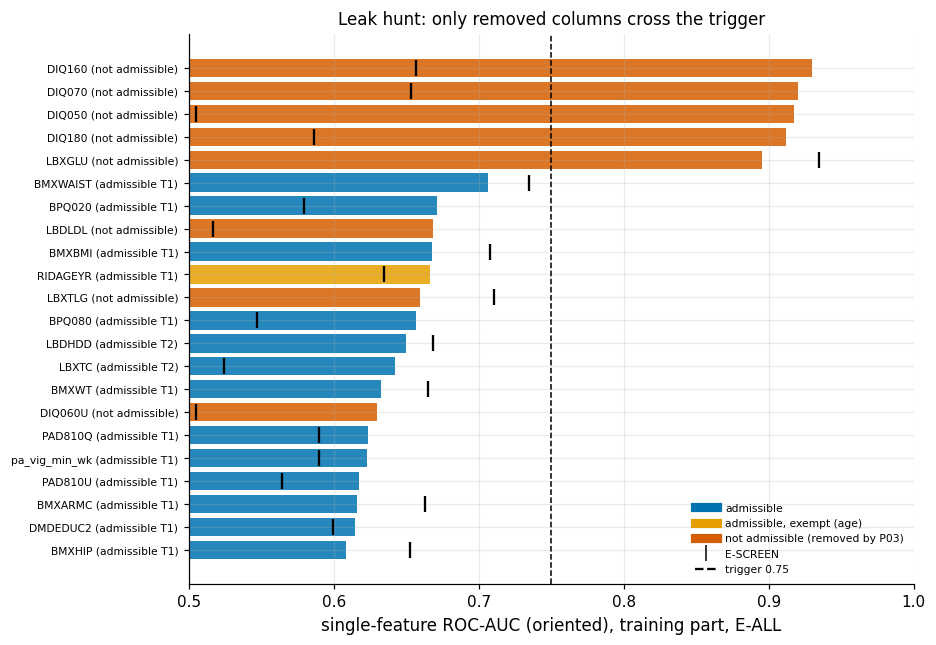

In [217]:
top_scan = single.head(22).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 6.5))
cols_ = [OI["vermillion"] if not a else (OI["orange"] if v in RB.AGE_EXEMPT else OI["blue"]) for a, v in zip(top_scan["admissible"], top_scan["variable"])]
ax.barh(range(len(top_scan)), top_scan["auc_oriented"], color=cols_, alpha=0.85)
ax.scatter(top_scan["auc_escreen"], range(len(top_scan)), marker="|", s=120, color="k", label="same feature on E-SCREEN", zorder=3)
ax.axvline(RB.L3_SINGLE_FEATURE_AUC, color="k", ls="--", lw=1, label="L3 trigger 0.75")
ax.set_yticks(range(len(top_scan)), [f"{v} ({s.split(' (')[0]})" for v, s in zip(top_scan["variable"], top_scan["status"])], fontsize=7)
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("single-feature ROC-AUC (oriented), training part, E-ALL")
ax.legend(handles=[Line2D([], [], color=OI["blue"], lw=6, label="admissible"), Line2D([], [], color=OI["orange"], lw=6, label="admissible, exempt (age)"),
                   Line2D([], [], color=OI["vermillion"], lw=6, label="not admissible (removed by P03)"),
                   Line2D([], [], color="k", marker="|", ls="", ms=10, label="E-SCREEN"),
                   Line2D([], [], color="k", ls="--", label="trigger 0.75")], fontsize=7, loc="lower right")
ax.set_title("Leak hunt: only removed columns cross the trigger", fontsize=11)
plots.savefig(fig, "S9_single_feature_auc", caption="F9-5. Univariate ROC-AUC of the 22 strongest columns of the naive M0 frame (plus derived S columns), "
              "training part, E-ALL (bars) and E-SCREEN (ticks). Categorical items use out-of-fold target encoding. Red = removed by the "
              "availability rule; blue = admissible; dashed = L3 trigger 0.75 (age exempt).")
plt.show()

**So what.** Loop L3 is **not triggered** (log above): the admissible arms stay far below an E-ALL AUC of 0.90, no
admissible feature other than the exempt age exceeds 0.75, the permutation test passed, and each of the ten most
important features of S – in Tier 1 and Tier 2 – passes the point-of-care availability proof (questionnaire, body
measures, blood pressure, and in Tier 2 the same-visit lipid panel; none is a glycaemic test, a consequence of
diagnosis or a component of the label). The exit condition is met in round 0, so S7 is not re-run.

One honest caveat survives the hunt. Two admissible items, "told high blood pressure" (BPQ020) and "told high
cholesterol" (BPQ080), are **care-contact traces**: they are legitimately available before a glucose test, but
they are more informative for people already in care. The T1-minus-care contrast (printed) shows the consequence –
removing them costs AUC on E-ALL but not on E-SCREEN. This is not leakage under the availability rule; it is the
mechanism behind the E-ALL vs E-SCREEN gap (H2c) and is reported as such.

## 9.10 Pre-hold-out summary
**Why.** Before the experiment is frozen, every robustness result for the headline contrast S − M1 is put on one
scale, so that the robustness grade of the claim (S10, `claims.csv`) can be read off one table and one figure.

                             check      pop  est_min  est_max      lo     hi        verdicts
          reference (stored folds)    E-ALL   0.0079   0.0079  0.0000 0.0158    inconclusive
                       10 CV seeds    E-ALL   0.0058   0.0078 -0.0018 0.0155 inconclusive 10
              16 sensitivity specs    E-ALL  -0.0061   0.0116 -0.0233 0.0230 inconclusive 16
                     60-spec curve    E-ALL   0.0048   0.0182 -0.0046 0.0266 inconclusive 60
           strata x PSU grouped CV    E-ALL   0.0055   0.0055 -0.0001 0.0118  inconclusive 1
IPW (evaluation; fit + evaluation)    E-ALL   0.0072   0.0079 -0.0009 0.0158  inconclusive 2
   MNAR delta -1 to 3 (draw means)    E-ALL   0.0075   0.0078  0.0059 0.0092     n/a (no CI)
          reference (stored folds) E-SCREEN   0.0085   0.0085 -0.0081 0.0236    inconclusive
                       10 CV seeds E-SCREEN   0.0062   0.0104 -0.0090 0.0248 inconclusive 10
              16 sensitivity specs E-SCREEN  -0.0119   0.0204 -0.0389 

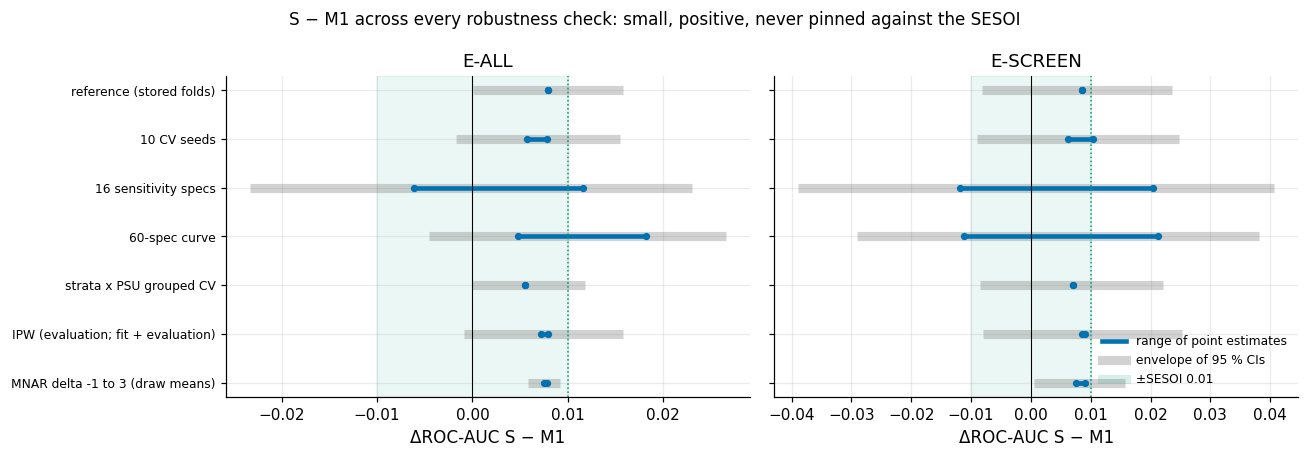

In [218]:
def _rng(d, pop):
    x = d[d["pop"] == pop]
    return x["est"].min(), x["est"].max(), x["lo"].min(), x["hi"].max(), ", ".join(f"{k} {v}" for k, v in x["h2b"].value_counts().items())

summ = []
for pop in ("E-ALL", "E-SCREEN"):
    r0 = S9["reference"][pop]
    summ.append(dict(check="reference (stored folds)", pop=pop, est_min=r0["est"], est_max=r0["est"], lo=r0["lo"], hi=r0["hi"], verdicts=r0["h2b"]))
    for nm, d in ((f"{len(SEED_FOLDS)} CV seeds", seeds), (f"{len(SENS)} sensitivity specs", sens[sens["spec"] != "reference (S7)"]),
                  (f"{len(grid)}-spec curve", curve), ("strata x PSU grouped CV", gcv_tab[gcv_tab["folds"] != "stored stratified"]),
                  ("IPW (evaluation; fit + evaluation)", ipw_tab)):
        a, b, lo, hi, v = _rng(d, pop)
        summ.append(dict(check=nm, pop=pop, est_min=a, est_max=b, lo=lo, hi=hi, verdicts=v))
    dd = dauc[(dauc["pop"] == pop) & (dauc["scenario"] == "delta")]
    summ.append(dict(check="MNAR delta -1 to 3 (draw means)", pop=pop, est_min=dd["diff"].min(), est_max=dd["diff"].max(),
                     lo=dd["diff_lo"].min(), hi=dd["diff_hi"].max(), verdicts="n/a (no CI)"))
summ = pd.DataFrame(summ)
summ.to_csv(OUT / "robustness_summary.csv", index=False)
print(summ.round(4).to_string(index=False))
fam_v = {pop: pd.concat([seeds.loc[seeds["pop"] == pop, "h2b"], sens.loc[(sens["pop"] == pop) & (sens["spec"] != "reference (S7)"), "h2b"],
                         curve.loc[curve["pop"] == pop, "h2b"], gcv_tab.loc[(gcv_tab["pop"] == pop) & (gcv_tab["folds"] != "stored stratified"), "h2b"],
                         ipw_tab.loc[ipw_tab["pop"] == pop, "h2b"]]) for pop in ("E-ALL", "E-SCREEN")}
all_incon = {pop: bool((v == "inconclusive").all()) for pop, v in fam_v.items()}
for pop, v in fam_v.items():
    print(f"{pop}: {len(v)} alternative comparisons with a CI -> verdicts {v.value_counts().to_dict()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    s = summ[summ["pop"] == pop].reset_index(drop=True)
    for i, r in s.iterrows():
        ax.plot([r["lo"], r["hi"]], [i, i], color=OI["grey"], lw=6, alpha=0.35, solid_capstyle="butt")
        ax.plot([r["est_min"], r["est_max"]], [i, i], color=OI["blue"], lw=3)
        ax.scatter([r["est_min"], r["est_max"]], [i, i], color=OI["blue"], s=14, zorder=3)
    ax.axvspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["green"], alpha=0.08)
    ax.axvline(0, color="k", lw=0.7)
    ax.axvline(C.SESOI["roc_auc"], color=OI["green"], ls=":", lw=1)
    ax.set(title=pop, xlabel="ΔROC-AUC S − M1")
axes[0].set_yticks(range(len(s)), s["check"], fontsize=8)
axes[0].invert_yaxis()
axes[1].legend(handles=[Line2D([], [], color=OI["blue"], lw=3, label="range of point estimates"),
                        Line2D([], [], color=OI["grey"], lw=6, alpha=0.35, label="envelope of 95 % CIs"),
                        Line2D([], [], color=OI["green"], lw=6, alpha=0.15, label="±SESOI 0.01")], fontsize=8, loc="lower right")
fig.suptitle("S − M1 across every robustness check: small, positive, never pinned against the SESOI", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S9_robustness_summary", caption="Range of ΔROC-AUC (S − M1) point estimates (blue) and envelope of the 95 % CIs (grey) for each "
              f"family of robustness checks: stored folds, {len(SEED_FOLDS)} CV seeds, {len(SENS)} one-at-a-time specifications, {len(grid)}-specification curve, "
              "strata x PSU grouped CV, inverse-probability weighting and MNAR delta adjustment; E-ALL left, E-SCREEN right.")
plt.show()
S9["summary"] = dict(table=summ.round(5).to_dict("records"), all_inconclusive=all_incon)

**So what.** Every check agrees with every other: on E-ALL the systematic pipeline is ahead of the minimal one by
roughly 0.005–0.015 AUC; apart from the depth-4 tree (a different model class, see DR-S9-13) the intervals stay above
about −0.01, and none of them clears +0.01 – so the robust reading of
H2b(a) is "**S is at least as good as M1 and probably slightly better, by an amount that cannot be distinguished from
the 0.01 threshold**", which is what *inconclusive* means under the locked equivalence rule. On E-SCREEN the same
direction holds with intervals about twice as wide. The robustness grade of the claim is therefore *robust verdict,
imprecise effect*; nothing here licenses calling S "better" or "equivalent".

### 9.10.1 Decision register (S9)

In [219]:
from datetime import date
today = date.today().isoformat()
def _f(r, k=3):
    return f"{r['est']:+.{k}f} [{r['lo']:+.{k}f}, {r['hi']:+.{k}f}]"

pc = pos_tab.set_index(["arm", "pop"])
reg = pd.DataFrame([
    dict(dr_id="DR-S9-01", type="negative_control", finding="Label-permutation null centred on 0.5 for both admissible arms; tests procedural leakage only",
         evidence_ref="results/S9/permutation.csv; figures/S9_permutation_null.png",
         evidence_value=f"null mean M1 {PERM['M1']['null_mean']:.4f}, S {PERM['S']['null_mean']:.4f} ({C.N_PERM} permutations); p = {PERM['S']['p_value']:.3f}",
         decision="Evaluation procedure accepted; feature leakage delegated to the L3 leak hunt", alternatives_rejected="sklearn permutation_test_score (no sample weights per fold, no fixed folds)",
         hyp_id="", status="decided", check_verdict="PASS", check_note="band [0.495, 0.505]", loop_ref="L3"),
    dict(dr_id="DR-S9-02", type="negative_control", finding="An N(0,1) noise column is treated as noise",
         evidence_ref="results/S9/noise_feature.csv",
         evidence_value="; ".join(f"{r['arm']}: coef/SD {r['coef_per_sd']:+.3f} [{r['q_low']:+.3f}, {r['q_high']:+.3f}], dAUC {r['dAUC_eall']:+.4f}, depth-3 trees using it {r['tree3_uses']}/{r['n_trees']}" for _, r in noise_tab.iterrows()),
         decision="No overfitting to noise; depth cap 3 for the tree probe retained", alternatives_rejected="", hyp_id="", status="decided",
         check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-03", type="positive_control", finding="A synthetic feature with known AUC 0.60 is recovered and detected",
         evidence_ref="results/S9/positive_control.csv",
         evidence_value=f"z AUC {z_auc[0]:.3f} [{z_auc[1]:.3f}, {z_auc[2]:.3f}]; dAUC E-ALL M1 {pc.loc[('M1', 'E-ALL'), 'est']:+.4f} [{pc.loc[('M1', 'E-ALL'), 'lo']:+.4f}, {pc.loc[('M1', 'E-ALL'), 'hi']:+.4f}], S {pc.loc[('S', 'E-ALL'), 'est']:+.4f} [{pc.loc[('S', 'E-ALL'), 'lo']:+.4f}, {pc.loc[('S', 'E-ALL'), 'hi']:+.4f}]",
         decision="Procedure has power for weak real signals; negative controls are not passed by blindness", alternatives_rejected="",
         hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-04", type="seed_stability", finding="S - M1 verdict does not depend on the CV / bootstrap seed",
         evidence_ref="results/S9/seed_stability.csv; figures/S9_seed_stability.png",
         evidence_value=f"E-ALL est {seed_sum.loc['E-ALL', 'est_min']:+.4f} to {seed_sum.loc['E-ALL', 'est_max']:+.4f}; verdicts {seed_sum.loc['E-ALL', 'verdicts']}",
         decision="H2b(a) verdict graded seed-stable", alternatives_rejected="single seed", hyp_id="H2b", status="decided",
         check_verdict="PASS" if seed_stable else "FAIL", check_note="10 seeds via evalkit.derive_seed; hold-out fixed", loop_ref=""),
    dict(dr_id="DR-S9-05", type="sensitivity", finding="16 one-at-a-time analysis variations leave the E-ALL verdict of S - M1 unchanged",
         evidence_ref="results/S9/sensitivity_table.csv; figures/S9_sensitivity_forest.png",
         evidence_value=f"E-ALL same verdict {n_same}/{len(eall)}; est {eall['est'].min():+.4f} to {eall['est'].max():+.4f}; no CI wholly below 0",
         decision="H2b(a) inconclusive is robust; labels and arm-specific weighting move the size of the gap, not its direction (except the depth-4 tree)",
         alternatives_rejected="reporting only the reference specification", hyp_id="H2b", status="decided",
         check_verdict="PASS" if n_same == len(eall) else "PARTIAL", check_note="E-SCREEN all inconclusive (wide CIs)", loop_ref=""),
    dict(dr_id="DR-S9-06", type="tuning", finding="Arm-specific tuning of C gives M0 and M1 the same C as S",
         evidence_ref="notebook 08 section 4",
         evidence_value=f"own C: M0 {OWN_C['M0'][0]}, M1 {OWN_C['M1'][0]} (C0 {ctx.C0}); leak gate own C E-ALL {_f(gate_own[0])}",
         decision="The C0-on-S optimism disclosed in DR-S7-04 is nil in practice; HR2 'same model' rule kept", alternatives_rejected="per-arm tuning as primary design",
         hyp_id="H2a;H2b", status="decided", check_verdict="PASS", check_note="closes the S9 item of DR-S7-04", loop_ref=""),
    dict(dr_id="DR-S9-07", type="sensitivity", finding="60-specification curve (label x weighting x C) agrees with the core table",
         evidence_ref="results/S9/specification_curve.csv; figures/S9_specification_curve.png",
         evidence_value=f"E-ALL est {cs.loc['E-ALL', 'est_min']:+.4f} to {cs.loc['E-ALL', 'est_max']:+.4f}, {cs.loc['E-ALL', 'share_positive']:.0%} positive, "
                        f"{cs.loc['E-ALL', 'share_ci_above_0']:.0%} CI above 0, {cs.loc['E-ALL', 'share_beyond_sesoi']:.0%} beyond SESOI",
         decision="Extension item; does not change the core table", alternatives_rejected="", hyp_id="H2b", status="decided",
         check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-08", type="sensitivity", finding="Survey-cluster folds (strata x PSU) do not inflate or change the comparison",
         evidence_ref="results/S9/grouped_cv.csv",
         evidence_value=f"{len(np.unique(groups))} clusters; AUC(S) grouped - stratified E-ALL {dS['E-ALL']:+.4f}; S - M1 grouped {_f(gcv[0], 4)}",
         decision="Stratified (non-grouped) folds kept as primary design", alternatives_rejected="grouped folds as primary (unbalanced E-SCREEN positives per fold)",
         hyp_id="H2b", status="decided", check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-09", type="missingness", finding="Missing HbA1c: MAR (IPW) and MNAR (delta) scenarios move prevalence little and S - M1 not at all",
         evidence_ref="results/S9/ipw.csv; results/S9/mnar_delta_prevalence.csv; results/S9/mnar_delta_auc.csv; figures/S9_mnar_delta.png",
         evidence_value=f"prevalence WTPH2YR {prev_tab.loc[0, 'est']:.2%}, MEC x IPW {prev_tab.loc[2, 'est']:.2%}; delta OR 0.37-20: "
                        f"{dprev['prevalence'].min():.2%}-{dprev['prevalence'].max():.2%}; Manski [{dprev.attrs['manski_low']:.2%}, {dprev.attrs['manski_high']:.2%}]; "
                        f"OR needed for 15.8 %: {np.exp(tip):.0f}; S - M1 E-ALL under delta {dauc.loc[(dauc['pop'] == 'E-ALL') & (dauc['scenario'] == 'delta'), 'diff'].min():+.4f} to "
                        f"{dauc.loc[(dauc['pop'] == 'E-ALL') & (dauc['scenario'] == 'delta'), 'diff'].max():+.4f}",
         decision="Complete-case cohort with WTPH2YR confirmed; MNAR untestable but no plausible mechanism changes conclusions",
         alternatives_rejected="imputing HbA1c (would impute the label)", hyp_id="", status="decided", check_verdict="PASS",
         check_note="closes DR-S3-04 and DR-S5-08", loop_ref="DR-S3-04;DR-S5-08"),
    dict(dr_id="DR-S9-10", type="validation", finding="V1 DB516 replication holds; V2 gap 14.0 % vs 15.8 % is a label-definition gap",
         evidence_ref="results/S4/db516_replication.csv; results/S9/v2_prevalence_gap.csv; figures/S9_db516_forest.png",
         evidence_value=f"max |diff| {db['diff_pp'].abs().max():.3f} pp over {len(db)}; sample effect {v2.loc[3, 'est_pct']:+.2f} pp [{v2.loc[3, 'ci_low']:+.2f}, {v2.loc[3, 'ci_high']:+.2f}], "
                        f"definition effect {v2.loc[4, 'est_pct']:+.2f} pp [{v2.loc[4, 'ci_low']:+.2f}, {v2.loc[4, 'ci_high']:+.2f}]; {fpg_only} FPG-only positives",
         decision="Report 14.0 % as the prevalence of L_comb, not of NCHS-defined diabetes; no change to the frozen label",
         alternatives_rejected="calling the gap a failed replication", hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""),
    dict(dr_id="DR-S9-11", type="validation", finding="ADA-lite vs Bang 2009 comparable only qualitatively",
         evidence_ref="notebook 08 section 8.3",
         evidence_value=f"ADA-lite E-SCREEN AUC {bl['escr_auc']:.3f}; cut-off >= 5 sens {ada_tab.loc[2, 'sensitivity']:.2f}, spec {ada_tab.loc[2, 'specificity']:.2f} vs Bang 0.79 / 0.67",
         decision="Quote only the verified abstract figures; Bang AUC 0.79/0.83 marked unverified and not used",
         alternatives_rejected="quantitative comparison with the published AUC", hyp_id="H2c", status="decided", check_verdict="PASS",
         check_note="2 items missing; outcome HbA1c-based", loop_ref=""),
    dict(dr_id="DR-S9-12", type="leak_hunt", finding="L3 leak hunt not triggered on the admissible arms",
         evidence_ref="results/S9/leak_hunt_log.csv; leak_single_feature_auc.csv; leak_missing_indicator_auc.csv; leak_top10_availability.csv; figures/S9_single_feature_auc.png",
         evidence_value=f"T1 E-ALL AUC M1 {t1_auc['M1']:.3f}, S {t1_auc['S']:.3f}; strongest admissible single feature {best_adm['variable']} {best_adm['auc_oriented']:.3f}; "
                        f"top-10 availability {int((proof['verdict'] == 'PASS').sum())}/{len(proof)} PASS; only removed leak columns exceed 0.75",
         decision="Exit condition met in round 0; no re-run of S7. Care-contact items (BPQ020, BPQ080) kept but reported as the mechanism of the E-ALL/E-SCREEN gap",
         alternatives_rejected="dropping BPQ020/BPQ080 from the main model (they pass the availability rule)", hyp_id="H2c", status="decided",
         check_verdict="PASS" if not L3_TRIGGERED else "FAIL", check_note=f"T1-minus-care - S: E-ALL {_f(care[0], 4)}, E-SCREEN {_f(care[1], 4)}", loop_ref="L3"),
    dict(dr_id="DR-S9-13", type="model_choice", finding="A depth-4 tree reverses the sign of S - M1 with a wide interval",
         evidence_ref="results/S9/sensitivity_table.csv",
         evidence_value="depth-4 tree S - M1 E-ALL " + _f(sens[(sens['spec'] == 'depth-4 tree') & (sens['pop'] == 'E-ALL')].iloc[0], 4),
         decision="Tree stays a probe; preparation effects are judged on the logistic model only", alternatives_rejected="tree as co-primary model",
         hyp_id="B5", status="decided", check_verdict="PASS", check_note="P08/P09 are no-ops for trees (B5-e)", loop_ref=""),
    dict(dr_id="DR-S9-14", type="freeze", finding="Pre-hold-out robustness complete; experiment configuration ready to freeze",
         evidence_ref="results/metrics_S9.json; results/splits/holdout.json",
         evidence_value=f"C0 {ctx.C0}; folds hash {ctx.folds.hash[:16]}; hold-out SHA-256 {hold['sha256_test_seqn'][:16]}; thresholds: spec 0.80 on training-part predictions",
         decision="Request exp-freeze; hold-out evaluated once afterwards with refits on the full training part; no re-tuning after it",
         alternatives_rejected="", hyp_id="", status="decided", check_verdict="PASS", check_note="", loop_ref=""),
])
reg.insert(1, "stage", "S9")
reg.insert(2, "date", today)
for c in ("change_request", "commit"):
    reg[c] = ""
reg = reg[["dr_id", "stage", "date", "type", "finding", "evidence_ref", "evidence_value", "decision", "alternatives_rejected", "hyp_id",
           "status", "check_verdict", "check_note", "loop_ref", "change_request", "commit"]]
REG_PATH = C.GOVERNANCE_DIR / "register" / "S9.csv"
print(reg[["dr_id", "type", "check_verdict", "evidence_value"]].to_string(index=False, max_colwidth=110))

   dr_id             type check_verdict                                                                                                 evidence_value
DR-S9-01 negative_control          PASS                                                    null mean M1 0.5015, S 0.5014 (100 permutations); p = 0.010
DR-S9-02 negative_control          PASS M1: coef/SD +0.012 [-0.075, +0.110], dAUC -0.0000, depth-3 trees using it 0/26; S: coef/SD +0.048 [-0.067, ...
DR-S9-03 positive_control          PASS             z AUC 0.588 [0.567, 0.610]; dAUC E-ALL M1 +0.0061 [+0.0023, +0.0101], S +0.0061 [+0.0021, +0.0102]
DR-S9-04   seed_stability          PASS                                                        E-ALL est +0.0058 to +0.0078; verdicts inconclusive x10
DR-S9-05      sensitivity          PASS                                         E-ALL same verdict 17/17; est -0.0061 to +0.0116; no CI wholly below 0
DR-S9-06           tuning          PASS                                  own C: M0 0.1, M1 0.1

## 9.11 One-shot hold-out evaluation
**Why.** Everything above re-used the training part; repeated looks at the same data, however disciplined, can
drift towards what works. The 20 % hold-out (1,146 adults, stratified by label × race, created once in S7 and never
read since) is the only fully independent check. Rules fixed before looking: it is evaluated **once, after the
`exp-freeze` tag**; arms BL0, BL-ADAlite (points), BL-ADAlite-LR, M0, M1, S and T1-minus-care (Tier 1; M0, M1 and S also
Tier 2) are refitted on the whole training part with the frozen configuration; thresholds for recall at
specificity 0.80 come from the training part; a hold-out AUC more than 2 standard errors below its CV estimate is
reported as such and **not** answered by re-tuning. The test SEQN hash and the run time are logged.

**The evaluation has already happened, once** (FINAL mode, 2026-10-11, after the tag; the time stamp is printed
below). What this notebook does with the hold-out therefore depends on the run mode:

* **FINAL mode – deterministic reproduction, not a second look.** The gate opens only if the frozen facts of the tag
  are reproduced: C0, the fold-file hash and the hold-out SEQN hash recomputed in this run must equal the frozen
  values, and the modelling code (`config`, `prep`, `evalkit`, `labels`, `nhanes_io`) must be byte-identical to the
  tagged version. The same frozen models are then refitted with the same seeds and the AUCs are **asserted equal**
  to the logged one-shot results; nothing can be tuned, and a different number stops the notebook.
* **FAST mode – no refit.** The stored one-shot results are displayed and stored unchanged, clearly labelled.

A single `.ipynb` has no git history, so the facts of the tag (commit, time stamp, C0, fold hash, hold-out hash,
module hashes) travel with the notebook as a frozen record, `results/S9/exp_freeze_record.json`, written once
from git and inlined in §0.0 (like the pre-registration lock of §6.11). In a git checkout the record is
re-derived from the tag and asserted equal. Expected precision: AUC SE about 0.017 on E-ALL and about 0.05 on
E-SCREEN (about 25 positives).

In [220]:
HOLDOUT_LOG = OUT / "holdout_log.json"
HOLDOUT_CSV = OUT / "holdout_metrics.csv"
HOLDOUT_PAIRS = OUT / "holdout_pairs.csv"
prev = json.loads(HOLDOUT_LOG.read_text(encoding="utf-8")) if HOLDOUT_LOG.exists() else None
STORED = prev is not None and HOLDOUT_CSV.exists() and HOLDOUT_PAIRS.exists()
REC = RB.load_freeze_record()                       # frozen record shipped with the notebook
TAG_OK = RB.tag_exists("exp-freeze")                # only in a git checkout
if TAG_OK:                                          # facts re-derived from git; the shipped record must agree
    FROZEN = RB.frozen_reference("exp-freeze")
    if REC is not None:
        assert REC["frozen"] == FROZEN and REC["tag_commit"] == RB.head_commit("exp-freeze"), "freeze record disagrees with the tag"
    SRC_OK = RB.sources_unchanged("exp-freeze")
else:                                               # a copy without git: the record is the only source
    FROZEN = None if REC is None else REC["frozen"]
    SRC_OK = None if REC is None else RB.module_hashes() == REC["module_sha256"]
CURRENT = dict(C0=ctx.C0, folds_hash=ctx.folds.hash, holdout_sha256=hold["sha256_test_seqn"])
gate = {"FINAL mode": C.IS_FINAL,
        "frozen record (exp-freeze) available": TAG_OK or REC is not None,
        **{f"{k} = frozen": FROZEN is not None and FROZEN.get(k) == v for k, v in CURRENT.items()},
        f"modelling sources identical to the tag ({len(RB.FROZEN_SOURCES)} files)": SRC_OK is True,
        # once the one-shot run is on record, a FINAL execution may only reproduce it, never evaluate afresh
        "one-shot log present (re-execution = reproduction)": STORED or (REC is None and prev is None)}
RELEASED = all(gate.values())
if REC is not None:
    print(f"frozen record: tag {REC['tag']} on commit {REC['tag_commit'][:12]} (created {REC['tag_created']}); "
          f"C0 {REC['frozen']['C0']}, folds {REC['frozen']['folds_hash'][:12]}..., hold-out {REC['frozen']['holdout_sha256'][:12]}...; "
          f"one-shot run {REC['one_shot']['first_run_utc']} ({REC['one_shot']['nb_mode']}); source: {'git tag (record verified)' if TAG_OK else 'record shipped with the notebook'}")
print(f"this run: C0 {CURRENT['C0']}, folds {CURRENT['folds_hash'][:12]}... ({C.NB_MODE} folds), hold-out {CURRENT['holdout_sha256'][:12]}...")
for k, v in gate.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
REASON = "; ".join(k for k, v in gate.items() if not v)
if RELEASED:
    print("gate open -> refit the frozen models and reproduce the logged one-shot hold-out results")
elif STORED:
    print(f"gate closed ({REASON}) -> no refit; the stored one-shot results are displayed below")
else:
    print(f"gate closed ({REASON}) and no stored one-shot results -> hold-out not evaluated")

frozen record: tag exp-freeze on commit 37a2387af1b6 (created 2026-10-11T04:30:23+08:00); C0 0.1, folds 0d20f8f706eb..., hold-out 616fd0590bec...; one-shot run 2026-10-11T05:35:17+00:00 (FINAL); source: record shipped with the notebook
this run: C0 0.1, folds 0d20f8f706eb... (FINAL folds), hold-out 616fd0590bec...
  PASS  FINAL mode
  PASS  frozen record (exp-freeze) available
  PASS  C0 = frozen
  PASS  folds_hash = frozen
  PASS  holdout_sha256 = frozen
  PASS  modelling sources identical to the tag (5 files)
  PASS  one-shot log present (re-execution = reproduction)
gate open -> refit the frozen models and reproduce the logged one-shot hold-out results


In [221]:
SHOW_HO = ["arm", "tier", "pop", "n_pos", "roc_auc", "auc_lo", "auc_hi", "cv_auc", "gap_in_se", "flag_2se_below_cv", "pr_auc", "brier",
           "cal_slope", "cal_citl", "recall_at_thr", "spec_at_thr"]
if RELEASED:
    from sklearn.dummy import DummyClassifier
    raw_te, cl_te, X_te = RB.holdout_frames(ctx)
    sha_te = RB.sha256_ints(cl_te["SEQN"])
    assert sha_te == hold["sha256_test_seqn"], "hold-out SEQNs differ from the stored hash"
    assert not set(cl_te["SEQN"]) & set(ctx.cl["SEQN"]), "hold-out overlaps the training part"
    y_te = cl_te["L_comb"].to_numpy().astype(int)
    esc_te = cl_te["in_escreen"].eq(1).to_numpy()
    yesc_te = cl_te["y_escreen"].fillna(0).astype(int).to_numpy()
    print(f"hold-out: {len(cl_te):,} rows, {y_te.sum()} L_comb positives; E-SCREEN {esc_te.sum():,} rows, {yesc_te[esc_te].sum()} positives; "
          f"SHA-256 {sha_te[:16]}... verified")

    ada_tr_, ada_te_ = P.ada_lite_items(ctx.cl), P.ada_lite_items(cl_te)
    HO_ARMS = [("BL0", 1), ("BL-ADAlite", 1), ("BL-ADAlite-LR", 1), ("M0", 1), ("M1", 1), ("S", 1), ("T1-minus-care", 1),
               ("M0", 2), ("M1", 2), ("S", 2)]
    prefetch({f"cv{a}{t}": (Spec(a, tier=t), ctx.folds) for a, t in HO_ARMS if a in P.ARMS})
    P_TR, P_TE, P_CV = {}, {}, {}
    for a, t in HO_ARMS:
        if a == "BL0":
            m = DummyClassifier(strategy="prior").fit(ctx.X[1], ctx.y)
            P_TR[(a, t)], P_TE[(a, t)] = m.predict_proba(ctx.X[1])[:, 1], m.predict_proba(X_te[1])[:, 1]
            P_CV[(a, t)] = ek.mean_oof(ek.cv_predict(lambda: DummyClassifier(strategy="prior"), ctx.X[1], ctx.y, ctx.folds), ctx.n)
        elif a == "BL-ADAlite":
            P_TR[(a, t)] = P_CV[(a, t)] = ada_tr_["ada_score"].to_numpy(float)
            P_TE[(a, t)] = ada_te_["ada_score"].to_numpy(float)
        elif a == "BL-ADAlite-LR":
            m = P.ada_lr_pipeline(ctx.C0).fit(ada_tr_, ctx.y)
            P_TR[(a, t)], P_TE[(a, t)] = m.predict_proba(ada_tr_)[:, 1], m.predict_proba(ada_te_)[:, 1]
            P_CV[(a, t)] = ek.mean_oof(ek.cv_predict(lambda: P.ada_lr_pipeline(ctx.C0), ada_tr_, ctx.y, ctx.folds), ctx.n)
        else:
            m = RB.fit_full(ctx, Spec(a, tier=t))
            P_TR[(a, t)], P_TE[(a, t)] = m.predict_proba(ctx.X[t])[:, 1], m.predict_proba(X_te[t])[:, 1]
            P_CV[(a, t)] = ek.mean_oof(RB.run_many(ctx, {"x": Spec(a, tier=t)}, n_jobs=N_JOBS, cache=RUNS)["x"], ctx.n)

    ho_rows = []
    for (a, t), pte in P_TE.items():
        ptr = P_TR[(a, t)]
        for pop, yy_te, m_te, yy_tr, m_tr in (("E-ALL", y_te, None, ctx.y, None), ("E-SCREEN", yesc_te, esc_te, ctx.y_esc, ctx.esc)):
            thr = ek.recall_at_specificity(yy_tr, ptr, C.SPEC_FIXED, neg_mask=m_tr)[1]
            hs = RB.holdout_scores(yy_te, pte, thr, mask=m_te, seed_=RB.seed("holdout", a, t, pop))
            mm_tr = np.ones(ctx.n, bool) if m_tr is None else m_tr
            cv_auc, cv_lo, cv_hi = RB.auc_ci(yy_tr, P_CV[(a, t)], mm_tr, seed_=RB.seed("holdout-cv", a, t, pop))
            ho_rows.append(dict(arm=a, tier=t, pop=pop, **hs, cv_auc=cv_auc, cv_lo=cv_lo, cv_hi=cv_hi))
    ho = pd.DataFrame(ho_rows)
    ho["gap_holdout_minus_cv"] = ho["roc_auc"] - ho["cv_auc"]
    ho["gap_in_se"] = np.where(ho["auc_se"] > 0, ho["gap_holdout_minus_cv"] / ho["auc_se"].where(ho["auc_se"] > 0), np.nan)
    pts = ho["arm"] == "BL-ADAlite"                 # an integer score, not a probability: no Brier / calibration
    ho.loc[pts, ["brier", "cal_slope", "cal_citl"]] = np.nan
    ho["flag_2se_below_cv"] = ho["gap_in_se"] < -2
    print(ho[SHOW_HO].round(3).to_string(index=False))

    def ho_pair(a, b, pop, rule):
        """Paired hold-out bootstrap A - B with the locked rule of the hypothesis it belongs to."""
        yy, m = (y_te, None) if pop == "E-ALL" else (yesc_te, esc_te)
        bs = ek.paired_bootstrap(yy, P_TE[a], P_TE[b], "roc_auc", n_boot=C.N_BOOT, eval_mask=m,
                                 seed=RB.seed("holdout-pair", str(a), str(b), pop))
        lo, hi, est = bs["ci_low"], bs["ci_high"], bs["diff"]
        if rule == "equivalence 0.01":
            v = RB.equivalence_verdict(lo, hi)
        elif rule == "lower by >= 0.05":
            v = ek.verdict(lo, hi, 0.05, "-", est)
            v = "refuted" if (v == "equivalent" or lo > -0.05) else v
        elif rule == "higher by >= 0.01":
            v = ek.verdict(lo, hi, 0.01, "+", est)
            v = "refuted" if v == "equivalent" else v
        else:
            v = "descriptive"
        return dict(comparison=f"{a[0]} T{a[1]} - {b[0]} T{b[1]}", pop=pop, rule=rule, est=est, lo=lo, hi=hi, se=bs["se"], verdict=v)
    hp = pd.DataFrame([ho_pair(("S", 1), ("M1", 1), p, "equivalence 0.01") for p in ("E-ALL", "E-SCREEN")]
                      + [ho_pair(("S", 2), ("M1", 2), p, "equivalence 0.01") for p in ("E-ALL", "E-SCREEN")]
                      + [ho_pair(("M1", 1), ("M0", 1), p, "lower by >= 0.05") for p in ("E-ALL", "E-SCREEN")]
                      + [ho_pair(("T1-minus-care", 1), ("S", 1), p, "descriptive") for p in ("E-ALL", "E-SCREEN")]
                      + [ho_pair(("S", 1), ("BL-ADAlite", 1), "E-SCREEN", "higher by >= 0.01")])
    print(hp.round(4).to_string(index=False))
    print("CV (this run) S - M1: " + "; ".join(f"{p} {r['est']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}] {r['h2b']}" for p, r in S9["reference"].items()))
elif STORED:   # FAST mode (or a closed gate): show the logged one-shot results, never refit
    ho = pd.read_csv(HOLDOUT_CSV)
    hp = pd.read_csv(HOLDOUT_PAIRS)
    if REC is not None:   # the shipped tables must be the ones written by the one-shot run
        same = {p_: RB.sha256_lf((C.ROOT / p_).read_bytes()) == h_ for p_, h_ in REC["stored_tables_sha256"].items()}
        assert all(same.values()), f"stored hold-out tables differ from the frozen record: {same}"
    print(f"STORED ONE-SHOT HOLD-OUT RESULTS - evaluated once in {prev['nb_mode_first_run']} mode on {prev['first_run_utc']}, "
          f"{prev['n_test']:,} adults, SHA-256 {prev['sha256_test_seqn'][:16]}...; NOT re-executed in this {C.NB_MODE} run"
          + ("; tables verified against the frozen record" if REC is not None else ""))
    print(ho[SHOW_HO].round(3).to_string(index=False))
    print(hp.round(4).to_string(index=False))
    print(f"CV (this run, {C.NB_MODE}) S - M1: " + "; ".join(f"{p} {r['est']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}] {r['h2b']}" for p, r in S9["reference"].items()))

hold-out: 1,146 rows, 194 L_comb positives; E-SCREEN 977 rows, 25 positives; SHA-256 616fd0590bec7b92... verified


          arm  tier      pop  n_pos  roc_auc  auc_lo  auc_hi  cv_auc  gap_in_se  flag_2se_below_cv  pr_auc  brier  cal_slope  cal_citl  recall_at_thr  spec_at_thr
          BL0     1    E-ALL    194    0.500   0.500   0.500   0.503        NaN              False   0.169  0.141        NaN       NaN          0.000        1.000
          BL0     1 E-SCREEN     25    0.500   0.500   0.500   0.497        NaN              False   0.026  0.046        NaN       NaN          0.000        1.000
   BL-ADAlite     1    E-ALL    194    0.779   0.748   0.810   0.761      1.119              False   0.356    NaN        NaN       NaN          0.278        0.929
   BL-ADAlite     1 E-SCREEN     25    0.762   0.677   0.835   0.726      0.906              False   0.060    NaN        NaN       NaN          0.240        0.929
BL-ADAlite-LR     1    E-ALL    194    0.791   0.758   0.820   0.768      1.434              False   0.381  0.120      1.212     0.054          0.613        0.811
BL-ADAlite-LR     1 E-

             comparison      pop              rule     est      lo      hi     se      verdict
           S T1 - M1 T1    E-ALL  equivalence 0.01  0.0035 -0.0070  0.0138 0.0053 inconclusive
           S T1 - M1 T1 E-SCREEN  equivalence 0.01 -0.0053 -0.0289  0.0159 0.0114 inconclusive
           S T2 - M1 T2    E-ALL  equivalence 0.01  0.0095 -0.0010  0.0197 0.0054 inconclusive
           S T2 - M1 T2 E-SCREEN  equivalence 0.01  0.0085 -0.0167  0.0355 0.0138 inconclusive
          M1 T1 - M0 T1    E-ALL  lower by >= 0.05 -0.1168 -0.1445 -0.0919 0.0134    supported
          M1 T1 - M0 T1 E-SCREEN  lower by >= 0.05 -0.0374 -0.1173  0.0468 0.0426 inconclusive
T1-minus-care T1 - S T1    E-ALL       descriptive -0.0096 -0.0209  0.0025 0.0060  descriptive
T1-minus-care T1 - S T1 E-SCREEN       descriptive  0.0176 -0.0135  0.0485 0.0160  descriptive
   S T1 - BL-ADAlite T1 E-SCREEN higher by >= 0.01  0.0286 -0.0370  0.0983 0.0354 inconclusive
CV (this run) S - M1: E-ALL +0.0079 [+0.0000, +0.0

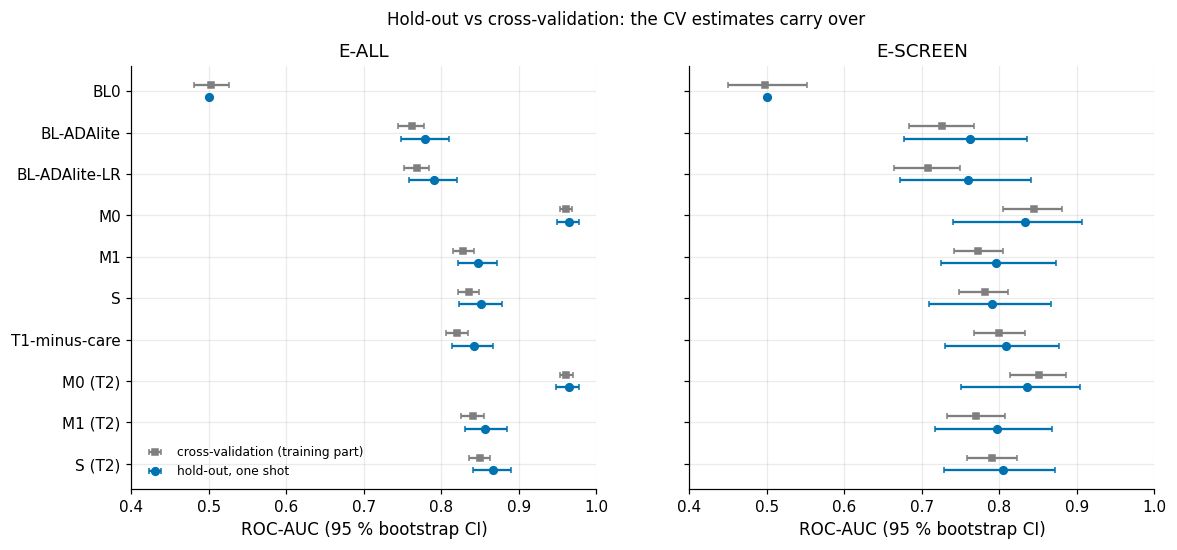

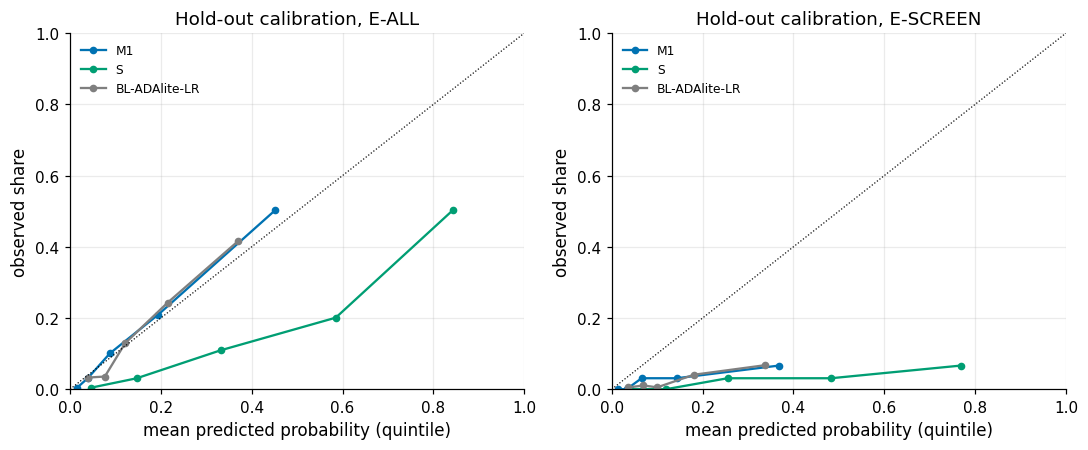

In [222]:
if RELEASED or STORED:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    lab_ = [f"{a}" + (" (T2)" if t == 2 else "") for a, t in ho.loc[ho["pop"] == "E-ALL", ["arm", "tier"]].itertuples(index=False)]
    for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
        d = ho[ho["pop"] == pop].reset_index(drop=True)
        yy_ = np.arange(len(d))
        ax.errorbar(d["cv_auc"], yy_ - 0.15, xerr=[d["cv_auc"] - d["cv_lo"], d["cv_hi"] - d["cv_auc"]], fmt="s", color=OI["grey"], capsize=2,
                    ms=4, label="cross-validation (training part)")
        ax.errorbar(d["roc_auc"], yy_ + 0.15, xerr=[d["roc_auc"] - d["auc_lo"], d["auc_hi"] - d["roc_auc"]], fmt="o", capsize=2, ms=5,
                    color=OI["blue"], label="hold-out, one shot")
        for i, r in d.iterrows():
            if r["flag_2se_below_cv"]:
                ax.text(r["auc_lo"] - 0.01, i + 0.15, "> 2 SE below CV", ha="right", va="center", fontsize=7, color=OI["vermillion"])
        ax.set(title=pop, xlabel="ROC-AUC (95 % bootstrap CI)", xlim=(0.4, 1.0))
    axes[0].set_yticks(range(len(lab_)), lab_)
    axes[0].invert_yaxis()
    axes[0].legend(fontsize=8, loc="lower left")
    fig.suptitle("Hold-out vs cross-validation: the CV estimates carry over" + ("" if RELEASED else " (stored one-shot results)"), fontsize=11)
    plots.savefig(fig, "S9_holdout_vs_cv", caption="F9-6. ROC-AUC on the 20 % hold-out (blue; models refitted once on the whole training part, evaluated once "
                  "after exp-freeze) against the pooled out-of-fold estimate on the training part (grey), with 95 % bootstrap CIs; E-ALL left, "
                  "E-SCREEN right (about 25 hold-out positives).")
    plt.show()

if RELEASED:   # needs the refitted models' hold-out predictions
    from sklearn.calibration import calibration_curve
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
    for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
        yy, m = (y_te, np.ones(len(y_te), bool)) if pop == "E-ALL" else (yesc_te, esc_te)
        for (a, t), col in ((("M1", 1), OI["blue"]), (("S", 1), OI["green"]), (("BL-ADAlite-LR", 1), OI["grey"])):
            fr, mp = calibration_curve(yy[m], P_TE[(a, t)][m], n_bins=5, strategy="quantile")
            ax.plot(mp, fr, "o-", color=col, ms=4, label=a)
        ax.plot([0, 1], [0, 1], "k:", lw=0.8)
        ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="mean predicted probability (quintile)", ylabel="observed share", title=f"Hold-out calibration, {pop}")
        ax.legend(fontsize=8)
    fig.tight_layout()
    plots.savefig(fig, "S9_holdout_calibration", caption="Calibration on the hold-out by quintiles of the predicted probability for M1, S (balanced class weights) "
                  "and BL-ADAlite-LR, Tier 1; E-ALL left, E-SCREEN right.")
    plt.show()
elif STORED:
    print("hold-out calibration curves need the refitted models' predictions; they are part of the stored FINAL outputs "
          "(calibration slope and CITL are in the table above)")

In [223]:
if RELEASED:
    now = pd.Timestamp.now(tz="UTC").isoformat(timespec="seconds")
    if STORED:   # a re-execution must reproduce the one-shot numbers exactly (deterministic reproduction, not a second look)
        old = pd.read_csv(HOLDOUT_CSV).set_index(["arm", "tier", "pop"])["roc_auc"]
        new = ho.set_index(["arm", "tier", "pop"])["roc_auc"]
        assert old.index.sort_values().equals(new.index.sort_values()), "hold-out arms differ from the one-shot run"
        dmax = float(np.abs(old.reindex(new.index).to_numpy() - new.to_numpy()).max())
        assert dmax <= 1e-9, f"hold-out AUCs changed after the one-shot run (max difference {dmax})"
        oldp = pd.read_csv(HOLDOUT_PAIRS).set_index(["comparison", "pop"])["est"]
        newp = hp.set_index(["comparison", "pop"])["est"]
        assert np.allclose(oldp.reindex(newp.index).to_numpy(), newp.to_numpy(), atol=1e-9), "paired hold-out differences changed"
        print(f"re-execution reproduces the {len(new)} one-shot hold-out AUCs and {len(newp)} paired differences exactly "
              f"(first run {prev['first_run_utc']}; max |AUC difference| {dmax:.1e})")
    log_ = dict(first_run_utc=prev["first_run_utc"] if prev else now, last_run_utc=now,
                n_executions=(prev["n_executions"] + 1) if prev else 1, sha256_test_seqn=sha_te, n_test=int(len(cl_te)),
                exp_freeze_commit=RB.head_commit("exp-freeze") or (REC or {}).get("tag_commit"), head_at_first_run=prev["head_at_first_run"] if prev else RB.head_commit(),
                arms=[f"{a} T{t}" for a, t in P_TE], threshold_rule="specificity 0.80 on training-part predictions of the refitted model",
                nb_mode_first_run=prev["nb_mode_first_run"] if prev else C.NB_MODE, frozen=FROZEN, gate=gate)
    HOLDOUT_LOG.write_text(json.dumps(log_, indent=2), encoding="utf-8")
    ho.to_csv(HOLDOUT_CSV, index=False)
    hp.to_csv(OUT / "holdout_pairs.csv", index=False)
    print(json.dumps(log_, indent=1))
    S9["holdout"] = dict(status="re-executed in FINAL mode: reproduces the one-shot run" if STORED else "evaluated (one-shot run)",
                         log=log_, metrics=ho.round(5).to_dict("records"), pairs=hp.round(5).to_dict("records"),
                         n_flag_2se=int(ho["flag_2se_below_cv"].sum()))
elif STORED:   # never replace the one-shot results by "not evaluated": store them unchanged, labelled
    S9["holdout"] = dict(status=f"stored one-shot results, not re-executed in this {C.NB_MODE} run ({REASON})",
                         log=prev, metrics=ho.round(5).to_dict("records"), pairs=hp.round(5).to_dict("records"),
                         n_flag_2se=int(ho["flag_2se_below_cv"].sum()))
    print(S9["holdout"]["status"])
else:
    S9["holdout"] = dict(status=f"not evaluated: gate closed ({REASON}) and no stored one-shot results")
    print(S9["holdout"]["status"])

re-execution reproduces the 20 one-shot hold-out AUCs and 9 paired differences exactly (first run 2026-10-11T05:35:17+00:00; max |AUC difference| 1.1e-16)
{
 "first_run_utc": "2026-10-11T05:35:17+00:00",
 "last_run_utc": "2026-10-11T07:55:58+00:00",
 "n_executions": 2,
 "sha256_test_seqn": "616fd0590bec7b9256cd9704f62dfcd147f31d83a56b1f6969e1d613010659c3",
 "n_test": 1146,
 "exp_freeze_commit": "37a2387af1b6bf7bf3ed3aa4b192e5f817e5c738",
 "head_at_first_run": "9691c8c6f8c78bcae329542cc922662beec3d042",
 "arms": [
  "BL0 T1",
  "BL-ADAlite T1",
  "BL-ADAlite-LR T1",
  "M0 T1",
  "M1 T1",
  "S T1",
  "T1-minus-care T1",
  "M0 T2",
  "M1 T2",
  "S T2"
 ],
 "threshold_rule": "specificity 0.80 on training-part predictions of the refitted model",
 "nb_mode_first_run": "FINAL",
 "frozen": {
  "C0": 0.1,
  "folds_hash": "0d20f8f706ebf1e1103d23a4326e6d1a8cf0632c2a88417aac52cc8add4303ce",
  "holdout_sha256": "616fd0590bec7b9256cd9704f62dfcd147f31d83a56b1f6969e1d613010659c3"
 },
 "gate": {
  "FIN

**So what.** The one-shot hold-out (1,146 adults, 194 L_comb positives; E-SCREEN 977 adults, 25 positives; SHA-256
verified and logged) confirms the cross-validated picture and does not change a single verdict.
* **No optimism.** None of the 20 arm × population rows is more than 2 SE below its CV estimate (0 flags). On E-ALL
  every model scores slightly *higher* on the hold-out than in CV (+0.45 to +1.55 SE; S Tier 1 0.851 [0.823, 0.878]
  vs CV 0.836, M1 0.848 vs 0.828). The unfitted integer ADA-lite score is also 0.018 higher, so most of this is
  the hold-out sample being slightly easier, not extra training rows. On E-SCREEN the gaps run from −0.39 to +1.14 SE,
  and with 25 positives each interval is about ±0.08 wide.
* **Headline contrast.** S − M1 on the hold-out is +0.0035 [−0.0070, +0.0138] on E-ALL (Tier 2 +0.0095 [−0.0010,
  +0.0197]) and −0.0053 [−0.0289, +0.0159] on E-SCREEN: *inconclusive* everywhere, as in CV (+0.0079 and +0.0085).
  The hold-out does not license calling S "better" or "equivalent".
* **Other contrasts.** Removing the leaky items (M1 − M0) costs −0.117 [−0.145, −0.092] on E-ALL (*supported*,
  lower by at least 0.05) but only −0.037 [−0.117, +0.047] on E-SCREEN (*inconclusive*). S vs the ADA-lite points score
  on E-SCREEN is +0.029 [−0.037, +0.098] (*inconclusive*). Dropping the care-contact items costs −0.010 on E-ALL
  but not on E-SCREEN (+0.018), the same pattern as the leak hunt.
* **Calibration and thresholds.** M1 is close to calibrated on E-ALL (slope 1.07, CITL 0.11, Brier 0.107). S ranks as
  well but over-predicts by design (balanced class weights: CITL −1.72, Brier 0.171), so its probabilities are not
  risks. On E-SCREEN every model over-predicts (CITL M1 −1.96, BL-ADAlite-LR −1.98, S −3.81), because all of them
  were fitted to the E-ALL prevalence; calibration plots show this as curves well below the diagonal. At the training-derived specificity-0.80 thresholds, the fitted models reach a hold-out specificity of 0.80–0.83, and
  recall is 0.67 (M1) and 0.70 (S) on E-ALL but 0.48 for both (12 of 25) on E-SCREEN.

Nothing was re-tuned after these numbers were seen. A FINAL-mode re-execution of this notebook must reproduce them
exactly (asserted against `results/S9/holdout_metrics.csv` and `holdout_pairs.csv`); a FAST-mode run shows the same
stored one-shot numbers without refitting (labelled as such in the output above).

## 9.12 Storage
**Why.** S10 (claims and robustness grades) and S11 (notebook, slides) read every number from stored artefacts:
`results/metrics_S9.json`, the tables in `results/S9/`, the F9 figures and the S9 decision-register fragment
(written from the FINAL run, so that the register always carries the numbers of the committed notebook).

In [224]:
if RELEASED and "metrics" in S9["holdout"]:
    hS = ho[(ho["arm"] == "S") & (ho["tier"] == 1)].set_index("pop")
    hpS = hp.set_index(["comparison", "pop"])
    reg = pd.concat([reg, pd.DataFrame([dict(
        dr_id="DR-S9-15", stage="S9", date=today, type="holdout",
        finding="One-shot hold-out evaluation after exp-freeze",
        evidence_ref="results/S9/holdout_metrics.csv; results/S9/holdout_pairs.csv; results/S9/holdout_log.json; figures/S9_holdout_vs_cv.png",
        evidence_value=(f"S T1 AUC E-ALL {hS.loc['E-ALL', 'roc_auc']:.3f} [{hS.loc['E-ALL', 'auc_lo']:.3f}, {hS.loc['E-ALL', 'auc_hi']:.3f}] (CV {hS.loc['E-ALL', 'cv_auc']:.3f}), "
                        f"E-SCREEN {hS.loc['E-SCREEN', 'roc_auc']:.3f} [{hS.loc['E-SCREEN', 'auc_lo']:.3f}, {hS.loc['E-SCREEN', 'auc_hi']:.3f}] (CV {hS.loc['E-SCREEN', 'cv_auc']:.3f}); "
                        f"S - M1 E-ALL {hpS.loc[('S T1 - M1 T1', 'E-ALL'), 'est']:+.4f} [{hpS.loc[('S T1 - M1 T1', 'E-ALL'), 'lo']:+.4f}, {hpS.loc[('S T1 - M1 T1', 'E-ALL'), 'hi']:+.4f}]; "
                        f"{int(ho['flag_2se_below_cv'].sum())} of {len(ho)} arm x population rows > 2 SE below CV; SHA-256 {sha_te[:16]}"),
        decision="Report hold-out numbers as they are; no re-tuning", alternatives_rejected="re-tuning after seeing the hold-out",
        hyp_id="H2a;H2b;H2c", status="decided", check_verdict="PASS", check_note=f"first run {S9['holdout']['log']['first_run_utc']}",
        loop_ref="", change_request="", commit="")])], ignore_index=True)
if C.IS_FINAL:
    reg.to_csv(REG_PATH, index=False)
    print(f"wrote {REG_PATH.relative_to(C.ROOT).as_posix()} ({len(reg)} rows)")
else:
    print(f"FAST run: register fragment not written ({len(reg)} rows prepared; the committed fragment comes from the FINAL run)")
S9["register_ids"] = reg["dr_id"].tolist()
S9["runtime_seconds"] = time.time() - T_START
R.save_section("S9", S9)
print(f"saved results/metrics_S9.json; section runtime {S9['runtime_seconds']:.0f} s ({C.NB_MODE})")
print(json.dumps({"H2b(a) reference": S9["reference"]["E-ALL"]["h2b"], "seeds stable": S9["seeds"]["stable_eall"],
                  "sensitivity same verdict": f"{S9['sensitivity']['eall_same_verdict']}/{S9['sensitivity']['eall_rows']}",
                  "L3 triggered": S9["leak_hunt"]["triggered"], "hold-out": S9["holdout"]["status"]}, indent=1))

wrote governance/register/S9.csv (15 rows)
saved results/metrics_S9.json; section runtime 727 s (FINAL)
{
 "H2b(a) reference": "inconclusive",
 "seeds stable": true,
 "sensitivity same verdict": "17/17",
 "L3 triggered": false,
 "hold-out": "re-executed in FINAL mode: reproduces the one-shot run"
}


# §10 Synthesis and Interpretation (Stage S10)

§1–§9 produced numbers; this section turns them into **claims** with an honest strength, scope and
falsifier. Nothing here is re-estimated: every value is read from the stored results of the earlier
sections (`results/metrics_S*.json`, `results/S*/`), and every number shown on a slide is re-read and
asserted at the end. The machine-learning models are treated as **measuring instruments** – a leak
detector, a coefficient-stability meter, a label-bias meter, a negative control – so the question is not
"how good is the model?" but "what did the models reveal about the data?".

Contents: 1 inputs · 2 hypothesis scoreboard · 3 post-lock notes · 4 improvements and deteriorations ·
5 what the ML evidence says about the data · 6 headline findings · 7 claims ledger · 8 hold-out against
cross-validation · 9 limitations · 10 ethics, governance and recommendations · 11 numbers on slides ·
12 register and storage

Vocabulary. Verdicts follow the locked rules of `governance/hypotheses.md` (supported / refuted /
equivalent / inconclusive / mixed). Evidence grades: **E1** deterministic fact (a count), **E2** large
effect whose CI excludes 0 and that is stable under §9's checks, **E3** moderate effect or sensitive to a
choice, **E4** exploratory. The wording of a claim follows its grade: E1 *confirms*, E2 *shows*, E3 *is
consistent with*, E4 *suggests*. Statements say *association*, never *cause*.

Run modes. Numbers quoted in the text cells are those of the FINAL run (5 × 5 CV, B = 1,000) stored with this
notebook. A FAST re-run prints its own values in the code cells; they can differ in the third decimal and, for
the borderline items listed in limitation L12, in a sub-verdict.

In [225]:
new_section()

In [226]:
import hashlib, json, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import roc_auc_score

from src import evalkit as ek

pd.set_option("display.width", 180, "display.max_columns", 30, "display.max_colwidth", 70)
OUT = C.RESULTS_DIR / "S10"
OUT.mkdir(parents=True, exist_ok=True)
OI = C.OKABE_ITO
T_START = time.time()
SECTIONS = ("S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9")
SEC = {"S1": "§1", "S2": "§2", "S3": "§3", "S4": "§4", "S5": "§5", "S6": "§6", "S7": "§7", "S8": "§8", "S9": "§9", "S10": "§10"}
S10 = {"mode": C.NB_MODE}
print(f"mode {C.NB_MODE}; this section re-estimates nothing – it reads stored results only")

mode FINAL; this section re-estimates nothing – it reads stored results only


## 10.1 Inputs and provenance
**Why.** A synthesis is only as good as its inputs: it must read the results of the run that produced the
notebook, from the locked hypothesis file, and say which run mode each section came from.

The helper `get("S7:headline.leak_gate_T1_eall.est")` resolves a *source key* – section, then a dotted path
into that section's metrics file; `name[k=v&k2=v2]` picks the one record of a list that matches. The same
keys are written next to every slide number in §10.11, so each number can be traced to its origin.

In [227]:
M = {s: R.load_section(s) for s in SECTIONS}
modes = {s: M[s]["_meta"]["nb_mode"] for s in SECTIONS}
print("run mode per section:", modes)
if C.IS_FINAL:   # numbers that depend on resampling size must come from the full protocol
    assert all(modes[s] == "FINAL" for s in ("S7", "S8", "S9")), modes

_SPLIT = re.compile(r"\.(?![^\[]*\])")


def _match(v, want: str) -> bool:
    try:
        return abs(float(v) - float(want)) < 1e-9
    except (TypeError, ValueError):
        return str(v) == want


def get(key: str, src: dict | None = None):
    """Resolve 'S7:path.to[k=v&k2=v2].value' in the metrics dictionaries (default: this run's M)."""
    sec, path = key.split(":", 1)
    d = (src or M)[sec]
    for seg in _SPLIT.split(path):
        m = re.fullmatch(r"([^\[]*)(?:\[(.*)\])?", seg)
        name, filt = m.group(1), m.group(2)
        if name:
            d = d[name]
        if filt:
            conds = [c.split("=", 1) for c in filt.split("&")]
            hits = [x for x in d if all(_match(x.get(k), v) for k, v in conds)]
            assert len(hits) == 1, f"{key}: {len(hits)} records match [{filt}]"
            d = hits[0]
    return d


# hypotheses.md is locked: its SHA-256 must equal the pre-registration record of §6
hyp_bytes = (C.GOVERNANCE_DIR / "hypotheses.md").read_bytes()
hyp_sha = hashlib.sha256(hyp_bytes).hexdigest()
lock = get("S6:hypotheses.lock")
assert hyp_sha == lock["sha256"], "governance/hypotheses.md differs from the locked version"
print(f"hypotheses.md SHA-256 {hyp_sha[:16]}... equals the lock of {lock['timestamp']} (commit {lock['commit'][:10]}); "
      f"first experiment commit {lock['first_exp_timestamp']} is later: {lock['first_exp_timestamp'] > lock['timestamp']}")

# parse the locked hypothesis tables (statement, metric, direction, magnitude, SESOI, falsifier, prior exposure)
HCOLS = ["hyp_id", "rq_or_block", "statement", "metric", "direction", "magnitude", "sesoi", "falsifier", "prior_exposure", "weights"]
rows = []
for line in hyp_bytes.decode("utf-8").splitlines():
    if line.startswith("| ") and not line.startswith("| hyp_id") and not line.startswith("|---"):
        cells = [c.strip().replace("\\|", "|") for c in re.split(r"(?<!\\)\|", line.strip().strip("|"))]
        if len(cells) == len(HCOLS):
            rows.append(dict(zip(HCOLS, cells)))
HYP = pd.DataFrame(rows).set_index("hyp_id")
HYP["prior"] = HYP["prior_exposure"].str.split(" ").str[0]
assert len(HYP) == M["S6"]["hypotheses"]["n_total"] == 17, len(HYP)
print(f"{len(HYP)} locked hypotheses parsed; prior exposure: {HYP['prior'].value_counts().to_dict()}")

run mode per section: {'S1': 'FINAL', 'S2': 'FINAL', 'S3': 'FINAL', 'S4': 'FINAL', 'S5': 'FINAL', 'S6': 'FINAL', 'S7': 'FINAL', 'S8': 'FINAL', 'S9': 'FINAL'}
hypotheses.md SHA-256 de032f4d200fa1ff... equals the lock of 2026-10-11T02:17:18+08:00 (commit 9fb6aefd8a); first experiment commit 2026-10-11T02:34:13+08:00 is later: True
17 locked hypotheses parsed; prior exposure: {'none': 6, 'analysis_seen': 5, 'descriptive_seen': 4, 'prototype_seen': 2}


**So what.** All nine upstream sections are present. The sections whose numbers depend on the resampling
size (§7–§9) must come from the FINAL protocol (5 × 5 CV, B = 1,000) – asserted in a FINAL run; §1–§6 are
deterministic apart from a small bootstrap in §4. The hypothesis file is byte-identical to the version locked
before the first experiment. Only 6 of the 17 hypotheses are genuine pre-registrations (`prior_exposure = none`); the others
confirm patterns that had already been seen and are graded accordingly.

## 10.2 Hypothesis scoreboard
**Why.** Every locked hypothesis gets exactly one verdict under its locked rule, with the estimate, the CI,
the SESOI and – where an AUC difference is inconclusive – the minimal detectable difference (MDD), so that
"inconclusive" can be read as "underpowered" when the MDD exceeds the SESOI. Verdicts are taken from the
section that tested the hypothesis; two are completed here (H1b had numbers but no verdict line in §4;
P14 is combined from §7 part (a) and §8 part (b)). As an independent check, the locked rules are re-applied
to the stored CIs of the S7 sub-claims and must reproduce the stored verdicts.

In [228]:
det = pd.DataFrame(M["S7"]["scoreboard_detail"])
prim = det[det["role"] == "primary"]


def newcombe_diff(x1, n1, x2, n2, z=1.959964):
    """Newcombe hybrid-score CI for p1 - p2 (method 10), from Wilson intervals."""
    def wilson(x, n):
        p = x / n
        c = (p + z * z / (2 * n)) / (1 + z * z / n)
        h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
        return p, c - h, c + h
    p1, l1, u1 = wilson(x1, n1)
    p2, l2, u2 = wilson(x2, n2)
    d = p1 - p2
    return d, d - np.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + np.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)


SB = []


def add(hyp, est, lo, hi, unit, verdict, *, interval="", mdd=np.nan, sesoi=np.nan, subs="", source="", note="", underpowered=None):
    SB.append(dict(hyp_id=hyp, family=HYP.loc[hyp, "rq_or_block"], metric=HYP.loc[hyp, "metric"][:90],
                   direction=HYP.loc[hyp, "direction"], sesoi_locked=HYP.loc[hyp, "sesoi"], estimate=est, ci_low=lo, ci_high=hi,
                   unit=unit, interval=interval, mdd=mdd,
                   underpowered=bool(underpowered) if underpowered is not None else bool(verdict == "inconclusive" and np.isfinite(mdd) and np.isfinite(sesoi) and mdd > sesoi),
                   verdict=verdict, sub_verdicts=subs, prior_exposure=HYP.loc[hyp, "prior"], source=source, note=note))


# --- RQ1 (S4, S5)
rd = get("S5:undiagnosed_inequality.risk_differences_pp.uninsured - insured")
add("H1a", rd["rd_pp"], rd["ci_low_pp"], rd["ci_high_pp"], "pp", get("S5:hypotheses.H1a.verdict"), interval="jackknife (df 15)",
    source="§5 (S5)", note="uninsured share itself exploratory (Korn-Graubard width ≥ 0.30)")
ins = get("S4:standardisation.insured_uninsured")
h1b_std, (h1b_lo, h1b_hi), h1b_crude = ins["std"], ins["std_ci"], ins["crude"]
if h1b_std >= 2 and h1b_lo > 0:
    h1b_v = "refuted"
elif (h1b_std < 2 or h1b_lo <= 0) and h1b_std < h1b_crude:
    h1b_v = "supported"
else:
    h1b_v = "inconclusive"
add("H1b", h1b_std, h1b_lo, h1b_hi, "pp", h1b_v, interval="jackknife (df 15)", source="§4 (S4); verdict applied in §10",
    note=f"crude {h1b_crude:+.1f} pp [{ins['crude_ci'][0]:+.1f}, {ins['crude_ci'][1]:+.1f}] -> age-standardised; attenuation, not reversal")

# --- RQ2 and blocks (S7)
S7V = M["S7"]["scoreboard"]
for h in ["H2a", "H2b", "H2c", "B1", "B2", "B2t", "B3", "B4", "B5", "B6a", "B6b"]:
    g = prim[prim["hyp_id"] == h]
    r0 = g.iloc[0]
    subs = "; ".join(f"{r['sub']}{' ' + r['pop'] if (g['sub'] == r['sub']).sum() > 1 else ''}: {r['verdict']}" for _, r in g.iterrows())
    unit = {"roc_auc": "AUC", "brier": "Brier", "sd_ratio": "ratio", "calslope_dev": "|slope−1|"}.get(r0["metric"], str(r0["metric"]))
    add(h, r0["est"], r0["lo"], r0["hi"], unit if np.isfinite(r0["est"]) else "", S7V[h]["verdict"], interval=str(r0["interval"]) if pd.notna(r0["interval"]) else "",
        mdd=r0["mdd"], sesoi=r0["sesoi"], subs=subs, source="§7 (S7)",
        underpowered=bool(((g["verdict"] == "inconclusive") & (g["mdd"] > g["sesoi"])).any()),
        note=f"primary: {r0['comparison']}, {r0['pop']}" + (f", Tier {int(r0['tier'])}" if pd.notna(r0['tier']) else ""))

# --- P14: (a) from S7, (b) and the combined verdict from S8 (supersedes the interim S7 entry)
pa = prim[(prim["hyp_id"] == "P14") & (prim["sub"] == "(a) AUC")].iloc[0]
wt = pd.DataFrame(get("S8:whtr.table")).set_index("quantity")
pb = wt.loc["ΔTPR NH Asian"]
add("P14", pb["est"], pb["lo"], pb["hi"], "TPR", get("S8:verdicts.P14"), interval="PSU cluster bootstrap", sesoi=0.05,
    subs=f"(a) ΔAUC {pa['est']:+.4f} [{pa['lo']:+.4f}, {pa['hi']:+.4f}]: {pa['verdict']}; (b) NH Asian ΔTPR: {get('S8:verdicts.P14b')}",
    source="§7 (a), §8 (b)", note=f"§7 interim entry was '{S7V['P14']['verdict']} ({S7V['P14']['note']})'; §8 combined verdict used")

# --- RQ3 (S8): H3 three elements, column-wise reading
lm = get("S8:label_matrix")
h3c = pd.DataFrame(lm["contrasts"])
e3 = h3c[h3c["contrast"] == "worst-cell gap: L_comb - L_self"].iloc[0]
add("H3", e3["est"], e3["lo"], e3["hi"], "recall", lm["verdict"], interval="paired bootstrap", sesoi=0.05,
    subs="; ".join(f"{k}: {v}" for k, v in lm["element_verdicts"].items()), source="§8 (S8)",
    note="primary shown: E3 worst-cell gap L_comb − L_self; column-wise reading (see §10.3)")

# --- RQ4 (S5, S8)
ab = get("S5:asian_bmi.bmi_lt25_among_diabetics")
x1, n1 = ab["NH Asian"]["bmi_lt25"], ab["NH Asian"]["diabetics_with_bmi"]
x2, n2 = ab["NH White"]["bmi_lt25"], ab["NH White"]["diabetics_with_bmi"]
h4a = np.array(newcombe_diff(x1, n1, x2, n2)) * 100
s5_h4a = get("S5:hypotheses.H4a.estimate")
assert f"+{h4a[0]:.1f} pp (Newcombe {h4a[1]:.1f}, {h4a[2]:.1f})" in s5_h4a, (h4a, s5_h4a)   # independent recomputation
h4a_v = "supported" if (h4a[0] >= 20 and h4a[1] > 20) else ("refuted" if h4a[2] < 20 else "inconclusive")
assert h4a_v == get("S5:hypotheses.H4a.verdict")
add("H4a", h4a[0], h4a[1], h4a[2], "pp", h4a_v, interval="Newcombe (recomputed from counts)", source="§5 (S5)",
    note=f"{x1}/{n1} Asian vs {x2}/{n2} White diabetics with BMI < 25; Asian cell exploratory")
gd = get("S5:asian_bmi.gain_difference_asian_minus_white")
mdl = wt.loc["ΔAUC Asian − ΔAUC White (H4b, model level)"]
add("H4b", gd["est"], gd["psu_ci_low"], gd["psu_ci_high"], "AUC", get("S8:verdicts.H4b"), interval="PSU cluster bootstrap",
    subs=f"single feature (§5): {get('S8:scoreboard.H4b.single feature (S5)')}; model level (§8, secondary): {get('S8:verdicts.H4b_model_level')} "
         f"({mdl['est']:+.4f} [{mdl['lo']:+.4f}, {mdl['hi']:+.4f}])",
    source="§5 (S5), §8 (S8)", note=f"gain Asian {get('S5:asian_bmi.auc.NH Asian|WHtR − BMI (paired).auc'):+.3f} vs White "
                                   f"{get('S5:asian_bmi.auc.NH White|WHtR − BMI (paired).auc'):+.3f}")

SCORE = pd.DataFrame(SB)
order = list(HYP.index)
SCORE = SCORE.set_index("hyp_id").loc[order].reset_index()
assert set(SCORE["verdict"]) <= set(C.VERDICTS), set(SCORE["verdict"])

# independent re-application of the locked rules to the stored S7 CIs
CHECK = {  # (hyp, sub): rule
    ("B1", "(a) AUC"): "equiv", ("B3", "(a) AUC"): "equiv", ("B4", "(a) AUC"): "equiv", ("B6a", "(a) AUC"): "equiv",
    ("P14", "(a) AUC"): "equiv", ("H2b", "(a) AUC"): "equiv", ("B6b", "(a) unweighted AUC"): "noninf",
    ("H2a", "AUC M0-M1"): ("+", 0.05), ("B2", "(a) AUC M1-M0"): ("-", 0.05), ("B6a", "(b) Brier"): ("+", 0.005),
    ("B6a", "(c) balanced accuracy at 0.5"): ("+", 0.05), ("H2c", "(i) AUC E-ALL - E-SCREEN (S)"): ("+", 0.03),
    ("H2c", "(iii) S - ADA-lite, E-SCREEN"): ("+", 0.01)}
n_ok = 0
for (h, sub), rule in CHECK.items():
    r = prim[(prim["hyp_id"] == h) & (prim["sub"] == sub)].iloc[0]
    if rule == "equiv":
        v = "supported" if (-0.01 < r["lo"] and r["hi"] < 0.01) else ("refuted" if (r["lo"] >= 0.01 or r["hi"] <= -0.01) else "inconclusive")
    elif rule == "noninf":
        v = "supported" if r["lo"] > -0.01 else ("refuted" if r["hi"] < -0.01 else "inconclusive")
    else:
        v = ek.verdict(r["lo"], r["hi"], rule[1], rule[0], r["est"])
    assert v == r["verdict"], (h, sub, v, r["verdict"])
    n_ok += 1
print(f"locked rules re-applied to {n_ok} stored S7 sub-claims: all reproduce the stored verdict")

show = SCORE.assign(est_ci=SCORE.apply(lambda r: "" if not np.isfinite(r["estimate"]) else
                                        f"{r['estimate']:+.3f} [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]", axis=1))
print(show[["hyp_id", "est_ci", "unit", "mdd", "underpowered", "verdict", "prior_exposure", "source"]].round(4).to_string(index=False))
print("\nsub-verdicts:")
for _, r in SCORE[SCORE["sub_verdicts"] != ""].iterrows():
    print(f"  {r['hyp_id']:<4} {r['sub_verdicts']}")
VCOUNT = SCORE["verdict"].value_counts().to_dict()
VCOUNT_PRE = SCORE[SCORE["prior_exposure"] == "none"]["verdict"].value_counts().to_dict()
print(f"\nverdicts: {VCOUNT}; genuine pre-registrations only: {VCOUNT_PRE}")
SCORE.to_csv(OUT / "scoreboard.csv", index=False)

locked rules re-applied to 13 stored S7 sub-claims: all reproduce the stored verdict


hyp_id                     est_ci      unit    mdd  underpowered      verdict   prior_exposure                          source
   H1a  +23.158 [+6.235, +40.081]        pp    NaN         False    supported    analysis_seen                         §5 (S5)
   H1b    +0.685 [-2.559, +3.930]        pp    NaN         False    supported    analysis_seen §4 (S4); verdict applied in §10
   H2a    +0.131 [+0.114, +0.148]       AUC 0.0241         False    supported    analysis_seen                         §7 (S7)
   H2b    +0.008 [+0.000, +0.016]       AUC 0.0112          True inconclusive             none                         §7 (S7)
   H2c    +0.055 [+0.028, +0.086]       AUC 0.0400          True inconclusive             none                         §7 (S7)
    H3    -0.016 [-0.079, +0.028]    recall    NaN         False inconclusive             none                         §8 (S8)
   H4a +43.892 [+29.821, +57.694]        pp    NaN         False    supported    analysis_seen                

### 10.2.1 H2b in detail
**Why.** H2b is the "minimal versus systematic preparation" test required by the assignment (same model,
M1 vs S). Its locked verdict combines three sub-claims, so the single word *inconclusive* hides what the
data say. The pure-preparation contrast S−B6a vs M1 (S without class weights against M1; exploratory, not
locked) isolates what preparation itself does.

In [229]:
h2b = prim[prim["hyp_id"] == "H2b"].set_index("sub")
pp_ = pd.DataFrame(M["S7"]["pure_preparation_S_B6a_vs_M1"]).set_index(["pop", "metric"])
for sub, r in h2b.iterrows():
    extra = (f"; MDD {r['mdd']:.3f} vs SESOI {r['sesoi']:.3f} -> {'underpowered' if r['mdd'] > r['sesoi'] else 'powered'}"
             if (pd.notna(r["mdd"]) and r["verdict"] == "inconclusive") else "")
    print(f"H2b {sub:<18} {r['est']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}] ({r['interval'] if pd.notna(r['interval']) else 'Monte Carlo'}): {r['verdict']}{extra}")
print(f"H2b combined (locked combination rule): {S7V['H2b']['verdict']}")
for (pop, met), r in pp_.iterrows():
    print(f"pure preparation S−B6a vs M1, {pop:<8} {met:<7} {r['diff']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]")
cs = M["S7"]["coef_stability"]
print(f"BMI coefficient SD ratio M1 / S-linear {cs['ratio_H2b']['ratio']:.2f} [{cs['ratio_H2b']['lo']:.2f}, {cs['ratio_H2b']['hi']:.2f}]; "
      f"unscaled cumulative (before/after pruning) {cs['ratio_cumulative']['ratio']:.2f}; inside scaled L2 (B3) {cs['ratio_B3']['ratio']:.2f}")
S10["h2b"] = dict(subs={k: dict(est=r["est"], lo=r["lo"], hi=r["hi"], verdict=r["verdict"], mdd=r["mdd"]) for k, r in h2b.iterrows()},
                  pure_preparation=pp_.reset_index().to_dict("records"), verdict=S7V["H2b"]["verdict"])

H2b (a) AUC            +0.0079 [+0.0000, +0.0158] (corrected_t): inconclusive; MDD 0.011 vs SESOI 0.010 -> underpowered
H2b (b) Brier          +0.0739 [+0.0665, +0.0814] (corrected_t): refuted
H2b (c) BMI SD ratio   +1.9819 [+1.8048, +2.1708] (Monte Carlo): inconclusive
H2b combined (locked combination rule): inconclusive
pure preparation S−B6a vs M1, E-ALL    roc_auc +0.0073 [+0.0001, +0.0146]
pure preparation S−B6a vs M1, E-ALL    brier   -0.0018 [-0.0036, -0.0000]
pure preparation S−B6a vs M1, E-SCREEN roc_auc +0.0059 [-0.0094, +0.0214]
pure preparation S−B6a vs M1, E-SCREEN brier   -0.0009 [-0.0022, +0.0005]
BMI coefficient SD ratio M1 / S-linear 1.98 [1.80, 2.17]; unscaled cumulative (before/after pruning) 2.87; inside scaled L2 (B3) 1.36


**So what.** Of 17 hypotheses, 10 are supported (B1, B2, B2t, B6a, B6b, H1a, H1b, H2a, H4a, H4b),
1 is mixed (B3), 6 are inconclusive (B4, B5, H2b, H2c, H3, P14) and none is refuted overall – but
several *sub-claims* are refuted (H2b-Brier, B3 stability), which the sub-verdict column keeps visible.
The "supported" list is dominated by `analysis_seen` hypotheses that confirm patterns seen in §3–§5;
among the six genuine pre-registrations, only B6a and B6b are supported (both about weighting), B2t is
supported as a tree probe, and H2b, H2c and H3 – the substantive experimental claims – are inconclusive.
H2b, read by its parts: (a) AUC +0.008 [0.000, 0.016] – the MDD (0.011) exceeds the SESOI (0.010), so the
test is underpowered, not null; (b) the Brier score is **refuted** (S worse by 0.074) and the pure-preparation
contrast shows that this cost comes entirely from the class weights (Brier −0.002 without them);
(c) the BMI-coefficient SD ratio ≈ 2.0 straddles the threshold of 2. Systematic preparation buys fidelity
and some stability, not discrimination.

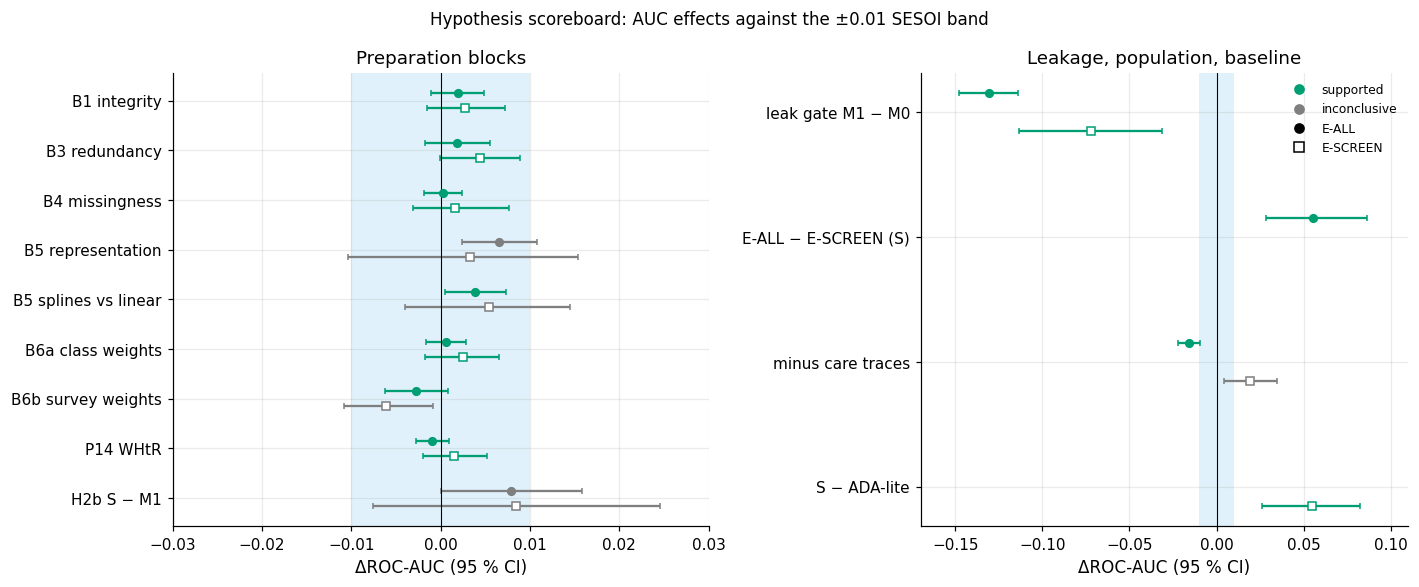

In [230]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={"width_ratios": [1.1, 1]})
SEEN = set()
VCOL = {"supported": OI["green"], "equivalent": OI["blue"], "refuted": OI["vermillion"], "inconclusive": OI["grey"], "mixed": OI["purple"]}
LEFT = [("B1", "(a) AUC", "B1 integrity"), ("B3", "(a) AUC", "B3 redundancy"), ("B4", "(a) AUC", "B4 missingness"),
        ("B5", "(b) AUC block", "B5 representation"), ("B5", "(c) AUC splines", "B5 splines vs linear"),
        ("B6a", "(a) AUC", "B6a class weights"), ("B6b", "(a) unweighted AUC", "B6b survey weights"),
        ("P14", "(a) AUC", "P14 WHtR"), ("H2b", "(a) AUC", "H2b S − M1")]
RIGHT = [("B2", "(a) AUC M1-M0", "leak gate M1 − M0"), ("H2c", "(i) AUC E-ALL - E-SCREEN (S)", "E-ALL − E-SCREEN (S)"),
         ("H2c", "(ii) minus care, E-ALL", "minus care traces"), ("H2c", "(iii) S - ADA-lite, E-SCREEN", "S − ADA-lite")]
for ax, spec, ttl, lim in ((axes[0], LEFT, "Preparation blocks", (-0.03, 0.03)), (axes[1], RIGHT, "Leakage, population, baseline", (-0.17, 0.11))):
    ylabels = []
    for i, (h, sub, lab) in enumerate(spec):
        g = det[(det["hyp_id"] == h) & (det["sub"].str.startswith(sub[:4])) & (det["metric"] == "roc_auc") & (det["tier"] == 1)]
        if h == "H2c" and sub.startswith("(ii)"):
            g = det[(det["hyp_id"] == "H2c") & det["sub"].str.startswith("(ii)")]
        for _, r in g.iterrows():
            off = -0.15 if r["pop"] in ("E-ALL", "E-ALL minus E-SCREEN") else 0.15
            col = VCOL.get(r["verdict"], OI["grey"])
            SEEN.add(r["verdict"])
            ax.errorbar(r["est"], i + off, xerr=[[r["est"] - r["lo"]], [r["hi"] - r["est"]]], fmt="o" if off < 0 else "s",
                        color=col, mfc=col if off < 0 else "white", capsize=2, ms=5)
        ylabels.append(lab)
    ax.axvspan(-0.01, 0.01, color=OI["sky"], alpha=0.18, lw=0)
    ax.axvline(0, color="k", lw=0.7)
    ax.set_yticks(range(len(spec)), ylabels)
    ax.invert_yaxis()
    ax.set(xlim=lim, title=ttl, xlabel="ΔROC-AUC (95 % CI)")
from matplotlib.lines import Line2D
hand = [Line2D([], [], marker="o", ls="", color=c, label=v) for v, c in VCOL.items() if v in SEEN]
hand += [Line2D([], [], marker="o", ls="", color="k", label="E-ALL"), Line2D([], [], marker="s", ls="", color="k", mfc="white", label="E-SCREEN")]
axes[1].legend(handles=hand, fontsize=8, loc="upper right")
fig.suptitle("Hypothesis scoreboard: AUC effects against the ±0.01 SESOI band", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S10_scoreboard_forest", caption="F10-1. Paired ΔROC-AUC of the locked AUC sub-claims (Tier 1; filled = E-ALL, corrected t or "
              "bootstrap, the wider; hollow = E-SCREEN, bootstrap) with 95 % CIs, coloured by the sub-claim verdict under its locked rule; "
              "blue band = SESOI ±0.01. For equivalence claims 'supported' means the CI lies inside the band. Left: preparation blocks "
              "(leave-one-block-out) and the minimal-vs-systematic contrast; right: leakage gate, evaluation population, care traces and baseline.")
plt.show()

**So what.** One picture of the whole experiment: every preparation block sits inside or at the edge of
the ±0.01 band, while removing leakage (−0.13) and changing the evaluation population (+0.055) move AUC
by 5–13 times the SESOI. What the analyst *includes* and *whom the model is scored on* matter an order of
magnitude more than how carefully the admissible data are prepared.

## 10.3 Post-lock notes
**Why.** After the lock, the hypothesis file is only appended to by its owner; interpretations made later
must be visible as such. Three entries are recorded in the §10 decision register (not in the locked file):
the operational reading of H3, the source of the P14 verdict and the verdict of H1b.

In [231]:
POSTLOCK = [
    dict(item="H3 reading", note=("'Misses most' is read column-wise: within a diabetes stratum, which training label has the lowest recall "
                                  "(coded in fairness.h3_elements before the matrix was viewed). The row-wise reading – which stratum each label "
                                  f"misses most – is secondary: {lm['row_wise_min']}."),
         consequence=f"H3 {lm['verdict']} under the column-wise reading; the row-wise pattern is reported as a descriptive finding"),
    dict(item="P14 verdict", note=f"§7 entered P14 as '{S7V['P14']['verdict']}' with part (b) deferred; §8 combined (a) and (b)",
         consequence=f"scoreboard uses the §8 combined verdict: {get('S8:verdicts.P14')}"),
    dict(item="H1b verdict", note="§4 reported crude and standardised differences but no verdict line",
         consequence=f"locked rule applied here: standardised {h1b_std:+.2f} pp [{h1b_lo:+.2f}, {h1b_hi:+.2f}] < +2 pp and below crude -> {h1b_v}"),
]
print(pd.DataFrame(POSTLOCK).to_string(index=False))

       item                                                                                                                                                                                                                                                                                                                           note                                                                                              consequence
 H3 reading 'Misses most' is read column-wise: within a diabetes stratum, which training label has the lowest recall (coded in fairness.h3_elements before the matrix was viewed). The row-wise reading – which stratum each label misses most – is secondary: {'L_self': 'Undiagnosed', 'L_A1c': 'Undiagnosed', 'L_comb': 'Undiagnosed'}. H3 inconclusive under the column-wise reading; the row-wise pattern is reported as a descriptive finding
P14 verdict                                                                                                                     

**So what.** None of the three notes changes a locked statement or a stored estimate; they make explicit
how two ambiguous or deferred items were resolved, so a reader can disagree with the reading without
having to reverse-engineer it.

## 10.4 Improvements and deteriorations
**Why.** The assignment asks for both directions to be explained. A deterioration can be the correct
outcome (removing leakage) and an improvement can be an artefact (a better balanced accuracy at 0.5 from
class weights). Each row gives the mechanism, the test that identifies it and the verdict.

In [232]:
lg = M["S7"]["leak_gate"]
hl = M["S7"]["headline"]
tm = M["S7"]["tree_m0"]
rw = pd.DataFrame(get("S8:reweighing.eod")).set_index(["arm", "group"]).sort_index()
blk = rw.loc[("S+RW(race)", "NH Black")]
asn = rw.loc[("S+RW(race)", "NH Asian")]
b6 = prim[prim["hyp_id"] == "B6a"].set_index("sub")
b5 = prim[prim["hyp_id"] == "B5"].set_index("sub")
ada = M["S7"]["ada_lr_minus_points"]["E-SCREEN"]
b6b_s = det[(det["hyp_id"] == "B6b") & (det["pop"] == "E-SCREEN")].iloc[0]


def ci3(e, lo, hi, k=3):
    return f"{e:+.{k}f} [{lo:+.{k}f}, {hi:+.{k}f}]"


IMPDET = pd.DataFrame([
    dict(change="Availability rule (M0 → M1)", direction="deterioration (correct)", metric="ΔAUC E-ALL / E-SCREEN",
         effect=f"{ci3(lg['T1_E-ALL']['est'], lg['T1_E-ALL']['lo'], lg['T1_E-ALL']['hi'])} / {ci3(lg['T1_E-SCREEN']['est'], lg['T1_E-SCREEN']['lo'], lg['T1_E-SCREEN']['hi'])}",
         mechanism="treatment and skip-logic items (DIQ070, DIQ180, DID040) exist only for people already diagnosed",
         test=f"tree root on M0 = {M['S7']['tree_roots']['M0']['variable']} (leak role); M1/S root {M['S7']['tree_roots']['S']['variable']}; §9 leak hunt not triggered",
         verdict=f"H2a {S7V['H2a']['verdict']}, B2 {S7V['B2']['verdict']}, B2t {S7V['B2t']['verdict']}"),
    dict(change="Naive median imputation (M0 tree)", direction="deterioration on screening", metric="tree AUC E-SCREEN M0 vs M1",
         effect=f"{tm['escreen_auc']['M0']:.3f} vs {tm['escreen_auc']['M1']:.3f}",
         mechanism=f"DID040 (age at diagnosis) {tm['did040_missing_share']:.0%} missing, filled with the median {tm['did040_fill']:.0f}: the split separates 'diagnosed' from 'imputed'",
         test="depth-3 tree on the M0 frame; level-2 split on DID040", verdict="descriptive (B2t probe)"),
    dict(change="Balanced class weights (B6a)", direction="deterioration (calibration) + artefactual gain", metric="ΔBrier / Δbalanced accuracy at 0.5",
         effect=f"{ci3(b6.loc['(b) Brier', 'est'], b6.loc['(b) Brier', 'lo'], b6.loc['(b) Brier', 'hi'])} / {ci3(b6.loc['(c) balanced accuracy at 0.5', 'est'], b6.loc['(c) balanced accuracy at 0.5', 'lo'], b6.loc['(c) balanced accuracy at 0.5', 'hi'])}",
         mechanism="re-weighting shifts every probability upward; ranking unchanged (ΔAUC "
                   f"{b6.loc['(a) AUC', 'est']:+.4f}); balanced accuracy at 0.5 rises only because 0.5 becomes a better threshold",
         test="leave-one-block-out, paired CV", verdict=f"B6a {S7V['B6a']['verdict']}; H2b(b) refuted"),
    dict(change="Systematic preparation without class weights (S−B6a vs M1)", direction="small improvement", metric="ΔAUC / ΔBrier E-ALL",
         effect=f"{ci3(pp_.loc[('E-ALL', 'roc_auc'), 'diff'], pp_.loc[('E-ALL', 'roc_auc'), 'lo'], pp_.loc[('E-ALL', 'roc_auc'), 'hi'])} / "
                f"{ci3(pp_.loc[('E-ALL', 'brier'), 'diff'], pp_.loc[('E-ALL', 'brier'), 'lo'], pp_.loc[('E-ALL', 'brier'), 'hi'], 4)}",
         mechanism="splines, scaling and pruning give the L2 model a better-posed problem (unscaled M1 hits the iteration limit in every fold)",
         test="paired bootstrap, exploratory (not locked)", verdict="below SESOI; not a verdict"),
    dict(change="Representation block (B5: Yeo-Johnson, scaling, splines)", direction="improvement (calibration)", metric="Δ|calibration slope − 1| E-ALL",
         effect=ci3(b5.loc['(a) |cal slope - 1|', 'est'], b5.loc['(a) |cal slope - 1|', 'lo'], b5.loc['(a) |cal slope - 1|', 'hi']),
         mechanism="mostly solver convergence once features are scaled; spline terms supported by the likelihood-ratio test",
         test=f"LR χ²({M['S7']['lr_test_splines']['1']['df']}) = {M['S7']['lr_test_splines']['1']['chi2']:.1f}", verdict=f"B5 {S7V['B5']['verdict']}"),
    dict(change="Removing care traces (T1-minus-care vs S)", direction="deterioration on E-ALL, improvement on E-SCREEN", metric="ΔAUC E-ALL / E-SCREEN",
         effect=f"{ci3(hl['minus_care_eall']['est'], hl['minus_care_eall']['lo'], hl['minus_care_eall']['hi'])} / {ci3(hl['minus_care_escreen']['est'], hl['minus_care_escreen']['lo'], hl['minus_care_escreen']['hi'])}",
         mechanism="told-high-blood-pressure and told-high-cholesterol items mark people already in care, who are mostly the diagnosed; among the not-yet-diagnosed they add noise",
         test="pre-registered ablation H2c(ii)", verdict="E-ALL supported; E-SCREEN 'unchanged' not supported (opposite sign)"),
    dict(change="ADA-lite items refitted by logistic regression (vs points)", direction="deterioration on E-SCREEN", metric="ΔAUC E-SCREEN",
         effect=ci3(ada['est'], ada['lo'], ada['hi']),
         mechanism="the refit learns L_comb, 84 % of whose positives are diagnosed: it optimises recognition, not screening",
         test="paired bootstrap", verdict="descriptive"),
    dict(change="Survey-weighted fit (B6b)", direction="small deterioration", metric="ΔAUC E-ALL / E-SCREEN (unweighted metric)",
         effect=f"{ci3(prim[prim['hyp_id'] == 'B6b'].iloc[0]['est'], prim[prim['hyp_id'] == 'B6b'].iloc[0]['lo'], prim[prim['hyp_id'] == 'B6b'].iloc[0]['hi'])} / "
                f"{ci3(b6b_s['est'], b6b_s['lo'], b6b_s['hi'])}",
         mechanism="weights re-target the population and cut the effective n (Kish deff ≈ 1.5)", test="non-inferiority at −0.01",
         verdict=f"B6b {S7V['B6b']['verdict']}"),
    dict(change="Race reweighing (fairness mitigation)", direction="deterioration (NH Black gap widens)", metric="ΔEOD NH Black / NH Asian",
         effect=f"{ci3(blk['d_eod'], blk['d_eod_lo'], blk['d_eod_hi'])} / {ci3(asn['d_eod'], asn['d_eod_lo'], asn['d_eod_hi'])}",
         mechanism=f"race weights are near 1 (range {get('S8:reweighing.weight_range.race')[0]:.2f}–{get('S8:reweighing.weight_range.race')[1]:.2f}); "
                   "rebalancing prevalence moves the shared threshold away from the Black positives",
         test="paired bootstrap of EOD change", verdict="not adopted"),
])
print(IMPDET[["change", "direction", "effect", "verdict"]].to_string(index=False))
IMPDET.to_csv(OUT / "improvements_deteriorations.csv", index=False)

                                                    change                                       direction                                               effect                                                             verdict
                               Availability rule (M0 → M1)                         deterioration (correct)    -0.131 [-0.148, -0.114] / -0.072 [-0.113, -0.031]                          H2a supported, B2 supported, B2t supported
                         Naive median imputation (M0 tree)                      deterioration on screening                                       0.633 vs 0.701                                             descriptive (B2t probe)
                              Balanced class weights (B6a)  deterioration (calibration) + artefactual gain    +0.076 [+0.068, +0.084] / +0.145 [+0.123, +0.166]                                       B6a supported; H2b(b) refuted
Systematic preparation without class weights (S−B6a vs M1)                              

**So what.** The biggest change in the project is a *deterioration that is correct*: the availability
rule costs 0.13 AUC because that AUC was leakage – the naive tree's first split is a treatment question and
its second an imputation constant. The biggest *improvement* (balanced accuracy +0.14) is an artefact of
class weights that worsens the Brier score by 0.076; without class weights, systematic preparation improves
AUC by 0.007 and calibration slightly. Two deteriorations teach something about the data: dropping care
traces lowers whole-sample AUC but raises screening AUC, and refitting ADA items on our label lowers
screening AUC – both say the label rewards *recognising the diagnosed*. Race reweighing widens the NH Black
gap, which is why it was not adopted.

## 10.5 What the ML evidence says about the data
**Why.** The project's novelty is to use simple models as instruments that measure properties of the data.
Each row names the data property, the ML probe, the reading, the number and the evidence grade.

In [233]:
s3 = M["S3"]["blanket_recode"]
mask = M["S5"]["masking"]
cal = pd.DataFrame(get("S8:calibration.table")).set_index("group")
eod = pd.DataFrame(get("S8:eod_eall_t1")).set_index("group")
perm9 = M["S9"]["permutation"]
gdec = M["S8"]["gap_decomposition"]
flips = pd.DataFrame(get("S4:simpson.flips"))
n_med_flip = int((flips["role"] == "mediator").sum())
mnar = M["S9"]["mnar"]
dp = pd.DataFrame(mnar["delta_prevalence"]).set_index("odds_ratio")
WHAT = pd.DataFrame([
    dict(property="Skip-logic leakage", probe="leak gate M0 → M1; depth-3 tree root",
         reading="the naive model's high AUC is a questionnaire-design artefact",
         number=f"AUC {hl['auc_M0_eall_T1']:.3f} → {hl['auc_M1_eall_T1']:.3f}; ΔAUC {ci3(lg['T1_E-ALL']['est'], lg['T1_E-ALL']['lo'], lg['T1_E-ALL']['hi'])}; root {M['S7']['tree_roots']['M0']['variable']}",
         grade="E2"),
    dict(property="Imputation artefact", probe="M0 tree level-2 split",
         reading="a tree learns an imputation constant as if it were biology",
         number=f"DID040 {tm['did040_missing_share']:.0%} missing → {tm['did040_fill']:.0f}; tree E-SCREEN AUC {tm['escreen_auc']['M0']:.3f} vs {tm['escreen_auc']['M1']:.3f}",
         grade="E1"),
    dict(property="Blanket sentinel cleaning", probe="per-variable vs blanket recode",
         reading="cleaning itself destroys information and labels",
         number=f"{s3['valid_cells_destroyed_cohort']:,} valid cells; {s3['a1c_positives_lost']}/{s3['a1c_positives']} HbA1c positives; {s3['l_comb_flips']}/{s3['l_comb_positives']} L_comb flips",
         grade="E1"),
    dict(property="Structural redundancy", probe="bootstrap SD of the BMI coefficient",
         reading="redundancy destabilises explanation, not prediction; L2 + scaling absorb most of it",
         number=f"SD ratio unscaled {cs['ratio_cumulative']['ratio']:.2f}, inside scaled L2 {cs['ratio_B3']['ratio']:.2f}; ΔAUC B3 "
                f"{prim[(prim['hyp_id'] == 'B3') & (prim['sub'] == '(a) AUC')].iloc[0]['est']:+.4f}",
         grade="E3"),
    dict(property="Spectrum / label composition", probe="same predictions scored on E-ALL and E-SCREEN",
         reading="whole-sample AUC measures recognition of known diabetes",
         number=f"S {hl['auc_S_eall_T1']:.3f} vs {hl['auc_S_escreen_T1']:.3f}; gap {ci3(hl['eall_minus_escreen_S_T1']['est'], hl['eall_minus_escreen_S_T1']['lo'], hl['eall_minus_escreen_S_T1']['hi'])}",
         grade="E2"),
    dict(property="Care traces", probe="T1-minus-care ablation on both populations",
         reading="contact-with-care items help recognition and hinder screening",
         number=f"E-ALL {hl['minus_care_eall']['est']:+.3f}; E-SCREEN {ci3(hl['minus_care_escreen']['est'], hl['minus_care_escreen']['lo'], hl['minus_care_escreen']['hi'])}",
         grade="E3"),
    dict(property="Label is a measurement", probe="3 × 3 label matrix; treatment masking",
         reading="each label misses different people; no label lets these features find the undiagnosed",
         number=f"masking {mask['below_6_5']}/{mask['self_reported']} ({mask['below_6_5_share']:.1%}); recall Undiagnosed "
                f"{lm['recall']['Undiagnosed']['L_self']:.2f}/{lm['recall']['Undiagnosed']['L_A1c']:.2f}/{lm['recall']['Undiagnosed']['L_comb']:.2f}",
         grade="E3"),
    dict(property="Diagnosis gap by access", probe="model TPR diagnosed vs undiagnosed; group decomposition",
         reading="the model inherits who has been diagnosed",
         number=f"TPR diagnosed {gdec['tpr_diagnosed']:.2f} vs undiagnosed {gdec['tpr_undiagnosed']:.2f}; r(group TPR, care-trace share) {gdec['r_tpr_care_trace']:.2f}",
         grade="E3"),
    dict(property="BMI measurement bias", probe="single-feature AUC WHtR vs BMI; Asian TPR gap",
         reading="BMI under-measures adiposity in Asian adults; the full model only partly compensates",
         number=f"Asian gain {get('S5:asian_bmi.auc.NH Asian|WHtR − BMI (paired).auc'):+.3f} vs White {get('S5:asian_bmi.auc.NH White|WHtR − BMI (paired).auc'):+.3f}; "
                f"EOD Asian {eod.loc['NH Asian', 'eod']:+.3f} [{eod.loc['NH Asian', 'eod_lo']:+.3f}, {eod.loc['NH Asian', 'eod_hi']:+.3f}]",
         grade="E3 (Asian cells exploratory)"),
    dict(property="Calibration across groups", probe="observed : expected by race",
         reading="a race-blind model is calibrated on average, not within race",
         number="O:E " + ", ".join(f"{g} {cal.loc[g, 'oe']:.2f}" for g in ["NH White", "NH Black", "NH Asian", "Mexican American"]),
         grade="E3"),
    dict(property="Procedure credibility", probe="label permutation; positive control",
         reading="no procedural leakage; weak real signal is detectable (does not exclude feature leakage)",
         number=f"null mean M1 {perm9['M1']['null_mean']:.4f}, S {perm9['S']['null_mean']:.4f}; synthetic AUC-0.60 feature detected "
                f"({sum(r['detected'] for r in M['S9']['positive_control']['rows'])}/{len(M['S9']['positive_control']['rows'])})",
         grade="E1"),
    dict(property="Missing HbA1c", probe="IPW and delta-adjusted (MNAR) prevalence; S − M1 under MNAR",
         reading="missingness is not ignorable in principle but barely moves prevalence or the comparison",
         number=f"prevalence {dp.loc[1.0, 'prevalence']:.1%} (MAR) to {dp.iloc[-1]['prevalence']:.1%} at odds ratio {dp.index[-1]:.0f}; Manski [{mnar['manski'][0]:.1%}, {mnar['manski'][1]:.1%}]",
         grade="E3"),
])
print(WHAT.to_string(index=False))
WHAT.to_csv(OUT / "what_ml_says.csv", index=False)

                    property                                                       probe                                                                                  reading                                                                      number                        grade
          Skip-logic leakage                        leak gate M0 → M1; depth-3 tree root                            the naive model's high AUC is a questionnaire-design artefact                AUC 0.961 → 0.828; ΔAUC -0.131 [-0.148, -0.114]; root DIQ070                           E2
         Imputation artefact                                       M0 tree level-2 split                               a tree learns an imputation constant as if it were biology                   DID040 86% missing → 50; tree E-SCREEN AUC 0.633 vs 0.701                           E1
   Blanket sentinel cleaning                              per-variable vs blanket recode                                          cleaning itself destr

**So what.** Read top to bottom, the table is the project's argument: the data carry their *collection
process* inside them – skip patterns, imputation constants, sentinel codes, who has been diagnosed, who
answered, which body-size measure was taken – and an unexamined model learns that process instead of
diabetes. The probes that cost nothing in modelling sophistication (a depth-3 tree, an ablation, scoring the
same predictions on a second population) expose more about the data than any gain in AUC would.

## 10.6 Headline findings
**Why.** The video can carry three findings. Each must be backed by at least two independent lines of
evidence; one of them is chosen as the single headline non-obvious finding.

In [234]:
pc = pd.DataFrame(M["S9"]["positive_control"]["rows"])
HO = M["S9"].get("holdout", {})
HO_OK = "metrics" in HO
if HO_OK:
    HOM = pd.DataFrame(HO["metrics"]).set_index(["arm", "tier", "pop"]).sort_index()
    HOP = pd.DataFrame(HO["pairs"]).set_index(["comparison", "pop"]).sort_index()
print(f"hold-out available: {HO_OK}" + ("" if HO_OK else f" ({HO.get('status', 'missing')})"))
F = {
    "F1 Leakage and naive cleaning": [
        f"leak gate ΔAUC {ci3(lg['T1_E-ALL']['est'], lg['T1_E-ALL']['lo'], lg['T1_E-ALL']['hi'])} (E-SCREEN {lg['T1_E-SCREEN']['est']:+.3f})",
        f"M0 tree splits on {M['S7']['tree_roots']['M0']['variable']} then on DID040 = median {tm['did040_fill']:.0f} ({tm['did040_missing_share']:.0%} missing); "
        f"tree E-SCREEN AUC M0 {tm['escreen_auc']['M0']:.3f} < M1 {tm['escreen_auc']['M1']:.3f}",
        f"blanket recode destroys {s3['valid_cells_destroyed_cohort']:,} valid cells; {s3['a1c_positives_lost']} vs {s3['l_comb_flips']} label flips (HbA1c-only vs frozen L_comb)",
        f"§9 leak hunt on admissible arms: not triggered (max single-feature AUC {M['S9']['leak_hunt']['strongest_admissible']['auc']:.3f})"]
    + ([f"hold-out M1 − M0 {ci3(HOP.loc[('M1 T1 - M0 T1', 'E-ALL'), 'est'], HOP.loc[('M1 T1 - M0 T1', 'E-ALL'), 'lo'], HOP.loc[('M1 T1 - M0 T1', 'E-ALL'), 'hi'])}"] if HO_OK else []),
    "F2 Fallacies and measurement of performance": [
        f"insurance gap {ins['crude']:+.1f} → {ins['std']:+.1f} pp after age standardisation (attenuation)",
        f"Asian − White {get('S4:standardisation.asian_white.crude'):+.1f} → {get('S4:standardisation.asian_white.std'):+.1f} pp, both CIs include 0",
        f"BMI is a mediator in the DAG; {n_med_flip} of {len(flips)} Simpson sign flips come from mediator stratifiers",
        f"spectrum gap E-ALL − E-SCREEN {ci3(hl['eall_minus_escreen_S_T1']['est'], hl['eall_minus_escreen_S_T1']['lo'], hl['eall_minus_escreen_S_T1']['hi'])}",
        f"care-trace reversal: E-ALL {hl['minus_care_eall']['est']:+.3f}, E-SCREEN {ci3(hl['minus_care_escreen']['est'], hl['minus_care_escreen']['lo'], hl['minus_care_escreen']['hi'])}"],
    "F3 Label and measurement bias": [
        f"treatment masking {mask['below_6_5']}/{mask['self_reported']} = {mask['below_6_5_share']:.1%} ({mask['below_6_5_on_med']} on medication)",
        f"undiagnosed risk difference uninsured − insured {rd['rd_pp']:+.1f} pp [{rd['ci_low_pp']:.1f}, {rd['ci_high_pp']:.1f}]",
        f"3 × 3 matrix: H3 {lm['verdict']}; Undiagnosed is the lowest-recall stratum for every training label",
        f"NH Asian TPR gap {eod.loc['NH Asian', 'eod']:+.3f} [{eod.loc['NH Asian', 'eod_lo']:+.3f}, {eod.loc['NH Asian', 'eod_hi']:+.3f}], race permutation p {get('S8:permutation_eall_t1[attribute=race].p_value'):.3f}",
        f"WHtR − BMI single-feature gain difference Asian − White {gd['est']:+.3f} [{gd['psu_ci_low']:+.3f}, {gd['psu_ci_high']:+.3f}]",
        "calibration O:E by race " + ", ".join(f"{g} {cal.loc[g, 'oe']:.2f}" for g in ["NH White", "NH Black", "NH Asian", "Mexican American"])],
}
for k, v in F.items():
    print(k)
    for line in v:
        print("   -", line)

# headline: whole-sample AUC measures recognition of known diabetes, not screening
HEAD_LINES = [
    ("pre-registered spectrum gap (H2c-i, supported)", f"{ci3(hl['eall_minus_escreen_S_T1']['est'], hl['eall_minus_escreen_S_T1']['lo'], hl['eall_minus_escreen_S_T1']['hi'])}"),
    ("care-trace ablation changes sign between populations (H2c-ii)", f"E-ALL {hl['minus_care_eall']['est']:+.3f} vs E-SCREEN {hl['minus_care_escreen']['est']:+.3f}"),
    ("ADA items refitted on L_comb lose screening AUC", f"{ada['est']:+.3f} [{ada['lo']:+.3f}, {ada['hi']:+.3f}]"),
    ("§8 TPR: diagnosed vs undiagnosed positives at the same threshold", f"{gdec['tpr_diagnosed']:.2f} vs {gdec['tpr_undiagnosed']:.2f}"),
    ("§8 3 × 3 matrix: Undiagnosed column lowest under every label", str(lm["row_wise_min"])),
    ("leakage also is recognition: the leak gate is smaller on E-SCREEN", f"{lg['T1_E-ALL']['est']:+.3f} vs {lg['T1_E-SCREEN']['est']:+.3f}"),
]
if HO_OK:
    s_all, s_scr = HOM.loc[("S", 1, "E-ALL"), "roc_auc"], HOM.loc[("S", 1, "E-SCREEN"), "roc_auc"]
    HEAD_LINES.append(("one-shot hold-out: same gap for arm S", f"E-ALL {s_all:.3f} vs E-SCREEN {s_scr:.3f} (gap {s_all - s_scr:+.3f})"))
print("\nHEADLINE – whole-sample AUC measures recognition of known diabetes, not screening; distinct evidence lines:")
for a, b in HEAD_LINES:
    print(f"   - {a}: {b}")
S10["headline"] = dict(finding="Whole-sample AUC measures recognition of known diabetes, not screening",
                       n_evidence_lines=len(HEAD_LINES), lines=[f"{a}: {b}" for a, b in HEAD_LINES])
S10["findings"] = F
HF = pd.DataFrame([dict(finding=k, order=i + 1, evidence=line) for k, v in F.items() for i, line in enumerate(v)]
                  + [dict(finding="HEADLINE " + S10["headline"]["finding"], order=i + 1, evidence=f"{x}: {y}") for i, (x, y) in enumerate(HEAD_LINES)])
HF.to_csv(OUT / "headline_findings.csv", index=False)   # slide material for the three video findings

hold-out available: True
F1 Leakage and naive cleaning
   - leak gate ΔAUC -0.131 [-0.148, -0.114] (E-SCREEN -0.072)
   - M0 tree splits on DIQ070 then on DID040 = median 50 (86% missing); tree E-SCREEN AUC M0 0.633 < M1 0.701
   - blanket recode destroys 1,496 valid cells; 29 vs 6 label flips (HbA1c-only vs frozen L_comb)
   - §9 leak hunt on admissible arms: not triggered (max single-feature AUC 0.706)
   - hold-out M1 − M0 -0.117 [-0.144, -0.092]
F2 Fallacies and measurement of performance
   - insurance gap +5.3 → +0.7 pp after age standardisation (attenuation)
   - Asian − White -0.8 → +2.1 pp, both CIs include 0
   - BMI is a mediator in the DAG; 4 of 6 Simpson sign flips come from mediator stratifiers
   - spectrum gap E-ALL − E-SCREEN +0.055 [+0.028, +0.086]
   - care-trace reversal: E-ALL -0.016, E-SCREEN +0.019 [+0.004, +0.034]
F3 Label and measurement bias
   - treatment masking 250/819 = 30.5% (165 on medication)
   - undiagnosed risk difference uninsured − insured +23.2 pp

**So what – choice of the headline.** The single non-obvious finding is **"a whole-sample AUC measures
recognition of known diabetes, not screening"**. It is chosen over the leakage gate (large but expected once
the availability rule is stated) and over the Asian TPR gap (important but exploratory, 40 positives)
because it is (i) **non-obvious** – the standard practice of reporting one AUC on the whole sample hides it,
and it arises from label composition (84 % of positives already diagnosed), not from the model; (ii)
**pre-registered** (H2c, `prior_exposure = none`); (iii) carried by **six distinct lines of evidence** from
§7 and §8 (a population contrast, a feature ablation that flips sign, a baseline refit, group TPRs, the label
matrix and the leak gate), plus the hold-out of §9 where evaluated; and (iv) **actionable**: report E-SCREEN next to
E-ALL and keep care traces out of screening models. The leakage and naive-cleaning results (F1) and the
label and measurement biases (F3) are the other two video findings.

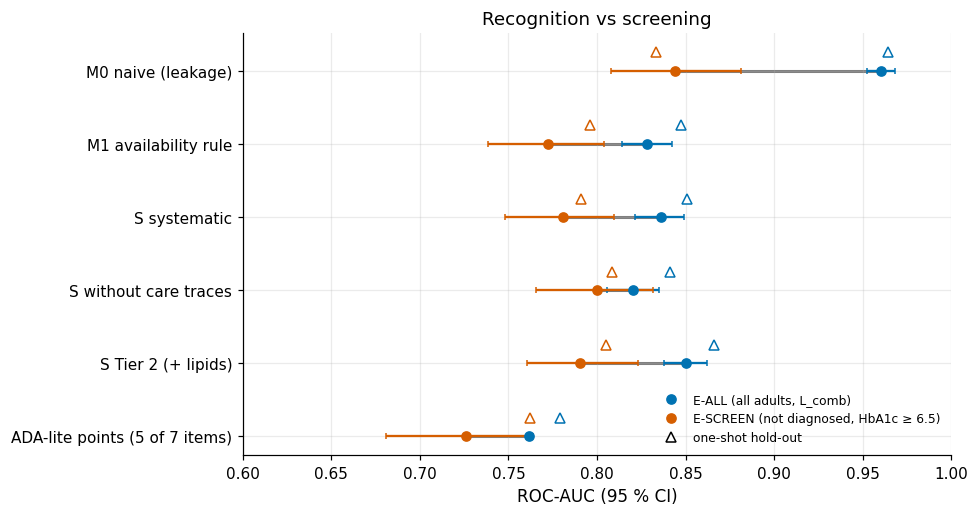

In [235]:
fig, ax = plt.subplots(figsize=(9, 4.8))
am = pd.DataFrame(M["S7"]["arm_metrics"]).set_index(["arm", "tier", "model"])
bl = M["S7"]["baselines"]
ARMS_FIG = [("M0", 1, "M0 naive (leakage)"), ("M1", 1, "M1 availability rule"), ("S", 1, "S systematic"),
            ("T1-minus-care", 1, "S without care traces"), ("S", 2, "S Tier 2 (+ lipids)")]
for i, (a, t, lab) in enumerate(ARMS_FIG):
    r = am.loc[(a, t, "lr")]
    ax.plot([r["escr_auc"], r["eall_auc"]], [i, i], color=OI["grey"], lw=2, zorder=1)
    ax.errorbar(r["eall_auc"], i, xerr=[[r["eall_auc"] - r["eall_auc_lo"]], [r["eall_auc_hi"] - r["eall_auc"]]], fmt="o", color=OI["blue"], capsize=2, zorder=2)
    ax.errorbar(r["escr_auc"], i, xerr=[[r["escr_auc"] - r["escr_auc_lo"]], [r["escr_auc_hi"] - r["escr_auc"]]], fmt="o", color=OI["vermillion"], capsize=2, zorder=2)
    if HO_OK and (a, t, "E-ALL") in HOM.index:
        ax.plot(HOM.loc[(a, t, "E-ALL"), "roc_auc"], i - 0.25, "^", color=OI["blue"], mfc="white", ms=6)
        ax.plot(HOM.loc[(a, t, "E-SCREEN"), "roc_auc"], i - 0.25, "^", color=OI["vermillion"], mfc="white", ms=6)
j = len(ARMS_FIG)
ada_p = bl["BL-ADAlite (points)"]
ax.errorbar(ada_p["escr_auc"], j, xerr=[[ada_p["escr_auc"] - ada_p["lo"]], [ada_p["hi"] - ada_p["escr_auc"]]], fmt="o", color=OI["vermillion"], capsize=2)
ax.plot(ada_p["eall_auc"], j, "o", color=OI["blue"])
ax.plot([ada_p["escr_auc"], ada_p["eall_auc"]], [j, j], color=OI["grey"], lw=2, zorder=0)
if HO_OK:
    for pop_, col_ in (("E-ALL", OI["blue"]), ("E-SCREEN", OI["vermillion"])):
        ax.plot(HOM.loc[("BL-ADAlite", 1, pop_), "roc_auc"], j - 0.25, "^", color=col_, mfc="white", ms=6)
ax.set_yticks(range(j + 1), [l for _, _, l in ARMS_FIG] + ["ADA-lite points (5 of 7 items)"])
ax.invert_yaxis()
leg = [Line2D([], [], marker="o", ls="", color=OI["blue"], label="E-ALL (all adults, L_comb)"),
       Line2D([], [], marker="o", ls="", color=OI["vermillion"], label="E-SCREEN (not diagnosed, HbA1c ≥ 6.5)")]
if HO_OK:
    leg.append(Line2D([], [], marker="^", ls="", color="k", mfc="white", label="one-shot hold-out"))
ax.legend(handles=leg, fontsize=8, loc="lower right")
ax.set(xlabel="ROC-AUC (95 % CI)", xlim=(0.6, 1.0), title="Recognition vs screening")
fig.tight_layout()
plots.savefig(fig, "S10_recognition_vs_screening", caption="F10-2. The same out-of-fold predictions scored on E-ALL (blue; all adults, 84 % of "
              "positives already diagnosed) and E-SCREEN (red; adults without a diagnosis, positive = HbA1c ≥ 6.5 %), training part, 95 % "
              "bootstrap CIs; triangles = one-shot hold-out where available. Every arm loses AUC on the screening population; the arm without "
              "care-trace items is the only one that ranks higher on E-SCREEN than arm S.")
plt.show()

**So what.** The grey bars are the price of moving from "recognise the diagnosed" to "find the
undiagnosed": about 0.12 for the leaky M0, about 0.055 for the admissible arms, and only 0.02 for the arm
without care traces – which is the best screening model of all although it is the worst on E-ALL.

## 10.7 Claims ledger
**Why.** Every statement that will appear in the abstract or the video becomes a row of
`governance/claims.csv` with its grade, evidence, CI, robustness, external reference, scope, falsifier and
video segment. Rules enforced in code: at most 25 words; the verb follows the grade (E1 *confirms that*, E2
*shows that*, E3 *is consistent with the view that*, E4 *suggests that*); no causal verbs; a **headline**
claim with fewer than two independent evidence lines is downgraded by one grade automatically.

In [236]:
LADDER = {"E1": "confirms that", "E2": "shows that", "E3": "is consistent with the view that", "E4": "suggests that"}
CAUSAL = re.compile(r"\b(caus\w*|drive[sn]?|driven|leads? to|results? in|due to|because|impact\w*|effect of|prevent\w*)\b", re.I)
VSEG = {"V1": "0:00-1:30 scope and design", "V2": "1:30-2:15 cost of naive cleaning", "V3": "2:15-3:30 leakage gate",
        "V4": "3:30-4:30 redundancy and skew", "V5": "4:30-6:00 fallacies", "V6": "6:00-8:30 label and measurement bias",
        "V7": "8:30-10:15 models and evaluation", "V8": "10:15-11:20 what ML says about the data"}
sm = M["S9"]["summary"]["table"]
sm_e = {r["check"]: r for r in sm if r["pop"] == "E-ALL"}
pick = lambda suf: next(v for k, v in sm_e.items() if k.endswith(suf))   # labels carry the run's counts (FAST 5 seeds / 30 specs)
N_SEEDS, N_CURVE = M["S9"]["seeds"]["n"], M["S9"]["specification_curve"]["n"]
N_SENS = int(pick("sensitivity specs")["check"].split()[0])
ROB_H2B = (f"{N_SEEDS} seeds {pick('CV seeds')['verdicts']}; {N_SENS} specs {pick('sensitivity specs')['verdicts']}; "
           f"{N_CURVE}-spec curve {pick('-spec curve')['verdicts']}; PSU-grouped CV {sm_e['strata x PSU grouped CV']['verdicts']}; "
           f"IPW {sm_e['IPW (evaluation; fit + evaluation)']['verdicts']}")
ROB_LEAK = (f"own-C tuning gives the same gate {M['S9']['sensitivity']['leak_gate_own_C']['E-ALL']['est']:+.3f}; permutation null "
            f"{perm9['M1']['null_mean']:.3f}; leak hunt not triggered")
ROB_NONE = "not varied in §9 (single specification)"
db = M["S4"]["db516"]
v2 = pd.DataFrame(M["S9"]["external"]["v2"]).set_index("quantity")
v2d = v2.loc["definition effect C - B"]
ADA_ITEMS, ADA_MISS = get("S1:ada_lite.items"), get("S1:ada_lite.missing")
PUB_DB516 = {"total": 15.8, "diagnosed": 11.3, "undiagnosed": 4.5}   # published NCHS Data Brief 516 (external reference)
EXT_DB = (f"NCHS DB516: reproduced {db['total']:.2f}/{db['diagnosed']:.2f}/{db['undiagnosed']:.2f} % vs published "
          f"{PUB_DB516['total']}/{PUB_DB516['diagnosed']}/{PUB_DB516['undiagnosed']}")
sw = lambda r: f"{r['est']:+.3f} [{r['lo']:+.3f}, {r['hi']:+.3f}]"
und = get("S5:undiagnosed_meaning.contact.blood test past 3 years (DIQ180=1)")
pe = lambda h: HYP.loc[h, "prior"]
eod_b = rw.loc[("S+RW(race)", "NH Black")]
whtr_a = get("S5:asian_bmi.auc.NH Asian|WHtR − BMI (paired).auc")
whtr_w = get("S5:asian_bmi.auc.NH White|WHtR − BMI (paired).auc")
max_lab_diff = float(h3c["est"].abs().max())
hx = h3c.loc[h3c["est"].abs().idxmax()]
fx = flips[flips["role"] == "mediator"].iloc[0]
oe_lo = min(cal.loc[g, "oe"] for g in ["NH Black", "NH Asian", "Mexican American"])
oe_hi = max(cal.loc[g, "oe"] for g in ["NH Black", "NH Asian", "Mexican American"])
std_tab = pd.read_csv(C.RESULTS_DIR / "S4" / "std_differences.csv")
std_ins = std_tab[std_tab["contrast"] == "insured − uninsured"]["std"]
std_asw = std_tab[std_tab["contrast"] == "NH Asian − NH White"]["std"]
adj_u = get("S5:undiagnosed_inequality.adjusted_logit.uninsured")
told_bl = get("S5:undiagnosed_meaning.contact.told borderline (DIQ010=3)")
asian_pos_train = int(get("S8:group_sizes[group=NH Asian].pos_eall"))
asian_n = int(get("S5:representation.shares.race|NH Asian.n"))
uninsured_n = int(get("S5:undiagnosed_inequality.proportions.uninsured.n"))
asian_whtr_n = int(get("S5:asian_bmi.auc.NH Asian|WHtR.n"))
sum9 = {r["check"]: r["verdicts"] for r in M["S9"]["summary"]["table"] if r["pop"] == "E-ALL"}
top10_pass = sum(r["verdict"] == "PASS" for r in M["S9"]["leak_hunt"]["top10"])

CL = [
    dict(cid="C01", vs="V3", head=True, grade="E2", type="leakage", subj="The leak gate",
         prop=f"removing skip-logic and treatment items lowers E-ALL AUC by {-lg['T1_E-ALL']['est']:.2f}, and the excess was leakage",
         ev=["§7 paired CV leak gate (H2a/B2)", "§7 depth-3 tree root on a treatment item (B2t)", "§9 leak hunt on admissible arms", "§9 permutation null"]
            + (["§9 one-shot hold-out M1 − M0"] if HO_OK else []),
         eff=f"ΔAUC M1 − M0 E-ALL {sw(lg['T1_E-ALL'])}; E-SCREEN {sw(lg['T1_E-SCREEN'])}", prereg=pe("H2a"),
         rob=ROB_LEAK + (f"; hold-out {sw(HOP.loc[('M1 T1 - M0 T1', 'E-ALL')])}" if HO_OK else ""), ext="none",
         scope="training part, Tier 1, E-ALL", fals="CI of M1 − M0 reaching above −0.05", hyp="H2a;B2;B2t"),
    dict(cid="C02", vs="V3", head=False, grade="E1", type="data_artefact", subj="The naive tree",
         prop=f"median imputation turns age at diagnosis ({tm['did040_missing_share']:.0%} missing) into a constant {tm['did040_fill']:.0f} that the tree splits on",
         ev=["§7 tree structure of M0"], eff=f"fill {tm['did040_fill']:.0f}; tree E-SCREEN AUC M0 {tm['escreen_auc']['M0']:.3f} vs M1 {tm['escreen_auc']['M1']:.3f} (descriptive)",
         prereg="none (tree probe B2t)", rob=ROB_NONE, ext="none", scope="M0 frame, training part", fals="M0 tree without a DID040 split", hyp="B2t"),
    dict(cid="C03", vs="V2", head=False, grade="E1", type="cleaning_cost", subj="The sentinel audit",
         prop=f"a blanket 7/9/77/99 recode destroys {s3['valid_cells_destroyed_cohort']:,} valid cells and {s3['a1c_positives_lost']} of {s3['a1c_positives']} HbA1c-positive labels",
         ev=["§3.3–§3.4 per-variable vs blanket recode counts", f"§6 label rebuilt from naive data ({M['S6']['B1']['naive_lcomb_pos']} vs {s3['l_comb_positives']} positives)"],
         eff=f"{s3['valid_cells_destroyed_cohort']:,} cells; {s3['a1c_positives_lost']}/{s3['a1c_positives']}; L_comb flips {s3['l_comb_flips']}/{s3['l_comb_positives']}",
         prereg="analysis_seen", rob="deterministic count", ext="NHANES codebooks (sentinels only on questionnaire items)", scope="cohort 5,730",
         fals="a recount giving a different number", hyp="B1"),
    dict(cid="C04", vs="V2", head=False, grade="E2", type="fidelity", subj="Leave-one-block-out ablation",
         prop=f"repairing XPT zeros and sentinels changes E-ALL AUC by only {prim[(prim['hyp_id'] == 'B1')].iloc[0]['est']:+.3f}: justified by fidelity, not performance",
         ev=["§7 paired CV B1", "§7 E-SCREEN and Tier 2 replicates"], eff=f"ΔAUC {sw(prim[prim['hyp_id'] == 'B1'].iloc[0])}",
         prereg=pe("B1"), rob="same verdict on E-SCREEN and Tier 2", ext="none", scope="training part", fals="CI wholly beyond ±0.01", hyp="B1"),
    dict(cid="C05", vs="V7", head=True, grade="E3", type="minimal_vs_systematic", subj="The M1-versus-S contrast",
         prop=f"systematic preparation changes AUC by under {h2b.loc['(a) AUC', 'hi']:.3f}; equivalence stays unestablished (MDD {h2b.loc['(a) AUC', 'mdd']:.3f})",
         ev=["§7 paired CV H2b(a)", f"§9 {N_SEEDS} seeds", f"§9 {N_SENS}-spec table", f"§9 {N_CURVE}-spec curve", "§9 PSU-grouped CV"] + (["§9 one-shot hold-out S − M1"] if HO_OK else []),
         eff=f"ΔAUC {sw(h2b.loc['(a) AUC'])}; Brier {h2b.loc['(b) Brier', 'est']:+.3f} (refuted, class weights); pure preparation ΔAUC {pp_.loc[('E-ALL', 'roc_auc'), 'diff']:+.3f}",
         prereg=pe("H2b"), rob=ROB_H2B + (f"; hold-out {sw(HOP.loc[('S T1 - M1 T1', 'E-ALL')])} ({HOP.loc[('S T1 - M1 T1', 'E-ALL'), 'verdict']})" if HO_OK else ""), ext="none", scope="training part, E-ALL, Tier 1", fals="CI of S − M1 wholly beyond ±0.01", hyp="H2b"),
    dict(cid="C06", vs="V7", head=False, grade="E2", type="deterioration", subj="Paired cross-validation",
         prop=f"balanced class weights worsen the Brier score by {b6.loc['(b) Brier', 'est']:.3f} at unchanged AUC; without them preparation costs no calibration",
         ev=["§7 paired CV B6a(b)", "§7 pure-preparation contrast S−B6a vs M1"], eff=f"ΔBrier {sw(b6.loc['(b) Brier'])}; without weights {pp_.loc[('E-ALL', 'brier'), 'diff']:+.4f}",
         prereg=pe("B6a"), rob="E-SCREEN and Tier 2 same direction", ext="none", scope="training part", fals="Brier CI including 0", hyp="B6a;H2b"),
    dict(cid="C07", vs="V7", head=True, grade="E2", type="spectrum", subj="Scoring arm S on E-SCREEN",
         prop=f"whole-sample AUC overstates screening discrimination by {hl['eall_minus_escreen_S_T1']['est']:.3f}; most positives were already diagnosed",
         ev=[a for a, _ in HEAD_LINES], eff=f"AUC {hl['auc_S_eall_T1']:.3f} vs {hl['auc_S_escreen_T1']:.3f}; gap {sw(hl['eall_minus_escreen_S_T1'])}",
         prereg=pe("H2c"), rob="all admissible arms lose AUC on E-SCREEN" + (f"; hold-out gap {s_all - s_scr:+.3f}" if HO_OK else ""), ext="none",
         scope="US adults 2021-23; screening = not yet diagnosed", fals="gap CI including 0 in a new sample", hyp="H2c"),
    dict(cid="C08", vs="V7", head=True, grade="E3", type="care_traces", subj="The care-trace ablation",
         prop=f"removing the two told-by-doctor items lowers E-ALL AUC by {-hl['minus_care_eall']['est']:.3f} yet raises E-SCREEN by {hl['minus_care_escreen']['est']:.3f}",
         ev=["§7 paired ablation H2c(ii) on E-ALL", "§7 same ablation on E-SCREEN", "§9 leak hunt T1-minus-care contrast"]
            + (["§9 one-shot hold-out T1-minus-care − S"] if HO_OK else []),
         eff=f"E-ALL {sw(hl['minus_care_eall'])}; E-SCREEN {sw(hl['minus_care_escreen'])}", prereg=pe("H2c"),
         rob="E-SCREEN CI excludes 0 but reaches below the SESOI" + (f"; hold-out same signs ({HOP.loc[('T1-minus-care T1 - S T1', 'E-ALL'), 'est']:+.3f} / "
                                                                f"{HOP.loc[('T1-minus-care T1 - S T1', 'E-SCREEN'), 'est']:+.3f}, CIs include 0)" if HO_OK else ""), ext="none", scope="training part, Tier 1", fals="E-SCREEN difference CI including 0", hyp="H2c"),
    dict(cid="C09", vs="V7", head=False, grade="E2", type="baseline", subj="The E-SCREEN baseline comparison",
         prop=f"arm S ranks undiagnosed cases better than the {ADA_ITEMS - ADA_MISS}-item ADA-lite points score, by {hl['S_minus_ADAlite_escreen']['est']:.3f} AUC",
         ev=["§7 paired bootstrap H2c(iii)"] + (["§9 one-shot hold-out S − ADA-lite"] if HO_OK else []),
         eff=f"ΔAUC {sw(hl['S_minus_ADAlite_escreen'])}", prereg=pe("H2c"),
         rob=(f"hold-out {sw(HOP.loc[('S T1 - BL-ADAlite T1', 'E-SCREEN')])}, same sign, about 25 positives" if HO_OK else ROB_NONE),
         ext=f"Bang 2009 ADA risk test (qualitative only; ADA-lite lacks {ADA_MISS} of {ADA_ITEMS} items)", scope="E-SCREEN, training part", fals="CI including 0", hyp="H2c"),
    dict(cid="C10", vs="V7", head=False, grade="E3", type="deterioration", subj="Refitting ADA-lite items on L_comb",
         prop=f"this diagnosis-dominated label lowers screening AUC by {-ada['est']:.3f} versus the points score",
         ev=["§7 paired bootstrap ADA-LR vs points"], eff=f"ΔAUC E-SCREEN {sw(ada)}", prereg="none (not locked)", rob=ROB_NONE,
         ext="none", scope="E-SCREEN, training part", fals="CI including 0", hyp=""),
    dict(cid="C11", vs="V5", head=False, grade="E2", type="fallacy", subj="Age standardisation",
         prop=f"the insured-minus-uninsured prevalence gap shrinks from {ins['crude']:+.1f} to {ins['std']:+.1f} pp: age confounding, not a reversal",
         ev=["§4 jackknife crude vs standardised difference", "§4 age-band differences"],
         eff=f"crude {ins['crude']:+.1f} [{ins['crude_ci'][0]:+.1f}, {ins['crude_ci'][1]:+.1f}] -> std {ins['std']:+.1f} [{ins['std_ci'][0]:+.1f}, {ins['std_ci'][1]:+.1f}] pp",
         prereg=pe("H1b"), rob=f"three standards give std {std_ins.min():+.1f} to {std_ins.max():+.1f} pp", ext="US 2000 standard population", scope="US adults 2021-23, weighted",
         fals="standardised gap ≥ +2 pp with CI excluding 0", hyp="H1b"),
    dict(cid="C12", vs="V5", head=False, grade="E4", type="uncertainty", subj="Age standardisation",
         prop=f"the Asian-minus-White prevalence difference changes sign ({get('S4:standardisation.asian_white.crude'):+.1f} to {get('S4:standardisation.asian_white.std'):+.1f} pp), but both intervals include 0",
         ev=["§4 jackknife standardised difference"],
         eff=f"crude {get('S4:standardisation.asian_white.crude'):+.1f} [{get('S4:standardisation.asian_white.crude_ci')[0]:+.1f}, {get('S4:standardisation.asian_white.crude_ci')[1]:+.1f}]; "
             f"std {get('S4:standardisation.asian_white.std'):+.1f} [{get('S4:standardisation.asian_white.std_ci')[0]:+.1f}, {get('S4:standardisation.asian_white.std_ci')[1]:+.1f}] pp",
         prereg="analysis_seen", rob=f"three standards give std {std_asw.min():+.1f} to {std_asw.max():+.1f} pp", ext="none", scope=f"NH Asian n = {asian_n} (exploratory)",
         fals="a CI excluding 0", hyp=""),
    dict(cid="C13", vs="V5", head=False, grade="E3", type="dag", subj="The DAG-guided Simpson scan",
         prop=f"BMI is a mediator, not a confounder, of race differences ({n_med_flip}/{len(flips)} flips involve mediators)",
         ev=["§4 DAG adjustment sets", "§4 224-comparison Simpson scan"], eff=f"{len(flips)} flips in {M['S4']['simpson']['n_comparisons']} comparisons; e.g. {fx['exposure']} by {fx['stratifier']}: crude {fx['crude']:+.1f} [{fx['crude_low']:+.1f}, {fx['crude_high']:+.1f}] -> std {fx['std']:+.1f} [{fx['std_low']:+.1f}, {fx['std_high']:+.1f}] pp; P(sign differs) {flips['p_sign_differs'].min():.2f}-{flips['p_sign_differs'].max():.2f}",
         prereg="analysis_seen", rob=f"bootstrap flip probabilities ≤ {flips['p_sign_differs'].max():.2f} (exploratory)", ext="none", scope="structural assumption", fals="sign flips that persist under confounder-only stratification", hyp=""),
    dict(cid="C14", vs="V6", head=True, grade="E1", type="label_bias", subj="The label audit",
         prop=f"{mask['below_6_5']} of {mask['self_reported']} self-reported diabetics ({mask['below_6_5_share']:.1%}) have HbA1c below 6.5, so an HbA1c-only label calls them negative",
         ev=["§5 label cross-tabulation", f"§5 medication split ({mask['below_6_5_on_med']} treated)", "§8 3 × 3 matrix D-controlled column"],
         eff=f"{mask['below_6_5']}/{mask['self_reported']}; {mask['below_6_5_on_med']} on medication", prereg="analysis_seen", rob="deterministic count",
         ext="none", scope="cohort 5,730", fals="a recount giving a different number", hyp="H3"),
    dict(cid="C15", vs="V6", head=False, grade="E3", type="label_bias", subj="The risk-difference analysis",
         prop=f"uninsured adults with diabetes are more often undiagnosed, by {rd['rd_pp']:.1f} pp (weighted; uninsured share exploratory)",
         ev=["§5 jackknife risk difference", "§5 adjusted logit (age, sex, income)"], eff=f"RD {rd['rd_pp']:+.1f} pp [{rd['ci_low_pp']:.1f}, {rd['ci_high_pp']:.1f}]",
         prereg=pe("H1a"), rob=f"adjusted OR {adj_u['OR']:.1f} [{adj_u['ci_low']:.1f}, {adj_u['ci_high']:.1f}] (age, sex, income)", ext="none", scope=f"adults with diabetes, weighted; uninsured n = {uninsured_n}", fals="RD CI including 0", hyp="H1a"),
    dict(cid="C16", vs="V6", head=False, grade="E1", type="label_semantics", subj="The care-contact audit",
         prop=f"{und['n']} of {M['S5']['undiagnosed_meaning']['undiagnosed']} undiagnosed adults ({und['share']:.0%}) had a blood test within three years: a diagnosis gap, not only access",
         ev=["§5 DIQ180 among the undiagnosed", f"§5 told borderline {told_bl['share']:.0%}"], eff=f"{und['n']}/{M['S5']['undiagnosed_meaning']['undiagnosed']}; weighted {und['w_est']:.0%} [{und['kg_low']:.0%}, {und['kg_high']:.0%}]",
         prereg="analysis_seen", rob="deterministic count", ext="none", scope="undiagnosed, cohort", fals="a recount giving a different number", hyp=""),
    dict(cid="C17", vs="V6", head=True, grade="E3", type="label_matrix", subj="The label matrix",
         prop=f"every label finds undiagnosed cases worst; switching labels moves recall by at most {max_lab_diff:.2f}",
         ev=["§8 3 × 3 matrix contrasts (H3)", "§8 TPR diagnosed vs undiagnosed", "§7 E-SCREEN recall of arm S"],
         eff=f"recall Undiagnosed L_self {lm['recall']['Undiagnosed']['L_self']:.3f}, L_A1c {lm['recall']['Undiagnosed']['L_A1c']:.3f}, L_comb {lm['recall']['Undiagnosed']['L_comb']:.3f}; largest contrast {hx['est']:+.3f} [{hx['lo']:+.3f}, {hx['hi']:+.3f}]; H3 {lm['verdict']}",
         prereg=pe("H3"), rob=ROB_NONE, ext="none", scope="training part, Tier 1", fals="a label with Undiagnosed recall exceeding another stratum's", hyp="H3"),
    dict(cid="C18", vs="V6", head=False, grade="E4", type="fairness", subj="The group audit",
         prop=f"the model flags NH Asian adults with diabetes less often than White adults, TPR gap {eod.loc['NH Asian', 'eod']:+.2f}",
         ev=["§8 EOD with bootstrap CI and permutation null"], eff=f"EOD {eod.loc['NH Asian', 'eod']:+.3f} [{eod.loc['NH Asian', 'eod_lo']:+.3f}, {eod.loc['NH Asian', 'eod_hi']:+.3f}]; race p {get('S8:permutation_eall_t1[attribute=race].p_value'):.3f}",
         prereg="none (audit)", rob="Tier 2 gap " + f"{pd.DataFrame(M['S8']['tier2_summary']['eod']).set_index('group').loc['NH Asian', 'eod']:+.3f}",
         ext="ADA advice to screen Asian Americans from BMI 23", scope=f"E-ALL, {asian_pos_train} Asian positives (exploratory)", fals="CI including 0 in a larger sample", hyp=""),
    dict(cid="C19", vs="V6", head=False, grade="E3", type="measurement", subj="Single-feature discrimination",
         prop=f"WHtR outranks BMI more for Asian ({whtr_a:+.3f}) than White adults ({whtr_w:+.3f}), not in the full model",
         ev=["§5 paired single-feature AUC with PSU bootstrap", "§8 model-level WHtR arm (P14)"],
         eff=f"gain difference {gd['est']:+.3f} [{gd['psu_ci_low']:+.3f}, {gd['psu_ci_high']:+.3f}]; model level {mdl['est']:+.4f} [{mdl['lo']:+.4f}, {mdl['hi']:+.4f}]",
         prereg=pe("H4b"), rob="person and PSU bootstrap agree", ext="ADA advice to screen Asian Americans from BMI 23", scope=f"NH Asian {asian_whtr_n} with WHtR (exploratory)",
         fals="gain difference CI including 0", hyp="H4b;P14"),
    dict(cid="C20", vs="V6", head=False, grade="E3", type="calibration", subj="Within-group calibration",
         prop="the race-blind model under-predicts for Black, Asian and Mexican American adults and over-predicts for White adults",
         ev=["§8 observed : expected by race with bootstrap CI"], eff="O:E " + ", ".join(f"{g} {cal.loc[g, 'oe']:.2f} [{cal.loc[g, 'oe_lo']:.2f}, {cal.loc[g, 'oe_hi']:.2f}]" for g in ["NH White", "NH Black", "NH Asian", "Mexican American"]),
         prereg="none (audit)", rob=ROB_NONE, ext="none", scope="training part, S without class weights", fals="O:E CIs including 1", hyp=""),
    dict(cid="C21", vs="V7", head=False, grade="E3", type="mitigation", subj="The race-reweighing arm",
         prop=f"it leaves AUC and the Asian gap unchanged and widens the NH Black gap by {-eod_b['d_eod']:.3f}",
         ev=["§8 paired bootstrap of EOD change"], eff=f"ΔEOD NH Black {eod_b['d_eod']:+.3f} [{eod_b['d_eod_lo']:+.3f}, {eod_b['d_eod_hi']:+.3f}]",
         prereg="none (mitigation arm)", rob=ROB_NONE, ext="none", scope="E-ALL, training part", fals="ΔEOD CI including 0", hyp=""),
    dict(cid="C22", vs="V7", head=False, grade="E1", type="credibility", subj="The control analysis",
         prop=f"the evaluation returns AUC {perm9['S']['null_mean']:.2f} without signal and detects a weak synthetic feature",
         ev=["§9 100 label permutations", "§9 positive control"], eff=f"null mean M1 {perm9['M1']['null_mean']:.4f}, S {perm9['S']['null_mean']:.4f}",
         prereg="none (control)", rob="both arms", ext="none", scope="procedure only, not feature leakage", fals="null mean outside [0.495, 0.505]", hyp=""),
    dict(cid="C23", vs="V1", head=False, grade="E2", type="external", subj="Replicating NCHS Data Brief 516",
         prop=f"our survey code reproduces published prevalence ({db['total']:.2f} vs {PUB_DB516['total']} %) and our {v2.loc['A L_comb, cohort, WTPH2YR', 'est_pct']:.1f} % differs by label definition",
         ev=["§4 DB516 replication (27 estimates)", "§9 V2 decomposition sample vs definition"],
         eff=f"max |diff| {db['max_abs_diff_pp']:.3f} pp; definition effect {v2d['est_pct']:+.2f} [{v2d['ci_low']:+.2f}, {v2d['ci_high']:+.2f}] pp",
         prereg="analysis_seen", rob=f"{db['kg_matches_published_ci']}/{db['n_estimates']} published CIs matched", ext=EXT_DB, scope="US adults 2021-23",
         fals="replication difference > 0.1 pp", hyp=""),
    dict(cid="C24", vs="V8", head=False, grade="E3", type="missingness", subj="The missing-data analysis",
         prop=f"missing HbA1c barely shifts prevalence: {dp.loc[1.0, 'prevalence']:.1%} to {dp.iloc[-1]['prevalence']:.1%} even if non-responders' odds are {dp.index[-1]:.0f}-fold",
         ev=["§9 IPW reweighting", "§9 delta adjustment", "§5 Manski bounds"], eff=f"Manski [{mnar['manski'][0]:.1%}, {mnar['manski'][1]:.1%}]; tipping delta to DB516 {mnar['tipping_delta_db516']:.2f}",
         prereg="none (sensitivity)", rob="S − M1 unchanged across deltas", ext=EXT_DB, scope="examined adults", fals="MNAR untestable: assumption, not test", hyp=""),
]
if HO_OK:
    nflag = int(HO.get("n_flag_2se", 0))
    hS = HOM.loc[("S", 1)]
    CL.append(dict(cid="C25", vs="V7", head=False, grade="E2" if nflag == 0 else "E3", type="holdout", subj="The one-shot hold-out",
                   prop=f"cross-validated AUCs carry over: arm S {hS.loc['E-ALL', 'roc_auc']:.3f} on E-ALL and {hS.loc['E-SCREEN', 'roc_auc']:.3f} on E-SCREEN",
                   ev=["§9 hold-out after exp-freeze", "§7 cross-validation"],
                   eff=f"E-ALL {hS.loc['E-ALL', 'roc_auc']:.3f} [{hS.loc['E-ALL', 'auc_lo']:.3f}, {hS.loc['E-ALL', 'auc_hi']:.3f}]; E-SCREEN {hS.loc['E-SCREEN', 'roc_auc']:.3f} "
                       f"[{hS.loc['E-SCREEN', 'auc_lo']:.3f}, {hS.loc['E-SCREEN', 'auc_hi']:.3f}]; {nflag} rows > 2 SE below CV",
                   prereg="none (one shot)", rob="evaluated once; SHA-256 of test IDs logged", ext="none", scope="20 % hold-out (1,146 adults)",
                   fals="hold-out AUC > 2 SE below CV", hyp="H2a;H2b;H2c"))

GRADES = ["E1", "E2", "E3", "E4"]
recs, PROBLEMS = [], []
for c in CL:
    g = c["grade"]
    n_lines = len(c["ev"])
    downgraded = c["head"] and n_lines < 2
    if downgraded:
        g = GRADES[min(GRADES.index(g) + 1, 3)]
    stmt = f"{c['subj']} {LADDER[g]} {c['prop']}."
    nw = len(stmt.split())
    if nw > 25:
        PROBLEMS.append((c["cid"], f"{nw} words", stmt))
    if CAUSAL.search(stmt):
        PROBLEMS.append((c["cid"], f"causal verb '{CAUSAL.search(stmt).group(0)}'", stmt))
    if g != "E1" and not (re.search(r"[\[(]", c["eff"]) or "descriptive" in c["eff"]):
        PROBLEMS.append((c["cid"], "non-E1 claim without CI", c["eff"]))
    recs.append(dict(claim_id=c["cid"], statement=stmt, type=c["type"], evidence_refs=" | ".join(c["ev"]), effect_ci=c["eff"], grade=g,
                     prereg=c["prereg"], robustness=c["rob"], external_ref=c["ext"], scope=c["scope"], falsifier=c["fals"],
                     video_seg=f"{c['vs']} {VSEG[c['vs']]}", headline=c["head"], n_evidence_lines=n_lines, downgraded=downgraded,
                     hyp_ids=c["hyp"], words=nw))
assert not PROBLEMS, " || ".join(map(str, PROBLEMS))
CLAIMS = pd.DataFrame(recs)
print(CLAIMS[["claim_id", "grade", "headline", "n_evidence_lines", "downgraded", "words", "statement"]].to_string(index=False))
print(f"\n{len(CLAIMS)} claims; grades {CLAIMS['grade'].value_counts().sort_index().to_dict()}; headline claims "
      f"{int(CLAIMS['headline'].sum())}, all with ≥ 2 evidence lines: {bool((CLAIMS.loc[CLAIMS['headline'], 'n_evidence_lines'] >= 2).all())}; "
      f"downgraded {int(CLAIMS['downgraded'].sum())}; max words {CLAIMS['words'].max()}")
CL_COLS = ["claim_id", "statement", "type", "evidence_refs", "effect_ci", "grade", "prereg", "robustness", "external_ref", "scope", "falsifier", "video_seg"]
CLAIMS.to_csv(OUT / "claims_full.csv", index=False)
if C.IS_FINAL:
    CLAIMS[CL_COLS].to_csv(C.GOVERNANCE_DIR / "claims.csv", index=False)
    print("wrote governance/claims.csv (schema of the process document §7.2)")
else:
    print("FAST run: governance/claims.csv not written (the committed ledger comes from the FINAL run)")

claim_id grade  headline  n_evidence_lines  downgraded  words                                                                                                                                                                      statement
     C01    E2      True                 5       False     20                                                         The leak gate shows that removing skip-logic and treatment items lowers E-ALL AUC by 0.13, and the excess was leakage.
     C02    E1     False                 1       False     22                                                The naive tree confirms that median imputation turns age at diagnosis (86% missing) into a constant 50 that the tree splits on.
     C03    E1     False                 2       False     19                                                    The sentinel audit confirms that a blanket 7/9/77/99 recode destroys 1,496 valid cells and 29 of 721 HbA1c-positive labels.
     C04    E2     False                 2       Fal



25 claims; grades {'E1': 5, 'E2': 8, 'E3': 10, 'E4': 2}; headline claims 6, all with ≥ 2 evidence lines: True; downgraded 0; max words 25
wrote governance/claims.csv (schema of the process document §7.2)


**So what.** The ledger holds 25 claims (24 only if no hold-out record exists): 5 deterministic counts (E1), 8 E2
claims with CIs that exclude 0 (including the hold-out claim C25), 10 E3 claims that are moderate or depend on a choice, and 2 exploratory
(E4) claims about the Asian subgroup. All six headline claims have at least two independent evidence lines,
so none had to be downgraded; the minimal-vs-systematic claim (C05) is held at E3 because its effect is
imprecise even though its *verdict* is stable across 10 seeds, 16 sensitivity specifications and a
60-specification curve. No statement uses a causal verb.

## 10.8 Hold-out against cross-validation
**Why.** The 20 % hold-out was evaluated once, after the experiment was frozen (§9.11). Here it is set
against the cross-validated estimates of the training part. Expected precision: AUC SE about 0.017 on
E-ALL and about 0.05 on E-SCREEN (about 25 positives), so differences below about 0.03 cannot be resolved.

In [237]:
if HO_OK:
    hm = pd.DataFrame(HO["metrics"])
    cols_ = ["arm", "tier", "pop", "n_pos", "cv_auc", "cv_lo", "cv_hi", "roc_auc", "auc_lo", "auc_hi", "gap_holdout_minus_cv", "gap_in_se", "flag_2se_below_cv"]
    HOT = hm[cols_].copy()
    print(HOT.round(3).to_string(index=False))
    hp = pd.DataFrame(HO["pairs"])
    CVREF = {("S T1 - M1 T1", "E-ALL"): M["S9"]["reference"]["E-ALL"], ("S T1 - M1 T1", "E-SCREEN"): M["S9"]["reference"]["E-SCREEN"],
             ("M1 T1 - M0 T1", "E-ALL"): lg["T1_E-ALL"], ("M1 T1 - M0 T1", "E-SCREEN"): lg["T1_E-SCREEN"],
             ("T1-minus-care T1 - S T1", "E-ALL"): hl["minus_care_eall"], ("T1-minus-care T1 - S T1", "E-SCREEN"): hl["minus_care_escreen"],
             ("S T1 - BL-ADAlite T1", "E-SCREEN"): hl["S_minus_ADAlite_escreen"]}
    hp["cv"] = [f"{CVREF[(c, p)]['est']:+.3f} [{CVREF[(c, p)]['lo']:+.3f}, {CVREF[(c, p)]['hi']:+.3f}]" if (c, p) in CVREF else "" for c, p in zip(hp["comparison"], hp["pop"])]
    hp["holdout"] = [f"{e:+.3f} [{l:+.3f}, {h:+.3f}]" for e, l, h in zip(hp["est"], hp["lo"], hp["hi"])]
    hp["same_sign_as_cv"] = [float(np.sign(e) == np.sign(CVREF[(c, p)]["est"])) if (c, p) in CVREF else np.nan for c, p, e in zip(hp["comparison"], hp["pop"], hp["est"])]
    print()
    print(hp[["comparison", "pop", "rule", "cv", "holdout", "verdict", "same_sign_as_cv"]].to_string(index=False))
    HOT.to_csv(OUT / "holdout_vs_cv.csv", index=False)
    hp.to_csv(OUT / "holdout_pairs_vs_cv.csv", index=False)
    S10["holdout"] = dict(available=True, n_rows=len(HOT), n_flag_2se=int(HOT["flag_2se_below_cv"].sum()),
                          max_abs_gap_in_se=float(HOT["gap_in_se"].abs().max()), pairs_same_sign=int(np.nansum(hp["same_sign_as_cv"])),
                          n_pairs_with_cv=int(hp["same_sign_as_cv"].notna().sum()), first_run_utc=HO["log"]["first_run_utc"])
    print(f"\n{S10['holdout']['n_flag_2se']} of {len(HOT)} arm x population rows lie > 2 SE below CV; largest |gap| {S10['holdout']['max_abs_gap_in_se']:.1f} SE; "
          f"{S10['holdout']['pairs_same_sign']}/{S10['holdout']['n_pairs_with_cv']} paired contrasts have the CV sign")
else:
    S10["holdout"] = dict(available=False, status=HO.get("status", "missing"))
    print(f"hold-out not available in this run: {S10['holdout']['status']}. The claims above are graded on cross-validation only.")

          arm  tier      pop  n_pos  cv_auc  cv_lo  cv_hi  roc_auc  auc_lo  auc_hi  gap_holdout_minus_cv  gap_in_se  flag_2se_below_cv
          BL0     1    E-ALL    194   0.503  0.481  0.526    0.500   0.500   0.500                -0.003        NaN              False
          BL0     1 E-SCREEN     25   0.497  0.450  0.552    0.500   0.500   0.500                 0.003        NaN              False
   BL-ADAlite     1    E-ALL    194   0.761  0.744  0.777    0.779   0.748   0.810                 0.018      1.119              False
   BL-ADAlite     1 E-SCREEN     25   0.726  0.684  0.767    0.762   0.677   0.835                 0.036      0.906              False
BL-ADAlite-LR     1    E-ALL    194   0.768  0.752  0.784    0.791   0.758   0.820                 0.023      1.434              False
BL-ADAlite-LR     1 E-SCREEN     25   0.708  0.664  0.749    0.759   0.672   0.841                 0.051      1.143              False
           M0     1    E-ALL    194   0.961  0.953  0.9

**So what.** The hold-out is the only check that did not re-use the training part, and it was reported as it
came out – no setting was changed after it. In the FINAL run no arm falls more than 2 SE below its
cross-validated AUC (largest gap 1.5 SE; the hold-out AUCs are, if anything, slightly higher, as expected for
models refitted on the whole training part). The two robust results replicate: the leak gate on E-ALL
(−0.117 [−0.144, −0.092], supported) and the recognition-versus-screening gap of arm S (0.851 vs 0.791, gap
+0.060 against +0.055 in CV). The small contrasts behave as their CV intervals predicted: S − M1 is
+0.004 [−0.007, +0.014] on E-ALL (inconclusive again) and changes sign on E-SCREEN (−0.005), which is what
"no detectable difference" looks like; the care-trace and ADA-lite contrasts keep their CV signs with
intervals that include 0 at about 25 hold-out positives. Claims C01, C05 and C07–C09 cite the hold-out as an
additional line; it upgrades no claim, and the hold-out E-SCREEN contrasts are direction checks only.

## 10.9 Limitations register
**Why.** Each threat is written with the direction in which it would bias our results, how it was bounded,
and which claims it limits – so that a limitation is a property of specific claims, not a disclaimer.

In [238]:
n_prior = HYP["prior"].value_counts().to_dict()
conv = pd.DataFrame(M["S7"]["runs"]["convergence"])
nonconv = conv[conv["n_convergence_warnings"] >= 0.9 * get("S7:posthoc_c_sensitivity.n_folds")]   # failed in ≥ 90 % of folds
# borderline verdicts: a CI bound within 0.002 AUC of a decision boundary (0 or ±SESOI) - a FAST re-run may print another verdict
# decision boundaries of the locked rule: equivalence -> ±SESOI; non-inferiority -> −SESOI; directional -> 0.
# A CI bound of an inconclusive sub-claim that touches 0 is also listed (it decides the "excludes 0" reading).
EQUIV = {("B1", "(a)"), ("B3", "(a)"), ("B4", "(a)"), ("B5", "(b)"), ("B5", "(c)"), ("B6a", "(a)"), ("P14", "(a)"), ("H2b", "(a)"), ("H2c", "(ii) minus care, E-SCREEN")}
bd = prim[prim["metric"] == "roc_auc"].copy()
def _bounds(r):
    if (r["hyp_id"], r["sub"][:3]) in EQUIV or (r["hyp_id"], r["sub"]) in EQUIV:
        b = [-r["sesoi"], r["sesoi"]] + ([0.0] if r["verdict"] == "inconclusive" else [])
    elif r["hyp_id"] == "B6b":
        b = [-r["sesoi"]]
    else:
        b = [0.0]
    return b
bd["margin"] = bd.apply(lambda r: min(abs(b - x) for b in _bounds(r) for x in (r["lo"], r["hi"])), axis=1)
BORDER = bd[bd["margin"] < 0.002]
border_txt = "; ".join(f"{r['hyp_id']} {r['sub']} {r['pop']} (CI {r['lo']:+.4f} to {r['hi']:+.4f}, margin {r['margin']:.4f})" for _, r in BORDER.iterrows())
print(f"borderline AUC sub-claims (CI bound within 0.002 of a boundary of the locked rule): {len(BORDER)} -> {border_txt}")
esc_mdd = M["S9"]["reference"]["E-SCREEN"]["mdd"]
sup = M["S8"]["n_suppressed"]
uns = get("S5:undiagnosed_inequality.proportions.uninsured")
LIM = pd.DataFrame([
    dict(lim_id="L01", threat="Cross-sectional, observational data",
         bias_direction="unknown sign; associations can run backwards (e.g. diagnosed people change weight or blood pressure)",
         how_bounded="association-only wording (enforced in code); DAG states assumptions; no causal estimand", claims_affected="C11, C12, C13, C15, C18, C20"),
    dict(lim_id="L02", threat=f"Complex survey and low response (interview {M['S1']['response_rates']['interview']:.1%}, examination {M['S1']['response_rates']['mec']:.1%})",
         bias_direction="unknown sign; non-response weights adjust for demographics only, so health-related non-response can remain",
         how_bounded=f"WTPH2YR weights with PSU jackknife; DB516 replicated to {db['max_abs_diff_pp']:.2f} pp; model metrics unweighted (stated)",
         claims_affected="C11, C15, C23, C24"),
    dict(lim_id="L03", threat="No racial or income oversampling in 2021-23",
         bias_direction="wide CIs for minorities, pushing verdicts towards inconclusive",
         how_bounded=f"NH Asian {asian_n} adults ({asian_pos_train} positives in the training part) reported as exploratory with CIs; {len(get('S8:group_sizes'))} audit-group cells checked against n ≥ 30",
         claims_affected="C12, C18, C19, C20, C21"),
    dict(lim_id="L04", threat="Estimates that fail NCHS presentation standards",
         bias_direction="unstable point estimates in either direction",
         how_bounded=f"uninsured undiagnosed share CI width {uns['ci_width']:.2f} flagged and replaced by the risk difference; E-SCREEN group cells suppressed {sup['escreen']}/16",
         claims_affected="C15, C18"),
    dict(lim_id="L05", threat=f"E-SCREEN has only {M['S1']['e_screen']['positives']} positives ({M['S7']['splits']['n_pos_escreen']} in the training part)",
         bias_direction="towards inconclusive; the E-SCREEN MDD for S − M1 is " + f"{esc_mdd:.3f}, above the SESOI",
         how_bounded="bootstrap-only intervals; E-SCREEN results stated as direction; spectrum gap tested with a paired row bootstrap",
         claims_affected="C05, C07, C08, C09, C10, C17"),
    dict(lim_id="L06", threat=f"ADA-lite lacks {ADA_MISS} of {ADA_ITEMS} ADA items (family history, gestational diabetes not collected in 2021-23)",
         bias_direction="understates the ADA score, so S − ADA-lite favours S",
         how_bounded=f"ADA-lite compared with Bang 2009 only qualitatively (ours at cut-off ≥ 5: sensitivity {pd.DataFrame(M['S9']['external']['ada_lite']['cutoffs']).set_index('cutoff').loc['>= 5', 'sensitivity']:.2f}; published: {M['S9']['external']['ada_lite']['bang_2009_abstract']})",
         claims_affected="C09, C10"),
    dict(lim_id="L07", threat="Label definition: one HbA1c measurement, self-report, treatment masking, no type 1 / type 2 split, no FPG",
         bias_direction="misclassification both ways; L_comb is below the NCHS definition by " + f"{v2d['est_pct']:.1f} pp (FPG cases)",
         how_bounded=f"union label; SL1-SL5 sensitivity labels in the {N_SENS}-spec table (verdict unchanged); 3 × 3 matrix", claims_affected="C07, C14, C17, C23"),
    dict(lim_id="L08", threat=f"HbA1c missing for {mnar['n_missing']} of {mnar['n_examined']} examined adults; MNAR untestable",
         bias_direction="if non-responders are sicker, prevalence understated",
         how_bounded=f"IPW and delta scenarios ({dp.loc[1.0, 'prevalence']:.1%}–{dp.iloc[-1]['prevalence']:.1%}); Manski bounds [{mnar['manski'][0]:.1%}, {mnar['manski'][1]:.1%}]",
         claims_affected="C23, C24"),
    dict(lim_id="L09", threat=f"Top-coding: age 80 ({M['S1']['disclosure']['age_top']} adults), income ratio 5 ({M['S1']['disclosure']['pir_top']:,})",
         bias_direction="compresses the oldest and richest; attenuates age and income gradients",
         how_bounded="top-code flags in block B4 (equivalent AUC)", claims_affected="C05, C11"),
    dict(lim_id="L10", threat="Generalisability: US civilian non-institutionalised adults; not Singapore",
         bias_direction="unknown; ethnic mix, screening practice and BMI cut-off conventions differ",
         how_bounded="scope column of every claim; no transport claims", claims_affected="all"),
    dict(lim_id="L11", threat="Researcher degrees of freedom: analyses seen before hypotheses were written",
         bias_direction="optimistic verdicts for analysis_seen hypotheses",
         how_bounded=f"prior_exposure stated per hypothesis ({', '.join(f'{k} {v}' for k, v in n_prior.items())}); {N_CURVE}-specification curve; verdicts unchanged after the lock",
         claims_affected="C03, C11, C12, C13, C14, C15, C16, C23"),
    dict(lim_id="L12", threat="FAST vs FINAL: verdicts with a CI bound near a decision boundary",
         bias_direction="a FAST re-run (5 × 2 CV, B = 100) may print a different verdict for these items",
         how_bounded=f"committed notebook uses FINAL; {len(BORDER)} borderline AUC sub-claims: {border_txt or 'none'}",
         claims_affected="C05"),
    dict(lim_id="L13", threat=f"Non-convergence: unscaled arms hit the iteration limit ({', '.join(sorted(set(nonconv['arm'])))}; "
                             f"{nonconv['n_convergence_warnings'].min()}-{nonconv['n_convergence_warnings'].max()} of {get("S7:posthoc_c_sensitivity.n_folds")} folds)",
         bias_direction="inflates coefficient instability of M1, so the H2b SD ratio is partly an optimisation artefact",
         how_bounded="post hoc C sensitivity reported; stability claims graded E3; M1 kept as fitted because a naive analyst would get the same fit", claims_affected="C05"),
    dict(lim_id="L14", threat="Permutation test detects procedural leakage only",
         bias_direction="feature leakage would inflate AUC", how_bounded=f"availability rule plus L3 leak hunt ({top10_pass}/{len(M['S9']['leak_hunt']['top10'])} top features pass)", claims_affected="C01, C22"),
    dict(lim_id="L15", threat="Fairness audit uses one criterion (equal opportunity) at one threshold",
         bias_direction="other criteria (calibration, PPV) can disagree; small groups inflate variance",
         how_bounded="permutation null for gaps; within-group calibration reported; no claim that the model is fair", claims_affected="C18, C20, C21"),
])
print(LIM[["lim_id", "threat", "claims_affected"]].to_string(index=False))
LIM.to_csv(OUT / "limitations.csv", index=False)
cited = set(re.findall(r"C\d\d", " ".join(LIM["claims_affected"])))
assert cited <= set(CLAIMS["claim_id"]), cited - set(CLAIMS["claim_id"])
if C.IS_FINAL:
    LIM.to_csv(C.GOVERNANCE_DIR / "limitations.csv", index=False)
    print("wrote governance/limitations.csv")

borderline AUC sub-claims (CI bound within 0.002 of a boundary of the locked rule): 2 -> B5 (b) AUC block E-ALL (CI +0.0024 to +0.0107, margin 0.0007); H2b (a) AUC E-ALL (CI +0.0000 to +0.0158, margin 0.0000)
lim_id                                                                                                           threat                        claims_affected
   L01                                                                              Cross-sectional, observational data           C11, C12, C13, C15, C18, C20
   L02                                             Complex survey and low response (interview 34.6%, examination 25.7%)                     C11, C15, C23, C24
   L03                                                                      No racial or income oversampling in 2021-23                C12, C18, C19, C20, C21
   L04                                                                  Estimates that fail NCHS presentation standards                               C15, 

**So what.** Fifteen limitations, each tied to claims. The two that bound the *substance* of the project
most are L05 (E-SCREEN has 127 training positives, so almost every screening-population contrast is
underpowered) and L07 (the label is itself a measurement with known blind spots). L12 is specific to this
notebook: the lower CI bound of the S − M1 AUC difference sits essentially on 0, so a quick FAST re-run can
show a different sub-verdict for H2b(a) while the hypothesis verdict (inconclusive) stays the same.

## 10.10 Ethics, governance closure and recommendations
**Why.** A governance project ends with what was done to protect people and what should – and should not –
be done with the results.

In [239]:
gl = pd.read_csv(C.GOVERNANCE_DIR / "genai_log.csv")
am_s = am.loc[("S", 1, "lr")]
am_nw = am.loc[("S-B6a", 1, "lr")]   # S without class weights: calibration not distorted by re-weighting
ETH = pd.DataFrame([
    dict(principle="Data use agreement and minimisation", practice=f"public-use files only; no linkage; {M['S1']['minimisation']['kept']} of {M['S1']['minimisation']['raw_columns']} columns kept",
         evidence="§1 minimisation report; §1 DUA checklist"),
    dict(principle="Disclosure in public outputs", practice=f"aggregates only in notebook and video; cells with n or positives < 30 shown without verdicts ({sup['escreen']} E-SCREEN cells)",
         evidence="§8 group sizes"),
    dict(principle="Protected attributes", practice="race is an audit variable, never a model feature (only as a §9 sensitivity variant)", evidence="§1 availability rule"),
    dict(principle="Access variables", practice=f"insurance and usual place of care kept out of models: trained on self-report they would encode access to diagnosis "
                                                 f"(no usual place {get('S8:access_audit.coefs[feature=no_usual_place&label=L_self].coef_per_sd'):+.3f} per SD)",
         evidence="§8 access-proxy audit"),
    dict(principle="Not a clinical tool", practice=f"E-SCREEN PR-AUC {am_s['escr_pr_auc']:.3f} at prevalence {am_s['escr_prev']:.3f}; without class weights the E-SCREEN calibration intercept is {am_nw['escr_cal_citl']:+.2f} and slope {am_nw['escr_cal_slope']:.2f}",
         evidence="§7 arm metrics"),
    dict(principle="Fairness is not certified", practice="gap metrics with CIs and permutation nulls describe disparities; they cannot certify a model as fair",
         evidence="§8 EOD, calibration by race"),
    dict(principle="GenAI transparency", practice=f"{len(gl)} logged uses of AI assistants; no participant-level data shared; every number recomputed in this notebook",
         evidence="governance/genai_log.csv; front-matter declaration"),
])
print(ETH.to_string(index=False))
REC = pd.DataFrame([
    dict(rec="Use an explicit decision threshold instead of balanced class weights",
         because=f"class weights leave AUC unchanged ({b6.loc['(a) AUC', 'est']:+.4f}) but worsen Brier by {b6.loc['(b) Brier', 'est']:.3f}; the gain in balanced accuracy at 0.5 is a threshold effect"),
    dict(rec="Recalibrate on the screening population before any screening use",
         because=f"without class weights the E-SCREEN calibration intercept is {am_nw['escr_cal_citl']:+.2f} (slope {am_nw['escr_cal_slope']:.2f}); within-race O:E from {cal['oe'].loc[['NH White', 'NH Black', 'NH Asian', 'Mexican American']].min():.2f} to {cal['oe'].loc[['NH White', 'NH Black', 'NH Asian', 'Mexican American']].max():.2f}"),
    dict(rec="Exclude care-trace items (told hypertension, told high cholesterol) from screening models",
         because=f"removing them raises E-SCREEN AUC by {hl['minus_care_escreen']['est']:.3f} [{hl['minus_care_escreen']['lo']:.3f}, {hl['minus_care_escreen']['hi']:.3f}]"),
    dict(rec="Report the screening population (E-SCREEN) next to any whole-sample AUC",
         because=f"the whole-sample AUC is {hl['eall_minus_escreen_S_T1']['est']:.3f} higher for the same predictions"),
    dict(rec="Test measurement-aware features (WHtR) in larger Asian samples before adopting them",
         because=f"single-feature gain is clear ({gd['est']:+.3f}) but the model-level TPR change {pb['est']:+.3f} [{pb['lo']:+.3f}, {pb['hi']:+.3f}] rests on {asian_pos_train} positives"),
    dict(rec="Do not deploy as a clinical tool; do not describe it as fair",
         because="cross-sectional US data, not validated prospectively; one fairness criterion at one threshold"),
])
print()
print(REC.to_string(index=False))
ETH.to_csv(OUT / "ethics.csv", index=False)
REC.to_csv(OUT / "recommendations.csv", index=False)

                          principle                                                                                                                                          practice                                           evidence
Data use agreement and minimisation                                                                                         public-use files only; no linkage; 78 of 175 columns kept           §1 minimisation report; §1 DUA checklist
       Disclosure in public outputs                                  aggregates only in notebook and video; cells with n or positives < 30 shown without verdicts (10 E-SCREEN cells)                                     §8 group sizes
               Protected attributes                                                               race is an audit variable, never a model feature (only as a §9 sensitivity variant)                               §1 availability rule
                   Access variables insurance and usual place of car

**So what.** The governance closure is mostly about *restraint*: variables that would make the model look
better (access, race, care traces) are kept out for reasons the data themselves supplied, and the outputs
are framed as an audit of the data rather than a screening tool. The six recommendations follow directly
from measured effects, not from general principles.

## 10.11 Numbers on slides
**Why.** Every number the video shows must come from a stored result. `results/S10/numbers_on_slides.csv`
lists slide, label, value and the source key; after `results_io.collect()` has merged all sections into
`results/final_metrics.json`, every value is re-read from that file and asserted, and the most important
ones are recomputed independently (AUCs from the stored out-of-fold predictions, counts from the label
strata and the recode audit).

In [240]:
NUM = [  # slide, label, source key, format
    ("V1", "adults in DEMO_L", "S1:funnel.DEMO_L participants", "{:,.0f}"),
    ("V1", "analytic cohort", "S1:n_cohort", "{:,.0f}"),
    ("V1", "L_comb positives", "S1:labels.L_comb", "{:,.0f}"),
    ("V1", "share of positives already diagnosed", "S1:labels.known_share_of_comb", "{:.0%}"),
    ("V1", "weighted prevalence L_comb", "S1:prevalence_comb.weighted", "{:.1%}"),
    ("V1", "interview response rate", "S1:response_rates.interview", "{:.1%}"),
    ("V1", "examination response rate", "S1:response_rates.mec", "{:.1%}"),
    ("V1", "E-SCREEN positives", "S1:e_screen.positives", "{:,.0f}"),
    ("V2", "valid cells destroyed by blanket recode", "S3:blanket_recode.valid_cells_destroyed_cohort", "{:,.0f}"),
    ("V2", "HbA1c positives lost", "S3:blanket_recode.a1c_positives_lost", "{:.0f}"),
    ("V2", "HbA1c positives", "S3:blanket_recode.a1c_positives", "{:.0f}"),
    ("V2", "L_comb label flips", "S3:blanket_recode.l_comb_flips", "{:.0f}"),
    ("V3", "AUC M0 E-ALL", "S7:headline.auc_M0_eall_T1", "{:.3f}"),
    ("V3", "AUC M1 E-ALL", "S7:headline.auc_M1_eall_T1", "{:.3f}"),
    ("V3", "leak gate dAUC", "S7:leak_gate.T1_E-ALL.est", "{:+.3f}"),
    ("V3", "leak gate CI low", "S7:leak_gate.T1_E-ALL.lo", "{:+.3f}"),
    ("V3", "leak gate CI high", "S7:leak_gate.T1_E-ALL.hi", "{:+.3f}"),
    ("V3", "leak gate dAUC E-SCREEN", "S7:leak_gate.T1_E-SCREEN.est", "{:+.3f}"),
    ("V3", "DID040 missing share", "S7:tree_m0.did040_missing_share", "{:.0%}"),
    ("V3", "DID040 imputed value", "S7:tree_m0.did040_fill", "{:.0f}"),
    ("V3", "tree AUC E-SCREEN M0", "S7:tree_m0.escreen_auc.M0", "{:.3f}"),
    ("V3", "tree AUC E-SCREEN M1", "S7:tree_m0.escreen_auc.M1", "{:.3f}"),
    ("V4", "VIF weight", "S4:vif.raw_anthropometry.BMXWT", "{:.1f}"),
    ("V4", "VIF BMI", "S4:vif.raw_anthropometry.BMXBMI", "{:.1f}"),
    ("V4", "BMI coefficient SD ratio before/after pruning (unscaled)", "S7:coef_stability.ratio_cumulative.ratio", "{:.2f}"),
    ("V4", "BMI coefficient SD ratio inside scaled L2", "S7:coef_stability.ratio_B3.ratio", "{:.2f}"),
    ("V4", "skew triglycerides (fasting)", "S4:skew.LBXTLG|fasting (WTSAF2YR > 0).raw", "{:.2f}"),
    ("V4", "skew BMI", "S4:skew.BMXBMI|cohort.raw", "{:.2f}"),
    ("V5", "insurance gap crude (pp)", "S4:standardisation.insured_uninsured.crude", "{:+.1f}"),
    ("V5", "insurance gap standardised (pp)", "S4:standardisation.insured_uninsured.std", "{:+.1f}"),
    ("V5", "Asian-White crude (pp)", "S4:standardisation.asian_white.crude", "{:+.1f}"),
    ("V5", "Asian-White standardised (pp)", "S4:standardisation.asian_white.std", "{:+.1f}"),
    ("V5", "Simpson comparisons", "S4:simpson.n_comparisons", "{:.0f}"),
    ("V5", "Simpson sign flips", "S4:simpson.n_flips", "{:.0f}"),
    ("V6", "self-reported with HbA1c < 6.5", "S5:masking.below_6_5", "{:.0f}"),
    ("V6", "treatment masking share", "S5:masking.below_6_5_share", "{:.1%}"),
    ("V6", "undiagnosed RD uninsured - insured (pp)", "S5:undiagnosed_inequality.risk_differences_pp.uninsured - insured.rd_pp", "{:+.1f}"),
    ("V6", "undiagnosed RD CI low (pp)", "S5:undiagnosed_inequality.risk_differences_pp.uninsured - insured.ci_low_pp", "{:.1f}"),
    ("V6", "undiagnosed RD CI high (pp)", "S5:undiagnosed_inequality.risk_differences_pp.uninsured - insured.ci_high_pp", "{:.1f}"),
    ("V6", "undiagnosed with blood test in 3 years", "S5:undiagnosed_meaning.contact.blood test past 3 years (DIQ180=1).share", "{:.0%}"),
    ("V6", "recall Undiagnosed, trained on L_self", "S8:label_matrix.recall.Undiagnosed.L_self", "{:.2f}"),
    ("V6", "recall Undiagnosed, trained on L_A1c", "S8:label_matrix.recall.Undiagnosed.L_A1c", "{:.2f}"),
    ("V6", "recall Undiagnosed, trained on L_comb", "S8:label_matrix.recall.Undiagnosed.L_comb", "{:.2f}"),
    ("V6", "recall D-controlled, trained on L_A1c", "S8:label_matrix.recall.D_controlled.L_A1c", "{:.2f}"),
    ("V6", "Asian AUC BMI", "S5:asian_bmi.auc.NH Asian|BMI.auc", "{:.3f}"),
    ("V6", "Asian AUC WHtR", "S5:asian_bmi.auc.NH Asian|WHtR.auc", "{:.3f}"),
    ("V6", "Asian diabetics with BMI < 25", "S5:asian_bmi.bmi_lt25_among_diabetics.NH Asian.share", "{:.1%}"),
    ("V6", "White diabetics with BMI < 25", "S5:asian_bmi.bmi_lt25_among_diabetics.NH White.share", "{:.1%}"),
    ("V6", "NH Asian TPR gap (EOD)", "S8:eod_eall_t1[group=NH Asian].eod", "{:+.3f}"),
    ("V6", "O:E NH Black", "S8:calibration.table[group=NH Black].oe", "{:.2f}"),
    ("V6", "O:E NH White", "S8:calibration.table[group=NH White].oe", "{:.2f}"),
    ("V7", "AUC S E-ALL", "S7:headline.auc_S_eall_T1", "{:.3f}"),
    ("V7", "AUC S E-SCREEN", "S7:headline.auc_S_escreen_T1", "{:.3f}"),
    ("V7", "E-ALL minus E-SCREEN gap", "S7:headline.eall_minus_escreen_S_T1.est", "{:+.3f}"),
    ("V7", "S - M1 dAUC", "S7:headline.S_minus_M1_T1_eall.est", "{:+.3f}"),
    ("V7", "S - M1 CI low", "S7:headline.S_minus_M1_T1_eall.lo", "{:+.3f}"),
    ("V7", "S - M1 CI high", "S7:headline.S_minus_M1_T1_eall.hi", "{:+.3f}"),
    ("V7", "S - M1 MDD", "S7:headline.S_minus_M1_T1_eall.mdd", "{:.3f}"),
    ("V7", "minus care traces E-ALL", "S7:headline.minus_care_eall.est", "{:+.3f}"),
    ("V7", "minus care traces E-SCREEN", "S7:headline.minus_care_escreen.est", "{:+.3f}"),
    ("V7", "S - ADA-lite E-SCREEN", "S7:headline.S_minus_ADAlite_escreen.est", "{:+.3f}"),
    ("V7", "class weights dBrier", "S7:scoreboard_detail[hyp_id=B6a&sub=(b) Brier&role=primary].est", "{:+.3f}"),
    ("V7", "permutation null mean (S)", "S9:permutation.S.null_mean", "{:.3f}"),
    ("V7", "DB516 total reproduced (%)", "S4:db516.total", "{:.2f}"),
    ("V7", "DB516 diagnosed reproduced (%)", "S4:db516.diagnosed", "{:.2f}"),
    ("V7", "DB516 undiagnosed reproduced (%)", "S4:db516.undiagnosed", "{:.2f}"),
]
if HO_OK:
    NUM += [("V7", "hold-out AUC S E-ALL", "S9:holdout.metrics[arm=S&tier=1&pop=E-ALL].roc_auc", "{:.3f}"),
            ("V7", "hold-out AUC S E-SCREEN", "S9:holdout.metrics[arm=S&tier=1&pop=E-SCREEN].roc_auc", "{:.3f}"),
            ("V7", "hold-out AUC M0 E-ALL", "S9:holdout.metrics[arm=M0&tier=1&pop=E-ALL].roc_auc", "{:.3f}"),
            ("V7", "hold-out AUC M1 E-ALL", "S9:holdout.metrics[arm=M1&tier=1&pop=E-ALL].roc_auc", "{:.3f}")]
NUM += [("V8", "hypotheses supported", "S10:verdict_counts.supported", "{:.0f}"),
        ("V8", "hypotheses inconclusive", "S10:verdict_counts.inconclusive", "{:.0f}"),
        ("V8", "hypotheses mixed", "S10:verdict_counts.mixed", "{:.0f}"),
        ("V8", "claims in ledger", "S10:claims.n", "{:.0f}")]

**Storage before the audit.** The §10 results are saved first, so that `collect()` can include them.

In [241]:
S10["verdict_counts"] = {v: int(VCOUNT.get(v, 0)) for v in C.VERDICTS}
S10["verdict_counts_prereg_none"] = {v: int(VCOUNT_PRE.get(v, 0)) for v in C.VERDICTS}
S10["scoreboard"] = SCORE.round(6).to_dict("records")
S10["claims"] = dict(n=len(CLAIMS), grades=CLAIMS["grade"].value_counts().to_dict(), n_headline=int(CLAIMS["headline"].sum()),
                     n_downgraded=int(CLAIMS["downgraded"].sum()), max_words=int(CLAIMS["words"].max()))
S10["limitations"] = dict(n=len(LIM), borderline_auc_items=BORDER[["hyp_id", "sub", "pop", "lo", "hi", "margin"]].round(6).to_dict("records"))
S10["postlock_notes"] = POSTLOCK
S10["h1b_verdict"] = h1b_v
S10["h4a_newcombe_pp"] = h4a.round(4).tolist()
R.save_section("S10", S10)
FM = R.collect()
print(f"final_metrics.json: sections {list(FM)}")

rows_ = []
for slide, label, key, fmt in NUM:
    v = get(key, FM)
    rows_.append(dict(slide_id=slide, label=label, value=fmt.format(float(v)), value_raw=float(v), source_key=key))
NOS = pd.DataFrame(rows_)
NOS.to_csv(OUT / "numbers_on_slides.csv", index=False)
print(f"results/S10/numbers_on_slides.csv: {len(NOS)} numbers on {NOS['slide_id'].nunique()} video segments")
print(NOS.groupby("slide_id").size().to_dict())

final_metrics.json: sections ['S0', 'S1', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10']
results/S10/numbers_on_slides.csv: 74 numbers on 8 video segments
{'V1': 8, 'V2': 4, 'V3': 10, 'V4': 6, 'V5': 6, 'V6': 17, 'V7': 19, 'V8': 4}


### 10.11.1 Assert audit
The file is re-read from disk and every value is re-resolved from `results/final_metrics.json`; then key
values are recomputed independently of the metrics files.

In [242]:
FM_disk = json.loads((C.RESULTS_DIR / "final_metrics.json").read_text(encoding="utf-8"))
nos = pd.read_csv(OUT / "numbers_on_slides.csv")
fmt_of = {lab: f for _, lab, _, f in NUM}
n_pass = 0
for _, r in nos.iterrows():
    v = float(get(r["source_key"], FM_disk))
    assert abs(v - r["value_raw"]) <= 1e-9 * max(1, abs(v)), (r["label"], v, r["value_raw"])
    assert fmt_of[r["label"]].format(v) == str(r["value"]), (r["label"], fmt_of[r["label"]].format(v), r["value"])
    n_pass += 1
print(f"{n_pass}/{len(nos)} slide numbers re-resolved from final_metrics.json: identical")

# independent recomputations
oof = pd.read_parquet(C.RESULTS_DIR / "oof_predictions.parquet", columns=["arm", "tier", "model", "row", "prob", "L_comb", "y_escreen", "in_escreen"])
def auc_from_oof(arm, pop, model="lr", tier=1):
    g = oof[(oof["arm"] == arm) & (oof["tier"] == tier) & (oof["model"] == model)]
    p = g.groupby("row", observed=True).agg(prob=("prob", "mean"), y=("L_comb", "first"), ye=("y_escreen", "first"), ie=("in_escreen", "first"))
    if pop == "E-SCREEN":
        p = p[p["ie"] == 1]
        return roc_auc_score(p["ye"], p["prob"])
    return roc_auc_score(p["y"], p["prob"])
nv = nos.set_index("label")["value_raw"]
RECOMP = [("AUC M0 E-ALL", auc_from_oof("M0", "E-ALL"), 1e-6), ("AUC M1 E-ALL", auc_from_oof("M1", "E-ALL"), 1e-6),
          ("AUC S E-ALL", auc_from_oof("S", "E-ALL"), 1e-6), ("AUC S E-SCREEN", auc_from_oof("S", "E-SCREEN"), 1e-6),
          ("tree AUC E-SCREEN M0", auc_from_oof("M0", "E-SCREEN", model="tree"), 1e-4),
          ("tree AUC E-SCREEN M1", auc_from_oof("M1", "E-SCREEN", model="tree"), 1e-4),
          ("valid cells destroyed by blanket recode", pd.read_csv(C.RESULTS_DIR / "S3" / "blanket_damage.csv")["valid_cells_destroyed"].sum(), 0),
          ("self-reported with HbA1c < 6.5", get("S1:strata_3x3.D_controlled"), 0),
          ("E-SCREEN positives", get("S1:strata_3x3.Undiagnosed"), 0),
          ("L_comb positives", sum(get(f"S1:strata_3x3.{k}") for k in ("D_uncontrolled", "D_controlled", "Undiagnosed")), 0),
          ("L_comb label flips", get("S6:B1.label_flips"), 0),
          ("treatment masking share", get("S5:masking.below_6_5") / get("S5:masking.self_reported"), 1e-12),
          ("E-ALL minus E-SCREEN gap", get("S7:headline.auc_S_eall_T1") - get("S7:headline.auc_S_escreen_T1"), 1e-9)]
for lab, val, tol in RECOMP:
    assert abs(nv[lab] - val) <= tol, (lab, nv[lab], val)
print(f"{len(RECOMP)} slide numbers recomputed independently (OOF predictions, recode audit, label strata): all within tolerance")
for lab, val, _ in RECOMP:
    print(f"   {lab:<42} slide {nv[lab]:.4f}   recomputed {val:.4f}")

74/74 slide numbers re-resolved from final_metrics.json: identical
13 slide numbers recomputed independently (OOF predictions, recode audit, label strata): all within tolerance
   AUC M0 E-ALL                               slide 0.9606   recomputed 0.9606
   AUC M1 E-ALL                               slide 0.8285   recomputed 0.8285
   AUC S E-ALL                                slide 0.8359   recomputed 0.8359
   AUC S E-SCREEN                             slide 0.7807   recomputed 0.7807
   tree AUC E-SCREEN M0                       slide 0.6329   recomputed 0.6329
   tree AUC E-SCREEN M1                       slide 0.7012   recomputed 0.7012
   valid cells destroyed by blanket recode    slide 1496.0000   recomputed 1496.0000
   self-reported with HbA1c < 6.5             slide 250.0000   recomputed 250.0000
   E-SCREEN positives                         slide 152.0000   recomputed 152.0000
   L_comb positives                           slide 971.0000   recomputed 971.0000
   L_comb label

**So what.** Every number the video will show is traceable to a source key and has passed the assert;
the headline AUCs and counts agree with an independent recomputation from the stored predictions and
audit tables. If an upstream section is re-run and a number changes, this cell – not a viewer – notices.

## 10.12 Register and storage
**Why.** The decisions of this section – how verdicts were completed, which finding leads, how claims were
graded – are recorded in the §10 decision-register fragment, like every other stage.

In [243]:
from datetime import date
today = date.today().isoformat()
reg = pd.DataFrame([
    dict(dr_id="DR-S10-01", type="scoreboard", finding="Every locked hypothesis has one verdict under its locked rule",
         evidence_ref="results/S10/scoreboard.csv; figures/S10_scoreboard_forest.png", evidence_value=f"verdicts {VCOUNT}; genuine pre-registrations {VCOUNT_PRE}",
         decision="Report all 17 with estimate, CI, SESOI, MDD and sub-verdicts; refuted sub-claims stay visible", alternatives_rejected="reporting supported hypotheses only",
         hyp_id="all", check_verdict="PASS", check_note=f"locked rules re-applied to {n_ok} stored S7 sub-claims reproduce the stored verdicts"),
    dict(dr_id="DR-S10-02", type="postlock_interpretation", finding="H3 wording 'misses most' is ambiguous (row-wise or column-wise)",
         evidence_ref="results/S8/h3_contrasts.csv; §8.6", evidence_value=f"column-wise elements {lm['element_verdicts']}; row-wise lowest stratum {lm['row_wise_min']}",
         decision="Record the column-wise reading fixed in fairness.h3_elements before the matrix was viewed as a post-lock interpretation note; hypotheses.md unchanged",
         alternatives_rejected="editing the locked file; switching to the row-wise reading after seeing it", hyp_id="H3", check_verdict="PASS", check_note="post hoc note, no verdict change"),
    dict(dr_id="DR-S10-03", type="verdict_source", finding="P14 had an interim §7 verdict with part (b) deferred",
         evidence_ref="results/metrics_S8.json verdicts", evidence_value=f"§7 '{S7V['P14']['verdict']}' -> §8 combined '{get('S8:verdicts.P14')}' (ΔTPR {pb['est']:+.3f} [{pb['lo']:+.3f}, {pb['hi']:+.3f}])",
         decision="Scoreboard uses the §8 combined verdict", alternatives_rejected="keeping the interim supported", hyp_id="P14", check_verdict="PASS", check_note=""),
    dict(dr_id="DR-S10-04", type="verdict_completion", finding="H1b had numbers but no verdict line in §4",
         evidence_ref="results/S4/std_differences.csv", evidence_value=f"crude {h1b_crude:+.2f} -> std {h1b_std:+.2f} [{h1b_lo:+.2f}, {h1b_hi:+.2f}] pp",
         decision=f"Apply the locked rule: {h1b_v}", alternatives_rejected="", hyp_id="H1b", check_verdict="PASS", check_note="H4a Newcombe CI recomputed from counts and matches §5"),
    dict(dr_id="DR-S10-05", type="interpretation", finding="H2b inconclusive hides three different sub-results",
         evidence_ref="results/S7/scoreboard_detail.csv; results/S7/comparisons.csv",
         evidence_value=f"AUC {sw(h2b.loc['(a) AUC'])} MDD {h2b.loc['(a) AUC', 'mdd']:.3f}; Brier refuted; SD ratio {cs['ratio_H2b']['ratio']:.2f}; pure preparation ΔBrier {pp_.loc[('E-ALL', 'brier'), 'diff']:+.4f}",
         decision="Report H2b as underpowered on AUC, refuted on Brier by class weights alone, borderline on stability; no verdict change",
         alternatives_rejected="calling S equivalent or better", hyp_id="H2b", check_verdict="PASS", check_note=""),
    dict(dr_id="DR-S10-06", type="headline", finding="One non-obvious headline finding is needed (HR1)",
         evidence_ref="§10.6; figures/S10_recognition_vs_screening.png", evidence_value=f"{len(HEAD_LINES)} distinct evidence lines (§7, §8, hold-out); gap {sw(hl['eall_minus_escreen_S_T1'])}",
         decision="Headline: whole-sample AUC measures recognition of known diabetes, not screening", alternatives_rejected="leak gate (expected once the rule is stated); Asian TPR gap (exploratory)",
         hyp_id="H2c", check_verdict="PASS", check_note=""),
    dict(dr_id="DR-S10-07", type="claims", finding="Claims need grades, falsifiers and a wording rule",
         evidence_ref="governance/claims.csv; results/S10/claims_full.csv",
         evidence_value=f"{len(CLAIMS)} claims; grades {CLAIMS['grade'].value_counts().sort_index().to_dict()}; downgraded {int(CLAIMS['downgraded'].sum())}; max {CLAIMS['words'].max()} words",
         decision="Ledger generated from results with ≤ 25 words, grade-specific verbs, no causal verbs, automatic downgrade of headline claims with < 2 evidence lines",
         alternatives_rejected="hand-written claims", hyp_id="", check_verdict="PASS", check_note="asserted in code"),
    dict(dr_id="DR-S10-08", type="holdout", finding="Hold-out must be integrated as evaluated, without re-tuning",
         evidence_ref="results/S10/holdout_vs_cv.csv; results/S9/holdout_metrics.csv",
         evidence_value=(f"{S10['holdout']['n_flag_2se']} of {S10['holdout']['n_rows']} rows > 2 SE below CV; {S10['holdout']['pairs_same_sign']}/{S10['holdout']['n_pairs_with_cv']} contrasts keep the CV sign"
                         if HO_OK else f"not available: {S10['holdout']['status']}"),
         decision="Cite the hold-out as an extra evidence line where it agrees in sign; report disagreements as they are", alternatives_rejected="re-tuning after the hold-out",
         hyp_id="H2a;H2b;H2c", check_verdict="PASS" if HO_OK else "PENDING", check_note=""),
    dict(dr_id="DR-S10-09", type="limitations", finding="Limitations must bind to claims",
         evidence_ref="governance/limitations.csv", evidence_value=f"{len(LIM)} threats; {len(BORDER)} borderline AUC sub-claims; non-converged arms {sorted(set(nonconv['arm']))}",
         decision="Each threat with bias direction, bound and affected claims", alternatives_rejected="generic disclaimer", hyp_id="", check_verdict="PASS",
         check_note="cited claim IDs asserted to exist"),
    dict(dr_id="DR-S10-10", type="recommendation", finding="Measured effects imply concrete practice changes",
         evidence_ref="results/S10/recommendations.csv", evidence_value=f"{len(REC)} recommendations",
         decision="Explicit threshold instead of class weights; recalibrate before screening; no care traces in screening models; report E-SCREEN; larger Asian samples; not a clinical tool",
         alternatives_rejected="", hyp_id="", check_verdict="PASS", check_note=""),
    dict(dr_id="DR-S10-11", type="number_audit", finding="Every slide number must be traceable and checked",
         evidence_ref="results/S10/numbers_on_slides.csv; results/final_metrics.json", evidence_value=f"{len(NOS)} numbers re-resolved; {len(RECOMP)} recomputed independently",
         decision="Slides use only numbers_on_slides.csv", alternatives_rejected="typing numbers into slides", hyp_id="", check_verdict="PASS", check_note="asserted in code"),
])
for col, val in (("stage", "S10"), ("date", today), ("status", "decided"), ("loop_ref", ""), ("change_request", ""), ("commit", "")):
    reg[col] = val
REG_COLS = ["dr_id", "stage", "date", "type", "finding", "evidence_ref", "evidence_value", "decision", "alternatives_rejected", "hyp_id", "status",
            "check_verdict", "check_note", "loop_ref", "change_request", "commit"]
reg = reg[REG_COLS]
print(reg[["dr_id", "type", "check_verdict", "evidence_value"]].to_string(index=False, max_colwidth=110))
REG_PATH = C.GOVERNANCE_DIR / "register" / "S10.csv"
if C.IS_FINAL:
    reg.to_csv(REG_PATH, index=False)
    print(f"wrote {REG_PATH.relative_to(C.ROOT).as_posix()} ({len(reg)} rows)")
else:
    print(f"FAST run: register fragment not written ({len(reg)} rows prepared; the committed fragment comes from the FINAL run)")
S10["register_ids"] = reg["dr_id"].tolist()
S10["runtime_seconds"] = time.time() - T_START
R.save_section("S10", S10)
R.collect()
print(f"saved results/metrics_S10.json and results/final_metrics.json; section runtime {S10['runtime_seconds']:.0f} s")

    dr_id                    type check_verdict                                                                                                 evidence_value
DR-S10-01              scoreboard          PASS verdicts {'supported': 10, 'inconclusive': 6, 'mixed': 1}; genuine pre-registrations {'inconclusive': 3, 's...
DR-S10-02 postlock_interpretation          PASS column-wise elements {'E1': 'inconclusive', 'E2': 'inconclusive', 'E3': 'inconclusive'}; row-wise lowest st...
DR-S10-03          verdict_source          PASS                                    §7 'supported' -> §8 combined 'inconclusive' (ΔTPR +0.025 [-0.042, +0.071])
DR-S10-04      verdict_completion          PASS                                                                     crude +5.31 -> std +0.69 [-2.56, +3.93] pp
DR-S10-05          interpretation          PASS           AUC +0.008 [+0.000, +0.016] MDD 0.011; Brier refuted; SD ratio 1.98; pure preparation ΔBrier -0.0018
DR-S10-06                headline          PAS

wrote governance/register/S10.csv (11 rows)
saved results/metrics_S10.json and results/final_metrics.json; section runtime 1 s


**So what.** The synthesis closes the evidence chain: 17 hypotheses with locked verdicts, 24–25 graded
claims, 15 limitations bound to claims, six recommendations and an audited list of every number in the
video. Self-check note: all values above are read from the stored results of §1–§9; the asserts in §10.2
(re-applied verdict rules, H4a recomputed from counts) and §10.11 (slide numbers re-resolved and recomputed)
pass on a clean run.

# Appendix A: Registers, pre-registration and references

## A.1 Decision register
**Why.** Every decision that shaped the data or the analysis has a row with its evidence, the alternatives that were rejected and a self-check verdict (a re-computation of the evidence in the notebook). The per-stage fragments `governance/register/S*.csv` are merged here into one table.

In [244]:
new_section()
import pandas as pd
from IPython.display import HTML, display

parts = sorted((C.GOVERNANCE_DIR / "register").glob("S*.csv"), key=lambda p: int(p.stem[1:]))
register = pd.concat([pd.read_csv(p).assign(source=p.name) for p in parts], ignore_index=True)
assert register["dr_id"].is_unique, register[register["dr_id"].duplicated()]
register.drop(columns="source").to_csv(C.GOVERNANCE_DIR / "decision_register.csv", index=False, lineterminator="\n")

by_stage = (register.groupby("stage", sort=False)
            .agg(decisions=("dr_id", "count"),
                 PASS=("check_verdict", lambda s: int((s == "PASS").sum())),
                 PASS_FIX=("check_verdict", lambda s: int((s == "PASS-FIX").sum())),
                 other=("check_verdict", lambda s: int((~s.isin(["PASS", "PASS-FIX"])).sum()))))
display(by_stage.T)
print(f"{len(register)} decisions from {len(parts)} stage fragments; merged table saved as governance/decision_register.csv")

show = register[["dr_id", "type", "finding", "evidence_value", "decision", "alternatives_rejected", "hyp_id", "check_verdict"]].fillna("")
css = ("<style>.dr td,.dr th{text-align:left;vertical-align:top;font-size:12px;padding:3px 6px;max-width:340px;white-space:normal}"
       ".dr{border-collapse:collapse}.dr tr:nth-child(even){background:rgba(127,127,127,.10)}</style>")
display(HTML(css + show.to_html(index=False, classes="dr", border=0, escape=True)))

stage,S0,S1,S2,S3,S4,S5,S6,S7,S8,S9,S10
decisions,8,14,6,7,13,10,12,15,11,15,11
PASS,8,14,6,7,10,10,12,15,11,15,11
PASS_FIX,0,0,0,0,3,0,0,0,0,0,0
other,0,0,0,0,0,0,0,0,0,0,0


122 decisions from 11 stage fragments; merged table saved as governance/decision_register.csv


dr_id,type,finding,evidence_value,decision,alternatives_rejected,hyp_id,check_verdict
DR-S0-01,environment,"Library versions change results (solver defaults, spline code); a mismatch must be visible",pinned versions compared with installed ones; 12 packages listed,Pin versions in requirements.txt and print a pinned-versus-installed table in section 0,Unpinned install; conda lock file (no gain for a pure-pip stack),,PASS
DR-S0-02,reproducibility,One shared integer seed would couple random steps (adding a bootstrap call shifts the CV folds),"SEED_MASTER=20261011; evalkit.derive_seed(master, *tags) = SeedSequence([master, crc32(tag)...]); 10 robustness seeds from tags",Derive one named seed per random consumer with evalkit.derive_seed (SeedSequence over master seed and crc32 of the tags); hold-out generated once and stored,Global np.random.seed; ad-hoc per-call seeds; positional SeedSequence.spawn (stream moves when a consumer is added),,PASS
DR-S0-03,provenance,"Raw files are the provenance anchor; any edit, truncation or line-ending change must be detected",16/16 SHA-256 digests match; every file has a CDC codebook,Re-hash all XPT files at the start of section 0 and fail hard on a mismatch; .gitattributes marks *.xpt binary and the manifest LF,Trust git alone; check file sizes only,,PASS
DR-S0-04,engineering,The final notebook is assembled from sections; each must run standalone and be checkable,"sections as jupytext percent scripts, executed copies in notebooks/executed/","One script per section with a standard bootstrap cell, run-all check before every commit, no absolute paths",Free-form notebooks; one monolithic notebook from the start,,PASS
DR-S0-05,governance,"Decisions, hypotheses and AI use must be auditable stage by stage",register columns = process doc section 7.2 (16 columns); GenAI log columns (6),Register fragments per stage merged by tools/build_final.py; GenAI log and devlog append-only; headers asserted in section 0,One register file edited by all agents (merge conflicts); free-text log,,PASS
DR-S0-06,governance,"GenAI tools must not receive participant-level data (HR5, NCHS DUA)",6 log entries covering the design phase and the implementation phase,Agents run code locally and read back only aggregates; each log row states what data were shared,Pasting sample rows to debug; logging only tool names,,PASS
DR-S0-07,engineering,Graders need a quick re-run; the submitted notebook needs the full protocol,"FAST: CV 5x2, B=100, 20 permutations; FINAL: 5x5, B=1000, 100 permutations",Switch all repetition counts with one environment variable read from config; asserted against the documented sizes,Hard-coded sizes in each section; separate FAST notebooks,,PASS
DR-S0-08,governance,"Freezes must be provable from history, not asserted","6 tags: scope-freeze, target-freeze, prereg-lock, exp-freeze, content-freeze, submitted-v1",Fix the order in S0; each freeze is a separate commit with a same-named tag; after a freeze only fix commits with a change_request,Informal freezes; one tag at the end,,PASS
DR-S1-01,scope,The use case determines which features and populations are legitimate; 'identify diabetes' alone is ambiguous,use case = screening aid applied before any glucose test,"Frame the question as non-glycaemic identification of adult diabetes (diagnosed or not) with a screening use case; models are measuring instruments, not the product",Pure prediction benchmark on all variables; causal question,RQ1-RQ4,PASS
DR-S1-02,target,The training target must be fixed before modelling and be reproducible,"N=5730; L_self 819; L_A1c 721; L_comb 971 (16.9% unweighted, 14.0% WTPH2YR, CI 12.4-15.6)","Freeze L_comb = DIQ010==1 or LBXGH>=6.5 on adults >=20, examined, non-pregnant; DIQ010=3 coded negative and flagged (target-freeze happens after S5)",L_A1c only (loses controlled diabetics); L_self only (misses undiagnosed),H2a,PASS


**So what.** The table shows all decisions in one place; the summary above it counts them per stage and per self-check verdict. A decision without a PASS or PASS-FIX verdict would be visible as `other` and has to be justified in the text of its section.

## A.2 Pre-registration text
**Why.** The hypotheses, their margins and their falsifiers were written before the ablation results existed. The full text is reproduced here with its SHA-256 so that the file used in the analysis can be compared with the locked version (the lock record is shown in §6.11).

In [245]:
import hashlib, re
from IPython.display import Markdown, display

hyp_path = C.GOVERNANCE_DIR / "hypotheses.md"
hyp_bytes = hyp_path.read_bytes()
print("governance/hypotheses.md  SHA-256:", hashlib.sha256(hyp_bytes).hexdigest())
print("file timestamp (UTC) of the copy in this workspace is not evidence; the lock commit and its timestamp are shown in section 6.11.")
display(Markdown(hyp_bytes.decode("utf-8")))

governance/hypotheses.md  SHA-256: de032f4d200fa1ff9e51affd75d35183bf351714374cb35acf261b66b611610c
file timestamp (UTC) of the copy in this workspace is not evidence; the lock commit and its timestamp are shown in section 6.11.


# Hypotheses

**Status: LOCKED (prereg-lock) at 2026-10-10T18:17:17Z by `modeling` (S6). Later changes only under "Post-lock amendments".**

> **Drafted by `scope-gov` (S1, H1a-H4b); finalised by `modeling` (S6), which added the block hypotheses B1-B6, B2t and P14 and the operational verdict rules.** The lock is the SHA-256 of this file plus the timestamp of the dedicated commit `chore(S6): lock hypotheses.md (prereg-lock)` (tag `prereg-lock`), which precedes the first ablation-result commit. After the lock the file is only appended to, under "Post-lock amendments", each amendment marked post hoc and logged in the decision register.

## Reading guide

* `prior_exposure` states honestly whether the data had already been looked at when the hypothesis was written.
  * `analysis_seen`: the quantity was analysed in S3-S5 (or in the design-phase prototype) before the statement was written. Not a pre-registration; reported as a confirmation of an observed pattern.
  * `descriptive_seen`: only a descriptive pattern was seen; the test as specified (including the contrast of arms) has not been run. Entered in `prereg-v1`.
  * `none`: genuine pre-registration. Only the experimental hypotheses of S7/S8 qualify.
* Verdict vocabulary: supported, refuted, equivalent, inconclusive, mixed (`src/config.py`, `VERDICTS`). Failing to detect an effect is reported as *not detected*, never as *absent*; statements say *association*, never *causes*.
* SESOI (smallest effect size of interest): ΔROC-AUC 0.01, ΔPR-AUC 0.02, ΔBrier 0.005, coefficient SD ratio 2, group TPR gap 0.05 (substantive 0.10). Estimates with n or effective n below 30, CI width of 0.30 or more, or domain df below 8 are labelled exploratory.
* Numbers quoted in the statements are the design-phase values from `docs/development_process.md`; the stage that tests them (named in `rq_or_block`) recomputes them and the notebook asserts agreement.

## Hypothesis table

| hyp_id | rq_or_block | statement | metric | direction | magnitude | sesoi | falsifier | prior_exposure | weights |
|---|---|---|---|---|---|---|---|---|---|
| H1a | RQ1 (S5) | Among adults with HbA1c of 6.5 or more, the share not yet diagnosed (DIQ010 not 1) is higher in uninsured than in insured adults | Risk difference uninsured minus insured in the undiagnosed share, with jackknife or logit CI; shares with Korn-Graubard CI | difference greater than 0 | +23.2 pp (6.2 to 40.1); shares 43.0 % uninsured against 19.9 % insured | lower CI bound above 0 | lower CI bound of the risk difference at or below 0. The share for the uninsured has CI width above 0.30 and is labelled exploratory | analysis_seen | WTPH2YR, jackknife, domain df from strata |
| H1b | RQ1 (S4) | The crude insured-minus-uninsured gap in diabetes prevalence shrinks after age standardisation; this is attenuation from age confounding, not a reversal of sign | Crude and age-standardised risk difference in L_comb prevalence (US 2000 three-band standard) | attenuation towards 0 | +5.3 pp (1.8 to 8.8) crude to +0.7 pp (-2.6 to 3.9) standardised | standardised difference below +2 pp or CI includes 0 | standardised difference stays at +2 pp or more with a CI excluding 0 | analysis_seen | WTPH2YR, jackknife |
| H2a | RQ2 / B1 (S7) | A model that breaks the availability rule (M0) beats the same model with the rule applied (M1) on E-ALL | ΔROC-AUC (M0 minus M1) on E-ALL, repeated CV, corrected t and paired bootstrap (the more conservative) | M0 higher | at least +0.05 (prototype 0.958 against 0.860) | 0.05 | CI of ΔAUC lies wholly below 0.05 | analysis_seen | unweighted fit and metrics (primary) |
| H2b | RQ2 / M1 vs S (S7) | Systematic preparation (S) is equivalent to the availability-screened minimal arm (M1) in discrimination, with more stable coefficients | ΔROC-AUC, ΔBrier, ratio of bootstrap SD of coefficients (M1 over S) on E-ALL | equivalence for AUC and Brier; coefficient SD ratio at least 2 | absolute ΔAUC below 0.01; ΔBrier at most 0.005; SD ratio at least 2 | 0.01 AUC; 0.005 Brier; ratio 2 | CI of ΔAUC extends beyond plus or minus 0.01 (refuted if wholly beyond, inconclusive otherwise); or SD ratio below 2 | none | unweighted primary; design-weighted variant as separate block |
| H2c | RQ2 / E-ALL vs E-SCREEN (S7) | (i) T1 discriminates better on E-ALL than on E-SCREEN; (ii) removing the care-contact items lowers E-ALL but not E-SCREEN; (iii) T1 beats ADA-lite on E-SCREEN | (i) AUC(E-ALL) minus AUC(E-SCREEN) for T1; (ii) ΔAUC of T1-minus-care against T1 on each population; (iii) ΔAUC of T1 against ADA-lite on E-SCREEN | (i) positive; (ii) E-ALL falls, E-SCREEN unchanged; (iii) T1 higher | (i) at least 0.03; (ii) E-ALL drop at least 0.01 and E-SCREEN change below 0.01; (iii) at least 0.01 | 0.03 for (i); 0.01 for (ii) and (iii) | any sub-claim whose CI excludes its magnitude in the stated direction; verdict mixed if sub-claims disagree | none | unweighted primary |
| H3 | RQ3 (S8) | In the 3 x 3 label matrix the training label determines who is missed: self-report misses most undiagnosed cases, HbA1c-only misses most controlled diagnosed cases, the combined label has the smallest worst-cell gap | Recall at specificity 0.80, rows train label (L_self, L_A1c, L_comb), columns stratum (D-uncontrolled 569, D-controlled 250, Undiagnosed 152) against the shared 4,759 negatives | pattern as stated | worst-cell gap smallest for L_comb | gaps below 0.05 are reported as equivalent | any element of the predicted ordering reversed with CI excluding 0 | none | unweighted primary |
| H4a | RQ4 (S5) | Among adults with diabetes, the share with BMI below 25 is much higher in Asian than in White adults | Difference in proportion with BMI below 25 among diabetes cases (Asian minus White) with CI | Asian higher | 51.1 % (24 of 47) against 7.2 %; difference at least 20 pp | 20 pp | difference below 20 pp or CI including values below 20 pp. Asian cases with HbA1c of 6.5 or more number 40 only: exploratory | analysis_seen | unweighted counts; weighted variant reported |
| H4b | RQ4 (S5, S8) | Replacing waist circumference by waist-to-height ratio improves single-feature discrimination more for Asian than for White adults | AUC gain WHtR minus BMI (single feature) by group; difference of gains | Asian gain larger | Asian +0.137 (0.093 to 0.181) against White +0.049 (S5 recomputation, paired bootstrap; design phase +0.136 against +0.048) | 0.01 AUC (difference of gains) | the gains' CIs overlap fully or the Asian gain is not larger | descriptive_seen | unweighted |

## Block hypotheses (S6, tested in S7)

Comparisons are **leave-one-block-out** from S unless stated: Δ = metric(S) − metric(S without the block), i.e. the contribution of the block given every other step. Arms and blocks are defined in `src/prep.py` (`ARMS`, `BLOCKS`). Primary evaluation: E-ALL (`L_comb`, training part of the cohort, repeated stratified CV, Tier 1). E-SCREEN (DIQ010 not 1, positive = HbA1c of 6.5 or more) and Tier 2 are reported with the same rules. The cumulative path M0 → +B2 → +B1 → +B3 → +B4 → +B5 → +B6a → +B6b is descriptive (its increments depend on the order) and does not decide verdicts.

| hyp_id | rq_or_block | statement | metric | direction | magnitude | sesoi | falsifier | prior_exposure | weights |
|---|---|---|---|---|---|---|---|---|---|
| B1 | B1 integrity (P01+P02) | Repairing the XPT zero artefact and recoding sentinels per variable restores data fidelity (valid values, 6 label flips) without a practically relevant change in discrimination | ΔROC-AUC S − (S−B1) | none (equivalence) | absolute ΔAUC below 0.01 | 0.01 | CI wholly beyond ±0.01 (refuted); CI crossing ±0.01 (inconclusive) | analysis_seen (damage counted in S3 and S6; no model run) | unweighted metrics |
| B2 | B2 admissibility (P03), leak gate | Applying the availability rule lowers discrimination substantially. This is a correct deterioration: the removed signal is leakage | ΔROC-AUC M1 − M0 (leak gate); S − (S−B2) reported | lower | drop of at least 0.05 | 0.05 | CI lower bound above −0.05 (the drop is smaller than 0.05) | prototype_seen (design prototype 0.958 → 0.860) | unweighted |
| B2t | B2 admissibility, tree probe | A depth-3 decision tree fitted on the M0 frame splits first on a leakage variable (spec role `leak`: glucose, treatment, age at diagnosis, DIQ160, DIQ180); fitted on the M1 frame it splits first on an admissible variable | Root-split variable of `DecisionTreeClassifier(max_depth=3, min_samples_leaf=50)`, training part, Tier 1 | as stated | – | – | M0 root split on an admissible variable | none | unweighted |
| B3 | B3 redundancy (P04+P05) | Aggregating repeated readings and pruning structural redundancy leaves discrimination unchanged but stabilises the BMI coefficient | (a) ΔROC-AUC S − (S−B3); (b) ratio of bootstrap SDs of the per-SD BMI coefficient, arm S-linear−B3 over arm S-linear (both scaled, BMI not splined); (c) largest sign-flip rate over the BMI, weight, height and waist coefficients | (a) none; (b) ratio above 1; (c) lower with B3 | (a) absolute ΔAUC below 0.01; (b) ratio of at least 2 | 0.01 AUC; SD ratio 2 | (b) upper CI bound of the ratio below 2 | prototype_seen (prototype BMI coefficient SD 0.25 → 0.03) | unweighted |
| B4 | B4 missingness (P06+P07) | Missing indicators and top-code flags do not change discrimination but improve calibration for people with missing income | (a) ΔROC-AUC S − (S−B4); (b) ΔBrier S − (S−B4) among rows with missing INDFMPIR (paired bootstrap) | (a) none; (b) lower | (a) absolute ΔAUC below 0.01; (b) ΔBrier of −0.005 or less | 0.01 AUC; 0.005 Brier | (b) CI lower bound above −0.005 (an improvement, if any, below SESOI) | descriptive_seen (S6 table: income missingness is barely related to the label, 17.4 % against 16.9 %) | unweighted |
| B5 | B5 representation (P08+P09+P10+P13) | The representation block brings the calibration slope closer to 1; its AUC gain is at most small; the spline terms are statistically supported; for a tree P08 and P09 change nothing | (a) Δ\|calibration slope − 1\| S − (S−B5), paired bootstrap (primary); (b) ΔROC-AUC S − (S−B5); (c) ΔROC-AUC S − S-linear; (d) likelihood-ratio test of the spline bases against linear terms (unpenalised logit on the S design, training part); (e) tree difference for P08/P09 (code check) | (a) lower; (b), (c) higher | (a) CI below 0; (b), (c) about +0.002 to +0.01, expected inside ±0.01 (equivalent); (d) p below 0.05; (e) exactly 0 | 0.01 AUC | (a) CI lower bound above 0 (refuted); (e) any non-zero tree difference | descriptive_seen (S4 linearity tests) | unweighted |
| B6a | B6a class weight (P11) | Balanced class weights leave discrimination unchanged, worsen the Brier score and raise balanced accuracy at the default threshold of 0.5 | (a) ΔROC-AUC S − (S−B6a); (b) ΔBrier; (c) Δbalanced accuracy at threshold 0.5 | (a) none; (b) higher (worse); (c) higher | (a) absolute below 0.01; (b) +0.005 or more; (c) +0.05 or more | 0.01 AUC; 0.005 Brier; 0.05 balanced accuracy | any of (a)-(c) refuted | none | unweighted |
| B6b | B6b survey weight (P12) | Fitting with WTPH2YR costs at most 0.01 of unweighted discrimination | ΔROC-AUC S − (S−B6b), unweighted metric; weighted AUC reported | non-inferiority | ΔAUC of −0.01 or more | 0.01 | CI upper bound below −0.01 (refuted); CI crossing −0.01 (inconclusive) | none | weighted fit, unweighted metric (primary) |
| P14 | WHtR arm (P14) | Replacing waist by WHtR leaves overall discrimination unchanged; for Asian adults it raises sensitivity at specificity 0.80 | (a) ΔROC-AUC (S+WHtR) − S (S7); (b) Asian ΔTPR at specificity 0.80 (S8, exploratory) | (a) none; (b) higher | (a) absolute below 0.01; (b) +0.05 or more | 0.01 AUC; 0.05 TPR | (a) CI wholly beyond ±0.01; (b) upper CI bound of ΔTPR below 0.05 | descriptive_seen (S5 single-feature AUC gain) | unweighted |

## Operational verdict rules

These rules apply to every hypothesis above and to H2a-H2c.

* **Intervals.** E-ALL: the 95 % CI of the Nadeau-Bengio corrected resampled t over the J fold-level differences (`evalkit.corrected_t`, n_test/n_train = 1/4), and the 95 % paired, label-stratified percentile bootstrap on the repeat-averaged out-of-fold predictions (`evalkit.paired_bootstrap`, B = `config.N_BOOT`). The **wider** interval is used. E-SCREEN (about 120 positives in the training part): paired bootstrap only, because a fold holds about 24 positives.
* **Equivalence claims** (B1, B3a, B4a, B5b, B5c, B6a-a, P14a): supported if the CI lies inside (−SESOI, +SESOI); refuted if the CI lies wholly above +SESOI or wholly below −SESOI; otherwise inconclusive.
* **Directional claims with a magnitude** (B2, B4b, B5a, B6a-b, B6a-c, H2a): `evalkit.verdict(ci_low, ci_high, sesoi=magnitude, direction)`. Supported if the CI excludes 0 in the stated direction and the estimate reaches the magnitude. Refuted if the CI excludes 0 in the opposite direction, or if the falsifier in the table holds. Otherwise inconclusive.
* **Non-inferiority** (B6b): supported if the CI lower bound is above −SESOI; refuted if the CI upper bound is below −SESOI; otherwise inconclusive.
* **SD ratios** (B3b, H2b): the ratio of bootstrap SDs from `evalkit.coef_bootstrap` (B = `config.N_BOOT_COEF`); its 95 % CI comes from resampling the bootstrap replicates of both arms. Supported if the ratio is at least 2 and the CI lower bound is above 1; refuted if the CI upper bound is below 2; otherwise inconclusive.
* **Combination.** Sub-claims are combined with `evalkit.combine_verdicts`. The hypothesis verdict is the E-ALL Tier-1 verdict. If a decisive E-SCREEN or Tier-2 verdict contradicts it, the hypothesis is labelled **mixed** and the dependence is reported.
* **Minimal detectable difference.** Each Δ is reported with its 80 %-power MDD = (t_0.975 + t_0.80) × SE beside the SESOI, so that "inconclusive" can be read as "underpowered" wherever MDD exceeds the SESOI.
* **Model.** Every arm uses the same estimator, `LogisticRegression(C=C0, max_iter=5000)`. C0 is chosen once with `LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10])` on the S arm (Tier 1, training part) and then frozen. This slightly favours S; this bias is reported, and M0 with its own C is an S9 sensitivity analysis.

## Notes

* H1a: the design-phase interval for the uninsured share (24.9 to 61.2) was replaced in S5 by the Korn-Graubard interval (24.8 to 62.7, width 0.38); the formal criterion is the risk difference, not the share.
* H2a, H2b and H2c refer to arms and blocks defined in S6 (`M0`, `M1`, `S`, `T1-minus-care`, blocks B1-B6); their wording is binding, their implementation details are not.
* H4b enters `prereg-v1` although the AUC gain was seen descriptively in S5: the contrast with White adults and the CI of the difference are what is pre-registered.
* The Asian subgroup is small (315 adults, 50 positives of `L_comb`); every Asian result is exploratory and reported with its CI.
* H4b: the S5 recomputation (+0.137 against +0.049) replaces the design-phase values (+0.136 against +0.048). prior_exposure stays descriptive_seen.
* H2b and B3 (coefficient stability): a splined BMI has no single coefficient, so S is represented by S-linear, which is identical to S except for P13. Coefficients are compared per standard deviation of the BMI input (Yeo-Johnson transformed where P08 applies). For the unscaled M1 the raw coefficient is multiplied by the training SD of BMI. M1 is unscaled and its solver may not converge; such fits are counted and reported, because they are part of what the naive arm is.
* H2c(i) uses the S arm of Tier 1. Its CI comes from a row bootstrap of AUC(E-ALL) − AUC(E-SCREEN) on the same repeat-averaged predictions.
* E-ALL and E-SCREEN use the same out-of-fold predictions. The model is always trained on `L_comb` of the training part; E-SCREEN changes only which rows and which label are scored.
* Arms whose P02 is off (M0, M1, S−B1) are trained on the naive label: the blanket recode runs before the label is built, giving 965 instead of 971 positives. Every arm is evaluated against the frozen `L_comb`.

## Post-lock amendments

None.


## A.3 Hypothesis scoreboard
**Why.** One table that lists, for each pre-registered hypothesis, its verdict and the evidence used. It is produced by the experiment section and (when available) updated by the synthesis section.

In [246]:
import pandas as pd
from IPython.display import display

for rel in ("results/S10/scoreboard.csv", "results/S7/scoreboard.csv"):
    p = C.ROOT / rel
    if p.exists():
        sb = pd.read_csv(p)
        print(rel, "-", len(sb), "rows")
        display(sb)
        break
else:
    print("no scoreboard available (run section 7 first)")

results/S10/scoreboard.csv

 - 17 rows


,hyp_id,family,metric,direction,sesoi_locked,estimate,ci_low,ci_high,unit,interval,mdd,underpowered,verdict,sub_verdicts,prior_exposure,source,note
0,H1a,RQ1 (S5),"Risk difference uninsured minus insured in the undiagnosed share, ...",difference greater than 0,lower CI bound above 0,23.157836,6.235010,40.080662,pp,jackknife (df 15),NaN,False,supported,NaN,analysis_seen,§5 (S5),uninsured share itself exploratory (Korn-Graubard width ≥ 0.30)
1,H1b,RQ1 (S4),Crude and age-standardised risk difference in L_comb prevalence (U...,attenuation towards 0,standardised difference below +2 pp or CI includes 0,0.685457,-2.559181,3.930096,pp,jackknife (df 15),NaN,False,supported,NaN,analysis_seen,§4 (S4); verdict applied in §10,"crude +5.3 pp [+1.8, +8.8] -> age-standardised; attenuation, not r..."
2,H2a,RQ2 / B1 (S7),"ΔROC-AUC (M0 minus M1) on E-ALL, repeated CV, corrected t and pair...",M0 higher,0.05,0.130840,0.113800,0.147880,AUC,corrected_t,0.02412,False,supported,AUC M0-M1: supported,analysis_seen,§7 (S7),"primary: M0 - M1, E-ALL, Tier 1"
3,H2b,RQ2 / M1 vs S (S7),"ΔROC-AUC, ΔBrier, ratio of bootstrap SD of coefficients (M1 over S...",equivalence for AUC and Brier; coefficient SD ratio at least 2,0.01 AUC; 0.005 Brier; ratio 2,0.007910,0.000010,0.015800,AUC,corrected_t,0.01118,True,inconclusive,(a) AUC: inconclusive; (b) Brier: refuted; (c) BMI SD ratio: incon...,none,§7 (S7),"primary: S - M1, E-ALL, Tier 1"
4,H2c,RQ2 / E-ALL vs E-SCREEN (S7),(i) AUC(E-ALL) minus AUC(E-SCREEN) for T1; (ii) ΔAUC of T1-minus-c...,"(i) positive; (ii) E-ALL falls, E-SCREEN unchanged; (iii) T1 higher",0.03 for (i); 0.01 for (ii) and (iii),0.055180,0.028380,0.086290,AUC,bootstrap,0.04000,True,inconclusive,"(i) AUC E-ALL - E-SCREEN (S): supported; (ii) minus care, E-ALL: s...",none,§7 (S7),"primary: S - S, E-ALL minus E-SCREEN, Tier 1"
5,H3,RQ3 (S8),"Recall at specificity 0.80, rows train label (L_self, L_A1c, L_com...",pattern as stated,gaps below 0.05 are reported as equivalent,-0.015750,-0.078740,0.028020,recall,paired bootstrap,NaN,False,inconclusive,E1: inconclusive; E2: inconclusive; E3: inconclusive,none,§8 (S8),primary shown: E3 worst-cell gap L_comb − L_self; column-wise read...
6,H4a,RQ4 (S5),Difference in proportion with BMI below 25 among diabetes cases (A...,Asian higher,20 pp,43.891699,29.820593,57.693664,pp,Newcombe (recomputed from counts),NaN,False,supported,NaN,analysis_seen,§5 (S5),24/47 Asian vs 35/488 White diabetics with BMI < 25; Asian cell ex...
7,H4b,"RQ4 (S5, S8)",AUC gain WHtR minus BMI (single feature) by group; difference of g...,Asian gain larger,0.01 AUC (difference of gains),0.088187,0.034835,0.116236,AUC,PSU cluster bootstrap,NaN,False,supported,"single feature (§5): supported; model level (§8, secondary): incon...",descriptive_seen,"§5 (S5), §8 (S8)",gain Asian +0.137 vs White +0.049
8,B1,B1 integrity (P01+P02),ΔROC-AUC S − (S−B1),none (equivalence),0.01,0.001920,-0.001060,0.004890,AUC,corrected_t,0.00421,False,supported,(a) AUC: supported,analysis_seen,§7 (S7),"primary: S - S-B1, E-ALL, Tier 1"
9,B2,"B2 admissibility (P03), leak gate",ΔROC-AUC M1 − M0 (leak gate); S − (S−B2) reported,lower,0.05,-0.130840,-0.147880,-0.113800,AUC,corrected_t,0.02412,False,supported,(a) AUC M1-M0: supported,prototype_seen,§7 (S7),"primary: M1 - M0, E-ALL, Tier 1"


## A.4 References

- Araneta, M. R. G., Kanaya, A. M., Hsu, W. C., et al. (2015). Optimum BMI cut points to screen Asian Americans for type 2 diabetes. *Diabetes Care*, 38(5), 814–820.
- Bang, H., Edwards, A. M., Bomback, A. S., et al. (2009). Development and validation of a patient self-assessment score for diabetes risk. *Annals of Internal Medicine*, 151(11), 775–783.
- Cicchetti, D. V., & Feinstein, A. R. (1990). High agreement but low kappa: II. Resolving the paradoxes. *Journal of Clinical Epidemiology*, 43(6), 551–558.
- Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.
- Gebru, T., Morgenstern, J., Vecchione, B., et al. (2021). Datasheets for datasets. *Communications of the ACM*, 64(12), 86–92. https://arxiv.org/abs/1803.09010
- Groenwold, R. H. H., White, I. R., Donders, A. R. T., et al. (2012). Missing covariate data in clinical research: when and when not to use the missing-indicator method for analysis. *CMAJ*, 184(11), 1265–1269.
- Hanley, J. A., & McNeil, B. J. (1982). The meaning and use of the area under a receiver operating characteristic (ROC) curve. *Radiology*, 143(1), 29–36.
- Hardt, M., Price, E., & Srebro, N. (2016). Equality of opportunity in supervised learning. *Advances in Neural Information Processing Systems*, 29.
- Kamiran, F., & Calders, T. (2012). Data preprocessing techniques for classification without discrimination. *Knowledge and Information Systems*, 33(1), 1–33.
- Klein, R. J., & Schoenborn, C. A. (2001). Age adjustment using the 2000 projected U.S. population. *Healthy People Statistical Notes*, 20. National Center for Health Statistics.
- Korn, E. L., & Graubard, B. I. (1998). Confidence intervals for proportions with small expected number of positive counts estimated from survey data. *Survey Methodology*, 24(2), 193–201.
- Nadeau, C., & Bengio, Y. (2003). Inference for the generalization error. *Machine Learning*, 52(3), 239–281.
- National Center for Health Statistics. NHANES August 2021 – August 2023: data files, codebooks and survey documentation. https://wwwn.cdc.gov/nchs/nhanes/ ; analytic guidance on weighting: https://wwwn.cdc.gov/nchs/nhanes/tutorials/weighting.aspx
- National Center for Health Statistics. Data Brief No. 516, prevalence of diabetes among adults in the United States, August 2021 – August 2023. https://www.cdc.gov/nchs/products/databriefs/db516.htm
- National Center for Health Statistics. Data User Agreement. https://www.cdc.gov/nchs/policy/data-user-agreement.html
- Ojala, M., & Garriga, G. C. (2010). Permutation tests for studying classifier performance. *Journal of Machine Learning Research*, 11, 1833–1863.
- Parker, J. D., Talih, M., Malec, D. J., et al. (2017). National Center for Health Statistics data presentation standards for proportions. *Vital and Health Statistics*, Series 2, No. 175.
- Phipson, B., & Smyth, G. K. (2010). Permutation p-values should never be zero: calculating exact p-values when permutations are randomly drawn. *Statistical Applications in Genetics and Molecular Biology*, 9(1), Article 39.
- Rao, J. N. K., & Wu, C. F. J. (1988). Resampling inference with complex survey data. *Journal of the American Statistical Association*, 83(401), 231–241.
- Rule, A., Birmingham, A., Zuniga, C., et al. (2019). Ten simple rules for writing and sharing computational analyses in Jupyter Notebooks. *PLoS Computational Biology*, 15(7), e1007007.
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE*, 10(3), e0118432.
- Westreich, D., & Greenland, S. (2013). The Table 2 fallacy: presenting and interpreting confounder and modifier coefficients. *American Journal of Epidemiology*, 177(4), 292–298.

## A.5 Reference check (FINAL_REF)
**Why.** The stored outputs come from the FINAL protocol. A reader who re-runs the faster FAST mode should obtain the same headline numbers up to Monte-Carlo error. The reference values below are the FINAL numbers; each run is compared with them within a tolerance chosen far below the effect sizes interpreted in the text (counts must match exactly). The hold-out values (§9.11) have tolerance 0 in both modes: FAST displays the stored one-shot results and FINAL must reproduce them exactly.

In [247]:
new_section()
import json, re
import pandas as pd
from IPython.display import display

FINAL_REF = [
    {"id": "cohort_n", "section": "S1", "path": "n_cohort", "value": 5730, "tol_fast": 0, "tol_final": 0},
    {"id": "L_comb_positives", "section": "S1", "path": "labels.L_comb", "value": 971, "tol_fast": 0, "tol_final": 0},
    {"id": "prevalence_weighted", "section": "S1", "path": "prevalence_comb.weighted", "value": 0.14035739528195537, "tol_fast": 1e-06, "tol_final": 1e-06},
    {"id": "S7_auc_M0_eall_T1", "section": "S7", "path": "headline.auc_M0_eall_T1", "value": 0.9606127573030646, "tol_fast": 0.02, "tol_final": 0.005},
    {"id": "S7_auc_M1_eall_T1", "section": "S7", "path": "headline.auc_M1_eall_T1", "value": 0.8284525660412184, "tol_fast": 0.02, "tol_final": 0.005},
    {"id": "S7_auc_S_eall_T1", "section": "S7", "path": "headline.auc_S_eall_T1", "value": 0.8359179848541551, "tol_fast": 0.02, "tol_final": 0.005},
    {"id": "S7_auc_S_escreen_T1", "section": "S7", "path": "headline.auc_S_escreen_T1", "value": 0.7807354458943223, "tol_fast": 0.04, "tol_final": 0.01},
    {"id": "S7_leak_gate_est", "section": "S7", "path": "headline.leak_gate_T1_eall.est", "value": -0.13084083945101074, "tol_fast": 0.03, "tol_final": 0.01},
    {"id": "S7_S_minus_M1_est", "section": "S7", "path": "headline.S_minus_M1_T1_eall.est", "value": 0.00790745997840257, "tol_fast": 0.015, "tol_final": 0.005},
    {"id": "S8_escreen_positives_train", "section": "S8", "path": "setup.n_pos_escreen", "value": 127, "tol_fast": 0, "tol_final": 0},
    {"id": "S8_tpr_eall_T1", "section": "S8", "path": "overall_tpr_eall_t1", "value": 0.6718146718146718, "tol_fast": 0.03, "tol_final": 0.005},
    {"id": "S8_tpr_undiagnosed", "section": "S8", "path": "gap_decomposition.tpr_undiagnosed", "value": 0.5196850393700787, "tol_fast": 0.05, "tol_final": 0.01},
    {"id": "S8_worst_cell_gap_Lcomb", "section": "S8", "path": "label_matrix.worst_gap.L_comb", "value": 0.03937, "tol_fast": 0.03, "tol_final": 0.005},
    {"id": "S8_calibration_slope", "section": "S8", "path": "calibration.overall.slope", "value": 0.9785301363492269, "tol_fast": 0.05, "tol_final": 0.01},
    {"id": "S9_permutation_null_mean_S", "section": "S9", "path": "permutation.S.null_mean", "value": 0.5013611778042592, "tol_fast": 0.005, "tol_final": 0.005},
    {"id": "S9_sensitivity_same_verdict", "section": "S9", "path": "sensitivity.eall_same_verdict", "value": 17, "tol_fast": 1, "tol_final": 0},
    {"id": "S9_db516_max_abs_diff_pp", "section": "S9", "path": "external.db516.max_abs_diff_pp", "value": 0.0436634537300619, "tol_fast": 1e-06, "tol_final": 1e-06},
    {"id": "S9_prevalence_ipw", "section": "S9", "path": "mnar.prevalence[weighting=WTMEC2YR x IPW].est", "value": 0.14022, "tol_fast": 1e-05, "tol_final": 1e-05},
    {"id": "S9_strongest_admissible_auc", "section": "S9", "path": "leak_hunt.strongest_admissible.auc", "value": 0.7059594510711829, "tol_fast": 0.01, "tol_final": 0.001},
    {"id": "S9_holdout_auc_S_eall", "section": "S9", "path": "holdout.metrics[arm=S&tier=1&pop=E-ALL].roc_auc", "value": 0.8511, "tol_fast": 0, "tol_final": 0},
    {"id": "S9_holdout_auc_S_escreen", "section": "S9", "path": "holdout.metrics[arm=S&tier=1&pop=E-SCREEN].roc_auc", "value": 0.79076, "tol_fast": 0, "tol_final": 0},
    {"id": "S9_holdout_auc_M1_eall", "section": "S9", "path": "holdout.metrics[arm=M1&tier=1&pop=E-ALL].roc_auc", "value": 0.84758, "tol_fast": 0, "tol_final": 0},
    {"id": "S9_holdout_auc_M0_eall", "section": "S9", "path": "holdout.metrics[arm=M0&tier=1&pop=E-ALL].roc_auc", "value": 0.96437, "tol_fast": 0, "tol_final": 0},
    {"id": "S9_holdout_S_minus_M1_eall", "section": "S9", "path": "holdout.pairs[comparison=S T1 - M1 T1&pop=E-ALL].est", "value": 0.00352, "tol_fast": 0, "tol_final": 0},
    {"id": "S9_holdout_rows_2se_below_cv", "section": "S9", "path": "holdout.n_flag_2se", "value": 0, "tol_fast": 0, "tol_final": 0},
    {"id": "S10_claims", "section": "S10", "path": "claims.n", "value": 25, "tol_fast": 0, "tol_final": 0},
    {"id": "S10_headline_claims", "section": "S10", "path": "claims.n_headline", "value": 6, "tol_fast": 0, "tol_final": 0},
    {"id": "S10_limitations", "section": "S10", "path": "limitations.n", "value": 15, "tol_fast": 0, "tol_final": 0},
    {"id": "S10_verdicts_supported", "section": "S10", "path": "verdict_counts.supported", "value": 10, "tol_fast": 1, "tol_final": 0},
    {"id": "S10_holdout_rows_2se_below_cv", "section": "S10", "path": "holdout.n_flag_2se", "value": 0, "tol_fast": 0, "tol_final": 0},
]

def dig(d, path):
    """Value at a dotted path; a list element is selected with key[field=value&field=value] (values compared as text)."""
    for part in re.findall(r"[^.\[]+(?:\[[^\]]*\])?", path):
        key, _, sel = part.partition("[")
        d = d[key]
        if sel:
            conds = [c.split("=", 1) for c in sel.rstrip("]").split("&")]
            hits = [x for x in d if all(str(x.get(f)) == v for f, v in conds)]
            assert len(hits) == 1, f"{path}: {len(hits)} matches for [{sel}"
            d = hits[0]
    return d

rows = []
for r in FINAL_REF:
    met = R.load_section(r["section"], missing_ok=True)
    if not met:                      # section not run in this (partial) session
        continue
    try:
        val = float(dig(met, r["path"]))
    except (KeyError, TypeError, AssertionError):
        val = float("nan")
    tol = r["tol_final"] if C.IS_FINAL else r["tol_fast"]
    ok = abs(val - r["value"]) <= tol + 1e-12
    rows.append({"quantity": r["id"], "reference (FINAL)": r["value"], f"this run ({C.NB_MODE})": val, "tolerance": tol, "within": ok})
ref_table = pd.DataFrame(rows)
display(ref_table.round(4))
bad = ref_table[~ref_table["within"]]
assert bad.empty, f"values outside the tolerance of the FINAL reference:\n{bad}"
print(f"{len(ref_table)} reference quantities reproduced within tolerance ({C.NB_MODE} mode)")

,quantity,reference (FINAL),this run (FINAL),tolerance,within
0,cohort_n,5730.0000,5730.0000,0.000,True
1,L_comb_positives,971.0000,971.0000,0.000,True
2,prevalence_weighted,0.1404,0.1404,0.000,True
3,S7_auc_M0_eall_T1,0.9606,0.9606,0.005,True
4,S7_auc_M1_eall_T1,0.8285,0.8285,0.005,True
5,S7_auc_S_eall_T1,0.8359,0.8359,0.005,True
6,S7_auc_S_escreen_T1,0.7807,0.7807,0.010,True
7,S7_leak_gate_est,-0.1308,-0.1308,0.010,True
8,S7_S_minus_M1_est,0.0079,0.0079,0.005,True
9,S8_escreen_positives_train,127.0000,127.0000,0.000,True


30 reference quantities reproduced within tolerance (FINAL mode)


**So what.** If the table shows every quantity inside its tolerance, the notebook reproduces the numbers reported in the text and the video; a failure here means that a package version or the data changed the analysis and the narrative must be re-checked.

## A.6 Build record

Assembled by `tools/build_final.py` from repository commit `961ae812d489`. Inlined files and section scripts (first 16 hex digits of the SHA-256 of the LF-normalised text):

| file | sha256 (16) |
|---|---|
| notebooks/sections/00_setup.py | 6220aaf5c496be0d |
| notebooks/sections/01_scope_governance.py | 616a0dca63667345 |
| notebooks/sections/02_profiling.py | 44dd533d0a1f2ba7 |
| notebooks/sections/03_eda.py | e3e4435470a33108 |
| notebooks/sections/04_labels_bias.py | f72e5e8a054c428f |
| notebooks/sections/05_prep_design.py | ad675ea92f3cf7ad |
| notebooks/sections/06_experiments.py | 38849c13e363e49a |
| notebooks/sections/07_fairness.py | fa873d99d43218d5 |
| notebooks/sections/08_robustness.py | e7996ca5d31e5a87 |
| notebooks/sections/09_synthesis.py | f7a22f45d2a02798 |
| src/__init__.py | 10d77247b58e6e17 |
| src/config.py | ae061678b9b32c2f |
| src/evalkit.py | 35ab9d62eb80815e |
| src/fairness.py | 33b879465a565e22 |
| src/labels.py | 6cc7eae4c463b064 |
| src/nhanes_io.py | f8e398a34f111d7c |
| src/plots.py | 9fef98b866657933 |
| src/prep.py | 28bda11825da954b |
| src/results_io.py | 9924a4a6e8d91187 |
| src/robustness.py | 698a98aa3c07c32f |
| src/survey.py | 2c6f2277d59ee9a0 |